# Sensitivity analysis for the ion exchange model

**Goal: determine the most influencing parameters for model calibration.**

Assumptions:
- Langmuir isotherm
- Linear driving force

## Library imports

In [2]:
# %% Library import

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skfdiff import Model, Simulation
from scipy.integrate import solve_ivp

import warnings
from sympy.utilities.exceptions import SymPyDeprecationWarning

warnings.filterwarnings(
    # replace "ignore" with "error" to make the warning raise an exception.
    # This useful if you want to test you aren't using deprecated code.
    "ignore",

    # message may be omitted to filter all SymPyDeprecationWarnings
    message=r"(?s).*sympy",

    category=SymPyDeprecationWarning,
    module=r"sympy"
)

warnings.filterwarnings(
    # replace "ignore" with "error" to make the warning raise an exception.
    # This useful if you want to test you aren't using deprecated code.
    "ignore",

    # message may be omitted to filter all SymPyDeprecationWarnings
    message=r"(?s).*sympy",

    category=SymPyDeprecationWarning,
    module=r"skfdiff"
)

# https://docs.sympy.org/latest/explanation/active-deprecations.html#non-expr-objects-in-a-matrix


Zarr module not found, ZarrContainer not available.


## Visualization

In [3]:
def plot2D(C_data, size=10):
    """
    2D plot with concentration profiles and column length.
    """
    fig, ax = plt.subplots(figsize=(8,size))
    im      = C_data.transpose().plot(ax=ax,cmap='Oranges',add_colorbar=False)
    ax.set_xlabel('Time [s]',fontsize=40)
    ax.set_ylabel('z [m]',fontsize=40)
    ax.tick_params(labelsize=30)

    cax     = fig.add_axes([1, 0.1, 0.1, 0.8])
    cbar    = fig.colorbar(im, cax=cax,).set_label(label='C [mmol/L]',size=40)
    cax.tick_params(labelsize=30)
    plt.show()

    
def plot_profiles(y,z,L,t,tmax,tau,size=10):
    """
    Plot concentration profiles vs column length over time.
    """

    fig1, ax1 = plt.subplots(figsize=(size,size))

    for i in range(0, len(y), 3):
        ax1.plot(z/L, y[i,:])

    ax1.set_xlabel('Column length', fontsize=30)
    ax1.set_ylabel('C/C0 [–]', fontsize=30)
    ax1.tick_params(labelsize=30)
    ax1.set_xlim(0, 1)
    ax1.set_ylim(0)
    # ax1.set_xlim(0, max(BV))
    # ax1.legend(fontsize=40)

    # Overimpose breakthrough curve
    ax1.plot(t/tau / tmax, y[:,-1], 'k-.', lw=5)
    
    
def plot_breakthrough(texp, Cexp, BV, y, Z=0, size=10, Zhang=False):
    """
    Plot validation curve of breakthrough.
    """
    # Plot experimental data
    fig2, ax2 = plt.subplots(figsize=(size,size))
    ax2.scatter(texp, Cexp, color='midnightblue', marker='s', s=30*size, label='exp')

    # Plot model
    ax2.plot(BV, y[:,-1], color='darkorange', linewidth=5, label='model')

    ax2.set_xlabel('Bed volumes', fontsize=30)
    ax2.set_ylabel('C/C0 [–]', fontsize=30)
    ax2.tick_params(labelsize=30)
    ax2.set_xticks(np.linspace(0, 16, 9))
    ax2.set_ylim(0)
    ax2.set_xlim(0, int(max(max(BV), max(texp))))
    ax2.legend(fontsize=40)
    
    # Plot Zhang
    if Zhang:
        ax2.plot(BV, Z[:,-1], "r--", lw=5, label='Zhang')

    plt.show()

## Parameter definition

### Bed properties (from Zhang 2015)

**Bed design/dimensions**:

Bed diameter: $D = 1 \times 10^{-2} \text{ m} = 1 \text{ cm}$

Bed height: $L = 0.1 \text{ m} = 10 \text{ cm}$

Bed cross-section: $A = \pi/4\cdot D^2 = 8 \times 10^{-5} \text{ m}^2 = 0.8 \text{ cm}^2$

Bed volume: $BV = A\times L = 8 \times 10^{-6} \text{ m}^3 = 8 \text{ cm}^3$

---

**Operational parameters**:

Bed porosity (void fraction): $\varepsilon = 0.37$

Empty bed contact time: 3.2 min

Volumetric flow: $Q = \text{empty bed volume/contact time} = 0.37 \times 8\cdot 10^{-6} \text{ m}^3 / 3.2 \text{ min} = 9.25 \cdot 10^{-7} \text{ m}^3/\text{min} = 1.5 \cdot 10^{-8} \text{ m}^3/\text{s (or 925 mL/min, 15 mL/s)}$

Superficial linear velocity: $3.1 \text{ cm/min}$ 

→ Corresponds to the interficial velocity through the fixed bed: $u = Q/A\varepsilon = 925 \text{ cm}^3/\text{min }/(0.8 \text{ cm}^2 \times 0.37) = 3.1 \text{ cm/min}$

---

## Model definition

8f163d running: t: 6.08: : 122it [00:10, 11.96it/s]                         


RMSE = 0.0715


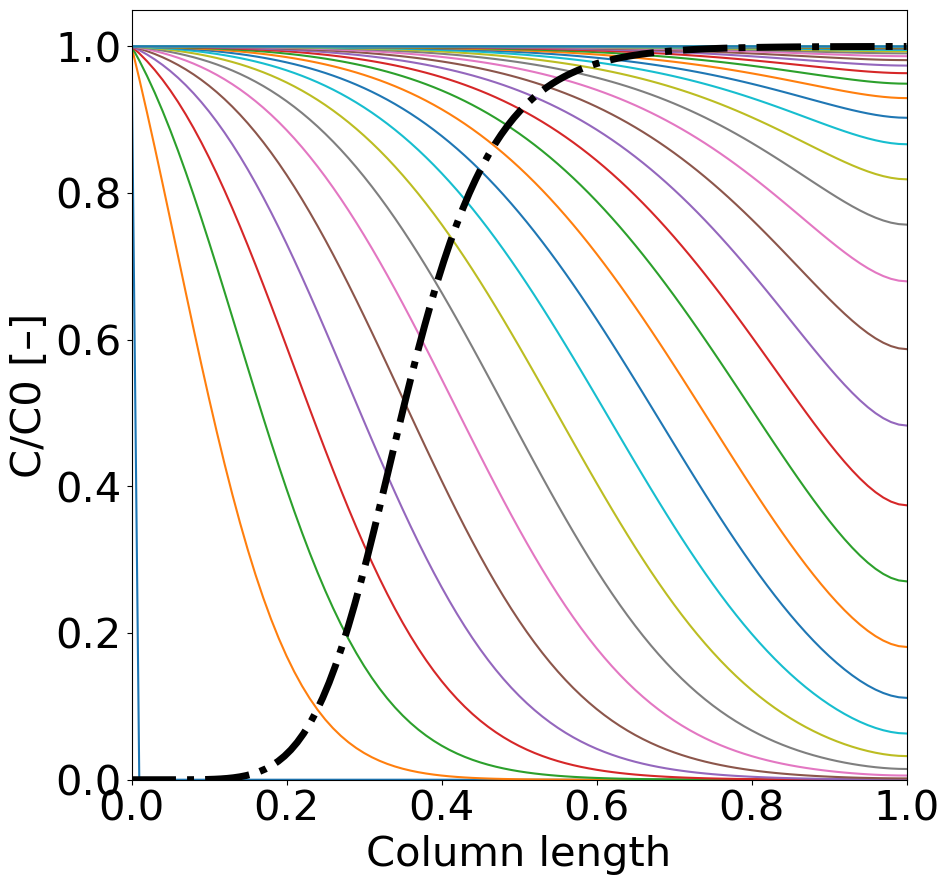

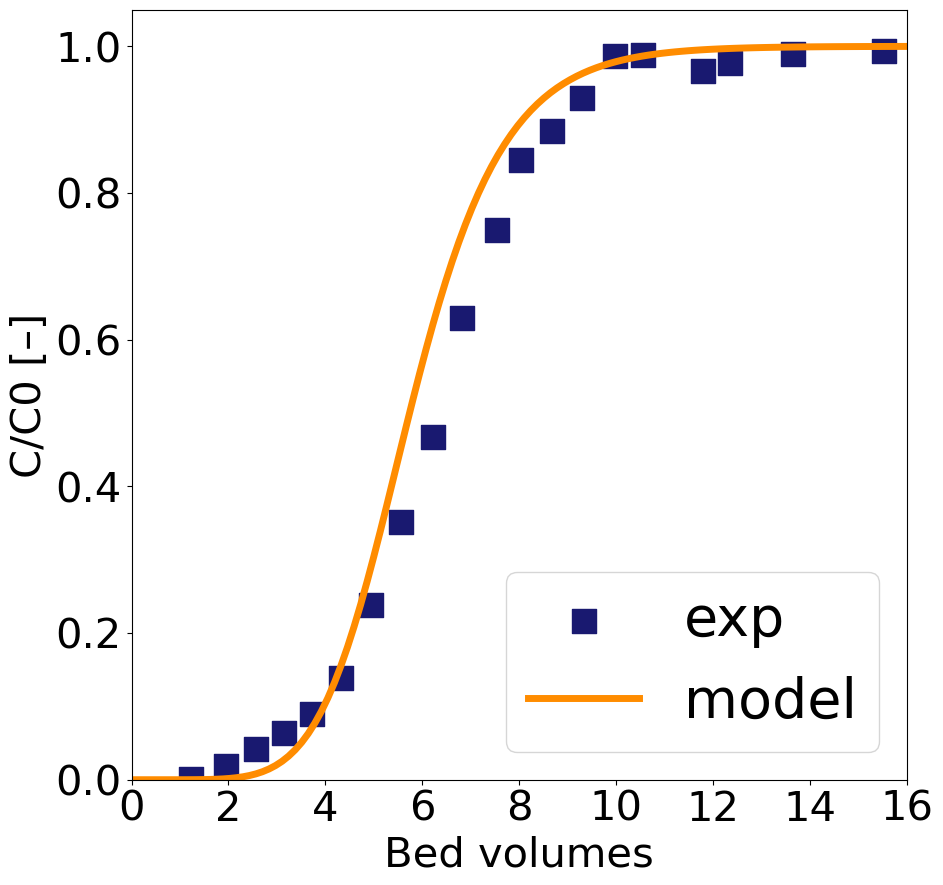

In [4]:
def model(
    # Parameter definition
    
    # Bed properties
    L = 0.1,                         # bed length [m]
    D = 0.01,                        # bed diameter [m]

    # Liquid properties
    rho_f = 1e3,                     # density [g/L]     - assumed equal to water
    mu    = 1e-3,                    # viscosity [Pa·s]  – assumed equal to water

    # Resin properties
    rp    = 0.5 * 7.5e-4,            # particle radius [m]
    rho_p = 389,                     # particle density [g/L]

    # Operational properties
    e = 0.37,                        # bed porosity [-]
    Q = 1.5e-8,                      # volumetric flow rate [m3/s]

    # Intraparticle diffusion
    Dp  = 5.3e-10,                   # intraparticle dispercion coefficient [m2/s]

    # Equilibrium isotherms
    ## Freundlich
    Kf = 0.149, 
    nf = 0.255,

    ## Langmuir
    qmax = 0.291,
    Kl   = 1.18,

    # Simulation parameters
    Nx    = None, 
    dx    = None,
    Nt    = None,
    dt    = None, 
    tmax  = 6, 

    # Boundary conditions
    C0 = 20.,                        # Inlet concentration [mmol/L]

    # Flags
    isotherm = 'Langmuir',
    plug_flow = False,
    plot_2D      = False, 
    profiles     = True, 
    breakthrough = True, 
    Zhang        = False,

    # Supplied parameter values
    **supplied):
    """
    Solve the model with finite differences and time step dt.
    """
    
    # Define parameters
    
    # Bed properties
    L = L
    D = D

    # Liquid properties
    rho_f = rho_f
    mu    = mu

    # Resin properties
    rp    = rp
    rho_p = rho_p

    # Operational properties
    Q = Q
    e = e

    # Intraparticle diffusion
    Dp  = Dp

    # Equilibrium isotherms
    ## Freundlich
    Kf = Kf
    nf = nf

    ## Langmuir
    qmax = qmax
    Kl   = Kl

    # Simulation parameters & mesh definition
    if dx is None and Nx is None:
        Nx = 100
        z  = np.linspace(0, 1, Nx+1)
        dx = z[1] - z[0]
        # print('dx =', dx)
    elif dx is not None:
        dx = dx
        # print('dx =', dx)
        Nx = int(round(1/dx))+1
        z  = np.linspace(0, 1, Nx+1)
    elif Nx is not None:
        z  = np.linspace(0, 1, Nx+1)
        dx = z[1] - z[0]
        # print('dx =', dx)
    
    if dt is None and Nt is None:
        dt = 0.1
        Nt = int(round(tmax/dt))
        print('dt =', dt)
    elif dt is not None:
        dt = dt
        # print('dt =', dt)
        Nt = int(round(tmax/dt))
    elif Nt is not None:
        dt = tmax/Nt
        # print('dt =', dt)
    
    dt    = dt
    tmax  = tmax
        

    # Boundary conditions
    C0 = C0
    
    
    # Define dependencies
    A   = np.pi/4 * D**2              # bed section [m2]
    V   = A*L                         # bed volume [m3]
    
    u   = Q/(A * e)                   # bed velocity [m/s]
    rho = rho_p * (1 - e)             # bed bulk density [g/L] 
        
    
    Re  = 2*rp * u * rho_f / mu       # Reynolds number [-]
    phi = 1.7                         # fitted number for calculation of diffusivity
    
                                      # axial dispersion coefficient [m2/s] from expression:
    Dz  = mu / rho_f * phi * Re / (0.20 + 0.011 * Re**0.48)
    
    kldf = 15 * Dp / rp**2            # linear driving force coefficient [s-1]
    
    
    # Dimensionless parameters
    C_in = 1.
    tau  = L/u                        # reference time [s]
    Pe   = u * L/Dz                   # Péclet number: advection/dispersion ratio [-]
    
    ## Freundlich isotherm
    if isotherm == 'Freundlich':
        qm = Kf * C0**nf     # [mmol/g]
        Kf = 1
        
    ## Langmuir isotherm
    if isotherm == 'Langmuir':
        qm = qmax * Kl * C0/(1 + Kl * C0)
        Kl = 1
    
    Dg   = (qm * rho)/(C0 * e) # solid/liquid ratio [-]
    kldf = 15*Dp/rp**2 * tau   # linear driving force transer coefficient [-]
    
    
    # PDE 
    unknowns    = ["C(z)", "q(z)"]  # variables to solve for --> liquid, solid concentrations as a function of z
    coordinates = ["z"]     # spacial coordinate --> vertical position
    
    # PDE parameters

    # q(z):     concentration in the resin beads as a function of z
    # dqdt(z):  time derivarive of the concentration in the resin as a function of z

    parameters = ["kldf", "Pe", "Dg", "Kl", "qmax"] #Parameter definition
    
    
    # Boundary conditions
    # z=0 → C=C0, z=L → dCdz=0

    boundary_conditions = {("C" , "z") : ("dirichlet", "dzC"),
                           ("q", "z") : ("dzq", "dzq")}

    macro_model = Model(["1/Pe * dzzC - upwind(1, C, z, 1) - Dg * kldf*(qmax*Kl*C/(1+Kl*C) - q)",
                        "kldf*(qmax*Kl*C/(1+Kl*C) - q)"],
                        unknowns=unknowns,
                        coordinates=coordinates,
                        parameters=parameters,
                        boundary_conditions=boundary_conditions
                        )
    
    # Zhang 2015
    if Zhang:
        r  = np.linspace(0, 1, 31)
        kl = 1.5e-5
        Bi = rp*kl/(e*Dp*Dg)
        Ed = Dg*Dp*tau/rp**2

        from scipy.integrate import quad

        unknowns            = ["C(z)", "q(r)"]
        coordinates         = ["z", "r"]
        parameters          = ["kl", "Pe", "Dg", "Kl", "qmax", "Bi", "Ed"]
        boundary_conditions = {("C", "z") : ("dirichlet", "dzC"),
                               ("q", "r") : ("drq", "Bi * (C - q/(Kl*(qmax - q))")}
        
        Zhang_model         = Model(["1/Pe * dzzC - upwind(1, C, z, 1) - Ed * drrq", 
                                    "Ed/Dg * drrq"], 
                                    unknowns=unknowns,
                                    coordinates=coordinates,
                                    parameters=parameters,
                                    boundary_conditions=boundary_conditions,
                                    subs=dict(
                                            Cstar = "q/(Kl*(qmax - q))",

                                            qint = "(3/4/np.pi/rp**3)/qm * quad(q, 0, 1)[0]",
                                          )
                                    )
    
    
    # Simulation

    ## Initial conditions
    C0 = 1e-6*np.ones_like(z)  # initial concentration in the liquid along the column
    q0 = 1e-6*np.ones_like(z)  # initial concentration in the resin along the column
    # dqdt = np.zeros_like(z)    # initial dqdt values
    
    C0[0] = C_in

    ## Fields initialization 
    initial_fields = macro_model.Fields(z=z, C=C0, q=q0, kldf=kldf, Pe=Pe, Dg=Dg, Kl=Kl, qmax=qmax)

    ## Simulation initializations
    simulation  = Simulation(macro_model, initial_fields, dt=dt, tmax=tmax)
    container   = simulation.attach_container()

    ## Run simulation
    tmax, last_fields = simulation.run() 
    
    if Zhang:
        initial_fields = Zhang_model.Fields(z=z, C=C0, q=q0, kldf=kldf, Pe=Pe, Dg=Dg, Kl=Kl, qmax=qmax, Bi=Bi, Ed=Ed)
        Zhang_simulation  = Simulation(macro_model, initial_fields, dt=dt, tmax=tmax)
        Zhang_container   = simulation.attach_container()
        tmax, Zhang_fields = Zhang_simulation.run()
        
        Z = Zhang_container.data.C.data[:, -1]
    else:
        Z = 0
    
    
    # Plot results and validate 
    C_data = container.data["C"] #Extract concentration data
    
    t       = container.data.t.data * tau
    z       = container.data.z.data * L
    y       = container.data.C.data
    q       = container.data.q.data
    C       = y[:,-1]   # breakthrough curve
    
    
    ## Import experimental data
    data = pd.read_csv("data.csv")

    texp = data['Bed volumes']
    Cexp = data['C/C0']

    # Convert time to bed volumes
    BV = t * (Q/e)/(V*e)            # no. of columns/s / bed volume [-]

    # Compute RMSE in seconds
    V0 = 8e-6
    Q0 = 1.5e-8
    e0 = 0.37
    Cint = np.interp(texp/(Q0/e0)*(V0*e0), t, C)
    from sklearn.metrics import mean_squared_error
    RMSE = np.sqrt(mean_squared_error(Cexp, Cint)) # absolute error
    print(f"RMSE = {RMSE:.4f}")
    
    # RMSE_Zhang = np.sqrt(mean_squared_error(Cexp, Cint)) 
    

    ## Plot 2D plot with concentration profiles and column length 
    if plot_2D:
        plot2D(C_data)

    ## Plot concentration profiles vs column length over time
    if profiles:
        plot_profiles(y, z, L, t, tmax, tau)
    
    ## Plot validation curve of breakthrough 
    if breakthrough:
        plot_breakthrough(texp, Cexp, BV, y, Z, Zhang=Zhang)
        
    return C, y, q, t, BV, z, RMSE

C, y, q, t, BV, z, RMSE = model(
                    Nx    = 100,
                    dt    = 0.05, 
                    tmax  = 6.08, 
                    
                    isotherm = 'Langmuir',
                    profiles = True, 
                    breakthrough = True,
                    Zhang = False
)

### Zhang's model

In [115]:
# Spherical coordinates

import numpy as np
from skfdiff import Model, Simulation
from scipy.integrate import quad

q = np.zeros(11)
r = np.linspace(0, 1, 11)
dtq = np.zeros(11)

def hook(t, fields):

    def integrand(r, q):
        return 4*np.pi*r**2 * q
    
    for i in range(0, len(r)):
        fields["dtq"][i] = quad(integrand, 0, 1, args=(fields["q"]))[0]

    return fields

model = Model(["2/r * drq + drrq",], 
              unknowns=["q(r)"], 
              coordinates=["r"], 
            #   parameters=["Dg", "Ed", "Bi", "Kl", "qmax", "dqint", "qint", "rp"],
              boundary_conditions={("q", "r") : ("drq", "drq - 1")},
              )
initial_fields = model.Fields(r=r, q=q)
simulation  = Simulation(model, initial_fields, dt=0.1, tmax=2, hook=hook)
container   = simulation.attach_container()

tmax, last_fields = simulation.run()
q = container.data.q.data
t = container.data.t.data
dtq = container.data.dtq.data
for i in range(0, len(t), 3):
    plt.plot(r, q[i])
plt.show()
plot(t, dtq)
plt.show()

  0%|          | 0/19.0 [00:00<?, ?it/s]


TypeError: only size-1 arrays can be converted to Python scalars

In [110]:
# Zhang 2015
import numpy as np
from skfdiff import Model, Simulation
from scipy.integrate import quad
Ed = 1
Dg = 1
Bi = 1
Kl = 2
qmax = 0.3
z = np.linspace(0, 1, 11)
r = np.linspace(0, 1, 11)
# Initial contidion
q = np.zeros(11)
qint = np.zeros(11)
dqint = np.zeros(11)
C = np.zeros(11)
# Cstar = np.zeros(11)
# Boundary condition
C[0] = 1.
# C0=0.

def hook(t, fields):
    def integrand(r, q):
        return q*4*np.pi*r**2

    print(fields.z)
    for i in range(0, len(fields.z)):
        fields["qint"][i] = (3/4/np.pi/fields.rp[i]**3) * quad(integrand, 0, 1, args=(fields.q[i],))[0]
    # fields["dqint"] = fields.qint.diff(fields.t)
    # fields["Cstar"] = fields.q/(fields.Kl*(fields.qmax - fields.q))

    # Time-dependent boundary condition
    # fields.q.diff(fields.r).set_boundary("drq", "drq - Bi*(fields.C - fields.Cstar)")
    return fields

model = Model(["dzzC - upwind(1, C, z, 1) - Dg * dqint", 
               "Ed/Dg*drrq"], 
              unknowns=["C(z)", "q(r)"], 
              coordinates=["z", "r"], 
              parameters=["Dg", "Ed", "Bi", "Kl", "qmax", "dqint", "qint", "rp"],
              boundary_conditions={("C", "z") : ("dirichlet", "dzC"),
                                   ("q", "r") : ("drq", "drq - Bi*(C - q/(Kl*(qmax - q)))")}
                                   )
initial_fields = model.Fields(z=z, r=r, C=C, q=q, Dg=Dg, Ed=Ed, Bi=Bi, Kl=Kl, qmax=qmax, dqint=dqint, qint=qint, rp=1)
simulation  = Simulation(model, initial_fields, dt=0.1, tmax=6, modules="scipy", hook=hook)
container   = simulation.attach_container()

tmax, last_fields = simulation.run()
C = container.data.C.data
q = container.data.q.data
t = container.data.t.data
for i in range(0, len(t), 3):
    plt.plot(r, q[i])
# last_fields["q"].plot()
plt.show()
for i in range(0, len(t), 3):
    plt.plot(z, C[i])

ValueError: cannot broadcast a non-scalar to a scalar array

8e9b65 running: t: 6: : 120it [00:06, 18.84it/s]                            


RMSE = 0.2289


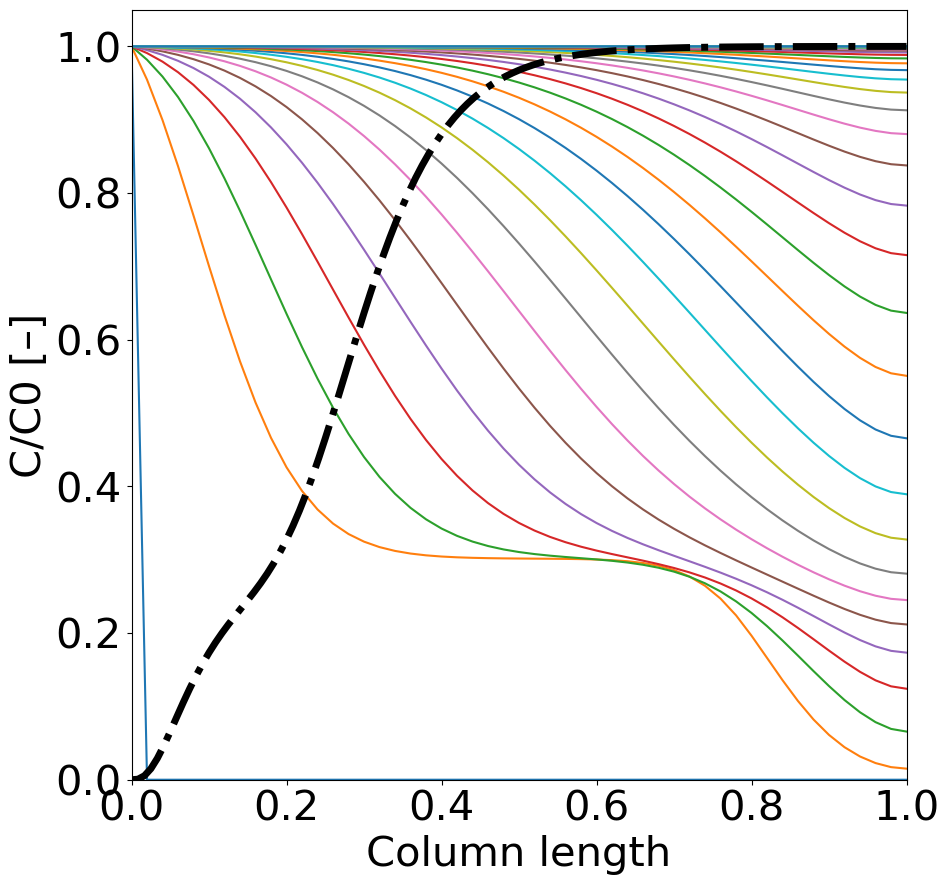

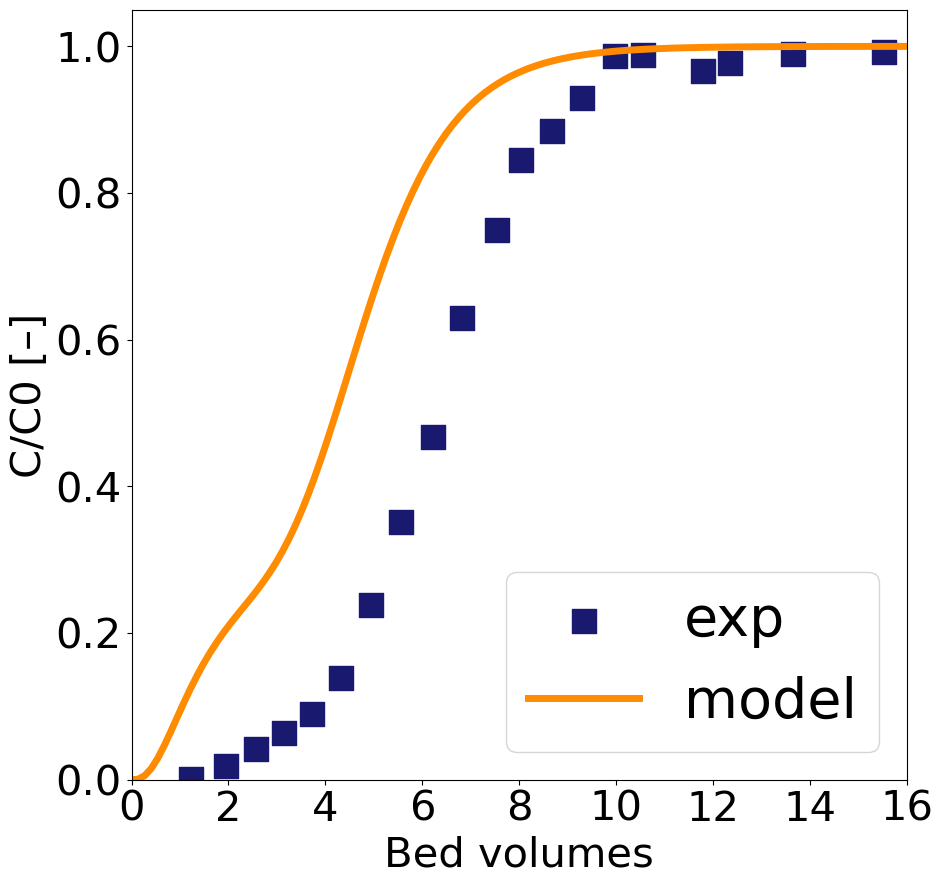

In [3]:
def model(
    # Parameter definition
    
    # Bed properties
    L = 0.1,                         # bed length [m]
    D = 0.01,                        # bed diameter [m]

    # Liquid properties
    rho_f = 1e3,                     # density [g/L]     - assumed equal to water
    mu    = 1e-3,                    # viscosity [Pa·s]  – assumed equal to water

    # Resin properties
    rp    = 0.5 * 7.5e-4,            # particle radius [m]
    rho_p = 389,                     # particle density [g/L]

    # Operational properties
    e = 0.37,                        # bed porosity [-]
    Q = 1.5e-8,                      # volumetric flow rate [m3/s]

    # Diffusion coefficients
    Dp  = 5.3e-10,                   # intraparticle dispersion coefficient [m2/s]
    Dz  = 3.2e-6,                    # axial dispersion coefficient [m2/s]

    # Equilibrium isotherms
    ## Freundlich
    Kf = 0.149, 
    nf = 0.255,

    ## Langmuir
    qmax = 0.291,
    Kl   = 1.18,

    # Simulation parameters
    Nx    = None, 
    dx    = None,
    Nt    = None,
    dt    = None, 
    tmax  = 6, 

    # Boundary conditions
    C0 = 20.,                        # Inlet concentration [mmol/L]
    q0 = 0.,                         # Initial concentration in the resin beads [mmol/g]

    # Flags
    isotherm = 'Langmuir',
    plug_flow = False,
    plot_2D      = False, 
    profiles     = True, 
    breakthrough = True, 

    # Supplied parameter values
    **supplied):
    """
    Solve the model with finite differences and time step dt.
    """
    
    # Define parameters
    
    # Bed properties
    L = L
    D = D

    # Liquid properties
    rho_f = rho_f
    mu    = mu

    # Resin properties
    rp    = rp
    rho_p = rho_p

    # Operational properties
    Q = Q
    e = e

    # Diffusion coefficients
    Dp  = Dp
    Dz  = Dz

    # Equilibrium isotherms
    ## Freundlich
    Kf = Kf
    nf = nf

    ## Langmuir
    qmax = qmax
    Kl   = Kl

    # Simulation parameters
    if dx is None and Nx is None:
        Nx = 100
        z  = np.linspace(0, 1, Nx+1)
        dx = z[1] - z[0]
        # print('dx =', dx)
    elif dx is not None:
        dx = dx
        # print('dx =', dx)
        Nx = int(round(1/dx))+1
        z  = np.linspace(0, 1, Nx+1)
    elif Nx is not None:
        z  = np.linspace(0, 1, Nx+1)
        dx = z[1] - z[0]
        # print('dx =', dx)
    
    if dt is None and Nt is None:
        dt = 0.1
        Nt = int(round(tmax/dt))
        print('dt =', dt)
    elif dt is not None:
        dt = dt
        # print('dt =', dt)
        Nt = int(round(tmax/dt))
    elif Nt is not None:
        dt = tmax/Nt
        # print('dt =', dt)
    
    dt    = dt
    tmax  = tmax
    
    # Mesh definition
    

    # Boundary conditions
    C0 = C0
    
    
    # Define dependencies
    A   = np.pi/4 * D**2              # bed section [m2]
    V   = A*L                         # bed volume [m3]
    
    u   = Q/(A * e)                   # bed velocity [m/s]
    rho = rho_p * (1 - e)             # bed bulk density [g/L] 
        
    
    Re  = 2*rp * u * rho_f / mu       # Reynolds number [-]
    phi = 1.7                         # fitted number for calculation of diffusivity
    
                                      # axial dispersion coefficient [m2/s] from expression:
    # Dz  = mu / rho_f * phi * Re / (0.20 + 0.011 * Re**0.48)
        
    kldf = 15 * Dp / rp**2            # linear driving force coefficient [s-1]
    
    
    # Dimensionless parameters
    C_in = 1.
    q_in = q0
    # L=1
    tau  = L/u                        # reference time [s]
    Pe   = u * L/Dz                   # Péclet number: advection/dispersion ratio [-]
    # L    = 1.
    
    ## Freundlich isotherm
    if isotherm == 'Freundlich':
        qm = Kf * C0**nf     # [mmol/g]
        Kf = 1
        
    ## Langmuir isotherm
    if isotherm == 'Langmuir':
        qm = qmax * Kl * C0/(1 + Kl * C0)
        Kl = 1
    
    Dg   = (qm * rho)/(C0 * e) # solid/liquid ratio [-]
    kldf = 15*Dp/rp**2 * tau   # linear driving force transer coefficient [-]
    

    
    # PDE 
    unknowns    = ["C(z)", "q(z)"]  # variables to solve for --> liquid, solid concentrations as a function of z
    coordinates = ["z"]     # spacial coordinate --> vertical position
    
    # PDE parameters

    # q(z):     concentration in the resin beads as a function of z
    # dqdt(z):  time derivarive of the concentration in the resin as a function of z

    parameters = ["kldf", "Pe", "Dg", "Kl", "qmax", "qm"] #Parameter definition
    
    
    # Boundary conditions
    # z=0 → C=C0, z=L → dCdz=0

    boundary_conditions = {("C" , "z") : ("dirichlet", "dzC"),
                           ("q", "z") : ("dzq", "dzq")}

    macro_model = Model(["1/Pe * dzzC - upwind(1, C, z, 1) - Dg * kldf/qm*(qmax*Kl*C/(1+Kl*C) - q)",
                        "kldf/qm*(qmax*Kl*C/(1+Kl*C) - q)"],
                        unknowns=unknowns,
                        coordinates=coordinates,
                        parameters=parameters,
                        boundary_conditions=boundary_conditions
                        )
    
    # Simulation

    ## Initial conditions
    C0 = 1e-8*np.ones_like(z)  # initial concentration in the liquid along the column
    q0 = 1e-8*np.ones_like(z)  # initial concentration in the resin along the column
    # dqdt = np.zeros_like(z)    # initial dqdt values
    
    C0[0] = C_in
    q0[:40] = q_in

    ## Fields initialization 
    initial_fields = macro_model.Fields(z=z, C=C0, q=q0, kldf=kldf, Pe=Pe, Dg=Dg, Kl=Kl, qmax=qmax, qm=qm)

    ## Simulation initializations
    simulation  = Simulation(macro_model, initial_fields, dt=dt, tmax=tmax)
    container   = simulation.attach_container()

    ## Run simulation
    tmax, last_fields = simulation.run() 
    
    
    # Plot results and validate 
    C_data = container.data["C"] #Extract concentration data
    
    t       = container.data.t.data * tau
    z       = container.data.z.data * L
    y       = container.data.C.data
    C       = y[:,-1]   # breakthrough curve
    
    ## Import experimental data
    data = pd.read_csv("data.csv")

    texp = data['Bed volumes']
    Cexp = data['C/C0']

    # Convert time to bed volumes
    BV = t * (Q/e)/(V*e)            # no. of columns/s / bed volume [-]
    
    # Compute RMSE
    Cint = np.interp(texp, BV, C)
    from sklearn.metrics import mean_squared_error
    RMSE = np.sqrt(mean_squared_error(Cexp, Cint)) # absolute error
    print(f"RMSE = {RMSE:.4f}")

    ## Plot 2D plot with concentration profiles and column length 
    if plot_2D:
        plot2D(C_data)

    ## Plot concentration profiles vs column length over time
    if profiles:
        plot_profiles(y, z, L, t, tmax, tau)
    
    ## Plot validation curve of breakthrough 
    if breakthrough:
        plot_breakthrough(texp, Cexp, BV, y)
        
    return C, y, BV, z, RMSE

C, y, BV, z, RMSE = model(
                    Nx = 50,
                    dt    = 0.05, 
                    tmax  = 6, 
                    q0 = 0.1,
                    
                    isotherm = 'Langmuir',
                    profiles = True, 
                    breakthrough = True)

In [657]:
16/(Q/e)*V*e

1400.7803137738347

In [658]:
1400/tau

6.076132110010163

## Local Sensitivity analysis

### Sensitivity analysis of numerical parameters: dt, dx

Np = 5


00442c running: t: 6: : 60it [00:02, 24.12it/s]                          


RMSE = 0.0878
Np = 10


0d6c12 running: t: 6: : 60it [00:02, 23.14it/s]                          


RMSE = 0.0768
Np = 25


0d5d98 running: t: 6: : 60it [00:02, 21.19it/s]                          


RMSE = 0.0724
Np = 50


2a5e74 running: t: 6: : 60it [00:03, 19.72it/s]                          


RMSE = 0.0716
Np = 100


6cb948 running: t: 6: : 60it [00:03, 19.28it/s]                          


RMSE = 0.0715
Np = 200


0a1b9b running: t: 6: : 60it [00:03, 18.73it/s]                          


RMSE = 0.0715


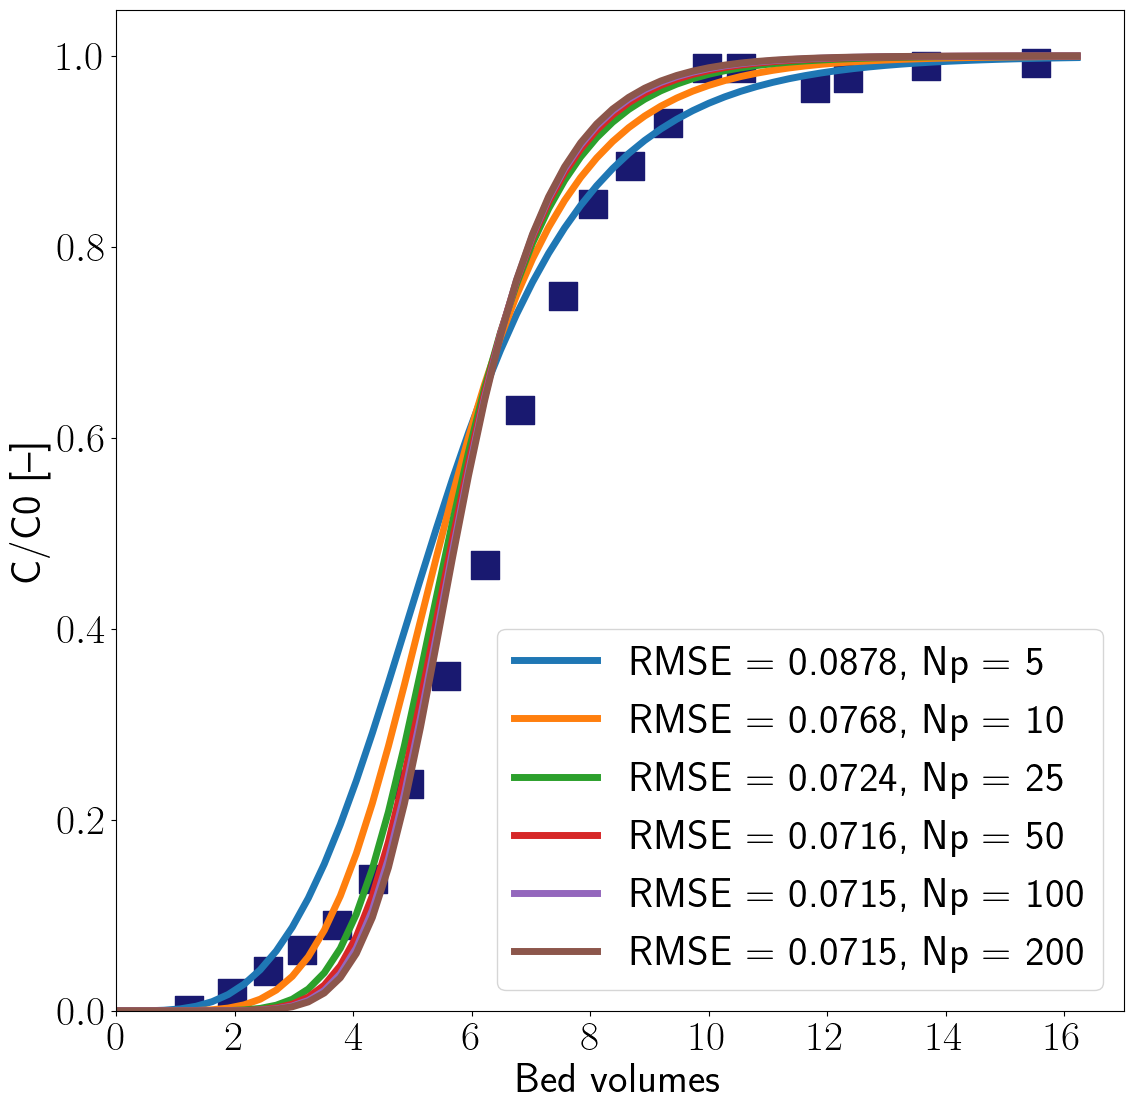

In [9]:
## Import experimental data
data = pd.read_csv("data.csv")

texp = data['Bed volumes']
Cexp = data['C/C0']

# Sensitivity for Np or space discretisation
size = 13
fig2, ax2 = plt.subplots(figsize=(size,size))

Np_values = [5, 10, 25, 50, 100, 200] # 500, 1000, 1500]

plt.rcParams['text.usetex'] = True

for Np in Np_values:

    print("Np =", Np)
    
    C, y, BV, z, RMSE = model(Nx    = Np,
                        dt    = 0.1, 
                        tmax  = 6, 

                        isotherm = 'Langmuir',
                        profiles = False, 
                        breakthrough = False)
    
    if Np == Np_values[0]:
        RMSE0 = RMSE
    
    """
    Plot validation curve of breakthrough.
    """

    # Plot model    
    
    ax2.plot(BV, y[:,-1], linewidth=5, label=f'RMSE = {RMSE:.4f}, Np = {Np:4d}')

    ax2.set_xlabel('Bed volumes', fontsize=30)
    ax2.set_ylabel('C/C0 [–]', fontsize=30)
    ax2.tick_params(labelsize=30)
    ax2.set_xticks(np.linspace(0, 16, 9))
    ax2.set_ylim(0)
    ax2.set_xlim(0, int(max(max(BV), max(texp))) + 1)
    ax2.legend(fontsize=30)
    
# Plot experimental data
ax2.scatter(texp, Cexp, color='midnightblue', marker='s', s=30*size, label='exp')

# Save figure and show plot
plt.savefig("sensitivity-Np.pdf", format="pdf", bbox_inches="tight")
plt.show()

Np = 100 gives a good compromise between computational effort and accuracy, around 4 seconds per simulation with dt = 0.1, and RMSE = 0.06 (for Np = 200 it is 0.059 or -1.5%, lower is better).

dt = 1


843bee running: t: 6: 100%|██████████| 6/6 [00:01<00:00,  4.24it/s]


RMSE = 0.0517
dt = 0.5


f5bdde running: t: 6: 100%|██████████| 12/12.0 [00:01<00:00,  7.71it/s]  


RMSE = 0.0645
dt = 0.25


fcde22 running: t: 6: 100%|██████████| 24/24.0 [00:01<00:00, 12.92it/s]   


RMSE = 0.0698
dt = 0.1


aeb06f running: t: 6: : 60it [00:03, 19.29it/s]                          


RMSE = 0.0715
dt = 0.05


c12a22 running: t: 6: : 120it [00:04, 24.15it/s]                            


RMSE = 0.0716
dt = 0.01


602b32 running: t: 6: : 600it [00:22, 27.04it/s]                            


RMSE = 0.0717


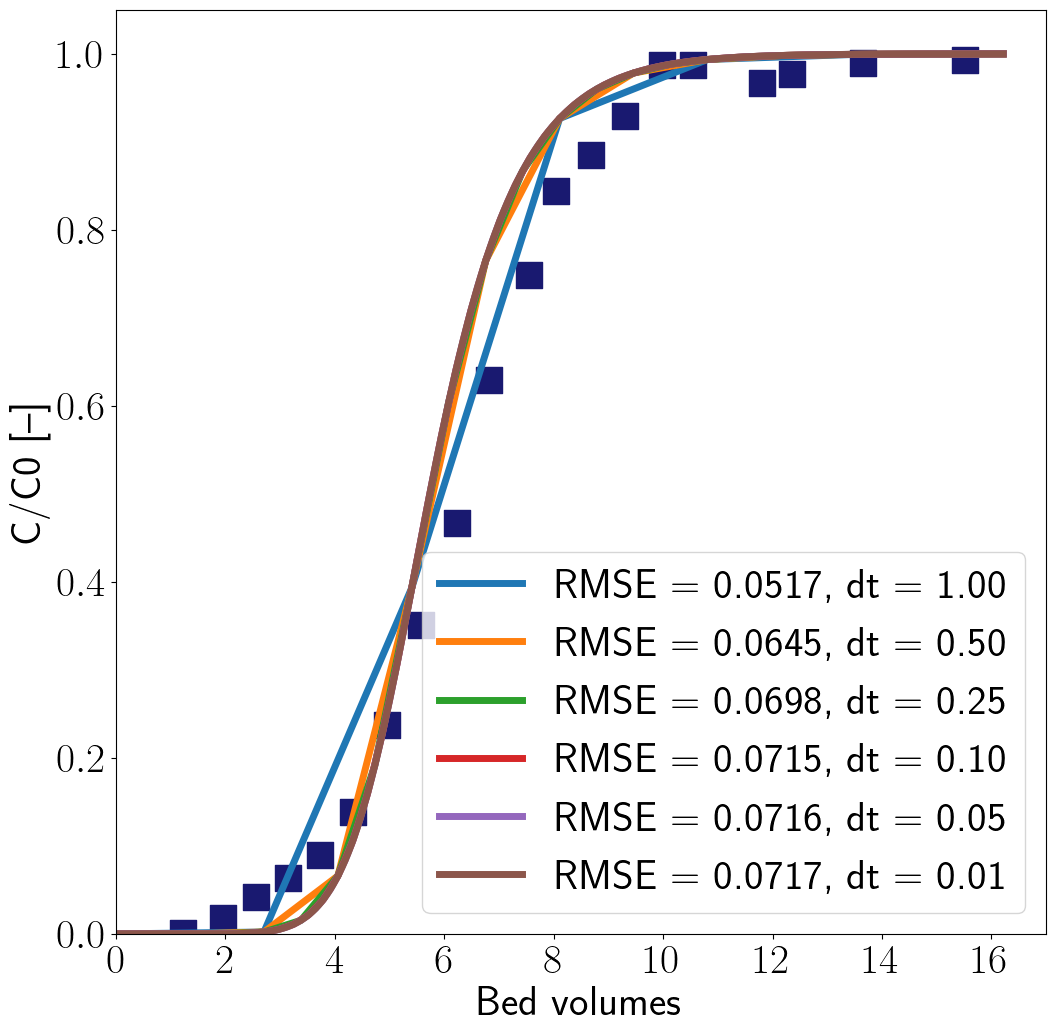

In [10]:
# Sensitivity for dt or time discretisation
size = 12
fig2, ax2 = plt.subplots(figsize=(size,size))

dt_values = [1, 0.5, 0.25, 0.1, 0.05, 0.01]

RMSE0 = 1.

for dt in dt_values:

    print("dt =", dt)
    
    C, y, BV, z, RMSE = model(
                        Nx    = 100,
                        dt    = dt, 
                        tmax  = 6, 

                        isotherm = 'Langmuir',
                        profiles = False, 
                        breakthrough = False)
    
    if dt == dt_values[0]:
        RMSE0 = RMSE
    
    """
    Plot validation curve of breakthrough.
    """

    # Plot model    
    
    ax2.plot(BV, y[:,-1], linewidth=5, label=f'RMSE = {RMSE:.4f}, dt = {dt:.2f}')

    ax2.set_xlabel('Bed volumes', fontsize=30)
    ax2.set_ylabel('C/C0 [–]', fontsize=30)
    ax2.tick_params(labelsize=30)
    ax2.set_xticks(np.linspace(0, 16, 9))
    ax2.set_ylim(0)
    ax2.set_xlim(0, int(max(max(BV), max(texp))) + 1)
    ax2.legend(fontsize=30)
    
# Plot experimental data
ax2.scatter(texp, Cexp, color='midnightblue', marker='s', s=30*size, label='exp')

# Save figure and show plot
plt.savefig("sensitivity-dt.pdf", format="pdf", bbox_inches="tight")
plt.show()

dt = 0.1 gives a good compromise between computational effort and accuracy, around 4 seconds per simulation for Np=100, and RMSE = 0.06 (for dt = 0.25 it is 0.059, -1.5%; lower is better but less accurate).

### Local sensitivity analysis of 10 model parameters

In [192]:
def plot_sensitivity(sensitivities, labels=None, size=15, font=20, **parameters):
    
    # Plot sensitivity functions over time
    fig1, ax1 = plt.subplots(1, 2, figsize=(size,6))
    plt.suptitle('Local sensitivity analysis of breakthrough curve', fontsize=font+5, y=1.02)

    plt.rcParams['text.usetex'] = True
    
    ax1[0].axhline(y=0., color='0', ls='-', lw=0.2)
    ax1[1].axhline(y=0., color='0', ls=':', lw=0.2)

    for parameter, value in parameters.items():
        
        t = sensitivities['t']
        S = sensitivities[parameter]
        
        # Plot the sensitivity functions
        if labels == None: 
            label = parameter
        else:
            label = dict(zip(parameters.keys(), labels))[parameter]

        # Plot only sensitivities above a certain value
        if np.max(np.abs(S)) > 0.:    
            ax1[0].plot(t, S, label= label + ' = ' + str(value))
            ax1[0].grid(True, axis='y', which='major', color='gray', linestyle='-', linewidth=0.5)
            ax1[0].set_xlim(0, 16)
            ax1[0].set_xlabel('Bed volumes', fontsize=font)
            ax1[0].set_ylabel(r'Relative sensitivity, $S=\frac{\partial C}{\partial \theta}\theta$', fontsize=font)
            ax1[0].set_xticks(np.linspace(0, 16, 9), fontsize=font)
            ax1[0].set_title('(a) Time variation for all parameters', fontsize=font)
            ax1[0].legend(loc='lower right', fontsize=font-11)
            ax1[0].tick_params(axis='x', labelsize=font)
            ax1[0].tick_params(axis='y', labelsize=font)

        # Plot only sensitivities under a certain value
        if np.max(np.abs(S)) < 0.1:    
            ax1[1].plot(t, S, label= label + ' = ' + str(value))
            ax1[1].grid(True, axis='y', which='major', color='gray', linestyle='-', linewidth=0.5)
            ax1[1].set_xlim(0, 16)
            ax1[1].set_xlabel('Bed volumes', fontsize=font)
            # ax1[1].set_ylabel(r'Relative sensitivity, $\frac{\partial C}{\partial \theta}\theta$', fontsize=font)
            ax1[1].set_xticks(np.linspace(0, 16, 9), fontsize=font)
            ax1[1].set_title('(b) Time variation for S under 0.1', fontsize=font)
            ax1[1].legend(loc='lower right', fontsize=font-10)
            ax1[1].tick_params(axis='x', labelsize=font)
            ax1[1].tick_params(axis='y', labelsize=font)

    # Store figure
    plt.savefig("sensitivity-local-"+str(len(parameters))+".pdf", format="pdf", bbox_inches="tight")


    # Plot average sensitivity coefficients in a bar plot
    fig2, ax2 = plt.subplots(1, 2, figsize=(size,6))
    plt.suptitle('Local sensitivity analysis of breakthrough curve', fontsize=font+5, y=1.02)

    plt.rcParams['text.usetex'] = True

    ax2[0].axhline(y=0., color='0', ls='-', lw=0.2)
    # ax2[1].axhline(y=0.1, color='0', ls=':')
    # ax2[1].axhline(y=0.01, color='0', ls=':')

    for parameter, value in parameters.items():

        S = sensitivities[parameter]
        
        # Plot average sensitivity coefficient in a bar plot
        Smean = np.mean(np.abs(S))

        ax2[0].bar(parameter, Smean*np.sign(np.mean(S)))
        ax2[0].grid(True, axis='y', which='major', color='gray', linestyle='-', linewidth=0.5)
        ax2[0].set_ylim(-0.42, 0.42)
        ax2[0].set_title('(a) Average sensitivity values', fontsize=font)
        ax2[0].set_ylabel(r'Average relative sensitivity, $S=\frac{\partial C}{\partial \theta}\theta$', fontsize=font)
        ax2[0].tick_params(axis='x', labelsize=font)
        ax2[0].tick_params(axis='y', labelsize=font)
        # ax[0].set_yticks([1e-3, 1e-2, 1e-1, 1])
        if labels==None: labels = parameters.keys()
        positions = range(len(labels)) 
        ax2[0].set_xticks(positions, labels)

        # Log scale        
        ax2[1].bar(parameter, Smean)
        ax2[1].set_yscale('log')
        # ax2[1].grid(True, axis='y', which='minor', color='gray', linestyle='-', linewidth=0.2)
        ax2[1].grid(True, axis='y', which='major', color='gray', linestyle='-', linewidth=0.5)

        ax2[1].set_title('(b) Logarithmic scale', fontsize=font)
        ax2[1].tick_params(axis='x', labelsize=font)
        ax2[1].tick_params(axis='y', labelsize=font)
        # ax[1].set_yticks([1e-3, 1e-2, 1e-1, 1])
        if labels==None: labels = parameters.keys()
        positions = range(len(labels)) 
        ax2[1].set_xticks(positions, labels)

    # Store figure
    plt.savefig("sensitivity-local-"+str(len(parameters))+"-log.pdf", format="pdf", bbox_inches="tight")
    plt.show()

def forward_sensitivity(model, labels=None, dt=None, Np=None, xi=1e-5, plot=False, **parameters):
    
    sensitivities = dict()
    
    # First just run the model with original parameter values
    print(parameters.items())
    C1, y1, t1, z1, _ = model(dt=dt, Np=Np, profiles=False, breakthrough=False, **parameters)
    
    # Read keyword arguments: parameter-value pairs
    for parameter, value in parameters.items():
        # print(parameter)
        # print(value)
        # parameter = value
        # print(list(kwargs)[0])

        # Now run the model with the adapted parameter value for each parameter
        parameters[parameter] = value*(1 + xi)
        print(parameters.items())

        C2, y2, t2, z2, _ = model(dt=dt, Np=Np, profiles=False, breakthrough=False, **parameters)
        
        # Store the time vector
        sensitivities['t'] = t1

        # Calculate the local relative sensitivity function (wrt. the parameter value)
        sensitivities[parameter] = (C2 - C1)/xi; 
        
        # Restore original value
        parameters[parameter] = value
        
    # Plot the sensitivity function
    if plot:
        plot_sensitivity(sensitivities, labels=labels, **parameters)
    
    return sensitivities

# S = forward_sensitivity(model, labels=[r'$q_{max}$'], dt=0.1, qmax=0.2)


In [69]:
S_all = forward_sensitivity(model, dt=0.1, Np=100, plot=False,
                            labels=[r'$q_{max}$',r'$K_L$',r'$Q$',r'$\varepsilon$',r'$r_p$',r'$D_p$',r'$D_z$',r'$D$',r'$L$',r'$\rho_p$',r'$C_0$',r'$q_0$'],
                            qmax=0.291, 
                            Kl=1.18, 
                            Q=1.5e-8, 
                            e=0.37, 
                            rp=0.5 * 7.5e-4, 
                            Dp=5.3e-10, 
                            Dz=3.2e-6,
                            D=0.01, 
                            L=0.1, 
                            rho_p=389, 
                            C0=20.,
                            q0 = 0.01) # assumed 80% of resin are regenerated up to 0.1 mmol/g

dict_items([('qmax', 0.291), ('Kl', 1.18), ('Q', 1.5e-08), ('e', 0.37), ('rp', 0.000375), ('Dp', 5.3e-10), ('Dz', 3.2e-06), ('D', 0.01), ('L', 0.1), ('rho_p', 389), ('C0', 20.0), ('q0', 0.01)])


40ae36 running: t: 6: : 60it [00:03, 18.39it/s]                          


RMSE = 0.0777
dict_items([('qmax', 0.29100291), ('Kl', 1.18), ('Q', 1.5e-08), ('e', 0.37), ('rp', 0.000375), ('Dp', 5.3e-10), ('Dz', 3.2e-06), ('D', 0.01), ('L', 0.1), ('rho_p', 389), ('C0', 20.0), ('q0', 0.01)])


a3d060 running: t: 6: : 60it [00:03, 18.01it/s]                          


RMSE = 0.0777
dict_items([('qmax', 0.291), ('Kl', 1.1800118), ('Q', 1.5e-08), ('e', 0.37), ('rp', 0.000375), ('Dp', 5.3e-10), ('Dz', 3.2e-06), ('D', 0.01), ('L', 0.1), ('rho_p', 389), ('C0', 20.0), ('q0', 0.01)])


3cb19d running: t: 6: : 60it [00:03, 19.01it/s]                          


RMSE = 0.0777
dict_items([('qmax', 0.291), ('Kl', 1.18), ('Q', 1.500015e-08), ('e', 0.37), ('rp', 0.000375), ('Dp', 5.3e-10), ('Dz', 3.2e-06), ('D', 0.01), ('L', 0.1), ('rho_p', 389), ('C0', 20.0), ('q0', 0.01)])


390876 running: t: 6: : 60it [00:03, 18.74it/s]                          


RMSE = 0.0777
dict_items([('qmax', 0.291), ('Kl', 1.18), ('Q', 1.5e-08), ('e', 0.37000370000000005), ('rp', 0.000375), ('Dp', 5.3e-10), ('Dz', 3.2e-06), ('D', 0.01), ('L', 0.1), ('rho_p', 389), ('C0', 20.0), ('q0', 0.01)])


73fe2b running: t: 6: : 60it [00:03, 19.77it/s]                          


RMSE = 0.0777
dict_items([('qmax', 0.291), ('Kl', 1.18), ('Q', 1.5e-08), ('e', 0.37), ('rp', 0.00037500375000000004), ('Dp', 5.3e-10), ('Dz', 3.2e-06), ('D', 0.01), ('L', 0.1), ('rho_p', 389), ('C0', 20.0), ('q0', 0.01)])


19c343 running: t: 6: : 60it [00:03, 19.55it/s]                          


RMSE = 0.0777
dict_items([('qmax', 0.291), ('Kl', 1.18), ('Q', 1.5e-08), ('e', 0.37), ('rp', 0.000375), ('Dp', 5.300053000000001e-10), ('Dz', 3.2e-06), ('D', 0.01), ('L', 0.1), ('rho_p', 389), ('C0', 20.0), ('q0', 0.01)])


cca8b8 running: t: 6: : 60it [00:03, 18.85it/s]                          


RMSE = 0.0777
dict_items([('qmax', 0.291), ('Kl', 1.18), ('Q', 1.5e-08), ('e', 0.37), ('rp', 0.000375), ('Dp', 5.3e-10), ('Dz', 3.200032e-06), ('D', 0.01), ('L', 0.1), ('rho_p', 389), ('C0', 20.0), ('q0', 0.01)])


c1d1ec running: t: 6: : 60it [00:03, 18.82it/s]                          


RMSE = 0.0777
dict_items([('qmax', 0.291), ('Kl', 1.18), ('Q', 1.5e-08), ('e', 0.37), ('rp', 0.000375), ('Dp', 5.3e-10), ('Dz', 3.2e-06), ('D', 0.010000100000000001), ('L', 0.1), ('rho_p', 389), ('C0', 20.0), ('q0', 0.01)])


55bd41 running: t: 6: : 60it [00:03, 19.00it/s]                          


RMSE = 0.0777
dict_items([('qmax', 0.291), ('Kl', 1.18), ('Q', 1.5e-08), ('e', 0.37), ('rp', 0.000375), ('Dp', 5.3e-10), ('Dz', 3.2e-06), ('D', 0.01), ('L', 0.100001), ('rho_p', 389), ('C0', 20.0), ('q0', 0.01)])


abf6b3 running: t: 6: : 60it [00:03, 19.85it/s]                          


RMSE = 0.0777
dict_items([('qmax', 0.291), ('Kl', 1.18), ('Q', 1.5e-08), ('e', 0.37), ('rp', 0.000375), ('Dp', 5.3e-10), ('Dz', 3.2e-06), ('D', 0.01), ('L', 0.1), ('rho_p', 389.00389), ('C0', 20.0), ('q0', 0.01)])


068db7 running: t: 6: : 60it [00:03, 19.40it/s]                          


RMSE = 0.0777
dict_items([('qmax', 0.291), ('Kl', 1.18), ('Q', 1.5e-08), ('e', 0.37), ('rp', 0.000375), ('Dp', 5.3e-10), ('Dz', 3.2e-06), ('D', 0.01), ('L', 0.1), ('rho_p', 389), ('C0', 20.0002), ('q0', 0.01)])


6b45bc running: t: 6: : 60it [00:03, 19.13it/s]                          


RMSE = 0.0777
dict_items([('qmax', 0.291), ('Kl', 1.18), ('Q', 1.5e-08), ('e', 0.37), ('rp', 0.000375), ('Dp', 5.3e-10), ('Dz', 3.2e-06), ('D', 0.01), ('L', 0.1), ('rho_p', 389), ('C0', 20.0), ('q0', 0.010000100000000001)])


9a061e running: t: 6: : 60it [00:03, 19.82it/s]                          


RMSE = 0.0777


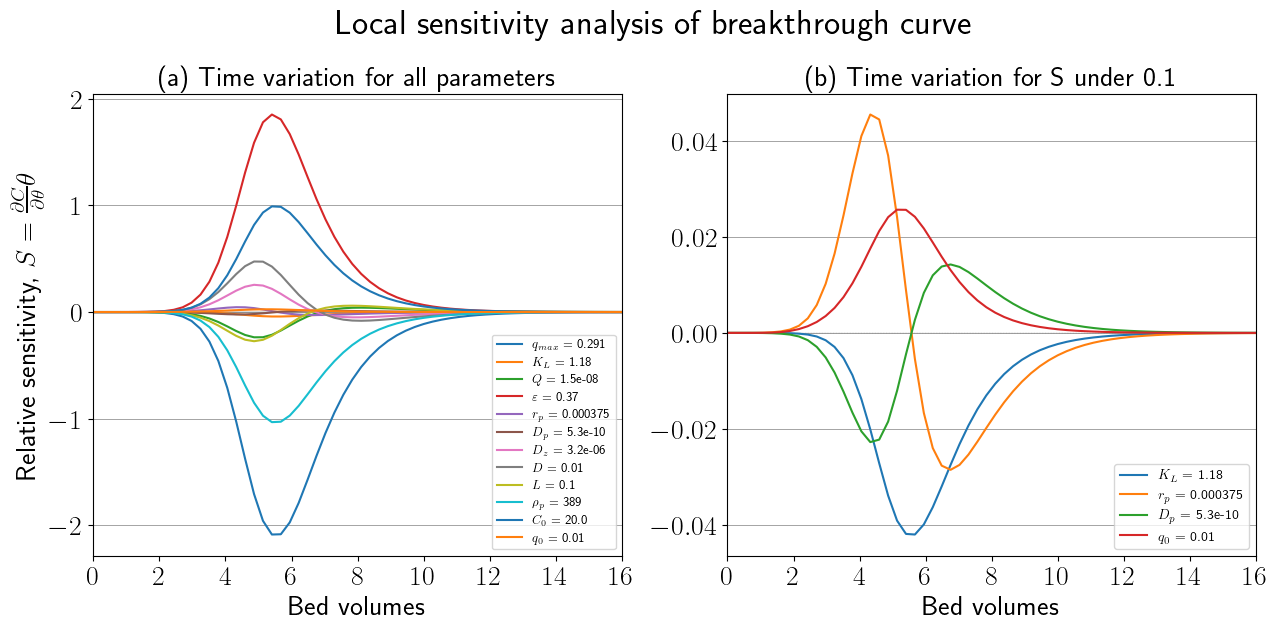

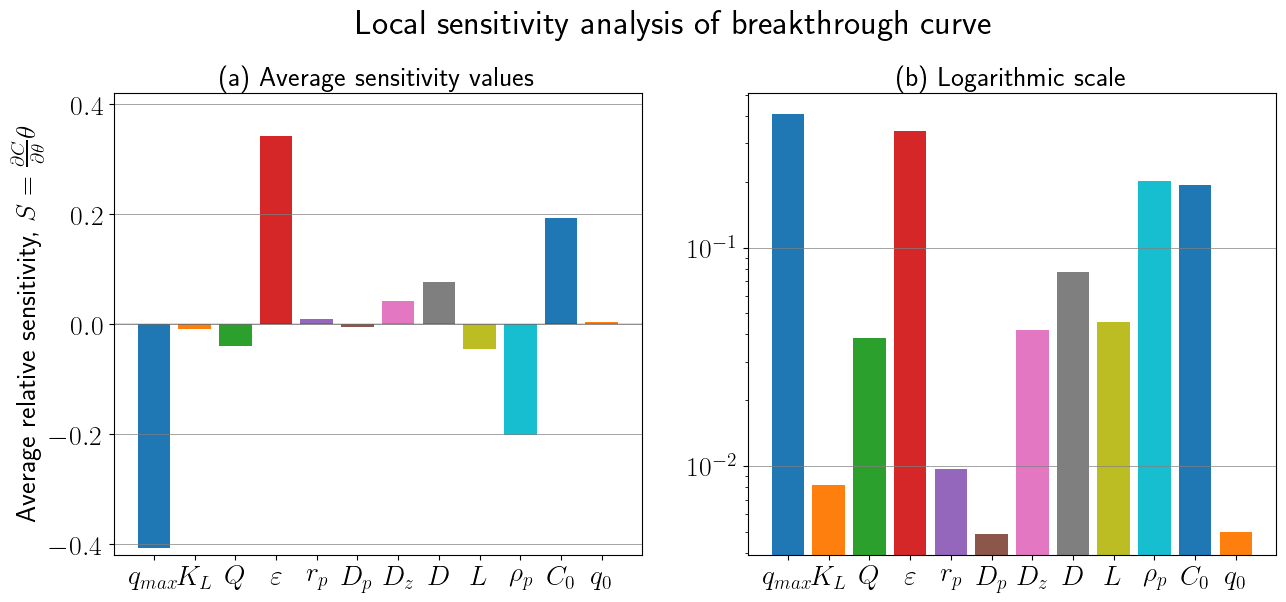

In [193]:
plot_sensitivity(S_all, labels=[r'$q_{max}$',r'$K_L$',r'$Q$',r'$\varepsilon$',r'$r_p$',r'$D_p$',r'$D_z$',r'$D$',r'$L$',r'$\rho_p$',r'$C_0$',r'$q_0$'],
                 qmax  = 0.291, 
                 Kl    = 1.18, 
                 Q     = 1.5e-8, 
                 e     = 0.37, 
                 rp    = 0.5 * 7.5e-4, 
                 Dp    = 5.3e-10, 
                 Dz    = 3.2e-6,
                 D     = 0.01, 
                 L     = 0.1, 
                 rho_p = 389, 
                 C0    = 20.,
                 q0    = 0.01)

In [218]:
# Maximum sensitivities
max_values = [np.max(S_all[key]) for key in S_all]
max_values

[16.216216216216203,
 0.0,
 1.8778114348849406e-10,
 0.04096770633843505,
 1.85222317601319,
 0.045406581185292165,
 0.014230945766247059,
 0.2553293270035617,
 0.47378500301342713,
 0.05969270335803855,
 3.9766864523850594e-09,
 0.9908212826870154,
 0.02561860278915695]

dict_items([('q0', 0.01)])
dt = 0.1


a6fcc5 running: t: 6: : 60it [00:10,  5.95it/s]                          


RMSE = 0.0805
dict_items([('q0', 0.010000100000000001)])
dt = 0.1


ff84dc running: t: 6: : 60it [00:10,  5.90it/s]                          


RMSE = 0.0805


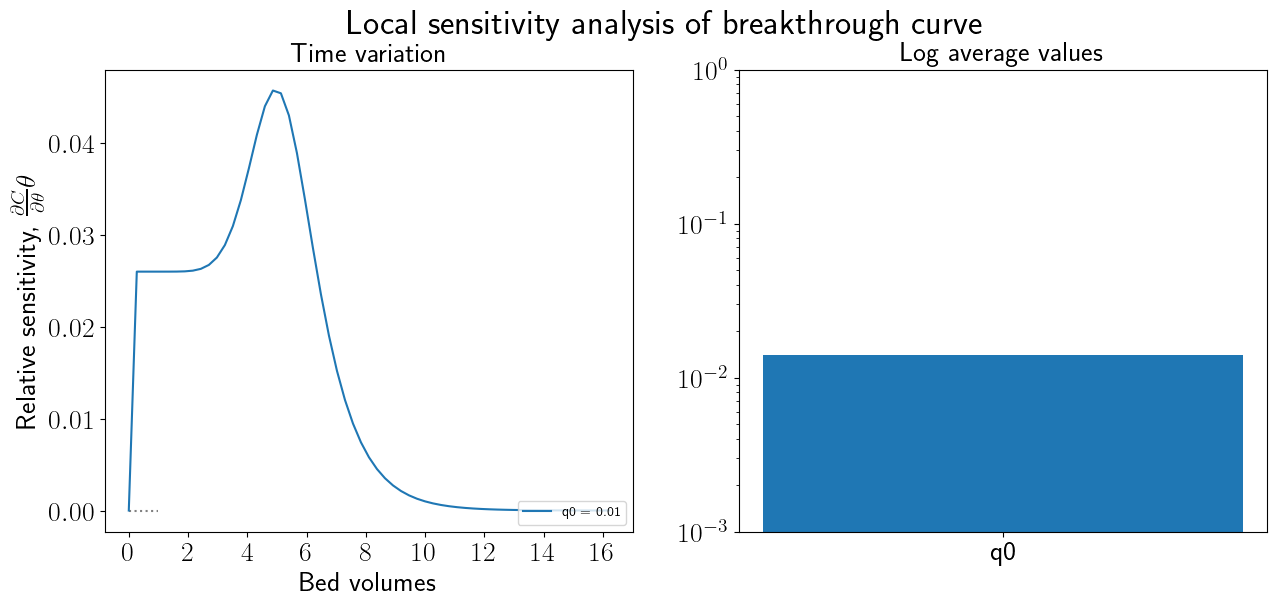

In [24]:
S = forward_sensitivity(model, q0=0.01)

In [20]:
def plot_sensitivity(sensitivities, labels=None, size=15, font=20, **parameters):
    
    fig, ax = plt.subplots(1, 2, figsize=(size,6))
    plt.suptitle('Local sensitivity analysis of breakthrough curve', fontsize=font+5)

    plt.rcParams['text.usetex'] = True
    
    ax[0].plot([0, 0], color='0.5', ls=':')
    
    for parameter, value in parameters.items():
        
        t = sensitivities['t']
        S = sensitivities[parameter]
        
        # Plot the sensitivity functions
        ax[0].plot(t, S, label= parameter + ' = ' + str(value))
        ax[0].set_xlabel('Bed volumes', fontsize=font)
        ax[0].set_ylabel(r'Relative sensitivity, $\frac{\partial C}{\partial \theta}\theta$', fontsize=font)
        ax[0].set_xticks(np.linspace(0, 16, 9), fontsize=font)
        ax[0].set_title('Time variation', fontsize=font)
        ax[0].legend(loc='lower right', fontsize=font-10)
        ax[0].tick_params(axis='x', labelsize=font)
        ax[0].tick_params(axis='y', labelsize=font)
        
        # Plot average sensitivity coefficient in a bar plot
        # Smean = np.mean(np.abs(S))
        Smean = np.mean(S)
        
        # ax[1].bar(parameter, np.abs(Smean))
        ax[1].bar(parameter, Smean)
        # ax[1].set_yscale('log')
        ax[1].set_title('Log average values', fontsize=font)
        ax[1].tick_params(axis='x', labelsize=font)
        ax[1].tick_params(axis='y', labelsize=font)
        # ax[1].set_yticks([1e-3, 1e-2, 1e-1, 1])
        if labels==None: labels = parameters.keys()
        positions = range(len(labels)) 
        ax[1].set_xticks(positions, labels)

    plt.savefig("sensitivity-local.pdf", format="pdf", bbox_inches="tight")
    plt.show()

plot_sensitivity(S_all, labels=[r'$q_{max}$',r'$K_L$',r'$Q$',r'$\varepsilon$',r'$r_p$',r'$D_p$',r'$D_z$',r'$D$',r'$L$',r'$\rho_p$',r'$C_0$',r'$q_0$'],
                 qmax  = 0.291, 
                 Kl    = 1.18, 
                 Q     = 1.5e-8, 
                 e     = 0.37, 
                 rp    = 0.5 * 7.5e-4, 
                 Dp    = 5.3e-10, 
                 Dz    = 3.2e-6,
                 D     = 0.01, 
                 L     = 0.1, 
                 rho_p = 389, 
                 C0    = 20.,
                 q0    = 0.1)    

NameError: name 'S_all' is not defined

### Local total relative sensitivity analysis (including C values)

dict_items([('qmax', 0.291), ('Kl', 1.18), ('Q', 1.5e-08), ('e', 0.37), ('rp', 0.000375), ('Dp', 5.3e-10), ('D', 0.01), ('L', 0.1), ('rho_p', 389), ('C0', 20.0), ('dt', 0.1)])
dx = 0.04
dt = 0.1


4dd7d9 running: t: 6: : 60it [00:02, 24.05it/s]                                                                 


dict_items([('qmax', 0.29100291), ('Kl', 1.18), ('Q', 1.5e-08), ('e', 0.37), ('rp', 0.000375), ('Dp', 5.3e-10), ('D', 0.01), ('L', 0.1), ('rho_p', 389), ('C0', 20.0), ('dt', 0.1)])
dx = 0.04
dt = 0.1


669ed4 running: t: 6: : 60it [00:02, 24.66it/s]                                                                 


dict_items([('qmax', 0.291), ('Kl', 1.1800118), ('Q', 1.5e-08), ('e', 0.37), ('rp', 0.000375), ('Dp', 5.3e-10), ('D', 0.01), ('L', 0.1), ('rho_p', 389), ('C0', 20.0), ('dt', 0.1)])
dx = 0.04
dt = 0.1


88b9a9 running: t: 6: : 60it [00:02, 24.83it/s]                                                                 


dict_items([('qmax', 0.291), ('Kl', 1.18), ('Q', 1.500015e-08), ('e', 0.37), ('rp', 0.000375), ('Dp', 5.3e-10), ('D', 0.01), ('L', 0.1), ('rho_p', 389), ('C0', 20.0), ('dt', 0.1)])
dx = 0.04
dt = 0.1


fb545f running: t: 6: : 60it [00:02, 25.11it/s]                                                                 


dict_items([('qmax', 0.291), ('Kl', 1.18), ('Q', 1.5e-08), ('e', 0.37000370000000005), ('rp', 0.000375), ('Dp', 5.3e-10), ('D', 0.01), ('L', 0.1), ('rho_p', 389), ('C0', 20.0), ('dt', 0.1)])
dx = 0.04
dt = 0.1


fe2e9a running: t: 6: : 60it [00:02, 25.09it/s]                                                                 


dict_items([('qmax', 0.291), ('Kl', 1.18), ('Q', 1.5e-08), ('e', 0.37), ('rp', 0.00037500375000000004), ('Dp', 5.3e-10), ('D', 0.01), ('L', 0.1), ('rho_p', 389), ('C0', 20.0), ('dt', 0.1)])
dx = 0.04
dt = 0.1


7e87e6 running: t: 6: : 60it [00:02, 25.12it/s]                                                                 


dict_items([('qmax', 0.291), ('Kl', 1.18), ('Q', 1.5e-08), ('e', 0.37), ('rp', 0.000375), ('Dp', 5.300053000000001e-10), ('D', 0.01), ('L', 0.1), ('rho_p', 389), ('C0', 20.0), ('dt', 0.1)])
dx = 0.04
dt = 0.1


edf338 running: t: 6: : 60it [00:02, 25.35it/s]                                                                 


dict_items([('qmax', 0.291), ('Kl', 1.18), ('Q', 1.5e-08), ('e', 0.37), ('rp', 0.000375), ('Dp', 5.3e-10), ('D', 0.010000100000000001), ('L', 0.1), ('rho_p', 389), ('C0', 20.0), ('dt', 0.1)])
dx = 0.04
dt = 0.1


0b9913 running: t: 6: : 60it [00:02, 25.32it/s]                                                                 


dict_items([('qmax', 0.291), ('Kl', 1.18), ('Q', 1.5e-08), ('e', 0.37), ('rp', 0.000375), ('Dp', 5.3e-10), ('D', 0.01), ('L', 0.100001), ('rho_p', 389), ('C0', 20.0), ('dt', 0.1)])
dx = 0.04
dt = 0.1


7ffc94 running: t: 6: : 60it [00:02, 23.40it/s]                                                                 


dict_items([('qmax', 0.291), ('Kl', 1.18), ('Q', 1.5e-08), ('e', 0.37), ('rp', 0.000375), ('Dp', 5.3e-10), ('D', 0.01), ('L', 0.1), ('rho_p', 389.00389), ('C0', 20.0), ('dt', 0.1)])
dx = 0.04
dt = 0.1


f10299 running: t: 6: : 60it [00:02, 24.87it/s]                                                                 


dict_items([('qmax', 0.291), ('Kl', 1.18), ('Q', 1.5e-08), ('e', 0.37), ('rp', 0.000375), ('Dp', 5.3e-10), ('D', 0.01), ('L', 0.1), ('rho_p', 389), ('C0', 20.0002), ('dt', 0.1)])
dx = 0.04
dt = 0.1


260f1d running: t: 6: : 60it [00:02, 25.09it/s]                                                                 


dict_items([('qmax', 0.291), ('Kl', 1.18), ('Q', 1.5e-08), ('e', 0.37), ('rp', 0.000375), ('Dp', 5.3e-10), ('D', 0.01), ('L', 0.1), ('rho_p', 389), ('C0', 20.0), ('dt', 0.100001)])
dx = 0.04
dt = 0.100001


d42f05 running: t: 6: : 60it [00:02, 24.33it/s]                                                                 


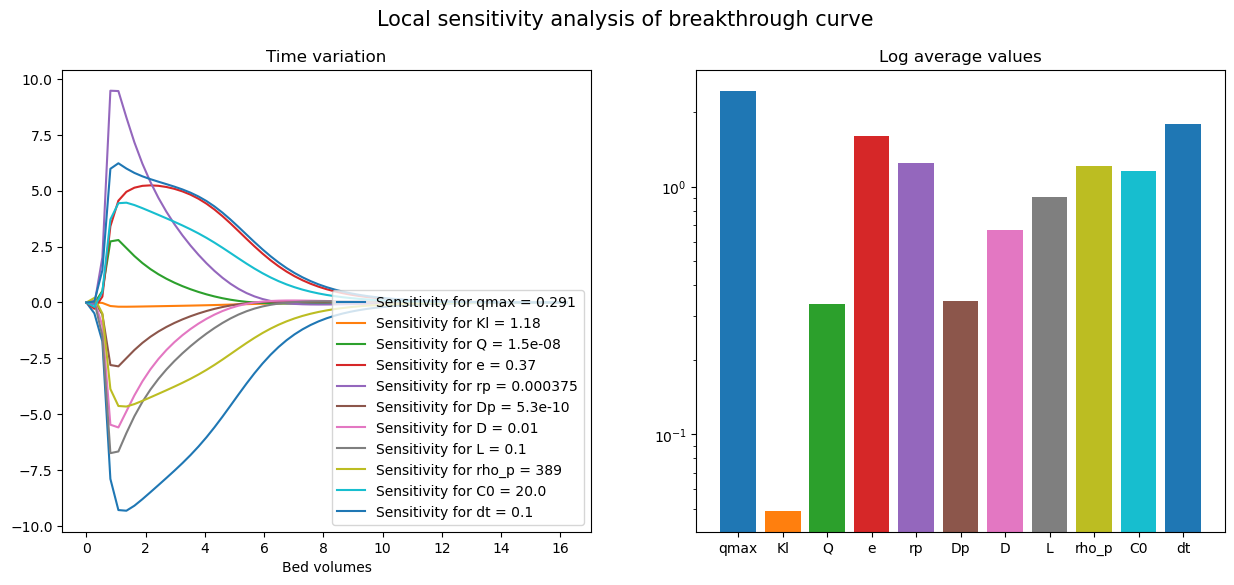

In [76]:
def plot_sensitivity(sensitivities, size=15, **parameters):
    
    fig, ax = plt.subplots(1, 2, figsize=(size,6))
    plt.suptitle('Local sensitivity analysis of breakthrough curve', fontsize=15)

    for parameter, value in parameters.items():
        
        t = sensitivities['t']
        S = sensitivities[parameter]
        
        # Plot the sensitivity functions
        ax[0].plot(t, S, label='Sensitivity for ' + parameter + ' = ' + str(value))
        ax[0].set_xlabel('Bed volumes')
        ax[0].set_title('Time variation')
        ax[0].legend(loc='lower right')
        
        # Plot average sensitivity coefficient in a bar plot
        Smean = np.mean(np.abs(S))
        
        ax[1].bar(parameter, np.abs(Smean))
        ax[1].set_yscale('log')
        ax[1].set_title('Log average values')

def forward_sensitivity(model, xi=1e-5, **parameters):
    
    sensitivities = dict()
    
    # First just run the model with original parameter values
    print(parameters.items())
    C1, y1, t1, z1 = model(Np=100, profiles=False, breakthrough=False, **parameters)
    
    # Read keyword arguments: parameter-value pairs
    for parameter, value in parameters.items():
        # print(parameter)
        # print(value)
        # parameter = value
        # print(list(kwargs)[0])

        # Now run the model with the adapted parameter value for each parameter
        parameters[parameter] = value*(1 + xi)
        print(parameters.items())

        C2, y2, t2, z2 = model(Np=100, profiles=False, breakthrough=False, **parameters)
        
        # Store the time vector
        sensitivities['t'] = t1

        # Calculate the local relative sensitivity function (wrt. the parameter value)
        sensitivities[parameter] = (C2 - C1)/(xi*value)*value/C1; 
        
        # Restore original value
        parameters[parameter] = value
        
    # Plot the sensitivity function
    plot_sensitivity(sensitivities, **parameters)
    
    return sensitivities

S_all = forward_sensitivity(model, qmax=0.291, Kl=1.18, Q=1.5e-8, e=0.37, rp=0.5 * 7.5e-4, Dp=5.3e-10, D=0.01, L=0.1, rho_p=389, C0=20., dt=0.1)

### Optimal perturbation factor

In [133]:
from scipy.optimize import minimize

def sensitivity(model, xi=1e-5, **parameters):
    
    forward = dict()
    backward = dict()
    
    # First just run the model with original parameter values
    print(parameters.items())
    C1, y1, t1, z1 = model(profiles=False, breakthrough=False, **parameters)
    
    # Read keyword arguments: parameter-value pairs
    for parameter, value in parameters.items():

        # Now run the model with the adapted parameter value for each parameter
        parameters[parameter] = value*(1 + xi)
        print(parameters.items())
        
        # Forward
        C2, y2, t2, z2 = model(profiles=False, breakthrough=False, **parameters)
        
        # Backward
        parameters[parameter] = value*(1 - xi)
        print(parameters.items())
        C3, y3, t3, z3 = model(profiles=False, breakthrough=False, **parameters)

        # Calculate the local relative sensitivity function (wrt. the parameter value)
        # Forward difference
        forward[parameter] = (C2 - C1)/xi 
        
        # Backward difference
        backward[parameter] = (C1 - C3)/xi
        
        # Restore original value
        parameters[parameter] = value
        
    # Plot the sensitivity function
    # plot_sensitivity(forward, **parameters)
    # plot_sensitivity(backward, **parameters)
    
    return t1, forward, backward


def fun(model, xi, value):
    
    # parameters = dict(qmax=0.291, Kl=1.18, Q=1.5e-8, e=0.37, rp=0.5 * 7.5e-4, Dp=5.3e-10, D=0.01, L=0.1, rho_p=389, C0=20.)
    
    # for index, parameter in enumerate(parameters):
    #     return sensitivity(model, xi=xi, d[parameter])
    
    return sensitivity(model, xi=xi, qmax=value)

def SSE(xi, model, value):
    
    xi = xi[0]
    print("xi = ", xi)
    
    t, Sforward, Sbackward = fun(model, xi, value)
    
    SSE = np.sum((Sforward['qmax'] - Sbackward['qmax'])**2)/np.shape(t)[0]
    
    print("SSE = ", SSE)
    
    return SSE


xi0 = 1e-5

res = minimize(SSE, x0=[xi0], args=(model, 0.291), bounds=((1e-15, 1),), tol=1e-6)
res.x

# SSE(xi0, model, 0.291)
# t, Sforward, Sbackward = sensitivity(model, xi0, qmax=0.291)
# np.sum((Sforward['qmax'] - Sbackward['qmax'])**2)/np.shape(t)[0]

# sensitivity(model, xi0, qmax=0.2)
# SSE([xi0], model, 0.2)

xi =  1e-05
dict_items([('qmax', 0.291)])
dt = 0.1


57cfc6 running: t: 6: : 60it [00:02, 22.51it/s]                                                                 


dict_items([('qmax', 0.29100291)])
dt = 0.1


202fb7 running: t: 6: : 60it [00:02, 22.95it/s]                                                                 


dict_items([('qmax', 0.29099709)])
dt = 0.1


3996c5 running: t: 6: : 60it [00:02, 23.21it/s]                                                                 


SSE =  3.7213475394350695e-10
xi =  1.001e-05
dict_items([('qmax', 0.291)])
dt = 0.1


ae53a5 running: t: 6: : 60it [00:02, 23.20it/s]                                                                 


dict_items([('qmax', 0.29100291290999997)])
dt = 0.1


008291 running: t: 6: : 60it [00:02, 23.32it/s]                                                                 


dict_items([('qmax', 0.29099708709)])
dt = 0.1


2df7e2 running: t: 6: : 60it [00:02, 23.11it/s]                                                                 


SSE =  3.728798823605601e-10
xi =  1e-15
dict_items([('qmax', 0.291)])
dt = 0.1


e41290 running: t: 6: : 60it [00:02, 22.47it/s]                                                                 


dict_items([('qmax', 0.2910000000000003)])
dt = 0.1


3a49e2 running: t: 6: : 60it [00:02, 23.15it/s]                                                                 


dict_items([('qmax', 0.2909999999999997)])
dt = 0.1


291065 running: t: 6: : 60it [00:02, 23.18it/s]                                                                 


SSE =  0.38382701029463706
xi =  1.0000001e-08
dict_items([('qmax', 0.291)])
dt = 0.1


6038f7 running: t: 6: : 60it [00:02, 23.52it/s]                                                                 


dict_items([('qmax', 0.2910000029100003)])
dt = 0.1


d6cf61 running: t: 6: : 60it [00:02, 21.81it/s]                                                                 


dict_items([('qmax', 0.2909999970899997)])
dt = 0.1


489b04 running: t: 6: : 60it [00:02, 22.96it/s]                                                                 


SSE =  4.0470557297857445e-15
xi =  6.67000667550515e-06
dict_items([('qmax', 0.291)])
dt = 0.1


f95785 running: t: 6: : 60it [00:02, 23.81it/s]                                                                 


dict_items([('qmax', 0.29100194097194254)])
dt = 0.1


f08b72 running: t: 6: : 60it [00:02, 24.67it/s]                                                                 


dict_items([('qmax', 0.2909980590280574)])
dt = 0.1


e1381a running: t: 6: : 60it [00:02, 24.96it/s]                                                                 


SSE =  1.6555793926473523e-10
xi =  6.68000667550515e-06
dict_items([('qmax', 0.291)])
dt = 0.1


76dd71 running: t: 6: : 60it [00:02, 24.79it/s]                                                                 


dict_items([('qmax', 0.29100194388194256)])
dt = 0.1


42eded running: t: 6: : 60it [00:02, 24.53it/s]                                                                 


dict_items([('qmax', 0.2909980561180574)])
dt = 0.1


97246d running: t: 6: : 60it [00:02, 25.01it/s]                                                                 


SSE =  1.6605595916149892e-10


array([6.67000668e-06])

## Global sensitivity analysis

#### Time scale

In [ ]:
# Generate Monte Carlo sampling for parameters

from SALib.sample import saltelli
from SALib.analyze import sobol
from SALib import ProblemSpec

# Define inputs
Np = 10             # no. of parameters

sp = ProblemSpec({
    'num_vars': Np,
    'names': ['D', 'L', 'Q', 'C_0', 'e', 'rho_p', 'r_p', 'q_{max}', 'K_L', 'Dp'],
    'bounds': [[0.8 * 0.010,  1.2 * 0.010],
               [0.8 * 0.1,    1.2 * 0.1],
               [0.8 * 1.5e-8, 1.2 * 1.5e-8],
               [0.8 * 20,     1.2 * 20],
               [0.8 * 0.37,   1.2 * 0.37],   # 0.3-0.444, 20% extra
               [0.8 * 389,    1.2 * 389],
               [0.4 * 7.5e-4, 1.6 * 7.5e-4], # 3-12e-4 m, 40% extra
               [0.8 * 0.123,  1.2 * 0.291],  # 20% extra
               [0.8 * 1.18,   1.2 * 3.71],   # 20% extra
               [0.8 * 1e-10,  1.2 * 1e-10]],
    'outputs': ['Y']
})


# Generate samples
N = 2**1

sp.sample_sobol(N, calc_second_order=True)

params = sp.samples
params.shape

#### Sampling of parameter space

In [5]:
# Generate Monte Carlo sampling for parameters

from SALib.sample import saltelli
from SALib.analyze import sobol
from SALib import ProblemSpec

# Define inputs
Np = 10             # no. of parameters

sp = ProblemSpec({
    'num_vars': Np,
    'names': ['D', 'L', 'Q', 'C_0', 'e', 'rho_p', 'r_p', 'q_{max}', 'K_L', 'Dp'],
    'bounds': [[0.8 * 0.010,  1.2 * 0.010],
               [0.8 * 0.1,    1.2 * 0.1],
               [0.8 * 1.5e-8, 1.2 * 1.5e-8],
               [0.8 * 20,     1.2 * 20],
               [0.8 * 0.37,   1.2 * 0.37],   # 0.3-0.44, 20%
               [0.8 * 389,    1.2 * 389],
               [3e-4, 12e-4], # 3-12e-4 m, 7.5e-4 m as average: [-40%, +60%]
               [0.8 * 0.123,  1.2 * 0.291],  # 20% extra
               [0.8 * 1.18,   1.2 * 3.71],   # 20% extra
               [0.8 * 5.3e-10,  1.2 * 5.3e-10]],  # 5.3e-10, 20% extra
    'outputs': ['Y']
})


# Generate samples
N = 2**8

sp.sample_sobol(N, calc_second_order=True)

params = sp.samples
params.shape

# Store in disk
sampling = pd.DataFrame(params)
sampling.rename(columns={0:'D', 1:'L', 2:'Q', 3:'C_0', 4:'e', 5:'rho_p', 6:'rp', 7:'qmax', 8:'Kl', 9:'Dp'}, inplace=True)
sampling.to_excel(f"sampling_N-{N:d}.xlsx")
sampling.to_csv(f"sampling_N-{N:d}.csv")

pars = pd.read_csv(f"sampling_N-{N:d}.csv")
print(pars)

      Unnamed: 0         D         L             Q        C_0         e  \
0              0  0.011636  0.112189  1.599632e-08  20.556907  0.425286   
1              1  0.008805  0.112189  1.599632e-08  20.556907  0.425286   
2              2  0.011636  0.115721  1.599632e-08  20.556907  0.425286   
3              3  0.011636  0.112189  1.251651e-08  20.556907  0.425286   
4              4  0.011636  0.112189  1.599632e-08  17.176547  0.425286   
...          ...       ...       ...           ...        ...       ...   
5627        5627  0.008320  0.114108  1.290604e-08  23.145153  0.410905   
5628        5628  0.008320  0.114108  1.290604e-08  23.145153  0.410905   
5629        5629  0.008320  0.114108  1.290604e-08  23.145153  0.410905   
5630        5630  0.008320  0.114108  1.290604e-08  23.145153  0.410905   
5631        5631  0.008320  0.114108  1.290604e-08  23.145153  0.410905   

           rho_p        rp      qmax        Kl            Dp  
0     348.009309  0.000958  0.347636

In [121]:
# Repeat sampling for reduced parameter set

from SALib.sample import saltelli
from SALib.analyze import sobol
from SALib import ProblemSpec

# Define inputs
Np = 5             # no. of parameters

sp = ProblemSpec({
    'num_vars': Np,
    'names': ['C_0', 'e', 'r_p', 'q_{max}', 'K_L'],
    'bounds': [[0.8 * 20,     1.2 * 20],
               [0.8 * 0.37,   1.2 * 0.37],   # 0.3-0.44, 20%
               [6e-4, 9e-4], # 6-9e-4 m, 7.5e-4 m as average: [-20%, +20%]
               [0.8 * 0.291,  1.2 * 0.291],  # 20% extra
               [0.8 * 1.18,   1.2 * 1.18]],   # 20% extra
    'outputs': ['Y']
})


# Generate samples
N = 2**8

sp.sample_sobol(N, calc_second_order=True)

params = sp.samples
params.shape

# Store in disk
sampling = pd.DataFrame(params)
sampling.rename(columns={0:'C_0', 1:'e', 2:'rp', 3:'qmax', 4:'Kl'}, inplace=True)
sampling.to_excel(f"sampling_N-{N:d}-Np-{Np:d}.xlsx")
sampling.to_csv(f"sampling_N-{N:d}-Np-{Np:d}.csv")

pars = pd.read_csv(f"sampling_N-{N:d}-Np-{Np:d}.csv")
print(pars)

      Unnamed: 0        C_0         e        rp      qmax        Kl
0              0  22.038440  0.407585  0.000843  0.345689  1.200440
1              1  17.648757  0.407585  0.000843  0.345689  1.200440
2              2  22.038440  0.355829  0.000843  0.345689  1.200440
3              3  22.038440  0.407585  0.000709  0.345689  1.200440
4              4  22.038440  0.407585  0.000843  0.313629  1.200440
...          ...        ...       ...       ...       ...       ...
3067        3067  23.330459  0.349203  0.000749  0.348571  1.273397
3068        3068  23.330459  0.442509  0.000664  0.348571  1.273397
3069        3069  23.330459  0.442509  0.000749  0.277823  1.273397
3070        3070  23.330459  0.442509  0.000749  0.348571  1.133984
3071        3071  23.330459  0.442509  0.000749  0.348571  1.273397

[3072 rows x 6 columns]


#### Monte Carlo simulation

In [122]:
# Choose simulation parameters
Nx    = 100
dt    = 0.1
tmax  = 6.25 # 6.08

# Create simulation matrices to store data
Y = np.zeros([params.shape[0], int(np.ceil(tmax/dt) + 1)])
T = np.zeros((params.shape[0], int(np.ceil(tmax/dt) + 1)))

# Run model
for i, X in enumerate(params):
    rho_p = 389
    Dp = 5.3e-10
    D = 0.01
    L = 0.1
    Q = 1.5e-8
    # D, L, Q, C0, e, rho_p, rp, qmax, Kl, Dp = X
    # D, L, Q, C0, e, rp, qmax, Kl = X
    C0, e, rp, qmax, Kl = X
    
    print(f'Run {i+1:d} of {params.shape[0]}')
    print(f'D = {D:.3f}, L = {L:.2f}, Q = {Q:.3e}, C0 = {C0:2.2f}, e = {e:.2f}, rho_p = {rho_p:.3f}, rp = {rp:.2e}, qmax = {qmax:.3f}, Kl = {Kl:.2f}, Dp = {Dp:.2e}')


    C, y, q, t, BV, z, RMSE = model(D=D, L=L, Q=Q, C0=C0, e=e, rho_p=rho_p, rp=rp, qmax=qmax, Kl=Kl, Dp=Dp,
                             
                                    tmax=tmax, 
                                    dt=dt,
                                    Nx=Nx,

                                    isotherm = 'Langmuir',
                                    profiles = False, 
                                    breakthrough = False)
    
    Y[i, :] = C  # breakthrough
    T[i, :] = t  # time
    
    # print(f't10 = {t[np.where(C > 0.1)[0][0]]:.2f}')
    

# sampleN256 = [Y, params, N, tmax, dt, Nx]

# Store data to disk
simulations = pd.DataFrame(Y)
simulations.to_csv(f"simulations_N-{N:d}_dt-{dt:.2f}_Np-{Np:d}.csv")
simulations.to_excel(f"simulations_N-{N:d}_dt-{dt:.2f}_Np-{Np:d}.xlsx")

times = pd.DataFrame(T)
times.to_csv(f"times_N-{N:d}_dt-{dt:.2f}_Np-{Np:d}.csv")
times.to_excel(f"times_N-{N:d}_dt-{dt:.2f}_Np-{Np:d}.xlsx")

Run 1 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.04, e = 0.41, rho_p = 389.000, rp = 8.43e-04, qmax = 0.346, Kl = 1.20, Dp = 5.30e-10


ea269b running: t: 6.25: : 63it [00:03, 18.69it/s]                       


RMSE = 0.0988
Run 2 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.65, e = 0.41, rho_p = 389.000, rp = 8.43e-04, qmax = 0.346, Kl = 1.20, Dp = 5.30e-10


eeada4 running: t: 6.25: : 63it [00:03, 17.80it/s]                       


RMSE = 0.1039
Run 3 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.04, e = 0.36, rho_p = 389.000, rp = 8.43e-04, qmax = 0.346, Kl = 1.20, Dp = 5.30e-10


94423d running: t: 6.25: : 63it [00:02, 22.00it/s]                       


RMSE = 0.0988
Run 4 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.04, e = 0.41, rho_p = 389.000, rp = 7.09e-04, qmax = 0.346, Kl = 1.20, Dp = 5.30e-10


16f9e2 running: t: 6.25: : 63it [00:03, 18.50it/s]                       


RMSE = 0.0693
Run 5 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.04, e = 0.41, rho_p = 389.000, rp = 8.43e-04, qmax = 0.314, Kl = 1.20, Dp = 5.30e-10


534684 running: t: 6.25: : 63it [00:02, 21.13it/s]                       


RMSE = 0.1314
Run 6 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.04, e = 0.41, rho_p = 389.000, rp = 8.43e-04, qmax = 0.346, Kl = 1.37, Dp = 5.30e-10


ab339a running: t: 6.25: : 63it [00:02, 21.63it/s]                       


RMSE = 0.0984
Run 7 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.04, e = 0.36, rho_p = 389.000, rp = 7.09e-04, qmax = 0.314, Kl = 1.37, Dp = 5.30e-10


ef7353 running: t: 6.25: : 63it [00:03, 16.43it/s]                       


RMSE = 0.1050
Run 8 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.65, e = 0.41, rho_p = 389.000, rp = 7.09e-04, qmax = 0.314, Kl = 1.37, Dp = 5.30e-10


f91789 running: t: 6.25: : 63it [00:05, 11.68it/s]                       


RMSE = 0.0683
Run 9 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.65, e = 0.36, rho_p = 389.000, rp = 8.43e-04, qmax = 0.314, Kl = 1.37, Dp = 5.30e-10


b68689 running: t: 6.25: : 63it [00:07,  8.83it/s]                       


RMSE = 0.0964
Run 10 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.65, e = 0.36, rho_p = 389.000, rp = 7.09e-04, qmax = 0.346, Kl = 1.37, Dp = 5.30e-10


2aa40c running: t: 6.25: : 63it [00:03, 20.48it/s]                       


RMSE = 0.1059
Run 11 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.65, e = 0.36, rho_p = 389.000, rp = 7.09e-04, qmax = 0.314, Kl = 1.20, Dp = 5.30e-10


cba46a running: t: 6.25: : 63it [00:03, 20.30it/s]                       


RMSE = 0.0677
Run 12 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.65, e = 0.36, rho_p = 389.000, rp = 7.09e-04, qmax = 0.314, Kl = 1.37, Dp = 5.30e-10


4fb2e3 running: t: 6.25: : 63it [00:03, 16.81it/s]                       


RMSE = 0.0676
Run 13 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.09, e = 0.31, rho_p = 389.000, rp = 6.80e-04, qmax = 0.287, Kl = 1.18, Dp = 5.30e-10


1a5161 running: t: 6.25: : 63it [00:02, 22.71it/s]                       


RMSE = 0.0843
Run 14 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.23, e = 0.31, rho_p = 389.000, rp = 6.80e-04, qmax = 0.287, Kl = 1.18, Dp = 5.30e-10


d0f296 running: t: 6.25: : 63it [00:03, 20.02it/s]                       


RMSE = 0.1321
Run 15 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.09, e = 0.39, rho_p = 389.000, rp = 6.80e-04, qmax = 0.287, Kl = 1.18, Dp = 5.30e-10


fdaca2 running: t: 6.25: : 63it [00:03, 15.97it/s]                       


RMSE = 0.0824
Run 16 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.09, e = 0.31, rho_p = 389.000, rp = 7.93e-04, qmax = 0.287, Kl = 1.18, Dp = 5.30e-10


9d115e running: t: 6.25: : 63it [00:02, 21.62it/s]                       


RMSE = 0.1107
Run 17 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.09, e = 0.31, rho_p = 389.000, rp = 6.80e-04, qmax = 0.238, Kl = 1.18, Dp = 5.30e-10


d36d4c running: t: 6.25: : 63it [00:02, 21.95it/s]                       


RMSE = 0.1942
Run 18 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.09, e = 0.31, rho_p = 389.000, rp = 6.80e-04, qmax = 0.287, Kl = 1.00, Dp = 5.30e-10


8710db running: t: 6.25: : 63it [00:03, 18.20it/s]                       


RMSE = 0.0866
Run 19 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.09, e = 0.39, rho_p = 389.000, rp = 7.93e-04, qmax = 0.238, Kl = 1.00, Dp = 5.30e-10


1cab8b running: t: 6.25: : 63it [00:02, 22.03it/s]                       


RMSE = 0.1937
Run 20 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.23, e = 0.31, rho_p = 389.000, rp = 7.93e-04, qmax = 0.238, Kl = 1.00, Dp = 5.30e-10


5a6161 running: t: 6.25: : 63it [00:03, 17.27it/s]                       


RMSE = 0.2470
Run 21 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.23, e = 0.39, rho_p = 389.000, rp = 6.80e-04, qmax = 0.238, Kl = 1.00, Dp = 5.30e-10


931eae running: t: 6.25: : 63it [00:03, 20.85it/s]                       


RMSE = 0.2128
Run 22 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.23, e = 0.39, rho_p = 389.000, rp = 7.93e-04, qmax = 0.287, Kl = 1.00, Dp = 5.30e-10


c113cc running: t: 6.25: : 63it [00:02, 21.85it/s]                       


RMSE = 0.1455
Run 23 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.23, e = 0.39, rho_p = 389.000, rp = 7.93e-04, qmax = 0.238, Kl = 1.18, Dp = 5.30e-10


af1961 running: t: 6.25: : 63it [00:03, 15.84it/s]                       


RMSE = 0.2242
Run 24 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.23, e = 0.39, rho_p = 389.000, rp = 7.93e-04, qmax = 0.238, Kl = 1.00, Dp = 5.30e-10


a29ba6 running: t: 6.25: : 63it [00:03, 20.73it/s]                       


RMSE = 0.2255
Run 25 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.70, e = 0.41, rho_p = 389.000, rp = 8.18e-04, qmax = 0.314, Kl = 1.02, Dp = 5.30e-10


ba5de4 running: t: 6.25: : 63it [00:02, 23.22it/s]                       


RMSE = 0.0986
Run 26 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.49, e = 0.41, rho_p = 389.000, rp = 8.18e-04, qmax = 0.314, Kl = 1.02, Dp = 5.30e-10


fa76df running: t: 6.25: : 63it [00:03, 16.77it/s]                       


RMSE = 0.1314
Run 27 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.70, e = 0.33, rho_p = 389.000, rp = 8.18e-04, qmax = 0.314, Kl = 1.02, Dp = 5.30e-10


79968a running: t: 6.25: : 63it [00:02, 21.03it/s]                       


RMSE = 0.0989
Run 28 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.70, e = 0.41, rho_p = 389.000, rp = 8.32e-04, qmax = 0.314, Kl = 1.02, Dp = 5.30e-10


08561f running: t: 6.25: : 63it [00:02, 22.02it/s]                       


RMSE = 0.1018
Run 29 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.70, e = 0.41, rho_p = 389.000, rp = 8.18e-04, qmax = 0.286, Kl = 1.02, Dp = 5.30e-10


a0bb90 running: t: 6.25: : 63it [00:03, 16.72it/s]                       


RMSE = 0.1330
Run 30 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.70, e = 0.41, rho_p = 389.000, rp = 8.18e-04, qmax = 0.314, Kl = 1.10, Dp = 5.30e-10


879a30 running: t: 6.25: : 63it [00:03, 18.25it/s]                       


RMSE = 0.0981
Run 31 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.70, e = 0.33, rho_p = 389.000, rp = 8.32e-04, qmax = 0.286, Kl = 1.10, Dp = 5.30e-10


56700d running: t: 6.25: : 63it [00:02, 21.56it/s]                       


RMSE = 0.1410
Run 32 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.49, e = 0.41, rho_p = 389.000, rp = 8.32e-04, qmax = 0.286, Kl = 1.10, Dp = 5.30e-10


ba9b33 running: t: 6.25: : 63it [00:03, 15.94it/s]                       


RMSE = 0.1723
Run 33 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.49, e = 0.33, rho_p = 389.000, rp = 8.18e-04, qmax = 0.286, Kl = 1.10, Dp = 5.30e-10


ff3b13 running: t: 6.25: : 63it [00:02, 21.36it/s]                       


RMSE = 0.1820
Run 34 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.49, e = 0.33, rho_p = 389.000, rp = 8.32e-04, qmax = 0.314, Kl = 1.10, Dp = 5.30e-10


9bd2d2 running: t: 6.25: : 63it [00:03, 17.42it/s]                       


RMSE = 0.1393
Run 35 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.49, e = 0.33, rho_p = 389.000, rp = 8.32e-04, qmax = 0.286, Kl = 1.02, Dp = 5.30e-10


463e3e running: t: 6.25: : 63it [00:03, 18.83it/s]                       


RMSE = 0.1851
Run 36 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.49, e = 0.33, rho_p = 389.000, rp = 8.32e-04, qmax = 0.286, Kl = 1.10, Dp = 5.30e-10


cc0a8c running: t: 6.25: : 63it [00:02, 22.80it/s]                       


RMSE = 0.1843
Run 37 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.67, e = 0.36, rho_p = 389.000, rp = 6.60e-04, qmax = 0.261, Kl = 1.33, Dp = 5.30e-10


916eea running: t: 6.25: : 63it [00:03, 20.28it/s]                       


RMSE = 0.1891
Run 38 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.88, e = 0.36, rho_p = 389.000, rp = 6.60e-04, qmax = 0.261, Kl = 1.33, Dp = 5.30e-10


4e1aca running: t: 6.25: : 63it [00:03, 19.53it/s]                       


RMSE = 0.1685
Run 39 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.67, e = 0.41, rho_p = 389.000, rp = 6.60e-04, qmax = 0.261, Kl = 1.33, Dp = 5.30e-10


5a8fd5 running: t: 6.25: : 63it [00:03, 19.30it/s]                       


RMSE = 0.1757
Run 40 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.67, e = 0.36, rho_p = 389.000, rp = 6.70e-04, qmax = 0.261, Kl = 1.33, Dp = 5.30e-10


8fe519 running: t: 6.25: : 63it [00:04, 14.35it/s]                       


RMSE = 0.1904
Run 41 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.67, e = 0.36, rho_p = 389.000, rp = 6.60e-04, qmax = 0.327, Kl = 1.33, Dp = 5.30e-10


6bffa5 running: t: 6.25: : 63it [00:03, 20.50it/s]                       


RMSE = 0.0697
Run 42 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.67, e = 0.36, rho_p = 389.000, rp = 6.60e-04, qmax = 0.261, Kl = 1.27, Dp = 5.30e-10


8eb12b running: t: 6.25: : 63it [00:02, 21.83it/s]                       


RMSE = 0.1895
Run 43 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.67, e = 0.41, rho_p = 389.000, rp = 6.70e-04, qmax = 0.327, Kl = 1.27, Dp = 5.30e-10


6ece06 running: t: 6.25: : 63it [00:03, 16.72it/s]                       


RMSE = 0.0725
Run 44 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.88, e = 0.36, rho_p = 389.000, rp = 6.70e-04, qmax = 0.327, Kl = 1.27, Dp = 5.30e-10


1b444a running: t: 6.25: : 63it [00:02, 22.81it/s]                       


RMSE = 0.0605
Run 45 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.88, e = 0.41, rho_p = 389.000, rp = 6.60e-04, qmax = 0.327, Kl = 1.27, Dp = 5.30e-10


9d50ab running: t: 6.25: : 63it [00:02, 21.82it/s]                       


RMSE = 0.0591
Run 46 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.88, e = 0.41, rho_p = 389.000, rp = 6.70e-04, qmax = 0.261, Kl = 1.27, Dp = 5.30e-10


5ad53b running: t: 6.25: : 63it [00:04, 14.82it/s]                       


RMSE = 0.1590
Run 47 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.88, e = 0.41, rho_p = 389.000, rp = 6.70e-04, qmax = 0.327, Kl = 1.33, Dp = 5.30e-10


297e26 running: t: 6.25: : 63it [00:02, 21.60it/s]                       


RMSE = 0.0614
Run 48 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.88, e = 0.41, rho_p = 389.000, rp = 6.70e-04, qmax = 0.327, Kl = 1.27, Dp = 5.30e-10


f874bc running: t: 6.25: : 63it [00:02, 21.33it/s]                       


RMSE = 0.0616
Run 49 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.36, e = 0.39, rho_p = 389.000, rp = 7.13e-04, qmax = 0.240, Kl = 1.37, Dp = 5.30e-10


919457 running: t: 6.25: : 63it [00:03, 20.65it/s]                       


RMSE = 0.2102
Run 50 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.48, e = 0.39, rho_p = 389.000, rp = 7.13e-04, qmax = 0.240, Kl = 1.37, Dp = 5.30e-10


5246b6 running: t: 6.25: : 63it [00:03, 20.53it/s]                       


RMSE = 0.1655
Run 51 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.36, e = 0.30, rho_p = 389.000, rp = 7.13e-04, qmax = 0.240, Kl = 1.37, Dp = 5.30e-10


f33078 running: t: 6.25: : 63it [00:03, 16.20it/s]                       


RMSE = 0.2336
Run 52 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.36, e = 0.39, rho_p = 389.000, rp = 8.77e-04, qmax = 0.240, Kl = 1.37, Dp = 5.30e-10


fe1848 running: t: 6.25: : 63it [00:03, 18.28it/s]                       


RMSE = 0.2309
Run 53 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.36, e = 0.39, rho_p = 389.000, rp = 7.13e-04, qmax = 0.276, Kl = 1.37, Dp = 5.30e-10


3b9826 running: t: 6.25: : 63it [00:02, 21.86it/s]                       


RMSE = 0.1487
Run 54 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.36, e = 0.39, rho_p = 389.000, rp = 7.13e-04, qmax = 0.240, Kl = 1.02, Dp = 5.30e-10


55db0e running: t: 6.25: : 63it [00:04, 14.26it/s]                       


RMSE = 0.2126
Run 55 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.36, e = 0.30, rho_p = 389.000, rp = 8.77e-04, qmax = 0.276, Kl = 1.02, Dp = 5.30e-10


fb02bc running: t: 6.25: : 63it [00:03, 18.15it/s]                       


RMSE = 0.1920
Run 56 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.48, e = 0.39, rho_p = 389.000, rp = 8.77e-04, qmax = 0.276, Kl = 1.02, Dp = 5.30e-10


648c8b running: t: 6.25: : 63it [00:03, 17.23it/s]                       


RMSE = 0.1376
Run 57 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.48, e = 0.30, rho_p = 389.000, rp = 7.13e-04, qmax = 0.276, Kl = 1.02, Dp = 5.30e-10


2ede47 running: t: 6.25: : 63it [00:03, 16.89it/s]                       


RMSE = 0.1069
Run 58 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.48, e = 0.30, rho_p = 389.000, rp = 8.77e-04, qmax = 0.240, Kl = 1.02, Dp = 5.30e-10


302c83 running: t: 6.25: : 63it [00:04, 15.30it/s]                       


RMSE = 0.2095
Run 59 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.48, e = 0.30, rho_p = 389.000, rp = 8.77e-04, qmax = 0.276, Kl = 1.37, Dp = 5.30e-10


94ed6f running: t: 6.25: : 63it [01:15,  1.20s/it]                       


RMSE = 0.1391
Run 60 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.48, e = 0.30, rho_p = 389.000, rp = 8.77e-04, qmax = 0.276, Kl = 1.02, Dp = 5.30e-10


d1be75 running: t: 6.25: : 63it [00:02, 22.05it/s]                       


RMSE = 0.1426
Run 61 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.27, e = 0.34, rho_p = 389.000, rp = 8.76e-04, qmax = 0.306, Kl = 1.00, Dp = 5.30e-10


10e642 running: t: 6.25: : 63it [00:02, 22.01it/s]                       


RMSE = 0.1279
Run 62 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.90, e = 0.34, rho_p = 389.000, rp = 8.76e-04, qmax = 0.306, Kl = 1.00, Dp = 5.30e-10


42110c running: t: 6.25: : 63it [00:04, 15.23it/s]                       


RMSE = 0.1550
Run 63 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.27, e = 0.44, rho_p = 389.000, rp = 8.76e-04, qmax = 0.306, Kl = 1.00, Dp = 5.30e-10


e551ab running: t: 6.25: : 63it [00:03, 20.39it/s]                       


RMSE = 0.1241
Run 64 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.27, e = 0.34, rho_p = 389.000, rp = 6.25e-04, qmax = 0.306, Kl = 1.00, Dp = 5.30e-10


159f40 running: t: 6.25: : 63it [00:02, 22.05it/s]                       


RMSE = 0.0699
Run 65 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.27, e = 0.34, rho_p = 389.000, rp = 8.76e-04, qmax = 0.337, Kl = 1.00, Dp = 5.30e-10


d1255a running: t: 6.25: : 63it [00:03, 19.08it/s]                       


RMSE = 0.1007
Run 66 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.27, e = 0.34, rho_p = 389.000, rp = 8.76e-04, qmax = 0.306, Kl = 1.35, Dp = 5.30e-10


b4c2c5 running: t: 6.25: : 63it [00:03, 20.84it/s]                       


RMSE = 0.1253
Run 67 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.27, e = 0.44, rho_p = 389.000, rp = 6.25e-04, qmax = 0.337, Kl = 1.35, Dp = 5.30e-10


7f3fac running: t: 6.25: : 63it [00:03, 16.50it/s]                       


RMSE = 0.0599
Run 68 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.90, e = 0.34, rho_p = 389.000, rp = 6.25e-04, qmax = 0.337, Kl = 1.35, Dp = 5.30e-10


a8b263 running: t: 6.25: : 63it [00:03, 19.87it/s]                       


RMSE = 0.0520
Run 69 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.90, e = 0.44, rho_p = 389.000, rp = 8.76e-04, qmax = 0.337, Kl = 1.35, Dp = 5.30e-10


ab78c4 running: t: 6.25: : 63it [00:02, 21.27it/s]                       


RMSE = 0.1110
Run 70 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.90, e = 0.44, rho_p = 389.000, rp = 6.25e-04, qmax = 0.306, Kl = 1.35, Dp = 5.30e-10


bfec50 running: t: 6.25: : 63it [00:03, 16.52it/s]                       


RMSE = 0.0932
Run 71 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.90, e = 0.44, rho_p = 389.000, rp = 6.25e-04, qmax = 0.337, Kl = 1.00, Dp = 5.30e-10


ee478f running: t: 6.25: : 63it [00:03, 20.77it/s]                       


RMSE = 0.0555
Run 72 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.90, e = 0.44, rho_p = 389.000, rp = 6.25e-04, qmax = 0.337, Kl = 1.35, Dp = 5.30e-10


62ead8 running: t: 6.25: : 63it [00:03, 16.89it/s]                       


RMSE = 0.0543
Run 73 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.88, e = 0.43, rho_p = 389.000, rp = 6.27e-04, qmax = 0.274, Kl = 1.07, Dp = 5.30e-10


49f10c running: t: 6.25: : 63it [00:06, 10.45it/s]                       


RMSE = 0.0893
Run 74 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.64, e = 0.43, rho_p = 389.000, rp = 6.27e-04, qmax = 0.274, Kl = 1.07, Dp = 5.30e-10


b9bae7 running: t: 6.25: : 63it [00:03, 16.63it/s]                       


RMSE = 0.1662
Run 75 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.88, e = 0.34, rho_p = 389.000, rp = 6.27e-04, qmax = 0.274, Kl = 1.07, Dp = 5.30e-10


b286cf running: t: 6.25: : 63it [00:05, 12.56it/s]                       


RMSE = 0.0956
Run 76 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.88, e = 0.43, rho_p = 389.000, rp = 7.36e-04, qmax = 0.274, Kl = 1.07, Dp = 5.30e-10


c788b3 running: t: 6.25: : 63it [00:03, 20.20it/s]                       


RMSE = 0.1119
Run 77 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.88, e = 0.43, rho_p = 389.000, rp = 6.27e-04, qmax = 0.303, Kl = 1.07, Dp = 5.30e-10


5a6f3e running: t: 6.25: : 63it [00:03, 17.87it/s]                       


RMSE = 0.0524
Run 78 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.88, e = 0.43, rho_p = 389.000, rp = 6.27e-04, qmax = 0.274, Kl = 1.22, Dp = 5.30e-10


f8a060 running: t: 6.25: : 63it [00:03, 19.77it/s]                       


RMSE = 0.0877
Run 79 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.88, e = 0.34, rho_p = 389.000, rp = 7.36e-04, qmax = 0.303, Kl = 1.22, Dp = 5.30e-10


967774 running: t: 6.25: : 63it [00:03, 18.44it/s]                       


RMSE = 0.0752
Run 80 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.64, e = 0.43, rho_p = 389.000, rp = 7.36e-04, qmax = 0.303, Kl = 1.22, Dp = 5.30e-10


7d7136 running: t: 6.25: : 63it [00:06,  9.89it/s]                       


RMSE = 0.1375
Run 81 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.64, e = 0.34, rho_p = 389.000, rp = 6.27e-04, qmax = 0.303, Kl = 1.22, Dp = 5.30e-10


e52ebc running: t: 6.25: : 63it [00:04, 14.24it/s]                       


RMSE = 0.1305
Run 82 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.64, e = 0.34, rho_p = 389.000, rp = 7.36e-04, qmax = 0.274, Kl = 1.22, Dp = 5.30e-10


ed3084 running: t: 6.25: : 63it [00:04, 14.74it/s]                       


RMSE = 0.1984
Run 83 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.64, e = 0.34, rho_p = 389.000, rp = 7.36e-04, qmax = 0.303, Kl = 1.07, Dp = 5.30e-10


255aab running: t: 6.25: : 63it [00:02, 21.36it/s]                       


RMSE = 0.1497
Run 84 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.64, e = 0.34, rho_p = 389.000, rp = 7.36e-04, qmax = 0.303, Kl = 1.22, Dp = 5.30e-10


559fb3 running: t: 6.25: : 63it [00:03, 15.84it/s]                       


RMSE = 0.1485
Run 85 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.99, e = 0.33, rho_p = 389.000, rp = 7.85e-04, qmax = 0.330, Kl = 1.27, Dp = 5.30e-10


97cdb1 running: t: 6.25: : 63it [00:03, 20.52it/s]                       


RMSE = 0.1188
Run 86 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.24, e = 0.33, rho_p = 389.000, rp = 7.85e-04, qmax = 0.330, Kl = 1.27, Dp = 5.30e-10


e217cd running: t: 6.25: : 63it [00:03, 17.97it/s]                       


RMSE = 0.0841
Run 87 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.99, e = 0.40, rho_p = 389.000, rp = 7.85e-04, qmax = 0.330, Kl = 1.27, Dp = 5.30e-10


f62953 running: t: 6.25: : 63it [00:04, 14.69it/s]                       


RMSE = 0.1152
Run 88 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.99, e = 0.33, rho_p = 389.000, rp = 7.66e-04, qmax = 0.330, Kl = 1.27, Dp = 5.30e-10


c164a3 running: t: 6.25: : 63it [00:02, 21.63it/s]                       


RMSE = 0.1146
Run 89 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.99, e = 0.33, rho_p = 389.000, rp = 7.85e-04, qmax = 0.248, Kl = 1.27, Dp = 5.30e-10


638fd3 running: t: 6.25: : 63it [00:03, 16.05it/s]                       


RMSE = 0.2544
Run 90 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.99, e = 0.33, rho_p = 389.000, rp = 7.85e-04, qmax = 0.330, Kl = 1.15, Dp = 5.30e-10


712b6d running: t: 6.25: : 63it [00:03, 19.96it/s]                       


RMSE = 0.1196
Run 91 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.99, e = 0.40, rho_p = 389.000, rp = 7.66e-04, qmax = 0.248, Kl = 1.15, Dp = 5.30e-10


e10000 running: t: 6.25: : 63it [00:03, 17.22it/s]                       


RMSE = 0.2327
Run 92 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.24, e = 0.33, rho_p = 389.000, rp = 7.66e-04, qmax = 0.248, Kl = 1.15, Dp = 5.30e-10


8c8f6f running: t: 6.25: : 63it [00:03, 19.98it/s]                       


RMSE = 0.1950
Run 93 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.24, e = 0.40, rho_p = 389.000, rp = 7.85e-04, qmax = 0.248, Kl = 1.15, Dp = 5.30e-10


c4747f running: t: 6.25: : 63it [00:02, 22.10it/s]                       


RMSE = 0.1840
Run 94 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.24, e = 0.40, rho_p = 389.000, rp = 7.66e-04, qmax = 0.330, Kl = 1.15, Dp = 5.30e-10


7f2c3c running: t: 6.25: : 63it [00:03, 17.16it/s]                       


RMSE = 0.0799
Run 95 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.24, e = 0.40, rho_p = 389.000, rp = 7.66e-04, qmax = 0.248, Kl = 1.27, Dp = 5.30e-10


3e2be5 running: t: 6.25: : 63it [00:03, 18.86it/s]                       


RMSE = 0.1802
Run 96 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.24, e = 0.40, rho_p = 389.000, rp = 7.66e-04, qmax = 0.248, Kl = 1.15, Dp = 5.30e-10


4b98a8 running: t: 6.25: : 63it [00:02, 21.60it/s]                       


RMSE = 0.1812
Run 97 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.07, e = 0.39, rho_p = 389.000, rp = 6.04e-04, qmax = 0.295, Kl = 1.14, Dp = 5.30e-10


0771b1 running: t: 6.25: : 63it [00:03, 18.24it/s]                       


RMSE = 0.1284
Run 98 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.37, e = 0.39, rho_p = 389.000, rp = 6.04e-04, qmax = 0.295, Kl = 1.14, Dp = 5.30e-10


68420a running: t: 6.25: : 63it [00:03, 18.20it/s]                       


RMSE = 0.0820
Run 99 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.07, e = 0.31, rho_p = 389.000, rp = 6.04e-04, qmax = 0.295, Kl = 1.14, Dp = 5.30e-10


6394dc running: t: 6.25: : 63it [00:02, 22.36it/s]                       


RMSE = 0.1427
Run 100 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.07, e = 0.39, rho_p = 389.000, rp = 8.97e-04, qmax = 0.295, Kl = 1.14, Dp = 5.30e-10


2460ed running: t: 6.25: : 63it [00:03, 18.46it/s]                       


RMSE = 0.1780
Run 101 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.07, e = 0.39, rho_p = 389.000, rp = 6.04e-04, qmax = 0.264, Kl = 1.14, Dp = 5.30e-10


09c962 running: t: 6.25: : 63it [00:04, 14.25it/s]                       


RMSE = 0.1840
Run 102 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.07, e = 0.39, rho_p = 389.000, rp = 6.04e-04, qmax = 0.295, Kl = 1.29, Dp = 5.30e-10


d804a5 running: t: 6.25: : 63it [00:03, 17.69it/s]                       


RMSE = 0.1273
Run 103 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.07, e = 0.31, rho_p = 389.000, rp = 8.97e-04, qmax = 0.264, Kl = 1.29, Dp = 5.30e-10


6c42b1 running: t: 6.25: : 63it [00:03, 18.19it/s]                       


RMSE = 0.2394
Run 104 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.37, e = 0.39, rho_p = 389.000, rp = 8.97e-04, qmax = 0.264, Kl = 1.29, Dp = 5.30e-10


783401 running: t: 6.25: : 63it [00:05, 11.27it/s]                       


RMSE = 0.1883
Run 105 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.37, e = 0.31, rho_p = 389.000, rp = 6.04e-04, qmax = 0.264, Kl = 1.29, Dp = 5.30e-10


d5ced4 running: t: 6.25: : 63it [00:03, 19.87it/s]                       


RMSE = 0.1585
Run 106 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.37, e = 0.31, rho_p = 389.000, rp = 8.97e-04, qmax = 0.295, Kl = 1.29, Dp = 5.30e-10


5d12da running: t: 6.25: : 63it [00:02, 21.11it/s]                       


RMSE = 0.1483
Run 107 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.37, e = 0.31, rho_p = 389.000, rp = 8.97e-04, qmax = 0.264, Kl = 1.14, Dp = 5.30e-10


f3f60b running: t: 6.25: : 63it [00:03, 19.03it/s]                       


RMSE = 0.2027
Run 108 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.37, e = 0.31, rho_p = 389.000, rp = 8.97e-04, qmax = 0.264, Kl = 1.29, Dp = 5.30e-10


85f560 running: t: 6.25: : 63it [00:03, 18.66it/s]                       


RMSE = 0.2016
Run 109 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.06, e = 0.36, rho_p = 389.000, rp = 7.60e-04, qmax = 0.236, Kl = 1.23, Dp = 5.30e-10


e54dca running: t: 6.25: : 63it [00:02, 21.09it/s]                       


RMSE = 0.1801
Run 110 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.76, e = 0.36, rho_p = 389.000, rp = 7.60e-04, qmax = 0.236, Kl = 1.23, Dp = 5.30e-10


e175a3 running: t: 6.25: : 63it [00:03, 19.01it/s]                       


RMSE = 0.2496
Run 111 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.06, e = 0.43, rho_p = 389.000, rp = 7.60e-04, qmax = 0.236, Kl = 1.23, Dp = 5.30e-10


95e692 running: t: 6.25: : 63it [01:14,  1.18s/it]                       


RMSE = 0.1679
Run 112 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.06, e = 0.36, rho_p = 389.000, rp = 6.06e-04, qmax = 0.236, Kl = 1.23, Dp = 5.30e-10


ca0e0b running: t: 6.25: : 63it [00:03, 20.36it/s]                       


RMSE = 0.1591
Run 113 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.06, e = 0.36, rho_p = 389.000, rp = 7.60e-04, qmax = 0.349, Kl = 1.23, Dp = 5.30e-10


c70a22 running: t: 6.25: : 63it [00:02, 23.63it/s]                       


RMSE = 0.1404
Run 114 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.06, e = 0.36, rho_p = 389.000, rp = 7.60e-04, qmax = 0.236, Kl = 1.06, Dp = 5.30e-10


996d2b running: t: 6.25: : 63it [00:03, 20.89it/s]                       


RMSE = 0.1818
Run 115 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.06, e = 0.43, rho_p = 389.000, rp = 6.06e-04, qmax = 0.349, Kl = 1.06, Dp = 5.30e-10


f3786a running: t: 6.25: : 63it [00:02, 23.10it/s]                       


RMSE = 0.1410
Run 116 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.76, e = 0.36, rho_p = 389.000, rp = 6.06e-04, qmax = 0.349, Kl = 1.06, Dp = 5.30e-10


f8a1af running: t: 6.25: : 63it [00:02, 21.66it/s]                       


RMSE = 0.0464
Run 117 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.76, e = 0.43, rho_p = 389.000, rp = 7.60e-04, qmax = 0.349, Kl = 1.06, Dp = 5.30e-10


7776b5 running: t: 6.25: : 63it [00:04, 12.89it/s]                       


RMSE = 0.0823
Run 118 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.76, e = 0.43, rho_p = 389.000, rp = 6.06e-04, qmax = 0.236, Kl = 1.06, Dp = 5.30e-10


f6d294 running: t: 6.25: : 63it [00:04, 14.00it/s]                       


RMSE = 0.2149
Run 119 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.76, e = 0.43, rho_p = 389.000, rp = 6.06e-04, qmax = 0.349, Kl = 1.23, Dp = 5.30e-10


cdd59b running: t: 6.25: : 63it [00:04, 13.32it/s]                       


RMSE = 0.0480
Run 120 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.76, e = 0.43, rho_p = 389.000, rp = 6.06e-04, qmax = 0.349, Kl = 1.06, Dp = 5.30e-10


aabbae running: t: 6.25: : 63it [00:03, 18.35it/s]                       


RMSE = 0.0481
Run 121 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.67, e = 0.42, rho_p = 389.000, rp = 7.38e-04, qmax = 0.321, Kl = 1.30, Dp = 5.30e-10


910c36 running: t: 6.25: : 63it [00:03, 20.93it/s]                       


RMSE = 0.0791
Run 122 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.52, e = 0.42, rho_p = 389.000, rp = 7.38e-04, qmax = 0.321, Kl = 1.30, Dp = 5.30e-10


ff8efb running: t: 6.25: : 63it [00:05, 11.40it/s]                       


RMSE = 0.0849
Run 123 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.67, e = 0.33, rho_p = 389.000, rp = 7.38e-04, qmax = 0.321, Kl = 1.30, Dp = 5.30e-10


a2e43f running: t: 6.25: : 63it [00:02, 22.09it/s]                       


RMSE = 0.0784
Run 124 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.67, e = 0.42, rho_p = 389.000, rp = 7.19e-04, qmax = 0.321, Kl = 1.30, Dp = 5.30e-10


630368 running: t: 6.25: : 63it [00:03, 17.10it/s]                       


RMSE = 0.0749
Run 125 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.67, e = 0.42, rho_p = 389.000, rp = 7.38e-04, qmax = 0.291, Kl = 1.30, Dp = 5.30e-10


782dbc running: t: 6.25: : 63it [00:02, 22.11it/s]                       


RMSE = 0.1162
Run 126 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.67, e = 0.42, rho_p = 389.000, rp = 7.38e-04, qmax = 0.321, Kl = 0.96, Dp = 5.30e-10


e68647 running: t: 6.25: : 63it [00:03, 16.74it/s]                       


RMSE = 0.0808
Run 127 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.67, e = 0.33, rho_p = 389.000, rp = 7.19e-04, qmax = 0.291, Kl = 0.96, Dp = 5.30e-10


1c10ec running: t: 6.25: : 63it [00:03, 16.77it/s]                       


RMSE = 0.1231
Run 128 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.52, e = 0.42, rho_p = 389.000, rp = 7.19e-04, qmax = 0.291, Kl = 0.96, Dp = 5.30e-10


a34cc7 running: t: 6.25: : 63it [00:05, 11.65it/s]                       


RMSE = 0.1245
Run 129 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.52, e = 0.33, rho_p = 389.000, rp = 7.38e-04, qmax = 0.291, Kl = 0.96, Dp = 5.30e-10


47c219 running: t: 6.25: : 63it [00:06, 10.38it/s]                       


RMSE = 0.1375
Run 130 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.52, e = 0.33, rho_p = 389.000, rp = 7.19e-04, qmax = 0.321, Kl = 0.96, Dp = 5.30e-10


0b0ac5 running: t: 6.25: : 63it [00:03, 20.83it/s]                       


RMSE = 0.0833
Run 131 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.52, e = 0.33, rho_p = 389.000, rp = 7.19e-04, qmax = 0.291, Kl = 1.30, Dp = 5.30e-10


3956ba running: t: 6.25: : 63it [00:03, 17.04it/s]                       


RMSE = 0.1306
Run 132 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.52, e = 0.33, rho_p = 389.000, rp = 7.19e-04, qmax = 0.291, Kl = 0.96, Dp = 5.30e-10


406cb0 running: t: 6.25: : 63it [00:02, 21.36it/s]                       


RMSE = 0.1341
Run 133 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.70, e = 0.30, rho_p = 389.000, rp = 8.99e-04, qmax = 0.268, Kl = 1.04, Dp = 5.30e-10


50647a running: t: 6.25: : 63it [00:03, 20.92it/s]                       


RMSE = 0.2120
Run 134 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.09, e = 0.30, rho_p = 389.000, rp = 8.99e-04, qmax = 0.268, Kl = 1.04, Dp = 5.30e-10


dbb35e running: t: 6.25: : 63it [00:04, 13.27it/s]                       


RMSE = 0.1684
Run 135 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.70, e = 0.40, rho_p = 389.000, rp = 8.99e-04, qmax = 0.268, Kl = 1.04, Dp = 5.30e-10


08cfc0 running: t: 6.25: : 63it [00:03, 20.89it/s]                       


RMSE = 0.1948
Run 136 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.70, e = 0.30, rho_p = 389.000, rp = 7.83e-04, qmax = 0.268, Kl = 1.04, Dp = 5.30e-10


6aa786 running: t: 6.25: : 63it [00:03, 20.21it/s]                       


RMSE = 0.1944
Run 137 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.70, e = 0.30, rho_p = 389.000, rp = 8.99e-04, qmax = 0.260, Kl = 1.04, Dp = 5.30e-10


2b3a0d running: t: 6.25: : 63it [00:03, 19.46it/s]                       


RMSE = 0.2267
Run 138 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.70, e = 0.30, rho_p = 389.000, rp = 8.99e-04, qmax = 0.268, Kl = 1.39, Dp = 5.30e-10


0ff916 running: t: 6.25: : 63it [00:02, 21.43it/s]                       


RMSE = 0.2094
Run 139 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.70, e = 0.40, rho_p = 389.000, rp = 7.83e-04, qmax = 0.260, Kl = 1.39, Dp = 5.30e-10


255988 running: t: 6.25: : 63it [00:03, 17.52it/s]                       


RMSE = 0.1870
Run 140 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.09, e = 0.30, rho_p = 389.000, rp = 7.83e-04, qmax = 0.260, Kl = 1.39, Dp = 5.30e-10


055b47 running: t: 6.25: : 63it [00:03, 19.42it/s]                       


RMSE = 0.1597
Run 141 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.09, e = 0.40, rho_p = 389.000, rp = 8.99e-04, qmax = 0.260, Kl = 1.39, Dp = 5.30e-10


e86dd7 running: t: 6.25: : 63it [00:02, 21.11it/s]                       


RMSE = 0.1689
Run 142 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.09, e = 0.40, rho_p = 389.000, rp = 7.83e-04, qmax = 0.268, Kl = 1.39, Dp = 5.30e-10


8cf1d0 running: t: 6.25: : 63it [00:04, 14.41it/s]                       


RMSE = 0.1329
Run 143 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.09, e = 0.40, rho_p = 389.000, rp = 7.83e-04, qmax = 0.260, Kl = 1.04, Dp = 5.30e-10


46372d running: t: 6.25: : 63it [00:02, 21.93it/s]                       


RMSE = 0.1502
Run 144 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.09, e = 0.40, rho_p = 389.000, rp = 7.83e-04, qmax = 0.260, Kl = 1.39, Dp = 5.30e-10


f61a62 running: t: 6.25: : 63it [00:03, 20.60it/s]                       


RMSE = 0.1473
Run 145 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.27, e = 0.44, rho_p = 389.000, rp = 8.02e-04, qmax = 0.277, Kl = 0.97, Dp = 5.30e-10


99cdc2 running: t: 6.25: : 63it [00:03, 17.63it/s]                       


RMSE = 0.1653
Run 146 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.50, e = 0.44, rho_p = 389.000, rp = 8.02e-04, qmax = 0.277, Kl = 0.97, Dp = 5.30e-10


d5167d running: t: 6.25: : 63it [00:02, 23.12it/s]                       


RMSE = 0.1390
Run 147 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.27, e = 0.36, rho_p = 389.000, rp = 8.02e-04, qmax = 0.277, Kl = 0.97, Dp = 5.30e-10


f94be9 running: t: 6.25: : 63it [00:03, 20.62it/s]                       


RMSE = 0.1787
Run 148 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.27, e = 0.44, rho_p = 389.000, rp = 6.90e-04, qmax = 0.277, Kl = 0.97, Dp = 5.30e-10


759d4c running: t: 6.25: : 63it [00:03, 17.83it/s]                       


RMSE = 0.1469
Run 149 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.27, e = 0.44, rho_p = 389.000, rp = 8.02e-04, qmax = 0.311, Kl = 0.97, Dp = 5.30e-10


9ac6bc running: t: 6.25: : 63it [00:02, 21.66it/s]                       


RMSE = 0.1191
Run 150 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.27, e = 0.44, rho_p = 389.000, rp = 8.02e-04, qmax = 0.277, Kl = 1.17, Dp = 5.30e-10


419ef0 running: t: 6.25: : 63it [00:03, 19.50it/s]                       


RMSE = 0.1638
Run 151 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.27, e = 0.36, rho_p = 389.000, rp = 6.90e-04, qmax = 0.311, Kl = 1.17, Dp = 5.30e-10


d94bbd running: t: 6.25: : 63it [00:03, 18.70it/s]                       


RMSE = 0.0977
Run 152 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.50, e = 0.44, rho_p = 389.000, rp = 6.90e-04, qmax = 0.311, Kl = 1.17, Dp = 5.30e-10


30df99 running: t: 6.25: : 63it [00:02, 21.59it/s]                       


RMSE = 0.0697
Run 153 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.50, e = 0.36, rho_p = 389.000, rp = 8.02e-04, qmax = 0.311, Kl = 1.17, Dp = 5.30e-10


b85a7b running: t: 6.25: : 63it [00:03, 19.61it/s]                       


RMSE = 0.0955
Run 154 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.50, e = 0.36, rho_p = 389.000, rp = 6.90e-04, qmax = 0.277, Kl = 1.17, Dp = 5.30e-10


f0f427 running: t: 6.25: : 63it [00:04, 15.33it/s]                       


RMSE = 0.1242
Run 155 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.50, e = 0.36, rho_p = 389.000, rp = 6.90e-04, qmax = 0.311, Kl = 0.97, Dp = 5.30e-10


feac70 running: t: 6.25: : 63it [00:03, 19.59it/s]                       


RMSE = 0.0702
Run 156 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.50, e = 0.36, rho_p = 389.000, rp = 6.90e-04, qmax = 0.311, Kl = 1.17, Dp = 5.30e-10


d8f4c5 running: t: 6.25: : 63it [00:03, 18.78it/s]                       


RMSE = 0.0688
Run 157 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.36, e = 0.32, rho_p = 389.000, rp = 6.46e-04, qmax = 0.342, Kl = 1.40, Dp = 5.30e-10


7bf7c7 running: t: 6.25: : 63it [00:03, 18.20it/s]                       


RMSE = 0.0893
Run 158 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.11, e = 0.32, rho_p = 389.000, rp = 6.46e-04, qmax = 0.342, Kl = 1.40, Dp = 5.30e-10


103b98 running: t: 6.25: : 63it [00:02, 21.93it/s]                       


RMSE = 0.0606
Run 159 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.36, e = 0.38, rho_p = 389.000, rp = 6.46e-04, qmax = 0.342, Kl = 1.40, Dp = 5.30e-10


0e8ffc running: t: 6.25: : 63it [00:03, 17.55it/s]                       


RMSE = 0.0842
Run 160 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.36, e = 0.32, rho_p = 389.000, rp = 8.13e-04, qmax = 0.342, Kl = 1.40, Dp = 5.30e-10


8da419 running: t: 6.25: : 63it [00:03, 20.27it/s]                       


RMSE = 0.0967
Run 161 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.36, e = 0.32, rho_p = 389.000, rp = 6.46e-04, qmax = 0.240, Kl = 1.40, Dp = 5.30e-10


00a1a1 running: t: 6.25: : 63it [00:03, 19.12it/s]                       


RMSE = 0.1966
Run 162 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.36, e = 0.32, rho_p = 389.000, rp = 6.46e-04, qmax = 0.342, Kl = 1.18, Dp = 5.30e-10


f1a7b6 running: t: 6.25: : 63it [00:03, 16.62it/s]                       


RMSE = 0.0867
Run 163 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.36, e = 0.38, rho_p = 389.000, rp = 8.13e-04, qmax = 0.240, Kl = 1.18, Dp = 5.30e-10


8022d0 running: t: 6.25: : 63it [00:02, 21.44it/s]                       


RMSE = 0.2063
Run 164 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.11, e = 0.32, rho_p = 389.000, rp = 8.13e-04, qmax = 0.240, Kl = 1.18, Dp = 5.30e-10


e32501 running: t: 6.25: : 63it [00:03, 19.95it/s]                       


RMSE = 0.2643
Run 165 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.11, e = 0.38, rho_p = 389.000, rp = 6.46e-04, qmax = 0.240, Kl = 1.18, Dp = 5.30e-10


923628 running: t: 6.25: : 63it [00:49,  1.28it/s]                       


RMSE = 0.2322
Run 166 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.11, e = 0.38, rho_p = 389.000, rp = 8.13e-04, qmax = 0.342, Kl = 1.18, Dp = 5.30e-10


c9fa10 running: t: 6.25: : 63it [00:03, 18.39it/s]                       


RMSE = 0.1018
Run 167 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.11, e = 0.38, rho_p = 389.000, rp = 8.13e-04, qmax = 0.240, Kl = 1.40, Dp = 5.30e-10


3fd541 running: t: 6.25: : 63it [00:03, 19.66it/s]                       


RMSE = 0.2474
Run 168 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.11, e = 0.38, rho_p = 389.000, rp = 8.13e-04, qmax = 0.240, Kl = 1.18, Dp = 5.30e-10


ec3904 running: t: 6.25: : 63it [00:03, 17.25it/s]                       


RMSE = 0.2484
Run 169 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.97, e = 0.37, rho_p = 389.000, rp = 8.56e-04, qmax = 0.252, Kl = 1.25, Dp = 5.30e-10


671ca3 running: t: 6.25: : 63it [00:02, 21.55it/s]                       


RMSE = 0.1894
Run 170 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.36, e = 0.37, rho_p = 389.000, rp = 8.56e-04, qmax = 0.252, Kl = 1.25, Dp = 5.30e-10


fc73e4 running: t: 6.25: : 63it [00:02, 22.07it/s]                       


RMSE = 0.2234
Run 171 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.97, e = 0.31, rho_p = 389.000, rp = 8.56e-04, qmax = 0.252, Kl = 1.25, Dp = 5.30e-10


85adb4 running: t: 6.25: : 63it [00:03, 17.33it/s]                       


RMSE = 0.1987
Run 172 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.97, e = 0.37, rho_p = 389.000, rp = 8.49e-04, qmax = 0.252, Kl = 1.25, Dp = 5.30e-10


a6abb3 running: t: 6.25: : 63it [00:02, 22.59it/s]                       


RMSE = 0.1882
Run 173 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.97, e = 0.37, rho_p = 389.000, rp = 8.56e-04, qmax = 0.284, Kl = 1.25, Dp = 5.30e-10


ee8d04 running: t: 6.25: : 63it [00:02, 22.88it/s]                       


RMSE = 0.1373
Run 174 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.97, e = 0.37, rho_p = 389.000, rp = 8.56e-04, qmax = 0.252, Kl = 1.31, Dp = 5.30e-10


181218 running: t: 6.25: : 63it [00:03, 18.27it/s]                       


RMSE = 0.1890
Run 175 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.97, e = 0.31, rho_p = 389.000, rp = 8.49e-04, qmax = 0.284, Kl = 1.31, Dp = 5.30e-10


b96a73 running: t: 6.25: : 63it [00:02, 21.06it/s]                       


RMSE = 0.1387
Run 176 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.36, e = 0.37, rho_p = 389.000, rp = 8.49e-04, qmax = 0.284, Kl = 1.31, Dp = 5.30e-10


6cad2f running: t: 6.25: : 63it [00:03, 20.96it/s]                       


RMSE = 0.1721
Run 177 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.36, e = 0.31, rho_p = 389.000, rp = 8.56e-04, qmax = 0.284, Kl = 1.31, Dp = 5.30e-10


28100c running: t: 6.25: : 63it [00:03, 16.43it/s]                       


RMSE = 0.1810
Run 178 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.36, e = 0.31, rho_p = 389.000, rp = 8.49e-04, qmax = 0.252, Kl = 1.31, Dp = 5.30e-10


6b97d0 running: t: 6.25: : 63it [00:03, 15.90it/s]                       


RMSE = 0.2348
Run 179 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.36, e = 0.31, rho_p = 389.000, rp = 8.49e-04, qmax = 0.284, Kl = 1.25, Dp = 5.30e-10


0079c3 running: t: 6.25: : 63it [00:02, 22.83it/s]                       


RMSE = 0.1801
Run 180 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.36, e = 0.31, rho_p = 389.000, rp = 8.49e-04, qmax = 0.284, Kl = 1.31, Dp = 5.30e-10


21fa6d running: t: 6.25: : 63it [00:04, 12.87it/s]                       


RMSE = 0.1797
Run 181 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.90, e = 0.34, rho_p = 389.000, rp = 6.96e-04, qmax = 0.308, Kl = 1.10, Dp = 5.30e-10


cd38a6 running: t: 6.25: : 63it [00:03, 20.49it/s]                       


RMSE = 0.1255
Run 182 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.78, e = 0.34, rho_p = 389.000, rp = 6.96e-04, qmax = 0.308, Kl = 1.10, Dp = 5.30e-10


cc64b2 running: t: 6.25: : 63it [00:03, 16.78it/s]                       


RMSE = 0.0647
Run 183 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.90, e = 0.42, rho_p = 389.000, rp = 6.96e-04, qmax = 0.308, Kl = 1.10, Dp = 5.30e-10


8ab2db running: t: 6.25: : 63it [00:02, 21.18it/s]                       


RMSE = 0.1172
Run 184 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.90, e = 0.34, rho_p = 389.000, rp = 6.54e-04, qmax = 0.308, Kl = 1.10, Dp = 5.30e-10


158675 running: t: 6.25: : 63it [00:02, 22.78it/s]                       


RMSE = 0.1177
Run 185 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.90, e = 0.34, rho_p = 389.000, rp = 6.96e-04, qmax = 0.330, Kl = 1.10, Dp = 5.30e-10


b9fb35 running: t: 6.25: : 63it [00:03, 18.22it/s]                       


RMSE = 0.0888
Run 186 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.90, e = 0.34, rho_p = 389.000, rp = 6.96e-04, qmax = 0.308, Kl = 1.04, Dp = 5.30e-10


9a8424 running: t: 6.25: : 63it [00:02, 21.32it/s]                       


RMSE = 0.1261
Run 187 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.90, e = 0.42, rho_p = 389.000, rp = 6.54e-04, qmax = 0.330, Kl = 1.04, Dp = 5.30e-10


3ddbc9 running: t: 6.25: : 63it [00:02, 21.86it/s]                       


RMSE = 0.0774
Run 188 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.78, e = 0.34, rho_p = 389.000, rp = 6.54e-04, qmax = 0.330, Kl = 1.04, Dp = 5.30e-10


ad1d7e running: t: 6.25: : 63it [00:03, 18.14it/s]                       


RMSE = 0.0871
Run 189 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.78, e = 0.42, rho_p = 389.000, rp = 6.96e-04, qmax = 0.330, Kl = 1.04, Dp = 5.30e-10


c89912 running: t: 6.25: : 63it [00:02, 21.18it/s]                       


RMSE = 0.0816
Run 190 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.78, e = 0.42, rho_p = 389.000, rp = 6.54e-04, qmax = 0.308, Kl = 1.04, Dp = 5.30e-10


f1ecbc running: t: 6.25: : 63it [00:03, 20.08it/s]                       


RMSE = 0.0575
Run 191 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.78, e = 0.42, rho_p = 389.000, rp = 6.54e-04, qmax = 0.330, Kl = 1.10, Dp = 5.30e-10


9111d7 running: t: 6.25: : 63it [00:03, 16.46it/s]                       


RMSE = 0.0812
Run 192 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.78, e = 0.42, rho_p = 389.000, rp = 6.54e-04, qmax = 0.330, Kl = 1.04, Dp = 5.30e-10


215e76 running: t: 6.25: : 63it [00:02, 21.98it/s]                       


RMSE = 0.0803
Run 193 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.56, e = 0.38, rho_p = 389.000, rp = 7.53e-04, qmax = 0.269, Kl = 1.35, Dp = 5.30e-10


e593b1 running: t: 6.25: : 63it [00:02, 22.02it/s]                       


RMSE = 0.1909
Run 194 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.28, e = 0.38, rho_p = 389.000, rp = 7.53e-04, qmax = 0.269, Kl = 1.35, Dp = 5.30e-10


4357a3 running: t: 6.25: : 63it [00:03, 17.91it/s]                       


RMSE = 0.1975
Run 195 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.56, e = 0.38, rho_p = 389.000, rp = 7.53e-04, qmax = 0.269, Kl = 1.35, Dp = 5.30e-10


cb6728 running: t: 6.25: : 63it [00:02, 22.12it/s]                       


RMSE = 0.1901
Run 196 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.56, e = 0.38, rho_p = 389.000, rp = 8.56e-04, qmax = 0.269, Kl = 1.35, Dp = 5.30e-10


d0935f running: t: 6.25: : 63it [00:02, 22.18it/s]                       


RMSE = 0.2058
Run 197 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.56, e = 0.38, rho_p = 389.000, rp = 7.53e-04, qmax = 0.343, Kl = 1.35, Dp = 5.30e-10


05b4d8 running: t: 6.25: : 63it [00:03, 16.99it/s]                       


RMSE = 0.0821
Run 198 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.56, e = 0.38, rho_p = 389.000, rp = 7.53e-04, qmax = 0.269, Kl = 1.34, Dp = 5.30e-10


8ad21a running: t: 6.25: : 63it [00:02, 21.85it/s]                       


RMSE = 0.1909
Run 199 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.56, e = 0.38, rho_p = 389.000, rp = 8.56e-04, qmax = 0.343, Kl = 1.34, Dp = 5.30e-10


03ef9d running: t: 6.25: : 63it [00:02, 22.16it/s]                       


RMSE = 0.1059
Run 200 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.28, e = 0.38, rho_p = 389.000, rp = 8.56e-04, qmax = 0.343, Kl = 1.34, Dp = 5.30e-10


9177b0 running: t: 6.25: : 63it [00:03, 17.65it/s]                       


RMSE = 0.1106
Run 201 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.28, e = 0.38, rho_p = 389.000, rp = 7.53e-04, qmax = 0.343, Kl = 1.34, Dp = 5.30e-10


4b8744 running: t: 6.25: : 63it [00:02, 23.75it/s]                       


RMSE = 0.0867
Run 202 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.28, e = 0.38, rho_p = 389.000, rp = 8.56e-04, qmax = 0.269, Kl = 1.34, Dp = 5.30e-10


3a1d80 running: t: 6.25: : 63it [00:03, 20.07it/s]                       


RMSE = 0.2112
Run 203 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.28, e = 0.38, rho_p = 389.000, rp = 8.56e-04, qmax = 0.343, Kl = 1.35, Dp = 5.30e-10


608d63 running: t: 6.25: : 63it [00:03, 16.59it/s]                       


RMSE = 0.1105
Run 204 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.28, e = 0.38, rho_p = 389.000, rp = 8.56e-04, qmax = 0.343, Kl = 1.34, Dp = 5.30e-10


685190 running: t: 6.25: : 63it [00:02, 22.66it/s]                       


RMSE = 0.1106
Run 205 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.57, e = 0.35, rho_p = 389.000, rp = 6.12e-04, qmax = 0.334, Kl = 1.02, Dp = 5.30e-10


3a7cda running: t: 6.25: : 63it [00:02, 22.56it/s]                       


RMSE = 0.0820
Run 206 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.85, e = 0.35, rho_p = 389.000, rp = 6.12e-04, qmax = 0.334, Kl = 1.02, Dp = 5.30e-10


036739 running: t: 6.25: : 63it [00:03, 17.16it/s]                       


RMSE = 0.0597
Run 207 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.57, e = 0.36, rho_p = 389.000, rp = 6.12e-04, qmax = 0.334, Kl = 1.02, Dp = 5.30e-10


b47f0f running: t: 6.25: : 63it [00:02, 22.96it/s]                       


RMSE = 0.0810
Run 208 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.57, e = 0.35, rho_p = 389.000, rp = 6.42e-04, qmax = 0.334, Kl = 1.02, Dp = 5.30e-10


e3e77f running: t: 6.25: : 63it [00:02, 23.02it/s]                       


RMSE = 0.0814
Run 209 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.57, e = 0.35, rho_p = 389.000, rp = 6.12e-04, qmax = 0.266, Kl = 1.02, Dp = 5.30e-10


8a7b3f running: t: 6.25: : 63it [00:03, 18.00it/s]                       


RMSE = 0.1234
Run 210 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.57, e = 0.35, rho_p = 389.000, rp = 6.12e-04, qmax = 0.334, Kl = 1.03, Dp = 5.30e-10


988bbf running: t: 6.25: : 63it [00:02, 24.00it/s]                       


RMSE = 0.0821
Run 211 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.57, e = 0.36, rho_p = 389.000, rp = 6.42e-04, qmax = 0.266, Kl = 1.03, Dp = 5.30e-10


f2dda6 running: t: 6.25: : 63it [00:02, 21.90it/s]                       


RMSE = 0.1266
Run 212 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.85, e = 0.35, rho_p = 389.000, rp = 6.42e-04, qmax = 0.266, Kl = 1.03, Dp = 5.30e-10


4a2373 running: t: 6.25: : 63it [00:03, 17.98it/s]                       


RMSE = 0.1472
Run 213 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.85, e = 0.36, rho_p = 389.000, rp = 6.12e-04, qmax = 0.266, Kl = 1.03, Dp = 5.30e-10


1de6ab running: t: 6.25: : 63it [00:02, 21.82it/s]                       


RMSE = 0.1409
Run 214 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.85, e = 0.36, rho_p = 389.000, rp = 6.42e-04, qmax = 0.334, Kl = 1.03, Dp = 5.30e-10


d4f48d running: t: 6.25: : 63it [00:02, 22.50it/s]                       


RMSE = 0.0618
Run 215 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.85, e = 0.36, rho_p = 389.000, rp = 6.42e-04, qmax = 0.266, Kl = 1.02, Dp = 5.30e-10


7ffea2 running: t: 6.25: : 63it [00:03, 16.47it/s]                       


RMSE = 0.1453
Run 216 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.85, e = 0.36, rho_p = 389.000, rp = 6.42e-04, qmax = 0.266, Kl = 1.03, Dp = 5.30e-10


205d33 running: t: 6.25: : 63it [00:03, 20.34it/s]                       


RMSE = 0.1452
Run 217 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.21, e = 0.44, rho_p = 389.000, rp = 8.86e-04, qmax = 0.245, Kl = 1.15, Dp = 5.30e-10


87a089 running: t: 6.25: : 63it [00:04, 13.27it/s]                       


RMSE = 0.1966
Run 218 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.62, e = 0.44, rho_p = 389.000, rp = 8.86e-04, qmax = 0.245, Kl = 1.15, Dp = 5.30e-10


de0618 running: t: 6.25: : 63it [00:03, 18.64it/s]                       


RMSE = 0.1809
Run 219 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.21, e = 0.41, rho_p = 389.000, rp = 8.86e-04, qmax = 0.245, Kl = 1.15, Dp = 5.30e-10


3f3607 running: t: 6.25: : 63it [00:02, 22.93it/s]                       


RMSE = 0.2025
Run 220 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.21, e = 0.44, rho_p = 389.000, rp = 6.78e-04, qmax = 0.245, Kl = 1.15, Dp = 5.30e-10


7c8b0c running: t: 6.25: : 63it [00:03, 16.60it/s]                       


RMSE = 0.1651
Run 221 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.21, e = 0.44, rho_p = 389.000, rp = 8.86e-04, qmax = 0.258, Kl = 1.15, Dp = 5.30e-10


c4bc59 running: t: 6.25: : 63it [00:02, 22.78it/s]                       


RMSE = 0.1776
Run 222 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.21, e = 0.44, rho_p = 389.000, rp = 8.86e-04, qmax = 0.245, Kl = 1.13, Dp = 5.30e-10


c67667 running: t: 6.25: : 63it [00:02, 21.98it/s]                       


RMSE = 0.1967
Run 223 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.21, e = 0.41, rho_p = 389.000, rp = 6.78e-04, qmax = 0.258, Kl = 1.13, Dp = 5.30e-10


e05bd6 running: t: 6.25: : 63it [00:03, 17.90it/s]                       


RMSE = 0.1479
Run 224 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.62, e = 0.44, rho_p = 389.000, rp = 6.78e-04, qmax = 0.258, Kl = 1.13, Dp = 5.30e-10


d24324 running: t: 6.25: : 63it [00:03, 20.30it/s]                       


RMSE = 0.1229
Run 225 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.62, e = 0.41, rho_p = 389.000, rp = 8.86e-04, qmax = 0.258, Kl = 1.13, Dp = 5.30e-10


a7d6d6 running: t: 6.25: : 63it [00:02, 23.03it/s]                       


RMSE = 0.1651
Run 226 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.62, e = 0.41, rho_p = 389.000, rp = 6.78e-04, qmax = 0.245, Kl = 1.13, Dp = 5.30e-10


a48d7b running: t: 6.25: : 63it [00:03, 17.03it/s]                       


RMSE = 0.1521
Run 227 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.62, e = 0.41, rho_p = 389.000, rp = 6.78e-04, qmax = 0.258, Kl = 1.15, Dp = 5.30e-10


43914e running: t: 6.25: : 63it [00:02, 21.59it/s]                       


RMSE = 0.1266
Run 228 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.62, e = 0.41, rho_p = 389.000, rp = 6.78e-04, qmax = 0.258, Kl = 1.13, Dp = 5.30e-10


0c1299 running: t: 6.25: : 63it [00:03, 17.92it/s]                       


RMSE = 0.1268
Run 229 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.17, e = 0.32, rho_p = 389.000, rp = 7.49e-04, qmax = 0.301, Kl = 1.19, Dp = 5.30e-10


097893 running: t: 6.25: : 63it [00:05, 10.64it/s]                       


RMSE = 0.1295
Run 230 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.00, e = 0.32, rho_p = 389.000, rp = 7.49e-04, qmax = 0.301, Kl = 1.19, Dp = 5.30e-10


e9a726 running: t: 6.25: : 63it [00:03, 18.44it/s]                       


RMSE = 0.1275
Run 231 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.17, e = 0.33, rho_p = 389.000, rp = 7.49e-04, qmax = 0.301, Kl = 1.19, Dp = 5.30e-10


fb7498 running: t: 6.25: : 63it [00:02, 23.48it/s]                       


RMSE = 0.1284
Run 232 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.17, e = 0.32, rho_p = 389.000, rp = 8.19e-04, qmax = 0.301, Kl = 1.19, Dp = 5.30e-10


66edb1 running: t: 6.25: : 63it [00:03, 19.11it/s]                       


RMSE = 0.1436
Run 233 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.17, e = 0.32, rho_p = 389.000, rp = 7.49e-04, qmax = 0.296, Kl = 1.19, Dp = 5.30e-10


5f07cf running: t: 6.25: : 63it [00:02, 22.17it/s]                       


RMSE = 0.1372
Run 234 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.17, e = 0.32, rho_p = 389.000, rp = 7.49e-04, qmax = 0.301, Kl = 1.24, Dp = 5.30e-10


d7b2ab running: t: 6.25: : 63it [00:02, 23.10it/s]                       


RMSE = 0.1291
Run 235 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.17, e = 0.33, rho_p = 389.000, rp = 8.19e-04, qmax = 0.296, Kl = 1.24, Dp = 5.30e-10


5c7391 running: t: 6.25: : 63it [00:03, 17.95it/s]                       


RMSE = 0.1491
Run 236 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.00, e = 0.32, rho_p = 389.000, rp = 8.19e-04, qmax = 0.296, Kl = 1.24, Dp = 5.30e-10


758589 running: t: 6.25: : 63it [00:02, 23.21it/s]                       


RMSE = 0.1484
Run 237 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.00, e = 0.33, rho_p = 389.000, rp = 7.49e-04, qmax = 0.296, Kl = 1.24, Dp = 5.30e-10


a95030 running: t: 6.25: : 63it [00:02, 23.26it/s]                       


RMSE = 0.1335
Run 238 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.00, e = 0.33, rho_p = 389.000, rp = 8.19e-04, qmax = 0.301, Kl = 1.24, Dp = 5.30e-10


63540c running: t: 6.25: : 63it [00:03, 17.29it/s]                       


RMSE = 0.1403
Run 239 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.00, e = 0.33, rho_p = 389.000, rp = 8.19e-04, qmax = 0.296, Kl = 1.19, Dp = 5.30e-10


3e9910 running: t: 6.25: : 63it [00:02, 23.23it/s]                       


RMSE = 0.1476
Run 240 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.00, e = 0.33, rho_p = 389.000, rp = 8.19e-04, qmax = 0.296, Kl = 1.24, Dp = 5.30e-10


587ccb running: t: 6.25: : 63it [00:02, 23.49it/s]                       


RMSE = 0.1472
Run 241 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.86, e = 0.42, rho_p = 389.000, rp = 6.54e-04, qmax = 0.317, Kl = 1.30, Dp = 5.30e-10


39892e running: t: 6.25: : 63it [00:03, 19.08it/s]                       


RMSE = 0.0735
Run 242 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.60, e = 0.42, rho_p = 389.000, rp = 6.54e-04, qmax = 0.317, Kl = 1.30, Dp = 5.30e-10


f6f24e running: t: 6.25: : 63it [00:02, 22.37it/s]                       


RMSE = 0.0911
Run 243 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.86, e = 0.44, rho_p = 389.000, rp = 6.54e-04, qmax = 0.317, Kl = 1.30, Dp = 5.30e-10


9bffcc running: t: 6.25: : 63it [00:02, 22.98it/s]                       


RMSE = 0.0732
Run 244 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.86, e = 0.42, rho_p = 389.000, rp = 7.26e-04, qmax = 0.317, Kl = 1.30, Dp = 5.30e-10


a379ea running: t: 6.25: : 63it [00:03, 18.20it/s]                       


RMSE = 0.0903
Run 245 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.86, e = 0.42, rho_p = 389.000, rp = 6.54e-04, qmax = 0.246, Kl = 1.30, Dp = 5.30e-10


4c1ec3 running: t: 6.25: : 63it [00:02, 21.83it/s]                       


RMSE = 0.1911
Run 246 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.86, e = 0.42, rho_p = 389.000, rp = 6.54e-04, qmax = 0.317, Kl = 0.99, Dp = 5.30e-10


a21e36 running: t: 6.25: : 63it [00:02, 23.13it/s]                       


RMSE = 0.0759
Run 247 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.86, e = 0.44, rho_p = 389.000, rp = 7.26e-04, qmax = 0.246, Kl = 0.99, Dp = 5.30e-10


3e8e23 running: t: 6.25: : 63it [00:03, 15.93it/s]                       


RMSE = 0.1971
Run 248 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.60, e = 0.42, rho_p = 389.000, rp = 7.26e-04, qmax = 0.246, Kl = 0.99, Dp = 5.30e-10


ac4937 running: t: 6.25: : 63it [00:03, 20.77it/s]                       


RMSE = 0.2159
Run 249 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.60, e = 0.44, rho_p = 389.000, rp = 6.54e-04, qmax = 0.246, Kl = 0.99, Dp = 5.30e-10


5e54e0 running: t: 6.25: : 63it [00:02, 22.34it/s]                       


RMSE = 0.2027
Run 250 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.60, e = 0.44, rho_p = 389.000, rp = 7.26e-04, qmax = 0.317, Kl = 0.99, Dp = 5.30e-10


16e109 running: t: 6.25: : 63it [00:03, 18.13it/s]                       


RMSE = 0.1076
Run 251 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.60, e = 0.44, rho_p = 389.000, rp = 7.26e-04, qmax = 0.246, Kl = 1.30, Dp = 5.30e-10


8d12bb running: t: 6.25: : 63it [00:02, 22.35it/s]                       


RMSE = 0.2089
Run 252 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.60, e = 0.44, rho_p = 389.000, rp = 7.26e-04, qmax = 0.246, Kl = 0.99, Dp = 5.30e-10


017d00 running: t: 6.25: : 63it [00:02, 22.74it/s]                       


RMSE = 0.2107
Run 253 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.76, e = 0.30, rho_p = 389.000, rp = 7.95e-04, qmax = 0.258, Kl = 1.08, Dp = 5.30e-10


508081 running: t: 6.25: : 63it [00:03, 18.11it/s]                       


RMSE = 0.2048
Run 254 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.02, e = 0.30, rho_p = 389.000, rp = 7.95e-04, qmax = 0.258, Kl = 1.08, Dp = 5.30e-10


3e9777 running: t: 6.25: : 63it [00:02, 22.71it/s]                       


RMSE = 0.1955
Run 255 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.76, e = 0.30, rho_p = 389.000, rp = 7.95e-04, qmax = 0.258, Kl = 1.08, Dp = 5.30e-10


aa7f3f running: t: 6.25: : 63it [00:02, 23.04it/s]                       


RMSE = 0.2040
Run 256 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.76, e = 0.30, rho_p = 389.000, rp = 7.71e-04, qmax = 0.258, Kl = 1.08, Dp = 5.30e-10


5f66f9 running: t: 6.25: : 63it [00:03, 17.92it/s]                       


RMSE = 0.2015
Run 257 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.76, e = 0.30, rho_p = 389.000, rp = 7.95e-04, qmax = 0.309, Kl = 1.08, Dp = 5.30e-10


8b59fd running: t: 6.25: : 63it [00:02, 22.40it/s]                       


RMSE = 0.1103
Run 258 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.76, e = 0.30, rho_p = 389.000, rp = 7.95e-04, qmax = 0.258, Kl = 1.38, Dp = 5.30e-10


6a5f0a running: t: 6.25: : 63it [00:02, 23.36it/s]                       


RMSE = 0.2023
Run 259 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.76, e = 0.30, rho_p = 389.000, rp = 7.71e-04, qmax = 0.309, Kl = 1.38, Dp = 5.30e-10


01c4d8 running: t: 6.25: : 63it [00:03, 18.69it/s]                       


RMSE = 0.1022
Run 260 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.02, e = 0.30, rho_p = 389.000, rp = 7.71e-04, qmax = 0.309, Kl = 1.38, Dp = 5.30e-10


254e17 running: t: 6.25: : 63it [00:02, 22.33it/s]                       


RMSE = 0.0941
Run 261 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.02, e = 0.30, rho_p = 389.000, rp = 7.95e-04, qmax = 0.309, Kl = 1.38, Dp = 5.30e-10


566826 running: t: 6.25: : 63it [00:02, 23.44it/s]                       


RMSE = 0.0999
Run 262 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.02, e = 0.30, rho_p = 389.000, rp = 7.71e-04, qmax = 0.258, Kl = 1.38, Dp = 5.30e-10


31fce1 running: t: 6.25: : 63it [00:03, 20.65it/s]                       


RMSE = 0.1887
Run 263 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.02, e = 0.30, rho_p = 389.000, rp = 7.71e-04, qmax = 0.309, Kl = 1.08, Dp = 5.30e-10


b29448 running: t: 6.25: : 63it [00:02, 21.32it/s]                       


RMSE = 0.0962
Run 264 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.02, e = 0.30, rho_p = 389.000, rp = 7.71e-04, qmax = 0.309, Kl = 1.38, Dp = 5.30e-10


e70c2a running: t: 6.25: : 63it [00:02, 23.12it/s]                       


RMSE = 0.0941
Run 265 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.40, e = 0.40, rho_p = 389.000, rp = 7.07e-04, qmax = 0.343, Kl = 0.98, Dp = 5.30e-10


6f2b85 running: t: 6.25: : 63it [00:02, 24.59it/s]                       


RMSE = 0.1142
Run 266 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.26, e = 0.40, rho_p = 389.000, rp = 7.07e-04, qmax = 0.343, Kl = 0.98, Dp = 5.30e-10


1c31c8 running: t: 6.25: : 63it [00:03, 18.02it/s]                       


RMSE = 0.0982
Run 267 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.40, e = 0.39, rho_p = 389.000, rp = 7.07e-04, qmax = 0.343, Kl = 0.98, Dp = 5.30e-10


e62499 running: t: 6.25: : 63it [00:07,  8.93it/s]                       


RMSE = 0.1153
Run 268 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.40, e = 0.40, rho_p = 389.000, rp = 8.85e-04, qmax = 0.343, Kl = 0.98, Dp = 5.30e-10


38c243 running: t: 6.25: : 63it [00:02, 22.98it/s]                       


RMSE = 0.1158
Run 269 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.40, e = 0.40, rho_p = 389.000, rp = 7.07e-04, qmax = 0.331, Kl = 0.98, Dp = 5.30e-10


d04ab0 running: t: 6.25: : 63it [00:05, 10.88it/s]                       


RMSE = 0.0918
Run 270 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.40, e = 0.40, rho_p = 389.000, rp = 7.07e-04, qmax = 0.343, Kl = 1.25, Dp = 5.30e-10


f87735 running: t: 6.25: : 63it [00:02, 23.66it/s]                       


RMSE = 0.1188
Run 271 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.40, e = 0.39, rho_p = 389.000, rp = 8.85e-04, qmax = 0.331, Kl = 1.25, Dp = 5.30e-10


bd8462 running: t: 6.25: : 63it [00:03, 18.98it/s]                       


RMSE = 0.1072
Run 272 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.26, e = 0.40, rho_p = 389.000, rp = 8.85e-04, qmax = 0.331, Kl = 1.25, Dp = 5.30e-10


ff91bd running: t: 6.25: : 63it [00:02, 22.19it/s]                       


RMSE = 0.1025
Run 273 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.26, e = 0.39, rho_p = 389.000, rp = 7.07e-04, qmax = 0.331, Kl = 1.25, Dp = 5.30e-10


16c1e3 running: t: 6.25: : 63it [00:02, 22.75it/s]                       


RMSE = 0.0828
Run 274 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.26, e = 0.39, rho_p = 389.000, rp = 8.85e-04, qmax = 0.343, Kl = 1.25, Dp = 5.30e-10


bb22e9 running: t: 6.25: : 63it [00:03, 17.35it/s]                       


RMSE = 0.1102
Run 275 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.26, e = 0.39, rho_p = 389.000, rp = 8.85e-04, qmax = 0.331, Kl = 0.98, Dp = 5.30e-10


9bb5c9 running: t: 6.25: : 63it [00:02, 22.30it/s]                       


RMSE = 0.1021
Run 276 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.26, e = 0.39, rho_p = 389.000, rp = 8.85e-04, qmax = 0.331, Kl = 1.25, Dp = 5.30e-10


c5c760 running: t: 6.25: : 63it [00:02, 23.93it/s]                       


RMSE = 0.1027
Run 277 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.47, e = 0.37, rho_p = 389.000, rp = 8.44e-04, qmax = 0.290, Kl = 1.37, Dp = 5.30e-10


c763f4 running: t: 6.25: : 63it [00:03, 18.43it/s]                       


RMSE = 0.1818
Run 278 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.87, e = 0.37, rho_p = 389.000, rp = 8.44e-04, qmax = 0.290, Kl = 1.37, Dp = 5.30e-10


3983e2 running: t: 6.25: : 63it [00:02, 22.21it/s]                       


RMSE = 0.1564
Run 279 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.47, e = 0.35, rho_p = 389.000, rp = 8.44e-04, qmax = 0.290, Kl = 1.37, Dp = 5.30e-10


721751 running: t: 6.25: : 63it [00:02, 22.31it/s]                       


RMSE = 0.1852
Run 280 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.47, e = 0.37, rho_p = 389.000, rp = 6.13e-04, qmax = 0.290, Kl = 1.37, Dp = 5.30e-10


948bfe running: t: 6.25: : 63it [03:43,  3.54s/it]                       


RMSE = 0.1460
Run 281 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.47, e = 0.37, rho_p = 389.000, rp = 8.44e-04, qmax = 0.278, Kl = 1.37, Dp = 5.30e-10


27aae2 running: t: 6.25: : 63it [00:02, 21.50it/s]                       


RMSE = 0.1999
Run 282 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.47, e = 0.37, rho_p = 389.000, rp = 8.44e-04, qmax = 0.290, Kl = 1.12, Dp = 5.30e-10


6894ca running: t: 6.25: : 63it [00:02, 22.85it/s]                       


RMSE = 0.1833
Run 283 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.47, e = 0.35, rho_p = 389.000, rp = 6.13e-04, qmax = 0.278, Kl = 1.12, Dp = 5.30e-10


081276 running: t: 6.25: : 63it [00:49,  1.26it/s]                       


RMSE = 0.1750
Run 284 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.87, e = 0.37, rho_p = 389.000, rp = 6.13e-04, qmax = 0.278, Kl = 1.12, Dp = 5.30e-10


231c3a running: t: 6.25: : 63it [00:02, 21.63it/s]                       


RMSE = 0.1399
Run 285 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.87, e = 0.35, rho_p = 389.000, rp = 8.44e-04, qmax = 0.278, Kl = 1.12, Dp = 5.30e-10


5b5c01 running: t: 6.25: : 63it [15:05, 14.38s/it]                       


RMSE = 0.1800
Run 286 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.87, e = 0.35, rho_p = 389.000, rp = 6.13e-04, qmax = 0.290, Kl = 1.12, Dp = 5.30e-10


e24eea running: t: 6.25: : 63it [00:02, 23.57it/s]                       


RMSE = 0.1190
Run 287 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.87, e = 0.35, rho_p = 389.000, rp = 6.13e-04, qmax = 0.278, Kl = 1.37, Dp = 5.30e-10


d47d2d running: t: 6.25: : 63it [00:02, 21.52it/s]                       


RMSE = 0.1416
Run 288 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.87, e = 0.35, rho_p = 389.000, rp = 6.13e-04, qmax = 0.278, Kl = 1.12, Dp = 5.30e-10


0c0dcf running: t: 6.25: : 63it [00:03, 17.24it/s]                       


RMSE = 0.1438
Run 289 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.59, e = 0.43, rho_p = 389.000, rp = 6.92e-04, qmax = 0.248, Kl = 1.05, Dp = 5.30e-10


abc8ca running: t: 6.25: : 63it [00:02, 21.69it/s]                       


RMSE = 0.2115
Run 290 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.75, e = 0.43, rho_p = 389.000, rp = 6.92e-04, qmax = 0.248, Kl = 1.05, Dp = 5.30e-10


2c47dc running: t: 6.25: : 63it [00:03, 20.47it/s]                       


RMSE = 0.1975
Run 291 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.59, e = 0.43, rho_p = 389.000, rp = 6.92e-04, qmax = 0.248, Kl = 1.05, Dp = 5.30e-10


567da4 running: t: 6.25: : 63it [00:03, 15.92it/s]                       


RMSE = 0.2135
Run 292 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.59, e = 0.43, rho_p = 389.000, rp = 7.43e-04, qmax = 0.248, Kl = 1.05, Dp = 5.30e-10


651d33 running: t: 6.25: : 63it [00:02, 22.29it/s]                       


RMSE = 0.2173
Run 293 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.59, e = 0.43, rho_p = 389.000, rp = 6.92e-04, qmax = 0.236, Kl = 1.05, Dp = 5.30e-10


ec4dab running: t: 6.25: : 63it [00:02, 22.57it/s]                       


RMSE = 0.2279
Run 294 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.59, e = 0.43, rho_p = 389.000, rp = 6.92e-04, qmax = 0.248, Kl = 1.20, Dp = 5.30e-10


1b10b4 running: t: 6.25: : 63it [00:03, 17.36it/s]                       


RMSE = 0.2107
Run 295 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.59, e = 0.43, rho_p = 389.000, rp = 7.43e-04, qmax = 0.236, Kl = 1.20, Dp = 5.30e-10


0ae359 running: t: 6.25: : 63it [00:02, 22.66it/s]                       


RMSE = 0.2344
Run 296 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.75, e = 0.43, rho_p = 389.000, rp = 7.43e-04, qmax = 0.236, Kl = 1.20, Dp = 5.30e-10


336263 running: t: 6.25: : 63it [00:02, 22.55it/s]                       


RMSE = 0.2197
Run 297 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.75, e = 0.43, rho_p = 389.000, rp = 6.92e-04, qmax = 0.236, Kl = 1.20, Dp = 5.30e-10


4bde8f running: t: 6.25: : 63it [00:03, 18.02it/s]                       


RMSE = 0.2160
Run 298 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.75, e = 0.43, rho_p = 389.000, rp = 7.43e-04, qmax = 0.248, Kl = 1.20, Dp = 5.30e-10


9459e2 running: t: 6.25: : 63it [00:03, 19.93it/s]                       


RMSE = 0.2044
Run 299 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.75, e = 0.43, rho_p = 389.000, rp = 7.43e-04, qmax = 0.236, Kl = 1.05, Dp = 5.30e-10


386c79 running: t: 6.25: : 63it [00:02, 22.18it/s]                       


RMSE = 0.2225
Run 300 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.75, e = 0.43, rho_p = 389.000, rp = 7.43e-04, qmax = 0.236, Kl = 1.20, Dp = 5.30e-10


c99a87 running: t: 6.25: : 63it [00:03, 17.21it/s]                       


RMSE = 0.2216
Run 301 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.54, e = 0.33, rho_p = 389.000, rp = 8.32e-04, qmax = 0.313, Kl = 1.32, Dp = 5.30e-10


df6152 running: t: 6.25: : 63it [00:02, 23.69it/s]                       


RMSE = 0.0919
Run 302 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.14, e = 0.33, rho_p = 389.000, rp = 8.32e-04, qmax = 0.313, Kl = 1.32, Dp = 5.30e-10


f667fd running: t: 6.25: : 63it [00:02, 22.89it/s]                       


RMSE = 0.0927
Run 303 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.54, e = 0.31, rho_p = 389.000, rp = 8.32e-04, qmax = 0.313, Kl = 1.32, Dp = 5.30e-10


2f37ee running: t: 6.25: : 63it [00:03, 17.67it/s]                       


RMSE = 0.0922
Run 304 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.54, e = 0.33, rho_p = 389.000, rp = 7.54e-04, qmax = 0.313, Kl = 1.32, Dp = 5.30e-10


5fe4e8 running: t: 6.25: : 63it [00:02, 23.65it/s]                       


RMSE = 0.0780
Run 305 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.54, e = 0.33, rho_p = 389.000, rp = 8.32e-04, qmax = 0.319, Kl = 1.32, Dp = 5.30e-10


6e6ef9 running: t: 6.25: : 63it [00:02, 24.29it/s]                       


RMSE = 0.0937
Run 306 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.54, e = 0.33, rho_p = 389.000, rp = 8.32e-04, qmax = 0.313, Kl = 1.15, Dp = 5.30e-10


c1fb2e running: t: 6.25: : 63it [00:03, 18.12it/s]                       


RMSE = 0.0919
Run 307 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.54, e = 0.31, rho_p = 389.000, rp = 7.54e-04, qmax = 0.319, Kl = 1.15, Dp = 5.30e-10


ece4c7 running: t: 6.25: : 63it [00:02, 22.95it/s]                       


RMSE = 0.0826
Run 308 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.14, e = 0.33, rho_p = 389.000, rp = 7.54e-04, qmax = 0.319, Kl = 1.15, Dp = 5.30e-10


90701e running: t: 6.25: : 63it [00:02, 23.69it/s]                       


RMSE = 0.0860
Run 309 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.14, e = 0.31, rho_p = 389.000, rp = 8.32e-04, qmax = 0.319, Kl = 1.15, Dp = 5.30e-10


f45b30 running: t: 6.25: : 63it [00:03, 18.51it/s]                       


RMSE = 0.0960
Run 310 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.14, e = 0.31, rho_p = 389.000, rp = 7.54e-04, qmax = 0.313, Kl = 1.15, Dp = 5.30e-10


ab40b5 running: t: 6.25: : 63it [00:02, 22.77it/s]                       


RMSE = 0.0801
Run 311 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.14, e = 0.31, rho_p = 389.000, rp = 7.54e-04, qmax = 0.319, Kl = 1.32, Dp = 5.30e-10


9c9a89 running: t: 6.25: : 63it [00:05, 12.57it/s]                       


RMSE = 0.0884
Run 312 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.14, e = 0.31, rho_p = 389.000, rp = 7.54e-04, qmax = 0.319, Kl = 1.15, Dp = 5.30e-10


e9d152 running: t: 6.25: : 63it [00:07,  8.73it/s]                       


RMSE = 0.0869
Run 313 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.17, e = 0.38, rho_p = 389.000, rp = 6.66e-04, qmax = 0.281, Kl = 1.22, Dp = 5.30e-10


c14470 running: t: 6.25: : 63it [00:04, 12.92it/s]                       


RMSE = 0.1173
Run 314 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.39, e = 0.38, rho_p = 389.000, rp = 6.66e-04, qmax = 0.281, Kl = 1.22, Dp = 5.30e-10


8cc775 running: t: 6.25: : 63it [00:03, 19.52it/s]                       


RMSE = 0.1067
Run 315 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.17, e = 0.40, rho_p = 389.000, rp = 6.66e-04, qmax = 0.281, Kl = 1.22, Dp = 5.30e-10


f1c677 running: t: 6.25: : 63it [00:02, 22.73it/s]                       


RMSE = 0.1151
Run 316 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.17, e = 0.38, rho_p = 389.000, rp = 8.66e-04, qmax = 0.281, Kl = 1.22, Dp = 5.30e-10


42f634 running: t: 6.25: : 63it [00:03, 18.16it/s]                       


RMSE = 0.1556
Run 317 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.17, e = 0.38, rho_p = 389.000, rp = 6.66e-04, qmax = 0.321, Kl = 1.22, Dp = 5.30e-10


7f8fa3 running: t: 6.25: : 63it [00:02, 22.52it/s]                       


RMSE = 0.0599
Run 318 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.17, e = 0.38, rho_p = 389.000, rp = 6.66e-04, qmax = 0.281, Kl = 1.05, Dp = 5.30e-10


a3dfdb running: t: 6.25: : 63it [00:02, 23.00it/s]                       


RMSE = 0.1191
Run 319 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.17, e = 0.40, rho_p = 389.000, rp = 8.66e-04, qmax = 0.321, Kl = 1.05, Dp = 5.30e-10


3f8ca2 running: t: 6.25: : 63it [00:03, 17.81it/s]                       


RMSE = 0.1061
Run 320 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.39, e = 0.38, rho_p = 389.000, rp = 8.66e-04, qmax = 0.321, Kl = 1.05, Dp = 5.30e-10


b9767f running: t: 6.25: : 63it [00:02, 22.45it/s]                       


RMSE = 0.1018
Run 321 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.39, e = 0.40, rho_p = 389.000, rp = 6.66e-04, qmax = 0.321, Kl = 1.05, Dp = 5.30e-10


810e57 running: t: 6.25: : 63it [00:02, 23.20it/s]                       


RMSE = 0.0594
Run 322 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.39, e = 0.40, rho_p = 389.000, rp = 8.66e-04, qmax = 0.281, Kl = 1.05, Dp = 5.30e-10


af84e9 running: t: 6.25: : 63it [00:03, 17.98it/s]                       


RMSE = 0.1468
Run 323 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.39, e = 0.40, rho_p = 389.000, rp = 8.66e-04, qmax = 0.321, Kl = 1.22, Dp = 5.30e-10


d3f86d running: t: 6.25: : 63it [00:02, 22.20it/s]                       


RMSE = 0.1011
Run 324 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.39, e = 0.40, rho_p = 389.000, rp = 8.66e-04, qmax = 0.321, Kl = 1.05, Dp = 5.30e-10


3eede6 running: t: 6.25: : 63it [00:02, 23.51it/s]                       


RMSE = 0.1017
Run 325 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.20, e = 0.33, rho_p = 389.000, rp = 8.10e-04, qmax = 0.337, Kl = 1.12, Dp = 5.30e-10


592051 running: t: 6.25: : 63it [00:02, 23.80it/s]                       


RMSE = 0.0887
Run 326 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.97, e = 0.33, rho_p = 389.000, rp = 8.10e-04, qmax = 0.337, Kl = 1.12, Dp = 5.30e-10


2e72fb running: t: 6.25: : 63it [00:03, 19.47it/s]                       


RMSE = 0.1146
Run 327 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.20, e = 0.34, rho_p = 389.000, rp = 8.10e-04, qmax = 0.337, Kl = 1.12, Dp = 5.30e-10


fe4d70 running: t: 6.25: : 63it [00:02, 22.42it/s]                       


RMSE = 0.0887
Run 328 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.20, e = 0.33, rho_p = 389.000, rp = 6.32e-04, qmax = 0.337, Kl = 1.12, Dp = 5.30e-10


af071f running: t: 6.25: : 63it [00:02, 23.48it/s]                       


RMSE = 0.0532
Run 329 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.20, e = 0.33, rho_p = 389.000, rp = 8.10e-04, qmax = 0.288, Kl = 1.12, Dp = 5.30e-10


2a8f1b running: t: 6.25: : 63it [00:03, 18.25it/s]                       


RMSE = 0.1507
Run 330 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.20, e = 0.33, rho_p = 389.000, rp = 8.10e-04, qmax = 0.337, Kl = 1.30, Dp = 5.30e-10


ebfb60 running: t: 6.25: : 63it [00:02, 23.40it/s]                       


RMSE = 0.0884
Run 331 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.20, e = 0.34, rho_p = 389.000, rp = 6.32e-04, qmax = 0.288, Kl = 1.30, Dp = 5.30e-10


b34637 running: t: 6.25: : 63it [00:02, 23.47it/s]                       


RMSE = 0.1155
Run 332 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.97, e = 0.33, rho_p = 389.000, rp = 6.32e-04, qmax = 0.288, Kl = 1.30, Dp = 5.30e-10


4d7874 running: t: 6.25: : 63it [00:03, 17.91it/s]                       


RMSE = 0.1646
Run 333 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.97, e = 0.34, rho_p = 389.000, rp = 8.10e-04, qmax = 0.288, Kl = 1.30, Dp = 5.30e-10


732037 running: t: 6.25: : 63it [00:02, 23.12it/s]                       


RMSE = 0.1885
Run 334 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.97, e = 0.34, rho_p = 389.000, rp = 6.32e-04, qmax = 0.337, Kl = 1.30, Dp = 5.30e-10


bb6d93 running: t: 6.25: : 63it [00:02, 23.75it/s]                       


RMSE = 0.0718
Run 335 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.97, e = 0.34, rho_p = 389.000, rp = 6.32e-04, qmax = 0.288, Kl = 1.12, Dp = 5.30e-10


5883d7 running: t: 6.25: : 63it [00:03, 18.95it/s]                       


RMSE = 0.1645
Run 336 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.97, e = 0.34, rho_p = 389.000, rp = 6.32e-04, qmax = 0.288, Kl = 1.30, Dp = 5.30e-10


2b845a running: t: 6.25: : 63it [00:02, 23.03it/s]                       


RMSE = 0.1632
Run 337 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.77, e = 0.40, rho_p = 389.000, rp = 8.65e-04, qmax = 0.324, Kl = 1.11, Dp = 5.30e-10


b1ee13 running: t: 6.25: : 63it [00:02, 22.54it/s]                       


RMSE = 0.1224
Run 338 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.38, e = 0.40, rho_p = 389.000, rp = 8.65e-04, qmax = 0.324, Kl = 1.11, Dp = 5.30e-10


b55252 running: t: 6.25: : 63it [00:03, 18.12it/s]                       


RMSE = 0.1116
Run 339 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.77, e = 0.37, rho_p = 389.000, rp = 8.65e-04, qmax = 0.324, Kl = 1.11, Dp = 5.30e-10


d95572 running: t: 6.25: : 63it [00:02, 22.27it/s]                       


RMSE = 0.1234
Run 340 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.77, e = 0.40, rho_p = 389.000, rp = 8.39e-04, qmax = 0.324, Kl = 1.11, Dp = 5.30e-10


d78c0a running: t: 6.25: : 63it [00:02, 23.20it/s]                       


RMSE = 0.1167
Run 341 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.77, e = 0.40, rho_p = 389.000, rp = 8.65e-04, qmax = 0.339, Kl = 1.11, Dp = 5.30e-10


53ff85 running: t: 6.25: : 63it [00:44,  1.41it/s]                       


RMSE = 0.1075
Run 342 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.77, e = 0.40, rho_p = 389.000, rp = 8.65e-04, qmax = 0.324, Kl = 1.08, Dp = 5.30e-10


befb98 running: t: 6.25: : 63it [00:02, 22.29it/s]                       


RMSE = 0.1226
Run 343 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.77, e = 0.37, rho_p = 389.000, rp = 8.39e-04, qmax = 0.339, Kl = 1.08, Dp = 5.30e-10


7bf520 running: t: 6.25: : 63it [00:02, 24.27it/s]                       


RMSE = 0.1019
Run 344 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.38, e = 0.40, rho_p = 389.000, rp = 8.39e-04, qmax = 0.339, Kl = 1.08, Dp = 5.30e-10


475c24 running: t: 6.25: : 63it [00:02, 23.46it/s]                       


RMSE = 0.0951
Run 345 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.38, e = 0.37, rho_p = 389.000, rp = 8.65e-04, qmax = 0.339, Kl = 1.08, Dp = 5.30e-10


ccfab2 running: t: 6.25: : 63it [00:03, 16.44it/s]                       


RMSE = 0.1006
Run 346 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.38, e = 0.37, rho_p = 389.000, rp = 8.39e-04, qmax = 0.324, Kl = 1.08, Dp = 5.30e-10


eefbb9 running: t: 6.25: : 63it [00:02, 22.95it/s]                       


RMSE = 0.1063
Run 347 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.38, e = 0.37, rho_p = 389.000, rp = 8.39e-04, qmax = 0.339, Kl = 1.11, Dp = 5.30e-10


0d5a12 running: t: 6.25: : 63it [00:02, 23.53it/s]                       


RMSE = 0.0949
Run 348 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.38, e = 0.37, rho_p = 389.000, rp = 8.39e-04, qmax = 0.339, Kl = 1.08, Dp = 5.30e-10


ed3cb3 running: t: 6.25: : 63it [00:03, 16.72it/s]                       


RMSE = 0.0950
Run 349 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.86, e = 0.35, rho_p = 389.000, rp = 7.25e-04, qmax = 0.265, Kl = 1.27, Dp = 5.30e-10


5ac994 running: t: 6.25: : 63it [00:02, 22.99it/s]                       


RMSE = 0.1575
Run 350 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.99, e = 0.35, rho_p = 389.000, rp = 7.25e-04, qmax = 0.265, Kl = 1.27, Dp = 5.30e-10


9c86dc running: t: 6.25: : 63it [00:02, 22.96it/s]                       


RMSE = 0.1458
Run 351 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.86, e = 0.37, rho_p = 389.000, rp = 7.25e-04, qmax = 0.265, Kl = 1.27, Dp = 5.30e-10


5fae57 running: t: 6.25: : 63it [00:03, 17.64it/s]                       


RMSE = 0.1554
Run 352 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.86, e = 0.35, rho_p = 389.000, rp = 6.59e-04, qmax = 0.265, Kl = 1.27, Dp = 5.30e-10


a8d475 running: t: 6.25: : 63it [00:02, 23.35it/s]                       


RMSE = 0.1473
Run 353 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.86, e = 0.35, rho_p = 389.000, rp = 7.25e-04, qmax = 0.270, Kl = 1.27, Dp = 5.30e-10


da5746 running: t: 6.25: : 63it [00:02, 23.32it/s]                       


RMSE = 0.1479
Run 354 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.86, e = 0.35, rho_p = 389.000, rp = 7.25e-04, qmax = 0.265, Kl = 1.27, Dp = 5.30e-10


4da968 running: t: 6.25: : 63it [00:03, 18.74it/s]                       


RMSE = 0.1575
Run 355 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.86, e = 0.37, rho_p = 389.000, rp = 6.59e-04, qmax = 0.270, Kl = 1.27, Dp = 5.30e-10


b37feb running: t: 6.25: : 63it [00:02, 23.11it/s]                       


RMSE = 0.1348
Run 356 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.99, e = 0.35, rho_p = 389.000, rp = 6.59e-04, qmax = 0.270, Kl = 1.27, Dp = 5.30e-10


25cc10 running: t: 6.25: : 63it [00:02, 23.34it/s]                       


RMSE = 0.1242
Run 357 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.99, e = 0.37, rho_p = 389.000, rp = 7.25e-04, qmax = 0.270, Kl = 1.27, Dp = 5.30e-10


700adf running: t: 6.25: : 63it [00:03, 17.41it/s]                       


RMSE = 0.1344
Run 358 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.99, e = 0.37, rho_p = 389.000, rp = 6.59e-04, qmax = 0.265, Kl = 1.27, Dp = 5.30e-10


f95a08 running: t: 6.25: : 63it [00:02, 23.31it/s]                       


RMSE = 0.1327
Run 359 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.99, e = 0.37, rho_p = 389.000, rp = 6.59e-04, qmax = 0.270, Kl = 1.27, Dp = 5.30e-10


179f21 running: t: 6.25: : 63it [00:02, 23.26it/s]                       


RMSE = 0.1225
Run 360 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.99, e = 0.37, rho_p = 389.000, rp = 6.59e-04, qmax = 0.270, Kl = 1.27, Dp = 5.30e-10


051a4c running: t: 6.25: : 63it [00:03, 17.63it/s]                       


RMSE = 0.1225
Run 361 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.49, e = 0.41, rho_p = 389.000, rp = 7.77e-04, qmax = 0.292, Kl = 1.39, Dp = 5.30e-10


0ea4ed running: t: 6.25: : 63it [00:02, 24.39it/s]                       


RMSE = 0.1001
Run 362 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.73, e = 0.41, rho_p = 389.000, rp = 7.77e-04, qmax = 0.292, Kl = 1.39, Dp = 5.30e-10


96a374 running: t: 6.25: : 63it [00:02, 22.38it/s]                       


RMSE = 0.1237
Run 363 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.49, e = 0.42, rho_p = 389.000, rp = 7.77e-04, qmax = 0.292, Kl = 1.39, Dp = 5.30e-10


2a37d4 running: t: 6.25: : 63it [00:03, 18.03it/s]                       


RMSE = 0.0998
Run 364 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.49, e = 0.41, rho_p = 389.000, rp = 6.97e-04, qmax = 0.292, Kl = 1.39, Dp = 5.30e-10


222e30 running: t: 6.25: : 63it [00:02, 22.15it/s]                       


RMSE = 0.0818
Run 365 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.49, e = 0.41, rho_p = 389.000, rp = 7.77e-04, qmax = 0.253, Kl = 1.39, Dp = 5.30e-10


ac7c1a running: t: 6.25: : 63it [00:02, 21.30it/s]                       


RMSE = 0.1607
Run 366 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.49, e = 0.41, rho_p = 389.000, rp = 7.77e-04, qmax = 0.292, Kl = 1.40, Dp = 5.30e-10


5fb31c running: t: 6.25: : 63it [00:03, 17.99it/s]                       


RMSE = 0.1000
Run 367 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.49, e = 0.42, rho_p = 389.000, rp = 6.97e-04, qmax = 0.253, Kl = 1.40, Dp = 5.30e-10


1745d8 running: t: 6.25: : 63it [00:02, 21.74it/s]                       


RMSE = 0.1462
Run 368 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.73, e = 0.41, rho_p = 389.000, rp = 6.97e-04, qmax = 0.253, Kl = 1.40, Dp = 5.30e-10


5061b2 running: t: 6.25: : 63it [00:02, 22.81it/s]                       


RMSE = 0.1736
Run 369 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.73, e = 0.42, rho_p = 389.000, rp = 7.77e-04, qmax = 0.253, Kl = 1.40, Dp = 5.30e-10


c31b83 running: t: 6.25: : 63it [00:03, 17.33it/s]                       


RMSE = 0.1832
Run 370 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.73, e = 0.42, rho_p = 389.000, rp = 6.97e-04, qmax = 0.292, Kl = 1.40, Dp = 5.30e-10


21c26b running: t: 6.25: : 63it [00:02, 22.27it/s]                       


RMSE = 0.1067
Run 371 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.73, e = 0.42, rho_p = 389.000, rp = 6.97e-04, qmax = 0.253, Kl = 1.39, Dp = 5.30e-10


8c589d running: t: 6.25: : 63it [00:02, 21.92it/s]                       


RMSE = 0.1718
Run 372 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.73, e = 0.42, rho_p = 389.000, rp = 6.97e-04, qmax = 0.253, Kl = 1.40, Dp = 5.30e-10


dea9b5 running: t: 6.25: : 63it [00:03, 18.82it/s]                       


RMSE = 0.1717
Run 373 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.38, e = 0.31, rho_p = 389.000, rp = 6.33e-04, qmax = 0.239, Kl = 0.95, Dp = 5.30e-10


26d7fd running: t: 6.25: : 63it [00:02, 22.53it/s]                       


RMSE = 0.2512
Run 374 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.15, e = 0.31, rho_p = 389.000, rp = 6.33e-04, qmax = 0.239, Kl = 0.95, Dp = 5.30e-10


9b1a5a running: t: 6.25: : 63it [00:02, 22.75it/s]                       


RMSE = 0.2490
Run 375 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.38, e = 0.32, rho_p = 389.000, rp = 6.33e-04, qmax = 0.239, Kl = 0.95, Dp = 5.30e-10


3b00e7 running: t: 6.25: : 63it [00:03, 19.26it/s]                       


RMSE = 0.2474
Run 376 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.38, e = 0.31, rho_p = 389.000, rp = 8.00e-04, qmax = 0.239, Kl = 0.95, Dp = 5.30e-10


1a64a3 running: t: 6.25: : 63it [00:02, 22.26it/s]                       


RMSE = 0.2646
Run 377 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.38, e = 0.31, rho_p = 389.000, rp = 6.33e-04, qmax = 0.301, Kl = 0.95, Dp = 5.30e-10


a8b836 running: t: 6.25: : 63it [00:02, 22.49it/s]                       


RMSE = 0.1268
Run 378 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.38, e = 0.31, rho_p = 389.000, rp = 6.33e-04, qmax = 0.239, Kl = 0.95, Dp = 5.30e-10


0749af running: t: 6.25: : 63it [00:02, 21.65it/s]                       


RMSE = 0.2511
Run 379 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.38, e = 0.32, rho_p = 389.000, rp = 8.00e-04, qmax = 0.301, Kl = 0.95, Dp = 5.30e-10


8cd373 running: t: 6.25: : 63it [00:03, 20.35it/s]                       


RMSE = 0.1547
Run 380 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.15, e = 0.31, rho_p = 389.000, rp = 8.00e-04, qmax = 0.301, Kl = 0.95, Dp = 5.30e-10


620838 running: t: 6.25: : 63it [00:02, 22.83it/s]                       


RMSE = 0.1534
Run 381 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.15, e = 0.32, rho_p = 389.000, rp = 6.33e-04, qmax = 0.301, Kl = 0.95, Dp = 5.30e-10


47465d running: t: 6.25: : 63it [00:02, 23.49it/s]                       


RMSE = 0.1223
Run 382 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.15, e = 0.32, rho_p = 389.000, rp = 8.00e-04, qmax = 0.239, Kl = 0.95, Dp = 5.30e-10


faa460 running: t: 6.25: : 63it [00:03, 18.52it/s]                       


RMSE = 0.2594
Run 383 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.15, e = 0.32, rho_p = 389.000, rp = 8.00e-04, qmax = 0.301, Kl = 0.95, Dp = 5.30e-10


478963 running: t: 6.25: : 63it [00:02, 22.03it/s]                       


RMSE = 0.1522
Run 384 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.15, e = 0.32, rho_p = 389.000, rp = 8.00e-04, qmax = 0.301, Kl = 0.95, Dp = 5.30e-10


8d78f3 running: t: 6.25: : 63it [00:02, 23.12it/s]                       


RMSE = 0.1522
Run 385 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.33, e = 0.40, rho_p = 389.000, rp = 7.32e-04, qmax = 0.288, Kl = 1.28, Dp = 5.30e-10


b71464 running: t: 6.25: : 63it [00:03, 17.88it/s]                       


RMSE = 0.1503
Run 386 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.77, e = 0.40, rho_p = 389.000, rp = 7.32e-04, qmax = 0.288, Kl = 1.28, Dp = 5.30e-10


c617a5 running: t: 6.25: : 63it [00:02, 22.91it/s]                       


RMSE = 0.1640
Run 387 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.33, e = 0.41, rho_p = 389.000, rp = 7.32e-04, qmax = 0.288, Kl = 1.28, Dp = 5.30e-10


f5910c running: t: 6.25: : 63it [00:02, 22.86it/s]                       


RMSE = 0.1495
Run 388 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.33, e = 0.40, rho_p = 389.000, rp = 7.58e-04, qmax = 0.288, Kl = 1.28, Dp = 5.30e-10


6b500a running: t: 6.25: : 63it [00:03, 17.30it/s]                       


RMSE = 0.1546
Run 389 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.33, e = 0.40, rho_p = 389.000, rp = 7.32e-04, qmax = 0.269, Kl = 1.28, Dp = 5.30e-10


d5b999 running: t: 6.25: : 63it [00:02, 22.87it/s]                       


RMSE = 0.1808
Run 390 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.33, e = 0.40, rho_p = 389.000, rp = 7.32e-04, qmax = 0.288, Kl = 1.38, Dp = 5.30e-10


58bf84 running: t: 6.25: : 63it [00:02, 22.63it/s]                       


RMSE = 0.1497
Run 391 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.33, e = 0.41, rho_p = 389.000, rp = 7.58e-04, qmax = 0.269, Kl = 1.38, Dp = 5.30e-10


1a3336 running: t: 6.25: : 63it [00:03, 18.31it/s]                       


RMSE = 0.1830
Run 392 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.77, e = 0.40, rho_p = 389.000, rp = 7.58e-04, qmax = 0.269, Kl = 1.38, Dp = 5.30e-10


1a4172 running: t: 6.25: : 63it [00:02, 23.78it/s]                       


RMSE = 0.1964
Run 393 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.77, e = 0.41, rho_p = 389.000, rp = 7.32e-04, qmax = 0.269, Kl = 1.38, Dp = 5.30e-10


354c18 running: t: 6.25: : 63it [00:02, 23.03it/s]                       


RMSE = 0.1918
Run 394 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.77, e = 0.41, rho_p = 389.000, rp = 7.58e-04, qmax = 0.288, Kl = 1.38, Dp = 5.30e-10


1217f6 running: t: 6.25: : 63it [00:03, 17.95it/s]                       


RMSE = 0.1667
Run 395 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.77, e = 0.41, rho_p = 389.000, rp = 7.58e-04, qmax = 0.269, Kl = 1.28, Dp = 5.30e-10


e2f518 running: t: 6.25: : 63it [00:02, 22.26it/s]                       


RMSE = 0.1957
Run 396 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.77, e = 0.41, rho_p = 389.000, rp = 7.58e-04, qmax = 0.269, Kl = 1.38, Dp = 5.30e-10


5fad5f running: t: 6.25: : 63it [00:02, 22.60it/s]                       


RMSE = 0.1953
Run 397 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.30, e = 0.36, rho_p = 389.000, rp = 8.95e-04, qmax = 0.345, Kl = 1.07, Dp = 5.30e-10


db3a55 running: t: 6.25: : 63it [00:03, 17.37it/s]                       


RMSE = 0.1133
Run 398 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.35, e = 0.36, rho_p = 389.000, rp = 8.95e-04, qmax = 0.345, Kl = 1.07, Dp = 5.30e-10


830048 running: t: 6.25: : 63it [00:02, 24.13it/s]                       


RMSE = 0.1062
Run 399 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.30, e = 0.33, rho_p = 389.000, rp = 8.95e-04, qmax = 0.345, Kl = 1.07, Dp = 5.30e-10


20f16b running: t: 6.25: : 63it [00:02, 22.68it/s]                       


RMSE = 0.1152
Run 400 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.30, e = 0.36, rho_p = 389.000, rp = 7.49e-04, qmax = 0.345, Kl = 1.07, Dp = 5.30e-10


d7cc94 running: t: 6.25: : 63it [00:03, 17.84it/s]                       


RMSE = 0.1063
Run 401 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.30, e = 0.36, rho_p = 389.000, rp = 8.95e-04, qmax = 0.344, Kl = 1.07, Dp = 5.30e-10


4e977d running: t: 6.25: : 63it [00:02, 22.21it/s]                       


RMSE = 0.1123
Run 402 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.30, e = 0.36, rho_p = 389.000, rp = 8.95e-04, qmax = 0.345, Kl = 0.98, Dp = 5.30e-10


f2fa44 running: t: 6.25: : 63it [00:02, 23.36it/s]                       


RMSE = 0.1125
Run 403 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.30, e = 0.33, rho_p = 389.000, rp = 7.49e-04, qmax = 0.344, Kl = 0.98, Dp = 5.30e-10


53a211 running: t: 6.25: : 63it [00:47,  1.33it/s]                       


RMSE = 0.1055
Run 404 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.35, e = 0.36, rho_p = 389.000, rp = 7.49e-04, qmax = 0.344, Kl = 0.98, Dp = 5.30e-10


b4b366 running: t: 6.25: : 63it [00:02, 22.54it/s]                       


RMSE = 0.0882
Run 405 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.35, e = 0.33, rho_p = 389.000, rp = 8.95e-04, qmax = 0.344, Kl = 0.98, Dp = 5.30e-10


10a706 running: t: 6.25: : 63it [00:02, 21.98it/s]                       


RMSE = 0.1062
Run 406 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.35, e = 0.33, rho_p = 389.000, rp = 7.49e-04, qmax = 0.345, Kl = 0.98, Dp = 5.30e-10


c9a0e4 running: t: 6.25: : 63it [00:02, 23.36it/s]                       


RMSE = 0.0913
Run 407 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.35, e = 0.33, rho_p = 389.000, rp = 7.49e-04, qmax = 0.344, Kl = 1.07, Dp = 5.30e-10


67dbd2 running: t: 6.25: : 63it [00:03, 17.25it/s]                       


RMSE = 0.0909
Run 408 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.35, e = 0.33, rho_p = 389.000, rp = 7.49e-04, qmax = 0.344, Kl = 0.98, Dp = 5.30e-10


081f42 running: t: 6.25: : 63it [00:02, 22.89it/s]                       


RMSE = 0.0898
Run 409 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.93, e = 0.41, rho_p = 389.000, rp = 6.07e-04, qmax = 0.256, Kl = 0.99, Dp = 5.30e-10


161be3 running: t: 6.25: : 63it [00:02, 21.57it/s]                       


RMSE = 0.1512
Run 410 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.12, e = 0.41, rho_p = 389.000, rp = 6.07e-04, qmax = 0.256, Kl = 0.99, Dp = 5.30e-10


55f92c running: t: 6.25: : 63it [00:03, 18.64it/s]                       


RMSE = 0.1125
Run 411 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.93, e = 0.38, rho_p = 389.000, rp = 6.07e-04, qmax = 0.256, Kl = 0.99, Dp = 5.30e-10


5056b4 running: t: 6.25: : 63it [00:02, 22.43it/s]                       


RMSE = 0.1573
Run 412 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.93, e = 0.41, rho_p = 389.000, rp = 6.37e-04, qmax = 0.256, Kl = 0.99, Dp = 5.30e-10


bab306 running: t: 6.25: : 63it [00:02, 22.69it/s]                       


RMSE = 0.1551
Run 413 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.93, e = 0.41, rho_p = 389.000, rp = 6.07e-04, qmax = 0.296, Kl = 0.99, Dp = 5.30e-10


eeb65b running: t: 6.25: : 63it [00:03, 16.02it/s]                       


RMSE = 0.0758
Run 414 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.93, e = 0.41, rho_p = 389.000, rp = 6.07e-04, qmax = 0.256, Kl = 1.11, Dp = 5.30e-10


0dea6d running: t: 6.25: : 63it [00:02, 22.05it/s]                       


RMSE = 0.1499
Run 415 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.93, e = 0.38, rho_p = 389.000, rp = 6.37e-04, qmax = 0.296, Kl = 1.11, Dp = 5.30e-10


f7cdfa running: t: 6.25: : 63it [00:03, 16.70it/s]                       


RMSE = 0.0821
Run 416 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.12, e = 0.41, rho_p = 389.000, rp = 6.37e-04, qmax = 0.296, Kl = 1.11, Dp = 5.30e-10


2d4c41 running: t: 6.25: : 63it [00:02, 21.45it/s]                       


RMSE = 0.0543
Run 417 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.12, e = 0.38, rho_p = 389.000, rp = 6.07e-04, qmax = 0.296, Kl = 1.11, Dp = 5.30e-10


f77315 running: t: 6.25: : 63it [00:02, 23.39it/s]                       


RMSE = 0.0472
Run 418 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.12, e = 0.38, rho_p = 389.000, rp = 6.37e-04, qmax = 0.256, Kl = 1.11, Dp = 5.30e-10


236677 running: t: 6.25: : 63it [00:03, 18.99it/s]                       


RMSE = 0.1195
Run 419 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.12, e = 0.38, rho_p = 389.000, rp = 6.37e-04, qmax = 0.296, Kl = 0.99, Dp = 5.30e-10


df59b3 running: t: 6.25: : 63it [00:02, 22.24it/s]                       


RMSE = 0.0540
Run 420 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.12, e = 0.38, rho_p = 389.000, rp = 6.37e-04, qmax = 0.296, Kl = 1.11, Dp = 5.30e-10


2d9bb4 running: t: 6.25: : 63it [00:02, 24.55it/s]                       


RMSE = 0.0537
Run 421 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.94, e = 0.31, rho_p = 389.000, rp = 7.65e-04, qmax = 0.318, Kl = 1.38, Dp = 5.30e-10


812169 running: t: 6.25: : 63it [00:02, 23.08it/s]                       


RMSE = 0.1109
Run 422 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.51, e = 0.31, rho_p = 389.000, rp = 7.65e-04, qmax = 0.318, Kl = 1.38, Dp = 5.30e-10


6644e4 running: t: 6.25: : 63it [00:03, 16.13it/s]                       


RMSE = 0.1060
Run 423 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.94, e = 0.36, rho_p = 389.000, rp = 7.65e-04, qmax = 0.318, Kl = 1.38, Dp = 5.30e-10


037b1b running: t: 6.25: : 63it [00:02, 23.02it/s]                       


RMSE = 0.1087
Run 424 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.94, e = 0.31, rho_p = 389.000, rp = 8.70e-04, qmax = 0.318, Kl = 1.38, Dp = 5.30e-10


d02afe running: t: 6.25: : 63it [00:02, 23.46it/s]                       


RMSE = 0.1343
Run 425 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.94, e = 0.31, rho_p = 389.000, rp = 7.65e-04, qmax = 0.255, Kl = 1.38, Dp = 5.30e-10


a50f50 running: t: 6.25: : 63it [00:03, 16.94it/s]                       


RMSE = 0.2264
Run 426 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.94, e = 0.31, rho_p = 389.000, rp = 7.65e-04, qmax = 0.318, Kl = 1.25, Dp = 5.30e-10


b1040e running: t: 6.25: : 63it [00:02, 23.46it/s]                       


RMSE = 0.1118
Run 427 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.94, e = 0.36, rho_p = 389.000, rp = 8.70e-04, qmax = 0.255, Kl = 1.25, Dp = 5.30e-10


3bc71e running: t: 6.25: : 63it [00:02, 22.85it/s]                       


RMSE = 0.2284
Run 428 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.51, e = 0.31, rho_p = 389.000, rp = 8.70e-04, qmax = 0.255, Kl = 1.25, Dp = 5.30e-10


22e842 running: t: 6.25: : 63it [00:03, 20.25it/s]                       


RMSE = 0.2359
Run 429 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.51, e = 0.36, rho_p = 389.000, rp = 7.65e-04, qmax = 0.255, Kl = 1.25, Dp = 5.30e-10


a52292 running: t: 6.25: : 63it [00:02, 22.88it/s]                       


RMSE = 0.2106
Run 430 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.51, e = 0.36, rho_p = 389.000, rp = 8.70e-04, qmax = 0.318, Kl = 1.25, Dp = 5.30e-10


7bd1cf running: t: 6.25: : 63it [00:02, 23.43it/s]                       


RMSE = 0.1287
Run 431 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.51, e = 0.36, rho_p = 389.000, rp = 8.70e-04, qmax = 0.255, Kl = 1.38, Dp = 5.30e-10


d35ba9 running: t: 6.25: : 63it [00:03, 20.91it/s]                       


RMSE = 0.2239
Run 432 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.51, e = 0.36, rho_p = 389.000, rp = 8.70e-04, qmax = 0.255, Kl = 1.25, Dp = 5.30e-10


b43cc2 running: t: 6.25: : 63it [00:02, 22.96it/s]                       


RMSE = 0.2246
Run 433 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.03, e = 0.43, rho_p = 389.000, rp = 8.62e-04, qmax = 0.299, Kl = 1.34, Dp = 5.30e-10


8572e0 running: t: 6.25: : 63it [00:02, 24.12it/s]                       


RMSE = 0.1342
Run 434 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.10, e = 0.43, rho_p = 389.000, rp = 8.62e-04, qmax = 0.299, Kl = 1.34, Dp = 5.30e-10


8f9801 running: t: 6.25: : 63it [00:03, 19.94it/s]                       


RMSE = 0.1527
Run 435 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.03, e = 0.39, rho_p = 389.000, rp = 8.62e-04, qmax = 0.299, Kl = 1.34, Dp = 5.30e-10


3e6d20 running: t: 6.25: : 63it [00:02, 23.08it/s]                       


RMSE = 0.1363
Run 436 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.03, e = 0.43, rho_p = 389.000, rp = 6.64e-04, qmax = 0.299, Kl = 1.34, Dp = 5.30e-10


ec611f running: t: 6.25: : 63it [00:02, 23.31it/s]                       


RMSE = 0.0921
Run 437 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.03, e = 0.43, rho_p = 389.000, rp = 8.62e-04, qmax = 0.306, Kl = 1.34, Dp = 5.30e-10


1590c3 running: t: 6.25: : 63it [00:02, 22.86it/s]                       


RMSE = 0.1256
Run 438 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.03, e = 0.43, rho_p = 389.000, rp = 8.62e-04, qmax = 0.299, Kl = 1.02, Dp = 5.30e-10


6badac running: t: 6.25: : 63it [00:02, 21.30it/s]                       


RMSE = 0.1363
Run 439 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.03, e = 0.39, rho_p = 389.000, rp = 6.64e-04, qmax = 0.306, Kl = 1.02, Dp = 5.30e-10


870616 running: t: 6.25: : 63it [00:02, 23.46it/s]                       


RMSE = 0.0856
Run 440 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.10, e = 0.43, rho_p = 389.000, rp = 6.64e-04, qmax = 0.306, Kl = 1.02, Dp = 5.30e-10


4954fa running: t: 6.25: : 63it [00:02, 23.10it/s]                       


RMSE = 0.1064
Run 441 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.10, e = 0.39, rho_p = 389.000, rp = 8.62e-04, qmax = 0.306, Kl = 1.02, Dp = 5.30e-10


9b04af running: t: 6.25: : 63it [00:03, 18.53it/s]                       


RMSE = 0.1487
Run 442 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.10, e = 0.39, rho_p = 389.000, rp = 6.64e-04, qmax = 0.299, Kl = 1.02, Dp = 5.30e-10


419146 running: t: 6.25: : 63it [00:02, 24.27it/s]                       


RMSE = 0.1214
Run 443 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.10, e = 0.39, rho_p = 389.000, rp = 6.64e-04, qmax = 0.306, Kl = 1.34, Dp = 5.30e-10


efc127 running: t: 6.25: : 63it [00:02, 23.25it/s]                       


RMSE = 0.1069
Run 444 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.10, e = 0.39, rho_p = 389.000, rp = 6.64e-04, qmax = 0.306, Kl = 1.02, Dp = 5.30e-10


d2f859 running: t: 6.25: : 63it [00:03, 17.76it/s]                       


RMSE = 0.1095
Run 445 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.10, e = 0.32, rho_p = 389.000, rp = 6.99e-04, qmax = 0.247, Kl = 1.00, Dp = 5.30e-10


a11c2e running: t: 6.25: : 63it [00:02, 22.72it/s]                       


RMSE = 0.2017
Run 446 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.52, e = 0.32, rho_p = 389.000, rp = 6.99e-04, qmax = 0.247, Kl = 1.00, Dp = 5.30e-10


7dc892 running: t: 6.25: : 63it [00:02, 22.63it/s]                       


RMSE = 0.2069
Run 447 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.10, e = 0.35, rho_p = 389.000, rp = 6.99e-04, qmax = 0.247, Kl = 1.00, Dp = 5.30e-10


007c8f running: t: 6.25: : 63it [00:03, 16.41it/s]                       


RMSE = 0.1957
Run 448 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.10, e = 0.32, rho_p = 389.000, rp = 8.43e-04, qmax = 0.247, Kl = 1.00, Dp = 5.30e-10


522121 running: t: 6.25: : 63it [00:02, 23.10it/s]                       


RMSE = 0.2200
Run 449 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.10, e = 0.32, rho_p = 389.000, rp = 6.99e-04, qmax = 0.245, Kl = 1.00, Dp = 5.30e-10


842d39 running: t: 6.25: : 63it [00:02, 23.29it/s]                       


RMSE = 0.2045
Run 450 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.10, e = 0.32, rho_p = 389.000, rp = 6.99e-04, qmax = 0.247, Kl = 1.33, Dp = 5.30e-10


7c7890 running: t: 6.25: : 63it [00:03, 19.22it/s]                       


RMSE = 0.1987
Run 451 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.10, e = 0.35, rho_p = 389.000, rp = 8.43e-04, qmax = 0.245, Kl = 1.33, Dp = 5.30e-10


de4258 running: t: 6.25: : 63it [00:02, 23.05it/s]                       


RMSE = 0.2145
Run 452 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.52, e = 0.32, rho_p = 389.000, rp = 8.43e-04, qmax = 0.245, Kl = 1.33, Dp = 5.30e-10


d96c84 running: t: 6.25: : 63it [00:02, 22.94it/s]                       


RMSE = 0.2245
Run 453 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.52, e = 0.35, rho_p = 389.000, rp = 6.99e-04, qmax = 0.245, Kl = 1.33, Dp = 5.30e-10


2b831a running: t: 6.25: : 63it [00:03, 17.00it/s]                       


RMSE = 0.2005
Run 454 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.52, e = 0.35, rho_p = 389.000, rp = 8.43e-04, qmax = 0.247, Kl = 1.33, Dp = 5.30e-10


e8333b running: t: 6.25: : 63it [00:02, 22.01it/s]                       


RMSE = 0.2166
Run 455 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.52, e = 0.35, rho_p = 389.000, rp = 8.43e-04, qmax = 0.245, Kl = 1.00, Dp = 5.30e-10


7f843e running: t: 6.25: : 63it [00:02, 22.76it/s]                       


RMSE = 0.2214
Run 456 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.52, e = 0.35, rho_p = 389.000, rp = 8.43e-04, qmax = 0.245, Kl = 1.33, Dp = 5.30e-10


45c966 running: t: 6.25: : 63it [00:03, 17.50it/s]                       


RMSE = 0.2189
Run 457 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.74, e = 0.39, rho_p = 389.000, rp = 7.98e-04, qmax = 0.333, Kl = 1.17, Dp = 5.30e-10


1e0716 running: t: 6.25: : 63it [00:02, 22.72it/s]                       


RMSE = 0.0967
Run 458 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.76, e = 0.39, rho_p = 389.000, rp = 7.98e-04, qmax = 0.333, Kl = 1.17, Dp = 5.30e-10


6c0e99 running: t: 6.25: : 63it [00:02, 24.51it/s]                       


RMSE = 0.0884
Run 459 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.74, e = 0.44, rho_p = 389.000, rp = 7.98e-04, qmax = 0.333, Kl = 1.17, Dp = 5.30e-10


d6e505 running: t: 6.25: : 63it [00:03, 20.66it/s]                       


RMSE = 0.0936
Run 460 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.74, e = 0.39, rho_p = 389.000, rp = 8.04e-04, qmax = 0.333, Kl = 1.17, Dp = 5.30e-10


1e122f running: t: 6.25: : 63it [00:02, 21.08it/s]                       


RMSE = 0.0972
Run 461 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.74, e = 0.39, rho_p = 389.000, rp = 7.98e-04, qmax = 0.279, Kl = 1.17, Dp = 5.30e-10


0b34a0 running: t: 6.25: : 63it [00:02, 23.26it/s]                       


RMSE = 0.1178
Run 462 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.74, e = 0.39, rho_p = 389.000, rp = 7.98e-04, qmax = 0.333, Kl = 1.23, Dp = 5.30e-10


75de3c running: t: 6.25: : 63it [00:02, 23.04it/s]                       


RMSE = 0.0971
Run 463 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.74, e = 0.44, rho_p = 389.000, rp = 8.04e-04, qmax = 0.279, Kl = 1.23, Dp = 5.30e-10


c4db95 running: t: 6.25: : 63it [00:03, 18.47it/s]                       


RMSE = 0.1161
Run 464 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.76, e = 0.39, rho_p = 389.000, rp = 8.04e-04, qmax = 0.279, Kl = 1.23, Dp = 5.30e-10


df8c83 running: t: 6.25: : 63it [00:02, 22.84it/s]                       


RMSE = 0.1310
Run 465 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.76, e = 0.44, rho_p = 389.000, rp = 7.98e-04, qmax = 0.279, Kl = 1.23, Dp = 5.30e-10


266bea running: t: 6.25: : 63it [00:02, 23.02it/s]                       


RMSE = 0.1258
Run 466 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.76, e = 0.44, rho_p = 389.000, rp = 8.04e-04, qmax = 0.333, Kl = 1.23, Dp = 5.30e-10


dd9a98 running: t: 6.25: : 63it [00:03, 19.31it/s]                       


RMSE = 0.0882
Run 467 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.76, e = 0.44, rho_p = 389.000, rp = 8.04e-04, qmax = 0.279, Kl = 1.17, Dp = 5.30e-10


6fd990 running: t: 6.25: : 63it [00:02, 23.85it/s]                       


RMSE = 0.1275
Run 468 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.76, e = 0.44, rho_p = 389.000, rp = 8.04e-04, qmax = 0.279, Kl = 1.23, Dp = 5.30e-10


a28d70 running: t: 6.25: : 63it [00:02, 22.98it/s]                       


RMSE = 0.1271
Run 469 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.64, e = 0.34, rho_p = 389.000, rp = 6.40e-04, qmax = 0.271, Kl = 1.20, Dp = 5.30e-10


cc5d48 running: t: 6.25: : 63it [00:03, 18.85it/s]                       


RMSE = 0.1933
Run 470 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.36, e = 0.34, rho_p = 389.000, rp = 6.40e-04, qmax = 0.271, Kl = 1.20, Dp = 5.30e-10


e71cfb running: t: 6.25: : 63it [00:02, 22.74it/s]                       


RMSE = 0.1552
Run 471 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.64, e = 0.30, rho_p = 389.000, rp = 6.40e-04, qmax = 0.271, Kl = 1.20, Dp = 5.30e-10


be9e38 running: t: 6.25: : 63it [00:02, 23.36it/s]                       


RMSE = 0.2026
Run 472 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.64, e = 0.34, rho_p = 389.000, rp = 7.03e-04, qmax = 0.271, Kl = 1.20, Dp = 5.30e-10


e3f8de running: t: 6.25: : 63it [00:03, 17.86it/s]                       


RMSE = 0.2002
Run 473 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.64, e = 0.34, rho_p = 389.000, rp = 6.40e-04, qmax = 0.335, Kl = 1.20, Dp = 5.30e-10


4e867e running: t: 6.25: : 63it [00:02, 23.10it/s]                       


RMSE = 0.0751
Run 474 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.64, e = 0.34, rho_p = 389.000, rp = 6.40e-04, qmax = 0.271, Kl = 1.13, Dp = 5.30e-10


2cc25d running: t: 6.25: : 63it [00:02, 23.26it/s]                       


RMSE = 0.1939
Run 475 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.64, e = 0.30, rho_p = 389.000, rp = 7.03e-04, qmax = 0.335, Kl = 1.13, Dp = 5.30e-10


5d6439 running: t: 6.25: : 63it [00:03, 18.03it/s]                       


RMSE = 0.0913
Run 476 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.36, e = 0.34, rho_p = 389.000, rp = 7.03e-04, qmax = 0.335, Kl = 1.13, Dp = 5.30e-10


ff6931 running: t: 6.25: : 63it [00:02, 23.66it/s]                       


RMSE = 0.0663
Run 477 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.36, e = 0.30, rho_p = 389.000, rp = 6.40e-04, qmax = 0.335, Kl = 1.13, Dp = 5.30e-10


27d28b running: t: 6.25: : 63it [00:02, 23.76it/s]                       


RMSE = 0.0524
Run 478 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.36, e = 0.30, rho_p = 389.000, rp = 7.03e-04, qmax = 0.271, Kl = 1.13, Dp = 5.30e-10


b0e45d running: t: 6.25: : 63it [00:03, 18.05it/s]                       


RMSE = 0.1713
Run 479 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.36, e = 0.30, rho_p = 389.000, rp = 7.03e-04, qmax = 0.335, Kl = 1.20, Dp = 5.30e-10


d15203 running: t: 6.25: : 63it [00:02, 23.60it/s]                       


RMSE = 0.0658
Run 480 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.36, e = 0.30, rho_p = 389.000, rp = 7.03e-04, qmax = 0.335, Kl = 1.13, Dp = 5.30e-10


a9b2d8 running: t: 6.25: : 63it [00:02, 24.61it/s]                       


RMSE = 0.0659
Run 481 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.30, e = 0.42, rho_p = 389.000, rp = 8.21e-04, qmax = 0.237, Kl = 1.10, Dp = 5.30e-10


92641e running: t: 6.25: : 63it [00:03, 19.79it/s]                       


RMSE = 0.2409
Run 482 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.24, e = 0.42, rho_p = 389.000, rp = 8.21e-04, qmax = 0.237, Kl = 1.10, Dp = 5.30e-10


56a5ae running: t: 6.25: : 63it [00:02, 21.52it/s]                       


RMSE = 0.2267
Run 483 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.30, e = 0.40, rho_p = 389.000, rp = 8.21e-04, qmax = 0.237, Kl = 1.10, Dp = 5.30e-10


801cb6 running: t: 6.25: : 63it [00:02, 22.70it/s]                       


RMSE = 0.2490
Run 484 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.30, e = 0.42, rho_p = 389.000, rp = 6.46e-04, qmax = 0.237, Kl = 1.10, Dp = 5.30e-10


a2679d running: t: 6.25: : 63it [00:02, 22.45it/s]                       


RMSE = 0.2226
Run 485 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.30, e = 0.42, rho_p = 389.000, rp = 8.21e-04, qmax = 0.318, Kl = 1.10, Dp = 5.30e-10


77b030 running: t: 6.25: : 63it [00:03, 18.72it/s]                       


RMSE = 0.1321
Run 486 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.30, e = 0.42, rho_p = 389.000, rp = 8.21e-04, qmax = 0.237, Kl = 1.28, Dp = 5.30e-10


7e421f running: t: 6.25: : 63it [00:02, 22.72it/s]                       


RMSE = 0.2400
Run 487 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.30, e = 0.40, rho_p = 389.000, rp = 6.46e-04, qmax = 0.318, Kl = 1.28, Dp = 5.30e-10


3b1f99 running: t: 6.25: : 63it [00:02, 23.16it/s]                       


RMSE = 0.0968
Run 488 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.24, e = 0.42, rho_p = 389.000, rp = 6.46e-04, qmax = 0.318, Kl = 1.28, Dp = 5.30e-10


454dec running: t: 6.25: : 63it [00:03, 17.99it/s]                       


RMSE = 0.0740
Run 489 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.24, e = 0.40, rho_p = 389.000, rp = 8.21e-04, qmax = 0.318, Kl = 1.28, Dp = 5.30e-10


639515 running: t: 6.25: : 63it [00:02, 24.22it/s]                       


RMSE = 0.1145
Run 490 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.24, e = 0.40, rho_p = 389.000, rp = 6.46e-04, qmax = 0.237, Kl = 1.28, Dp = 5.30e-10


367eba running: t: 6.25: : 63it [00:02, 22.76it/s]                       


RMSE = 0.2137
Run 491 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.24, e = 0.40, rho_p = 389.000, rp = 6.46e-04, qmax = 0.318, Kl = 1.10, Dp = 5.30e-10


05f05c running: t: 6.25: : 63it [00:03, 17.67it/s]                       


RMSE = 0.0759
Run 492 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.24, e = 0.40, rho_p = 389.000, rp = 6.46e-04, qmax = 0.318, Kl = 1.28, Dp = 5.30e-10


038b7d running: t: 6.25: : 63it [00:02, 23.14it/s]                       


RMSE = 0.0745
Run 493 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.33, e = 0.30, rho_p = 389.000, rp = 6.65e-04, qmax = 0.294, Kl = 1.25, Dp = 5.30e-10


bbb9ce running: t: 6.25: : 63it [00:02, 23.78it/s]                       


RMSE = 0.0603
Run 494 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.63, e = 0.30, rho_p = 389.000, rp = 6.65e-04, qmax = 0.294, Kl = 1.25, Dp = 5.30e-10


d3d620 running: t: 6.25: : 63it [00:03, 17.65it/s]                       


RMSE = 0.0628
Run 495 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.33, e = 0.34, rho_p = 389.000, rp = 6.65e-04, qmax = 0.294, Kl = 1.25, Dp = 5.30e-10


04883a running: t: 6.25: : 63it [00:02, 23.33it/s]                       


RMSE = 0.0609
Run 496 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.33, e = 0.30, rho_p = 389.000, rp = 8.61e-04, qmax = 0.294, Kl = 1.25, Dp = 5.30e-10


851ea8 running: t: 6.25: : 63it [00:02, 23.22it/s]                       


RMSE = 0.1079
Run 497 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.33, e = 0.30, rho_p = 389.000, rp = 6.65e-04, qmax = 0.234, Kl = 1.25, Dp = 5.30e-10


4bc8f8 running: t: 6.25: : 63it [00:03, 17.24it/s]                       


RMSE = 0.1896
Run 498 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.33, e = 0.30, rho_p = 389.000, rp = 6.65e-04, qmax = 0.294, Kl = 1.09, Dp = 5.30e-10


b00786 running: t: 6.25: : 63it [00:02, 24.78it/s]                       


RMSE = 0.0612
Run 499 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.33, e = 0.34, rho_p = 389.000, rp = 8.61e-04, qmax = 0.234, Kl = 1.09, Dp = 5.30e-10


169f58 running: t: 6.25: : 63it [00:02, 23.24it/s]                       


RMSE = 0.2100
Run 500 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.63, e = 0.30, rho_p = 389.000, rp = 8.61e-04, qmax = 0.234, Kl = 1.09, Dp = 5.30e-10


e6e8ef running: t: 6.25: : 63it [00:03, 17.77it/s]                       


RMSE = 0.2211
Run 501 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.63, e = 0.34, rho_p = 389.000, rp = 6.65e-04, qmax = 0.234, Kl = 1.09, Dp = 5.30e-10


e4694d running: t: 6.25: : 63it [00:02, 23.00it/s]                       


RMSE = 0.1876
Run 502 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.63, e = 0.34, rho_p = 389.000, rp = 8.61e-04, qmax = 0.294, Kl = 1.09, Dp = 5.30e-10


2e97d4 running: t: 6.25: : 63it [00:02, 23.29it/s]                       


RMSE = 0.1115
Run 503 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.63, e = 0.34, rho_p = 389.000, rp = 8.61e-04, qmax = 0.234, Kl = 1.25, Dp = 5.30e-10


e6b7c7 running: t: 6.25: : 63it [00:03, 17.50it/s]                       


RMSE = 0.2123
Run 504 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.63, e = 0.34, rho_p = 389.000, rp = 8.61e-04, qmax = 0.234, Kl = 1.09, Dp = 5.30e-10


982d65 running: t: 6.25: : 63it [00:02, 22.10it/s]                       


RMSE = 0.2138
Run 505 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.96, e = 0.39, rho_p = 389.000, rp = 8.37e-04, qmax = 0.264, Kl = 1.41, Dp = 5.30e-10


aca4f8 running: t: 6.25: : 63it [00:02, 22.82it/s]                       


RMSE = 0.1845
Run 506 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.91, e = 0.39, rho_p = 389.000, rp = 8.37e-04, qmax = 0.264, Kl = 1.41, Dp = 5.30e-10


95520b running: t: 6.25: : 63it [00:03, 17.57it/s]                       


RMSE = 0.1734
Run 507 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.96, e = 0.43, rho_p = 389.000, rp = 8.37e-04, qmax = 0.264, Kl = 1.41, Dp = 5.30e-10


c8c219 running: t: 6.25: : 63it [00:02, 22.38it/s]                       


RMSE = 0.1782
Run 508 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.96, e = 0.39, rho_p = 389.000, rp = 8.25e-04, qmax = 0.264, Kl = 1.41, Dp = 5.30e-10


99b806 running: t: 6.25: : 63it [00:02, 24.06it/s]                       


RMSE = 0.1824
Run 509 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.96, e = 0.39, rho_p = 389.000, rp = 8.37e-04, qmax = 0.290, Kl = 1.41, Dp = 5.30e-10


beb155 running: t: 6.25: : 63it [00:03, 20.66it/s]                       


RMSE = 0.1426
Run 510 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.96, e = 0.39, rho_p = 389.000, rp = 8.37e-04, qmax = 0.264, Kl = 0.95, Dp = 5.30e-10


aaad29 running: t: 6.25: : 63it [00:02, 21.94it/s]                       


RMSE = 0.1879
Run 511 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.96, e = 0.43, rho_p = 389.000, rp = 8.25e-04, qmax = 0.290, Kl = 0.95, Dp = 5.30e-10


e5c03e running: t: 6.25: : 63it [00:02, 22.82it/s]                       


RMSE = 0.1402
Run 512 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.91, e = 0.39, rho_p = 389.000, rp = 8.25e-04, qmax = 0.290, Kl = 0.95, Dp = 5.30e-10


b74f76 running: t: 6.25: : 63it [00:02, 23.13it/s]                       


RMSE = 0.1324
Run 513 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.91, e = 0.43, rho_p = 389.000, rp = 8.37e-04, qmax = 0.290, Kl = 0.95, Dp = 5.30e-10


47631c running: t: 6.25: : 63it [00:03, 18.18it/s]                       


RMSE = 0.1324
Run 514 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.91, e = 0.43, rho_p = 389.000, rp = 8.25e-04, qmax = 0.264, Kl = 0.95, Dp = 5.30e-10


ee9f4f running: t: 6.25: : 63it [00:02, 22.85it/s]                       


RMSE = 0.1691
Run 515 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.91, e = 0.43, rho_p = 389.000, rp = 8.25e-04, qmax = 0.290, Kl = 1.41, Dp = 5.30e-10


6c28fa running: t: 6.25: : 63it [00:02, 23.10it/s]                       


RMSE = 0.1264
Run 516 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.91, e = 0.43, rho_p = 389.000, rp = 8.25e-04, qmax = 0.290, Kl = 0.95, Dp = 5.30e-10


389ff6 running: t: 6.25: : 63it [00:03, 18.12it/s]                       


RMSE = 0.1298
Run 517 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.91, e = 0.36, rho_p = 389.000, rp = 6.76e-04, qmax = 0.326, Kl = 0.96, Dp = 5.30e-10


165e4f running: t: 6.25: : 63it [00:02, 24.74it/s]                       


RMSE = 0.0708
Run 518 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.48, e = 0.36, rho_p = 389.000, rp = 6.76e-04, qmax = 0.326, Kl = 0.96, Dp = 5.30e-10


1c3ffa running: t: 6.25: : 63it [00:02, 23.33it/s]                       


RMSE = 0.0972
Run 519 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.91, e = 0.31, rho_p = 389.000, rp = 6.76e-04, qmax = 0.326, Kl = 0.96, Dp = 5.30e-10


1427dc running: t: 6.25: : 63it [00:03, 17.87it/s]                       


RMSE = 0.0707
Run 520 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.91, e = 0.36, rho_p = 389.000, rp = 6.83e-04, qmax = 0.326, Kl = 0.96, Dp = 5.30e-10


06c6bb running: t: 6.25: : 63it [00:02, 22.53it/s]                       


RMSE = 0.0723
Run 521 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.91, e = 0.36, rho_p = 389.000, rp = 6.76e-04, qmax = 0.323, Kl = 0.96, Dp = 5.30e-10


4265f7 running: t: 6.25: : 63it [00:02, 23.26it/s]                       


RMSE = 0.0749
Run 522 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.91, e = 0.36, rho_p = 389.000, rp = 6.76e-04, qmax = 0.326, Kl = 1.41, Dp = 5.30e-10


8d299b running: t: 6.25: : 63it [00:03, 17.82it/s]                       


RMSE = 0.0681
Run 523 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.91, e = 0.31, rho_p = 389.000, rp = 6.83e-04, qmax = 0.323, Kl = 1.41, Dp = 5.30e-10


58a9e3 running: t: 6.25: : 63it [00:02, 22.98it/s]                       


RMSE = 0.0732
Run 524 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.48, e = 0.36, rho_p = 389.000, rp = 6.83e-04, qmax = 0.323, Kl = 1.41, Dp = 5.30e-10


e7f11b running: t: 6.25: : 63it [00:02, 23.26it/s]                       


RMSE = 0.1001
Run 525 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.48, e = 0.31, rho_p = 389.000, rp = 6.76e-04, qmax = 0.323, Kl = 1.41, Dp = 5.30e-10


0b2cbf running: t: 6.25: : 63it [00:03, 16.71it/s]                       


RMSE = 0.1019
Run 526 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.48, e = 0.31, rho_p = 389.000, rp = 6.83e-04, qmax = 0.326, Kl = 1.41, Dp = 5.30e-10


6c2a1c running: t: 6.25: : 63it [00:02, 24.50it/s]                       


RMSE = 0.0974
Run 527 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.48, e = 0.31, rho_p = 389.000, rp = 6.83e-04, qmax = 0.323, Kl = 0.96, Dp = 5.30e-10


e87b0c running: t: 6.25: : 63it [00:02, 22.35it/s]                       


RMSE = 0.1072
Run 528 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.48, e = 0.31, rho_p = 389.000, rp = 6.83e-04, qmax = 0.323, Kl = 1.41, Dp = 5.30e-10


d1bc98 running: t: 6.25: : 63it [00:42,  1.48it/s]                       


RMSE = 0.1032
Run 529 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.12, e = 0.37, rho_p = 389.000, rp = 6.23e-04, qmax = 0.335, Kl = 1.04, Dp = 5.30e-10


c15c10 running: t: 6.25: : 63it [00:02, 21.73it/s]                       


RMSE = 0.0511
Run 530 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.89, e = 0.37, rho_p = 389.000, rp = 6.23e-04, qmax = 0.335, Kl = 1.04, Dp = 5.30e-10


06b5a8 running: t: 6.25: : 63it [00:02, 23.60it/s]                       


RMSE = 0.0505
Run 531 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.12, e = 0.42, rho_p = 389.000, rp = 6.23e-04, qmax = 0.335, Kl = 1.04, Dp = 5.30e-10


4a55fc running: t: 6.25: : 63it [00:02, 22.63it/s]                       


RMSE = 0.0522
Run 532 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.12, e = 0.37, rho_p = 389.000, rp = 7.77e-04, qmax = 0.335, Kl = 1.04, Dp = 5.30e-10


58a7fd running: t: 6.25: : 63it [00:06,  9.78it/s]                       


RMSE = 0.0869
Run 533 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.12, e = 0.37, rho_p = 389.000, rp = 6.23e-04, qmax = 0.271, Kl = 1.04, Dp = 5.30e-10


f1da8e running: t: 6.25: : 63it [00:02, 23.08it/s]                       


RMSE = 0.1571
Run 534 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.12, e = 0.37, rho_p = 389.000, rp = 6.23e-04, qmax = 0.335, Kl = 1.16, Dp = 5.30e-10


05fd8e running: t: 6.25: : 63it [00:03, 17.71it/s]                       


RMSE = 0.0508
Run 535 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.12, e = 0.42, rho_p = 389.000, rp = 7.77e-04, qmax = 0.271, Kl = 1.16, Dp = 5.30e-10


0da605 running: t: 6.25: : 63it [00:02, 23.00it/s]                       


RMSE = 0.1702
Run 536 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.89, e = 0.37, rho_p = 389.000, rp = 7.77e-04, qmax = 0.271, Kl = 1.16, Dp = 5.30e-10


b10c7d running: t: 6.25: : 63it [00:02, 23.01it/s]                       


RMSE = 0.1755
Run 537 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.89, e = 0.42, rho_p = 389.000, rp = 6.23e-04, qmax = 0.271, Kl = 1.16, Dp = 5.30e-10


0b00bf running: t: 6.25: : 63it [00:03, 17.11it/s]                       


RMSE = 0.1446
Run 538 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.89, e = 0.42, rho_p = 389.000, rp = 7.77e-04, qmax = 0.335, Kl = 1.16, Dp = 5.30e-10


67b662 running: t: 6.25: : 63it [00:02, 23.35it/s]                       


RMSE = 0.0854
Run 539 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.89, e = 0.42, rho_p = 389.000, rp = 7.77e-04, qmax = 0.271, Kl = 1.04, Dp = 5.30e-10


cbd4c5 running: t: 6.25: : 63it [00:02, 22.78it/s]                       


RMSE = 0.1690
Run 540 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.89, e = 0.42, rho_p = 389.000, rp = 7.77e-04, qmax = 0.271, Kl = 1.16, Dp = 5.30e-10


f4f9b0 running: t: 6.25: : 63it [00:03, 17.39it/s]                       


RMSE = 0.1680
Run 541 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.01, e = 0.35, rho_p = 389.000, rp = 7.79e-04, qmax = 0.283, Kl = 1.31, Dp = 5.30e-10


feb7a2 running: t: 6.25: : 63it [00:02, 23.29it/s]                       


RMSE = 0.1236
Run 542 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.50, e = 0.35, rho_p = 389.000, rp = 7.79e-04, qmax = 0.283, Kl = 1.31, Dp = 5.30e-10


877543 running: t: 6.25: : 63it [00:02, 23.15it/s]                       


RMSE = 0.1170
Run 543 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.01, e = 0.32, rho_p = 389.000, rp = 7.79e-04, qmax = 0.283, Kl = 1.31, Dp = 5.30e-10


84001c running: t: 6.25: : 63it [00:03, 17.36it/s]                       


RMSE = 0.1253
Run 544 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.01, e = 0.35, rho_p = 389.000, rp = 7.30e-04, qmax = 0.283, Kl = 1.31, Dp = 5.30e-10


adda0f running: t: 6.25: : 63it [00:02, 24.63it/s]                       


RMSE = 0.1134
Run 545 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.01, e = 0.35, rho_p = 389.000, rp = 7.79e-04, qmax = 0.341, Kl = 1.31, Dp = 5.30e-10


7b6dfe running: t: 6.25: : 63it [00:02, 24.34it/s]                       


RMSE = 0.0948
Run 546 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.01, e = 0.35, rho_p = 389.000, rp = 7.79e-04, qmax = 0.283, Kl = 1.20, Dp = 5.30e-10


2e3cf5 running: t: 6.25: : 63it [00:03, 17.42it/s]                       


RMSE = 0.1245
Run 547 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.01, e = 0.32, rho_p = 389.000, rp = 7.30e-04, qmax = 0.341, Kl = 1.20, Dp = 5.30e-10


38c5be running: t: 6.25: : 63it [00:03, 20.99it/s]                       


RMSE = 0.0931
Run 548 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.50, e = 0.35, rho_p = 389.000, rp = 7.30e-04, qmax = 0.341, Kl = 1.20, Dp = 5.30e-10


da155e running: t: 6.25: : 63it [00:02, 22.91it/s]                       


RMSE = 0.0990
Run 549 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.50, e = 0.32, rho_p = 389.000, rp = 7.79e-04, qmax = 0.341, Kl = 1.20, Dp = 5.30e-10


0ebc9e running: t: 6.25: : 63it [00:03, 17.27it/s]                       


RMSE = 0.1028
Run 550 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.50, e = 0.32, rho_p = 389.000, rp = 7.30e-04, qmax = 0.283, Kl = 1.20, Dp = 5.30e-10


0c3621 running: t: 6.25: : 63it [00:02, 21.93it/s]                       


RMSE = 0.1087
Run 551 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.50, e = 0.32, rho_p = 389.000, rp = 7.30e-04, qmax = 0.341, Kl = 1.31, Dp = 5.30e-10


6f8ea2 running: t: 6.25: : 63it [00:02, 21.79it/s]                       


RMSE = 0.1029
Run 552 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.50, e = 0.32, rho_p = 389.000, rp = 7.30e-04, qmax = 0.341, Kl = 1.20, Dp = 5.30e-10


24c42c running: t: 6.25: : 63it [00:03, 17.18it/s]                       


RMSE = 0.1017
Run 553 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.64, e = 0.44, rho_p = 389.000, rp = 7.19e-04, qmax = 0.311, Kl = 1.24, Dp = 5.30e-10


5826de running: t: 6.25: : 63it [00:02, 21.66it/s]                       


RMSE = 0.0717
Run 554 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.22, e = 0.44, rho_p = 389.000, rp = 7.19e-04, qmax = 0.311, Kl = 1.24, Dp = 5.30e-10


ff832f running: t: 6.25: : 63it [00:03, 20.44it/s]                       


RMSE = 0.0814
Run 555 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.64, e = 0.37, rho_p = 389.000, rp = 7.19e-04, qmax = 0.311, Kl = 1.24, Dp = 5.30e-10


ccdb1a running: t: 6.25: : 63it [00:04, 14.36it/s]                       


RMSE = 0.0708
Run 556 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.64, e = 0.44, rho_p = 389.000, rp = 6.17e-04, qmax = 0.311, Kl = 1.24, Dp = 5.30e-10


bd4816 running: t: 6.25: : 63it [00:10,  5.89it/s]                       


RMSE = 0.0505
Run 557 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.64, e = 0.44, rho_p = 389.000, rp = 7.19e-04, qmax = 0.299, Kl = 1.24, Dp = 5.30e-10


814e22 running: t: 6.25: : 63it [00:02, 21.52it/s]                       


RMSE = 0.0806
Run 558 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.64, e = 0.44, rho_p = 389.000, rp = 7.19e-04, qmax = 0.311, Kl = 1.31, Dp = 5.30e-10


569d98 running: t: 6.25: : 63it [00:02, 21.26it/s]                       


RMSE = 0.0716
Run 559 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.64, e = 0.37, rho_p = 389.000, rp = 6.17e-04, qmax = 0.299, Kl = 1.31, Dp = 5.30e-10


46e477 running: t: 6.25: : 63it [00:03, 20.30it/s]                       


RMSE = 0.0557
Run 560 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.22, e = 0.44, rho_p = 389.000, rp = 6.17e-04, qmax = 0.299, Kl = 1.31, Dp = 5.30e-10


27d7da running: t: 6.25: : 63it [00:02, 22.38it/s]                       


RMSE = 0.0725
Run 561 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.22, e = 0.37, rho_p = 389.000, rp = 7.19e-04, qmax = 0.299, Kl = 1.31, Dp = 5.30e-10


58bda1 running: t: 6.25: : 63it [00:02, 21.69it/s]                       


RMSE = 0.0978
Run 562 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.22, e = 0.37, rho_p = 389.000, rp = 6.17e-04, qmax = 0.311, Kl = 1.31, Dp = 5.30e-10


ca5b64 running: t: 6.25: : 63it [00:03, 19.42it/s]                       


RMSE = 0.0566
Run 563 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.22, e = 0.37, rho_p = 389.000, rp = 6.17e-04, qmax = 0.299, Kl = 1.24, Dp = 5.30e-10


66990c running: t: 6.25: : 63it [00:02, 23.48it/s]                       


RMSE = 0.0756
Run 564 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.22, e = 0.37, rho_p = 389.000, rp = 6.17e-04, qmax = 0.299, Kl = 1.31, Dp = 5.30e-10


14a50e running: t: 6.25: : 63it [00:02, 22.87it/s]                       


RMSE = 0.0750
Run 565 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.73, e = 0.32, rho_p = 389.000, rp = 8.79e-04, qmax = 0.249, Kl = 1.14, Dp = 5.30e-10


dfed36 running: t: 6.25: : 63it [00:02, 21.23it/s]                       


RMSE = 0.2552
Run 566 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.64, e = 0.32, rho_p = 389.000, rp = 8.79e-04, qmax = 0.249, Kl = 1.14, Dp = 5.30e-10


4ffe99 running: t: 6.25: : 63it [00:02, 23.05it/s]                       


RMSE = 0.2545
Run 567 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.73, e = 0.37, rho_p = 389.000, rp = 8.79e-04, qmax = 0.249, Kl = 1.14, Dp = 5.30e-10


65ce62 running: t: 6.25: : 63it [00:02, 23.02it/s]                       


RMSE = 0.2438
Run 568 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.73, e = 0.32, rho_p = 389.000, rp = 8.90e-04, qmax = 0.249, Kl = 1.14, Dp = 5.30e-10


e7f5e1 running: t: 6.25: : 63it [00:02, 21.65it/s]                       


RMSE = 0.2566
Run 569 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.73, e = 0.32, rho_p = 389.000, rp = 8.79e-04, qmax = 0.252, Kl = 1.14, Dp = 5.30e-10


73ebbf running: t: 6.25: : 63it [00:02, 22.78it/s]                       


RMSE = 0.2509
Run 570 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.73, e = 0.32, rho_p = 389.000, rp = 8.79e-04, qmax = 0.249, Kl = 1.06, Dp = 5.30e-10


014d5b running: t: 6.25: : 63it [00:02, 23.00it/s]                       


RMSE = 0.2558
Run 571 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.73, e = 0.37, rho_p = 389.000, rp = 8.90e-04, qmax = 0.252, Kl = 1.06, Dp = 5.30e-10


84367e running: t: 6.25: : 63it [00:02, 22.21it/s]                       


RMSE = 0.2418
Run 572 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.64, e = 0.32, rho_p = 389.000, rp = 8.90e-04, qmax = 0.252, Kl = 1.06, Dp = 5.30e-10


8e5770 running: t: 6.25: : 63it [00:02, 21.78it/s]                       


RMSE = 0.2521
Run 573 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.64, e = 0.37, rho_p = 389.000, rp = 8.79e-04, qmax = 0.252, Kl = 1.06, Dp = 5.30e-10


6334a5 running: t: 6.25: : 63it [00:02, 22.86it/s]                       


RMSE = 0.2397
Run 574 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.64, e = 0.37, rho_p = 389.000, rp = 8.90e-04, qmax = 0.249, Kl = 1.06, Dp = 5.30e-10


0bbdfb running: t: 6.25: : 63it [00:02, 22.54it/s]                       


RMSE = 0.2451
Run 575 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.64, e = 0.37, rho_p = 389.000, rp = 8.90e-04, qmax = 0.252, Kl = 1.14, Dp = 5.30e-10


0495c9 running: t: 6.25: : 63it [00:02, 21.44it/s]                       


RMSE = 0.2406
Run 576 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.64, e = 0.37, rho_p = 389.000, rp = 8.90e-04, qmax = 0.252, Kl = 1.06, Dp = 5.30e-10


75447d running: t: 6.25: : 63it [00:02, 22.82it/s]                       


RMSE = 0.2411
Run 577 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.83, e = 0.44, rho_p = 389.000, rp = 6.72e-04, qmax = 0.328, Kl = 1.36, Dp = 5.30e-10


895f76 running: t: 6.25: : 63it [00:02, 24.22it/s]                       


RMSE = 0.0806
Run 578 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.15, e = 0.44, rho_p = 389.000, rp = 6.72e-04, qmax = 0.328, Kl = 1.36, Dp = 5.30e-10


0ccbb8 running: t: 6.25: : 63it [00:02, 22.21it/s]                       


RMSE = 0.0754
Run 579 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.83, e = 0.33, rho_p = 389.000, rp = 6.72e-04, qmax = 0.328, Kl = 1.36, Dp = 5.30e-10


1e4586 running: t: 6.25: : 63it [00:02, 23.68it/s]                       


RMSE = 0.0836
Run 580 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.83, e = 0.44, rho_p = 389.000, rp = 6.00e-04, qmax = 0.328, Kl = 1.36, Dp = 5.30e-10


0211a7 running: t: 6.25: : 63it [00:02, 23.04it/s]                       


RMSE = 0.0643
Run 581 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.83, e = 0.44, rho_p = 389.000, rp = 6.72e-04, qmax = 0.239, Kl = 1.36, Dp = 5.30e-10


fcfc64 running: t: 6.25: : 63it [00:02, 22.03it/s]                       


RMSE = 0.2139
Run 582 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.83, e = 0.44, rho_p = 389.000, rp = 6.72e-04, qmax = 0.328, Kl = 1.35, Dp = 5.30e-10


e49d2e running: t: 6.25: : 63it [00:02, 22.03it/s]                       


RMSE = 0.0807
Run 583 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.83, e = 0.33, rho_p = 389.000, rp = 6.00e-04, qmax = 0.239, Kl = 1.35, Dp = 5.30e-10


4e7819 running: t: 6.25: : 63it [00:02, 23.14it/s]                       


RMSE = 0.2450
Run 584 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.15, e = 0.44, rho_p = 389.000, rp = 6.00e-04, qmax = 0.239, Kl = 1.35, Dp = 5.30e-10


5fc7bd running: t: 6.25: : 63it [00:02, 23.67it/s]                       


RMSE = 0.1514
Run 585 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.15, e = 0.33, rho_p = 389.000, rp = 6.72e-04, qmax = 0.239, Kl = 1.35, Dp = 5.30e-10


248ac5 running: t: 6.25: : 63it [00:03, 20.61it/s]                       


RMSE = 0.1849
Run 586 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.15, e = 0.33, rho_p = 389.000, rp = 6.00e-04, qmax = 0.328, Kl = 1.35, Dp = 5.30e-10


7a6164 running: t: 6.25: : 63it [00:02, 23.59it/s]                       


RMSE = 0.0834
Run 587 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.15, e = 0.33, rho_p = 389.000, rp = 6.00e-04, qmax = 0.239, Kl = 1.36, Dp = 5.30e-10


2b5df4 running: t: 6.25: : 63it [00:02, 23.23it/s]                       


RMSE = 0.1769
Run 588 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.15, e = 0.33, rho_p = 389.000, rp = 6.00e-04, qmax = 0.239, Kl = 1.35, Dp = 5.30e-10


7bb8d7 running: t: 6.25: : 63it [00:44,  1.41it/s]                       


RMSE = 0.1770
Run 589 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.80, e = 0.32, rho_p = 389.000, rp = 8.14e-04, qmax = 0.276, Kl = 0.98, Dp = 5.30e-10


914dd8 running: t: 6.25: : 63it [00:02, 23.93it/s]                       


RMSE = 0.1470
Run 590 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.72, e = 0.32, rho_p = 389.000, rp = 8.14e-04, qmax = 0.276, Kl = 0.98, Dp = 5.30e-10


518a92 running: t: 6.25: : 63it [00:02, 22.54it/s]                       


RMSE = 0.1838
Run 591 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.80, e = 0.41, rho_p = 389.000, rp = 8.14e-04, qmax = 0.276, Kl = 0.98, Dp = 5.30e-10


0c0930 running: t: 6.25: : 63it [00:02, 23.01it/s]                       


RMSE = 0.1383
Run 592 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.80, e = 0.32, rho_p = 389.000, rp = 8.93e-04, qmax = 0.276, Kl = 0.98, Dp = 5.30e-10


cd6237 running: t: 6.25: : 63it [00:03, 18.87it/s]                       


RMSE = 0.1627
Run 593 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.80, e = 0.32, rho_p = 389.000, rp = 8.14e-04, qmax = 0.316, Kl = 0.98, Dp = 5.30e-10


fe4b80 running: t: 6.25: : 63it [00:02, 22.07it/s]                       


RMSE = 0.0905
Run 594 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.80, e = 0.32, rho_p = 389.000, rp = 8.14e-04, qmax = 0.276, Kl = 1.01, Dp = 5.30e-10


aeb968 running: t: 6.25: : 63it [00:02, 23.55it/s]                       


RMSE = 0.1467
Run 595 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.80, e = 0.41, rho_p = 389.000, rp = 8.93e-04, qmax = 0.316, Kl = 1.01, Dp = 5.30e-10


83dc10 running: t: 6.25: : 63it [00:03, 19.67it/s]                       


RMSE = 0.1081
Run 596 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.72, e = 0.32, rho_p = 389.000, rp = 8.93e-04, qmax = 0.316, Kl = 1.01, Dp = 5.30e-10


f77dde running: t: 6.25: : 63it [00:02, 22.46it/s]                       


RMSE = 0.1330
Run 597 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.72, e = 0.41, rho_p = 389.000, rp = 8.14e-04, qmax = 0.316, Kl = 1.01, Dp = 5.30e-10


adc316 running: t: 6.25: : 63it [00:02, 23.28it/s]                       


RMSE = 0.1118
Run 598 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.72, e = 0.41, rho_p = 389.000, rp = 8.93e-04, qmax = 0.276, Kl = 1.01, Dp = 5.30e-10


832fa6 running: t: 6.25: : 63it [00:03, 20.83it/s]                       


RMSE = 0.1823
Run 599 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.72, e = 0.41, rho_p = 389.000, rp = 8.93e-04, qmax = 0.316, Kl = 0.98, Dp = 5.30e-10


39bc97 running: t: 6.25: : 63it [00:02, 21.66it/s]                       


RMSE = 0.1295
Run 600 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.72, e = 0.41, rho_p = 389.000, rp = 8.93e-04, qmax = 0.316, Kl = 1.01, Dp = 5.30e-10


80604f running: t: 6.25: : 63it [00:02, 22.92it/s]                       


RMSE = 0.1293
Run 601 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.41, e = 0.38, rho_p = 389.000, rp = 6.89e-04, qmax = 0.303, Kl = 1.09, Dp = 5.30e-10


4282aa running: t: 6.25: : 63it [00:03, 20.63it/s]                       


RMSE = 0.0768
Run 602 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.00, e = 0.38, rho_p = 389.000, rp = 6.89e-04, qmax = 0.303, Kl = 1.09, Dp = 5.30e-10


56d979 running: t: 6.25: : 63it [00:02, 22.36it/s]                       


RMSE = 0.1291
Run 603 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.41, e = 0.35, rho_p = 389.000, rp = 6.89e-04, qmax = 0.303, Kl = 1.09, Dp = 5.30e-10


1f98c2 running: t: 6.25: : 63it [00:02, 23.73it/s]                       


RMSE = 0.0769
Run 604 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.41, e = 0.38, rho_p = 389.000, rp = 7.79e-04, qmax = 0.303, Kl = 1.09, Dp = 5.30e-10


b80897 running: t: 6.25: : 63it [00:02, 24.53it/s]                       


RMSE = 0.0980
Run 605 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.41, e = 0.38, rho_p = 389.000, rp = 6.89e-04, qmax = 0.325, Kl = 1.09, Dp = 5.30e-10


56696f running: t: 6.25: : 63it [00:03, 20.14it/s]                       


RMSE = 0.0642
Run 606 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.41, e = 0.38, rho_p = 389.000, rp = 6.89e-04, qmax = 0.303, Kl = 1.14, Dp = 5.30e-10


4f9913 running: t: 6.25: : 63it [00:02, 22.55it/s]                       


RMSE = 0.0764
Run 607 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.41, e = 0.35, rho_p = 389.000, rp = 7.79e-04, qmax = 0.325, Kl = 1.14, Dp = 5.30e-10


f4abac running: t: 6.25: : 63it [00:02, 23.53it/s]                       


RMSE = 0.0816
Run 608 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.00, e = 0.38, rho_p = 389.000, rp = 7.79e-04, qmax = 0.325, Kl = 1.14, Dp = 5.30e-10


317bca running: t: 6.25: : 63it [00:03, 16.02it/s]                       


RMSE = 0.1139
Run 609 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.00, e = 0.35, rho_p = 389.000, rp = 6.89e-04, qmax = 0.325, Kl = 1.14, Dp = 5.30e-10


d88978 running: t: 6.25: : 63it [00:02, 22.54it/s]                       


RMSE = 0.0954
Run 610 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.00, e = 0.35, rho_p = 389.000, rp = 7.79e-04, qmax = 0.303, Kl = 1.14, Dp = 5.30e-10


8b5621 running: t: 6.25: : 63it [00:02, 21.63it/s]                       


RMSE = 0.1480
Run 611 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.00, e = 0.35, rho_p = 389.000, rp = 7.79e-04, qmax = 0.325, Kl = 1.09, Dp = 5.30e-10


42cb7b running: t: 6.25: : 63it [00:03, 17.10it/s]                       


RMSE = 0.1155
Run 612 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.00, e = 0.35, rho_p = 389.000, rp = 7.79e-04, qmax = 0.325, Kl = 1.14, Dp = 5.30e-10


f4fefa running: t: 6.25: : 63it [00:02, 23.42it/s]                       


RMSE = 0.1151
Run 613 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.46, e = 0.35, rho_p = 389.000, rp = 8.26e-04, qmax = 0.242, Kl = 1.28, Dp = 5.30e-10


eac34d running: t: 6.25: : 63it [00:02, 24.14it/s]                       


RMSE = 0.2408
Run 614 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.38, e = 0.35, rho_p = 389.000, rp = 8.26e-04, qmax = 0.242, Kl = 1.28, Dp = 5.30e-10


90f47a running: t: 6.25: : 63it [00:03, 17.95it/s]                       


RMSE = 0.2210
Run 615 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.46, e = 0.38, rho_p = 389.000, rp = 8.26e-04, qmax = 0.242, Kl = 1.28, Dp = 5.30e-10


a8af96 running: t: 6.25: : 63it [00:02, 21.90it/s]                       


RMSE = 0.2317
Run 616 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.46, e = 0.35, rho_p = 389.000, rp = 7.14e-04, qmax = 0.242, Kl = 1.28, Dp = 5.30e-10


c3c008 running: t: 6.25: : 63it [00:02, 22.96it/s]                       


RMSE = 0.2285
Run 617 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.46, e = 0.35, rho_p = 389.000, rp = 8.26e-04, qmax = 0.285, Kl = 1.28, Dp = 5.30e-10


fb4260 running: t: 6.25: : 63it [00:03, 18.19it/s]                       


RMSE = 0.1702
Run 618 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.46, e = 0.35, rho_p = 389.000, rp = 8.26e-04, qmax = 0.242, Kl = 1.22, Dp = 5.30e-10


288beb running: t: 6.25: : 63it [00:02, 22.55it/s]                       


RMSE = 0.2412
Run 619 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.46, e = 0.38, rho_p = 389.000, rp = 7.14e-04, qmax = 0.285, Kl = 1.22, Dp = 5.30e-10


94a030 running: t: 6.25: : 63it [00:02, 23.19it/s]                       


RMSE = 0.1467
Run 620 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.38, e = 0.35, rho_p = 389.000, rp = 7.14e-04, qmax = 0.285, Kl = 1.22, Dp = 5.30e-10


c06b66 running: t: 6.25: : 63it [00:03, 17.93it/s]                       


RMSE = 0.1257
Run 621 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.38, e = 0.38, rho_p = 389.000, rp = 8.26e-04, qmax = 0.285, Kl = 1.22, Dp = 5.30e-10


ddab53 running: t: 6.25: : 63it [00:02, 22.68it/s]                       


RMSE = 0.1442
Run 622 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.38, e = 0.38, rho_p = 389.000, rp = 7.14e-04, qmax = 0.242, Kl = 1.22, Dp = 5.30e-10


ca6d6b running: t: 6.25: : 63it [00:02, 22.98it/s]                       


RMSE = 0.1990
Run 623 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.38, e = 0.38, rho_p = 389.000, rp = 7.14e-04, qmax = 0.285, Kl = 1.28, Dp = 5.30e-10


ee3098 running: t: 6.25: : 63it [00:03, 17.32it/s]                       


RMSE = 0.1218
Run 624 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.38, e = 0.38, rho_p = 389.000, rp = 7.14e-04, qmax = 0.285, Kl = 1.22, Dp = 5.30e-10


2dab87 running: t: 6.25: : 63it [00:02, 24.31it/s]                       


RMSE = 0.1224
Run 625 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.50, e = 0.39, rho_p = 389.000, rp = 7.71e-04, qmax = 0.259, Kl = 1.18, Dp = 5.30e-10


efb8ef running: t: 6.25: : 63it [00:02, 23.00it/s]                       


RMSE = 0.1874
Run 626 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.98, e = 0.39, rho_p = 389.000, rp = 7.71e-04, qmax = 0.259, Kl = 1.18, Dp = 5.30e-10


76f25b running: t: 6.25: : 63it [00:03, 17.36it/s]                       


RMSE = 0.1475
Run 627 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.50, e = 0.34, rho_p = 389.000, rp = 7.71e-04, qmax = 0.259, Kl = 1.18, Dp = 5.30e-10


3b4530 running: t: 6.25: : 63it [00:02, 22.51it/s]                       


RMSE = 0.1980
Run 628 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.50, e = 0.39, rho_p = 389.000, rp = 8.09e-04, qmax = 0.259, Kl = 1.18, Dp = 5.30e-10


c9d63f running: t: 6.25: : 63it [00:02, 22.48it/s]                       


RMSE = 0.1929
Run 629 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.50, e = 0.39, rho_p = 389.000, rp = 7.71e-04, qmax = 0.336, Kl = 1.18, Dp = 5.30e-10


5d0626 running: t: 6.25: : 63it [00:03, 17.30it/s]                       


RMSE = 0.0821
Run 630 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.50, e = 0.39, rho_p = 389.000, rp = 7.71e-04, qmax = 0.259, Kl = 0.99, Dp = 5.30e-10


bf2790 running: t: 6.25: : 63it [00:02, 21.87it/s]                       


RMSE = 0.1890
Run 631 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.50, e = 0.34, rho_p = 389.000, rp = 8.09e-04, qmax = 0.336, Kl = 0.99, Dp = 5.30e-10


310ef2 running: t: 6.25: : 63it [00:02, 23.27it/s]                       


RMSE = 0.0908
Run 632 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.98, e = 0.39, rho_p = 389.000, rp = 8.09e-04, qmax = 0.336, Kl = 0.99, Dp = 5.30e-10


2b210b running: t: 6.25: : 63it [00:03, 17.51it/s]                       


RMSE = 0.0963
Run 633 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.98, e = 0.34, rho_p = 389.000, rp = 7.71e-04, qmax = 0.336, Kl = 0.99, Dp = 5.30e-10


64e309 running: t: 6.25: : 63it [00:02, 21.92it/s]                       


RMSE = 0.0968
Run 634 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.98, e = 0.34, rho_p = 389.000, rp = 8.09e-04, qmax = 0.259, Kl = 0.99, Dp = 5.30e-10


a72f0b running: t: 6.25: : 63it [00:02, 24.28it/s]                       


RMSE = 0.1627
Run 635 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.98, e = 0.34, rho_p = 389.000, rp = 8.09e-04, qmax = 0.336, Kl = 1.18, Dp = 5.30e-10


0324e7 running: t: 6.25: : 63it [00:02, 23.03it/s]                       


RMSE = 0.1013
Run 636 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.98, e = 0.34, rho_p = 389.000, rp = 8.09e-04, qmax = 0.336, Kl = 0.99, Dp = 5.30e-10


0e7602 running: t: 6.25: : 63it [00:02, 21.81it/s]                       


RMSE = 0.0994
Run 637 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.62, e = 0.37, rho_p = 389.000, rp = 6.29e-04, qmax = 0.316, Kl = 1.16, Dp = 5.30e-10


6224f2 running: t: 6.25: : 63it [00:02, 23.16it/s]                       


RMSE = 0.0580
Run 638 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.40, e = 0.37, rho_p = 389.000, rp = 6.29e-04, qmax = 0.316, Kl = 1.16, Dp = 5.30e-10


216010 running: t: 6.25: : 63it [00:02, 23.39it/s]                       


RMSE = 0.0774
Run 639 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.62, e = 0.39, rho_p = 389.000, rp = 6.29e-04, qmax = 0.316, Kl = 1.16, Dp = 5.30e-10


cff71b running: t: 6.25: : 63it [00:03, 18.69it/s]                       


RMSE = 0.0583
Run 640 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.62, e = 0.37, rho_p = 389.000, rp = 6.84e-04, qmax = 0.316, Kl = 1.16, Dp = 5.30e-10


79ef47 running: t: 6.25: : 63it [00:02, 22.93it/s]                       


RMSE = 0.0714
Run 641 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.62, e = 0.37, rho_p = 389.000, rp = 6.29e-04, qmax = 0.273, Kl = 1.16, Dp = 5.30e-10


b7f758 running: t: 6.25: : 63it [00:02, 23.10it/s]                       


RMSE = 0.1356
Run 642 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.62, e = 0.37, rho_p = 389.000, rp = 6.29e-04, qmax = 0.316, Kl = 1.36, Dp = 5.30e-10


b63277 running: t: 6.25: : 63it [00:03, 16.43it/s]                       


RMSE = 0.0569
Run 643 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.62, e = 0.39, rho_p = 389.000, rp = 6.84e-04, qmax = 0.273, Kl = 1.36, Dp = 5.30e-10


26de99 running: t: 6.25: : 63it [00:03, 20.18it/s]                       


RMSE = 0.1383
Run 644 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.40, e = 0.37, rho_p = 389.000, rp = 6.84e-04, qmax = 0.273, Kl = 1.36, Dp = 5.30e-10


9ba50b running: t: 6.25: : 63it [00:02, 22.05it/s]                       


RMSE = 0.1642
Run 645 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.40, e = 0.39, rho_p = 389.000, rp = 6.29e-04, qmax = 0.273, Kl = 1.36, Dp = 5.30e-10


00e64d running: t: 6.25: : 63it [00:03, 15.99it/s]                       


RMSE = 0.1509
Run 646 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.40, e = 0.39, rho_p = 389.000, rp = 6.84e-04, qmax = 0.316, Kl = 1.36, Dp = 5.30e-10


f2e1cc running: t: 6.25: : 63it [00:02, 23.03it/s]                       


RMSE = 0.0874
Run 647 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.40, e = 0.39, rho_p = 389.000, rp = 6.84e-04, qmax = 0.273, Kl = 1.16, Dp = 5.30e-10


014719 running: t: 6.25: : 63it [00:02, 22.90it/s]                       


RMSE = 0.1600
Run 648 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.40, e = 0.39, rho_p = 389.000, rp = 6.84e-04, qmax = 0.273, Kl = 1.36, Dp = 5.30e-10


d38627 running: t: 6.25: : 63it [00:03, 17.85it/s]                       


RMSE = 0.1587
Run 649 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.23, e = 0.42, rho_p = 389.000, rp = 8.68e-04, qmax = 0.285, Kl = 1.03, Dp = 5.30e-10


7b3a23 running: t: 6.25: : 63it [00:02, 24.26it/s]                       


RMSE = 0.1185
Run 650 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.13, e = 0.42, rho_p = 389.000, rp = 8.68e-04, qmax = 0.285, Kl = 1.03, Dp = 5.30e-10


43c5dd running: t: 6.25: : 63it [00:02, 22.63it/s]                       


RMSE = 0.1834
Run 651 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.23, e = 0.30, rho_p = 389.000, rp = 8.68e-04, qmax = 0.285, Kl = 1.03, Dp = 5.30e-10


80c5fc running: t: 6.25: : 63it [00:55,  1.14it/s]                       


RMSE = 0.1217
Run 652 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.23, e = 0.42, rho_p = 389.000, rp = 6.49e-04, qmax = 0.285, Kl = 1.03, Dp = 5.30e-10


d7d278 running: t: 6.25: : 63it [00:02, 21.48it/s]                       


RMSE = 0.0681
Run 653 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.23, e = 0.42, rho_p = 389.000, rp = 8.68e-04, qmax = 0.250, Kl = 1.03, Dp = 5.30e-10


017b8a running: t: 6.25: : 63it [00:02, 22.02it/s]                       


RMSE = 0.1690
Run 654 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.23, e = 0.42, rho_p = 389.000, rp = 8.68e-04, qmax = 0.285, Kl = 1.26, Dp = 5.30e-10


cc0e95 running: t: 6.25: : 63it [00:03, 17.42it/s]                       


RMSE = 0.1168
Run 655 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.23, e = 0.30, rho_p = 389.000, rp = 6.49e-04, qmax = 0.250, Kl = 1.26, Dp = 5.30e-10


005385 running: t: 6.25: : 63it [00:02, 21.80it/s]                       


RMSE = 0.1470
Run 656 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.13, e = 0.42, rho_p = 389.000, rp = 6.49e-04, qmax = 0.250, Kl = 1.26, Dp = 5.30e-10


ccf02e running: t: 6.25: : 63it [00:02, 21.93it/s]                       


RMSE = 0.2029
Run 657 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.13, e = 0.30, rho_p = 389.000, rp = 8.68e-04, qmax = 0.250, Kl = 1.26, Dp = 5.30e-10


f9a29f running: t: 6.25: : 63it [00:03, 17.52it/s]                       


RMSE = 0.2611
Run 658 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.13, e = 0.30, rho_p = 389.000, rp = 6.49e-04, qmax = 0.285, Kl = 1.26, Dp = 5.30e-10


6056ec running: t: 6.25: : 63it [00:02, 23.30it/s]                       


RMSE = 0.1702
Run 659 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.13, e = 0.30, rho_p = 389.000, rp = 6.49e-04, qmax = 0.250, Kl = 1.03, Dp = 5.30e-10


ba7d54 running: t: 6.25: : 63it [00:02, 22.94it/s]                       


RMSE = 0.2418
Run 660 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.13, e = 0.30, rho_p = 389.000, rp = 6.49e-04, qmax = 0.250, Kl = 1.26, Dp = 5.30e-10


dc3359 running: t: 6.25: : 63it [00:03, 18.56it/s]                       


RMSE = 0.2401
Run 661 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.14, e = 0.30, rho_p = 389.000, rp = 7.31e-04, qmax = 0.348, Kl = 1.35, Dp = 5.30e-10


f4432b running: t: 6.25: : 63it [00:02, 23.03it/s]                       


RMSE = 0.0761
Run 662 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.74, e = 0.30, rho_p = 389.000, rp = 7.31e-04, qmax = 0.348, Kl = 1.35, Dp = 5.30e-10


635fd3 running: t: 6.25: : 63it [00:02, 23.62it/s]                       


RMSE = 0.0967
Run 663 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.14, e = 0.44, rho_p = 389.000, rp = 7.31e-04, qmax = 0.348, Kl = 1.35, Dp = 5.30e-10


2ccf04 running: t: 6.25: : 63it [00:03, 20.53it/s]                       


RMSE = 0.0774
Run 664 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.14, e = 0.30, rho_p = 389.000, rp = 8.44e-04, qmax = 0.348, Kl = 1.35, Dp = 5.30e-10


19b0b1 running: t: 6.25: : 63it [00:02, 23.19it/s]                       


RMSE = 0.1036
Run 665 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.14, e = 0.30, rho_p = 389.000, rp = 7.31e-04, qmax = 0.304, Kl = 1.35, Dp = 5.30e-10


2cb351 running: t: 6.25: : 63it [00:02, 23.48it/s]                       


RMSE = 0.1443
Run 666 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.14, e = 0.30, rho_p = 389.000, rp = 7.31e-04, qmax = 0.348, Kl = 1.10, Dp = 5.30e-10


7d287a running: t: 6.25: : 63it [00:02, 21.99it/s]                       


RMSE = 0.0772
Run 667 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.14, e = 0.44, rho_p = 389.000, rp = 8.44e-04, qmax = 0.304, Kl = 1.10, Dp = 5.30e-10


7779d4 running: t: 6.25: : 63it [00:02, 22.25it/s]                       


RMSE = 0.1509
Run 668 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.74, e = 0.30, rho_p = 389.000, rp = 8.44e-04, qmax = 0.304, Kl = 1.10, Dp = 5.30e-10


8e3bd0 running: t: 6.25: : 63it [00:02, 23.36it/s]                       


RMSE = 0.1172
Run 669 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.74, e = 0.44, rho_p = 389.000, rp = 7.31e-04, qmax = 0.304, Kl = 1.10, Dp = 5.30e-10


1e87a7 running: t: 6.25: : 63it [00:07,  8.35it/s]                       


RMSE = 0.0880
Run 670 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.74, e = 0.44, rho_p = 389.000, rp = 8.44e-04, qmax = 0.348, Kl = 1.10, Dp = 5.30e-10


a404af running: t: 6.25: : 63it [00:02, 22.63it/s]                       


RMSE = 0.0962
Run 671 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.74, e = 0.44, rho_p = 389.000, rp = 8.44e-04, qmax = 0.304, Kl = 1.35, Dp = 5.30e-10


45d590 running: t: 6.25: : 63it [00:02, 23.11it/s]                       


RMSE = 0.1121
Run 672 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.74, e = 0.44, rho_p = 389.000, rp = 8.44e-04, qmax = 0.304, Kl = 1.10, Dp = 5.30e-10


e42c49 running: t: 6.25: : 63it [00:02, 21.13it/s]                       


RMSE = 0.1135
Run 673 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.79, e = 0.38, rho_p = 389.000, rp = 8.83e-04, qmax = 0.306, Kl = 0.95, Dp = 5.30e-10


66b625 running: t: 6.25: : 63it [00:03, 20.17it/s]                       


RMSE = 0.1689
Run 674 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.86, e = 0.38, rho_p = 389.000, rp = 8.83e-04, qmax = 0.306, Kl = 0.95, Dp = 5.30e-10


2d6f3c running: t: 6.25: : 63it [00:02, 23.15it/s]                       


RMSE = 0.1330
Run 675 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.79, e = 0.34, rho_p = 389.000, rp = 8.83e-04, qmax = 0.306, Kl = 0.95, Dp = 5.30e-10


70ca51 running: t: 6.25: : 63it [00:03, 20.67it/s]                       


RMSE = 0.1742
Run 676 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.79, e = 0.38, rho_p = 389.000, rp = 7.88e-04, qmax = 0.306, Kl = 0.95, Dp = 5.30e-10


0b1c47 running: t: 6.25: : 63it [00:03, 20.33it/s]                       


RMSE = 0.1512
Run 677 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.79, e = 0.38, rho_p = 389.000, rp = 8.83e-04, qmax = 0.346, Kl = 0.95, Dp = 5.30e-10


b314c2 running: t: 6.25: : 63it [00:02, 23.24it/s]                       


RMSE = 0.1200
Run 678 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.79, e = 0.38, rho_p = 389.000, rp = 8.83e-04, qmax = 0.306, Kl = 1.19, Dp = 5.30e-10


942f26 running: t: 6.25: : 63it [00:02, 22.85it/s]                       


RMSE = 0.1671
Run 679 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.79, e = 0.34, rho_p = 389.000, rp = 7.88e-04, qmax = 0.346, Kl = 1.19, Dp = 5.30e-10


1ef5f3 running: t: 6.25: : 63it [00:03, 17.09it/s]                       


RMSE = 0.0971
Run 680 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.86, e = 0.38, rho_p = 389.000, rp = 7.88e-04, qmax = 0.346, Kl = 1.19, Dp = 5.30e-10


a06c02 running: t: 6.25: : 63it [00:02, 23.48it/s]                       


RMSE = 0.0845
Run 681 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.86, e = 0.34, rho_p = 389.000, rp = 8.83e-04, qmax = 0.346, Kl = 1.19, Dp = 5.30e-10


1b5dfa running: t: 6.25: : 63it [00:02, 23.44it/s]                       


RMSE = 0.1016
Run 682 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.86, e = 0.34, rho_p = 389.000, rp = 7.88e-04, qmax = 0.306, Kl = 1.19, Dp = 5.30e-10


edba7e running: t: 6.25: : 63it [00:03, 17.85it/s]                       


RMSE = 0.1115
Run 683 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.86, e = 0.34, rho_p = 389.000, rp = 7.88e-04, qmax = 0.346, Kl = 0.95, Dp = 5.30e-10


494650 running: t: 6.25: : 63it [00:02, 22.97it/s]                       


RMSE = 0.0843
Run 684 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.86, e = 0.34, rho_p = 389.000, rp = 7.88e-04, qmax = 0.346, Kl = 1.19, Dp = 5.30e-10


c37846 running: t: 6.25: : 63it [01:29,  1.42s/it]                        


RMSE = 0.0851
Run 685 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.83, e = 0.34, rho_p = 389.000, rp = 7.43e-04, qmax = 0.254, Kl = 1.39, Dp = 5.30e-10


d8b817 running: t: 6.25: : 63it [00:03, 19.16it/s]                       


RMSE = 0.1562
Run 686 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.25, e = 0.34, rho_p = 389.000, rp = 7.43e-04, qmax = 0.254, Kl = 1.39, Dp = 5.30e-10


79fb6f running: t: 6.25: : 63it [00:02, 23.82it/s]                       


RMSE = 0.2218
Run 687 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.83, e = 0.41, rho_p = 389.000, rp = 7.43e-04, qmax = 0.254, Kl = 1.39, Dp = 5.30e-10


834e52 running: t: 6.25: : 63it [00:02, 23.92it/s]                       


RMSE = 0.1465
Run 688 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.83, e = 0.34, rho_p = 389.000, rp = 7.05e-04, qmax = 0.254, Kl = 1.39, Dp = 5.30e-10


3f5e8f running: t: 6.25: : 63it [00:03, 17.96it/s]                       


RMSE = 0.1500
Run 689 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.83, e = 0.34, rho_p = 389.000, rp = 7.43e-04, qmax = 0.263, Kl = 1.39, Dp = 5.30e-10


627c7a running: t: 6.25: : 63it [00:02, 22.70it/s]                       


RMSE = 0.1371
Run 690 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.83, e = 0.34, rho_p = 389.000, rp = 7.43e-04, qmax = 0.254, Kl = 1.17, Dp = 5.30e-10


32806e running: t: 6.25: : 63it [00:02, 23.07it/s]                       


RMSE = 0.1582
Run 691 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.83, e = 0.41, rho_p = 389.000, rp = 7.05e-04, qmax = 0.263, Kl = 1.17, Dp = 5.30e-10


abb7b0 running: t: 6.25: : 63it [00:03, 17.54it/s]                       


RMSE = 0.1245
Run 692 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.25, e = 0.34, rho_p = 389.000, rp = 7.05e-04, qmax = 0.263, Kl = 1.17, Dp = 5.30e-10


9b3188 running: t: 6.25: : 63it [00:02, 23.24it/s]                       


RMSE = 0.2022
Run 693 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.25, e = 0.41, rho_p = 389.000, rp = 7.43e-04, qmax = 0.263, Kl = 1.17, Dp = 5.30e-10


fbe331 running: t: 6.25: : 63it [00:02, 22.81it/s]                       


RMSE = 0.1908
Run 694 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.25, e = 0.41, rho_p = 389.000, rp = 7.05e-04, qmax = 0.254, Kl = 1.17, Dp = 5.30e-10


a442bf running: t: 6.25: : 63it [00:03, 17.66it/s]                       


RMSE = 0.2006
Run 695 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.25, e = 0.41, rho_p = 389.000, rp = 7.05e-04, qmax = 0.263, Kl = 1.39, Dp = 5.30e-10


aca88d running: t: 6.25: : 63it [00:02, 22.41it/s]                       


RMSE = 0.1846
Run 696 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.25, e = 0.41, rho_p = 389.000, rp = 7.05e-04, qmax = 0.263, Kl = 1.17, Dp = 5.30e-10


351004 running: t: 6.25: : 63it [00:02, 22.76it/s]                       


RMSE = 0.1858
Run 697 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.44, e = 0.43, rho_p = 389.000, rp = 7.59e-04, qmax = 0.340, Kl = 1.26, Dp = 5.30e-10


0c2b34 running: t: 6.25: : 63it [00:03, 17.70it/s]                       


RMSE = 0.0787
Run 698 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.03, e = 0.43, rho_p = 389.000, rp = 7.59e-04, qmax = 0.340, Kl = 1.26, Dp = 5.30e-10


38dc4b running: t: 6.25: : 63it [00:02, 22.81it/s]                       


RMSE = 0.0779
Run 699 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.44, e = 0.31, rho_p = 389.000, rp = 7.59e-04, qmax = 0.340, Kl = 1.26, Dp = 5.30e-10


c3220a running: t: 6.25: : 63it [00:02, 23.43it/s]                       


RMSE = 0.0802
Run 700 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.44, e = 0.43, rho_p = 389.000, rp = 6.66e-04, qmax = 0.340, Kl = 1.26, Dp = 5.30e-10


74ee18 running: t: 6.25: : 63it [00:03, 17.88it/s]                       


RMSE = 0.0654
Run 701 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.44, e = 0.43, rho_p = 389.000, rp = 7.59e-04, qmax = 0.260, Kl = 1.26, Dp = 5.30e-10


f1ec28 running: t: 6.25: : 63it [00:02, 22.30it/s]                       


RMSE = 0.1657
Run 702 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.44, e = 0.43, rho_p = 389.000, rp = 7.59e-04, qmax = 0.340, Kl = 1.04, Dp = 5.30e-10


565857 running: t: 6.25: : 63it [00:02, 23.37it/s]                       


RMSE = 0.0783
Run 703 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.44, e = 0.31, rho_p = 389.000, rp = 6.66e-04, qmax = 0.260, Kl = 1.04, Dp = 5.30e-10


3a089e running: t: 6.25: : 63it [00:03, 17.46it/s]                       


RMSE = 0.1775
Run 704 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.03, e = 0.43, rho_p = 389.000, rp = 6.66e-04, qmax = 0.260, Kl = 1.04, Dp = 5.30e-10


363c85 running: t: 6.25: : 63it [00:02, 22.13it/s]                       


RMSE = 0.1594
Run 705 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.03, e = 0.31, rho_p = 389.000, rp = 7.59e-04, qmax = 0.260, Kl = 1.04, Dp = 5.30e-10


68d96d running: t: 6.25: : 63it [00:02, 22.83it/s]                       


RMSE = 0.1970
Run 706 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.03, e = 0.31, rho_p = 389.000, rp = 6.66e-04, qmax = 0.340, Kl = 1.04, Dp = 5.30e-10


5c3ca2 running: t: 6.25: : 63it [00:03, 17.83it/s]                       


RMSE = 0.0614
Run 707 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.03, e = 0.31, rho_p = 389.000, rp = 6.66e-04, qmax = 0.260, Kl = 1.26, Dp = 5.30e-10


45470c running: t: 6.25: : 63it [00:02, 22.91it/s]                       


RMSE = 0.1831
Run 708 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.03, e = 0.31, rho_p = 389.000, rp = 6.66e-04, qmax = 0.260, Kl = 1.04, Dp = 5.30e-10


96fb39 running: t: 6.25: : 63it [00:02, 23.20it/s]                       


RMSE = 0.1853
Run 709 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.43, e = 0.33, rho_p = 389.000, rp = 6.15e-04, qmax = 0.279, Kl = 1.12, Dp = 5.30e-10


853cb6 running: t: 6.25: : 63it [00:03, 18.93it/s]                       


RMSE = 0.1400
Run 710 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.61, e = 0.33, rho_p = 389.000, rp = 6.15e-04, qmax = 0.279, Kl = 1.12, Dp = 5.30e-10


3fdd91 running: t: 6.25: : 63it [00:02, 22.96it/s]                       


RMSE = 0.0958
Run 711 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.43, e = 0.43, rho_p = 389.000, rp = 6.15e-04, qmax = 0.279, Kl = 1.12, Dp = 5.30e-10


432023 running: t: 6.25: : 63it [00:02, 23.04it/s]                       


RMSE = 0.1231
Run 712 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.43, e = 0.33, rho_p = 389.000, rp = 8.27e-04, qmax = 0.279, Kl = 1.12, Dp = 5.30e-10


85a9f4 running: t: 6.25: : 63it [00:02, 21.44it/s]                       


RMSE = 0.1738
Run 713 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.43, e = 0.33, rho_p = 389.000, rp = 6.15e-04, qmax = 0.294, Kl = 1.12, Dp = 5.30e-10


61299d running: t: 6.25: : 63it [00:02, 23.46it/s]                       


RMSE = 0.1060
Run 714 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.43, e = 0.33, rho_p = 389.000, rp = 6.15e-04, qmax = 0.279, Kl = 1.33, Dp = 5.30e-10


048b1c running: t: 6.25: : 63it [00:03, 18.90it/s]                       


RMSE = 0.1380
Run 715 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.43, e = 0.43, rho_p = 389.000, rp = 8.27e-04, qmax = 0.294, Kl = 1.33, Dp = 5.30e-10


78ac41 running: t: 6.25: : 63it [00:02, 22.58it/s]                       


RMSE = 0.1363
Run 716 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.61, e = 0.33, rho_p = 389.000, rp = 8.27e-04, qmax = 0.294, Kl = 1.33, Dp = 5.30e-10


fb6a4e running: t: 6.25: : 63it [00:03, 18.13it/s]                       


RMSE = 0.1119
Run 717 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.61, e = 0.43, rho_p = 389.000, rp = 6.15e-04, qmax = 0.294, Kl = 1.33, Dp = 5.30e-10


893fcc running: t: 6.25: : 63it [00:02, 21.84it/s]                       


RMSE = 0.0606
Run 718 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.61, e = 0.43, rho_p = 389.000, rp = 8.27e-04, qmax = 0.279, Kl = 1.33, Dp = 5.30e-10


1530fa running: t: 6.25: : 63it [00:02, 23.03it/s]                       


RMSE = 0.1297
Run 719 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.61, e = 0.43, rho_p = 389.000, rp = 8.27e-04, qmax = 0.294, Kl = 1.12, Dp = 5.30e-10


fc82d3 running: t: 6.25: : 63it [00:03, 18.56it/s]                       


RMSE = 0.1107
Run 720 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.61, e = 0.43, rho_p = 389.000, rp = 8.27e-04, qmax = 0.294, Kl = 1.33, Dp = 5.30e-10


d09b31 running: t: 6.25: : 63it [00:02, 22.12it/s]                       


RMSE = 0.1094
Run 721 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.60, e = 0.42, rho_p = 389.000, rp = 7.11e-04, qmax = 0.266, Kl = 1.13, Dp = 5.30e-10


03b87c running: t: 6.25: : 63it [00:02, 23.02it/s]                       


RMSE = 0.1738
Run 722 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.01, e = 0.42, rho_p = 389.000, rp = 7.11e-04, qmax = 0.266, Kl = 1.13, Dp = 5.30e-10


4597c9 running: t: 6.25: : 63it [00:03, 18.16it/s]                       


RMSE = 0.1349
Run 723 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.60, e = 0.32, rho_p = 389.000, rp = 7.11e-04, qmax = 0.266, Kl = 1.13, Dp = 5.30e-10


9235cf running: t: 6.25: : 63it [00:02, 22.60it/s]                       


RMSE = 0.1949
Run 724 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.60, e = 0.42, rho_p = 389.000, rp = 6.21e-04, qmax = 0.266, Kl = 1.13, Dp = 5.30e-10


54d10e running: t: 6.25: : 63it [00:02, 22.73it/s]                       


RMSE = 0.1619
Run 725 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.60, e = 0.42, rho_p = 389.000, rp = 7.11e-04, qmax = 0.244, Kl = 1.13, Dp = 5.30e-10


49f7a3 running: t: 6.25: : 63it [00:03, 17.93it/s]                       


RMSE = 0.2090
Run 726 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.60, e = 0.42, rho_p = 389.000, rp = 7.11e-04, qmax = 0.266, Kl = 1.07, Dp = 5.30e-10


c2e43b running: t: 6.25: : 63it [02:03,  1.95s/it]                       


RMSE = 0.1743
Run 727 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.60, e = 0.32, rho_p = 389.000, rp = 6.21e-04, qmax = 0.244, Kl = 1.07, Dp = 5.30e-10


c5dd38 running: t: 6.25: : 63it [00:02, 23.29it/s]                       


RMSE = 0.2300
Run 728 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.01, e = 0.42, rho_p = 389.000, rp = 6.21e-04, qmax = 0.244, Kl = 1.07, Dp = 5.30e-10


f0008b running: t: 6.25: : 63it [00:03, 17.12it/s]                       


RMSE = 0.1630
Run 729 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.01, e = 0.32, rho_p = 389.000, rp = 7.11e-04, qmax = 0.244, Kl = 1.07, Dp = 5.30e-10


e79e81 running: t: 6.25: : 63it [00:02, 23.22it/s]                       


RMSE = 0.1961
Run 730 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.01, e = 0.32, rho_p = 389.000, rp = 6.21e-04, qmax = 0.266, Kl = 1.07, Dp = 5.30e-10


d1b297 running: t: 6.25: : 63it [00:02, 23.40it/s]                       


RMSE = 0.1347
Run 731 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.01, e = 0.32, rho_p = 389.000, rp = 6.21e-04, qmax = 0.244, Kl = 1.13, Dp = 5.30e-10


eda12e running: t: 6.25: : 63it [00:03, 17.29it/s]                       


RMSE = 0.1854
Run 732 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.01, e = 0.32, rho_p = 389.000, rp = 6.21e-04, qmax = 0.244, Kl = 1.07, Dp = 5.30e-10


afd737 running: t: 6.25: : 63it [00:02, 21.64it/s]                       


RMSE = 0.1861
Run 733 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.52, e = 0.31, rho_p = 389.000, rp = 8.50e-04, qmax = 0.323, Kl = 1.21, Dp = 5.30e-10


7092d5 running: t: 6.25: : 63it [00:02, 23.52it/s]                       


RMSE = 0.0974
Run 734 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.62, e = 0.31, rho_p = 389.000, rp = 8.50e-04, qmax = 0.323, Kl = 1.21, Dp = 5.30e-10


c68443 running: t: 6.25: : 63it [00:03, 17.31it/s]                       


RMSE = 0.1408
Run 735 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.52, e = 0.42, rho_p = 389.000, rp = 8.50e-04, qmax = 0.323, Kl = 1.21, Dp = 5.30e-10


9f649a running: t: 6.25: : 63it [00:02, 24.48it/s]                       


RMSE = 0.0975
Run 736 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.52, e = 0.31, rho_p = 389.000, rp = 8.72e-04, qmax = 0.323, Kl = 1.21, Dp = 5.30e-10


7bc966 running: t: 6.25: : 63it [00:02, 24.53it/s]                       


RMSE = 0.1023
Run 737 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.52, e = 0.31, rho_p = 389.000, rp = 8.50e-04, qmax = 0.311, Kl = 1.21, Dp = 5.30e-10


08a462 running: t: 6.25: : 63it [00:03, 17.84it/s]                       


RMSE = 0.1064
Run 738 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.52, e = 0.31, rho_p = 389.000, rp = 8.50e-04, qmax = 0.323, Kl = 1.29, Dp = 5.30e-10


de5bbf running: t: 6.25: : 63it [00:02, 22.82it/s]                       


RMSE = 0.0972
Run 739 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.52, e = 0.42, rho_p = 389.000, rp = 8.72e-04, qmax = 0.311, Kl = 1.29, Dp = 5.30e-10


f7882d running: t: 6.25: : 63it [00:02, 22.62it/s]                       


RMSE = 0.1102
Run 740 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.62, e = 0.31, rho_p = 389.000, rp = 8.72e-04, qmax = 0.311, Kl = 1.29, Dp = 5.30e-10


c2c2fe running: t: 6.25: : 63it [00:03, 17.75it/s]                       


RMSE = 0.1626
Run 741 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.62, e = 0.42, rho_p = 389.000, rp = 8.50e-04, qmax = 0.311, Kl = 1.29, Dp = 5.30e-10


51ca77 running: t: 6.25: : 63it [00:02, 22.00it/s]                       


RMSE = 0.1475
Run 742 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.62, e = 0.42, rho_p = 389.000, rp = 8.72e-04, qmax = 0.323, Kl = 1.29, Dp = 5.30e-10


10656f running: t: 6.25: : 63it [00:02, 22.73it/s]                       


RMSE = 0.1376
Run 743 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.62, e = 0.42, rho_p = 389.000, rp = 8.72e-04, qmax = 0.311, Kl = 1.21, Dp = 5.30e-10


5b31eb running: t: 6.25: : 63it [00:03, 17.54it/s]                       


RMSE = 0.1522
Run 744 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.62, e = 0.42, rho_p = 389.000, rp = 8.72e-04, qmax = 0.311, Kl = 1.29, Dp = 5.30e-10


658553 running: t: 6.25: : 63it [00:02, 22.34it/s]                       


RMSE = 0.1518
Run 745 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.14, e = 0.40, rho_p = 389.000, rp = 6.48e-04, qmax = 0.234, Kl = 1.32, Dp = 5.30e-10


ddb7ef running: t: 6.25: : 63it [15:03, 14.35s/it]                         


RMSE = 0.1750
Run 746 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.85, e = 0.40, rho_p = 389.000, rp = 6.48e-04, qmax = 0.234, Kl = 1.32, Dp = 5.30e-10


36283a running: t: 6.25: : 63it [00:04, 14.03it/s]                       


RMSE = 0.2234
Run 747 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.14, e = 0.36, rho_p = 389.000, rp = 6.48e-04, qmax = 0.234, Kl = 1.32, Dp = 5.30e-10


833930 running: t: 6.25: : 63it [00:02, 22.77it/s]                       


RMSE = 0.1837
Run 748 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.14, e = 0.40, rho_p = 389.000, rp = 7.61e-04, qmax = 0.234, Kl = 1.32, Dp = 5.30e-10


a18595 running: t: 6.25: : 63it [00:02, 22.80it/s]                       


RMSE = 0.1900
Run 749 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.14, e = 0.40, rho_p = 389.000, rp = 6.48e-04, qmax = 0.329, Kl = 1.32, Dp = 5.30e-10


7161a1 running: t: 6.25: : 63it [00:03, 18.01it/s]                       


RMSE = 0.0786
Run 750 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.14, e = 0.40, rho_p = 389.000, rp = 6.48e-04, qmax = 0.234, Kl = 1.39, Dp = 5.30e-10


456d6a running: t: 6.25: : 63it [00:02, 21.80it/s]                       


RMSE = 0.1745
Run 751 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.14, e = 0.36, rho_p = 389.000, rp = 7.61e-04, qmax = 0.329, Kl = 1.39, Dp = 5.30e-10


fa9407 running: t: 6.25: : 63it [00:02, 22.26it/s]                       


RMSE = 0.0877
Run 752 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.85, e = 0.40, rho_p = 389.000, rp = 7.61e-04, qmax = 0.329, Kl = 1.39, Dp = 5.30e-10


270eb4 running: t: 6.25: : 63it [00:03, 17.52it/s]                       


RMSE = 0.0923
Run 753 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.85, e = 0.36, rho_p = 389.000, rp = 6.48e-04, qmax = 0.329, Kl = 1.39, Dp = 5.30e-10


148208 running: t: 6.25: : 63it [00:02, 22.11it/s]                       


RMSE = 0.0655
Run 754 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.85, e = 0.36, rho_p = 389.000, rp = 7.61e-04, qmax = 0.234, Kl = 1.39, Dp = 5.30e-10


c3219d running: t: 6.25: : 63it [00:02, 22.58it/s]                       


RMSE = 0.2452
Run 755 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.85, e = 0.36, rho_p = 389.000, rp = 7.61e-04, qmax = 0.329, Kl = 1.32, Dp = 5.30e-10


b75ec9 running: t: 6.25: : 63it [00:03, 19.50it/s]                       


RMSE = 0.0930
Run 756 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.85, e = 0.36, rho_p = 389.000, rp = 7.61e-04, qmax = 0.329, Kl = 1.39, Dp = 5.30e-10


9bdcc7 running: t: 6.25: : 63it [00:02, 21.61it/s]                       


RMSE = 0.0927
Run 757 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.24, e = 0.35, rho_p = 389.000, rp = 7.92e-04, qmax = 0.297, Kl = 1.05, Dp = 5.30e-10


e06797 running: t: 6.25: : 63it [00:02, 23.56it/s]                       


RMSE = 0.1544
Run 758 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.27, e = 0.35, rho_p = 389.000, rp = 7.92e-04, qmax = 0.297, Kl = 1.05, Dp = 5.30e-10


071bb4 running: t: 6.25: : 63it [00:03, 18.06it/s]                       


RMSE = 0.0897
Run 759 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.24, e = 0.38, rho_p = 389.000, rp = 7.92e-04, qmax = 0.297, Kl = 1.05, Dp = 5.30e-10


5126ca running: t: 6.25: : 63it [00:02, 21.25it/s]                       


RMSE = 0.1513
Run 760 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.24, e = 0.35, rho_p = 389.000, rp = 7.32e-04, qmax = 0.297, Kl = 1.05, Dp = 5.30e-10


f418be running: t: 6.25: : 63it [00:02, 22.80it/s]                       


RMSE = 0.1437
Run 761 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.24, e = 0.35, rho_p = 389.000, rp = 7.92e-04, qmax = 0.280, Kl = 1.05, Dp = 5.30e-10


216ff5 running: t: 6.25: : 63it [00:03, 17.44it/s]                       


RMSE = 0.1812
Run 762 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.24, e = 0.35, rho_p = 389.000, rp = 7.92e-04, qmax = 0.297, Kl = 0.97, Dp = 5.30e-10


18321d running: t: 6.25: : 63it [00:02, 23.25it/s]                       


RMSE = 0.1553
Run 763 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.24, e = 0.38, rho_p = 389.000, rp = 7.32e-04, qmax = 0.280, Kl = 0.97, Dp = 5.30e-10


b1d570 running: t: 6.25: : 63it [00:02, 23.21it/s]                       


RMSE = 0.1683
Run 764 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.27, e = 0.35, rho_p = 389.000, rp = 7.32e-04, qmax = 0.280, Kl = 0.97, Dp = 5.30e-10


018814 running: t: 6.25: : 63it [00:03, 17.32it/s]                       


RMSE = 0.0975
Run 765 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.27, e = 0.38, rho_p = 389.000, rp = 7.92e-04, qmax = 0.280, Kl = 0.97, Dp = 5.30e-10


9c67d0 running: t: 6.25: : 63it [00:02, 23.14it/s]                       


RMSE = 0.1102
Run 766 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.27, e = 0.38, rho_p = 389.000, rp = 7.32e-04, qmax = 0.297, Kl = 0.97, Dp = 5.30e-10


9b0fdc running: t: 6.25: : 63it [00:02, 23.57it/s]                       


RMSE = 0.0765
Run 767 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.27, e = 0.38, rho_p = 389.000, rp = 7.32e-04, qmax = 0.280, Kl = 1.05, Dp = 5.30e-10


385e5a running: t: 6.25: : 63it [00:03, 17.71it/s]                       


RMSE = 0.0956
Run 768 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.27, e = 0.38, rho_p = 389.000, rp = 7.32e-04, qmax = 0.280, Kl = 0.97, Dp = 5.30e-10


3bca7a running: t: 6.25: : 63it [00:02, 22.71it/s]                       


RMSE = 0.0966
Run 769 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.17, e = 0.39, rho_p = 389.000, rp = 6.44e-04, qmax = 0.253, Kl = 1.06, Dp = 5.30e-10


9ec0da running: t: 6.25: : 63it [00:02, 23.04it/s]                       


RMSE = 0.2004
Run 770 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.61, e = 0.39, rho_p = 389.000, rp = 6.44e-04, qmax = 0.253, Kl = 1.06, Dp = 5.30e-10


b68fe8 running: t: 6.25: : 63it [00:03, 17.57it/s]                       


RMSE = 0.1619
Run 771 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.17, e = 0.39, rho_p = 389.000, rp = 6.44e-04, qmax = 0.253, Kl = 1.06, Dp = 5.30e-10


9bd48f running: t: 6.25: : 63it [00:02, 21.81it/s]                       


RMSE = 0.1999
Run 772 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.17, e = 0.39, rho_p = 389.000, rp = 7.16e-04, qmax = 0.253, Kl = 1.06, Dp = 5.30e-10


0c0ab2 running: t: 6.25: : 63it [00:02, 23.10it/s]                       


RMSE = 0.2082
Run 773 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.17, e = 0.39, rho_p = 389.000, rp = 6.44e-04, qmax = 0.256, Kl = 1.06, Dp = 5.30e-10


ff3807 running: t: 6.25: : 63it [00:46,  1.34it/s]                       


RMSE = 0.1952
Run 774 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.17, e = 0.39, rho_p = 389.000, rp = 6.44e-04, qmax = 0.253, Kl = 1.41, Dp = 5.30e-10


3a2967 running: t: 6.25: : 63it [00:02, 21.23it/s]                       


RMSE = 0.1982
Run 775 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.17, e = 0.39, rho_p = 389.000, rp = 7.16e-04, qmax = 0.256, Kl = 1.41, Dp = 5.30e-10


bf9f15 running: t: 6.25: : 63it [00:02, 21.74it/s]                       


RMSE = 0.2007
Run 776 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.61, e = 0.39, rho_p = 389.000, rp = 7.16e-04, qmax = 0.256, Kl = 1.41, Dp = 5.30e-10


c44571 running: t: 6.25: : 63it [00:03, 17.02it/s]                       


RMSE = 0.1635
Run 777 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.61, e = 0.39, rho_p = 389.000, rp = 6.44e-04, qmax = 0.256, Kl = 1.41, Dp = 5.30e-10


fae35e running: t: 6.25: : 63it [00:02, 21.81it/s]                       


RMSE = 0.1527
Run 778 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.61, e = 0.39, rho_p = 389.000, rp = 7.16e-04, qmax = 0.253, Kl = 1.41, Dp = 5.30e-10


92b26f running: t: 6.25: : 63it [00:02, 22.21it/s]                       


RMSE = 0.1688
Run 779 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.61, e = 0.39, rho_p = 389.000, rp = 7.16e-04, qmax = 0.256, Kl = 1.06, Dp = 5.30e-10


be6d3c running: t: 6.25: : 63it [00:03, 17.70it/s]                       


RMSE = 0.1659
Run 780 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.61, e = 0.39, rho_p = 389.000, rp = 7.16e-04, qmax = 0.256, Kl = 1.41, Dp = 5.30e-10


fe6f00 running: t: 6.25: : 63it [00:02, 24.14it/s]                       


RMSE = 0.1632
Run 781 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.20, e = 0.34, rho_p = 389.000, rp = 8.05e-04, qmax = 0.307, Kl = 1.28, Dp = 5.30e-10


40f726 running: t: 6.25: : 63it [00:02, 23.35it/s]                       


RMSE = 0.0897
Run 782 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.03, e = 0.34, rho_p = 389.000, rp = 8.05e-04, qmax = 0.307, Kl = 1.28, Dp = 5.30e-10


651458 running: t: 6.25: : 63it [00:03, 19.76it/s]                       


RMSE = 0.1476
Run 783 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.20, e = 0.35, rho_p = 389.000, rp = 8.05e-04, qmax = 0.307, Kl = 1.28, Dp = 5.30e-10


86de30 running: t: 6.25: : 63it [00:02, 22.82it/s]                       


RMSE = 0.0898
Run 784 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.20, e = 0.34, rho_p = 389.000, rp = 7.81e-04, qmax = 0.307, Kl = 1.28, Dp = 5.30e-10


80d33a running: t: 6.25: : 63it [00:02, 23.18it/s]                       


RMSE = 0.0844
Run 785 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.20, e = 0.34, rho_p = 389.000, rp = 8.05e-04, qmax = 0.295, Kl = 1.28, Dp = 5.30e-10


c9765b running: t: 6.25: : 63it [00:02, 22.94it/s]                       


RMSE = 0.1018
Run 786 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.20, e = 0.34, rho_p = 389.000, rp = 8.05e-04, qmax = 0.307, Kl = 0.96, Dp = 5.30e-10


dfb453 running: t: 6.25: : 63it [00:03, 20.84it/s]                       


RMSE = 0.0913
Run 787 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.20, e = 0.35, rho_p = 389.000, rp = 7.81e-04, qmax = 0.295, Kl = 0.96, Dp = 5.30e-10


44545b running: t: 6.25: : 63it [00:02, 22.69it/s]                       


RMSE = 0.0991
Run 788 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.03, e = 0.34, rho_p = 389.000, rp = 7.81e-04, qmax = 0.295, Kl = 0.96, Dp = 5.30e-10


68af2c running: t: 6.25: : 63it [00:02, 22.29it/s]                       


RMSE = 0.1664
Run 789 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.03, e = 0.35, rho_p = 389.000, rp = 8.05e-04, qmax = 0.295, Kl = 0.96, Dp = 5.30e-10


3c1e72 running: t: 6.25: : 63it [00:03, 16.84it/s]                       


RMSE = 0.1695
Run 790 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.03, e = 0.35, rho_p = 389.000, rp = 7.81e-04, qmax = 0.307, Kl = 0.96, Dp = 5.30e-10


be2c3a running: t: 6.25: : 63it [00:02, 23.04it/s]                       


RMSE = 0.1452
Run 791 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.03, e = 0.35, rho_p = 389.000, rp = 7.81e-04, qmax = 0.295, Kl = 1.28, Dp = 5.30e-10


f7036a running: t: 6.25: : 63it [00:02, 23.02it/s]                       


RMSE = 0.1628
Run 792 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.03, e = 0.35, rho_p = 389.000, rp = 7.81e-04, qmax = 0.295, Kl = 0.96, Dp = 5.30e-10


5d3862 running: t: 6.25: : 63it [00:03, 17.12it/s]                       


RMSE = 0.1655
Run 793 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.59, e = 0.43, rho_p = 389.000, rp = 6.98e-04, qmax = 0.279, Kl = 1.38, Dp = 5.30e-10


2a6557 running: t: 6.25: : 63it [00:02, 23.19it/s]                       


RMSE = 0.1138
Run 794 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.25, e = 0.43, rho_p = 389.000, rp = 6.98e-04, qmax = 0.279, Kl = 1.38, Dp = 5.30e-10


29322e running: t: 6.25: : 63it [00:02, 23.99it/s]                       


RMSE = 0.1435
Run 795 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.59, e = 0.44, rho_p = 389.000, rp = 6.98e-04, qmax = 0.279, Kl = 1.38, Dp = 5.30e-10


0c5288 running: t: 6.25: : 63it [00:03, 17.90it/s]                       


RMSE = 0.1131
Run 796 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.59, e = 0.43, rho_p = 389.000, rp = 8.95e-04, qmax = 0.279, Kl = 1.38, Dp = 5.30e-10


5bcaf3 running: t: 6.25: : 63it [00:02, 23.69it/s]                       


RMSE = 0.1530
Run 797 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.59, e = 0.43, rho_p = 389.000, rp = 6.98e-04, qmax = 0.345, Kl = 1.38, Dp = 5.30e-10


226013 running: t: 6.25: : 63it [00:02, 23.54it/s]                       


RMSE = 0.0836
Run 798 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.59, e = 0.43, rho_p = 389.000, rp = 6.98e-04, qmax = 0.279, Kl = 1.09, Dp = 5.30e-10


5ea931 running: t: 6.25: : 63it [00:03, 17.49it/s]                       


RMSE = 0.1162
Run 799 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.59, e = 0.44, rho_p = 389.000, rp = 8.95e-04, qmax = 0.345, Kl = 1.09, Dp = 5.30e-10


85fc16 running: t: 6.25: : 63it [00:02, 22.55it/s]                       


RMSE = 0.1034
Run 800 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.25, e = 0.43, rho_p = 389.000, rp = 8.95e-04, qmax = 0.345, Kl = 1.09, Dp = 5.30e-10


50549d running: t: 6.25: : 63it [00:02, 23.22it/s]                       


RMSE = 0.1073
Run 801 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.25, e = 0.44, rho_p = 389.000, rp = 6.98e-04, qmax = 0.345, Kl = 1.09, Dp = 5.30e-10


d1c1ee running: t: 6.25: : 63it [00:03, 17.30it/s]                       


RMSE = 0.0662
Run 802 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.25, e = 0.44, rho_p = 389.000, rp = 8.95e-04, qmax = 0.279, Kl = 1.09, Dp = 5.30e-10


004892 running: t: 6.25: : 63it [00:02, 22.51it/s]                       


RMSE = 0.1781
Run 803 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.25, e = 0.44, rho_p = 389.000, rp = 8.95e-04, qmax = 0.345, Kl = 1.38, Dp = 5.30e-10


2ed2c1 running: t: 6.25: : 63it [00:02, 23.43it/s]                       


RMSE = 0.1065
Run 804 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.25, e = 0.44, rho_p = 389.000, rp = 8.95e-04, qmax = 0.345, Kl = 1.09, Dp = 5.30e-10


5b67d4 running: t: 6.25: : 63it [00:03, 17.86it/s]                       


RMSE = 0.1073
Run 805 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.54, e = 0.33, rho_p = 389.000, rp = 8.53e-04, qmax = 0.339, Kl = 0.99, Dp = 5.30e-10


2cd5dc running: t: 6.25: : 63it [00:02, 23.05it/s]                       


RMSE = 0.1045
Run 806 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.86, e = 0.33, rho_p = 389.000, rp = 8.53e-04, qmax = 0.339, Kl = 0.99, Dp = 5.30e-10


231ee0 running: t: 6.25: : 63it [00:02, 23.61it/s]                       


RMSE = 0.1095
Run 807 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.54, e = 0.30, rho_p = 389.000, rp = 8.53e-04, qmax = 0.339, Kl = 0.99, Dp = 5.30e-10


a83789 running: t: 6.25: : 63it [00:03, 17.94it/s]                       


RMSE = 0.1047
Run 808 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.54, e = 0.33, rho_p = 389.000, rp = 6.03e-04, qmax = 0.339, Kl = 0.99, Dp = 5.30e-10


d417db running: t: 6.25: : 63it [00:02, 23.57it/s]                       


RMSE = 0.0450
Run 809 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.54, e = 0.33, rho_p = 389.000, rp = 8.53e-04, qmax = 0.267, Kl = 0.99, Dp = 5.30e-10


ca1e55 running: t: 6.25: : 63it [00:02, 22.99it/s]                       


RMSE = 0.2110
Run 810 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.54, e = 0.33, rho_p = 389.000, rp = 8.53e-04, qmax = 0.339, Kl = 1.28, Dp = 5.30e-10


024685 running: t: 6.25: : 63it [15:04, 14.36s/it]                       


RMSE = 0.1031
Run 811 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.54, e = 0.30, rho_p = 389.000, rp = 6.03e-04, qmax = 0.267, Kl = 1.28, Dp = 5.30e-10


2ca02d running: t: 6.25: : 63it [00:03, 19.19it/s]                       


RMSE = 0.1816
Run 812 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.86, e = 0.33, rho_p = 389.000, rp = 6.03e-04, qmax = 0.267, Kl = 1.28, Dp = 5.30e-10


ca37d9 running: t: 6.25: : 63it [00:02, 23.53it/s]                       


RMSE = 0.1050
Run 813 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.86, e = 0.30, rho_p = 389.000, rp = 8.53e-04, qmax = 0.267, Kl = 1.28, Dp = 5.30e-10


4929ac running: t: 6.25: : 63it [00:03, 16.90it/s]                       


RMSE = 0.1550
Run 814 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.86, e = 0.30, rho_p = 389.000, rp = 6.03e-04, qmax = 0.339, Kl = 1.28, Dp = 5.30e-10


13e907 running: t: 6.25: : 63it [00:02, 23.80it/s]                       


RMSE = 0.1223
Run 815 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.86, e = 0.30, rho_p = 389.000, rp = 6.03e-04, qmax = 0.267, Kl = 0.99, Dp = 5.30e-10


315aed running: t: 6.25: : 63it [00:02, 23.81it/s]                       


RMSE = 0.1117
Run 816 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.86, e = 0.30, rho_p = 389.000, rp = 6.03e-04, qmax = 0.267, Kl = 1.28, Dp = 5.30e-10


a9e95e running: t: 6.25: : 63it [00:03, 17.13it/s]                       


RMSE = 0.1075
Run 817 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.49, e = 0.41, rho_p = 389.000, rp = 7.63e-04, qmax = 0.322, Kl = 1.01, Dp = 5.30e-10


0c45d2 running: t: 6.25: : 63it [00:02, 24.58it/s]                       


RMSE = 0.0912
Run 818 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.27, e = 0.41, rho_p = 389.000, rp = 7.63e-04, qmax = 0.322, Kl = 1.01, Dp = 5.30e-10


3969e8 running: t: 6.25: : 63it [00:02, 23.62it/s]                       


RMSE = 0.0830
Run 819 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.49, e = 0.41, rho_p = 389.000, rp = 7.63e-04, qmax = 0.322, Kl = 1.01, Dp = 5.30e-10


431f0c running: t: 6.25: : 63it [00:03, 17.78it/s]                       


RMSE = 0.0912
Run 820 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.49, e = 0.41, rho_p = 389.000, rp = 8.47e-04, qmax = 0.322, Kl = 1.01, Dp = 5.30e-10


a1ab68 running: t: 6.25: : 63it [00:02, 21.53it/s]                       


RMSE = 0.1105
Run 821 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.49, e = 0.41, rho_p = 389.000, rp = 7.63e-04, qmax = 0.333, Kl = 1.01, Dp = 5.30e-10


3c2197 running: t: 6.25: : 63it [00:02, 22.85it/s]                       


RMSE = 0.0822
Run 822 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.49, e = 0.41, rho_p = 389.000, rp = 7.63e-04, qmax = 0.322, Kl = 1.06, Dp = 5.30e-10


0cd37a running: t: 6.25: : 63it [00:03, 17.89it/s]                       


RMSE = 0.0909
Run 823 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.49, e = 0.41, rho_p = 389.000, rp = 8.47e-04, qmax = 0.333, Kl = 1.06, Dp = 5.30e-10


eec742 running: t: 6.25: : 63it [00:02, 22.34it/s]                       


RMSE = 0.1008
Run 824 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.27, e = 0.41, rho_p = 389.000, rp = 8.47e-04, qmax = 0.333, Kl = 1.06, Dp = 5.30e-10


76ceef running: t: 6.25: : 63it [00:02, 23.60it/s]                       


RMSE = 0.0956
Run 825 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.27, e = 0.41, rho_p = 389.000, rp = 7.63e-04, qmax = 0.333, Kl = 1.06, Dp = 5.30e-10


7c819e running: t: 6.25: : 63it [00:03, 17.39it/s]                       


RMSE = 0.0786
Run 826 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.27, e = 0.41, rho_p = 389.000, rp = 8.47e-04, qmax = 0.322, Kl = 1.06, Dp = 5.30e-10


c88155 running: t: 6.25: : 63it [00:02, 22.20it/s]                       


RMSE = 0.1017
Run 827 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.27, e = 0.41, rho_p = 389.000, rp = 8.47e-04, qmax = 0.333, Kl = 1.01, Dp = 5.30e-10


109a56 running: t: 6.25: : 63it [00:02, 24.34it/s]                       


RMSE = 0.0958
Run 828 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.27, e = 0.41, rho_p = 389.000, rp = 8.47e-04, qmax = 0.333, Kl = 1.06, Dp = 5.30e-10


1fd8fc running: t: 6.25: : 63it [00:03, 18.58it/s]                       


RMSE = 0.0956
Run 829 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.38, e = 0.31, rho_p = 389.000, rp = 6.02e-04, qmax = 0.267, Kl = 1.34, Dp = 5.30e-10


076c04 running: t: 6.25: : 63it [00:02, 21.86it/s]                       


RMSE = 0.1497
Run 830 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.85, e = 0.31, rho_p = 389.000, rp = 6.02e-04, qmax = 0.267, Kl = 1.34, Dp = 5.30e-10


a3143e running: t: 6.25: : 63it [00:02, 23.60it/s]                       


RMSE = 0.1960
Run 831 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.38, e = 0.33, rho_p = 389.000, rp = 6.02e-04, qmax = 0.267, Kl = 1.34, Dp = 5.30e-10


da7f83 running: t: 6.25: : 63it [00:03, 19.70it/s]                       


RMSE = 0.1460
Run 832 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.38, e = 0.31, rho_p = 389.000, rp = 6.51e-04, qmax = 0.267, Kl = 1.34, Dp = 5.30e-10


7af010 running: t: 6.25: : 63it [00:03, 20.34it/s]                       


RMSE = 0.1561
Run 833 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.38, e = 0.31, rho_p = 389.000, rp = 6.02e-04, qmax = 0.280, Kl = 1.34, Dp = 5.30e-10


9da058 running: t: 6.25: : 63it [00:02, 23.18it/s]                       


RMSE = 0.1199
Run 834 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.38, e = 0.31, rho_p = 389.000, rp = 6.02e-04, qmax = 0.267, Kl = 1.31, Dp = 5.30e-10


43dfaa running: t: 6.25: : 63it [00:02, 23.20it/s]                       


RMSE = 0.1499
Run 835 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.38, e = 0.33, rho_p = 389.000, rp = 6.51e-04, qmax = 0.280, Kl = 1.31, Dp = 5.30e-10


35bf1e running: t: 6.25: : 63it [00:47,  1.32it/s]                       


RMSE = 0.1255
Run 836 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.85, e = 0.31, rho_p = 389.000, rp = 6.51e-04, qmax = 0.280, Kl = 1.31, Dp = 5.30e-10


f1e12e running: t: 6.25: : 63it [00:02, 21.59it/s]                       


RMSE = 0.1753
Run 837 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.85, e = 0.33, rho_p = 389.000, rp = 6.02e-04, qmax = 0.280, Kl = 1.31, Dp = 5.30e-10


f5b135 running: t: 6.25: : 63it [00:02, 23.10it/s]                       


RMSE = 0.1654
Run 838 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.85, e = 0.33, rho_p = 389.000, rp = 6.51e-04, qmax = 0.267, Kl = 1.31, Dp = 5.30e-10


9873f1 running: t: 6.25: : 63it [00:03, 18.31it/s]                       


RMSE = 0.1958
Run 839 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.85, e = 0.33, rho_p = 389.000, rp = 6.51e-04, qmax = 0.280, Kl = 1.34, Dp = 5.30e-10


2ae9a1 running: t: 6.25: : 63it [00:02, 23.34it/s]                       


RMSE = 0.1710
Run 840 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.85, e = 0.33, rho_p = 389.000, rp = 6.51e-04, qmax = 0.280, Kl = 1.31, Dp = 5.30e-10


110445 running: t: 6.25: : 63it [00:02, 23.59it/s]                       


RMSE = 0.1711
Run 841 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.77, e = 0.40, rho_p = 389.000, rp = 8.96e-04, qmax = 0.298, Kl = 1.21, Dp = 5.30e-10


32b8e0 running: t: 6.25: : 63it [00:02, 21.60it/s]                       


RMSE = 0.1154
Run 842 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.62, e = 0.40, rho_p = 389.000, rp = 8.96e-04, qmax = 0.298, Kl = 1.21, Dp = 5.30e-10


13ae86 running: t: 6.25: : 63it [00:02, 23.16it/s]                       


RMSE = 0.1509
Run 843 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.77, e = 0.38, rho_p = 389.000, rp = 8.96e-04, qmax = 0.298, Kl = 1.21, Dp = 5.30e-10


23a009 running: t: 6.25: : 63it [00:02, 24.46it/s]                       


RMSE = 0.1157
Run 844 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.77, e = 0.40, rho_p = 389.000, rp = 6.87e-04, qmax = 0.298, Kl = 1.21, Dp = 5.30e-10


99f67b running: t: 6.25: : 63it [00:03, 17.84it/s]                       


RMSE = 0.0675
Run 845 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.77, e = 0.40, rho_p = 389.000, rp = 8.96e-04, qmax = 0.244, Kl = 1.21, Dp = 5.30e-10


c564ac running: t: 6.25: : 63it [00:02, 23.03it/s]                       


RMSE = 0.1906
Run 846 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.77, e = 0.40, rho_p = 389.000, rp = 8.96e-04, qmax = 0.298, Kl = 1.21, Dp = 5.30e-10


219054 running: t: 6.25: : 63it [00:02, 23.38it/s]                       


RMSE = 0.1154
Run 847 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.77, e = 0.38, rho_p = 389.000, rp = 6.87e-04, qmax = 0.244, Kl = 1.21, Dp = 5.30e-10


f5a8b3 running: t: 6.25: : 63it [00:03, 20.14it/s]                       


RMSE = 0.1610
Run 848 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.62, e = 0.40, rho_p = 389.000, rp = 6.87e-04, qmax = 0.244, Kl = 1.21, Dp = 5.30e-10


379962 running: t: 6.25: : 63it [00:02, 22.39it/s]                       


RMSE = 0.2002
Run 849 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.62, e = 0.38, rho_p = 389.000, rp = 8.96e-04, qmax = 0.244, Kl = 1.21, Dp = 5.30e-10


0eb657 running: t: 6.25: : 63it [00:02, 22.67it/s]                       


RMSE = 0.2325
Run 850 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.62, e = 0.38, rho_p = 389.000, rp = 6.87e-04, qmax = 0.298, Kl = 1.21, Dp = 5.30e-10


55b819 running: t: 6.25: : 63it [00:02, 23.44it/s]                       


RMSE = 0.1104
Run 851 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.62, e = 0.38, rho_p = 389.000, rp = 6.87e-04, qmax = 0.244, Kl = 1.21, Dp = 5.30e-10


a63383 running: t: 6.25: : 63it [00:03, 17.08it/s]                       


RMSE = 0.2062
Run 852 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.62, e = 0.38, rho_p = 389.000, rp = 6.87e-04, qmax = 0.244, Kl = 1.21, Dp = 5.30e-10


945200 running: t: 6.25: : 63it [00:02, 23.12it/s]                       


RMSE = 0.2062
Run 853 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.86, e = 0.36, rho_p = 389.000, rp = 7.40e-04, qmax = 0.234, Kl = 1.17, Dp = 5.30e-10


fa5c38 running: t: 6.25: : 63it [00:02, 23.16it/s]                       


RMSE = 0.2629
Run 854 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.01, e = 0.36, rho_p = 389.000, rp = 7.40e-04, qmax = 0.234, Kl = 1.17, Dp = 5.30e-10


af149d running: t: 6.25: : 63it [00:03, 16.31it/s]                       


RMSE = 0.1976
Run 855 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.86, e = 0.36, rho_p = 389.000, rp = 7.40e-04, qmax = 0.234, Kl = 1.17, Dp = 5.30e-10


79d701 running: t: 6.25: : 63it [00:02, 22.94it/s]                       


RMSE = 0.2627
Run 856 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.86, e = 0.36, rho_p = 389.000, rp = 8.11e-04, qmax = 0.234, Kl = 1.17, Dp = 5.30e-10


806c9e running: t: 6.25: : 63it [00:02, 23.12it/s]                       


RMSE = 0.2694
Run 857 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.86, e = 0.36, rho_p = 389.000, rp = 7.40e-04, qmax = 0.307, Kl = 1.17, Dp = 5.30e-10


c633e8 running: t: 6.25: : 63it [00:03, 16.13it/s]                       


RMSE = 0.1430
Run 858 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.86, e = 0.36, rho_p = 389.000, rp = 7.40e-04, qmax = 0.234, Kl = 1.16, Dp = 5.30e-10


1413f9 running: t: 6.25: : 63it [00:02, 23.00it/s]                       


RMSE = 0.2629
Run 859 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.86, e = 0.36, rho_p = 389.000, rp = 8.11e-04, qmax = 0.307, Kl = 1.16, Dp = 5.30e-10


f9a346 running: t: 6.25: : 63it [00:02, 23.49it/s]                       


RMSE = 0.1559
Run 860 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.01, e = 0.36, rho_p = 389.000, rp = 8.11e-04, qmax = 0.307, Kl = 1.16, Dp = 5.30e-10


b90216 running: t: 6.25: : 63it [00:03, 17.46it/s]                       


RMSE = 0.0905
Run 861 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.01, e = 0.36, rho_p = 389.000, rp = 7.40e-04, qmax = 0.307, Kl = 1.16, Dp = 5.30e-10


9b8c13 running: t: 6.25: : 63it [00:02, 22.70it/s]                       


RMSE = 0.0746
Run 862 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.01, e = 0.36, rho_p = 389.000, rp = 8.11e-04, qmax = 0.234, Kl = 1.16, Dp = 5.30e-10


9e534f running: t: 6.25: : 63it [00:02, 22.49it/s]                       


RMSE = 0.2071
Run 863 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.01, e = 0.36, rho_p = 389.000, rp = 8.11e-04, qmax = 0.307, Kl = 1.17, Dp = 5.30e-10


0b46fe running: t: 6.25: : 63it [00:03, 16.85it/s]                       


RMSE = 0.0905
Run 864 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.01, e = 0.36, rho_p = 389.000, rp = 8.11e-04, qmax = 0.307, Kl = 1.16, Dp = 5.30e-10


650936 running: t: 6.25: : 63it [00:02, 23.07it/s]                       


RMSE = 0.0905
Run 865 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.20, e = 0.44, rho_p = 389.000, rp = 8.74e-04, qmax = 0.275, Kl = 1.25, Dp = 5.30e-10


b8c6ba running: t: 6.25: : 63it [00:02, 22.90it/s]                       


RMSE = 0.1937
Run 866 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.39, e = 0.44, rho_p = 389.000, rp = 8.74e-04, qmax = 0.275, Kl = 1.25, Dp = 5.30e-10


cabfae running: t: 6.25: : 63it [00:03, 16.28it/s]                       


RMSE = 0.1317
Run 867 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.20, e = 0.42, rho_p = 389.000, rp = 8.74e-04, qmax = 0.275, Kl = 1.25, Dp = 5.30e-10


cc2e0f running: t: 6.25: : 63it [00:02, 22.90it/s]                       


RMSE = 0.1976
Run 868 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.20, e = 0.44, rho_p = 389.000, rp = 8.29e-04, qmax = 0.275, Kl = 1.25, Dp = 5.30e-10


50fcf3 running: t: 6.25: : 63it [00:02, 23.06it/s]                       


RMSE = 0.1866
Run 869 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.20, e = 0.44, rho_p = 389.000, rp = 8.74e-04, qmax = 0.323, Kl = 1.25, Dp = 5.30e-10


37cdf5 running: t: 6.25: : 63it [00:03, 17.95it/s]                       


RMSE = 0.1337
Run 870 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.20, e = 0.44, rho_p = 389.000, rp = 8.74e-04, qmax = 0.275, Kl = 1.24, Dp = 5.30e-10


9aa935 running: t: 6.25: : 63it [00:02, 21.99it/s]                       


RMSE = 0.1938
Run 871 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.20, e = 0.42, rho_p = 389.000, rp = 8.29e-04, qmax = 0.323, Kl = 1.24, Dp = 5.30e-10


74f083 running: t: 6.25: : 63it [00:02, 23.16it/s]                       


RMSE = 0.1253
Run 872 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.39, e = 0.44, rho_p = 389.000, rp = 8.29e-04, qmax = 0.323, Kl = 1.24, Dp = 5.30e-10


e020e3 running: t: 6.25: : 63it [00:03, 18.16it/s]                       


RMSE = 0.0931
Run 873 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.39, e = 0.42, rho_p = 389.000, rp = 8.74e-04, qmax = 0.323, Kl = 1.24, Dp = 5.30e-10


1c3285 running: t: 6.25: : 63it [00:02, 22.32it/s]                       


RMSE = 0.1003
Run 874 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.39, e = 0.42, rho_p = 389.000, rp = 8.29e-04, qmax = 0.275, Kl = 1.24, Dp = 5.30e-10


cff44c running: t: 6.25: : 63it [00:02, 23.23it/s]                       


RMSE = 0.1233
Run 875 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.39, e = 0.42, rho_p = 389.000, rp = 8.29e-04, qmax = 0.323, Kl = 1.25, Dp = 5.30e-10


6b5401 running: t: 6.25: : 63it [00:03, 17.90it/s]                       


RMSE = 0.0938
Run 876 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.39, e = 0.42, rho_p = 389.000, rp = 8.29e-04, qmax = 0.323, Kl = 1.24, Dp = 5.30e-10


85493b running: t: 6.25: : 63it [00:02, 21.28it/s]                       


RMSE = 0.0937
Run 877 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.17, e = 0.32, rho_p = 389.000, rp = 7.16e-04, qmax = 0.329, Kl = 1.10, Dp = 5.30e-10


885154 running: t: 6.25: : 63it [00:02, 23.71it/s]                       


RMSE = 0.1012
Run 878 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.99, e = 0.32, rho_p = 389.000, rp = 7.16e-04, qmax = 0.329, Kl = 1.10, Dp = 5.30e-10


4e95f1 running: t: 6.25: : 63it [00:03, 17.59it/s]                       


RMSE = 0.0853
Run 879 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.17, e = 0.32, rho_p = 389.000, rp = 7.16e-04, qmax = 0.329, Kl = 1.10, Dp = 5.30e-10


5d3dd6 running: t: 6.25: : 63it [00:02, 24.34it/s]                       


RMSE = 0.1009
Run 880 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.17, e = 0.32, rho_p = 389.000, rp = 6.69e-04, qmax = 0.329, Kl = 1.10, Dp = 5.30e-10


9e0dc5 running: t: 6.25: : 63it [00:02, 23.82it/s]                       


RMSE = 0.1023
Run 881 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.17, e = 0.32, rho_p = 389.000, rp = 7.16e-04, qmax = 0.290, Kl = 1.10, Dp = 5.30e-10


81b23a running: t: 6.25: : 63it [00:03, 17.74it/s]                       


RMSE = 0.0771
Run 882 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.17, e = 0.32, rho_p = 389.000, rp = 7.16e-04, qmax = 0.329, Kl = 1.11, Dp = 5.30e-10


dce051 running: t: 6.25: : 63it [00:02, 22.96it/s]                       


RMSE = 0.1014
Run 883 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.17, e = 0.32, rho_p = 389.000, rp = 6.69e-04, qmax = 0.290, Kl = 1.11, Dp = 5.30e-10


56b9da running: t: 6.25: : 63it [00:02, 23.58it/s]                       


RMSE = 0.0653
Run 884 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.99, e = 0.32, rho_p = 389.000, rp = 6.69e-04, qmax = 0.290, Kl = 1.11, Dp = 5.30e-10


6573e4 running: t: 6.25: : 63it [00:03, 18.83it/s]                       


RMSE = 0.1468
Run 885 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.99, e = 0.32, rho_p = 389.000, rp = 7.16e-04, qmax = 0.290, Kl = 1.11, Dp = 5.30e-10


f11cb3 running: t: 6.25: : 63it [00:02, 22.62it/s]                       


RMSE = 0.1538
Run 886 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.99, e = 0.32, rho_p = 389.000, rp = 6.69e-04, qmax = 0.329, Kl = 1.11, Dp = 5.30e-10


69229a running: t: 6.25: : 63it [00:02, 23.59it/s]                       


RMSE = 0.0738
Run 887 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.99, e = 0.32, rho_p = 389.000, rp = 6.69e-04, qmax = 0.290, Kl = 1.10, Dp = 5.30e-10


1ff100 running: t: 6.25: : 63it [00:03, 18.46it/s]                       


RMSE = 0.1466
Run 888 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.99, e = 0.32, rho_p = 389.000, rp = 6.69e-04, qmax = 0.290, Kl = 1.11, Dp = 5.30e-10


91c750 running: t: 6.25: : 63it [00:02, 21.89it/s]                       


RMSE = 0.1464
Run 889 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.56, e = 0.37, rho_p = 389.000, rp = 7.87e-04, qmax = 0.243, Kl = 0.97, Dp = 5.30e-10


6bad85 running: t: 6.25: : 63it [00:02, 23.29it/s]                       


RMSE = 0.2133
Run 890 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.72, e = 0.37, rho_p = 389.000, rp = 7.87e-04, qmax = 0.243, Kl = 0.97, Dp = 5.30e-10


67cf5a running: t: 6.25: : 63it [00:02, 21.56it/s]                       


RMSE = 0.2485
Run 891 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.56, e = 0.37, rho_p = 389.000, rp = 7.87e-04, qmax = 0.243, Kl = 0.97, Dp = 5.30e-10


97cffe running: t: 6.25: : 63it [00:03, 20.65it/s]                       


RMSE = 0.2133
Run 892 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.56, e = 0.37, rho_p = 389.000, rp = 7.08e-04, qmax = 0.243, Kl = 0.97, Dp = 5.30e-10


a031d2 running: t: 6.25: : 63it [00:02, 22.59it/s]                       


RMSE = 0.2036
Run 893 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.56, e = 0.37, rho_p = 389.000, rp = 7.87e-04, qmax = 0.234, Kl = 0.97, Dp = 5.30e-10


b2229e running: t: 6.25: : 63it [00:02, 21.13it/s]                       


RMSE = 0.2286
Run 894 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.56, e = 0.37, rho_p = 389.000, rp = 7.87e-04, qmax = 0.243, Kl = 0.98, Dp = 5.30e-10


13e067 running: t: 6.25: : 63it [00:03, 17.81it/s]                       


RMSE = 0.2132
Run 895 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.56, e = 0.37, rho_p = 389.000, rp = 7.08e-04, qmax = 0.234, Kl = 0.98, Dp = 5.30e-10


7f1afc running: t: 6.25: : 63it [00:02, 23.07it/s]                       


RMSE = 0.2195
Run 896 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.72, e = 0.37, rho_p = 389.000, rp = 7.08e-04, qmax = 0.234, Kl = 0.98, Dp = 5.30e-10


4ad29c running: t: 6.25: : 63it [00:03, 20.97it/s]                       


RMSE = 0.2545
Run 897 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.72, e = 0.37, rho_p = 389.000, rp = 7.87e-04, qmax = 0.234, Kl = 0.98, Dp = 5.30e-10


bbc1c1 running: t: 6.25: : 63it [00:02, 23.52it/s]                       


RMSE = 0.2616
Run 898 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.72, e = 0.37, rho_p = 389.000, rp = 7.08e-04, qmax = 0.243, Kl = 0.98, Dp = 5.30e-10


f75810 running: t: 6.25: : 63it [00:02, 21.68it/s]                       


RMSE = 0.2405
Run 899 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.72, e = 0.37, rho_p = 389.000, rp = 7.08e-04, qmax = 0.234, Kl = 0.97, Dp = 5.30e-10


80e427 running: t: 6.25: : 63it [00:02, 22.95it/s]                       


RMSE = 0.2545
Run 900 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.72, e = 0.37, rho_p = 389.000, rp = 7.08e-04, qmax = 0.234, Kl = 0.98, Dp = 5.30e-10


d04367 running: t: 6.25: : 63it [00:03, 17.42it/s]                       


RMSE = 0.2544
Run 901 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.57, e = 0.35, rho_p = 389.000, rp = 6.23e-04, qmax = 0.303, Kl = 1.41, Dp = 5.30e-10


338578 running: t: 6.25: : 63it [00:02, 22.66it/s]                       


RMSE = 0.0885
Run 902 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.15, e = 0.35, rho_p = 389.000, rp = 6.23e-04, qmax = 0.303, Kl = 1.41, Dp = 5.30e-10


c84930 running: t: 6.25: : 63it [00:02, 23.54it/s]                       


RMSE = 0.0568
Run 903 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.57, e = 0.37, rho_p = 389.000, rp = 6.23e-04, qmax = 0.303, Kl = 1.41, Dp = 5.30e-10


40117d running: t: 6.25: : 63it [00:03, 18.31it/s]                       


RMSE = 0.0869
Run 904 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.57, e = 0.35, rho_p = 389.000, rp = 7.90e-04, qmax = 0.303, Kl = 1.41, Dp = 5.30e-10


cffabd running: t: 6.25: : 63it [00:02, 21.46it/s]                       


RMSE = 0.1237
Run 905 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.57, e = 0.35, rho_p = 389.000, rp = 6.23e-04, qmax = 0.317, Kl = 1.41, Dp = 5.30e-10


96bdd1 running: t: 6.25: : 63it [00:02, 23.26it/s]                       


RMSE = 0.0625
Run 906 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.57, e = 0.35, rho_p = 389.000, rp = 6.23e-04, qmax = 0.303, Kl = 1.37, Dp = 5.30e-10


d31584 running: t: 6.25: : 63it [00:03, 17.54it/s]                       


RMSE = 0.0887
Run 907 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.57, e = 0.37, rho_p = 389.000, rp = 7.90e-04, qmax = 0.317, Kl = 1.37, Dp = 5.30e-10


2dd8e0 running: t: 6.25: : 63it [00:02, 21.38it/s]                       


RMSE = 0.1022
Run 908 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.15, e = 0.35, rho_p = 389.000, rp = 7.90e-04, qmax = 0.317, Kl = 1.37, Dp = 5.30e-10


bb2742 running: t: 6.25: : 63it [00:02, 22.07it/s]                       


RMSE = 0.0850
Run 909 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.15, e = 0.37, rho_p = 389.000, rp = 6.23e-04, qmax = 0.317, Kl = 1.37, Dp = 5.30e-10


082325 running: t: 6.25: : 63it [00:03, 16.99it/s]                       


RMSE = 0.0511
Run 910 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.15, e = 0.37, rho_p = 389.000, rp = 7.90e-04, qmax = 0.303, Kl = 1.37, Dp = 5.30e-10


d275b3 running: t: 6.25: : 63it [00:02, 21.41it/s]                       


RMSE = 0.0973
Run 911 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.15, e = 0.37, rho_p = 389.000, rp = 7.90e-04, qmax = 0.317, Kl = 1.41, Dp = 5.30e-10


44bd7e running: t: 6.25: : 63it [00:02, 22.10it/s]                       


RMSE = 0.0851
Run 912 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.15, e = 0.37, rho_p = 389.000, rp = 7.90e-04, qmax = 0.317, Kl = 1.37, Dp = 5.30e-10


95f804 running: t: 6.25: : 63it [00:03, 16.97it/s]                       


RMSE = 0.0852
Run 913 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.40, e = 0.39, rho_p = 389.000, rp = 6.83e-04, qmax = 0.315, Kl = 1.31, Dp = 5.30e-10


fd2cf2 running: t: 6.25: : 63it [00:02, 21.96it/s]                       


RMSE = 0.0891
Run 914 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.74, e = 0.39, rho_p = 389.000, rp = 6.83e-04, qmax = 0.315, Kl = 1.31, Dp = 5.30e-10


325eae running: t: 6.25: : 63it [00:02, 23.27it/s]                       


RMSE = 0.0627
Run 915 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.40, e = 0.40, rho_p = 389.000, rp = 6.83e-04, qmax = 0.315, Kl = 1.31, Dp = 5.30e-10


409b5f running: t: 6.25: : 63it [00:03, 17.29it/s]                       


RMSE = 0.0886
Run 916 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.40, e = 0.39, rho_p = 389.000, rp = 7.34e-04, qmax = 0.315, Kl = 1.31, Dp = 5.30e-10


47f350 running: t: 6.25: : 63it [00:02, 22.65it/s]                       


RMSE = 0.1006
Run 917 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.40, e = 0.39, rho_p = 389.000, rp = 6.83e-04, qmax = 0.252, Kl = 1.31, Dp = 5.30e-10


e42de2 running: t: 6.25: : 63it [00:02, 23.83it/s]                       


RMSE = 0.1974
Run 918 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.40, e = 0.39, rho_p = 389.000, rp = 6.83e-04, qmax = 0.315, Kl = 1.12, Dp = 5.30e-10


4507ce running: t: 6.25: : 63it [00:03, 17.30it/s]                       


RMSE = 0.0904
Run 919 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.40, e = 0.40, rho_p = 389.000, rp = 7.34e-04, qmax = 0.252, Kl = 1.12, Dp = 5.30e-10


eb9688 running: t: 6.25: : 63it [00:02, 21.65it/s]                       


RMSE = 0.2016
Run 920 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.74, e = 0.39, rho_p = 389.000, rp = 7.34e-04, qmax = 0.252, Kl = 1.12, Dp = 5.30e-10


b8e47a running: t: 6.25: : 63it [00:02, 22.99it/s]                       


RMSE = 0.1655
Run 921 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.74, e = 0.40, rho_p = 389.000, rp = 6.83e-04, qmax = 0.252, Kl = 1.12, Dp = 5.30e-10


864001 running: t: 6.25: : 63it [00:03, 17.00it/s]                       


RMSE = 0.1555
Run 922 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.74, e = 0.40, rho_p = 389.000, rp = 7.34e-04, qmax = 0.315, Kl = 1.12, Dp = 5.30e-10


f28033 running: t: 6.25: : 63it [00:02, 22.82it/s]                       


RMSE = 0.0736
Run 923 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.74, e = 0.40, rho_p = 389.000, rp = 7.34e-04, qmax = 0.252, Kl = 1.31, Dp = 5.30e-10


376b7c running: t: 6.25: : 63it [00:02, 22.46it/s]                       


RMSE = 0.1619
Run 924 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.74, e = 0.40, rho_p = 389.000, rp = 7.34e-04, qmax = 0.252, Kl = 1.12, Dp = 5.30e-10


e0dde1 running: t: 6.25: : 63it [00:03, 16.85it/s]                       


RMSE = 0.1634
Run 925 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.47, e = 0.36, rho_p = 389.000, rp = 8.41e-04, qmax = 0.260, Kl = 1.04, Dp = 5.30e-10


62e9b9 running: t: 6.25: : 63it [00:02, 22.09it/s]                       


RMSE = 0.1824
Run 926 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.13, e = 0.36, rho_p = 389.000, rp = 8.41e-04, qmax = 0.260, Kl = 1.04, Dp = 5.30e-10


0c0c1e running: t: 6.25: : 63it [00:02, 23.12it/s]                       


RMSE = 0.2003
Run 927 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.47, e = 0.34, rho_p = 389.000, rp = 8.41e-04, qmax = 0.260, Kl = 1.04, Dp = 5.30e-10


7ff372 running: t: 6.25: : 63it [00:03, 17.23it/s]                       


RMSE = 0.1859
Run 928 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.47, e = 0.36, rho_p = 389.000, rp = 7.63e-04, qmax = 0.260, Kl = 1.04, Dp = 5.30e-10


e0717a running: t: 6.25: : 63it [00:02, 22.07it/s]                       


RMSE = 0.1696
Run 929 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.47, e = 0.36, rho_p = 389.000, rp = 8.41e-04, qmax = 0.299, Kl = 1.04, Dp = 5.30e-10


c36206 running: t: 6.25: : 63it [00:02, 23.14it/s]                       


RMSE = 0.1192
Run 930 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.47, e = 0.36, rho_p = 389.000, rp = 8.41e-04, qmax = 0.260, Kl = 1.23, Dp = 5.30e-10


b7ce09 running: t: 6.25: : 63it [00:03, 16.42it/s]                       


RMSE = 0.1806
Run 931 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.47, e = 0.34, rho_p = 389.000, rp = 7.63e-04, qmax = 0.299, Kl = 1.23, Dp = 5.30e-10


115c98 running: t: 6.25: : 63it [00:02, 21.74it/s]                       


RMSE = 0.1003
Run 932 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.13, e = 0.36, rho_p = 389.000, rp = 7.63e-04, qmax = 0.299, Kl = 1.23, Dp = 5.30e-10


46f565 running: t: 6.25: : 63it [00:02, 22.04it/s]                       


RMSE = 0.1187
Run 933 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.13, e = 0.34, rho_p = 389.000, rp = 8.41e-04, qmax = 0.299, Kl = 1.23, Dp = 5.30e-10


51b7fc running: t: 6.25: : 63it [00:03, 16.46it/s]                       


RMSE = 0.1366
Run 934 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.13, e = 0.34, rho_p = 389.000, rp = 7.63e-04, qmax = 0.260, Kl = 1.23, Dp = 5.30e-10


6d679f running: t: 6.25: : 63it [00:02, 21.23it/s]                       


RMSE = 0.1915
Run 935 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.13, e = 0.34, rho_p = 389.000, rp = 7.63e-04, qmax = 0.299, Kl = 1.04, Dp = 5.30e-10


452464 running: t: 6.25: : 63it [00:02, 22.51it/s]                       


RMSE = 0.1220
Run 936 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.13, e = 0.34, rho_p = 389.000, rp = 7.63e-04, qmax = 0.299, Kl = 1.23, Dp = 5.30e-10


e64a65 running: t: 6.25: : 63it [00:03, 17.25it/s]                       


RMSE = 0.1201
Run 937 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.86, e = 0.42, rho_p = 389.000, rp = 6.57e-04, qmax = 0.348, Kl = 1.14, Dp = 5.30e-10


5fb757 running: t: 6.25: : 63it [00:02, 22.63it/s]                       


RMSE = 0.0977
Run 938 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.40, e = 0.42, rho_p = 389.000, rp = 6.57e-04, qmax = 0.348, Kl = 1.14, Dp = 5.30e-10


82e9bf running: t: 6.25: : 63it [00:02, 23.83it/s]                       


RMSE = 0.0583
Run 939 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.86, e = 0.43, rho_p = 389.000, rp = 6.57e-04, qmax = 0.348, Kl = 1.14, Dp = 5.30e-10


a110f5 running: t: 6.25: : 63it [00:03, 17.11it/s]                       


RMSE = 0.0971
Run 940 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.86, e = 0.42, rho_p = 389.000, rp = 8.74e-04, qmax = 0.348, Kl = 1.14, Dp = 5.30e-10


9506be running: t: 6.25: : 63it [00:02, 24.35it/s]                       


RMSE = 0.1060
Run 941 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.86, e = 0.42, rho_p = 389.000, rp = 6.57e-04, qmax = 0.341, Kl = 1.14, Dp = 5.30e-10


e2f413 running: t: 6.25: : 63it [00:02, 23.14it/s]                       


RMSE = 0.0836
Run 942 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.86, e = 0.42, rho_p = 389.000, rp = 6.57e-04, qmax = 0.348, Kl = 1.33, Dp = 5.30e-10


0df230 running: t: 6.25: : 63it [00:03, 17.23it/s]                       


RMSE = 0.1001
Run 943 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.86, e = 0.43, rho_p = 389.000, rp = 8.74e-04, qmax = 0.341, Kl = 1.33, Dp = 5.30e-10


f8c7bf running: t: 6.25: : 63it [00:02, 22.15it/s]                       


RMSE = 0.1018
Run 944 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.40, e = 0.42, rho_p = 389.000, rp = 8.74e-04, qmax = 0.341, Kl = 1.33, Dp = 5.30e-10


25035a running: t: 6.25: : 63it [00:02, 23.08it/s]                       


RMSE = 0.1110
Run 945 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.40, e = 0.43, rho_p = 389.000, rp = 6.57e-04, qmax = 0.341, Kl = 1.33, Dp = 5.30e-10


8df277 running: t: 6.25: : 63it [00:03, 17.21it/s]                       


RMSE = 0.0613
Run 946 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.40, e = 0.43, rho_p = 389.000, rp = 8.74e-04, qmax = 0.348, Kl = 1.33, Dp = 5.30e-10


2541af running: t: 6.25: : 63it [00:02, 22.71it/s]                       


RMSE = 0.1054
Run 947 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.40, e = 0.43, rho_p = 389.000, rp = 8.74e-04, qmax = 0.341, Kl = 1.14, Dp = 5.30e-10


404b0a running: t: 6.25: : 63it [00:02, 23.20it/s]                       


RMSE = 0.1117
Run 948 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.40, e = 0.43, rho_p = 389.000, rp = 8.74e-04, qmax = 0.341, Kl = 1.33, Dp = 5.30e-10


bbeacc running: t: 6.25: : 63it [00:03, 17.06it/s]                       


RMSE = 0.1109
Run 949 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.77, e = 0.30, rho_p = 389.000, rp = 8.19e-04, qmax = 0.284, Kl = 1.24, Dp = 5.30e-10


13bec3 running: t: 6.25: : 63it [00:02, 22.34it/s]                       


RMSE = 0.1912
Run 950 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.98, e = 0.30, rho_p = 389.000, rp = 8.19e-04, qmax = 0.284, Kl = 1.24, Dp = 5.30e-10


81c88e running: t: 6.25: : 63it [00:02, 23.23it/s]                       


RMSE = 0.1590
Run 951 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.77, e = 0.31, rho_p = 389.000, rp = 8.19e-04, qmax = 0.284, Kl = 1.24, Dp = 5.30e-10


67e38e running: t: 6.25: : 63it [00:03, 17.05it/s]                       


RMSE = 0.1899
Run 952 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.77, e = 0.30, rho_p = 389.000, rp = 6.23e-04, qmax = 0.284, Kl = 1.24, Dp = 5.30e-10


5ee21a running: t: 6.25: : 63it [00:02, 22.73it/s]                       


RMSE = 0.1637
Run 953 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.77, e = 0.30, rho_p = 389.000, rp = 8.19e-04, qmax = 0.272, Kl = 1.24, Dp = 5.30e-10


e7c70a running: t: 6.25: : 63it [00:02, 23.07it/s]                       


RMSE = 0.2125
Run 954 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.77, e = 0.30, rho_p = 389.000, rp = 8.19e-04, qmax = 0.284, Kl = 1.02, Dp = 5.30e-10


b699c0 running: t: 6.25: : 63it [00:03, 17.27it/s]                       


RMSE = 0.1930
Run 955 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.77, e = 0.31, rho_p = 389.000, rp = 6.23e-04, qmax = 0.272, Kl = 1.02, Dp = 5.30e-10


f63e0d running: t: 6.25: : 63it [00:02, 21.98it/s]                       


RMSE = 0.1888
Run 956 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.98, e = 0.30, rho_p = 389.000, rp = 6.23e-04, qmax = 0.272, Kl = 1.02, Dp = 5.30e-10


71df7d running: t: 6.25: : 63it [00:02, 23.23it/s]                       


RMSE = 0.1544
Run 957 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.98, e = 0.31, rho_p = 389.000, rp = 8.19e-04, qmax = 0.272, Kl = 1.02, Dp = 5.30e-10


f635f4 running: t: 6.25: : 63it [00:43,  1.44it/s]                       


RMSE = 0.1823
Run 958 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.98, e = 0.31, rho_p = 389.000, rp = 6.23e-04, qmax = 0.284, Kl = 1.02, Dp = 5.30e-10


2e6a04 running: t: 6.25: : 63it [00:02, 21.84it/s]                       


RMSE = 0.1261
Run 959 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.98, e = 0.31, rho_p = 389.000, rp = 6.23e-04, qmax = 0.272, Kl = 1.24, Dp = 5.30e-10


0f4394 running: t: 6.25: : 63it [00:02, 22.89it/s]                       


RMSE = 0.1505
Run 960 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.98, e = 0.31, rho_p = 389.000, rp = 6.23e-04, qmax = 0.272, Kl = 1.02, Dp = 5.30e-10


56a288 running: t: 6.25: : 63it [00:03, 17.58it/s]                       


RMSE = 0.1530
Run 961 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.67, e = 0.42, rho_p = 389.000, rp = 7.22e-04, qmax = 0.293, Kl = 0.99, Dp = 5.30e-10


bcc80c running: t: 6.25: : 63it [00:02, 23.80it/s]                       


RMSE = 0.1441
Run 962 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.48, e = 0.42, rho_p = 389.000, rp = 7.22e-04, qmax = 0.293, Kl = 0.99, Dp = 5.30e-10


7ae552 running: t: 6.25: : 63it [00:02, 23.24it/s]                       


RMSE = 0.1220
Run 963 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.67, e = 0.35, rho_p = 389.000, rp = 7.22e-04, qmax = 0.293, Kl = 0.99, Dp = 5.30e-10


779c90 running: t: 6.25: : 63it [00:03, 16.91it/s]                       


RMSE = 0.1551
Run 964 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.67, e = 0.42, rho_p = 389.000, rp = 8.68e-04, qmax = 0.293, Kl = 0.99, Dp = 5.30e-10


9a921d running: t: 6.25: : 63it [00:02, 22.05it/s]                       


RMSE = 0.1697
Run 965 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.67, e = 0.42, rho_p = 389.000, rp = 7.22e-04, qmax = 0.285, Kl = 0.99, Dp = 5.30e-10


260298 running: t: 6.25: : 63it [00:02, 22.85it/s]                       


RMSE = 0.1569
Run 966 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.67, e = 0.42, rho_p = 389.000, rp = 7.22e-04, qmax = 0.293, Kl = 1.32, Dp = 5.30e-10


adf6ea running: t: 6.25: : 63it [00:03, 17.27it/s]                       


RMSE = 0.1416
Run 967 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.67, e = 0.35, rho_p = 389.000, rp = 8.68e-04, qmax = 0.285, Kl = 1.32, Dp = 5.30e-10


c95688 running: t: 6.25: : 63it [00:02, 22.28it/s]                       


RMSE = 0.1904
Run 968 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.48, e = 0.42, rho_p = 389.000, rp = 8.68e-04, qmax = 0.285, Kl = 1.32, Dp = 5.30e-10


e8f29f running: t: 6.25: : 63it [00:02, 23.07it/s]                       


RMSE = 0.1595
Run 969 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.48, e = 0.35, rho_p = 389.000, rp = 7.22e-04, qmax = 0.285, Kl = 1.32, Dp = 5.30e-10


56c7ff running: t: 6.25: : 63it [00:02, 22.61it/s]                       


RMSE = 0.1415
Run 970 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.48, e = 0.35, rho_p = 389.000, rp = 8.68e-04, qmax = 0.293, Kl = 1.32, Dp = 5.30e-10


5fcee9 running: t: 6.25: : 63it [00:03, 18.09it/s]                       


RMSE = 0.1548
Run 971 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.48, e = 0.35, rho_p = 389.000, rp = 8.68e-04, qmax = 0.285, Kl = 0.99, Dp = 5.30e-10


da11c6 running: t: 6.25: : 63it [00:02, 23.18it/s]                       


RMSE = 0.1708
Run 972 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.48, e = 0.35, rho_p = 389.000, rp = 8.68e-04, qmax = 0.285, Kl = 1.32, Dp = 5.30e-10


33ad61 running: t: 6.25: : 63it [00:02, 21.36it/s]                       


RMSE = 0.1680
Run 973 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.71, e = 0.30, rho_p = 389.000, rp = 8.66e-04, qmax = 0.238, Kl = 1.36, Dp = 5.30e-10


a7b834 running: t: 6.25: : 63it [00:03, 17.29it/s]                       


RMSE = 0.2254
Run 974 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.90, e = 0.30, rho_p = 389.000, rp = 8.66e-04, qmax = 0.238, Kl = 1.36, Dp = 5.30e-10


d09fb2 running: t: 6.25: : 63it [00:02, 23.09it/s]                       


RMSE = 0.2278
Run 975 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.71, e = 0.40, rho_p = 389.000, rp = 8.66e-04, qmax = 0.238, Kl = 1.36, Dp = 5.30e-10


75a3dc running: t: 6.25: : 63it [00:03, 20.98it/s]                       


RMSE = 0.2060
Run 976 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.71, e = 0.30, rho_p = 389.000, rp = 6.35e-04, qmax = 0.238, Kl = 1.36, Dp = 5.30e-10


bdec1b running: t: 6.25: : 63it [00:03, 19.86it/s]                       


RMSE = 0.1974
Run 977 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.71, e = 0.30, rho_p = 389.000, rp = 8.66e-04, qmax = 0.325, Kl = 1.36, Dp = 5.30e-10


440b30 running: t: 6.25: : 63it [00:02, 23.20it/s]                       


RMSE = 0.0992
Run 978 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.71, e = 0.30, rho_p = 389.000, rp = 8.66e-04, qmax = 0.238, Kl = 1.05, Dp = 5.30e-10


5be13f running: t: 6.25: : 63it [00:02, 22.85it/s]                       


RMSE = 0.2281
Run 979 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.71, e = 0.40, rho_p = 389.000, rp = 6.35e-04, qmax = 0.325, Kl = 1.05, Dp = 5.30e-10


a55d3b running: t: 6.25: : 63it [00:03, 18.64it/s]                       


RMSE = 0.0612
Run 980 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.90, e = 0.30, rho_p = 389.000, rp = 6.35e-04, qmax = 0.325, Kl = 1.05, Dp = 5.30e-10


acad15 running: t: 6.25: : 63it [00:02, 23.55it/s]                       


RMSE = 0.0610
Run 981 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.90, e = 0.40, rho_p = 389.000, rp = 8.66e-04, qmax = 0.325, Kl = 1.05, Dp = 5.30e-10


dc3cd0 running: t: 6.25: : 63it [00:02, 23.30it/s]                       


RMSE = 0.0986
Run 982 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.90, e = 0.40, rho_p = 389.000, rp = 6.35e-04, qmax = 0.238, Kl = 1.05, Dp = 5.30e-10


d097c7 running: t: 6.25: : 63it [00:03, 17.16it/s]                       


RMSE = 0.1793
Run 983 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.90, e = 0.40, rho_p = 389.000, rp = 6.35e-04, qmax = 0.325, Kl = 1.36, Dp = 5.30e-10


f5204a running: t: 6.25: : 63it [00:02, 23.36it/s]                       


RMSE = 0.0614
Run 984 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.90, e = 0.40, rho_p = 389.000, rp = 6.35e-04, qmax = 0.325, Kl = 1.05, Dp = 5.30e-10


35ef1d running: t: 6.25: : 63it [00:02, 23.53it/s]                       


RMSE = 0.0592
Run 985 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.07, e = 0.39, rho_p = 389.000, rp = 6.36e-04, qmax = 0.327, Kl = 1.29, Dp = 5.30e-10


9549d0 running: t: 6.25: : 63it [00:03, 17.38it/s]                       


RMSE = 0.0614
Run 986 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.63, e = 0.39, rho_p = 389.000, rp = 6.36e-04, qmax = 0.327, Kl = 1.29, Dp = 5.30e-10


08c1c2 running: t: 6.25: : 63it [00:02, 22.97it/s]                       


RMSE = 0.0533
Run 987 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.07, e = 0.30, rho_p = 389.000, rp = 6.36e-04, qmax = 0.327, Kl = 1.29, Dp = 5.30e-10


4ba2d1 running: t: 6.25: : 63it [00:02, 23.46it/s]                       


RMSE = 0.0640
Run 988 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.07, e = 0.39, rho_p = 389.000, rp = 7.46e-04, qmax = 0.327, Kl = 1.29, Dp = 5.30e-10


b652b5 running: t: 6.25: : 63it [00:03, 17.05it/s]                       


RMSE = 0.0763
Run 989 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.07, e = 0.39, rho_p = 389.000, rp = 6.36e-04, qmax = 0.315, Kl = 1.29, Dp = 5.30e-10


ffaf92 running: t: 6.25: : 63it [00:02, 22.25it/s]                       


RMSE = 0.0534
Run 990 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.07, e = 0.39, rho_p = 389.000, rp = 6.36e-04, qmax = 0.327, Kl = 1.18, Dp = 5.30e-10


117214 running: t: 6.25: : 63it [00:02, 23.57it/s]                       


RMSE = 0.0606
Run 991 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.07, e = 0.30, rho_p = 389.000, rp = 7.46e-04, qmax = 0.315, Kl = 1.18, Dp = 5.30e-10


1a9a9d running: t: 6.25: : 63it [00:03, 17.06it/s]                       


RMSE = 0.0759
Run 992 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.63, e = 0.39, rho_p = 389.000, rp = 7.46e-04, qmax = 0.315, Kl = 1.18, Dp = 5.30e-10


7128bf running: t: 6.25: : 63it [00:02, 21.98it/s]                       


RMSE = 0.0867
Run 993 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.63, e = 0.30, rho_p = 389.000, rp = 6.36e-04, qmax = 0.315, Kl = 1.18, Dp = 5.30e-10


3729ec running: t: 6.25: : 63it [00:02, 23.59it/s]                       


RMSE = 0.0596
Run 994 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.63, e = 0.30, rho_p = 389.000, rp = 7.46e-04, qmax = 0.327, Kl = 1.18, Dp = 5.30e-10


389ba4 running: t: 6.25: : 63it [00:03, 17.54it/s]                       


RMSE = 0.0766
Run 995 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.63, e = 0.30, rho_p = 389.000, rp = 7.46e-04, qmax = 0.315, Kl = 1.29, Dp = 5.30e-10


f9445a running: t: 6.25: : 63it [00:02, 22.37it/s]                       


RMSE = 0.0864
Run 996 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.63, e = 0.30, rho_p = 389.000, rp = 7.46e-04, qmax = 0.315, Kl = 1.18, Dp = 5.30e-10


85b98d running: t: 6.25: : 63it [00:02, 23.09it/s]                       


RMSE = 0.0872
Run 997 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.06, e = 0.37, rho_p = 389.000, rp = 7.75e-04, qmax = 0.262, Kl = 1.09, Dp = 5.30e-10


64a481 running: t: 6.25: : 63it [00:03, 17.06it/s]                       


RMSE = 0.1941
Run 998 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.24, e = 0.37, rho_p = 389.000, rp = 7.75e-04, qmax = 0.262, Kl = 1.09, Dp = 5.30e-10


a1185b running: t: 6.25: : 63it [00:02, 21.88it/s]                       


RMSE = 0.2055
Run 999 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.06, e = 0.44, rho_p = 389.000, rp = 7.75e-04, qmax = 0.262, Kl = 1.09, Dp = 5.30e-10


83708d running: t: 6.25: : 63it [00:02, 22.94it/s]                       


RMSE = 0.1787
Run 1000 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.06, e = 0.37, rho_p = 389.000, rp = 7.56e-04, qmax = 0.262, Kl = 1.09, Dp = 5.30e-10


39b803 running: t: 6.25: : 63it [00:03, 17.19it/s]                       


RMSE = 0.1914
Run 1001 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.06, e = 0.37, rho_p = 389.000, rp = 7.75e-04, qmax = 0.240, Kl = 1.09, Dp = 5.30e-10


4a7e96 running: t: 6.25: : 63it [00:02, 22.10it/s]                       


RMSE = 0.2321
Run 1002 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.06, e = 0.37, rho_p = 389.000, rp = 7.75e-04, qmax = 0.262, Kl = 1.19, Dp = 5.30e-10


75431b running: t: 6.25: : 63it [00:02, 22.90it/s]                       


RMSE = 0.1933
Run 1003 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.06, e = 0.44, rho_p = 389.000, rp = 7.56e-04, qmax = 0.240, Kl = 1.19, Dp = 5.30e-10


f5c235 running: t: 6.25: : 63it [00:03, 17.13it/s]                       


RMSE = 0.2085
Run 1004 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.24, e = 0.37, rho_p = 389.000, rp = 7.56e-04, qmax = 0.240, Kl = 1.19, Dp = 5.30e-10


be0a37 running: t: 6.25: : 63it [00:02, 22.40it/s]                       


RMSE = 0.2393
Run 1005 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.24, e = 0.44, rho_p = 389.000, rp = 7.75e-04, qmax = 0.240, Kl = 1.19, Dp = 5.30e-10


2d12b2 running: t: 6.25: : 63it [00:02, 22.47it/s]                       


RMSE = 0.2196
Run 1006 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.24, e = 0.44, rho_p = 389.000, rp = 7.56e-04, qmax = 0.262, Kl = 1.19, Dp = 5.30e-10


6425e7 running: t: 6.25: : 63it [00:03, 16.79it/s]                       


RMSE = 0.1851
Run 1007 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.24, e = 0.44, rho_p = 389.000, rp = 7.56e-04, qmax = 0.240, Kl = 1.09, Dp = 5.30e-10


838c1f running: t: 6.25: : 63it [00:02, 21.85it/s]                       


RMSE = 0.2178
Run 1008 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.24, e = 0.44, rho_p = 389.000, rp = 7.56e-04, qmax = 0.240, Kl = 1.19, Dp = 5.30e-10


1e5481 running: t: 6.25: : 63it [00:02, 22.80it/s]                       


RMSE = 0.2173
Run 1009 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.97, e = 0.38, rho_p = 389.000, rp = 8.34e-04, qmax = 0.282, Kl = 1.16, Dp = 5.30e-10


1afb8d running: t: 6.25: : 63it [00:03, 16.99it/s]                       


RMSE = 0.1682
Run 1010 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.64, e = 0.38, rho_p = 389.000, rp = 8.34e-04, qmax = 0.282, Kl = 1.16, Dp = 5.30e-10


013f0c running: t: 6.25: : 63it [00:02, 22.32it/s]                       


RMSE = 0.1748
Run 1011 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.97, e = 0.33, rho_p = 389.000, rp = 8.34e-04, qmax = 0.282, Kl = 1.16, Dp = 5.30e-10


f327a6 running: t: 6.25: : 63it [00:02, 23.32it/s]                       


RMSE = 0.1751
Run 1012 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.97, e = 0.38, rho_p = 389.000, rp = 7.00e-04, qmax = 0.282, Kl = 1.16, Dp = 5.30e-10


dd9e8d running: t: 6.25: : 63it [00:03, 17.03it/s]                       


RMSE = 0.1452
Run 1013 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.97, e = 0.38, rho_p = 389.000, rp = 8.34e-04, qmax = 0.305, Kl = 1.16, Dp = 5.30e-10


35397d running: t: 6.25: : 63it [00:02, 22.49it/s]                       


RMSE = 0.1338
Run 1014 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.97, e = 0.38, rho_p = 389.000, rp = 8.34e-04, qmax = 0.282, Kl = 0.97, Dp = 5.30e-10


4bb5f8 running: t: 6.25: : 63it [00:02, 22.71it/s]                       


RMSE = 0.1699
Run 1015 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.97, e = 0.33, rho_p = 389.000, rp = 7.00e-04, qmax = 0.305, Kl = 0.97, Dp = 5.30e-10


482f40 running: t: 6.25: : 63it [00:03, 17.48it/s]                       


RMSE = 0.1113
Run 1016 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.64, e = 0.38, rho_p = 389.000, rp = 7.00e-04, qmax = 0.305, Kl = 0.97, Dp = 5.30e-10


7d56aa running: t: 6.25: : 63it [00:02, 24.39it/s]                       


RMSE = 0.1153
Run 1017 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.64, e = 0.33, rho_p = 389.000, rp = 8.34e-04, qmax = 0.305, Kl = 0.97, Dp = 5.30e-10


a79747 running: t: 6.25: : 63it [00:02, 23.22it/s]                       


RMSE = 0.1463
Run 1018 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.64, e = 0.33, rho_p = 389.000, rp = 7.00e-04, qmax = 0.282, Kl = 0.97, Dp = 5.30e-10


7078a6 running: t: 6.25: : 63it [00:48,  1.30it/s]                       


RMSE = 0.1632
Run 1019 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.64, e = 0.33, rho_p = 389.000, rp = 7.00e-04, qmax = 0.305, Kl = 1.16, Dp = 5.30e-10


68abaa running: t: 6.25: : 63it [00:02, 22.66it/s]                       


RMSE = 0.1177
Run 1020 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.64, e = 0.33, rho_p = 389.000, rp = 7.00e-04, qmax = 0.305, Kl = 0.97, Dp = 5.30e-10


050d1f running: t: 6.25: : 63it [00:02, 24.28it/s]                       


RMSE = 0.1198
Run 1021 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.90, e = 0.35, rho_p = 389.000, rp = 6.89e-04, qmax = 0.336, Kl = 1.19, Dp = 5.30e-10


c1bdef running: t: 6.25: : 63it [00:02, 23.69it/s]                       


RMSE = 0.0641
Run 1022 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.22, e = 0.35, rho_p = 389.000, rp = 6.89e-04, qmax = 0.336, Kl = 1.19, Dp = 5.30e-10


77fdcb running: t: 6.25: : 63it [00:03, 19.83it/s]                       


RMSE = 0.1146
Run 1023 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.90, e = 0.42, rho_p = 389.000, rp = 6.89e-04, qmax = 0.336, Kl = 1.19, Dp = 5.30e-10


ad694a running: t: 6.25: : 63it [00:02, 22.20it/s]                       


RMSE = 0.0646
Run 1024 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.90, e = 0.35, rho_p = 389.000, rp = 8.02e-04, qmax = 0.336, Kl = 1.19, Dp = 5.30e-10


a618db running: t: 6.25: : 63it [00:02, 23.24it/s]                       


RMSE = 0.0864
Run 1025 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.90, e = 0.35, rho_p = 389.000, rp = 6.89e-04, qmax = 0.250, Kl = 1.19, Dp = 5.30e-10


6021bb running: t: 6.25: : 63it [00:03, 17.00it/s]                       


RMSE = 0.1965
Run 1026 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.90, e = 0.35, rho_p = 389.000, rp = 6.89e-04, qmax = 0.336, Kl = 1.40, Dp = 5.30e-10


ce2d5b running: t: 6.25: : 63it [00:02, 23.53it/s]                       


RMSE = 0.0645
Run 1027 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.90, e = 0.42, rho_p = 389.000, rp = 8.02e-04, qmax = 0.250, Kl = 1.40, Dp = 5.30e-10


aea726 running: t: 6.25: : 63it [00:02, 22.99it/s]                       


RMSE = 0.1951
Run 1028 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.22, e = 0.35, rho_p = 389.000, rp = 8.02e-04, qmax = 0.250, Kl = 1.40, Dp = 5.30e-10


f028b6 running: t: 6.25: : 63it [00:03, 17.15it/s]                       


RMSE = 0.1640
Run 1029 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.22, e = 0.42, rho_p = 389.000, rp = 6.89e-04, qmax = 0.250, Kl = 1.40, Dp = 5.30e-10


473bd1 running: t: 6.25: : 63it [00:02, 21.95it/s]                       


RMSE = 0.1354
Run 1030 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.22, e = 0.42, rho_p = 389.000, rp = 8.02e-04, qmax = 0.336, Kl = 1.40, Dp = 5.30e-10


a69b17 running: t: 6.25: : 63it [00:02, 23.45it/s]                       


RMSE = 0.1073
Run 1031 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.22, e = 0.42, rho_p = 389.000, rp = 8.02e-04, qmax = 0.250, Kl = 1.19, Dp = 5.30e-10


2af39b running: t: 6.25: : 63it [00:03, 16.95it/s]                       


RMSE = 0.1568
Run 1032 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.22, e = 0.42, rho_p = 389.000, rp = 8.02e-04, qmax = 0.250, Kl = 1.40, Dp = 5.30e-10


a91ad9 running: t: 6.25: : 63it [00:02, 21.66it/s]                       


RMSE = 0.1552
Run 1033 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.26, e = 0.43, rho_p = 389.000, rp = 8.08e-04, qmax = 0.250, Kl = 1.34, Dp = 5.30e-10


9b3648 running: t: 6.25: : 63it [00:02, 22.95it/s]                       


RMSE = 0.1534
Run 1034 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.50, e = 0.43, rho_p = 389.000, rp = 8.08e-04, qmax = 0.250, Kl = 1.34, Dp = 5.30e-10


b2b94d running: t: 6.25: : 63it [00:03, 16.71it/s]                       


RMSE = 0.1778
Run 1035 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.26, e = 0.35, rho_p = 389.000, rp = 8.08e-04, qmax = 0.250, Kl = 1.34, Dp = 5.30e-10


bfb969 running: t: 6.25: : 63it [00:02, 22.01it/s]                       


RMSE = 0.1639
Run 1036 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.26, e = 0.43, rho_p = 389.000, rp = 8.40e-04, qmax = 0.250, Kl = 1.34, Dp = 5.30e-10


d20fce running: t: 6.25: : 63it [00:02, 23.04it/s]                       


RMSE = 0.1592
Run 1037 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.26, e = 0.43, rho_p = 389.000, rp = 8.08e-04, qmax = 0.274, Kl = 1.34, Dp = 5.30e-10


3c84a3 running: t: 6.25: : 63it [00:03, 16.91it/s]                       


RMSE = 0.1177
Run 1038 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.26, e = 0.43, rho_p = 389.000, rp = 8.08e-04, qmax = 0.250, Kl = 1.30, Dp = 5.30e-10


176f02 running: t: 6.25: : 63it [00:02, 22.02it/s]                       


RMSE = 0.1537
Run 1039 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.26, e = 0.35, rho_p = 389.000, rp = 8.40e-04, qmax = 0.274, Kl = 1.30, Dp = 5.30e-10


5a28a3 running: t: 6.25: : 63it [00:02, 23.35it/s]                       


RMSE = 0.1291
Run 1040 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.50, e = 0.43, rho_p = 389.000, rp = 8.40e-04, qmax = 0.274, Kl = 1.30, Dp = 5.30e-10


de1ec7 running: t: 6.25: : 63it [00:03, 16.86it/s]                       


RMSE = 0.1487
Run 1041 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.50, e = 0.35, rho_p = 389.000, rp = 8.08e-04, qmax = 0.274, Kl = 1.30, Dp = 5.30e-10


96d828 running: t: 6.25: : 63it [00:02, 21.90it/s]                       


RMSE = 0.1512
Run 1042 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.50, e = 0.35, rho_p = 389.000, rp = 8.40e-04, qmax = 0.250, Kl = 1.30, Dp = 5.30e-10


072327 running: t: 6.25: : 63it [00:02, 23.00it/s]                       


RMSE = 0.1979
Run 1043 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.50, e = 0.35, rho_p = 389.000, rp = 8.40e-04, qmax = 0.274, Kl = 1.34, Dp = 5.30e-10


6a4361 running: t: 6.25: : 63it [00:03, 16.69it/s]                       


RMSE = 0.1570
Run 1044 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.50, e = 0.35, rho_p = 389.000, rp = 8.40e-04, qmax = 0.274, Kl = 1.30, Dp = 5.30e-10


327645 running: t: 6.25: : 63it [00:02, 22.41it/s]                       


RMSE = 0.1573
Run 1045 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.36, e = 0.32, rho_p = 389.000, rp = 6.69e-04, qmax = 0.310, Kl = 1.03, Dp = 5.30e-10


edab9a running: t: 6.25: : 63it [00:02, 23.49it/s]                       


RMSE = 0.1257
Run 1046 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.89, e = 0.32, rho_p = 389.000, rp = 6.69e-04, qmax = 0.310, Kl = 1.03, Dp = 5.30e-10


802434 running: t: 6.25: : 63it [00:03, 17.12it/s]                       


RMSE = 0.1321
Run 1047 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.36, e = 0.39, rho_p = 389.000, rp = 6.69e-04, qmax = 0.310, Kl = 1.03, Dp = 5.30e-10


91f234 running: t: 6.25: : 63it [00:02, 22.25it/s]                       


RMSE = 0.1177
Run 1048 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.36, e = 0.32, rho_p = 389.000, rp = 6.62e-04, qmax = 0.310, Kl = 1.03, Dp = 5.30e-10


efe821 running: t: 6.25: : 63it [00:02, 23.42it/s]                       


RMSE = 0.1245
Run 1049 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.36, e = 0.32, rho_p = 389.000, rp = 6.69e-04, qmax = 0.335, Kl = 1.03, Dp = 5.30e-10


f6eda5 running: t: 6.25: : 63it [00:03, 17.34it/s]                       


RMSE = 0.0798
Run 1050 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.36, e = 0.32, rho_p = 389.000, rp = 6.69e-04, qmax = 0.310, Kl = 1.07, Dp = 5.30e-10


6c0000 running: t: 6.25: : 63it [00:02, 22.63it/s]                       


RMSE = 0.1252
Run 1051 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.36, e = 0.39, rho_p = 389.000, rp = 6.62e-04, qmax = 0.335, Kl = 1.07, Dp = 5.30e-10


815a4d running: t: 6.25: : 63it [00:02, 23.27it/s]                       


RMSE = 0.0764
Run 1052 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.89, e = 0.32, rho_p = 389.000, rp = 6.62e-04, qmax = 0.335, Kl = 1.07, Dp = 5.30e-10


197a4d running: t: 6.25: : 63it [00:03, 17.13it/s]                       


RMSE = 0.0836
Run 1053 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.89, e = 0.39, rho_p = 389.000, rp = 6.69e-04, qmax = 0.335, Kl = 1.07, Dp = 5.30e-10


c7f93d running: t: 6.25: : 63it [00:02, 22.76it/s]                       


RMSE = 0.0829
Run 1054 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.89, e = 0.39, rho_p = 389.000, rp = 6.62e-04, qmax = 0.310, Kl = 1.07, Dp = 5.30e-10


5a8511 running: t: 6.25: : 63it [00:02, 23.17it/s]                       


RMSE = 0.1217
Run 1055 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.89, e = 0.39, rho_p = 389.000, rp = 6.62e-04, qmax = 0.335, Kl = 1.03, Dp = 5.30e-10


3ef735 running: t: 6.25: : 63it [00:03, 17.12it/s]                       


RMSE = 0.0817
Run 1056 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.89, e = 0.39, rho_p = 389.000, rp = 6.62e-04, qmax = 0.335, Kl = 1.07, Dp = 5.30e-10


df8cf6 running: t: 6.25: : 63it [00:02, 22.50it/s]                       


RMSE = 0.0813
Run 1057 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.70, e = 0.40, rho_p = 389.000, rp = 7.93e-04, qmax = 0.344, Kl = 1.39, Dp = 5.30e-10


41e823 running: t: 6.25: : 63it [00:02, 23.26it/s]                       


RMSE = 0.0978
Run 1058 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.51, e = 0.40, rho_p = 389.000, rp = 7.93e-04, qmax = 0.344, Kl = 1.39, Dp = 5.30e-10


41f6b6 running: t: 6.25: : 63it [00:03, 17.12it/s]                       


RMSE = 0.0904
Run 1059 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.70, e = 0.32, rho_p = 389.000, rp = 7.93e-04, qmax = 0.344, Kl = 1.39, Dp = 5.30e-10


e3302d running: t: 6.25: : 63it [00:02, 22.22it/s]                       


RMSE = 0.0987
Run 1060 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.70, e = 0.40, rho_p = 389.000, rp = 6.80e-04, qmax = 0.344, Kl = 1.39, Dp = 5.30e-10


e54672 running: t: 6.25: : 63it [00:02, 23.28it/s]                       


RMSE = 0.0714
Run 1061 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.70, e = 0.40, rho_p = 389.000, rp = 7.93e-04, qmax = 0.293, Kl = 1.39, Dp = 5.30e-10


078443 running: t: 6.25: : 63it [00:03, 17.08it/s]                       


RMSE = 0.1662
Run 1062 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.70, e = 0.40, rho_p = 389.000, rp = 7.93e-04, qmax = 0.344, Kl = 1.21, Dp = 5.30e-10


0cd4af running: t: 6.25: : 63it [00:02, 22.58it/s]                       


RMSE = 0.0985
Run 1063 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.70, e = 0.32, rho_p = 389.000, rp = 6.80e-04, qmax = 0.293, Kl = 1.21, Dp = 5.30e-10


8c4b64 running: t: 6.25: : 63it [00:02, 23.29it/s]                       


RMSE = 0.1632
Run 1064 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.51, e = 0.40, rho_p = 389.000, rp = 6.80e-04, qmax = 0.293, Kl = 1.21, Dp = 5.30e-10


9e61a8 running: t: 6.25: : 63it [00:03, 17.15it/s]                       


RMSE = 0.1367
Run 1065 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.51, e = 0.32, rho_p = 389.000, rp = 7.93e-04, qmax = 0.293, Kl = 1.21, Dp = 5.30e-10


187498 running: t: 6.25: : 63it [00:02, 22.22it/s]                       


RMSE = 0.1673
Run 1066 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.51, e = 0.32, rho_p = 389.000, rp = 6.80e-04, qmax = 0.344, Kl = 1.21, Dp = 5.30e-10


6a0b4b running: t: 6.25: : 63it [00:02, 23.48it/s]                       


RMSE = 0.0636
Run 1067 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.51, e = 0.32, rho_p = 389.000, rp = 6.80e-04, qmax = 0.293, Kl = 1.39, Dp = 5.30e-10


f7194c running: t: 6.25: : 63it [00:03, 17.22it/s]                       


RMSE = 0.1476
Run 1068 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.51, e = 0.32, rho_p = 389.000, rp = 6.80e-04, qmax = 0.293, Kl = 1.21, Dp = 5.30e-10


60b21b running: t: 6.25: : 63it [00:02, 22.67it/s]                       


RMSE = 0.1489
Run 1069 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.67, e = 0.35, rho_p = 389.000, rp = 6.55e-04, qmax = 0.289, Kl = 0.96, Dp = 5.30e-10


dc7cc4 running: t: 6.25: : 63it [00:02, 23.41it/s]                       


RMSE = 0.0710
Run 1070 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.12, e = 0.35, rho_p = 389.000, rp = 6.55e-04, qmax = 0.289, Kl = 0.96, Dp = 5.30e-10


883f02 running: t: 6.25: : 63it [00:03, 17.11it/s]                       


RMSE = 0.1056
Run 1071 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.67, e = 0.42, rho_p = 389.000, rp = 6.55e-04, qmax = 0.289, Kl = 0.96, Dp = 5.30e-10


54b077 running: t: 6.25: : 63it [00:02, 22.14it/s]                       


RMSE = 0.0705
Run 1072 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.67, e = 0.35, rho_p = 389.000, rp = 8.22e-04, qmax = 0.289, Kl = 0.96, Dp = 5.30e-10


7d60f6 running: t: 6.25: : 63it [00:02, 23.28it/s]                       


RMSE = 0.1105
Run 1073 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.67, e = 0.35, rho_p = 389.000, rp = 6.55e-04, qmax = 0.262, Kl = 0.96, Dp = 5.30e-10


efe32a running: t: 6.25: : 63it [00:03, 16.24it/s]                       


RMSE = 0.1257
Run 1074 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.67, e = 0.35, rho_p = 389.000, rp = 6.55e-04, qmax = 0.289, Kl = 1.14, Dp = 5.30e-10


a85297 running: t: 6.25: : 63it [00:02, 23.18it/s]                       


RMSE = 0.0689
Run 1075 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.67, e = 0.42, rho_p = 389.000, rp = 8.22e-04, qmax = 0.262, Kl = 1.14, Dp = 5.30e-10


e39066 running: t: 6.25: : 63it [00:02, 24.11it/s]                       


RMSE = 0.1462
Run 1076 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.12, e = 0.35, rho_p = 389.000, rp = 8.22e-04, qmax = 0.262, Kl = 1.14, Dp = 5.30e-10


7589c7 running: t: 6.25: : 63it [00:03, 16.97it/s]                       


RMSE = 0.1843
Run 1077 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.12, e = 0.42, rho_p = 389.000, rp = 6.55e-04, qmax = 0.262, Kl = 1.14, Dp = 5.30e-10


e72af6 running: t: 6.25: : 63it [00:02, 21.73it/s]                       


RMSE = 0.1461
Run 1078 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.12, e = 0.42, rho_p = 389.000, rp = 8.22e-04, qmax = 0.289, Kl = 1.14, Dp = 5.30e-10


b40a28 running: t: 6.25: : 63it [00:02, 22.97it/s]                       


RMSE = 0.1320
Run 1079 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.12, e = 0.42, rho_p = 389.000, rp = 8.22e-04, qmax = 0.262, Kl = 0.96, Dp = 5.30e-10


b8e032 running: t: 6.25: : 63it [00:48,  1.30it/s]                       


RMSE = 0.1745
Run 1080 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.12, e = 0.42, rho_p = 389.000, rp = 8.22e-04, qmax = 0.262, Kl = 1.14, Dp = 5.30e-10


a9ed1d running: t: 6.25: : 63it [00:02, 21.94it/s]                       


RMSE = 0.1728
Run 1081 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.04, e = 0.41, rho_p = 389.000, rp = 8.47e-04, qmax = 0.320, Kl = 1.11, Dp = 5.30e-10


ab8dce running: t: 6.25: : 63it [00:02, 24.48it/s]                       


RMSE = 0.1021
Run 1082 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.35, e = 0.41, rho_p = 389.000, rp = 8.47e-04, qmax = 0.320, Kl = 1.11, Dp = 5.30e-10


0642ea running: t: 6.25: : 63it [00:02, 23.01it/s]                       


RMSE = 0.0948
Run 1083 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.04, e = 0.36, rho_p = 389.000, rp = 8.47e-04, qmax = 0.320, Kl = 1.11, Dp = 5.30e-10


7d947a running: t: 6.25: : 63it [00:03, 18.22it/s]                       


RMSE = 0.1023
Run 1084 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.04, e = 0.41, rho_p = 389.000, rp = 8.59e-04, qmax = 0.320, Kl = 1.11, Dp = 5.30e-10


2bda7f running: t: 6.25: : 63it [00:02, 22.53it/s]                       


RMSE = 0.1047
Run 1085 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.04, e = 0.41, rho_p = 389.000, rp = 8.47e-04, qmax = 0.262, Kl = 1.11, Dp = 5.30e-10


99189e running: t: 6.25: : 63it [00:02, 23.10it/s]                       


RMSE = 0.1769
Run 1086 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.04, e = 0.41, rho_p = 389.000, rp = 8.47e-04, qmax = 0.320, Kl = 1.01, Dp = 5.30e-10


c8f7e9 running: t: 6.25: : 63it [00:03, 17.75it/s]                       


RMSE = 0.1027
Run 1087 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.04, e = 0.36, rho_p = 389.000, rp = 8.59e-04, qmax = 0.262, Kl = 1.01, Dp = 5.30e-10


832309 running: t: 6.25: : 63it [00:02, 22.63it/s]                       


RMSE = 0.1881
Run 1088 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.35, e = 0.41, rho_p = 389.000, rp = 8.59e-04, qmax = 0.262, Kl = 1.01, Dp = 5.30e-10


534d51 running: t: 6.25: : 63it [00:02, 23.13it/s]                       


RMSE = 0.1622
Run 1089 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.35, e = 0.36, rho_p = 389.000, rp = 8.47e-04, qmax = 0.262, Kl = 1.01, Dp = 5.30e-10


9b6922 running: t: 6.25: : 63it [00:03, 17.56it/s]                       


RMSE = 0.1664
Run 1090 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.35, e = 0.36, rho_p = 389.000, rp = 8.59e-04, qmax = 0.320, Kl = 1.01, Dp = 5.30e-10


095aa4 running: t: 6.25: : 63it [00:02, 22.32it/s]                       


RMSE = 0.0974
Run 1091 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.35, e = 0.36, rho_p = 389.000, rp = 8.59e-04, qmax = 0.262, Kl = 1.11, Dp = 5.30e-10


b64259 running: t: 6.25: : 63it [00:02, 22.99it/s]                       


RMSE = 0.1674
Run 1092 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.35, e = 0.36, rho_p = 389.000, rp = 8.59e-04, qmax = 0.262, Kl = 1.01, Dp = 5.30e-10


947895 running: t: 6.25: : 63it [00:03, 17.02it/s]                       


RMSE = 0.1685
Run 1093 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.09, e = 0.31, rho_p = 389.000, rp = 7.05e-04, qmax = 0.255, Kl = 1.26, Dp = 5.30e-10


b643ba running: t: 6.25: : 63it [00:02, 22.58it/s]                       


RMSE = 0.1974
Run 1094 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.77, e = 0.31, rho_p = 389.000, rp = 7.05e-04, qmax = 0.255, Kl = 1.26, Dp = 5.30e-10


6cbda9 running: t: 6.25: : 63it [00:02, 23.02it/s]                       


RMSE = 0.2056
Run 1095 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.09, e = 0.37, rho_p = 389.000, rp = 7.05e-04, qmax = 0.255, Kl = 1.26, Dp = 5.30e-10


0e4242 running: t: 6.25: : 63it [00:03, 16.94it/s]                       


RMSE = 0.1838
Run 1096 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.09, e = 0.31, rho_p = 389.000, rp = 6.44e-04, qmax = 0.255, Kl = 1.26, Dp = 5.30e-10


8d9454 running: t: 6.25: : 63it [00:02, 22.05it/s]                       


RMSE = 0.1905
Run 1097 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.09, e = 0.31, rho_p = 389.000, rp = 7.05e-04, qmax = 0.347, Kl = 1.26, Dp = 5.30e-10


d91011 running: t: 6.25: : 63it [00:02, 23.62it/s]                       


RMSE = 0.0743
Run 1098 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.09, e = 0.31, rho_p = 389.000, rp = 7.05e-04, qmax = 0.255, Kl = 1.34, Dp = 5.30e-10


b62b3e running: t: 6.25: : 63it [00:03, 16.98it/s]                       


RMSE = 0.1968
Run 1099 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.09, e = 0.37, rho_p = 389.000, rp = 6.44e-04, qmax = 0.347, Kl = 1.34, Dp = 5.30e-10


084313 running: t: 6.25: : 63it [00:02, 23.26it/s]                       


RMSE = 0.0673
Run 1100 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.77, e = 0.31, rho_p = 389.000, rp = 6.44e-04, qmax = 0.347, Kl = 1.34, Dp = 5.30e-10


eeebcf running: t: 6.25: : 63it [00:02, 23.52it/s]                       


RMSE = 0.0614
Run 1101 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.77, e = 0.37, rho_p = 389.000, rp = 7.05e-04, qmax = 0.347, Kl = 1.34, Dp = 5.30e-10


f7567c running: t: 6.25: : 63it [00:03, 17.05it/s]                       


RMSE = 0.0688
Run 1102 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.77, e = 0.37, rho_p = 389.000, rp = 6.44e-04, qmax = 0.255, Kl = 1.34, Dp = 5.30e-10


d26d5c running: t: 6.25: : 63it [00:02, 22.37it/s]                       


RMSE = 0.1833
Run 1103 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.77, e = 0.37, rho_p = 389.000, rp = 6.44e-04, qmax = 0.347, Kl = 1.26, Dp = 5.30e-10


548762 running: t: 6.25: : 63it [00:02, 23.65it/s]                       


RMSE = 0.0599
Run 1104 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.77, e = 0.37, rho_p = 389.000, rp = 6.44e-04, qmax = 0.347, Kl = 1.34, Dp = 5.30e-10


f347e9 running: t: 6.25: : 63it [00:03, 16.97it/s]                       


RMSE = 0.0603
Run 1105 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.88, e = 0.43, rho_p = 389.000, rp = 6.13e-04, qmax = 0.246, Kl = 1.22, Dp = 5.30e-10


259b90 running: t: 6.25: : 63it [00:02, 21.97it/s]                       


RMSE = 0.1930
Run 1106 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.37, e = 0.43, rho_p = 389.000, rp = 6.13e-04, qmax = 0.246, Kl = 1.22, Dp = 5.30e-10


46e245 running: t: 6.25: : 63it [00:02, 22.68it/s]                       


RMSE = 0.2050
Run 1107 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.88, e = 0.33, rho_p = 389.000, rp = 6.13e-04, qmax = 0.246, Kl = 1.22, Dp = 5.30e-10


e47b10 running: t: 6.25: : 63it [00:03, 16.85it/s]                       


RMSE = 0.2228
Run 1108 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.88, e = 0.43, rho_p = 389.000, rp = 8.88e-04, qmax = 0.246, Kl = 1.22, Dp = 5.30e-10


d588a3 running: t: 6.25: : 63it [00:02, 21.30it/s]                       


RMSE = 0.2265
Run 1109 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.88, e = 0.43, rho_p = 389.000, rp = 6.13e-04, qmax = 0.282, Kl = 1.22, Dp = 5.30e-10


8357b4 running: t: 6.25: : 63it [00:02, 22.72it/s]                       


RMSE = 0.1331
Run 1110 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.88, e = 0.43, rho_p = 389.000, rp = 6.13e-04, qmax = 0.246, Kl = 1.09, Dp = 5.30e-10


312b77 running: t: 6.25: : 63it [00:03, 16.87it/s]                       


RMSE = 0.1938
Run 1111 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.88, e = 0.33, rho_p = 389.000, rp = 8.88e-04, qmax = 0.282, Kl = 1.09, Dp = 5.30e-10


d9a174 running: t: 6.25: : 63it [00:02, 21.97it/s]                       


RMSE = 0.1942
Run 1112 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.37, e = 0.43, rho_p = 389.000, rp = 8.88e-04, qmax = 0.282, Kl = 1.09, Dp = 5.30e-10


14f174 running: t: 6.25: : 63it [00:02, 22.95it/s]                       


RMSE = 0.1909
Run 1113 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.37, e = 0.33, rho_p = 389.000, rp = 6.13e-04, qmax = 0.282, Kl = 1.09, Dp = 5.30e-10


61b58c running: t: 6.25: : 63it [00:03, 16.88it/s]                       


RMSE = 0.1701
Run 1114 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.37, e = 0.33, rho_p = 389.000, rp = 8.88e-04, qmax = 0.246, Kl = 1.09, Dp = 5.30e-10


015d67 running: t: 6.25: : 63it [00:02, 22.02it/s]                       


RMSE = 0.2639
Run 1115 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.37, e = 0.33, rho_p = 389.000, rp = 8.88e-04, qmax = 0.282, Kl = 1.22, Dp = 5.30e-10


953d1b running: t: 6.25: : 63it [00:02, 22.95it/s]                       


RMSE = 0.2074
Run 1116 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.37, e = 0.33, rho_p = 389.000, rp = 8.88e-04, qmax = 0.282, Kl = 1.09, Dp = 5.30e-10


e855da running: t: 6.25: : 63it [00:03, 16.39it/s]                       


RMSE = 0.2083
Run 1117 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.99, e = 0.33, rho_p = 389.000, rp = 7.50e-04, qmax = 0.300, Kl = 1.13, Dp = 5.30e-10


f2d1f4 running: t: 6.25: : 63it [00:02, 22.06it/s]                       


RMSE = 0.1040
Run 1118 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.76, e = 0.33, rho_p = 389.000, rp = 7.50e-04, qmax = 0.300, Kl = 1.13, Dp = 5.30e-10


ff63e3 running: t: 6.25: : 63it [00:02, 23.42it/s]                       


RMSE = 0.1010
Run 1119 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.99, e = 0.40, rho_p = 389.000, rp = 7.50e-04, qmax = 0.300, Kl = 1.13, Dp = 5.30e-10


8ec85a running: t: 6.25: : 63it [00:03, 16.93it/s]                       


RMSE = 0.1013
Run 1120 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.99, e = 0.33, rho_p = 389.000, rp = 6.14e-04, qmax = 0.300, Kl = 1.13, Dp = 5.30e-10


334a95 running: t: 6.25: : 63it [00:02, 22.05it/s]                       


RMSE = 0.0730
Run 1121 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.99, e = 0.33, rho_p = 389.000, rp = 7.50e-04, qmax = 0.328, Kl = 1.13, Dp = 5.30e-10


4660a2 running: t: 6.25: : 63it [00:02, 23.29it/s]                       


RMSE = 0.0757
Run 1122 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.99, e = 0.33, rho_p = 389.000, rp = 7.50e-04, qmax = 0.300, Kl = 1.26, Dp = 5.30e-10


2cf0d6 running: t: 6.25: : 63it [00:03, 17.41it/s]                       


RMSE = 0.1029
Run 1123 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.99, e = 0.40, rho_p = 389.000, rp = 6.14e-04, qmax = 0.328, Kl = 1.26, Dp = 5.30e-10


63a868 running: t: 6.25: : 63it [00:02, 22.47it/s]                       


RMSE = 0.0518
Run 1124 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.76, e = 0.33, rho_p = 389.000, rp = 6.14e-04, qmax = 0.328, Kl = 1.26, Dp = 5.30e-10


361409 running: t: 6.25: : 63it [00:02, 22.47it/s]                       


RMSE = 0.0541
Run 1125 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.76, e = 0.40, rho_p = 389.000, rp = 7.50e-04, qmax = 0.328, Kl = 1.26, Dp = 5.30e-10


eefbee running: t: 6.25: : 63it [00:03, 17.03it/s]                       


RMSE = 0.0761
Run 1126 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.76, e = 0.40, rho_p = 389.000, rp = 6.14e-04, qmax = 0.300, Kl = 1.26, Dp = 5.30e-10


4c4ba8 running: t: 6.25: : 63it [00:02, 22.63it/s]                       


RMSE = 0.0666
Run 1127 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.76, e = 0.40, rho_p = 389.000, rp = 6.14e-04, qmax = 0.328, Kl = 1.13, Dp = 5.30e-10


18283a running: t: 6.25: : 63it [00:02, 23.46it/s]                       


RMSE = 0.0529
Run 1128 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.76, e = 0.40, rho_p = 389.000, rp = 6.14e-04, qmax = 0.328, Kl = 1.26, Dp = 5.30e-10


890f6a running: t: 6.25: : 63it [00:03, 17.06it/s]                       


RMSE = 0.0536
Run 1129 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.36, e = 0.38, rho_p = 389.000, rp = 7.47e-04, qmax = 0.272, Kl = 1.06, Dp = 5.30e-10


bb0d82 running: t: 6.25: : 63it [00:02, 22.48it/s]                       


RMSE = 0.1272
Run 1130 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.53, e = 0.38, rho_p = 389.000, rp = 7.47e-04, qmax = 0.272, Kl = 1.06, Dp = 5.30e-10


d0557a running: t: 6.25: : 63it [00:02, 23.00it/s]                       


RMSE = 0.1161
Run 1131 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.36, e = 0.31, rho_p = 389.000, rp = 7.47e-04, qmax = 0.272, Kl = 1.06, Dp = 5.30e-10


e05ef9 running: t: 6.25: : 63it [00:03, 17.11it/s]                       


RMSE = 0.1344
Run 1132 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.36, e = 0.38, rho_p = 389.000, rp = 7.28e-04, qmax = 0.272, Kl = 1.06, Dp = 5.30e-10


7737be running: t: 6.25: : 63it [00:02, 22.09it/s]                       


RMSE = 0.1234
Run 1133 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.36, e = 0.38, rho_p = 389.000, rp = 7.47e-04, qmax = 0.313, Kl = 1.06, Dp = 5.30e-10


81c4dc running: t: 6.25: : 63it [00:02, 23.37it/s]                       


RMSE = 0.0760
Run 1134 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.36, e = 0.38, rho_p = 389.000, rp = 7.47e-04, qmax = 0.272, Kl = 1.36, Dp = 5.30e-10


2e4d7a running: t: 6.25: : 63it [00:03, 16.78it/s]                       


RMSE = 0.1245
Run 1135 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.36, e = 0.31, rho_p = 389.000, rp = 7.28e-04, qmax = 0.313, Kl = 1.36, Dp = 5.30e-10


7d68f5 running: t: 6.25: : 63it [00:02, 22.50it/s]                       


RMSE = 0.0711
Run 1136 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.53, e = 0.38, rho_p = 389.000, rp = 7.28e-04, qmax = 0.313, Kl = 1.36, Dp = 5.30e-10


3ce248 running: t: 6.25: : 63it [00:02, 23.36it/s]                       


RMSE = 0.0735
Run 1137 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.53, e = 0.31, rho_p = 389.000, rp = 7.47e-04, qmax = 0.313, Kl = 1.36, Dp = 5.30e-10


7346e5 running: t: 6.25: : 63it [00:03, 16.89it/s]                       


RMSE = 0.0775
Run 1138 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.53, e = 0.31, rho_p = 389.000, rp = 7.28e-04, qmax = 0.272, Kl = 1.36, Dp = 5.30e-10


231cf5 running: t: 6.25: : 63it [00:02, 22.26it/s]                       


RMSE = 0.1139
Run 1139 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.53, e = 0.31, rho_p = 389.000, rp = 7.28e-04, qmax = 0.313, Kl = 1.06, Dp = 5.30e-10


a2a61b running: t: 6.25: : 63it [00:02, 23.44it/s]                       


RMSE = 0.0731
Run 1140 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.53, e = 0.31, rho_p = 389.000, rp = 7.28e-04, qmax = 0.313, Kl = 1.36, Dp = 5.30e-10


436823 running: t: 6.25: : 63it [00:49,  1.28it/s]                       


RMSE = 0.0745
Run 1141 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.27, e = 0.34, rho_p = 389.000, rp = 8.89e-04, qmax = 0.332, Kl = 1.32, Dp = 5.30e-10


145a3a running: t: 6.25: : 63it [00:02, 22.57it/s]                       


RMSE = 0.1237
Run 1142 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.10, e = 0.34, rho_p = 389.000, rp = 8.89e-04, qmax = 0.332, Kl = 1.32, Dp = 5.30e-10


8a52e0 running: t: 6.25: : 63it [00:02, 23.00it/s]                       


RMSE = 0.1146
Run 1143 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.27, e = 0.43, rho_p = 389.000, rp = 8.89e-04, qmax = 0.332, Kl = 1.32, Dp = 5.30e-10


ce31b3 running: t: 6.25: : 63it [00:02, 21.81it/s]                       


RMSE = 0.1214
Run 1144 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.27, e = 0.34, rho_p = 389.000, rp = 7.74e-04, qmax = 0.332, Kl = 1.32, Dp = 5.30e-10


61def3 running: t: 6.25: : 63it [00:03, 19.13it/s]                       


RMSE = 0.0970
Run 1145 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.27, e = 0.34, rho_p = 389.000, rp = 8.89e-04, qmax = 0.242, Kl = 1.32, Dp = 5.30e-10


7a0e8f running: t: 6.25: : 63it [00:02, 21.59it/s]                       


RMSE = 0.2584
Run 1146 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.27, e = 0.34, rho_p = 389.000, rp = 8.89e-04, qmax = 0.332, Kl = 0.99, Dp = 5.30e-10


b32349 running: t: 6.25: : 63it [00:02, 21.62it/s]                       


RMSE = 0.1258
Run 1147 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.27, e = 0.43, rho_p = 389.000, rp = 7.74e-04, qmax = 0.242, Kl = 0.99, Dp = 5.30e-10


bae5b0 running: t: 6.25: : 63it [00:03, 17.57it/s]                       


RMSE = 0.2205
Run 1148 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.10, e = 0.34, rho_p = 389.000, rp = 7.74e-04, qmax = 0.242, Kl = 0.99, Dp = 5.30e-10


5bbd06 running: t: 6.25: : 63it [00:02, 22.54it/s]                       


RMSE = 0.2371
Run 1149 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.10, e = 0.43, rho_p = 389.000, rp = 8.89e-04, qmax = 0.242, Kl = 0.99, Dp = 5.30e-10


a002e4 running: t: 6.25: : 63it [00:02, 22.46it/s]                       


RMSE = 0.2270
Run 1150 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.10, e = 0.43, rho_p = 389.000, rp = 7.74e-04, qmax = 0.332, Kl = 0.99, Dp = 5.30e-10


aa3101 running: t: 6.25: : 63it [00:03, 18.35it/s]                       


RMSE = 0.0894
Run 1151 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.10, e = 0.43, rho_p = 389.000, rp = 7.74e-04, qmax = 0.242, Kl = 1.32, Dp = 5.30e-10


d4b462 running: t: 6.25: : 63it [00:02, 22.24it/s]                       


RMSE = 0.2098
Run 1152 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.10, e = 0.43, rho_p = 389.000, rp = 7.74e-04, qmax = 0.242, Kl = 0.99, Dp = 5.30e-10


e8bc14 running: t: 6.25: : 63it [00:02, 22.10it/s]                       


RMSE = 0.2117
Run 1153 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.44, e = 0.43, rho_p = 389.000, rp = 7.81e-04, qmax = 0.312, Kl = 1.18, Dp = 5.30e-10


335947 running: t: 6.25: : 63it [00:03, 18.04it/s]                       


RMSE = 0.1234
Run 1154 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.97, e = 0.43, rho_p = 389.000, rp = 7.81e-04, qmax = 0.312, Kl = 1.18, Dp = 5.30e-10


09898f running: t: 6.25: : 63it [00:02, 22.31it/s]                       


RMSE = 0.1101
Run 1155 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.44, e = 0.30, rho_p = 389.000, rp = 7.81e-04, qmax = 0.312, Kl = 1.18, Dp = 5.30e-10


c55b0e running: t: 6.25: : 63it [00:02, 22.99it/s]                       


RMSE = 0.1333
Run 1156 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.44, e = 0.43, rho_p = 389.000, rp = 8.17e-04, qmax = 0.312, Kl = 1.18, Dp = 5.30e-10


efb6ea running: t: 6.25: : 63it [00:03, 17.25it/s]                       


RMSE = 0.1308
Run 1157 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.44, e = 0.43, rho_p = 389.000, rp = 7.81e-04, qmax = 0.326, Kl = 1.18, Dp = 5.30e-10


7c21f2 running: t: 6.25: : 63it [00:02, 22.12it/s]                       


RMSE = 0.1050
Run 1158 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.44, e = 0.43, rho_p = 389.000, rp = 7.81e-04, qmax = 0.312, Kl = 1.39, Dp = 5.30e-10


74840f running: t: 6.25: : 63it [00:02, 23.12it/s]                       


RMSE = 0.1223
Run 1159 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.44, e = 0.30, rho_p = 389.000, rp = 8.17e-04, qmax = 0.326, Kl = 1.39, Dp = 5.30e-10


1a3679 running: t: 6.25: : 63it [00:03, 17.91it/s]                       


RMSE = 0.1163
Run 1160 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.97, e = 0.43, rho_p = 389.000, rp = 8.17e-04, qmax = 0.326, Kl = 1.39, Dp = 5.30e-10


7d5651 running: t: 6.25: : 63it [00:02, 22.35it/s]                       


RMSE = 0.1011
Run 1161 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.97, e = 0.30, rho_p = 389.000, rp = 7.81e-04, qmax = 0.326, Kl = 1.39, Dp = 5.30e-10


b60720 running: t: 6.25: : 63it [00:02, 23.37it/s]                       


RMSE = 0.0936
Run 1162 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.97, e = 0.30, rho_p = 389.000, rp = 8.17e-04, qmax = 0.312, Kl = 1.39, Dp = 5.30e-10


f97f17 running: t: 6.25: : 63it [00:03, 17.20it/s]                       


RMSE = 0.1226
Run 1163 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.97, e = 0.30, rho_p = 389.000, rp = 8.17e-04, qmax = 0.326, Kl = 1.18, Dp = 5.30e-10


ce4340 running: t: 6.25: : 63it [00:02, 22.26it/s]                       


RMSE = 0.1035
Run 1164 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.97, e = 0.30, rho_p = 389.000, rp = 8.17e-04, qmax = 0.326, Kl = 1.39, Dp = 5.30e-10


71db17 running: t: 6.25: : 63it [00:02, 23.16it/s]                       


RMSE = 0.1023
Run 1165 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.43, e = 0.33, rho_p = 389.000, rp = 6.20e-04, qmax = 0.248, Kl = 1.20, Dp = 5.30e-10


0a7839 running: t: 6.25: : 63it [00:03, 17.19it/s]                       


RMSE = 0.1631
Run 1166 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.39, e = 0.33, rho_p = 389.000, rp = 6.20e-04, qmax = 0.248, Kl = 1.20, Dp = 5.30e-10


cea33c running: t: 6.25: : 63it [00:02, 22.27it/s]                       


RMSE = 0.1625
Run 1167 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.43, e = 0.44, rho_p = 389.000, rp = 6.20e-04, qmax = 0.248, Kl = 1.20, Dp = 5.30e-10


4bf1bc running: t: 6.25: : 63it [00:02, 22.85it/s]                       


RMSE = 0.1405
Run 1168 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.43, e = 0.33, rho_p = 389.000, rp = 6.76e-04, qmax = 0.248, Kl = 1.20, Dp = 5.30e-10


c4ebea running: t: 6.25: : 63it [00:03, 20.41it/s]                       


RMSE = 0.1702
Run 1169 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.43, e = 0.33, rho_p = 389.000, rp = 6.20e-04, qmax = 0.287, Kl = 1.20, Dp = 5.30e-10


3178cc running: t: 6.25: : 63it [00:02, 23.28it/s]                       


RMSE = 0.0754
Run 1170 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.43, e = 0.33, rho_p = 389.000, rp = 6.20e-04, qmax = 0.248, Kl = 0.96, Dp = 5.30e-10


899959 running: t: 6.25: : 63it [00:02, 23.11it/s]                       


RMSE = 0.1662
Run 1171 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.43, e = 0.44, rho_p = 389.000, rp = 6.76e-04, qmax = 0.287, Kl = 0.96, Dp = 5.30e-10


df83e6 running: t: 6.25: : 63it [00:03, 19.97it/s]                       


RMSE = 0.0865
Run 1172 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.39, e = 0.33, rho_p = 389.000, rp = 6.76e-04, qmax = 0.287, Kl = 0.96, Dp = 5.30e-10


9a6257 running: t: 6.25: : 63it [00:02, 23.43it/s]                       


RMSE = 0.0905
Run 1173 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.39, e = 0.44, rho_p = 389.000, rp = 6.20e-04, qmax = 0.287, Kl = 0.96, Dp = 5.30e-10


00b998 running: t: 6.25: : 63it [00:02, 23.15it/s]                       


RMSE = 0.0736
Run 1174 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.39, e = 0.44, rho_p = 389.000, rp = 6.76e-04, qmax = 0.248, Kl = 0.96, Dp = 5.30e-10


a78368 running: t: 6.25: : 63it [00:02, 21.20it/s]                       


RMSE = 0.1507
Run 1175 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.39, e = 0.44, rho_p = 389.000, rp = 6.76e-04, qmax = 0.287, Kl = 1.20, Dp = 5.30e-10


185802 running: t: 6.25: : 63it [00:02, 21.28it/s]                       


RMSE = 0.0837
Run 1176 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.39, e = 0.44, rho_p = 389.000, rp = 6.76e-04, qmax = 0.287, Kl = 0.96, Dp = 5.30e-10


e39f63 running: t: 6.25: : 63it [00:02, 23.11it/s]                       


RMSE = 0.0860
Run 1177 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.80, e = 0.38, rho_p = 389.000, rp = 8.77e-04, qmax = 0.338, Kl = 1.33, Dp = 5.30e-10


9b375e running: t: 6.25: : 63it [00:02, 23.23it/s]                       


RMSE = 0.1002
Run 1178 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.14, e = 0.38, rho_p = 389.000, rp = 8.77e-04, qmax = 0.338, Kl = 1.33, Dp = 5.30e-10


05cada running: t: 6.25: : 63it [00:03, 20.32it/s]                       


RMSE = 0.1002
Run 1179 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.80, e = 0.34, rho_p = 389.000, rp = 8.77e-04, qmax = 0.338, Kl = 1.33, Dp = 5.30e-10


f4f18b running: t: 6.25: : 63it [00:02, 22.28it/s]                       


RMSE = 0.1007
Run 1180 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.80, e = 0.38, rho_p = 389.000, rp = 6.39e-04, qmax = 0.338, Kl = 1.33, Dp = 5.30e-10


2d626f running: t: 6.25: : 63it [00:02, 23.42it/s]                       


RMSE = 0.0694
Run 1181 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.80, e = 0.38, rho_p = 389.000, rp = 8.77e-04, qmax = 0.237, Kl = 1.33, Dp = 5.30e-10


df329b running: t: 6.25: : 63it [00:03, 18.84it/s]                       


RMSE = 0.2221
Run 1182 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.80, e = 0.38, rho_p = 389.000, rp = 8.77e-04, qmax = 0.338, Kl = 1.07, Dp = 5.30e-10


960966 running: t: 6.25: : 63it [00:02, 22.53it/s]                       


RMSE = 0.1001
Run 1183 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.80, e = 0.34, rho_p = 389.000, rp = 6.39e-04, qmax = 0.237, Kl = 1.07, Dp = 5.30e-10


d6b1f9 running: t: 6.25: : 63it [00:02, 23.02it/s]                       


RMSE = 0.2050
Run 1184 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.14, e = 0.38, rho_p = 389.000, rp = 6.39e-04, qmax = 0.237, Kl = 1.07, Dp = 5.30e-10


4dd45f running: t: 6.25: : 63it [00:03, 18.45it/s]                       


RMSE = 0.1979
Run 1185 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.14, e = 0.34, rho_p = 389.000, rp = 8.77e-04, qmax = 0.237, Kl = 1.07, Dp = 5.30e-10


670eb8 running: t: 6.25: : 63it [00:02, 21.93it/s]                       


RMSE = 0.2365
Run 1186 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.14, e = 0.34, rho_p = 389.000, rp = 6.39e-04, qmax = 0.338, Kl = 1.07, Dp = 5.30e-10


255ce0 running: t: 6.25: : 63it [00:02, 23.55it/s]                       


RMSE = 0.0640
Run 1187 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.14, e = 0.34, rho_p = 389.000, rp = 6.39e-04, qmax = 0.237, Kl = 1.33, Dp = 5.30e-10


5b9d40 running: t: 6.25: : 63it [00:03, 17.52it/s]                       


RMSE = 0.2068
Run 1188 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.14, e = 0.34, rho_p = 389.000, rp = 6.39e-04, qmax = 0.237, Kl = 1.07, Dp = 5.30e-10


b7a924 running: t: 6.25: : 63it [00:02, 22.11it/s]                       


RMSE = 0.2090
Run 1189 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.83, e = 0.34, rho_p = 389.000, rp = 7.22e-04, qmax = 0.280, Kl = 1.01, Dp = 5.30e-10


db3f75 running: t: 6.25: : 63it [00:02, 22.92it/s]                       


RMSE = 0.1698
Run 1190 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.75, e = 0.34, rho_p = 389.000, rp = 7.22e-04, qmax = 0.280, Kl = 1.01, Dp = 5.30e-10


32b260 running: t: 6.25: : 63it [00:03, 19.26it/s]                       


RMSE = 0.1799
Run 1191 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.83, e = 0.39, rho_p = 389.000, rp = 7.22e-04, qmax = 0.280, Kl = 1.01, Dp = 5.30e-10


c28239 running: t: 6.25: : 63it [00:02, 22.97it/s]                       


RMSE = 0.1602
Run 1192 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.83, e = 0.34, rho_p = 389.000, rp = 8.54e-04, qmax = 0.280, Kl = 1.01, Dp = 5.30e-10


914063 running: t: 6.25: : 63it [00:02, 22.58it/s]                       


RMSE = 0.1905
Run 1193 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.83, e = 0.34, rho_p = 389.000, rp = 7.22e-04, qmax = 0.314, Kl = 1.01, Dp = 5.30e-10


81cfc9 running: t: 6.25: : 63it [00:03, 20.38it/s]                       


RMSE = 0.1086
Run 1194 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.83, e = 0.34, rho_p = 389.000, rp = 7.22e-04, qmax = 0.280, Kl = 1.29, Dp = 5.30e-10


cf7b83 running: t: 6.25: : 63it [00:02, 21.56it/s]                       


RMSE = 0.1674
Run 1195 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.83, e = 0.39, rho_p = 389.000, rp = 8.54e-04, qmax = 0.314, Kl = 1.29, Dp = 5.30e-10


3eb8cf running: t: 6.25: : 63it [00:02, 23.17it/s]                       


RMSE = 0.1317
Run 1196 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.75, e = 0.34, rho_p = 389.000, rp = 8.54e-04, qmax = 0.314, Kl = 1.29, Dp = 5.30e-10


5f32fa running: t: 6.25: : 63it [00:03, 21.00it/s]                       


RMSE = 0.1440
Run 1197 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.75, e = 0.39, rho_p = 389.000, rp = 7.22e-04, qmax = 0.314, Kl = 1.29, Dp = 5.30e-10


7bdc34 running: t: 6.25: : 63it [00:03, 20.09it/s]                       


RMSE = 0.1126
Run 1198 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.75, e = 0.39, rho_p = 389.000, rp = 8.54e-04, qmax = 0.280, Kl = 1.29, Dp = 5.30e-10


dade10 running: t: 6.25: : 63it [00:02, 22.55it/s]                       


RMSE = 0.1881
Run 1199 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.75, e = 0.39, rho_p = 389.000, rp = 8.54e-04, qmax = 0.314, Kl = 1.01, Dp = 5.30e-10


0b608e running: t: 6.25: : 63it [00:02, 22.38it/s]                       


RMSE = 0.1418
Run 1200 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.75, e = 0.39, rho_p = 389.000, rp = 8.54e-04, qmax = 0.314, Kl = 1.29, Dp = 5.30e-10


77bd8a running: t: 6.25: : 63it [00:03, 16.98it/s]                       


RMSE = 0.1399
Run 1201 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.14, e = 0.41, rho_p = 389.000, rp = 6.62e-04, qmax = 0.265, Kl = 1.00, Dp = 5.30e-10


f8f17a running: t: 6.25: : 63it [00:02, 22.42it/s]                       


RMSE = 0.1580
Run 1202 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.16, e = 0.41, rho_p = 389.000, rp = 6.62e-04, qmax = 0.265, Kl = 1.00, Dp = 5.30e-10


711b5b running: t: 6.25: : 63it [00:02, 21.78it/s]                       


RMSE = 0.1688
Run 1203 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.14, e = 0.35, rho_p = 389.000, rp = 6.62e-04, qmax = 0.265, Kl = 1.00, Dp = 5.30e-10


4e8094 running: t: 6.25: : 63it [00:02, 24.03it/s]                       


RMSE = 0.1689
Run 1204 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.14, e = 0.41, rho_p = 389.000, rp = 6.10e-04, qmax = 0.265, Kl = 1.00, Dp = 5.30e-10


578c2e running: t: 6.25: : 63it [00:02, 21.59it/s]                       


RMSE = 0.1509
Run 1205 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.14, e = 0.41, rho_p = 389.000, rp = 6.62e-04, qmax = 0.248, Kl = 1.00, Dp = 5.30e-10


9ea96f running: t: 6.25: : 63it [00:02, 22.78it/s]                       


RMSE = 0.1862
Run 1206 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.14, e = 0.41, rho_p = 389.000, rp = 6.62e-04, qmax = 0.265, Kl = 1.04, Dp = 5.30e-10


b31225 running: t: 6.25: : 63it [00:03, 17.66it/s]                       


RMSE = 0.1575
Run 1207 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.14, e = 0.35, rho_p = 389.000, rp = 6.10e-04, qmax = 0.248, Kl = 1.04, Dp = 5.30e-10


74ba8f running: t: 6.25: : 63it [00:02, 22.00it/s]                       


RMSE = 0.1946
Run 1208 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.16, e = 0.41, rho_p = 389.000, rp = 6.10e-04, qmax = 0.248, Kl = 1.04, Dp = 5.30e-10


6dbee3 running: t: 6.25: : 63it [00:02, 23.01it/s]                       


RMSE = 0.1902
Run 1209 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.16, e = 0.35, rho_p = 389.000, rp = 6.62e-04, qmax = 0.248, Kl = 1.04, Dp = 5.30e-10


15eb05 running: t: 6.25: : 63it [00:03, 17.59it/s]                       


RMSE = 0.2106
Run 1210 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.16, e = 0.35, rho_p = 389.000, rp = 6.10e-04, qmax = 0.265, Kl = 1.04, Dp = 5.30e-10


839157 running: t: 6.25: : 63it [00:02, 22.65it/s]                       


RMSE = 0.1745
Run 1211 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.16, e = 0.35, rho_p = 389.000, rp = 6.10e-04, qmax = 0.248, Kl = 1.00, Dp = 5.30e-10


2e5e2c running: t: 6.25: : 63it [00:02, 22.88it/s]                       


RMSE = 0.2062
Run 1212 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.16, e = 0.35, rho_p = 389.000, rp = 6.10e-04, qmax = 0.248, Kl = 1.04, Dp = 5.30e-10


10b0ea running: t: 6.25: : 63it [00:03, 17.48it/s]                       


RMSE = 0.2058
Run 1213 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.24, e = 0.36, rho_p = 389.000, rp = 8.23e-04, qmax = 0.325, Kl = 1.38, Dp = 5.30e-10


885c3b running: t: 6.25: : 63it [00:02, 22.90it/s]                       


RMSE = 0.0931
Run 1214 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.73, e = 0.36, rho_p = 389.000, rp = 8.23e-04, qmax = 0.325, Kl = 1.38, Dp = 5.30e-10


05128c running: t: 6.25: : 63it [00:02, 22.54it/s]                       


RMSE = 0.0945
Run 1215 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.24, e = 0.39, rho_p = 389.000, rp = 8.23e-04, qmax = 0.325, Kl = 1.38, Dp = 5.30e-10


09560a running: t: 6.25: : 63it [00:03, 17.17it/s]                       


RMSE = 0.0932
Run 1216 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.24, e = 0.36, rho_p = 389.000, rp = 8.83e-04, qmax = 0.325, Kl = 1.38, Dp = 5.30e-10


c88f7b running: t: 6.25: : 63it [00:02, 22.13it/s]                       


RMSE = 0.1063
Run 1217 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.24, e = 0.36, rho_p = 389.000, rp = 8.23e-04, qmax = 0.303, Kl = 1.38, Dp = 5.30e-10


f559ce running: t: 6.25: : 63it [00:02, 23.26it/s]                       


RMSE = 0.1161
Run 1218 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.24, e = 0.36, rho_p = 389.000, rp = 8.23e-04, qmax = 0.325, Kl = 1.32, Dp = 5.30e-10


66f118 running: t: 6.25: : 63it [00:03, 17.09it/s]                       


RMSE = 0.0932
Run 1219 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.24, e = 0.39, rho_p = 389.000, rp = 8.83e-04, qmax = 0.303, Kl = 1.32, Dp = 5.30e-10


73603a running: t: 6.25: : 63it [00:02, 22.29it/s]                       


RMSE = 0.1288
Run 1220 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.73, e = 0.36, rho_p = 389.000, rp = 8.83e-04, qmax = 0.303, Kl = 1.32, Dp = 5.30e-10


02da0e running: t: 6.25: : 63it [00:02, 23.27it/s]                       


RMSE = 0.1075
Run 1221 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.73, e = 0.39, rho_p = 389.000, rp = 8.23e-04, qmax = 0.303, Kl = 1.32, Dp = 5.30e-10


d9d21d running: t: 6.25: : 63it [00:03, 17.13it/s]                       


RMSE = 0.0942
Run 1222 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.73, e = 0.39, rho_p = 389.000, rp = 8.83e-04, qmax = 0.325, Kl = 1.32, Dp = 5.30e-10


bdd071 running: t: 6.25: : 63it [00:02, 22.26it/s]                       


RMSE = 0.1021
Run 1223 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.73, e = 0.39, rho_p = 389.000, rp = 8.83e-04, qmax = 0.303, Kl = 1.38, Dp = 5.30e-10


86447a running: t: 6.25: : 63it [00:02, 23.09it/s]                       


RMSE = 0.1073
Run 1224 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.73, e = 0.39, rho_p = 389.000, rp = 8.83e-04, qmax = 0.303, Kl = 1.32, Dp = 5.30e-10


394671 running: t: 6.25: : 63it [00:04, 14.38it/s]                       


RMSE = 0.1075
Run 1225 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.60, e = 0.41, rho_p = 389.000, rp = 6.79e-04, qmax = 0.240, Kl = 1.27, Dp = 5.30e-10


232cab running: t: 6.25: : 63it [00:02, 21.23it/s]                       


RMSE = 0.1598
Run 1226 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.99, e = 0.41, rho_p = 389.000, rp = 6.79e-04, qmax = 0.240, Kl = 1.27, Dp = 5.30e-10


b6c88c running: t: 6.25: : 63it [00:02, 22.86it/s]                       


RMSE = 0.1881
Run 1227 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.60, e = 0.32, rho_p = 389.000, rp = 6.79e-04, qmax = 0.240, Kl = 1.27, Dp = 5.30e-10


e04773 running: t: 6.25: : 63it [00:03, 17.40it/s]                       


RMSE = 0.1764
Run 1228 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.60, e = 0.41, rho_p = 389.000, rp = 7.69e-04, qmax = 0.240, Kl = 1.27, Dp = 5.30e-10


197baf running: t: 6.25: : 63it [00:02, 21.67it/s]                       


RMSE = 0.1733
Run 1229 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.60, e = 0.41, rho_p = 389.000, rp = 6.79e-04, qmax = 0.338, Kl = 1.27, Dp = 5.30e-10


10006b running: t: 6.25: : 63it [00:02, 23.65it/s]                       


RMSE = 0.1030
Run 1230 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.60, e = 0.41, rho_p = 389.000, rp = 6.79e-04, qmax = 0.240, Kl = 1.19, Dp = 5.30e-10


9cbd9d running: t: 6.25: : 63it [00:03, 16.88it/s]                       


RMSE = 0.1605
Run 1231 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.60, e = 0.32, rho_p = 389.000, rp = 7.69e-04, qmax = 0.338, Kl = 1.19, Dp = 5.30e-10


3527bc running: t: 6.25: : 63it [00:02, 22.31it/s]                       


RMSE = 0.1106
Run 1232 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.99, e = 0.41, rho_p = 389.000, rp = 7.69e-04, qmax = 0.338, Kl = 1.19, Dp = 5.30e-10


58f138 running: t: 6.25: : 63it [00:02, 23.42it/s]                       


RMSE = 0.0809
Run 1233 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.99, e = 0.32, rho_p = 389.000, rp = 6.79e-04, qmax = 0.338, Kl = 1.19, Dp = 5.30e-10


30fddc running: t: 6.25: : 63it [00:03, 17.09it/s]                       


RMSE = 0.0705
Run 1234 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.99, e = 0.32, rho_p = 389.000, rp = 7.69e-04, qmax = 0.240, Kl = 1.19, Dp = 5.30e-10


45dc5b running: t: 6.25: : 63it [00:02, 22.01it/s]                       


RMSE = 0.2201
Run 1235 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.99, e = 0.32, rho_p = 389.000, rp = 7.69e-04, qmax = 0.338, Kl = 1.27, Dp = 5.30e-10


d7a73a running: t: 6.25: : 63it [00:02, 23.61it/s]                       


RMSE = 0.0823
Run 1236 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.99, e = 0.32, rho_p = 389.000, rp = 7.69e-04, qmax = 0.338, Kl = 1.19, Dp = 5.30e-10


d60bf7 running: t: 6.25: : 63it [00:03, 18.11it/s]                       


RMSE = 0.0820
Run 1237 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.53, e = 0.31, rho_p = 389.000, rp = 8.36e-04, qmax = 0.291, Kl = 1.08, Dp = 5.30e-10


7a4dbe running: t: 6.25: : 63it [00:02, 22.79it/s]                       


RMSE = 0.1903
Run 1238 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.38, e = 0.31, rho_p = 389.000, rp = 8.36e-04, qmax = 0.291, Kl = 1.08, Dp = 5.30e-10


008a50 running: t: 6.25: : 63it [00:02, 23.30it/s]                       


RMSE = 0.1888
Run 1239 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.53, e = 0.41, rho_p = 389.000, rp = 8.36e-04, qmax = 0.291, Kl = 1.08, Dp = 5.30e-10


e34401 running: t: 6.25: : 63it [00:03, 17.27it/s]                       


RMSE = 0.1737
Run 1240 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.53, e = 0.31, rho_p = 389.000, rp = 7.24e-04, qmax = 0.291, Kl = 1.08, Dp = 5.30e-10


4bb0ef running: t: 6.25: : 63it [00:02, 21.69it/s]                       


RMSE = 0.1730
Run 1241 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.53, e = 0.31, rho_p = 389.000, rp = 8.36e-04, qmax = 0.275, Kl = 1.08, Dp = 5.30e-10


e547d2 running: t: 6.25: : 63it [00:02, 23.10it/s]                       


RMSE = 0.2178
Run 1242 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.53, e = 0.31, rho_p = 389.000, rp = 8.36e-04, qmax = 0.291, Kl = 1.17, Dp = 5.30e-10


88762d running: t: 6.25: : 63it [00:03, 17.04it/s]                       


RMSE = 0.1896
Run 1243 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.53, e = 0.41, rho_p = 389.000, rp = 7.24e-04, qmax = 0.275, Kl = 1.17, Dp = 5.30e-10


c20999 running: t: 6.25: : 63it [00:02, 21.90it/s]                       


RMSE = 0.1793
Run 1244 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.38, e = 0.31, rho_p = 389.000, rp = 7.24e-04, qmax = 0.275, Kl = 1.17, Dp = 5.30e-10


f333ee running: t: 6.25: : 63it [00:02, 23.04it/s]                       


RMSE = 0.2009
Run 1245 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.38, e = 0.41, rho_p = 389.000, rp = 8.36e-04, qmax = 0.275, Kl = 1.17, Dp = 5.30e-10


513ce9 running: t: 6.25: : 63it [00:03, 17.22it/s]                       


RMSE = 0.1945
Run 1246 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.38, e = 0.41, rho_p = 389.000, rp = 7.24e-04, qmax = 0.291, Kl = 1.17, Dp = 5.30e-10


bd728b running: t: 6.25: : 63it [00:02, 22.23it/s]                       


RMSE = 0.1531
Run 1247 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.38, e = 0.41, rho_p = 389.000, rp = 7.24e-04, qmax = 0.275, Kl = 1.08, Dp = 5.30e-10


762672 running: t: 6.25: : 63it [00:02, 22.48it/s]                       


RMSE = 0.1787
Run 1248 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.38, e = 0.41, rho_p = 389.000, rp = 7.24e-04, qmax = 0.275, Kl = 1.17, Dp = 5.30e-10


fa6422 running: t: 6.25: : 63it [00:03, 16.85it/s]                       


RMSE = 0.1780
Run 1249 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.41, e = 0.37, rho_p = 389.000, rp = 7.01e-04, qmax = 0.334, Kl = 1.23, Dp = 5.30e-10


203336 running: t: 6.25: : 63it [00:02, 22.61it/s]                       


RMSE = 0.0874
Run 1250 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.01, e = 0.37, rho_p = 389.000, rp = 7.01e-04, qmax = 0.334, Kl = 1.23, Dp = 5.30e-10


d02dce running: t: 6.25: : 63it [00:02, 23.27it/s]                       


RMSE = 0.0752
Run 1251 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.41, e = 0.36, rho_p = 389.000, rp = 7.01e-04, qmax = 0.334, Kl = 1.23, Dp = 5.30e-10


66e697 running: t: 6.25: : 63it [00:03, 16.96it/s]                       


RMSE = 0.0876
Run 1252 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.41, e = 0.37, rho_p = 389.000, rp = 6.29e-04, qmax = 0.334, Kl = 1.23, Dp = 5.30e-10


1fbd80 running: t: 6.25: : 63it [00:02, 22.70it/s]                       


RMSE = 0.0707
Run 1253 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.41, e = 0.37, rho_p = 389.000, rp = 7.01e-04, qmax = 0.258, Kl = 1.23, Dp = 5.30e-10


a7face running: t: 6.25: : 63it [00:02, 22.60it/s]                       


RMSE = 0.2118
Run 1254 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.41, e = 0.37, rho_p = 389.000, rp = 7.01e-04, qmax = 0.334, Kl = 1.26, Dp = 5.30e-10


135b8e running: t: 6.25: : 63it [00:05, 11.56it/s]                       


RMSE = 0.0872
Run 1255 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.41, e = 0.36, rho_p = 389.000, rp = 6.29e-04, qmax = 0.258, Kl = 1.26, Dp = 5.30e-10


d8e396 running: t: 6.25: : 63it [00:02, 23.83it/s]                       


RMSE = 0.2062
Run 1256 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.01, e = 0.37, rho_p = 389.000, rp = 6.29e-04, qmax = 0.258, Kl = 1.26, Dp = 5.30e-10


7cc12b running: t: 6.25: : 63it [00:02, 24.14it/s]                       


RMSE = 0.1906
Run 1257 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.01, e = 0.36, rho_p = 389.000, rp = 7.01e-04, qmax = 0.258, Kl = 1.26, Dp = 5.30e-10


2a04dd running: t: 6.25: : 63it [00:03, 18.74it/s]                       


RMSE = 0.2002
Run 1258 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.01, e = 0.36, rho_p = 389.000, rp = 6.29e-04, qmax = 0.334, Kl = 1.26, Dp = 5.30e-10


a7c517 running: t: 6.25: : 63it [00:02, 22.64it/s]                       


RMSE = 0.0575
Run 1259 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.01, e = 0.36, rho_p = 389.000, rp = 6.29e-04, qmax = 0.258, Kl = 1.23, Dp = 5.30e-10


7b1ae9 running: t: 6.25: : 63it [00:02, 23.01it/s]                       


RMSE = 0.1926
Run 1260 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.01, e = 0.36, rho_p = 389.000, rp = 6.29e-04, qmax = 0.258, Kl = 1.26, Dp = 5.30e-10


b76b8d running: t: 6.25: : 63it [00:04, 15.42it/s]                       


RMSE = 0.1924
Run 1261 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.46, e = 0.34, rho_p = 389.000, rp = 8.59e-04, qmax = 0.270, Kl = 1.15, Dp = 5.30e-10


276e3f running: t: 6.25: : 63it [00:02, 23.13it/s]                       


RMSE = 0.1431
Run 1262 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.61, e = 0.34, rho_p = 389.000, rp = 8.59e-04, qmax = 0.270, Kl = 1.15, Dp = 5.30e-10


7f8e72 running: t: 6.25: : 63it [00:02, 23.28it/s]                       


RMSE = 0.1818
Run 1263 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.46, e = 0.38, rho_p = 389.000, rp = 8.59e-04, qmax = 0.270, Kl = 1.15, Dp = 5.30e-10


342f87 running: t: 6.25: : 63it [00:58,  1.07it/s]                       


RMSE = 0.1408
Run 1264 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.46, e = 0.34, rho_p = 389.000, rp = 8.64e-04, qmax = 0.270, Kl = 1.15, Dp = 5.30e-10


1f5721 running: t: 6.25: : 63it [00:02, 21.00it/s]                       


RMSE = 0.1440
Run 1265 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.46, e = 0.34, rho_p = 389.000, rp = 8.59e-04, qmax = 0.292, Kl = 1.15, Dp = 5.30e-10


cba731 running: t: 6.25: : 63it [00:02, 21.93it/s]                       


RMSE = 0.1109
Run 1266 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.46, e = 0.34, rho_p = 389.000, rp = 8.59e-04, qmax = 0.270, Kl = 1.10, Dp = 5.30e-10


dd236f running: t: 6.25: : 63it [00:03, 17.03it/s]                       


RMSE = 0.1436
Run 1267 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.46, e = 0.38, rho_p = 389.000, rp = 8.64e-04, qmax = 0.292, Kl = 1.10, Dp = 5.30e-10


4610dc running: t: 6.25: : 63it [00:03, 20.53it/s]                       


RMSE = 0.1118
Run 1268 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.61, e = 0.34, rho_p = 389.000, rp = 8.64e-04, qmax = 0.292, Kl = 1.10, Dp = 5.30e-10


5d5d56 running: t: 6.25: : 63it [00:02, 22.81it/s]                       


RMSE = 0.1470
Run 1269 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.61, e = 0.38, rho_p = 389.000, rp = 8.59e-04, qmax = 0.292, Kl = 1.10, Dp = 5.30e-10


dca646 running: t: 6.25: : 63it [00:03, 16.89it/s]                       


RMSE = 0.1436
Run 1270 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.61, e = 0.38, rho_p = 389.000, rp = 8.64e-04, qmax = 0.270, Kl = 1.10, Dp = 5.30e-10


2bba08 running: t: 6.25: : 63it [00:02, 22.49it/s]                       


RMSE = 0.1783
Run 1271 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.61, e = 0.38, rho_p = 389.000, rp = 8.64e-04, qmax = 0.292, Kl = 1.15, Dp = 5.30e-10


e62eb0 running: t: 6.25: : 63it [00:03, 20.75it/s]                       


RMSE = 0.1441
Run 1272 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.61, e = 0.38, rho_p = 389.000, rp = 8.64e-04, qmax = 0.292, Kl = 1.10, Dp = 5.30e-10


ea0ed4 running: t: 6.25: : 63it [00:03, 16.43it/s]                       


RMSE = 0.1444
Run 1273 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.82, e = 0.44, rho_p = 389.000, rp = 6.38e-04, qmax = 0.302, Kl = 1.04, Dp = 5.30e-10


6bdbab running: t: 6.25: : 63it [00:02, 22.45it/s]                       


RMSE = 0.0817
Run 1274 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.86, e = 0.44, rho_p = 389.000, rp = 6.38e-04, qmax = 0.302, Kl = 1.04, Dp = 5.30e-10


cbfa4b running: t: 6.25: : 63it [00:02, 22.89it/s]                       


RMSE = 0.0619
Run 1275 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.82, e = 0.32, rho_p = 389.000, rp = 6.38e-04, qmax = 0.302, Kl = 1.04, Dp = 5.30e-10


e77705 running: t: 6.25: : 63it [00:03, 18.30it/s]                       


RMSE = 0.0880
Run 1276 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.82, e = 0.44, rho_p = 389.000, rp = 7.52e-04, qmax = 0.302, Kl = 1.04, Dp = 5.30e-10


651339 running: t: 6.25: : 63it [00:02, 22.56it/s]                       


RMSE = 0.1063
Run 1277 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.82, e = 0.44, rho_p = 389.000, rp = 6.38e-04, qmax = 0.347, Kl = 1.04, Dp = 5.30e-10


8e682f running: t: 6.25: : 63it [00:02, 23.35it/s]                       


RMSE = 0.0655
Run 1278 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.82, e = 0.44, rho_p = 389.000, rp = 6.38e-04, qmax = 0.302, Kl = 1.00, Dp = 5.30e-10


461434 running: t: 6.25: : 63it [00:03, 16.80it/s]                       


RMSE = 0.0822
Run 1279 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.82, e = 0.32, rho_p = 389.000, rp = 7.52e-04, qmax = 0.347, Kl = 1.00, Dp = 5.30e-10


9abe69 running: t: 6.25: : 63it [00:02, 23.05it/s]                       


RMSE = 0.0807
Run 1280 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.86, e = 0.44, rho_p = 389.000, rp = 7.52e-04, qmax = 0.347, Kl = 1.00, Dp = 5.30e-10


d1a4a5 running: t: 6.25: : 63it [00:02, 23.45it/s]                       


RMSE = 0.0931
Run 1281 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.86, e = 0.32, rho_p = 389.000, rp = 6.38e-04, qmax = 0.347, Kl = 1.00, Dp = 5.30e-10


a4814c running: t: 6.25: : 63it [00:03, 17.37it/s]                       


RMSE = 0.1084
Run 1282 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.86, e = 0.32, rho_p = 389.000, rp = 7.52e-04, qmax = 0.302, Kl = 1.00, Dp = 5.30e-10


51f314 running: t: 6.25: : 63it [00:02, 23.12it/s]                       


RMSE = 0.0896
Run 1283 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.86, e = 0.32, rho_p = 389.000, rp = 7.52e-04, qmax = 0.347, Kl = 1.04, Dp = 5.30e-10


91f63d running: t: 6.25: : 63it [00:02, 23.38it/s]                       


RMSE = 0.1053
Run 1284 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.86, e = 0.32, rho_p = 389.000, rp = 7.52e-04, qmax = 0.347, Kl = 1.00, Dp = 5.30e-10


02d6ec running: t: 6.25: : 63it [00:03, 17.31it/s]                       


RMSE = 0.1046
Run 1285 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.80, e = 0.32, rho_p = 389.000, rp = 8.01e-04, qmax = 0.244, Kl = 1.30, Dp = 5.30e-10


513bb5 running: t: 6.25: : 63it [00:02, 21.87it/s]                       


RMSE = 0.2353
Run 1286 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.27, e = 0.32, rho_p = 389.000, rp = 8.01e-04, qmax = 0.244, Kl = 1.30, Dp = 5.30e-10


642e3b running: t: 6.25: : 63it [00:02, 23.01it/s]                       


RMSE = 0.2300
Run 1287 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.80, e = 0.42, rho_p = 389.000, rp = 8.01e-04, qmax = 0.244, Kl = 1.30, Dp = 5.30e-10


59aebb running: t: 6.25: : 63it [00:03, 16.86it/s]                       


RMSE = 0.2102
Run 1288 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.80, e = 0.32, rho_p = 389.000, rp = 7.41e-04, qmax = 0.244, Kl = 1.30, Dp = 5.30e-10


dc5115 running: t: 6.25: : 63it [00:02, 21.67it/s]                       


RMSE = 0.2286
Run 1289 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.80, e = 0.32, rho_p = 389.000, rp = 8.01e-04, qmax = 0.265, Kl = 1.30, Dp = 5.30e-10


20f512 running: t: 6.25: : 63it [00:02, 23.13it/s]                       


RMSE = 0.1974
Run 1290 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.80, e = 0.32, rho_p = 389.000, rp = 8.01e-04, qmax = 0.244, Kl = 1.37, Dp = 5.30e-10


22776b running: t: 6.25: : 63it [00:03, 16.89it/s]                       


RMSE = 0.2350
Run 1291 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.80, e = 0.42, rho_p = 389.000, rp = 7.41e-04, qmax = 0.265, Kl = 1.37, Dp = 5.30e-10


418fb4 running: t: 6.25: : 63it [00:02, 22.19it/s]                       


RMSE = 0.1690
Run 1292 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.27, e = 0.32, rho_p = 389.000, rp = 7.41e-04, qmax = 0.265, Kl = 1.37, Dp = 5.30e-10


200bfc running: t: 6.25: : 63it [00:02, 22.88it/s]                       


RMSE = 0.1821
Run 1293 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.27, e = 0.42, rho_p = 389.000, rp = 8.01e-04, qmax = 0.265, Kl = 1.37, Dp = 5.30e-10


97e417 running: t: 6.25: : 63it [00:03, 16.90it/s]                       


RMSE = 0.1735
Run 1294 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.27, e = 0.42, rho_p = 389.000, rp = 7.41e-04, qmax = 0.244, Kl = 1.37, Dp = 5.30e-10


94dd7d running: t: 6.25: : 63it [00:02, 22.18it/s]                       


RMSE = 0.1974
Run 1295 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.27, e = 0.42, rho_p = 389.000, rp = 7.41e-04, qmax = 0.265, Kl = 1.30, Dp = 5.30e-10


e3e695 running: t: 6.25: : 63it [00:02, 22.88it/s]                       


RMSE = 0.1642
Run 1296 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.27, e = 0.42, rho_p = 389.000, rp = 7.41e-04, qmax = 0.265, Kl = 1.37, Dp = 5.30e-10


029750 running: t: 6.25: : 63it [00:03, 16.57it/s]                       


RMSE = 0.1638
Run 1297 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.23, e = 0.42, rho_p = 389.000, rp = 8.92e-04, qmax = 0.257, Kl = 1.41, Dp = 5.30e-10


fadea9 running: t: 6.25: : 63it [00:02, 21.36it/s]                       


RMSE = 0.2083
Run 1298 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.87, e = 0.42, rho_p = 389.000, rp = 8.92e-04, qmax = 0.257, Kl = 1.41, Dp = 5.30e-10


70a751 running: t: 6.25: : 63it [00:02, 22.75it/s]                       


RMSE = 0.2277
Run 1299 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.23, e = 0.31, rho_p = 389.000, rp = 8.92e-04, qmax = 0.257, Kl = 1.41, Dp = 5.30e-10


1e0b75 running: t: 6.25: : 63it [00:03, 16.73it/s]                       


RMSE = 0.2319
Run 1300 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.23, e = 0.42, rho_p = 389.000, rp = 7.98e-04, qmax = 0.257, Kl = 1.41, Dp = 5.30e-10


86f076 running: t: 6.25: : 63it [00:02, 22.17it/s]                       


RMSE = 0.1942
Run 1301 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.23, e = 0.42, rho_p = 389.000, rp = 8.92e-04, qmax = 0.331, Kl = 1.41, Dp = 5.30e-10


1e6a89 running: t: 6.25: : 63it [00:02, 22.96it/s]                       


RMSE = 0.1156
Run 1302 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.23, e = 0.42, rho_p = 389.000, rp = 8.92e-04, qmax = 0.257, Kl = 1.14, Dp = 5.30e-10


f55340 running: t: 6.25: : 63it [00:03, 16.86it/s]                       


RMSE = 0.2096
Run 1303 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.23, e = 0.31, rho_p = 389.000, rp = 7.98e-04, qmax = 0.331, Kl = 1.14, Dp = 5.30e-10


3d4db9 running: t: 6.25: : 63it [00:02, 22.76it/s]                       


RMSE = 0.0960
Run 1304 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.87, e = 0.42, rho_p = 389.000, rp = 7.98e-04, qmax = 0.331, Kl = 1.14, Dp = 5.30e-10


8d390d running: t: 6.25: : 63it [00:02, 23.07it/s]                       


RMSE = 0.1153
Run 1305 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.87, e = 0.31, rho_p = 389.000, rp = 8.92e-04, qmax = 0.331, Kl = 1.14, Dp = 5.30e-10


13a4f5 running: t: 6.25: : 63it [00:03, 16.75it/s]                       


RMSE = 0.1416
Run 1306 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.87, e = 0.31, rho_p = 389.000, rp = 7.98e-04, qmax = 0.257, Kl = 1.14, Dp = 5.30e-10


ab3f99 running: t: 6.25: : 63it [00:02, 22.31it/s]                       


RMSE = 0.2461
Run 1307 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.87, e = 0.31, rho_p = 389.000, rp = 7.98e-04, qmax = 0.331, Kl = 1.41, Dp = 5.30e-10


f5616f running: t: 6.25: : 63it [00:02, 23.30it/s]                       


RMSE = 0.1191
Run 1308 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.87, e = 0.31, rho_p = 389.000, rp = 7.98e-04, qmax = 0.331, Kl = 1.14, Dp = 5.30e-10


6181f3 running: t: 6.25: : 63it [00:03, 17.06it/s]                       


RMSE = 0.1208
Run 1309 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.14, e = 0.30, rho_p = 389.000, rp = 7.34e-04, qmax = 0.318, Kl = 0.97, Dp = 5.30e-10


f3f396 running: t: 6.25: : 63it [00:02, 22.68it/s]                       


RMSE = 0.0731
Run 1310 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.26, e = 0.30, rho_p = 389.000, rp = 7.34e-04, qmax = 0.318, Kl = 0.97, Dp = 5.30e-10


f31649 running: t: 6.25: : 63it [00:02, 23.20it/s]                       


RMSE = 0.0735
Run 1311 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.14, e = 0.43, rho_p = 389.000, rp = 7.34e-04, qmax = 0.318, Kl = 0.97, Dp = 5.30e-10


14216f running: t: 6.25: : 63it [00:03, 16.99it/s]                       


RMSE = 0.0745
Run 1312 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.14, e = 0.30, rho_p = 389.000, rp = 6.95e-04, qmax = 0.318, Kl = 0.97, Dp = 5.30e-10


c311a2 running: t: 6.25: : 63it [00:02, 22.73it/s]                       


RMSE = 0.0642
Run 1313 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.14, e = 0.30, rho_p = 389.000, rp = 7.34e-04, qmax = 0.282, Kl = 0.97, Dp = 5.30e-10


fe19ca running: t: 6.25: : 63it [00:02, 23.46it/s]                       


RMSE = 0.1248
Run 1314 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.14, e = 0.30, rho_p = 389.000, rp = 7.34e-04, qmax = 0.318, Kl = 1.22, Dp = 5.30e-10


2b902c running: t: 6.25: : 63it [00:03, 17.00it/s]                       


RMSE = 0.0725
Run 1315 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.14, e = 0.43, rho_p = 389.000, rp = 6.95e-04, qmax = 0.282, Kl = 1.22, Dp = 5.30e-10


c1533f running: t: 6.25: : 63it [00:02, 22.20it/s]                       


RMSE = 0.1038
Run 1316 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.26, e = 0.30, rho_p = 389.000, rp = 6.95e-04, qmax = 0.282, Kl = 1.22, Dp = 5.30e-10


e6dc1d running: t: 6.25: : 63it [00:02, 23.39it/s]                       


RMSE = 0.1155
Run 1317 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.26, e = 0.43, rho_p = 389.000, rp = 7.34e-04, qmax = 0.282, Kl = 1.22, Dp = 5.30e-10


4d6246 running: t: 6.25: : 63it [00:03, 16.93it/s]                       


RMSE = 0.1132
Run 1318 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.26, e = 0.43, rho_p = 389.000, rp = 6.95e-04, qmax = 0.318, Kl = 1.22, Dp = 5.30e-10


6ee250 running: t: 6.25: : 63it [00:02, 22.43it/s]                       


RMSE = 0.0660
Run 1319 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.26, e = 0.43, rho_p = 389.000, rp = 6.95e-04, qmax = 0.282, Kl = 0.97, Dp = 5.30e-10


cf672c running: t: 6.25: : 63it [00:02, 22.93it/s]                       


RMSE = 0.1078
Run 1320 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.26, e = 0.43, rho_p = 389.000, rp = 6.95e-04, qmax = 0.282, Kl = 1.22, Dp = 5.30e-10


dce1d9 running: t: 6.25: : 63it [00:03, 16.93it/s]                       


RMSE = 0.1052
Run 1321 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.51, e = 0.39, rho_p = 389.000, rp = 7.68e-04, qmax = 0.291, Kl = 1.10, Dp = 5.30e-10


6cf1a0 running: t: 6.25: : 63it [00:02, 22.07it/s]                       


RMSE = 0.1026
Run 1322 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.02, e = 0.39, rho_p = 389.000, rp = 7.68e-04, qmax = 0.291, Kl = 1.10, Dp = 5.30e-10


c8bf06 running: t: 6.25: : 63it [00:02, 23.30it/s]                       


RMSE = 0.0876
Run 1323 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.51, e = 0.34, rho_p = 389.000, rp = 7.68e-04, qmax = 0.291, Kl = 1.10, Dp = 5.30e-10


c7b066 running: t: 6.25: : 63it [00:54,  1.17it/s]                       


RMSE = 0.1043
Run 1324 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.51, e = 0.39, rho_p = 389.000, rp = 6.57e-04, qmax = 0.291, Kl = 1.10, Dp = 5.30e-10


c3069f running: t: 6.25: : 63it [00:02, 21.20it/s]                       


RMSE = 0.0771
Run 1325 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.51, e = 0.39, rho_p = 389.000, rp = 7.68e-04, qmax = 0.242, Kl = 1.10, Dp = 5.30e-10


4ff01b running: t: 6.25: : 63it [00:02, 23.15it/s]                       


RMSE = 0.1856
Run 1326 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.51, e = 0.39, rho_p = 389.000, rp = 7.68e-04, qmax = 0.291, Kl = 1.35, Dp = 5.30e-10


0b1aaa running: t: 6.25: : 63it [00:03, 16.86it/s]                       


RMSE = 0.1008
Run 1327 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.51, e = 0.34, rho_p = 389.000, rp = 6.57e-04, qmax = 0.242, Kl = 1.35, Dp = 5.30e-10


3646e4 running: t: 6.25: : 63it [00:02, 21.46it/s]                       


RMSE = 0.1800
Run 1328 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.02, e = 0.39, rho_p = 389.000, rp = 6.57e-04, qmax = 0.242, Kl = 1.35, Dp = 5.30e-10


94f077 running: t: 6.25: : 63it [00:02, 22.35it/s]                       


RMSE = 0.1474
Run 1329 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.02, e = 0.34, rho_p = 389.000, rp = 7.68e-04, qmax = 0.242, Kl = 1.35, Dp = 5.30e-10


3b872d running: t: 6.25: : 63it [00:03, 17.30it/s]                       


RMSE = 0.1737
Run 1330 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.02, e = 0.34, rho_p = 389.000, rp = 6.57e-04, qmax = 0.291, Kl = 1.35, Dp = 5.30e-10


4eba87 running: t: 6.25: : 63it [00:02, 22.70it/s]                       


RMSE = 0.0591
Run 1331 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.02, e = 0.34, rho_p = 389.000, rp = 6.57e-04, qmax = 0.242, Kl = 1.10, Dp = 5.30e-10


48db24 running: t: 6.25: : 63it [00:02, 23.26it/s]                       


RMSE = 0.1599
Run 1332 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.02, e = 0.34, rho_p = 389.000, rp = 6.57e-04, qmax = 0.242, Kl = 1.35, Dp = 5.30e-10


d527ca running: t: 6.25: : 63it [00:03, 17.35it/s]                       


RMSE = 0.1571
Run 1333 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.62, e = 0.36, rho_p = 389.000, rp = 6.06e-04, qmax = 0.342, Kl = 1.24, Dp = 5.30e-10


339b35 running: t: 6.25: : 63it [00:02, 21.79it/s]                       


RMSE = 0.0485
Run 1334 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.60, e = 0.36, rho_p = 389.000, rp = 6.06e-04, qmax = 0.342, Kl = 1.24, Dp = 5.30e-10


b619b2 running: t: 6.25: : 63it [00:02, 23.42it/s]                       


RMSE = 0.0465
Run 1335 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.62, e = 0.41, rho_p = 389.000, rp = 6.06e-04, qmax = 0.342, Kl = 1.24, Dp = 5.30e-10


a67ce4 running: t: 6.25: : 63it [00:03, 18.25it/s]                       


RMSE = 0.0495
Run 1336 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.62, e = 0.36, rho_p = 389.000, rp = 8.36e-04, qmax = 0.342, Kl = 1.24, Dp = 5.30e-10


42286b running: t: 6.25: : 63it [00:02, 22.47it/s]                       


RMSE = 0.1034
Run 1337 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.62, e = 0.36, rho_p = 389.000, rp = 6.06e-04, qmax = 0.310, Kl = 1.24, Dp = 5.30e-10


2a7054 running: t: 6.25: : 63it [00:02, 22.99it/s]                       


RMSE = 0.0988
Run 1338 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.62, e = 0.36, rho_p = 389.000, rp = 6.06e-04, qmax = 0.342, Kl = 1.01, Dp = 5.30e-10


bbe686 running: t: 6.25: : 63it [00:02, 22.74it/s]                       


RMSE = 0.0495
Run 1339 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.62, e = 0.41, rho_p = 389.000, rp = 8.36e-04, qmax = 0.310, Kl = 1.01, Dp = 5.30e-10


3d2fe8 running: t: 6.25: : 63it [00:03, 20.00it/s]                       


RMSE = 0.1420
Run 1340 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.60, e = 0.36, rho_p = 389.000, rp = 8.36e-04, qmax = 0.310, Kl = 1.01, Dp = 5.30e-10


199380 running: t: 6.25: : 63it [00:02, 22.79it/s]                       


RMSE = 0.1357
Run 1341 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.60, e = 0.41, rho_p = 389.000, rp = 6.06e-04, qmax = 0.310, Kl = 1.01, Dp = 5.30e-10


a4f6af running: t: 6.25: : 63it [00:02, 23.19it/s]                       


RMSE = 0.0849
Run 1342 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.60, e = 0.41, rho_p = 389.000, rp = 8.36e-04, qmax = 0.342, Kl = 1.01, Dp = 5.30e-10


0a33ad running: t: 6.25: : 63it [00:03, 17.73it/s]                       


RMSE = 0.0984
Run 1343 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.60, e = 0.41, rho_p = 389.000, rp = 8.36e-04, qmax = 0.310, Kl = 1.24, Dp = 5.30e-10


470ecd running: t: 6.25: : 63it [00:02, 21.70it/s]                       


RMSE = 0.1312
Run 1344 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.60, e = 0.41, rho_p = 389.000, rp = 8.36e-04, qmax = 0.310, Kl = 1.01, Dp = 5.30e-10


1825c1 running: t: 6.25: : 63it [00:02, 23.20it/s]                       


RMSE = 0.1328
Run 1345 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.96, e = 0.40, rho_p = 389.000, rp = 8.53e-04, qmax = 0.235, Kl = 1.02, Dp = 5.30e-10


c31633 running: t: 6.25: : 63it [00:03, 17.04it/s]                       


RMSE = 0.2544
Run 1346 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.10, e = 0.40, rho_p = 389.000, rp = 8.53e-04, qmax = 0.235, Kl = 1.02, Dp = 5.30e-10


2551a2 running: t: 6.25: : 63it [00:03, 19.24it/s]                       


RMSE = 0.2150
Run 1347 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.96, e = 0.44, rho_p = 389.000, rp = 8.53e-04, qmax = 0.235, Kl = 1.02, Dp = 5.30e-10


a3969d running: t: 6.25: : 63it [00:02, 21.69it/s]                       


RMSE = 0.2416
Run 1348 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.96, e = 0.40, rho_p = 389.000, rp = 6.73e-04, qmax = 0.235, Kl = 1.02, Dp = 5.30e-10


ac9bf0 running: t: 6.25: : 63it [00:03, 18.74it/s]                       


RMSE = 0.2360
Run 1349 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.96, e = 0.40, rho_p = 389.000, rp = 8.53e-04, qmax = 0.298, Kl = 1.02, Dp = 5.30e-10


8d7577 running: t: 6.25: : 63it [00:02, 23.00it/s]                       


RMSE = 0.1654
Run 1350 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.96, e = 0.40, rho_p = 389.000, rp = 8.53e-04, qmax = 0.235, Kl = 1.30, Dp = 5.30e-10


a93e0c running: t: 6.25: : 63it [00:02, 22.76it/s]                       


RMSE = 0.2530
Run 1351 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.96, e = 0.44, rho_p = 389.000, rp = 6.73e-04, qmax = 0.298, Kl = 1.30, Dp = 5.30e-10


642191 running: t: 6.25: : 63it [00:03, 16.91it/s]                       


RMSE = 0.1256
Run 1352 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.10, e = 0.40, rho_p = 389.000, rp = 6.73e-04, qmax = 0.298, Kl = 1.30, Dp = 5.30e-10


207599 running: t: 6.25: : 63it [00:02, 23.19it/s]                       


RMSE = 0.0752
Run 1353 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.10, e = 0.44, rho_p = 389.000, rp = 8.53e-04, qmax = 0.298, Kl = 1.30, Dp = 5.30e-10


9699b0 running: t: 6.25: : 63it [00:02, 23.16it/s]                       


RMSE = 0.1155
Run 1354 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.10, e = 0.44, rho_p = 389.000, rp = 6.73e-04, qmax = 0.235, Kl = 1.30, Dp = 5.30e-10


305cf2 running: t: 6.25: : 63it [00:03, 17.59it/s]                       


RMSE = 0.1785
Run 1355 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.10, e = 0.44, rho_p = 389.000, rp = 6.73e-04, qmax = 0.298, Kl = 1.02, Dp = 5.30e-10


3651bf running: t: 6.25: : 63it [00:02, 23.37it/s]                       


RMSE = 0.0768
Run 1356 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.10, e = 0.44, rho_p = 389.000, rp = 6.73e-04, qmax = 0.298, Kl = 1.30, Dp = 5.30e-10


ca6525 running: t: 6.25: : 63it [00:02, 22.94it/s]                       


RMSE = 0.0747
Run 1357 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.91, e = 0.37, rho_p = 389.000, rp = 7.09e-04, qmax = 0.296, Kl = 1.36, Dp = 5.30e-10


472d82 running: t: 6.25: : 63it [00:03, 17.34it/s]                       


RMSE = 0.0851
Run 1358 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.52, e = 0.37, rho_p = 389.000, rp = 7.09e-04, qmax = 0.296, Kl = 1.36, Dp = 5.30e-10


83acce running: t: 6.25: : 63it [00:02, 22.90it/s]                       


RMSE = 0.1509
Run 1359 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.91, e = 0.30, rho_p = 389.000, rp = 7.09e-04, qmax = 0.296, Kl = 1.36, Dp = 5.30e-10


8241ed running: t: 6.25: : 63it [00:02, 23.50it/s]                       


RMSE = 0.0861
Run 1360 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.91, e = 0.37, rho_p = 389.000, rp = 8.34e-04, qmax = 0.296, Kl = 1.36, Dp = 5.30e-10


6459b8 running: t: 6.25: : 63it [00:03, 17.21it/s]                       


RMSE = 0.1141
Run 1361 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.91, e = 0.37, rho_p = 389.000, rp = 7.09e-04, qmax = 0.257, Kl = 1.36, Dp = 5.30e-10


7d6071 running: t: 6.25: : 63it [00:02, 22.21it/s]                       


RMSE = 0.1562
Run 1362 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.91, e = 0.37, rho_p = 389.000, rp = 7.09e-04, qmax = 0.296, Kl = 1.05, Dp = 5.30e-10


f4eb1a running: t: 6.25: : 63it [00:02, 23.34it/s]                       


RMSE = 0.0875
Run 1363 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.91, e = 0.30, rho_p = 389.000, rp = 8.34e-04, qmax = 0.257, Kl = 1.05, Dp = 5.30e-10


57e8f8 running: t: 6.25: : 63it [00:03, 17.09it/s]                       


RMSE = 0.1892
Run 1364 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.52, e = 0.37, rho_p = 389.000, rp = 8.34e-04, qmax = 0.257, Kl = 1.05, Dp = 5.30e-10


ea41ad running: t: 6.25: : 63it [00:02, 22.62it/s]                       


RMSE = 0.2332
Run 1365 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.52, e = 0.30, rho_p = 389.000, rp = 7.09e-04, qmax = 0.257, Kl = 1.05, Dp = 5.30e-10


f102c7 running: t: 6.25: : 63it [00:02, 22.72it/s]                       


RMSE = 0.2364
Run 1366 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.52, e = 0.30, rho_p = 389.000, rp = 8.34e-04, qmax = 0.296, Kl = 1.05, Dp = 5.30e-10


62859f running: t: 6.25: : 63it [00:03, 17.68it/s]                       


RMSE = 0.1834
Run 1367 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.52, e = 0.30, rho_p = 389.000, rp = 8.34e-04, qmax = 0.257, Kl = 1.36, Dp = 5.30e-10


cde7a6 running: t: 6.25: : 63it [00:02, 22.11it/s]                       


RMSE = 0.2476
Run 1368 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.52, e = 0.30, rho_p = 389.000, rp = 8.34e-04, qmax = 0.257, Kl = 1.05, Dp = 5.30e-10


a9b63d running: t: 6.25: : 63it [00:02, 23.03it/s]                       


RMSE = 0.2495
Run 1369 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.30, e = 0.42, rho_p = 389.000, rp = 7.89e-04, qmax = 0.269, Kl = 1.19, Dp = 5.30e-10


c584fc running: t: 6.25: : 63it [00:03, 16.83it/s]                       


RMSE = 0.1471
Run 1370 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.77, e = 0.42, rho_p = 389.000, rp = 7.89e-04, qmax = 0.269, Kl = 1.19, Dp = 5.30e-10


04de44 running: t: 6.25: : 63it [00:02, 22.18it/s]                       


RMSE = 0.1820
Run 1371 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.30, e = 0.39, rho_p = 389.000, rp = 7.89e-04, qmax = 0.269, Kl = 1.19, Dp = 5.30e-10


0678c6 running: t: 6.25: : 63it [00:02, 23.06it/s]                       


RMSE = 0.1502
Run 1372 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.30, e = 0.42, rho_p = 389.000, rp = 7.95e-04, qmax = 0.269, Kl = 1.19, Dp = 5.30e-10


6a7232 running: t: 6.25: : 63it [00:03, 16.96it/s]                       


RMSE = 0.1483
Run 1373 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.30, e = 0.42, rho_p = 389.000, rp = 7.89e-04, qmax = 0.267, Kl = 1.19, Dp = 5.30e-10


8afce6 running: t: 6.25: : 63it [00:02, 22.27it/s]                       


RMSE = 0.1503
Run 1374 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.30, e = 0.42, rho_p = 389.000, rp = 7.89e-04, qmax = 0.269, Kl = 1.15, Dp = 5.30e-10


281814 running: t: 6.25: : 63it [00:02, 22.82it/s]                       


RMSE = 0.1474
Run 1375 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.30, e = 0.39, rho_p = 389.000, rp = 7.95e-04, qmax = 0.267, Kl = 1.15, Dp = 5.30e-10


751a1e running: t: 6.25: : 63it [00:03, 16.85it/s]                       


RMSE = 0.1550
Run 1376 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.77, e = 0.42, rho_p = 389.000, rp = 7.95e-04, qmax = 0.267, Kl = 1.15, Dp = 5.30e-10


e36e68 running: t: 6.25: : 63it [00:02, 22.29it/s]                       


RMSE = 0.1862
Run 1377 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.77, e = 0.39, rho_p = 389.000, rp = 7.89e-04, qmax = 0.267, Kl = 1.15, Dp = 5.30e-10


00460e running: t: 6.25: : 63it [00:02, 23.04it/s]                       


RMSE = 0.1903
Run 1378 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.77, e = 0.39, rho_p = 389.000, rp = 7.95e-04, qmax = 0.269, Kl = 1.15, Dp = 5.30e-10


2c0901 running: t: 6.25: : 63it [00:03, 16.89it/s]                       


RMSE = 0.1881
Run 1379 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.77, e = 0.39, rho_p = 389.000, rp = 7.95e-04, qmax = 0.267, Kl = 1.19, Dp = 5.30e-10


0fbbf7 running: t: 6.25: : 63it [00:02, 21.84it/s]                       


RMSE = 0.1910
Run 1380 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.77, e = 0.39, rho_p = 389.000, rp = 7.95e-04, qmax = 0.267, Kl = 1.15, Dp = 5.30e-10


12a607 running: t: 6.25: : 63it [00:02, 22.82it/s]                       


RMSE = 0.1912
Run 1381 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.33, e = 0.30, rho_p = 389.000, rp = 6.50e-04, qmax = 0.320, Kl = 1.16, Dp = 5.30e-10


084dc2 running: t: 6.25: : 63it [00:03, 17.06it/s]                       


RMSE = 0.0755
Run 1382 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.37, e = 0.30, rho_p = 389.000, rp = 6.50e-04, qmax = 0.320, Kl = 1.16, Dp = 5.30e-10


88b870 running: t: 6.25: : 63it [00:02, 23.23it/s]                       


RMSE = 0.0811
Run 1383 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.33, e = 0.35, rho_p = 389.000, rp = 6.50e-04, qmax = 0.320, Kl = 1.16, Dp = 5.30e-10


fee27d running: t: 6.25: : 63it [00:02, 23.20it/s]                       


RMSE = 0.0744
Run 1384 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.33, e = 0.30, rho_p = 389.000, rp = 7.12e-04, qmax = 0.320, Kl = 1.16, Dp = 5.30e-10


c26ea5 running: t: 6.25: : 63it [00:59,  1.06it/s]                       


RMSE = 0.0903
Run 1385 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.33, e = 0.30, rho_p = 389.000, rp = 6.50e-04, qmax = 0.342, Kl = 1.16, Dp = 5.30e-10


320b48 running: t: 6.25: : 63it [00:02, 21.56it/s]                       


RMSE = 0.0544
Run 1386 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.33, e = 0.30, rho_p = 389.000, rp = 6.50e-04, qmax = 0.320, Kl = 1.20, Dp = 5.30e-10


ac123b running: t: 6.25: : 63it [00:02, 23.71it/s]                       


RMSE = 0.0751
Run 1387 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.33, e = 0.35, rho_p = 389.000, rp = 7.12e-04, qmax = 0.342, Kl = 1.20, Dp = 5.30e-10


157bd3 running: t: 6.25: : 63it [00:03, 17.99it/s]                       


RMSE = 0.0684
Run 1388 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.37, e = 0.30, rho_p = 389.000, rp = 7.12e-04, qmax = 0.342, Kl = 1.20, Dp = 5.30e-10


b27e94 running: t: 6.25: : 63it [00:02, 22.32it/s]                       


RMSE = 0.1325
Run 1389 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.37, e = 0.35, rho_p = 389.000, rp = 6.50e-04, qmax = 0.342, Kl = 1.20, Dp = 5.30e-10


c914bb running: t: 6.25: : 63it [00:02, 22.65it/s]                       


RMSE = 0.1287
Run 1390 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.37, e = 0.35, rho_p = 389.000, rp = 7.12e-04, qmax = 0.320, Kl = 1.20, Dp = 5.30e-10


48b4c0 running: t: 6.25: : 63it [00:03, 17.35it/s]                       


RMSE = 0.0806
Run 1391 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.37, e = 0.35, rho_p = 389.000, rp = 7.12e-04, qmax = 0.342, Kl = 1.16, Dp = 5.30e-10


1f6c07 running: t: 6.25: : 63it [00:02, 22.91it/s]                       


RMSE = 0.1225
Run 1392 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.37, e = 0.35, rho_p = 389.000, rp = 7.12e-04, qmax = 0.342, Kl = 1.20, Dp = 5.30e-10


3bf332 running: t: 6.25: : 63it [00:02, 23.41it/s]                       


RMSE = 0.1231
Run 1393 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.64, e = 0.44, rho_p = 389.000, rp = 7.41e-04, qmax = 0.341, Kl = 1.08, Dp = 5.30e-10


a2cc11 running: t: 6.25: : 63it [00:03, 17.25it/s]                       


RMSE = 0.0749
Run 1394 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.78, e = 0.44, rho_p = 389.000, rp = 7.41e-04, qmax = 0.341, Kl = 1.08, Dp = 5.30e-10


1522ad running: t: 6.25: : 63it [00:02, 22.31it/s]                       


RMSE = 0.0749
Run 1395 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.64, e = 0.38, rho_p = 389.000, rp = 7.41e-04, qmax = 0.341, Kl = 1.08, Dp = 5.30e-10


a59722 running: t: 6.25: : 63it [00:02, 23.42it/s]                       


RMSE = 0.0744
Run 1396 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.64, e = 0.44, rho_p = 389.000, rp = 7.69e-04, qmax = 0.341, Kl = 1.08, Dp = 5.30e-10


eecb40 running: t: 6.25: : 63it [00:03, 16.99it/s]                       


RMSE = 0.0806
Run 1397 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.64, e = 0.44, rho_p = 389.000, rp = 7.41e-04, qmax = 0.277, Kl = 1.08, Dp = 5.30e-10


284a91 running: t: 6.25: : 63it [00:02, 22.13it/s]                       


RMSE = 0.1488
Run 1398 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.64, e = 0.44, rho_p = 389.000, rp = 7.41e-04, qmax = 0.341, Kl = 0.95, Dp = 5.30e-10


631acd running: t: 6.25: : 63it [00:02, 23.11it/s]                       


RMSE = 0.0752
Run 1399 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.64, e = 0.38, rho_p = 389.000, rp = 7.69e-04, qmax = 0.277, Kl = 0.95, Dp = 5.30e-10


d59052 running: t: 6.25: : 63it [00:03, 20.83it/s]                       


RMSE = 0.1632
Run 1400 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.78, e = 0.44, rho_p = 389.000, rp = 7.69e-04, qmax = 0.277, Kl = 0.95, Dp = 5.30e-10


5754b1 running: t: 6.25: : 63it [00:02, 21.89it/s]                       


RMSE = 0.1464
Run 1401 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.78, e = 0.38, rho_p = 389.000, rp = 7.41e-04, qmax = 0.277, Kl = 0.95, Dp = 5.30e-10


834aff running: t: 6.25: : 63it [00:02, 22.78it/s]                       


RMSE = 0.1491
Run 1402 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.78, e = 0.38, rho_p = 389.000, rp = 7.69e-04, qmax = 0.341, Kl = 0.95, Dp = 5.30e-10


d7b8e7 running: t: 6.25: : 63it [00:02, 23.47it/s]                       


RMSE = 0.0797
Run 1403 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.78, e = 0.38, rho_p = 389.000, rp = 7.69e-04, qmax = 0.277, Kl = 1.08, Dp = 5.30e-10


fa7104 running: t: 6.25: : 63it [00:03, 17.38it/s]                       


RMSE = 0.1524
Run 1404 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.78, e = 0.38, rho_p = 389.000, rp = 7.69e-04, qmax = 0.277, Kl = 0.95, Dp = 5.30e-10


3b264c running: t: 6.25: : 63it [00:02, 23.17it/s]                       


RMSE = 0.1538
Run 1405 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.73, e = 0.32, rho_p = 389.000, rp = 8.86e-04, qmax = 0.278, Kl = 1.29, Dp = 5.30e-10


237909 running: t: 6.25: : 63it [00:02, 23.21it/s]                       


RMSE = 0.1779
Run 1406 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.36, e = 0.32, rho_p = 389.000, rp = 8.86e-04, qmax = 0.278, Kl = 1.29, Dp = 5.30e-10


066ad9 running: t: 6.25: : 63it [00:03, 15.92it/s]                       


RMSE = 0.2061
Run 1407 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.73, e = 0.36, rho_p = 389.000, rp = 8.86e-04, qmax = 0.278, Kl = 1.29, Dp = 5.30e-10


074447 running: t: 6.25: : 63it [00:02, 23.22it/s]                       


RMSE = 0.1732
Run 1408 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.73, e = 0.32, rho_p = 389.000, rp = 7.38e-04, qmax = 0.278, Kl = 1.29, Dp = 5.30e-10


0352be running: t: 6.25: : 63it [00:02, 22.76it/s]                       


RMSE = 0.1516
Run 1409 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.73, e = 0.32, rho_p = 389.000, rp = 8.86e-04, qmax = 0.333, Kl = 1.29, Dp = 5.30e-10


052c05 running: t: 6.25: : 63it [00:03, 18.67it/s]                       


RMSE = 0.1052
Run 1410 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.73, e = 0.32, rho_p = 389.000, rp = 8.86e-04, qmax = 0.278, Kl = 1.41, Dp = 5.30e-10


a732c2 running: t: 6.25: : 63it [00:02, 22.76it/s]                       


RMSE = 0.1772
Run 1411 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.73, e = 0.36, rho_p = 389.000, rp = 7.38e-04, qmax = 0.333, Kl = 1.41, Dp = 5.30e-10


239941 running: t: 6.25: : 63it [00:02, 23.31it/s]                       


RMSE = 0.0735
Run 1412 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.36, e = 0.32, rho_p = 389.000, rp = 7.38e-04, qmax = 0.333, Kl = 1.41, Dp = 5.30e-10


bb5ac4 running: t: 6.25: : 63it [00:03, 15.96it/s]                       


RMSE = 0.0877
Run 1413 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.36, e = 0.36, rho_p = 389.000, rp = 8.86e-04, qmax = 0.333, Kl = 1.41, Dp = 5.30e-10


02afc0 running: t: 6.25: : 63it [00:02, 23.10it/s]                       


RMSE = 0.1217
Run 1414 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.36, e = 0.36, rho_p = 389.000, rp = 7.38e-04, qmax = 0.278, Kl = 1.41, Dp = 5.30e-10


ef24b8 running: t: 6.25: : 63it [00:03, 20.98it/s]                       


RMSE = 0.1756
Run 1415 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.36, e = 0.36, rho_p = 389.000, rp = 7.38e-04, qmax = 0.333, Kl = 1.29, Dp = 5.30e-10


999041 running: t: 6.25: : 63it [00:03, 18.41it/s]                       


RMSE = 0.0879
Run 1416 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.36, e = 0.36, rho_p = 389.000, rp = 7.38e-04, qmax = 0.333, Kl = 1.41, Dp = 5.30e-10


8bf59c running: t: 6.25: : 63it [00:02, 23.41it/s]                       


RMSE = 0.0874
Run 1417 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.12, e = 0.38, rho_p = 389.000, rp = 6.17e-04, qmax = 0.309, Kl = 1.37, Dp = 5.30e-10


93dfab running: t: 6.25: : 63it [00:02, 23.37it/s]                       


RMSE = 0.0607
Run 1418 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.11, e = 0.38, rho_p = 389.000, rp = 6.17e-04, qmax = 0.309, Kl = 1.37, Dp = 5.30e-10


ad66b3 running: t: 6.25: : 63it [00:03, 16.09it/s]                       


RMSE = 0.0683
Run 1419 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.12, e = 0.41, rho_p = 389.000, rp = 6.17e-04, qmax = 0.309, Kl = 1.37, Dp = 5.30e-10


345bd9 running: t: 6.25: : 63it [00:02, 23.03it/s]                       


RMSE = 0.0598
Run 1420 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.12, e = 0.38, rho_p = 389.000, rp = 6.27e-04, qmax = 0.309, Kl = 1.37, Dp = 5.30e-10


d662fa running: t: 6.25: : 63it [00:02, 22.73it/s]                       


RMSE = 0.0615
Run 1421 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.12, e = 0.38, rho_p = 389.000, rp = 6.17e-04, qmax = 0.308, Kl = 1.37, Dp = 5.30e-10


054310 running: t: 6.25: : 63it [00:03, 16.36it/s]                       


RMSE = 0.0585
Run 1422 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.12, e = 0.38, rho_p = 389.000, rp = 6.17e-04, qmax = 0.309, Kl = 1.28, Dp = 5.30e-10


924403 running: t: 6.25: : 63it [00:02, 21.89it/s]                       


RMSE = 0.0599
Run 1423 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.12, e = 0.41, rho_p = 389.000, rp = 6.27e-04, qmax = 0.308, Kl = 1.28, Dp = 5.30e-10


1881c6 running: t: 6.25: : 63it [00:02, 22.58it/s]                       


RMSE = 0.0582
Run 1424 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.11, e = 0.38, rho_p = 389.000, rp = 6.27e-04, qmax = 0.308, Kl = 1.28, Dp = 5.30e-10


b53cae running: t: 6.25: : 63it [00:03, 18.79it/s]                       


RMSE = 0.0738
Run 1425 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.11, e = 0.41, rho_p = 389.000, rp = 6.17e-04, qmax = 0.308, Kl = 1.28, Dp = 5.30e-10


c17e0f running: t: 6.25: : 63it [00:02, 22.92it/s]                       


RMSE = 0.0703
Run 1426 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.11, e = 0.41, rho_p = 389.000, rp = 6.27e-04, qmax = 0.309, Kl = 1.28, Dp = 5.30e-10


d4375a running: t: 6.25: : 63it [00:02, 22.49it/s]                       


RMSE = 0.0707
Run 1427 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.11, e = 0.41, rho_p = 389.000, rp = 6.27e-04, qmax = 0.308, Kl = 1.37, Dp = 5.30e-10


a456f5 running: t: 6.25: : 63it [00:03, 16.38it/s]                       


RMSE = 0.0722
Run 1428 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.11, e = 0.41, rho_p = 389.000, rp = 6.27e-04, qmax = 0.308, Kl = 1.28, Dp = 5.30e-10


9510a5 running: t: 6.25: : 63it [00:02, 22.82it/s]                       


RMSE = 0.0728
Run 1429 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.00, e = 0.35, rho_p = 389.000, rp = 7.56e-04, qmax = 0.251, Kl = 0.97, Dp = 5.30e-10


14ac17 running: t: 6.25: : 63it [00:02, 22.43it/s]                       


RMSE = 0.2337
Run 1430 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.50, e = 0.35, rho_p = 389.000, rp = 7.56e-04, qmax = 0.251, Kl = 0.97, Dp = 5.30e-10


b0ee5c running: t: 6.25: : 63it [00:03, 17.12it/s]                       


RMSE = 0.1753
Run 1431 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.00, e = 0.33, rho_p = 389.000, rp = 7.56e-04, qmax = 0.251, Kl = 0.97, Dp = 5.30e-10


e43cb1 running: t: 6.25: : 63it [00:02, 22.88it/s]                       


RMSE = 0.2385
Run 1432 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.00, e = 0.35, rho_p = 389.000, rp = 8.80e-04, qmax = 0.251, Kl = 0.97, Dp = 5.30e-10


4be48c running: t: 6.25: : 63it [00:02, 22.31it/s]                       


RMSE = 0.2482
Run 1433 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.00, e = 0.35, rho_p = 389.000, rp = 7.56e-04, qmax = 0.247, Kl = 0.97, Dp = 5.30e-10


9e1359 running: t: 6.25: : 63it [00:03, 17.86it/s]                       


RMSE = 0.2402
Run 1434 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.00, e = 0.35, rho_p = 389.000, rp = 7.56e-04, qmax = 0.251, Kl = 1.08, Dp = 5.30e-10


145caa running: t: 6.25: : 63it [00:02, 21.98it/s]                       


RMSE = 0.2329
Run 1435 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.00, e = 0.33, rho_p = 389.000, rp = 8.80e-04, qmax = 0.247, Kl = 1.08, Dp = 5.30e-10


2285bd running: t: 6.25: : 63it [00:02, 22.38it/s]                       


RMSE = 0.2580
Run 1436 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.50, e = 0.35, rho_p = 389.000, rp = 8.80e-04, qmax = 0.247, Kl = 1.08, Dp = 5.30e-10


59d3d8 running: t: 6.25: : 63it [00:03, 16.45it/s]                       


RMSE = 0.2009
Run 1437 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.50, e = 0.33, rho_p = 389.000, rp = 7.56e-04, qmax = 0.247, Kl = 1.08, Dp = 5.30e-10


63fab3 running: t: 6.25: : 63it [00:02, 23.07it/s]                       


RMSE = 0.1850
Run 1438 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.50, e = 0.33, rho_p = 389.000, rp = 8.80e-04, qmax = 0.251, Kl = 1.08, Dp = 5.30e-10


8bc7ea running: t: 6.25: : 63it [00:02, 22.50it/s]                       


RMSE = 0.1966
Run 1439 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.50, e = 0.33, rho_p = 389.000, rp = 8.80e-04, qmax = 0.247, Kl = 0.97, Dp = 5.30e-10


9e24da running: t: 6.25: : 63it [00:03, 16.01it/s]                       


RMSE = 0.2051
Run 1440 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.50, e = 0.33, rho_p = 389.000, rp = 8.80e-04, qmax = 0.247, Kl = 1.08, Dp = 5.30e-10


9870d4 running: t: 6.25: : 63it [00:02, 22.84it/s]                       


RMSE = 0.2039
Run 1441 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.93, e = 0.41, rho_p = 389.000, rp = 6.32e-04, qmax = 0.286, Kl = 1.32, Dp = 5.30e-10


b70fc3 running: t: 6.25: : 63it [00:02, 22.68it/s]                       


RMSE = 0.1517
Run 1442 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.88, e = 0.41, rho_p = 389.000, rp = 6.32e-04, qmax = 0.286, Kl = 1.32, Dp = 5.30e-10


0b1987 running: t: 6.25: : 63it [00:03, 18.38it/s]                       


RMSE = 0.0682
Run 1443 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.93, e = 0.37, rho_p = 389.000, rp = 6.32e-04, qmax = 0.286, Kl = 1.32, Dp = 5.30e-10


1b207f running: t: 6.25: : 63it [00:02, 22.80it/s]                       


RMSE = 0.1603
Run 1444 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.93, e = 0.41, rho_p = 389.000, rp = 7.85e-04, qmax = 0.286, Kl = 1.32, Dp = 5.30e-10


0f50b7 running: t: 6.25: : 63it [00:02, 22.71it/s]                       


RMSE = 0.1745
Run 1445 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.93, e = 0.41, rho_p = 389.000, rp = 6.32e-04, qmax = 0.289, Kl = 1.32, Dp = 5.30e-10


4c720a running: t: 6.25: : 63it [01:38,  1.56s/it]                       


RMSE = 0.1479
Run 1446 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.93, e = 0.41, rho_p = 389.000, rp = 6.32e-04, qmax = 0.286, Kl = 1.23, Dp = 5.30e-10


327894 running: t: 6.25: : 63it [00:02, 21.62it/s]                       


RMSE = 0.1523
Run 1447 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.93, e = 0.37, rho_p = 389.000, rp = 7.85e-04, qmax = 0.289, Kl = 1.23, Dp = 5.30e-10


9c95dd running: t: 6.25: : 63it [00:02, 22.77it/s]                       


RMSE = 0.1790
Run 1448 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.88, e = 0.41, rho_p = 389.000, rp = 7.85e-04, qmax = 0.289, Kl = 1.23, Dp = 5.30e-10


667f7f running: t: 6.25: : 63it [00:03, 18.18it/s]                       


RMSE = 0.1011
Run 1449 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.88, e = 0.37, rho_p = 389.000, rp = 6.32e-04, qmax = 0.289, Kl = 1.23, Dp = 5.30e-10


d29887 running: t: 6.25: : 63it [00:02, 22.98it/s]                       


RMSE = 0.0658
Run 1450 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.88, e = 0.37, rho_p = 389.000, rp = 7.85e-04, qmax = 0.286, Kl = 1.23, Dp = 5.30e-10


44004f running: t: 6.25: : 63it [00:02, 23.15it/s]                       


RMSE = 0.1051
Run 1451 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.88, e = 0.37, rho_p = 389.000, rp = 7.85e-04, qmax = 0.289, Kl = 1.32, Dp = 5.30e-10


2ef40f running: t: 6.25: : 63it [00:03, 16.99it/s]                       


RMSE = 0.1013
Run 1452 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.88, e = 0.37, rho_p = 389.000, rp = 7.85e-04, qmax = 0.289, Kl = 1.23, Dp = 5.30e-10


eea5bd running: t: 6.25: : 63it [00:02, 22.35it/s]                       


RMSE = 0.1019
Run 1453 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.94, e = 0.31, rho_p = 389.000, rp = 7.70e-04, qmax = 0.347, Kl = 1.05, Dp = 5.30e-10


1030bc running: t: 6.25: : 63it [00:02, 23.28it/s]                       


RMSE = 0.1218
Run 1454 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.49, e = 0.31, rho_p = 389.000, rp = 7.70e-04, qmax = 0.347, Kl = 1.05, Dp = 5.30e-10


1ff82a running: t: 6.25: : 63it [00:03, 17.69it/s]                       


RMSE = 0.0802
Run 1455 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.94, e = 0.37, rho_p = 389.000, rp = 7.70e-04, qmax = 0.347, Kl = 1.05, Dp = 5.30e-10


1e77bf running: t: 6.25: : 63it [00:02, 22.40it/s]                       


RMSE = 0.1143
Run 1456 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.94, e = 0.31, rho_p = 389.000, rp = 7.22e-04, qmax = 0.347, Kl = 1.05, Dp = 5.30e-10


16ad98 running: t: 6.25: : 63it [00:02, 23.29it/s]                       


RMSE = 0.1240
Run 1457 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.94, e = 0.31, rho_p = 389.000, rp = 7.70e-04, qmax = 0.321, Kl = 1.05, Dp = 5.30e-10


73e24e running: t: 6.25: : 63it [00:03, 17.26it/s]                       


RMSE = 0.0826
Run 1458 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.94, e = 0.31, rho_p = 389.000, rp = 7.70e-04, qmax = 0.347, Kl = 1.13, Dp = 5.30e-10


c705b6 running: t: 6.25: : 63it [00:02, 22.46it/s]                       


RMSE = 0.1233
Run 1459 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.94, e = 0.37, rho_p = 389.000, rp = 7.22e-04, qmax = 0.321, Kl = 1.13, Dp = 5.30e-10


22af06 running: t: 6.25: : 63it [00:02, 23.16it/s]                       


RMSE = 0.0751
Run 1460 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.49, e = 0.31, rho_p = 389.000, rp = 7.22e-04, qmax = 0.321, Kl = 1.13, Dp = 5.30e-10


d1bfcf running: t: 6.25: : 63it [00:03, 17.03it/s]                       


RMSE = 0.0933
Run 1461 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.49, e = 0.37, rho_p = 389.000, rp = 7.70e-04, qmax = 0.321, Kl = 1.13, Dp = 5.30e-10


47ab58 running: t: 6.25: : 63it [00:02, 21.69it/s]                       


RMSE = 0.1030
Run 1462 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.49, e = 0.37, rho_p = 389.000, rp = 7.22e-04, qmax = 0.347, Kl = 1.13, Dp = 5.30e-10


06dac8 running: t: 6.25: : 63it [00:02, 23.43it/s]                       


RMSE = 0.0703
Run 1463 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.49, e = 0.37, rho_p = 389.000, rp = 7.22e-04, qmax = 0.321, Kl = 1.05, Dp = 5.30e-10


d6de1d running: t: 6.25: : 63it [00:02, 23.70it/s]                       


RMSE = 0.0926
Run 1464 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.49, e = 0.37, rho_p = 389.000, rp = 7.22e-04, qmax = 0.321, Kl = 1.13, Dp = 5.30e-10


c38149 running: t: 6.25: : 63it [00:02, 21.32it/s]                       


RMSE = 0.0919
Run 1465 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.33, e = 0.40, rho_p = 389.000, rp = 7.28e-04, qmax = 0.262, Kl = 1.13, Dp = 5.30e-10


ea0211 running: t: 6.25: : 63it [00:02, 21.86it/s]                       


RMSE = 0.1629
Run 1466 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.23, e = 0.40, rho_p = 389.000, rp = 7.28e-04, qmax = 0.262, Kl = 1.13, Dp = 5.30e-10


d7162e running: t: 6.25: : 63it [00:03, 20.56it/s]                       


RMSE = 0.2006
Run 1467 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.33, e = 0.42, rho_p = 389.000, rp = 7.28e-04, qmax = 0.262, Kl = 1.13, Dp = 5.30e-10


0384f2 running: t: 6.25: : 63it [00:03, 19.73it/s]                       


RMSE = 0.1602
Run 1468 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.33, e = 0.40, rho_p = 389.000, rp = 6.08e-04, qmax = 0.262, Kl = 1.13, Dp = 5.30e-10


839a2a running: t: 6.25: : 63it [00:02, 22.59it/s]                       


RMSE = 0.1454
Run 1469 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.33, e = 0.40, rho_p = 389.000, rp = 7.28e-04, qmax = 0.320, Kl = 1.13, Dp = 5.30e-10


0edbca running: t: 6.25: : 63it [00:02, 22.50it/s]                       


RMSE = 0.0766
Run 1470 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.33, e = 0.40, rho_p = 389.000, rp = 7.28e-04, qmax = 0.262, Kl = 1.03, Dp = 5.30e-10


fbe9a0 running: t: 6.25: : 63it [00:03, 17.05it/s]                       


RMSE = 0.1638
Run 1471 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.33, e = 0.42, rho_p = 389.000, rp = 6.08e-04, qmax = 0.320, Kl = 1.03, Dp = 5.30e-10


5fa67f running: t: 6.25: : 63it [00:02, 23.21it/s]                       


RMSE = 0.0494
Run 1472 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.23, e = 0.40, rho_p = 389.000, rp = 6.08e-04, qmax = 0.320, Kl = 1.03, Dp = 5.30e-10


5e4b76 running: t: 6.25: : 63it [00:02, 21.53it/s]                       


RMSE = 0.0870
Run 1473 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.23, e = 0.42, rho_p = 389.000, rp = 7.28e-04, qmax = 0.320, Kl = 1.03, Dp = 5.30e-10


9bbc6a running: t: 6.25: : 63it [00:03, 18.55it/s]                       


RMSE = 0.1106
Run 1474 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.23, e = 0.42, rho_p = 389.000, rp = 6.08e-04, qmax = 0.262, Kl = 1.03, Dp = 5.30e-10


ecd8bf running: t: 6.25: : 63it [00:02, 22.30it/s]                       


RMSE = 0.1835
Run 1475 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.23, e = 0.42, rho_p = 389.000, rp = 6.08e-04, qmax = 0.320, Kl = 1.13, Dp = 5.30e-10


734444 running: t: 6.25: : 63it [00:03, 18.36it/s]                       


RMSE = 0.0851
Run 1476 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.23, e = 0.42, rho_p = 389.000, rp = 6.08e-04, qmax = 0.320, Kl = 1.03, Dp = 5.30e-10


0db6f7 running: t: 6.25: : 63it [00:03, 20.76it/s]                       


RMSE = 0.0859
Run 1477 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.29, e = 0.36, rho_p = 389.000, rp = 8.70e-04, qmax = 0.313, Kl = 1.22, Dp = 5.30e-10


0052de running: t: 6.25: : 63it [00:02, 22.73it/s]                       


RMSE = 0.1242
Run 1478 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.65, e = 0.36, rho_p = 389.000, rp = 8.70e-04, qmax = 0.313, Kl = 1.22, Dp = 5.30e-10


666a41 running: t: 6.25: : 63it [00:03, 18.51it/s]                       


RMSE = 0.1098
Run 1479 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.29, e = 0.32, rho_p = 389.000, rp = 8.70e-04, qmax = 0.313, Kl = 1.22, Dp = 5.30e-10


563a46 running: t: 6.25: : 63it [00:03, 19.26it/s]                       


RMSE = 0.1253
Run 1480 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.29, e = 0.36, rho_p = 389.000, rp = 8.99e-04, qmax = 0.313, Kl = 1.22, Dp = 5.30e-10


378d98 running: t: 6.25: : 63it [00:02, 23.04it/s]                       


RMSE = 0.1308
Run 1481 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.29, e = 0.36, rho_p = 389.000, rp = 8.70e-04, qmax = 0.235, Kl = 1.22, Dp = 5.30e-10


cf15de running: t: 6.25: : 63it [00:03, 18.39it/s]                       


RMSE = 0.2456
Run 1482 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.29, e = 0.36, rho_p = 389.000, rp = 8.70e-04, qmax = 0.313, Kl = 1.34, Dp = 5.30e-10


e1bfbb running: t: 6.25: : 63it [00:03, 20.61it/s]                       


RMSE = 0.1235
Run 1483 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.29, e = 0.32, rho_p = 389.000, rp = 8.99e-04, qmax = 0.235, Kl = 1.34, Dp = 5.30e-10


0c633c running: t: 6.25: : 63it [00:02, 22.09it/s]                       


RMSE = 0.2574
Run 1484 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.65, e = 0.36, rho_p = 389.000, rp = 8.99e-04, qmax = 0.235, Kl = 1.34, Dp = 5.30e-10


e6dbd7 running: t: 6.25: : 63it [00:03, 17.81it/s]                       


RMSE = 0.2334
Run 1485 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.65, e = 0.32, rho_p = 389.000, rp = 8.70e-04, qmax = 0.235, Kl = 1.34, Dp = 5.30e-10


477ec9 running: t: 6.25: : 63it [00:03, 19.85it/s]                       


RMSE = 0.2372
Run 1486 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.65, e = 0.32, rho_p = 389.000, rp = 8.99e-04, qmax = 0.313, Kl = 1.34, Dp = 5.30e-10


901103 running: t: 6.25: : 63it [00:02, 23.13it/s]                       


RMSE = 0.1164
Run 1487 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.65, e = 0.32, rho_p = 389.000, rp = 8.99e-04, qmax = 0.235, Kl = 1.22, Dp = 5.30e-10


b9f7da running: t: 6.25: : 63it [00:03, 17.62it/s]                       


RMSE = 0.2420
Run 1488 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.65, e = 0.32, rho_p = 389.000, rp = 8.99e-04, qmax = 0.235, Kl = 1.34, Dp = 5.30e-10


7f106c running: t: 6.25: : 63it [00:03, 20.27it/s]                       


RMSE = 0.2412
Run 1489 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.74, e = 0.38, rho_p = 389.000, rp = 8.12e-04, qmax = 0.304, Kl = 1.26, Dp = 5.30e-10


595386 running: t: 6.25: : 63it [00:02, 23.09it/s]                       


RMSE = 0.1367
Run 1490 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.24, e = 0.38, rho_p = 389.000, rp = 8.12e-04, qmax = 0.304, Kl = 1.26, Dp = 5.30e-10


bad9ed running: t: 6.25: : 63it [00:03, 18.62it/s]                       


RMSE = 0.0939
Run 1491 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.74, e = 0.43, rho_p = 389.000, rp = 8.12e-04, qmax = 0.304, Kl = 1.26, Dp = 5.30e-10


c738ad running: t: 6.25: : 63it [00:03, 20.46it/s]                       


RMSE = 0.1328
Run 1492 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.74, e = 0.38, rho_p = 389.000, rp = 6.56e-04, qmax = 0.304, Kl = 1.26, Dp = 5.30e-10


ca017e running: t: 6.25: : 63it [00:02, 22.98it/s]                       


RMSE = 0.1057
Run 1493 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.74, e = 0.38, rho_p = 389.000, rp = 8.12e-04, qmax = 0.301, Kl = 1.26, Dp = 5.30e-10


a87484 running: t: 6.25: : 63it [00:03, 18.17it/s]                       


RMSE = 0.1422
Run 1494 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.74, e = 0.38, rho_p = 389.000, rp = 8.12e-04, qmax = 0.304, Kl = 1.12, Dp = 5.30e-10


4b9d0e running: t: 6.25: : 63it [00:03, 20.38it/s]                       


RMSE = 0.1378
Run 1495 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.74, e = 0.43, rho_p = 389.000, rp = 6.56e-04, qmax = 0.301, Kl = 1.12, Dp = 5.30e-10


9ec436 running: t: 6.25: : 63it [00:02, 23.07it/s]                       


RMSE = 0.1085
Run 1496 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.24, e = 0.38, rho_p = 389.000, rp = 6.56e-04, qmax = 0.301, Kl = 1.12, Dp = 5.30e-10


f4aec3 running: t: 6.25: : 63it [00:03, 18.64it/s]                       


RMSE = 0.0612
Run 1497 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.24, e = 0.43, rho_p = 389.000, rp = 8.12e-04, qmax = 0.301, Kl = 1.12, Dp = 5.30e-10


da59d3 running: t: 6.25: : 63it [00:03, 20.31it/s]                       


RMSE = 0.0977
Run 1498 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.24, e = 0.43, rho_p = 389.000, rp = 6.56e-04, qmax = 0.304, Kl = 1.12, Dp = 5.30e-10


e52c40 running: t: 6.25: : 63it [00:02, 23.17it/s]                       


RMSE = 0.0595
Run 1499 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.24, e = 0.43, rho_p = 389.000, rp = 6.56e-04, qmax = 0.301, Kl = 1.26, Dp = 5.30e-10


9e126d running: t: 6.25: : 63it [00:03, 18.44it/s]                       


RMSE = 0.0612
Run 1500 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.24, e = 0.43, rho_p = 389.000, rp = 6.56e-04, qmax = 0.301, Kl = 1.12, Dp = 5.30e-10


ca507f running: t: 6.25: : 63it [00:03, 20.47it/s]                       


RMSE = 0.0619
Run 1501 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.64, e = 0.33, rho_p = 389.000, rp = 6.75e-04, qmax = 0.241, Kl = 1.11, Dp = 5.30e-10


f89a2f running: t: 6.25: : 63it [00:02, 22.92it/s]                       


RMSE = 0.2013
Run 1502 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.63, e = 0.33, rho_p = 389.000, rp = 6.75e-04, qmax = 0.241, Kl = 1.11, Dp = 5.30e-10


cede9c running: t: 6.25: : 63it [00:03, 18.02it/s]                       


RMSE = 0.2242
Run 1503 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.64, e = 0.31, rho_p = 389.000, rp = 6.75e-04, qmax = 0.241, Kl = 1.11, Dp = 5.30e-10


cfefb0 running: t: 6.25: : 63it [00:03, 20.32it/s]                       


RMSE = 0.2072
Run 1504 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.64, e = 0.33, rho_p = 389.000, rp = 8.51e-04, qmax = 0.241, Kl = 1.11, Dp = 5.30e-10


d20dcc running: t: 6.25: : 63it [00:02, 22.81it/s]                       


RMSE = 0.2232
Run 1505 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.64, e = 0.33, rho_p = 389.000, rp = 6.75e-04, qmax = 0.254, Kl = 1.11, Dp = 5.30e-10


51a774 running: t: 6.25: : 63it [01:39,  1.57s/it]                       


RMSE = 0.1749
Run 1506 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.64, e = 0.33, rho_p = 389.000, rp = 6.75e-04, qmax = 0.241, Kl = 1.25, Dp = 5.30e-10


834a1f running: t: 6.25: : 63it [00:02, 23.33it/s]                       


RMSE = 0.2001
Run 1507 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.64, e = 0.31, rho_p = 389.000, rp = 8.51e-04, qmax = 0.254, Kl = 1.25, Dp = 5.30e-10


7dfaab running: t: 6.25: : 63it [00:02, 22.47it/s]                       


RMSE = 0.2032
Run 1508 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.63, e = 0.33, rho_p = 389.000, rp = 8.51e-04, qmax = 0.254, Kl = 1.25, Dp = 5.30e-10


96ee11 running: t: 6.25: : 63it [00:02, 23.11it/s]                       


RMSE = 0.2208
Run 1509 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.63, e = 0.31, rho_p = 389.000, rp = 6.75e-04, qmax = 0.254, Kl = 1.25, Dp = 5.30e-10


93cc6c running: t: 6.25: : 63it [00:03, 17.94it/s]                       


RMSE = 0.2043
Run 1510 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.63, e = 0.31, rho_p = 389.000, rp = 8.51e-04, qmax = 0.241, Kl = 1.25, Dp = 5.30e-10


ceb0b1 running: t: 6.25: : 63it [00:02, 22.61it/s]                       


RMSE = 0.2482
Run 1511 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.63, e = 0.31, rho_p = 389.000, rp = 8.51e-04, qmax = 0.254, Kl = 1.11, Dp = 5.30e-10


17e643 running: t: 6.25: : 63it [00:02, 22.66it/s]                       


RMSE = 0.2268
Run 1512 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.63, e = 0.31, rho_p = 389.000, rp = 8.51e-04, qmax = 0.254, Kl = 1.25, Dp = 5.30e-10


7c1a70 running: t: 6.25: : 63it [00:03, 17.15it/s]                       


RMSE = 0.2258
Run 1513 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.02, e = 0.43, rho_p = 389.000, rp = 8.28e-04, qmax = 0.331, Kl = 0.95, Dp = 5.30e-10


674a2d running: t: 6.25: : 63it [00:02, 22.26it/s]                       


RMSE = 0.0927
Run 1514 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.90, e = 0.43, rho_p = 389.000, rp = 8.28e-04, qmax = 0.331, Kl = 0.95, Dp = 5.30e-10


bd7588 running: t: 6.25: : 63it [00:02, 22.63it/s]                       


RMSE = 0.1155
Run 1515 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.02, e = 0.40, rho_p = 389.000, rp = 8.28e-04, qmax = 0.331, Kl = 0.95, Dp = 5.30e-10


d6c81a running: t: 6.25: : 63it [00:03, 17.18it/s]                       


RMSE = 0.0937
Run 1516 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.02, e = 0.43, rho_p = 389.000, rp = 8.15e-04, qmax = 0.331, Kl = 0.95, Dp = 5.30e-10


afce01 running: t: 6.25: : 63it [00:02, 22.00it/s]                       


RMSE = 0.0909
Run 1517 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.02, e = 0.43, rho_p = 389.000, rp = 8.28e-04, qmax = 0.270, Kl = 0.95, Dp = 5.30e-10


7fa7a4 running: t: 6.25: : 63it [00:02, 23.07it/s]                       


RMSE = 0.1397
Run 1518 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.02, e = 0.43, rho_p = 389.000, rp = 8.28e-04, qmax = 0.331, Kl = 1.38, Dp = 5.30e-10


9a19d4 running: t: 6.25: : 63it [00:03, 16.97it/s]                       


RMSE = 0.0943
Run 1519 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.02, e = 0.40, rho_p = 389.000, rp = 8.15e-04, qmax = 0.270, Kl = 1.38, Dp = 5.30e-10


15ddd4 running: t: 6.25: : 63it [00:02, 22.15it/s]                       


RMSE = 0.1362
Run 1520 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.90, e = 0.43, rho_p = 389.000, rp = 8.15e-04, qmax = 0.270, Kl = 1.38, Dp = 5.30e-10


727a2f running: t: 6.25: : 63it [00:02, 22.65it/s]                       


RMSE = 0.1900
Run 1521 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.90, e = 0.40, rho_p = 389.000, rp = 8.28e-04, qmax = 0.270, Kl = 1.38, Dp = 5.30e-10


bb044c running: t: 6.25: : 63it [00:03, 16.60it/s]                       


RMSE = 0.1988
Run 1522 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.90, e = 0.40, rho_p = 389.000, rp = 8.15e-04, qmax = 0.331, Kl = 1.38, Dp = 5.30e-10


31d92e running: t: 6.25: : 63it [00:02, 22.08it/s]                       


RMSE = 0.1112
Run 1523 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.90, e = 0.40, rho_p = 389.000, rp = 8.15e-04, qmax = 0.270, Kl = 0.95, Dp = 5.30e-10


59e949 running: t: 6.25: : 63it [00:02, 22.46it/s]                       


RMSE = 0.1997
Run 1524 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.90, e = 0.40, rho_p = 389.000, rp = 8.15e-04, qmax = 0.270, Kl = 1.38, Dp = 5.30e-10


41fb8e running: t: 6.25: : 63it [00:03, 16.63it/s]                       


RMSE = 0.1969
Run 1525 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.10, e = 0.33, rho_p = 389.000, rp = 6.86e-04, qmax = 0.273, Kl = 1.40, Dp = 5.30e-10


629786 running: t: 6.25: : 63it [00:02, 21.93it/s]                       


RMSE = 0.1796
Run 1526 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.47, e = 0.33, rho_p = 389.000, rp = 6.86e-04, qmax = 0.273, Kl = 1.40, Dp = 5.30e-10


074caf running: t: 6.25: : 63it [00:02, 23.32it/s]                       


RMSE = 0.1464
Run 1527 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.10, e = 0.34, rho_p = 389.000, rp = 6.86e-04, qmax = 0.273, Kl = 1.40, Dp = 5.30e-10


5f833b running: t: 6.25: : 63it [00:03, 16.83it/s]                       


RMSE = 0.1781
Run 1528 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.10, e = 0.33, rho_p = 389.000, rp = 6.92e-04, qmax = 0.273, Kl = 1.40, Dp = 5.30e-10


932804 running: t: 6.25: : 63it [00:02, 22.21it/s]                       


RMSE = 0.1804
Run 1529 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.10, e = 0.33, rho_p = 389.000, rp = 6.86e-04, qmax = 0.339, Kl = 1.40, Dp = 5.30e-10


dc28c9 running: t: 6.25: : 63it [00:02, 23.52it/s]                       


RMSE = 0.0660
Run 1530 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.10, e = 0.33, rho_p = 389.000, rp = 6.86e-04, qmax = 0.273, Kl = 0.98, Dp = 5.30e-10


477a5d running: t: 6.25: : 63it [00:03, 16.62it/s]                       


RMSE = 0.1831
Run 1531 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.10, e = 0.34, rho_p = 389.000, rp = 6.92e-04, qmax = 0.339, Kl = 0.98, Dp = 5.30e-10


d0cfdb running: t: 6.25: : 63it [00:02, 22.53it/s]                       


RMSE = 0.0695
Run 1532 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.47, e = 0.33, rho_p = 389.000, rp = 6.92e-04, qmax = 0.339, Kl = 0.98, Dp = 5.30e-10


ab0fe0 running: t: 6.25: : 63it [00:02, 23.53it/s]                       


RMSE = 0.0677
Run 1533 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.47, e = 0.34, rho_p = 389.000, rp = 6.86e-04, qmax = 0.339, Kl = 0.98, Dp = 5.30e-10


501f4f running: t: 6.25: : 63it [00:03, 16.60it/s]                       


RMSE = 0.0667
Run 1534 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.47, e = 0.34, rho_p = 389.000, rp = 6.92e-04, qmax = 0.273, Kl = 0.98, Dp = 5.30e-10


9b2856 running: t: 6.25: : 63it [00:02, 21.79it/s]                       


RMSE = 0.1504
Run 1535 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.47, e = 0.34, rho_p = 389.000, rp = 6.92e-04, qmax = 0.339, Kl = 1.40, Dp = 5.30e-10


30d1a4 running: t: 6.25: : 63it [00:02, 23.44it/s]                       


RMSE = 0.0699
Run 1536 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.47, e = 0.34, rho_p = 389.000, rp = 6.92e-04, qmax = 0.339, Kl = 0.98, Dp = 5.30e-10


e23991 running: t: 6.25: : 63it [00:03, 16.90it/s]                       


RMSE = 0.0676
Run 1537 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.09, e = 0.39, rho_p = 389.000, rp = 8.07e-04, qmax = 0.321, Kl = 1.00, Dp = 5.30e-10


e22c5c running: t: 6.25: : 63it [00:02, 22.89it/s]                       


RMSE = 0.1166
Run 1538 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.55, e = 0.39, rho_p = 389.000, rp = 8.07e-04, qmax = 0.321, Kl = 1.00, Dp = 5.30e-10


c45c8e running: t: 6.25: : 63it [00:02, 23.27it/s]                       


RMSE = 0.1117
Run 1539 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.09, e = 0.42, rho_p = 389.000, rp = 8.07e-04, qmax = 0.321, Kl = 1.00, Dp = 5.30e-10


32d633 running: t: 6.25: : 63it [00:03, 16.49it/s]                       


RMSE = 0.1153
Run 1540 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.09, e = 0.39, rho_p = 389.000, rp = 7.27e-04, qmax = 0.321, Kl = 1.00, Dp = 5.30e-10


16113f running: t: 6.25: : 63it [00:02, 22.19it/s]                       


RMSE = 0.0988
Run 1541 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.09, e = 0.39, rho_p = 389.000, rp = 8.07e-04, qmax = 0.308, Kl = 1.00, Dp = 5.30e-10


73bc83 running: t: 6.25: : 63it [00:02, 22.98it/s]                       


RMSE = 0.1352
Run 1542 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.09, e = 0.39, rho_p = 389.000, rp = 8.07e-04, qmax = 0.321, Kl = 1.06, Dp = 5.30e-10


290829 running: t: 6.25: : 63it [00:03, 16.76it/s]                       


RMSE = 0.1160
Run 1543 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.09, e = 0.42, rho_p = 389.000, rp = 7.27e-04, qmax = 0.308, Kl = 1.06, Dp = 5.30e-10


83d9b2 running: t: 6.25: : 63it [00:02, 21.91it/s]                       


RMSE = 0.1160
Run 1544 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.55, e = 0.39, rho_p = 389.000, rp = 7.27e-04, qmax = 0.308, Kl = 1.06, Dp = 5.30e-10


d0d9c5 running: t: 6.25: : 63it [00:02, 21.81it/s]                       


RMSE = 0.1126
Run 1545 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.55, e = 0.42, rho_p = 389.000, rp = 8.07e-04, qmax = 0.308, Kl = 1.06, Dp = 5.30e-10


72fb25 running: t: 6.25: : 63it [00:03, 16.73it/s]                       


RMSE = 0.1272
Run 1546 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.55, e = 0.42, rho_p = 389.000, rp = 7.27e-04, qmax = 0.321, Kl = 1.06, Dp = 5.30e-10


f87828 running: t: 6.25: : 63it [00:02, 22.05it/s]                       


RMSE = 0.0922
Run 1547 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.55, e = 0.42, rho_p = 389.000, rp = 7.27e-04, qmax = 0.308, Kl = 1.00, Dp = 5.30e-10


7bc88f running: t: 6.25: : 63it [00:02, 23.15it/s]                       


RMSE = 0.1112
Run 1548 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.55, e = 0.42, rho_p = 389.000, rp = 7.27e-04, qmax = 0.308, Kl = 1.06, Dp = 5.30e-10


29d71a running: t: 6.25: : 63it [00:03, 16.33it/s]                       


RMSE = 0.1105
Run 1549 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.03, e = 0.36, rho_p = 389.000, rp = 6.70e-04, qmax = 0.267, Kl = 1.38, Dp = 5.30e-10


a52436 running: t: 6.25: : 63it [00:02, 22.01it/s]                       


RMSE = 0.1156
Run 1550 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.09, e = 0.36, rho_p = 389.000, rp = 6.70e-04, qmax = 0.267, Kl = 1.38, Dp = 5.30e-10


34188a running: t: 6.25: : 63it [00:02, 23.32it/s]                       


RMSE = 0.1007
Run 1551 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.03, e = 0.32, rho_p = 389.000, rp = 6.70e-04, qmax = 0.267, Kl = 1.38, Dp = 5.30e-10


f03a24 running: t: 6.25: : 63it [00:04, 15.42it/s]                       


RMSE = 0.1199
Run 1552 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.03, e = 0.36, rho_p = 389.000, rp = 7.75e-04, qmax = 0.267, Kl = 1.38, Dp = 5.30e-10


6a609c running: t: 6.25: : 63it [00:02, 23.11it/s]                       


RMSE = 0.1359
Run 1553 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.03, e = 0.36, rho_p = 389.000, rp = 6.70e-04, qmax = 0.246, Kl = 1.38, Dp = 5.30e-10


aecd09 running: t: 6.25: : 63it [00:02, 23.13it/s]                       


RMSE = 0.1595
Run 1554 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.03, e = 0.36, rho_p = 389.000, rp = 6.70e-04, qmax = 0.267, Kl = 1.29, Dp = 5.30e-10


e3153c running: t: 6.25: : 63it [00:03, 15.79it/s]                       


RMSE = 0.1165
Run 1555 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.03, e = 0.32, rho_p = 389.000, rp = 7.75e-04, qmax = 0.246, Kl = 1.29, Dp = 5.30e-10


6b6a1e running: t: 6.25: : 63it [00:02, 23.08it/s]                       


RMSE = 0.1833
Run 1556 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.09, e = 0.36, rho_p = 389.000, rp = 7.75e-04, qmax = 0.246, Kl = 1.29, Dp = 5.30e-10


57d901 running: t: 6.25: : 63it [00:02, 23.29it/s]                       


RMSE = 0.1631
Run 1557 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.09, e = 0.32, rho_p = 389.000, rp = 6.70e-04, qmax = 0.246, Kl = 1.29, Dp = 5.30e-10


0821e9 running: t: 6.25: : 63it [00:04, 14.99it/s]                       


RMSE = 0.1528
Run 1558 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.09, e = 0.32, rho_p = 389.000, rp = 7.75e-04, qmax = 0.267, Kl = 1.29, Dp = 5.30e-10


ebd6dc running: t: 6.25: : 63it [00:02, 23.23it/s]                       


RMSE = 0.1263
Run 1559 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.09, e = 0.32, rho_p = 389.000, rp = 7.75e-04, qmax = 0.246, Kl = 1.38, Dp = 5.30e-10


20ec36 running: t: 6.25: : 63it [00:02, 22.98it/s]                       


RMSE = 0.1685
Run 1560 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.09, e = 0.32, rho_p = 389.000, rp = 7.75e-04, qmax = 0.246, Kl = 1.29, Dp = 5.30e-10


f0901a running: t: 6.25: : 63it [00:03, 18.03it/s]                       


RMSE = 0.1693
Run 1561 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.68, e = 0.42, rho_p = 389.000, rp = 8.32e-04, qmax = 0.295, Kl = 1.28, Dp = 5.30e-10


0a131e running: t: 6.25: : 63it [00:02, 22.59it/s]                       


RMSE = 0.1202
Run 1562 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.31, e = 0.42, rho_p = 389.000, rp = 8.32e-04, qmax = 0.295, Kl = 1.28, Dp = 5.30e-10


a5f584 running: t: 6.25: : 63it [00:02, 22.59it/s]                       


RMSE = 0.1168
Run 1563 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.68, e = 0.37, rho_p = 389.000, rp = 8.32e-04, qmax = 0.295, Kl = 1.28, Dp = 5.30e-10


697d94 running: t: 6.25: : 63it [00:03, 17.34it/s]                       


RMSE = 0.1225
Run 1564 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.68, e = 0.42, rho_p = 389.000, rp = 8.87e-04, qmax = 0.295, Kl = 1.28, Dp = 5.30e-10


923a03 running: t: 6.25: : 63it [00:02, 22.72it/s]                       


RMSE = 0.1321
Run 1565 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.68, e = 0.42, rho_p = 389.000, rp = 8.32e-04, qmax = 0.277, Kl = 1.28, Dp = 5.30e-10


281b51 running: t: 6.25: : 63it [00:02, 22.72it/s]                       


RMSE = 0.1457
Run 1566 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.68, e = 0.42, rho_p = 389.000, rp = 8.32e-04, qmax = 0.295, Kl = 1.39, Dp = 5.30e-10


6c0919 running: t: 6.25: : 63it [01:43,  1.64s/it]                         


RMSE = 0.1196
Run 1567 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.68, e = 0.37, rho_p = 389.000, rp = 8.87e-04, qmax = 0.277, Kl = 1.39, Dp = 5.30e-10


42db61 running: t: 6.25: : 63it [00:02, 21.74it/s]                       


RMSE = 0.1609
Run 1568 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.31, e = 0.42, rho_p = 389.000, rp = 8.87e-04, qmax = 0.277, Kl = 1.39, Dp = 5.30e-10


4f6e69 running: t: 6.25: : 63it [00:02, 22.84it/s]                       


RMSE = 0.1521
Run 1569 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.31, e = 0.37, rho_p = 389.000, rp = 8.32e-04, qmax = 0.277, Kl = 1.39, Dp = 5.30e-10


fd5bdf running: t: 6.25: : 63it [00:03, 18.03it/s]                       


RMSE = 0.1459
Run 1570 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.31, e = 0.37, rho_p = 389.000, rp = 8.87e-04, qmax = 0.295, Kl = 1.39, Dp = 5.30e-10


871c93 running: t: 6.25: : 63it [00:02, 22.90it/s]                       


RMSE = 0.1302
Run 1571 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.31, e = 0.37, rho_p = 389.000, rp = 8.87e-04, qmax = 0.277, Kl = 1.28, Dp = 5.30e-10


73dc02 running: t: 6.25: : 63it [00:02, 23.01it/s]                       


RMSE = 0.1576
Run 1572 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.31, e = 0.37, rho_p = 389.000, rp = 8.87e-04, qmax = 0.277, Kl = 1.39, Dp = 5.30e-10


8ed7c5 running: t: 6.25: : 63it [00:03, 17.25it/s]                       


RMSE = 0.1569
Run 1573 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.70, e = 0.30, rho_p = 389.000, rp = 6.91e-04, qmax = 0.236, Kl = 1.07, Dp = 5.30e-10


891dd6 running: t: 6.25: : 63it [00:02, 22.44it/s]                       


RMSE = 0.2554
Run 1574 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.80, e = 0.30, rho_p = 389.000, rp = 6.91e-04, qmax = 0.236, Kl = 1.07, Dp = 5.30e-10


fdd420 running: t: 6.25: : 63it [00:02, 22.67it/s]                       


RMSE = 0.2738
Run 1575 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.70, e = 0.37, rho_p = 389.000, rp = 6.91e-04, qmax = 0.236, Kl = 1.07, Dp = 5.30e-10


cf4da4 running: t: 6.25: : 63it [00:03, 16.59it/s]                       


RMSE = 0.2359
Run 1576 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.70, e = 0.30, rho_p = 389.000, rp = 6.15e-04, qmax = 0.236, Kl = 1.07, Dp = 5.30e-10


bb9439 running: t: 6.25: : 63it [00:02, 21.78it/s]                       


RMSE = 0.2504
Run 1577 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.70, e = 0.30, rho_p = 389.000, rp = 6.91e-04, qmax = 0.332, Kl = 1.07, Dp = 5.30e-10


592711 running: t: 6.25: : 63it [00:02, 23.30it/s]                       


RMSE = 0.0727
Run 1578 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.70, e = 0.30, rho_p = 389.000, rp = 6.91e-04, qmax = 0.236, Kl = 0.96, Dp = 5.30e-10


6fe73c running: t: 6.25: : 63it [00:03, 16.70it/s]                       


RMSE = 0.2564
Run 1579 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.70, e = 0.37, rho_p = 389.000, rp = 6.15e-04, qmax = 0.332, Kl = 0.96, Dp = 5.30e-10


3a14af running: t: 6.25: : 63it [00:02, 22.16it/s]                       


RMSE = 0.0554
Run 1580 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.80, e = 0.30, rho_p = 389.000, rp = 6.15e-04, qmax = 0.332, Kl = 0.96, Dp = 5.30e-10


d83446 running: t: 6.25: : 63it [00:02, 23.41it/s]                       


RMSE = 0.0796
Run 1581 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.80, e = 0.37, rho_p = 389.000, rp = 6.91e-04, qmax = 0.332, Kl = 0.96, Dp = 5.30e-10


9a55eb running: t: 6.25: : 63it [00:03, 16.63it/s]                       


RMSE = 0.0935
Run 1582 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.80, e = 0.37, rho_p = 389.000, rp = 6.15e-04, qmax = 0.236, Kl = 0.96, Dp = 5.30e-10


5ea367 running: t: 6.25: : 63it [00:02, 21.86it/s]                       


RMSE = 0.2479
Run 1583 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.80, e = 0.37, rho_p = 389.000, rp = 6.15e-04, qmax = 0.332, Kl = 1.07, Dp = 5.30e-10


fd6d21 running: t: 6.25: : 63it [00:02, 23.27it/s]                       


RMSE = 0.0757
Run 1584 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.80, e = 0.37, rho_p = 389.000, rp = 6.15e-04, qmax = 0.332, Kl = 0.96, Dp = 5.30e-10


159487 running: t: 6.25: : 63it [00:03, 16.77it/s]                       


RMSE = 0.0769
Run 1585 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.27, e = 0.44, rho_p = 389.000, rp = 6.37e-04, qmax = 0.253, Kl = 1.17, Dp = 5.30e-10


9c170b running: t: 6.25: : 63it [00:02, 21.63it/s]                       


RMSE = 0.1670
Run 1586 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.33, e = 0.44, rho_p = 389.000, rp = 6.37e-04, qmax = 0.253, Kl = 1.17, Dp = 5.30e-10


6be8c0 running: t: 6.25: : 63it [00:02, 22.36it/s]                       


RMSE = 0.1676
Run 1587 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.27, e = 0.40, rho_p = 389.000, rp = 6.37e-04, qmax = 0.253, Kl = 1.17, Dp = 5.30e-10


c37c07 running: t: 6.25: : 63it [00:03, 16.52it/s]                       


RMSE = 0.1774
Run 1588 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.27, e = 0.44, rho_p = 389.000, rp = 8.60e-04, qmax = 0.253, Kl = 1.17, Dp = 5.30e-10


06d92a running: t: 6.25: : 63it [00:02, 21.73it/s]                       


RMSE = 0.1986
Run 1589 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.27, e = 0.44, rho_p = 389.000, rp = 6.37e-04, qmax = 0.267, Kl = 1.17, Dp = 5.30e-10


cd57be running: t: 6.25: : 63it [00:02, 22.60it/s]                       


RMSE = 0.1433
Run 1590 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.27, e = 0.44, rho_p = 389.000, rp = 6.37e-04, qmax = 0.253, Kl = 1.18, Dp = 5.30e-10


76a1dd running: t: 6.25: : 63it [00:03, 16.39it/s]                       


RMSE = 0.1669
Run 1591 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.27, e = 0.40, rho_p = 389.000, rp = 8.60e-04, qmax = 0.267, Kl = 1.18, Dp = 5.30e-10


26ed11 running: t: 6.25: : 63it [00:02, 22.25it/s]                       


RMSE = 0.1860
Run 1592 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.33, e = 0.44, rho_p = 389.000, rp = 8.60e-04, qmax = 0.267, Kl = 1.18, Dp = 5.30e-10


944b69 running: t: 6.25: : 63it [00:02, 23.04it/s]                       


RMSE = 0.1794
Run 1593 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.33, e = 0.40, rho_p = 389.000, rp = 6.37e-04, qmax = 0.267, Kl = 1.18, Dp = 5.30e-10


25ef08 running: t: 6.25: : 63it [00:03, 16.40it/s]                       


RMSE = 0.1521
Run 1594 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.33, e = 0.40, rho_p = 389.000, rp = 8.60e-04, qmax = 0.253, Kl = 1.18, Dp = 5.30e-10


1b0edc running: t: 6.25: : 63it [00:02, 21.91it/s]                       


RMSE = 0.2080
Run 1595 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.33, e = 0.40, rho_p = 389.000, rp = 8.60e-04, qmax = 0.267, Kl = 1.17, Dp = 5.30e-10


fb62a8 running: t: 6.25: : 63it [00:02, 22.73it/s]                       


RMSE = 0.1866
Run 1596 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.33, e = 0.40, rho_p = 389.000, rp = 8.60e-04, qmax = 0.267, Kl = 1.18, Dp = 5.30e-10


1e14c8 running: t: 6.25: : 63it [00:03, 16.55it/s]                       


RMSE = 0.1865
Run 1597 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.35, e = 0.32, rho_p = 389.000, rp = 7.75e-04, qmax = 0.308, Kl = 1.21, Dp = 5.30e-10


99499a running: t: 6.25: : 63it [00:02, 22.58it/s]                       


RMSE = 0.1012
Run 1598 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.78, e = 0.32, rho_p = 389.000, rp = 7.75e-04, qmax = 0.308, Kl = 1.21, Dp = 5.30e-10


56658d running: t: 6.25: : 63it [00:02, 22.83it/s]                       


RMSE = 0.0862
Run 1599 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.35, e = 0.34, rho_p = 389.000, rp = 7.75e-04, qmax = 0.308, Kl = 1.21, Dp = 5.30e-10


e72b3d running: t: 6.25: : 63it [00:03, 16.60it/s]                       


RMSE = 0.1008
Run 1600 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.35, e = 0.32, rho_p = 389.000, rp = 6.43e-04, qmax = 0.308, Kl = 1.21, Dp = 5.30e-10


de1b9a running: t: 6.25: : 63it [00:02, 22.17it/s]                       


RMSE = 0.0695
Run 1601 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.35, e = 0.32, rho_p = 389.000, rp = 7.75e-04, qmax = 0.343, Kl = 1.21, Dp = 5.30e-10


0ef3cc running: t: 6.25: : 63it [00:02, 23.41it/s]                       


RMSE = 0.0843
Run 1602 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.35, e = 0.32, rho_p = 389.000, rp = 7.75e-04, qmax = 0.308, Kl = 1.17, Dp = 5.30e-10


9fe458 running: t: 6.25: : 63it [00:03, 16.76it/s]                       


RMSE = 0.1015
Run 1603 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.35, e = 0.34, rho_p = 389.000, rp = 6.43e-04, qmax = 0.343, Kl = 1.17, Dp = 5.30e-10


80d0fe running: t: 6.25: : 63it [00:02, 22.02it/s]                       


RMSE = 0.0702
Run 1604 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.78, e = 0.32, rho_p = 389.000, rp = 6.43e-04, qmax = 0.343, Kl = 1.17, Dp = 5.30e-10


6f10b2 running: t: 6.25: : 63it [00:02, 23.46it/s]                       


RMSE = 0.1011
Run 1605 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.78, e = 0.34, rho_p = 389.000, rp = 7.75e-04, qmax = 0.343, Kl = 1.17, Dp = 5.30e-10


e65d36 running: t: 6.25: : 63it [00:03, 16.72it/s]                       


RMSE = 0.0988
Run 1606 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.78, e = 0.34, rho_p = 389.000, rp = 6.43e-04, qmax = 0.308, Kl = 1.17, Dp = 5.30e-10


7ce741 running: t: 6.25: : 63it [00:02, 22.50it/s]                       


RMSE = 0.0549
Run 1607 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.78, e = 0.34, rho_p = 389.000, rp = 6.43e-04, qmax = 0.343, Kl = 1.21, Dp = 5.30e-10


5d271c running: t: 6.25: : 63it [00:02, 21.68it/s]                       


RMSE = 0.0994
Run 1608 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.78, e = 0.34, rho_p = 389.000, rp = 6.43e-04, qmax = 0.343, Kl = 1.17, Dp = 5.30e-10


e54c4c running: t: 6.25: : 63it [00:03, 17.05it/s]                       


RMSE = 0.0988
Run 1609 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.00, e = 0.37, rho_p = 389.000, rp = 7.23e-04, qmax = 0.277, Kl = 1.34, Dp = 5.30e-10


32cd0d running: t: 6.25: : 63it [00:02, 22.31it/s]                       


RMSE = 0.1063
Run 1610 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.56, e = 0.37, rho_p = 389.000, rp = 7.23e-04, qmax = 0.277, Kl = 1.34, Dp = 5.30e-10


356191 running: t: 6.25: : 63it [00:02, 22.74it/s]                       


RMSE = 0.1401
Run 1611 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.00, e = 0.43, rho_p = 389.000, rp = 7.23e-04, qmax = 0.277, Kl = 1.34, Dp = 5.30e-10


902465 running: t: 6.25: : 63it [00:03, 16.35it/s]                       


RMSE = 0.1034
Run 1612 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.00, e = 0.37, rho_p = 389.000, rp = 6.81e-04, qmax = 0.277, Kl = 1.34, Dp = 5.30e-10


278ff3 running: t: 6.25: : 63it [00:02, 22.30it/s]                       


RMSE = 0.0972
Run 1613 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.00, e = 0.37, rho_p = 389.000, rp = 7.23e-04, qmax = 0.298, Kl = 1.34, Dp = 5.30e-10


67a5fc running: t: 6.25: : 63it [00:02, 23.43it/s]                       


RMSE = 0.0770
Run 1614 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.00, e = 0.37, rho_p = 389.000, rp = 7.23e-04, qmax = 0.277, Kl = 1.04, Dp = 5.30e-10


e5621f running: t: 6.25: : 63it [00:03, 16.01it/s]                       


RMSE = 0.1092
Run 1615 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.00, e = 0.43, rho_p = 389.000, rp = 6.81e-04, qmax = 0.298, Kl = 1.04, Dp = 5.30e-10


a4fb53 running: t: 6.25: : 63it [00:02, 22.54it/s]                       


RMSE = 0.0691
Run 1616 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.56, e = 0.37, rho_p = 389.000, rp = 6.81e-04, qmax = 0.298, Kl = 1.04, Dp = 5.30e-10


6e9e02 running: t: 6.25: : 63it [00:02, 23.07it/s]                       


RMSE = 0.0982
Run 1617 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.56, e = 0.43, rho_p = 389.000, rp = 7.23e-04, qmax = 0.298, Kl = 1.04, Dp = 5.30e-10


c07639 running: t: 6.25: : 63it [00:03, 16.68it/s]                       


RMSE = 0.1043
Run 1618 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.56, e = 0.43, rho_p = 389.000, rp = 6.81e-04, qmax = 0.277, Kl = 1.04, Dp = 5.30e-10


717b6c running: t: 6.25: : 63it [00:02, 21.96it/s]                       


RMSE = 0.1285
Run 1619 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.56, e = 0.43, rho_p = 389.000, rp = 6.81e-04, qmax = 0.298, Kl = 1.34, Dp = 5.30e-10


70df7f running: t: 6.25: : 63it [00:02, 23.21it/s]                       


RMSE = 0.0928
Run 1620 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.56, e = 0.43, rho_p = 389.000, rp = 6.81e-04, qmax = 0.298, Kl = 1.04, Dp = 5.30e-10


fd8832 running: t: 6.25: : 63it [00:03, 16.61it/s]                       


RMSE = 0.0952
Run 1621 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.88, e = 0.35, rho_p = 389.000, rp = 8.65e-04, qmax = 0.341, Kl = 1.01, Dp = 5.30e-10


541514 running: t: 6.25: : 63it [00:02, 21.91it/s]                       


RMSE = 0.1217
Run 1622 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.08, e = 0.35, rho_p = 389.000, rp = 8.65e-04, qmax = 0.341, Kl = 1.01, Dp = 5.30e-10


177d7a running: t: 6.25: : 63it [00:02, 23.28it/s]                       


RMSE = 0.1084
Run 1623 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.88, e = 0.31, rho_p = 389.000, rp = 8.65e-04, qmax = 0.341, Kl = 1.01, Dp = 5.30e-10


7655c8 running: t: 6.25: : 63it [00:03, 16.76it/s]                       


RMSE = 0.1227
Run 1624 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.88, e = 0.35, rho_p = 389.000, rp = 8.21e-04, qmax = 0.341, Kl = 1.01, Dp = 5.30e-10


de8f23 running: t: 6.25: : 63it [00:02, 22.15it/s]                       


RMSE = 0.1116
Run 1625 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.88, e = 0.35, rho_p = 389.000, rp = 8.65e-04, qmax = 0.257, Kl = 1.01, Dp = 5.30e-10


535534 running: t: 6.25: : 63it [00:02, 22.79it/s]                       


RMSE = 0.2447
Run 1626 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.88, e = 0.35, rho_p = 389.000, rp = 8.65e-04, qmax = 0.341, Kl = 1.31, Dp = 5.30e-10


2caa70 running: t: 6.25: : 63it [01:47,  1.71s/it]                        


RMSE = 0.1198
Run 1627 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.88, e = 0.31, rho_p = 389.000, rp = 8.21e-04, qmax = 0.257, Kl = 1.31, Dp = 5.30e-10


dfd1bc running: t: 6.25: : 63it [00:02, 21.68it/s]                       


RMSE = 0.2463
Run 1628 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.08, e = 0.35, rho_p = 389.000, rp = 8.21e-04, qmax = 0.257, Kl = 1.31, Dp = 5.30e-10


4d84e6 running: t: 6.25: : 63it [00:02, 23.05it/s]                       


RMSE = 0.2219
Run 1629 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.08, e = 0.31, rho_p = 389.000, rp = 8.65e-04, qmax = 0.257, Kl = 1.31, Dp = 5.30e-10


b7f0a1 running: t: 6.25: : 63it [00:03, 17.95it/s]                       


RMSE = 0.2356
Run 1630 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.08, e = 0.31, rho_p = 389.000, rp = 8.21e-04, qmax = 0.341, Kl = 1.31, Dp = 5.30e-10


2df083 running: t: 6.25: : 63it [00:02, 22.77it/s]                       


RMSE = 0.0968
Run 1631 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.08, e = 0.31, rho_p = 389.000, rp = 8.21e-04, qmax = 0.257, Kl = 1.01, Dp = 5.30e-10


61c770 running: t: 6.25: : 63it [00:02, 22.97it/s]                       


RMSE = 0.2322
Run 1632 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.08, e = 0.31, rho_p = 389.000, rp = 8.21e-04, qmax = 0.257, Kl = 1.31, Dp = 5.30e-10


d25f03 running: t: 6.25: : 63it [00:03, 16.85it/s]                       


RMSE = 0.2299
Run 1633 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.06, e = 0.41, rho_p = 389.000, rp = 7.46e-04, qmax = 0.314, Kl = 1.41, Dp = 5.30e-10


d6e7f6 running: t: 6.25: : 63it [00:02, 22.17it/s]                       


RMSE = 0.1182
Run 1634 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.45, e = 0.41, rho_p = 389.000, rp = 7.46e-04, qmax = 0.314, Kl = 1.41, Dp = 5.30e-10


dfc6ca running: t: 6.25: : 63it [00:02, 22.58it/s]                       


RMSE = 0.1218
Run 1635 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.06, e = 0.39, rho_p = 389.000, rp = 7.46e-04, qmax = 0.314, Kl = 1.41, Dp = 5.30e-10


9ee769 running: t: 6.25: : 63it [00:03, 16.69it/s]                       


RMSE = 0.1195
Run 1636 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.06, e = 0.41, rho_p = 389.000, rp = 8.39e-04, qmax = 0.314, Kl = 1.41, Dp = 5.30e-10


43abac running: t: 6.25: : 63it [00:02, 21.75it/s]                       


RMSE = 0.1373
Run 1637 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.06, e = 0.41, rho_p = 389.000, rp = 7.46e-04, qmax = 0.269, Kl = 1.41, Dp = 5.30e-10


035c99 running: t: 6.25: : 63it [00:02, 22.86it/s]                       


RMSE = 0.1862
Run 1638 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.06, e = 0.41, rho_p = 389.000, rp = 7.46e-04, qmax = 0.314, Kl = 1.00, Dp = 5.30e-10


6e717b running: t: 6.25: : 63it [00:03, 16.64it/s]                       


RMSE = 0.1210
Run 1639 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.06, e = 0.39, rho_p = 389.000, rp = 8.39e-04, qmax = 0.269, Kl = 1.00, Dp = 5.30e-10


a60a4e running: t: 6.25: : 63it [00:02, 21.58it/s]                       


RMSE = 0.2059
Run 1640 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.45, e = 0.41, rho_p = 389.000, rp = 8.39e-04, qmax = 0.269, Kl = 1.00, Dp = 5.30e-10


a3125f running: t: 6.25: : 63it [00:02, 22.63it/s]                       


RMSE = 0.2051
Run 1641 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.45, e = 0.39, rho_p = 389.000, rp = 7.46e-04, qmax = 0.269, Kl = 1.00, Dp = 5.30e-10


4db933 running: t: 6.25: : 63it [00:03, 16.54it/s]                       


RMSE = 0.1960
Run 1642 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.45, e = 0.39, rho_p = 389.000, rp = 8.39e-04, qmax = 0.314, Kl = 1.00, Dp = 5.30e-10


a03ad5 running: t: 6.25: : 63it [00:02, 22.01it/s]                       


RMSE = 0.1447
Run 1643 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.45, e = 0.39, rho_p = 389.000, rp = 8.39e-04, qmax = 0.269, Kl = 1.41, Dp = 5.30e-10


e94479 running: t: 6.25: : 63it [00:02, 22.99it/s]                       


RMSE = 0.2067
Run 1644 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.45, e = 0.39, rho_p = 389.000, rp = 8.39e-04, qmax = 0.269, Kl = 1.00, Dp = 5.30e-10


1a162f running: t: 6.25: : 63it [00:03, 16.38it/s]                       


RMSE = 0.2090
Run 1645 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.07, e = 0.31, rho_p = 389.000, rp = 8.91e-04, qmax = 0.260, Kl = 0.96, Dp = 5.30e-10


724702 running: t: 6.25: : 63it [00:02, 21.91it/s]                       


RMSE = 0.1673
Run 1646 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.93, e = 0.31, rho_p = 389.000, rp = 8.91e-04, qmax = 0.260, Kl = 0.96, Dp = 5.30e-10


bdafeb running: t: 6.25: : 63it [00:02, 22.99it/s]                       


RMSE = 0.2043
Run 1647 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.07, e = 0.35, rho_p = 389.000, rp = 8.91e-04, qmax = 0.260, Kl = 0.96, Dp = 5.30e-10


762be4 running: t: 6.25: : 63it [00:03, 16.46it/s]                       


RMSE = 0.1634
Run 1648 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.07, e = 0.31, rho_p = 389.000, rp = 6.63e-04, qmax = 0.260, Kl = 0.96, Dp = 5.30e-10


1b3cc9 running: t: 6.25: : 63it [00:02, 22.44it/s]                       


RMSE = 0.1245
Run 1649 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.07, e = 0.31, rho_p = 389.000, rp = 8.91e-04, qmax = 0.340, Kl = 0.96, Dp = 5.30e-10


66aa7a running: t: 6.25: : 63it [00:02, 23.48it/s]                       


RMSE = 0.1252
Run 1650 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.07, e = 0.31, rho_p = 389.000, rp = 8.91e-04, qmax = 0.260, Kl = 1.37, Dp = 5.30e-10


89ecb4 running: t: 6.25: : 63it [00:03, 16.48it/s]                       


RMSE = 0.1629
Run 1651 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.07, e = 0.35, rho_p = 389.000, rp = 6.63e-04, qmax = 0.340, Kl = 1.37, Dp = 5.30e-10


34465e running: t: 6.25: : 63it [00:02, 22.46it/s]                       


RMSE = 0.1331
Run 1652 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.93, e = 0.31, rho_p = 389.000, rp = 6.63e-04, qmax = 0.340, Kl = 1.37, Dp = 5.30e-10


15bbdf running: t: 6.25: : 63it [00:02, 23.61it/s]                       


RMSE = 0.0765
Run 1653 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.93, e = 0.35, rho_p = 389.000, rp = 8.91e-04, qmax = 0.340, Kl = 1.37, Dp = 5.30e-10


b76e14 running: t: 6.25: : 63it [00:03, 16.24it/s]                       


RMSE = 0.1031
Run 1654 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.93, e = 0.35, rho_p = 389.000, rp = 6.63e-04, qmax = 0.260, Kl = 1.37, Dp = 5.30e-10


6a793d running: t: 6.25: : 63it [00:02, 22.68it/s]                       


RMSE = 0.1588
Run 1655 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.93, e = 0.35, rho_p = 389.000, rp = 6.63e-04, qmax = 0.340, Kl = 0.96, Dp = 5.30e-10


53c954 running: t: 6.25: : 63it [00:02, 23.56it/s]                       


RMSE = 0.0701
Run 1656 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.93, e = 0.35, rho_p = 389.000, rp = 6.63e-04, qmax = 0.340, Kl = 1.37, Dp = 5.30e-10


afd89a running: t: 6.25: : 63it [00:03, 16.52it/s]                       


RMSE = 0.0742
Run 1657 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.71, e = 0.40, rho_p = 389.000, rp = 6.12e-04, qmax = 0.346, Kl = 1.09, Dp = 5.30e-10


6d8bed running: t: 6.25: : 63it [00:02, 22.72it/s]                       


RMSE = 0.0664
Run 1658 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.66, e = 0.40, rho_p = 389.000, rp = 6.12e-04, qmax = 0.346, Kl = 1.09, Dp = 5.30e-10


408010 running: t: 6.25: : 63it [00:02, 23.42it/s]                       


RMSE = 0.1252
Run 1659 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.71, e = 0.44, rho_p = 389.000, rp = 6.12e-04, qmax = 0.346, Kl = 1.09, Dp = 5.30e-10


6d9ca1 running: t: 6.25: : 63it [00:03, 16.52it/s]                       


RMSE = 0.0647
Run 1660 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.71, e = 0.40, rho_p = 389.000, rp = 6.99e-04, qmax = 0.346, Kl = 1.09, Dp = 5.30e-10


32213e running: t: 6.25: : 63it [00:02, 22.44it/s]                       


RMSE = 0.0726
Run 1661 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.71, e = 0.40, rho_p = 389.000, rp = 6.12e-04, qmax = 0.300, Kl = 1.09, Dp = 5.30e-10


019f39 running: t: 6.25: : 63it [00:02, 23.12it/s]                       


RMSE = 0.0781
Run 1662 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.71, e = 0.40, rho_p = 389.000, rp = 6.12e-04, qmax = 0.346, Kl = 1.27, Dp = 5.30e-10


6d55ec running: t: 6.25: : 63it [00:03, 16.66it/s]                       


RMSE = 0.0681
Run 1663 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.71, e = 0.44, rho_p = 389.000, rp = 6.99e-04, qmax = 0.300, Kl = 1.27, Dp = 5.30e-10


fe1608 running: t: 6.25: : 63it [00:02, 22.16it/s]                       


RMSE = 0.0940
Run 1664 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.66, e = 0.40, rho_p = 389.000, rp = 6.99e-04, qmax = 0.300, Kl = 1.27, Dp = 5.30e-10


db62f0 running: t: 6.25: : 63it [00:02, 23.15it/s]                       


RMSE = 0.0677
Run 1665 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.66, e = 0.44, rho_p = 389.000, rp = 6.12e-04, qmax = 0.300, Kl = 1.27, Dp = 5.30e-10


a04671 running: t: 6.25: : 63it [00:03, 16.65it/s]                       


RMSE = 0.0495
Run 1666 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.66, e = 0.44, rho_p = 389.000, rp = 6.99e-04, qmax = 0.346, Kl = 1.27, Dp = 5.30e-10


5323a2 running: t: 6.25: : 63it [00:02, 21.98it/s]                       


RMSE = 0.1140
Run 1667 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.66, e = 0.44, rho_p = 389.000, rp = 6.99e-04, qmax = 0.300, Kl = 1.09, Dp = 5.30e-10


d7e589 running: t: 6.25: : 63it [00:02, 22.94it/s]                       


RMSE = 0.0688
Run 1668 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.66, e = 0.44, rho_p = 389.000, rp = 6.99e-04, qmax = 0.300, Kl = 1.27, Dp = 5.30e-10


033400 running: t: 6.25: : 63it [00:03, 16.94it/s]                       


RMSE = 0.0682
Run 1669 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.66, e = 0.36, rho_p = 389.000, rp = 7.52e-04, qmax = 0.287, Kl = 1.25, Dp = 5.30e-10


54f3a8 running: t: 6.25: : 63it [00:02, 21.90it/s]                       


RMSE = 0.1439
Run 1670 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.21, e = 0.36, rho_p = 389.000, rp = 7.52e-04, qmax = 0.287, Kl = 1.25, Dp = 5.30e-10


a82d69 running: t: 6.25: : 63it [00:02, 23.05it/s]                       


RMSE = 0.1502
Run 1671 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.66, e = 0.30, rho_p = 389.000, rp = 7.52e-04, qmax = 0.287, Kl = 1.25, Dp = 5.30e-10


71d090 running: t: 6.25: : 63it [00:03, 16.50it/s]                       


RMSE = 0.1504
Run 1672 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.66, e = 0.36, rho_p = 389.000, rp = 8.03e-04, qmax = 0.287, Kl = 1.25, Dp = 5.30e-10


5e9db5 running: t: 6.25: : 63it [00:02, 22.30it/s]                       


RMSE = 0.1533
Run 1673 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.66, e = 0.36, rho_p = 389.000, rp = 7.52e-04, qmax = 0.254, Kl = 1.25, Dp = 5.30e-10


387ed2 running: t: 6.25: : 63it [00:02, 22.52it/s]                       


RMSE = 0.2015
Run 1674 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.66, e = 0.36, rho_p = 389.000, rp = 7.52e-04, qmax = 0.287, Kl = 1.10, Dp = 5.30e-10


2dd632 running: t: 6.25: : 63it [00:03, 16.71it/s]                       


RMSE = 0.1451
Run 1675 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.66, e = 0.30, rho_p = 389.000, rp = 8.03e-04, qmax = 0.254, Kl = 1.10, Dp = 5.30e-10


1d6c19 running: t: 6.25: : 63it [00:02, 22.41it/s]                       


RMSE = 0.2214
Run 1676 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.21, e = 0.36, rho_p = 389.000, rp = 8.03e-04, qmax = 0.254, Kl = 1.10, Dp = 5.30e-10


f09a3e running: t: 6.25: : 63it [00:02, 21.87it/s]                       


RMSE = 0.2148
Run 1677 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.21, e = 0.30, rho_p = 389.000, rp = 7.52e-04, qmax = 0.254, Kl = 1.10, Dp = 5.30e-10


3b6975 running: t: 6.25: : 63it [00:03, 16.63it/s]                       


RMSE = 0.2211
Run 1678 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.21, e = 0.30, rho_p = 389.000, rp = 8.03e-04, qmax = 0.287, Kl = 1.10, Dp = 5.30e-10


bb03c0 running: t: 6.25: : 63it [00:02, 22.62it/s]                       


RMSE = 0.1675
Run 1679 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.21, e = 0.30, rho_p = 389.000, rp = 8.03e-04, qmax = 0.254, Kl = 1.25, Dp = 5.30e-10


01bfa6 running: t: 6.25: : 63it [00:02, 23.01it/s]                       


RMSE = 0.2261
Run 1680 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.21, e = 0.30, rho_p = 389.000, rp = 8.03e-04, qmax = 0.254, Kl = 1.10, Dp = 5.30e-10


e15a46 running: t: 6.25: : 63it [00:03, 16.39it/s]                       


RMSE = 0.2272
Run 1681 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.37, e = 0.39, rho_p = 389.000, rp = 8.48e-04, qmax = 0.274, Kl = 1.24, Dp = 5.30e-10


0ad445 running: t: 6.25: : 63it [00:02, 22.30it/s]                       


RMSE = 0.1847
Run 1682 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.68, e = 0.39, rho_p = 389.000, rp = 8.48e-04, qmax = 0.274, Kl = 1.24, Dp = 5.30e-10


418bcf running: t: 6.25: : 63it [00:02, 22.38it/s]                       


RMSE = 0.1966
Run 1683 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.37, e = 0.41, rho_p = 389.000, rp = 8.48e-04, qmax = 0.274, Kl = 1.24, Dp = 5.30e-10


89a043 running: t: 6.25: : 63it [00:03, 15.86it/s]                       


RMSE = 0.1809
Run 1684 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.37, e = 0.39, rho_p = 389.000, rp = 7.47e-04, qmax = 0.274, Kl = 1.24, Dp = 5.30e-10


be4339 running: t: 6.25: : 63it [00:03, 20.51it/s]                       


RMSE = 0.1685
Run 1685 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.37, e = 0.39, rho_p = 389.000, rp = 8.48e-04, qmax = 0.320, Kl = 1.24, Dp = 5.30e-10


3cbf79 running: t: 6.25: : 63it [00:03, 18.52it/s]                       


RMSE = 0.1198
Run 1686 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.37, e = 0.39, rho_p = 389.000, rp = 8.48e-04, qmax = 0.274, Kl = 1.35, Dp = 5.30e-10


e3adb3 running: t: 6.25: : 63it [00:02, 22.79it/s]                       


RMSE = 0.1841
Run 1687 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.37, e = 0.41, rho_p = 389.000, rp = 7.47e-04, qmax = 0.320, Kl = 1.35, Dp = 5.30e-10


1c80b4 running: t: 6.25: : 63it [00:02, 21.99it/s]                       


RMSE = 0.0959
Run 1688 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.68, e = 0.39, rho_p = 389.000, rp = 7.47e-04, qmax = 0.320, Kl = 1.35, Dp = 5.30e-10


fbfd41 running: t: 6.25: : 63it [00:02, 22.49it/s]                       


RMSE = 0.1091
Run 1689 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.68, e = 0.41, rho_p = 389.000, rp = 8.48e-04, qmax = 0.320, Kl = 1.35, Dp = 5.30e-10


b7a44e running: t: 6.25: : 63it [00:03, 18.08it/s]                       


RMSE = 0.1295
Run 1690 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.68, e = 0.41, rho_p = 389.000, rp = 7.47e-04, qmax = 0.274, Kl = 1.35, Dp = 5.30e-10


8b4f5a running: t: 6.25: : 63it [00:02, 22.46it/s]                       


RMSE = 0.1762
Run 1691 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.68, e = 0.41, rho_p = 389.000, rp = 7.47e-04, qmax = 0.320, Kl = 1.24, Dp = 5.30e-10


9a05ac running: t: 6.25: : 63it [00:02, 23.07it/s]                       


RMSE = 0.1085
Run 1692 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.68, e = 0.41, rho_p = 389.000, rp = 7.47e-04, qmax = 0.320, Kl = 1.35, Dp = 5.30e-10


962eaa running: t: 6.25: : 63it [00:03, 17.27it/s]                       


RMSE = 0.1079
Run 1693 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.26, e = 0.34, rho_p = 389.000, rp = 7.04e-04, qmax = 0.329, Kl = 1.14, Dp = 5.30e-10


de7201 running: t: 6.25: : 63it [00:02, 23.01it/s]                       


RMSE = 0.0705
Run 1694 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.19, e = 0.34, rho_p = 389.000, rp = 7.04e-04, qmax = 0.329, Kl = 1.14, Dp = 5.30e-10


ed3b8b running: t: 6.25: : 63it [00:02, 23.26it/s]                       


RMSE = 0.0665
Run 1695 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.26, e = 0.33, rho_p = 389.000, rp = 7.04e-04, qmax = 0.329, Kl = 1.14, Dp = 5.30e-10


048bea running: t: 6.25: : 63it [00:03, 16.13it/s]                       


RMSE = 0.0706
Run 1696 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.26, e = 0.34, rho_p = 389.000, rp = 7.55e-04, qmax = 0.329, Kl = 1.14, Dp = 5.30e-10


bd8d02 running: t: 6.25: : 63it [00:02, 23.41it/s]                       


RMSE = 0.0782
Run 1697 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.26, e = 0.34, rho_p = 389.000, rp = 7.04e-04, qmax = 0.235, Kl = 1.14, Dp = 5.30e-10


335660 running: t: 6.25: : 63it [00:02, 23.05it/s]                       


RMSE = 0.2105
Run 1698 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.26, e = 0.34, rho_p = 389.000, rp = 7.04e-04, qmax = 0.329, Kl = 1.01, Dp = 5.30e-10


25e8ae running: t: 6.25: : 63it [00:03, 15.76it/s]                       


RMSE = 0.0697
Run 1699 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.26, e = 0.33, rho_p = 389.000, rp = 7.55e-04, qmax = 0.235, Kl = 1.01, Dp = 5.30e-10


7a80aa running: t: 6.25: : 63it [00:02, 23.05it/s]                       


RMSE = 0.2196
Run 1700 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.19, e = 0.34, rho_p = 389.000, rp = 7.55e-04, qmax = 0.235, Kl = 1.01, Dp = 5.30e-10


a9576d running: t: 6.25: : 63it [00:02, 23.01it/s]                       


RMSE = 0.2278
Run 1701 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.19, e = 0.33, rho_p = 389.000, rp = 7.04e-04, qmax = 0.235, Kl = 1.01, Dp = 5.30e-10


b11297 running: t: 6.25: : 63it [00:03, 16.97it/s]                       


RMSE = 0.2248
Run 1702 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.19, e = 0.33, rho_p = 389.000, rp = 7.55e-04, qmax = 0.329, Kl = 1.01, Dp = 5.30e-10


85dd08 running: t: 6.25: : 63it [00:02, 23.07it/s]                       


RMSE = 0.0769
Run 1703 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.19, e = 0.33, rho_p = 389.000, rp = 7.55e-04, qmax = 0.235, Kl = 1.14, Dp = 5.30e-10


357fe0 running: t: 6.25: : 63it [00:02, 22.90it/s]                       


RMSE = 0.2289
Run 1704 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.19, e = 0.33, rho_p = 389.000, rp = 7.55e-04, qmax = 0.235, Kl = 1.01, Dp = 5.30e-10


dea92f running: t: 6.25: : 63it [00:03, 16.02it/s]                       


RMSE = 0.2301
Run 1705 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.90, e = 0.43, rho_p = 389.000, rp = 7.94e-04, qmax = 0.241, Kl = 1.04, Dp = 5.30e-10


1246ce running: t: 6.25: : 63it [00:02, 22.49it/s]                       


RMSE = 0.1888
Run 1706 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.46, e = 0.43, rho_p = 389.000, rp = 7.94e-04, qmax = 0.241, Kl = 1.04, Dp = 5.30e-10


57862e running: t: 6.25: : 63it [00:02, 22.73it/s]                       


RMSE = 0.1843
Run 1707 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.90, e = 0.38, rho_p = 389.000, rp = 7.94e-04, qmax = 0.241, Kl = 1.04, Dp = 5.30e-10


7f60cb running: t: 6.25: : 63it [00:03, 16.75it/s]                       


RMSE = 0.1982
Run 1708 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.90, e = 0.43, rho_p = 389.000, rp = 8.69e-04, qmax = 0.241, Kl = 1.04, Dp = 5.30e-10


489fd6 running: t: 6.25: : 63it [00:02, 22.19it/s]                       


RMSE = 0.2002
Run 1709 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.90, e = 0.43, rho_p = 389.000, rp = 7.94e-04, qmax = 0.289, Kl = 1.04, Dp = 5.30e-10


31ec23 running: t: 6.25: : 63it [00:02, 23.21it/s]                       


RMSE = 0.1142
Run 1710 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.90, e = 0.43, rho_p = 389.000, rp = 7.94e-04, qmax = 0.241, Kl = 1.15, Dp = 5.30e-10


764afc running: t: 6.25: : 63it [00:03, 17.71it/s]                       


RMSE = 0.1879
Run 1711 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.90, e = 0.38, rho_p = 389.000, rp = 8.69e-04, qmax = 0.289, Kl = 1.15, Dp = 5.30e-10


18d458 running: t: 6.25: : 63it [00:02, 23.03it/s]                       


RMSE = 0.1317
Run 1712 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.46, e = 0.43, rho_p = 389.000, rp = 8.69e-04, qmax = 0.289, Kl = 1.15, Dp = 5.30e-10


ce42bd running: t: 6.25: : 63it [00:02, 22.71it/s]                       


RMSE = 0.1251
Run 1713 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.46, e = 0.38, rho_p = 389.000, rp = 7.94e-04, qmax = 0.289, Kl = 1.15, Dp = 5.30e-10


88a333 running: t: 6.25: : 63it [00:03, 16.66it/s]                       


RMSE = 0.1102
Run 1714 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.46, e = 0.38, rho_p = 389.000, rp = 8.69e-04, qmax = 0.241, Kl = 1.15, Dp = 5.30e-10


230f54 running: t: 6.25: : 63it [00:02, 22.26it/s]                       


RMSE = 0.2035
Run 1715 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.46, e = 0.38, rho_p = 389.000, rp = 8.69e-04, qmax = 0.289, Kl = 1.04, Dp = 5.30e-10


99c80c running: t: 6.25: : 63it [00:02, 23.32it/s]                       


RMSE = 0.1279
Run 1716 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.46, e = 0.38, rho_p = 389.000, rp = 8.69e-04, qmax = 0.289, Kl = 1.15, Dp = 5.30e-10


893c56 running: t: 6.25: : 63it [00:03, 16.75it/s]                       


RMSE = 0.1270
Run 1717 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.97, e = 0.32, rho_p = 389.000, rp = 6.54e-04, qmax = 0.305, Kl = 1.31, Dp = 5.30e-10


b8c8db running: t: 6.25: : 63it [00:02, 22.17it/s]                       


RMSE = 0.1249
Run 1718 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.91, e = 0.32, rho_p = 389.000, rp = 6.54e-04, qmax = 0.305, Kl = 1.31, Dp = 5.30e-10


15d6cf running: t: 6.25: : 63it [00:02, 23.56it/s]                       


RMSE = 0.0976
Run 1719 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.97, e = 0.36, rho_p = 389.000, rp = 6.54e-04, qmax = 0.305, Kl = 1.31, Dp = 5.30e-10


0a0d0e running: t: 6.25: : 63it [00:03, 16.44it/s]                       


RMSE = 0.1207
Run 1720 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.97, e = 0.32, rho_p = 389.000, rp = 6.34e-04, qmax = 0.305, Kl = 1.31, Dp = 5.30e-10


35abfe running: t: 6.25: : 63it [00:02, 22.11it/s]                       


RMSE = 0.1215
Run 1721 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.97, e = 0.32, rho_p = 389.000, rp = 6.54e-04, qmax = 0.320, Kl = 1.31, Dp = 5.30e-10


a6bfe1 running: t: 6.25: : 63it [00:02, 23.35it/s]                       


RMSE = 0.0952
Run 1722 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.97, e = 0.32, rho_p = 389.000, rp = 6.54e-04, qmax = 0.305, Kl = 1.22, Dp = 5.30e-10


ac01c0 running: t: 6.25: : 63it [00:03, 16.56it/s]                       


RMSE = 0.1257
Run 1723 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.97, e = 0.36, rho_p = 389.000, rp = 6.34e-04, qmax = 0.320, Kl = 1.22, Dp = 5.30e-10


213786 running: t: 6.25: : 63it [00:02, 22.70it/s]                       


RMSE = 0.0895
Run 1724 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.91, e = 0.32, rho_p = 389.000, rp = 6.34e-04, qmax = 0.320, Kl = 1.22, Dp = 5.30e-10


54fffb running: t: 6.25: : 63it [00:02, 23.56it/s]                       


RMSE = 0.0659
Run 1725 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.91, e = 0.36, rho_p = 389.000, rp = 6.54e-04, qmax = 0.320, Kl = 1.22, Dp = 5.30e-10


a3fda5 running: t: 6.25: : 63it [00:03, 16.88it/s]                       


RMSE = 0.0706
Run 1726 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.91, e = 0.36, rho_p = 389.000, rp = 6.34e-04, qmax = 0.305, Kl = 1.22, Dp = 5.30e-10


e829f5 running: t: 6.25: : 63it [00:02, 21.94it/s]                       


RMSE = 0.0918
Run 1727 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.91, e = 0.36, rho_p = 389.000, rp = 6.34e-04, qmax = 0.320, Kl = 1.31, Dp = 5.30e-10


d42d9e running: t: 6.25: : 63it [00:02, 23.26it/s]                       


RMSE = 0.0651
Run 1728 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.91, e = 0.36, rho_p = 389.000, rp = 6.34e-04, qmax = 0.320, Kl = 1.22, Dp = 5.30e-10


a59779 running: t: 6.25: : 63it [00:03, 16.52it/s]                       


RMSE = 0.0657
Run 1729 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.56, e = 0.43, rho_p = 389.000, rp = 8.97e-04, qmax = 0.282, Kl = 1.08, Dp = 5.30e-10


47cbaf running: t: 6.25: : 63it [00:03, 20.87it/s]                       


RMSE = 0.1866
Run 1730 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.42, e = 0.43, rho_p = 389.000, rp = 8.97e-04, qmax = 0.282, Kl = 1.08, Dp = 5.30e-10


86b3f3 running: t: 6.25: : 63it [00:02, 22.59it/s]                       


RMSE = 0.1596
Run 1731 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.56, e = 0.32, rho_p = 389.000, rp = 8.97e-04, qmax = 0.282, Kl = 1.08, Dp = 5.30e-10


866ee4 running: t: 6.25: : 63it [00:03, 16.59it/s]                       


RMSE = 0.2051
Run 1732 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.56, e = 0.43, rho_p = 389.000, rp = 8.76e-04, qmax = 0.282, Kl = 1.08, Dp = 5.30e-10


94a236 running: t: 6.25: : 63it [00:03, 20.88it/s]                       


RMSE = 0.1830
Run 1733 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.56, e = 0.43, rho_p = 389.000, rp = 8.97e-04, qmax = 0.338, Kl = 1.08, Dp = 5.30e-10


03c9bd running: t: 6.25: : 63it [00:02, 23.09it/s]                       


RMSE = 0.1201
Run 1734 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.56, e = 0.43, rho_p = 389.000, rp = 8.97e-04, qmax = 0.282, Kl = 1.15, Dp = 5.30e-10


5be7fd running: t: 6.25: : 63it [00:03, 16.71it/s]                       


RMSE = 0.1862
Run 1735 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.56, e = 0.32, rho_p = 389.000, rp = 8.76e-04, qmax = 0.338, Kl = 1.15, Dp = 5.30e-10


a3d1ea running: t: 6.25: : 63it [00:02, 22.60it/s]                       


RMSE = 0.1170
Run 1736 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.42, e = 0.43, rho_p = 389.000, rp = 8.76e-04, qmax = 0.338, Kl = 1.15, Dp = 5.30e-10


3688b8 running: t: 6.25: : 63it [00:02, 23.00it/s]                       


RMSE = 0.1001
Run 1737 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.42, e = 0.32, rho_p = 389.000, rp = 8.97e-04, qmax = 0.338, Kl = 1.15, Dp = 5.30e-10


fa77ff running: t: 6.25: : 63it [00:03, 17.08it/s]                       


RMSE = 0.1049
Run 1738 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.42, e = 0.32, rho_p = 389.000, rp = 8.76e-04, qmax = 0.282, Kl = 1.15, Dp = 5.30e-10


b9e809 running: t: 6.25: : 63it [00:02, 23.02it/s]                       


RMSE = 0.1668
Run 1739 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.42, e = 0.32, rho_p = 389.000, rp = 8.76e-04, qmax = 0.338, Kl = 1.08, Dp = 5.30e-10


9d2a05 running: t: 6.25: : 63it [00:02, 22.69it/s]                       


RMSE = 0.1007
Run 1740 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.42, e = 0.32, rho_p = 389.000, rp = 8.76e-04, qmax = 0.338, Kl = 1.15, Dp = 5.30e-10


78137d running: t: 6.25: : 63it [00:04, 15.70it/s]                       


RMSE = 0.1007
Run 1741 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.56, e = 0.33, rho_p = 389.000, rp = 7.39e-04, qmax = 0.337, Kl = 1.29, Dp = 5.30e-10


6fa557 running: t: 6.25: : 63it [00:02, 23.45it/s]                       


RMSE = 0.0929
Run 1742 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.97, e = 0.33, rho_p = 389.000, rp = 7.39e-04, qmax = 0.337, Kl = 1.29, Dp = 5.30e-10


75caac running: t: 6.25: : 63it [00:02, 22.26it/s]                       


RMSE = 0.0886
Run 1743 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.56, e = 0.43, rho_p = 389.000, rp = 7.39e-04, qmax = 0.337, Kl = 1.29, Dp = 5.30e-10


00f83b running: t: 6.25: : 63it [00:03, 19.31it/s]                       


RMSE = 0.0863
Run 1744 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.56, e = 0.33, rho_p = 389.000, rp = 6.22e-04, qmax = 0.337, Kl = 1.29, Dp = 5.30e-10


ce5c2c running: t: 6.25: : 63it [00:02, 23.20it/s]                       


RMSE = 0.0935
Run 1745 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.56, e = 0.33, rho_p = 389.000, rp = 7.39e-04, qmax = 0.275, Kl = 1.29, Dp = 5.30e-10


4681db running: t: 6.25: : 63it [00:02, 23.04it/s]                       


RMSE = 0.1252
Run 1746 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.56, e = 0.33, rho_p = 389.000, rp = 7.39e-04, qmax = 0.337, Kl = 1.20, Dp = 5.30e-10


1babf8 running: t: 6.25: : 63it [00:03, 19.31it/s]                       


RMSE = 0.0920
Run 1747 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.56, e = 0.43, rho_p = 389.000, rp = 6.22e-04, qmax = 0.275, Kl = 1.20, Dp = 5.30e-10


0620d7 running: t: 6.25: : 63it [00:02, 24.36it/s]                       


RMSE = 0.0948
Run 1748 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.97, e = 0.33, rho_p = 389.000, rp = 6.22e-04, qmax = 0.275, Kl = 1.20, Dp = 5.30e-10


05233f running: t: 6.25: : 63it [00:02, 23.52it/s]                       


RMSE = 0.1797
Run 1749 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.97, e = 0.43, rho_p = 389.000, rp = 7.39e-04, qmax = 0.275, Kl = 1.20, Dp = 5.30e-10


67d532 running: t: 6.25: : 63it [00:03, 18.19it/s]                       


RMSE = 0.1740
Run 1750 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.97, e = 0.43, rho_p = 389.000, rp = 6.22e-04, qmax = 0.337, Kl = 1.20, Dp = 5.30e-10


68ff26 running: t: 6.25: : 63it [00:02, 22.95it/s]                       


RMSE = 0.0607
Run 1751 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.97, e = 0.43, rho_p = 389.000, rp = 6.22e-04, qmax = 0.275, Kl = 1.29, Dp = 5.30e-10


937858 running: t: 6.25: : 63it [00:02, 22.83it/s]                       


RMSE = 0.1573
Run 1752 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.97, e = 0.43, rho_p = 389.000, rp = 6.22e-04, qmax = 0.275, Kl = 1.20, Dp = 5.30e-10


ca8ec3 running: t: 6.25: : 63it [00:03, 16.75it/s]                       


RMSE = 0.1578
Run 1753 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.17, e = 0.38, rho_p = 389.000, rp = 7.64e-04, qmax = 0.248, Kl = 1.36, Dp = 5.30e-10


29cf94 running: t: 6.25: : 63it [00:02, 21.73it/s]                       


RMSE = 0.1816
Run 1754 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.69, e = 0.38, rho_p = 389.000, rp = 7.64e-04, qmax = 0.248, Kl = 1.36, Dp = 5.30e-10


09f3a1 running: t: 6.25: : 63it [00:02, 23.19it/s]                       


RMSE = 0.2083
Run 1755 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.17, e = 0.36, rho_p = 389.000, rp = 7.64e-04, qmax = 0.248, Kl = 1.36, Dp = 5.30e-10


27f083 running: t: 6.25: : 63it [00:03, 16.72it/s]                       


RMSE = 0.1850
Run 1756 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.17, e = 0.38, rho_p = 389.000, rp = 7.36e-04, qmax = 0.248, Kl = 1.36, Dp = 5.30e-10


b7061b running: t: 6.25: : 63it [00:02, 22.42it/s]                       


RMSE = 0.1775
Run 1757 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.17, e = 0.38, rho_p = 389.000, rp = 7.64e-04, qmax = 0.249, Kl = 1.36, Dp = 5.30e-10


11d9a3 running: t: 6.25: : 63it [00:02, 23.04it/s]                       


RMSE = 0.1793
Run 1758 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.17, e = 0.38, rho_p = 389.000, rp = 7.64e-04, qmax = 0.248, Kl = 1.31, Dp = 5.30e-10


81719d running: t: 6.25: : 63it [00:03, 16.56it/s]                       


RMSE = 0.1819
Run 1759 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.17, e = 0.36, rho_p = 389.000, rp = 7.36e-04, qmax = 0.249, Kl = 1.31, Dp = 5.30e-10


f0a1f6 running: t: 6.25: : 63it [00:02, 21.48it/s]                       


RMSE = 0.1790
Run 1760 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.69, e = 0.38, rho_p = 389.000, rp = 7.36e-04, qmax = 0.249, Kl = 1.31, Dp = 5.30e-10


dc048d running: t: 6.25: : 63it [00:02, 22.85it/s]                       


RMSE = 0.2030
Run 1761 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.69, e = 0.36, rho_p = 389.000, rp = 7.64e-04, qmax = 0.249, Kl = 1.31, Dp = 5.30e-10


69cd96 running: t: 6.25: : 63it [00:03, 16.65it/s]                       


RMSE = 0.2108
Run 1762 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.69, e = 0.36, rho_p = 389.000, rp = 7.36e-04, qmax = 0.248, Kl = 1.31, Dp = 5.30e-10


7f42c8 running: t: 6.25: : 63it [00:02, 21.45it/s]                       


RMSE = 0.2096
Run 1763 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.69, e = 0.36, rho_p = 389.000, rp = 7.36e-04, qmax = 0.249, Kl = 1.36, Dp = 5.30e-10


fcd47f running: t: 6.25: : 63it [00:02, 23.04it/s]                       


RMSE = 0.2071
Run 1764 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.69, e = 0.36, rho_p = 389.000, rp = 7.36e-04, qmax = 0.249, Kl = 1.31, Dp = 5.30e-10


db9fa7 running: t: 6.25: : 63it [00:04, 15.06it/s]                       


RMSE = 0.2074
Run 1765 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.21, e = 0.34, rho_p = 389.000, rp = 6.01e-04, qmax = 0.312, Kl = 0.99, Dp = 5.30e-10


73c477 running: t: 6.25: : 63it [00:02, 23.27it/s]                       


RMSE = 0.0794
Run 1766 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.18, e = 0.34, rho_p = 389.000, rp = 6.01e-04, qmax = 0.312, Kl = 0.99, Dp = 5.30e-10


ad9ab6 running: t: 6.25: : 63it [00:02, 23.58it/s]                       


RMSE = 0.0474
Run 1767 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.21, e = 0.38, rho_p = 389.000, rp = 6.01e-04, qmax = 0.312, Kl = 0.99, Dp = 5.30e-10


fce4e8 running: t: 6.25: : 63it [00:03, 15.96it/s]                       


RMSE = 0.0771
Run 1768 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.21, e = 0.34, rho_p = 389.000, rp = 7.62e-04, qmax = 0.312, Kl = 0.99, Dp = 5.30e-10


8dcbf4 running: t: 6.25: : 63it [00:02, 23.20it/s]                       


RMSE = 0.1141
Run 1769 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.21, e = 0.34, rho_p = 389.000, rp = 6.01e-04, qmax = 0.302, Kl = 0.99, Dp = 5.30e-10


370d2b running: t: 6.25: : 63it [00:02, 23.37it/s]                       


RMSE = 0.0994
Run 1770 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.21, e = 0.34, rho_p = 389.000, rp = 6.01e-04, qmax = 0.312, Kl = 1.05, Dp = 5.30e-10


75f7f1 running: t: 6.25: : 63it [00:03, 15.92it/s]                       


RMSE = 0.0785
Run 1771 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.21, e = 0.38, rho_p = 389.000, rp = 7.62e-04, qmax = 0.302, Kl = 1.05, Dp = 5.30e-10


bd500a running: t: 6.25: : 63it [00:02, 22.87it/s]                       


RMSE = 0.1262
Run 1772 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.18, e = 0.34, rho_p = 389.000, rp = 7.62e-04, qmax = 0.302, Kl = 1.05, Dp = 5.30e-10


61463f running: t: 6.25: : 63it [00:02, 23.43it/s]                       


RMSE = 0.0846
Run 1773 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.18, e = 0.38, rho_p = 389.000, rp = 6.01e-04, qmax = 0.302, Kl = 1.05, Dp = 5.30e-10


8f862e running: t: 6.25: : 63it [00:03, 17.32it/s]                       


RMSE = 0.0469
Run 1774 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.18, e = 0.38, rho_p = 389.000, rp = 7.62e-04, qmax = 0.312, Kl = 1.05, Dp = 5.30e-10


14f4a2 running: t: 6.25: : 63it [00:02, 22.79it/s]                       


RMSE = 0.0788
Run 1775 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.18, e = 0.38, rho_p = 389.000, rp = 7.62e-04, qmax = 0.302, Kl = 0.99, Dp = 5.30e-10


f145da running: t: 6.25: : 63it [00:02, 23.33it/s]                       


RMSE = 0.0853
Run 1776 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.18, e = 0.38, rho_p = 389.000, rp = 7.62e-04, qmax = 0.302, Kl = 1.05, Dp = 5.30e-10


ae620c running: t: 6.25: : 63it [00:03, 16.79it/s]                       


RMSE = 0.0848
Run 1777 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.76, e = 0.40, rho_p = 389.000, rp = 6.96e-04, qmax = 0.293, Kl = 1.03, Dp = 5.30e-10


2c7673 running: t: 6.25: : 63it [00:02, 22.80it/s]                       


RMSE = 0.1220
Run 1778 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.71, e = 0.40, rho_p = 389.000, rp = 6.96e-04, qmax = 0.293, Kl = 1.03, Dp = 5.30e-10


e13d8f running: t: 6.25: : 63it [00:02, 23.28it/s]                       


RMSE = 0.0977
Run 1779 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.76, e = 0.34, rho_p = 389.000, rp = 6.96e-04, qmax = 0.293, Kl = 1.03, Dp = 5.30e-10


b8e139 running: t: 6.25: : 63it [00:03, 17.16it/s]                       


RMSE = 0.1288
Run 1780 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.76, e = 0.40, rho_p = 389.000, rp = 7.06e-04, qmax = 0.293, Kl = 1.03, Dp = 5.30e-10


26ad2b running: t: 6.25: : 63it [00:02, 22.21it/s]                       


RMSE = 0.1238
Run 1781 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.76, e = 0.40, rho_p = 389.000, rp = 6.96e-04, qmax = 0.236, Kl = 1.03, Dp = 5.30e-10


77d7e8 running: t: 6.25: : 63it [00:02, 22.86it/s]                       


RMSE = 0.2171
Run 1782 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.76, e = 0.40, rho_p = 389.000, rp = 6.96e-04, qmax = 0.293, Kl = 1.27, Dp = 5.30e-10


345a6d running: t: 6.25: : 63it [00:03, 16.80it/s]                       


RMSE = 0.1199
Run 1783 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.76, e = 0.34, rho_p = 389.000, rp = 7.06e-04, qmax = 0.236, Kl = 1.27, Dp = 5.30e-10


4f5ed0 running: t: 6.25: : 63it [00:02, 21.89it/s]                       


RMSE = 0.2349
Run 1784 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.71, e = 0.40, rho_p = 389.000, rp = 7.06e-04, qmax = 0.236, Kl = 1.27, Dp = 5.30e-10


eaa56d running: t: 6.25: : 63it [00:02, 22.86it/s]                       


RMSE = 0.1967
Run 1785 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.71, e = 0.34, rho_p = 389.000, rp = 6.96e-04, qmax = 0.236, Kl = 1.27, Dp = 5.30e-10


22dadb running: t: 6.25: : 63it [00:03, 16.44it/s]                       


RMSE = 0.2116
Run 1786 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.71, e = 0.34, rho_p = 389.000, rp = 7.06e-04, qmax = 0.293, Kl = 1.27, Dp = 5.30e-10


6d3a40 running: t: 6.25: : 63it [00:02, 22.56it/s]                       


RMSE = 0.1008
Run 1787 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.71, e = 0.34, rho_p = 389.000, rp = 7.06e-04, qmax = 0.236, Kl = 1.03, Dp = 5.30e-10


2cd982 running: t: 6.25: : 63it [00:02, 22.91it/s]                       


RMSE = 0.2148
Run 1788 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.71, e = 0.34, rho_p = 389.000, rp = 7.06e-04, qmax = 0.236, Kl = 1.27, Dp = 5.30e-10


b0629e running: t: 6.25: : 63it [00:03, 16.48it/s]                       


RMSE = 0.2127
Run 1789 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.86, e = 0.35, rho_p = 389.000, rp = 8.55e-04, qmax = 0.239, Kl = 1.35, Dp = 5.30e-10


76cbd8 running: t: 6.25: : 63it [00:02, 21.92it/s]                       


RMSE = 0.2344
Run 1790 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.16, e = 0.35, rho_p = 389.000, rp = 8.55e-04, qmax = 0.239, Kl = 1.35, Dp = 5.30e-10


24e2d2 running: t: 6.25: : 63it [00:02, 22.25it/s]                       


RMSE = 0.2619
Run 1791 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.86, e = 0.41, rho_p = 389.000, rp = 8.55e-04, qmax = 0.239, Kl = 1.35, Dp = 5.30e-10


f60c3a running: t: 6.25: : 63it [00:03, 16.42it/s]                       


RMSE = 0.2217
Run 1792 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.86, e = 0.35, rho_p = 389.000, rp = 7.91e-04, qmax = 0.239, Kl = 1.35, Dp = 5.30e-10


46dcfd running: t: 6.25: : 63it [00:02, 21.98it/s]                       


RMSE = 0.2264
Run 1793 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.86, e = 0.35, rho_p = 389.000, rp = 8.55e-04, qmax = 0.314, Kl = 1.35, Dp = 5.30e-10


637218 running: t: 6.25: : 63it [00:02, 21.65it/s]                       


RMSE = 0.1148
Run 1794 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.86, e = 0.35, rho_p = 389.000, rp = 8.55e-04, qmax = 0.239, Kl = 1.08, Dp = 5.30e-10


9ffc51 running: t: 6.25: : 63it [00:03, 16.66it/s]                       


RMSE = 0.2361
Run 1795 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.86, e = 0.41, rho_p = 389.000, rp = 7.91e-04, qmax = 0.314, Kl = 1.08, Dp = 5.30e-10


bd258c running: t: 6.25: : 63it [00:02, 22.16it/s]                       


RMSE = 0.1008
Run 1796 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.16, e = 0.35, rho_p = 389.000, rp = 7.91e-04, qmax = 0.314, Kl = 1.08, Dp = 5.30e-10


b64975 running: t: 6.25: : 63it [00:02, 23.15it/s]                       


RMSE = 0.1352
Run 1797 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.16, e = 0.41, rho_p = 389.000, rp = 8.55e-04, qmax = 0.314, Kl = 1.08, Dp = 5.30e-10


c550bc running: t: 6.25: : 63it [00:03, 15.84it/s]                       


RMSE = 0.1436
Run 1798 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.16, e = 0.41, rho_p = 389.000, rp = 7.91e-04, qmax = 0.239, Kl = 1.08, Dp = 5.30e-10


df3283 running: t: 6.25: : 63it [00:02, 22.54it/s]                       


RMSE = 0.2406
Run 1799 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.16, e = 0.41, rho_p = 389.000, rp = 7.91e-04, qmax = 0.314, Kl = 1.35, Dp = 5.30e-10


b5a413 running: t: 6.25: : 63it [00:02, 22.56it/s]                       


RMSE = 0.1292
Run 1800 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.16, e = 0.41, rho_p = 389.000, rp = 7.91e-04, qmax = 0.314, Kl = 1.08, Dp = 5.30e-10


90aba6 running: t: 6.25: : 63it [00:03, 17.60it/s]                       


RMSE = 0.1308
Run 1801 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.47, e = 0.42, rho_p = 389.000, rp = 6.43e-04, qmax = 0.324, Kl = 1.19, Dp = 5.30e-10


114314 running: t: 6.25: : 63it [00:02, 22.39it/s]                       


RMSE = 0.0789
Run 1802 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.44, e = 0.42, rho_p = 389.000, rp = 6.43e-04, qmax = 0.324, Kl = 1.19, Dp = 5.30e-10


21e0a2 running: t: 6.25: : 63it [00:02, 22.81it/s]                       


RMSE = 0.0672
Run 1803 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.47, e = 0.31, rho_p = 389.000, rp = 6.43e-04, qmax = 0.324, Kl = 1.19, Dp = 5.30e-10


e6dbdf running: t: 6.25: : 63it [00:03, 15.89it/s]                       


RMSE = 0.0881
Run 1804 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.47, e = 0.42, rho_p = 389.000, rp = 8.28e-04, qmax = 0.324, Kl = 1.19, Dp = 5.30e-10


d23d58 running: t: 6.25: : 63it [00:02, 23.15it/s]                       


RMSE = 0.0938
Run 1805 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.47, e = 0.42, rho_p = 389.000, rp = 6.43e-04, qmax = 0.326, Kl = 1.19, Dp = 5.30e-10


629fe8 running: t: 6.25: : 63it [00:02, 23.12it/s]                       


RMSE = 0.0813
Run 1806 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.47, e = 0.42, rho_p = 389.000, rp = 6.43e-04, qmax = 0.324, Kl = 0.95, Dp = 5.30e-10


375758 running: t: 6.25: : 63it [02:03,  1.97s/it]                         


RMSE = 0.0754
Run 1807 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.47, e = 0.31, rho_p = 389.000, rp = 8.28e-04, qmax = 0.326, Kl = 0.95, Dp = 5.30e-10


4d271d running: t: 6.25: : 63it [00:02, 22.08it/s]                       


RMSE = 0.0974
Run 1808 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.44, e = 0.42, rho_p = 389.000, rp = 8.28e-04, qmax = 0.326, Kl = 0.95, Dp = 5.30e-10


65b7c2 running: t: 6.25: : 63it [00:02, 21.75it/s]                       


RMSE = 0.1101
Run 1809 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.44, e = 0.31, rho_p = 389.000, rp = 6.43e-04, qmax = 0.326, Kl = 0.95, Dp = 5.30e-10


dd9d17 running: t: 6.25: : 63it [00:03, 16.51it/s]                       


RMSE = 0.0682
Run 1810 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.44, e = 0.31, rho_p = 389.000, rp = 8.28e-04, qmax = 0.324, Kl = 0.95, Dp = 5.30e-10


b99189 running: t: 6.25: : 63it [00:02, 22.88it/s]                       


RMSE = 0.1143
Run 1811 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.44, e = 0.31, rho_p = 389.000, rp = 8.28e-04, qmax = 0.326, Kl = 1.19, Dp = 5.30e-10


454687 running: t: 6.25: : 63it [00:02, 22.86it/s]                       


RMSE = 0.1106
Run 1812 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.44, e = 0.31, rho_p = 389.000, rp = 8.28e-04, qmax = 0.326, Kl = 0.95, Dp = 5.30e-10


e433ed running: t: 6.25: : 63it [00:04, 15.16it/s]                       


RMSE = 0.1126
Run 1813 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.40, e = 0.31, rho_p = 389.000, rp = 8.06e-04, qmax = 0.265, Kl = 1.16, Dp = 5.30e-10


cf03f4 running: t: 6.25: : 63it [00:02, 22.78it/s]                       


RMSE = 0.2280
Run 1814 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.95, e = 0.31, rho_p = 389.000, rp = 8.06e-04, qmax = 0.265, Kl = 1.16, Dp = 5.30e-10


1fa89b running: t: 6.25: : 63it [00:02, 22.73it/s]                       


RMSE = 0.1520
Run 1815 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.40, e = 0.43, rho_p = 389.000, rp = 8.06e-04, qmax = 0.265, Kl = 1.16, Dp = 5.30e-10


ee79bb running: t: 6.25: : 63it [00:04, 15.74it/s]                       


RMSE = 0.2004
Run 1816 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.40, e = 0.31, rho_p = 389.000, rp = 6.70e-04, qmax = 0.265, Kl = 1.16, Dp = 5.30e-10


833856 running: t: 6.25: : 63it [00:02, 23.03it/s]                       


RMSE = 0.2128
Run 1817 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.40, e = 0.31, rho_p = 389.000, rp = 8.06e-04, qmax = 0.287, Kl = 1.16, Dp = 5.30e-10


a4de91 running: t: 6.25: : 63it [00:02, 21.10it/s]                       


RMSE = 0.1901
Run 1818 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.40, e = 0.31, rho_p = 389.000, rp = 8.06e-04, qmax = 0.265, Kl = 1.40, Dp = 5.30e-10


e6a0c4 running: t: 6.25: : 63it [00:03, 19.27it/s]                       


RMSE = 0.2266
Run 1819 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.40, e = 0.43, rho_p = 389.000, rp = 6.70e-04, qmax = 0.287, Kl = 1.40, Dp = 5.30e-10


fee6f5 running: t: 6.25: : 63it [00:03, 20.79it/s]                       


RMSE = 0.1469
Run 1820 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.95, e = 0.31, rho_p = 389.000, rp = 6.70e-04, qmax = 0.287, Kl = 1.40, Dp = 5.30e-10


89d2da running: t: 6.25: : 63it [00:03, 20.40it/s]                       


RMSE = 0.0777
Run 1821 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.95, e = 0.43, rho_p = 389.000, rp = 8.06e-04, qmax = 0.287, Kl = 1.40, Dp = 5.30e-10


08e31b running: t: 6.25: : 63it [00:03, 19.97it/s]                       


RMSE = 0.1069
Run 1822 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.95, e = 0.43, rho_p = 389.000, rp = 6.70e-04, qmax = 0.265, Kl = 1.40, Dp = 5.30e-10


a31af0 running: t: 6.25: : 63it [00:02, 21.93it/s]                       


RMSE = 0.1118
Run 1823 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.95, e = 0.43, rho_p = 389.000, rp = 6.70e-04, qmax = 0.287, Kl = 1.16, Dp = 5.30e-10


742de4 running: t: 6.25: : 63it [00:03, 20.35it/s]                       


RMSE = 0.0776
Run 1824 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.95, e = 0.43, rho_p = 389.000, rp = 6.70e-04, qmax = 0.287, Kl = 1.40, Dp = 5.30e-10


1c384c running: t: 6.25: : 63it [00:03, 18.40it/s]                       


RMSE = 0.0759
Run 1825 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.53, e = 0.38, rho_p = 389.000, rp = 6.58e-04, qmax = 0.246, Kl = 1.26, Dp = 5.30e-10


e5067e running: t: 6.25: : 63it [00:02, 22.37it/s]                       


RMSE = 0.2273
Run 1826 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.57, e = 0.38, rho_p = 389.000, rp = 6.58e-04, qmax = 0.246, Kl = 1.26, Dp = 5.30e-10


5a666e running: t: 6.25: : 63it [00:03, 20.29it/s]                       


RMSE = 0.1650
Run 1827 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.53, e = 0.34, rho_p = 389.000, rp = 6.58e-04, qmax = 0.246, Kl = 1.26, Dp = 5.30e-10


4ed678 running: t: 6.25: : 63it [00:03, 18.71it/s]                       


RMSE = 0.2386
Run 1828 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.53, e = 0.38, rho_p = 389.000, rp = 6.88e-04, qmax = 0.246, Kl = 1.26, Dp = 5.30e-10


79f4d1 running: t: 6.25: : 63it [00:02, 22.75it/s]                       


RMSE = 0.2300
Run 1829 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.53, e = 0.38, rho_p = 389.000, rp = 6.58e-04, qmax = 0.241, Kl = 1.26, Dp = 5.30e-10


fc6120 running: t: 6.25: : 63it [00:03, 20.15it/s]                       


RMSE = 0.2343
Run 1830 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.53, e = 0.38, rho_p = 389.000, rp = 6.58e-04, qmax = 0.246, Kl = 1.03, Dp = 5.30e-10


ddd2ad running: t: 6.25: : 63it [00:03, 19.42it/s]                       


RMSE = 0.2287
Run 1831 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.53, e = 0.34, rho_p = 389.000, rp = 6.88e-04, qmax = 0.241, Kl = 1.03, Dp = 5.30e-10


6ce469 running: t: 6.25: : 63it [00:02, 21.77it/s]                       


RMSE = 0.2499
Run 1832 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.57, e = 0.38, rho_p = 389.000, rp = 6.88e-04, qmax = 0.241, Kl = 1.03, Dp = 5.30e-10


dd0a15 running: t: 6.25: : 63it [00:03, 19.70it/s]                       


RMSE = 0.1801
Run 1833 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.57, e = 0.34, rho_p = 389.000, rp = 6.58e-04, qmax = 0.241, Kl = 1.03, Dp = 5.30e-10


035291 running: t: 6.25: : 63it [00:03, 19.27it/s]                       


RMSE = 0.1843
Run 1834 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.57, e = 0.34, rho_p = 389.000, rp = 6.88e-04, qmax = 0.246, Kl = 1.03, Dp = 5.30e-10


f1d9d6 running: t: 6.25: : 63it [00:02, 22.31it/s]                       


RMSE = 0.1788
Run 1835 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.57, e = 0.34, rho_p = 389.000, rp = 6.88e-04, qmax = 0.241, Kl = 1.26, Dp = 5.30e-10


176e92 running: t: 6.25: : 63it [00:03, 19.89it/s]                       


RMSE = 0.1855
Run 1836 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.57, e = 0.34, rho_p = 389.000, rp = 6.88e-04, qmax = 0.241, Kl = 1.03, Dp = 5.30e-10


19efa1 running: t: 6.25: : 63it [00:03, 19.53it/s]                       


RMSE = 0.1879
Run 1837 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.59, e = 0.35, rho_p = 389.000, rp = 8.18e-04, qmax = 0.301, Kl = 1.12, Dp = 5.30e-10


a9aa00 running: t: 6.25: : 63it [00:02, 22.98it/s]                       


RMSE = 0.0945
Run 1838 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.06, e = 0.35, rho_p = 389.000, rp = 8.18e-04, qmax = 0.301, Kl = 1.12, Dp = 5.30e-10


74ed6d running: t: 6.25: : 63it [00:03, 20.50it/s]                       


RMSE = 0.1292
Run 1839 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.59, e = 0.39, rho_p = 389.000, rp = 8.18e-04, qmax = 0.301, Kl = 1.12, Dp = 5.30e-10


630a80 running: t: 6.25: : 63it [00:03, 19.11it/s]                       


RMSE = 0.0947
Run 1840 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.59, e = 0.35, rho_p = 389.000, rp = 8.09e-04, qmax = 0.301, Kl = 1.12, Dp = 5.30e-10


e7fb94 running: t: 6.25: : 63it [00:02, 22.43it/s]                       


RMSE = 0.0925
Run 1841 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.59, e = 0.35, rho_p = 389.000, rp = 8.18e-04, qmax = 0.310, Kl = 1.12, Dp = 5.30e-10


8c5327 running: t: 6.25: : 63it [00:03, 20.76it/s]                       


RMSE = 0.0896
Run 1842 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.59, e = 0.35, rho_p = 389.000, rp = 8.18e-04, qmax = 0.301, Kl = 1.34, Dp = 5.30e-10


f88584 running: t: 6.25: : 63it [00:03, 18.85it/s]                       


RMSE = 0.0935
Run 1843 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.59, e = 0.39, rho_p = 389.000, rp = 8.09e-04, qmax = 0.310, Kl = 1.34, Dp = 5.30e-10


91c09c running: t: 6.25: : 63it [00:02, 22.33it/s]                       


RMSE = 0.0877
Run 1844 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.06, e = 0.35, rho_p = 389.000, rp = 8.09e-04, qmax = 0.310, Kl = 1.34, Dp = 5.30e-10


c13b41 running: t: 6.25: : 63it [00:03, 20.60it/s]                       


RMSE = 0.1123
Run 1845 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.06, e = 0.39, rho_p = 389.000, rp = 8.18e-04, qmax = 0.310, Kl = 1.34, Dp = 5.30e-10


1aa781 running: t: 6.25: : 63it [00:03, 18.80it/s]                       


RMSE = 0.1129
Run 1846 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.06, e = 0.39, rho_p = 389.000, rp = 8.09e-04, qmax = 0.301, Kl = 1.34, Dp = 5.30e-10


43f71c running: t: 6.25: : 63it [00:02, 22.17it/s]                       


RMSE = 0.1231
Run 1847 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.06, e = 0.39, rho_p = 389.000, rp = 8.09e-04, qmax = 0.310, Kl = 1.12, Dp = 5.30e-10


d807ae running: t: 6.25: : 63it [00:03, 20.71it/s]                       


RMSE = 0.1123
Run 1848 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.06, e = 0.39, rho_p = 389.000, rp = 8.09e-04, qmax = 0.310, Kl = 1.34, Dp = 5.30e-10


6363f5 running: t: 6.25: : 63it [00:03, 18.97it/s]                       


RMSE = 0.1109
Run 1849 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.20, e = 0.44, rho_p = 389.000, rp = 6.84e-04, qmax = 0.270, Kl = 0.96, Dp = 5.30e-10


0c9321 running: t: 6.25: : 63it [00:03, 20.98it/s]                       


RMSE = 0.1367
Run 1850 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.29, e = 0.44, rho_p = 389.000, rp = 6.84e-04, qmax = 0.270, Kl = 0.96, Dp = 5.30e-10


18aa66 running: t: 6.25: : 63it [00:03, 19.58it/s]                       


RMSE = 0.1676
Run 1851 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.20, e = 0.30, rho_p = 389.000, rp = 6.84e-04, qmax = 0.270, Kl = 0.96, Dp = 5.30e-10


0374bf running: t: 6.25: : 63it [00:03, 18.49it/s]                       


RMSE = 0.1586
Run 1852 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.20, e = 0.44, rho_p = 389.000, rp = 8.48e-04, qmax = 0.270, Kl = 0.96, Dp = 5.30e-10


4d004b running: t: 6.25: : 63it [00:02, 22.87it/s]                       


RMSE = 0.1653
Run 1853 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.20, e = 0.44, rho_p = 389.000, rp = 6.84e-04, qmax = 0.330, Kl = 0.96, Dp = 5.30e-10


28d27c running: t: 6.25: : 63it [00:03, 20.38it/s]                       


RMSE = 0.0635
Run 1854 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.20, e = 0.44, rho_p = 389.000, rp = 6.84e-04, qmax = 0.270, Kl = 1.24, Dp = 5.30e-10


c7ca90 running: t: 6.25: : 63it [00:03, 19.08it/s]                       


RMSE = 0.1341
Run 1855 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.20, e = 0.30, rho_p = 389.000, rp = 8.48e-04, qmax = 0.330, Kl = 1.24, Dp = 5.30e-10


c34ce9 running: t: 6.25: : 63it [00:02, 22.87it/s]                       


RMSE = 0.0965
Run 1856 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.29, e = 0.44, rho_p = 389.000, rp = 8.48e-04, qmax = 0.330, Kl = 1.24, Dp = 5.30e-10


1a05ee running: t: 6.25: : 63it [00:03, 20.22it/s]                       


RMSE = 0.1141
Run 1857 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.29, e = 0.30, rho_p = 389.000, rp = 6.84e-04, qmax = 0.330, Kl = 1.24, Dp = 5.30e-10


273cb0 running: t: 6.25: : 63it [00:03, 18.97it/s]                       


RMSE = 0.0783
Run 1858 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.29, e = 0.30, rho_p = 389.000, rp = 8.48e-04, qmax = 0.270, Kl = 1.24, Dp = 5.30e-10


7369af running: t: 6.25: : 63it [00:02, 22.74it/s]                       


RMSE = 0.2172
Run 1859 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.29, e = 0.30, rho_p = 389.000, rp = 8.48e-04, qmax = 0.330, Kl = 0.96, Dp = 5.30e-10


014b34 running: t: 6.25: : 63it [00:03, 20.51it/s]                       


RMSE = 0.1199
Run 1860 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.29, e = 0.30, rho_p = 389.000, rp = 8.48e-04, qmax = 0.330, Kl = 1.24, Dp = 5.30e-10


7e5f6a running: t: 6.25: : 63it [00:03, 18.92it/s]                       


RMSE = 0.1177
Run 1861 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.18, e = 0.32, rho_p = 389.000, rp = 8.40e-04, qmax = 0.334, Kl = 1.39, Dp = 5.30e-10


0a455c running: t: 6.25: : 63it [00:02, 22.52it/s]                       


RMSE = 0.0960
Run 1862 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.83, e = 0.32, rho_p = 389.000, rp = 8.40e-04, qmax = 0.334, Kl = 1.39, Dp = 5.30e-10


d2bbf5 running: t: 6.25: : 63it [00:03, 20.16it/s]                       


RMSE = 0.0948
Run 1863 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.18, e = 0.44, rho_p = 389.000, rp = 8.40e-04, qmax = 0.334, Kl = 1.39, Dp = 5.30e-10


579a3f running: t: 6.25: : 63it [00:03, 18.99it/s]                       


RMSE = 0.0963
Run 1864 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.18, e = 0.32, rho_p = 389.000, rp = 6.49e-04, qmax = 0.334, Kl = 1.39, Dp = 5.30e-10


97bba4 running: t: 6.25: : 63it [00:02, 23.03it/s]                       


RMSE = 0.0551
Run 1865 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.18, e = 0.32, rho_p = 389.000, rp = 8.40e-04, qmax = 0.283, Kl = 1.39, Dp = 5.30e-10


397535 running: t: 6.25: : 63it [00:03, 20.33it/s]                       


RMSE = 0.1659
Run 1866 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.18, e = 0.32, rho_p = 389.000, rp = 8.40e-04, qmax = 0.334, Kl = 1.13, Dp = 5.30e-10


2a8b17 running: t: 6.25: : 63it [00:02, 21.97it/s]                       


RMSE = 0.0967
Run 1867 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.18, e = 0.44, rho_p = 389.000, rp = 6.49e-04, qmax = 0.283, Kl = 1.13, Dp = 5.30e-10


ed0473 running: t: 6.25: : 63it [00:02, 22.73it/s]                       


RMSE = 0.1182
Run 1868 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.83, e = 0.32, rho_p = 389.000, rp = 6.49e-04, qmax = 0.283, Kl = 1.13, Dp = 5.30e-10


ad733c running: t: 6.25: : 63it [00:02, 22.97it/s]                       


RMSE = 0.1299
Run 1869 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.83, e = 0.44, rho_p = 389.000, rp = 8.40e-04, qmax = 0.283, Kl = 1.13, Dp = 5.30e-10


0a976a running: t: 6.25: : 63it [00:04, 14.81it/s]                       


RMSE = 0.1499
Run 1870 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.83, e = 0.44, rho_p = 389.000, rp = 6.49e-04, qmax = 0.334, Kl = 1.13, Dp = 5.30e-10


433c67 running: t: 6.25: : 63it [00:02, 21.70it/s]                       


RMSE = 0.0572
Run 1871 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.83, e = 0.44, rho_p = 389.000, rp = 6.49e-04, qmax = 0.283, Kl = 1.39, Dp = 5.30e-10


19a065 running: t: 6.25: : 63it [00:03, 16.43it/s]                       


RMSE = 0.1124
Run 1872 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.83, e = 0.44, rho_p = 389.000, rp = 6.49e-04, qmax = 0.283, Kl = 1.13, Dp = 5.30e-10


590e5a running: t: 6.25: : 63it [00:02, 21.06it/s]                       


RMSE = 0.1143
Run 1873 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.85, e = 0.42, rho_p = 389.000, rp = 7.85e-04, qmax = 0.343, Kl = 1.31, Dp = 5.30e-10


ab529f running: t: 6.25: : 63it [00:02, 22.57it/s]                       


RMSE = 0.0863
Run 1874 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.30, e = 0.42, rho_p = 389.000, rp = 7.85e-04, qmax = 0.343, Kl = 1.31, Dp = 5.30e-10


478d12 running: t: 6.25: : 63it [00:03, 17.01it/s]                       


RMSE = 0.1159
Run 1875 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.85, e = 0.32, rho_p = 389.000, rp = 7.85e-04, qmax = 0.343, Kl = 1.31, Dp = 5.30e-10


fbdb61 running: t: 6.25: : 63it [00:02, 22.68it/s]                       


RMSE = 0.0857
Run 1876 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.85, e = 0.42, rho_p = 389.000, rp = 8.94e-04, qmax = 0.343, Kl = 1.31, Dp = 5.30e-10


181e43 running: t: 6.25: : 63it [00:02, 23.20it/s]                       


RMSE = 0.1102
Run 1877 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.85, e = 0.42, rho_p = 389.000, rp = 7.85e-04, qmax = 0.348, Kl = 1.31, Dp = 5.30e-10


67fee0 running: t: 6.25: : 63it [00:03, 16.41it/s]                       


RMSE = 0.0842
Run 1878 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.85, e = 0.42, rho_p = 389.000, rp = 7.85e-04, qmax = 0.343, Kl = 1.38, Dp = 5.30e-10


9c4933 running: t: 6.25: : 63it [00:02, 22.26it/s]                       


RMSE = 0.0862
Run 1879 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.85, e = 0.32, rho_p = 389.000, rp = 8.94e-04, qmax = 0.348, Kl = 1.38, Dp = 5.30e-10


f2128a running: t: 6.25: : 63it [00:02, 23.24it/s]                       


RMSE = 0.1073
Run 1880 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.30, e = 0.42, rho_p = 389.000, rp = 8.94e-04, qmax = 0.348, Kl = 1.38, Dp = 5.30e-10


135793 running: t: 6.25: : 63it [00:03, 16.18it/s]                       


RMSE = 0.1248
Run 1881 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.30, e = 0.32, rho_p = 389.000, rp = 7.85e-04, qmax = 0.348, Kl = 1.38, Dp = 5.30e-10


6f4daf running: t: 6.25: : 63it [00:02, 22.63it/s]                       


RMSE = 0.1408
Run 1882 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.30, e = 0.32, rho_p = 389.000, rp = 8.94e-04, qmax = 0.343, Kl = 1.38, Dp = 5.30e-10


ded2ed running: t: 6.25: : 63it [00:02, 23.50it/s]                       


RMSE = 0.1295
Run 1883 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.30, e = 0.32, rho_p = 389.000, rp = 8.94e-04, qmax = 0.348, Kl = 1.31, Dp = 5.30e-10


8abea3 running: t: 6.25: : 63it [00:03, 16.65it/s]                       


RMSE = 0.1367
Run 1884 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.30, e = 0.32, rho_p = 389.000, rp = 8.94e-04, qmax = 0.348, Kl = 1.38, Dp = 5.30e-10


bf30db running: t: 6.25: : 63it [00:02, 22.26it/s]                       


RMSE = 0.1373
Run 1885 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.77, e = 0.30, rho_p = 389.000, rp = 6.25e-04, qmax = 0.289, Kl = 1.06, Dp = 5.30e-10


9e3ec3 running: t: 6.25: : 63it [00:02, 23.55it/s]                       


RMSE = 0.0965
Run 1886 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.82, e = 0.30, rho_p = 389.000, rp = 6.25e-04, qmax = 0.289, Kl = 1.06, Dp = 5.30e-10


167d5f running: t: 6.25: : 63it [00:03, 16.51it/s]                       


RMSE = 0.1432
Run 1887 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.77, e = 0.41, rho_p = 389.000, rp = 6.25e-04, qmax = 0.289, Kl = 1.06, Dp = 5.30e-10


0376bc running: t: 6.25: : 63it [00:02, 22.05it/s]                       


RMSE = 0.0883
Run 1888 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.77, e = 0.30, rho_p = 389.000, rp = 6.04e-04, qmax = 0.289, Kl = 1.06, Dp = 5.30e-10


aed060 running: t: 6.25: : 63it [00:02, 23.64it/s]                       


RMSE = 0.0924
Run 1889 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.77, e = 0.30, rho_p = 389.000, rp = 6.25e-04, qmax = 0.265, Kl = 1.06, Dp = 5.30e-10


49978a running: t: 6.25: : 63it [00:03, 16.25it/s]                       


RMSE = 0.1534
Run 1890 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.77, e = 0.30, rho_p = 389.000, rp = 6.25e-04, qmax = 0.289, Kl = 0.99, Dp = 5.30e-10


d6c16c running: t: 6.25: : 63it [00:02, 22.28it/s]                       


RMSE = 0.0976
Run 1891 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.77, e = 0.41, rho_p = 389.000, rp = 6.04e-04, qmax = 0.265, Kl = 0.99, Dp = 5.30e-10


a011e7 running: t: 6.25: : 63it [00:02, 22.58it/s]                       


RMSE = 0.1316
Run 1892 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.82, e = 0.30, rho_p = 389.000, rp = 6.04e-04, qmax = 0.265, Kl = 0.99, Dp = 5.30e-10


60b811 running: t: 6.25: : 63it [00:03, 16.62it/s]                       


RMSE = 0.1944
Run 1893 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.82, e = 0.41, rho_p = 389.000, rp = 6.25e-04, qmax = 0.265, Kl = 0.99, Dp = 5.30e-10


a63071 running: t: 6.25: : 63it [00:02, 21.65it/s]                       


RMSE = 0.1688
Run 1894 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.82, e = 0.41, rho_p = 389.000, rp = 6.04e-04, qmax = 0.289, Kl = 0.99, Dp = 5.30e-10


6adbcf running: t: 6.25: : 63it [00:02, 23.24it/s]                       


RMSE = 0.1231
Run 1895 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.82, e = 0.41, rho_p = 389.000, rp = 6.04e-04, qmax = 0.265, Kl = 1.06, Dp = 5.30e-10


30ba03 running: t: 6.25: : 63it [00:03, 16.33it/s]                       


RMSE = 0.1656
Run 1896 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.82, e = 0.41, rho_p = 389.000, rp = 6.04e-04, qmax = 0.265, Kl = 0.99, Dp = 5.30e-10


e62173 running: t: 6.25: : 63it [00:02, 21.49it/s]                       


RMSE = 0.1663
Run 1897 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.38, e = 0.39, rho_p = 389.000, rp = 8.73e-04, qmax = 0.317, Kl = 1.13, Dp = 5.30e-10


4e6507 running: t: 6.25: : 63it [00:02, 23.14it/s]                       


RMSE = 0.1008
Run 1898 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.59, e = 0.39, rho_p = 389.000, rp = 8.73e-04, qmax = 0.317, Kl = 1.13, Dp = 5.30e-10


ebf1f4 running: t: 6.25: : 63it [00:03, 16.00it/s]                       


RMSE = 0.1482
Run 1899 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.38, e = 0.35, rho_p = 389.000, rp = 8.73e-04, qmax = 0.317, Kl = 1.13, Dp = 5.30e-10


19246d running: t: 6.25: : 63it [00:02, 22.26it/s]                       


RMSE = 0.1008
Run 1900 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.38, e = 0.39, rho_p = 389.000, rp = 7.15e-04, qmax = 0.317, Kl = 1.13, Dp = 5.30e-10


fadf44 running: t: 6.25: : 63it [00:02, 23.23it/s]                       


RMSE = 0.0695
Run 1901 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.38, e = 0.39, rho_p = 389.000, rp = 8.73e-04, qmax = 0.259, Kl = 1.13, Dp = 5.30e-10


19af3b running: t: 6.25: : 63it [00:04, 15.54it/s]                       


RMSE = 0.1715
Run 1902 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.38, e = 0.39, rho_p = 389.000, rp = 8.73e-04, qmax = 0.317, Kl = 1.12, Dp = 5.30e-10


be8f7f running: t: 6.25: : 63it [00:02, 21.78it/s]                       


RMSE = 0.1009
Run 1903 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.38, e = 0.35, rho_p = 389.000, rp = 7.15e-04, qmax = 0.259, Kl = 1.12, Dp = 5.30e-10


fa3f8c running: t: 6.25: : 63it [00:02, 23.18it/s]                       


RMSE = 0.1494
Run 1904 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.59, e = 0.39, rho_p = 389.000, rp = 7.15e-04, qmax = 0.259, Kl = 1.12, Dp = 5.30e-10


266f02 running: t: 6.25: : 63it [00:03, 16.34it/s]                       


RMSE = 0.2087
Run 1905 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.59, e = 0.35, rho_p = 389.000, rp = 8.73e-04, qmax = 0.259, Kl = 1.12, Dp = 5.30e-10


6c48ab running: t: 6.25: : 63it [00:02, 21.80it/s]                       


RMSE = 0.2384
Run 1906 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.59, e = 0.35, rho_p = 389.000, rp = 7.15e-04, qmax = 0.317, Kl = 1.12, Dp = 5.30e-10


159a30 running: t: 6.25: : 63it [00:02, 23.30it/s]                       


RMSE = 0.1198
Run 1907 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.59, e = 0.35, rho_p = 389.000, rp = 7.15e-04, qmax = 0.259, Kl = 1.13, Dp = 5.30e-10


c11bec running: t: 6.25: : 63it [00:03, 16.30it/s]                       


RMSE = 0.2194
Run 1908 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.59, e = 0.35, rho_p = 389.000, rp = 7.15e-04, qmax = 0.259, Kl = 1.12, Dp = 5.30e-10


b94a3a running: t: 6.25: : 63it [00:02, 21.88it/s]                       


RMSE = 0.2195
Run 1909 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.50, e = 0.37, rho_p = 389.000, rp = 7.17e-04, qmax = 0.257, Kl = 1.21, Dp = 5.30e-10


5fd080 running: t: 6.25: : 63it [00:02, 22.75it/s]                       


RMSE = 0.2084
Run 1910 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.04, e = 0.37, rho_p = 389.000, rp = 7.17e-04, qmax = 0.257, Kl = 1.21, Dp = 5.30e-10


12a60c running: t: 6.25: : 63it [00:03, 16.47it/s]                       


RMSE = 0.1589
Run 1911 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.50, e = 0.38, rho_p = 389.000, rp = 7.17e-04, qmax = 0.257, Kl = 1.21, Dp = 5.30e-10


a52f43 running: t: 6.25: : 63it [00:02, 21.67it/s]                       


RMSE = 0.2038
Run 1912 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.50, e = 0.37, rho_p = 389.000, rp = 7.83e-04, qmax = 0.257, Kl = 1.21, Dp = 5.30e-10


d53867 running: t: 6.25: : 63it [00:02, 22.97it/s]                       


RMSE = 0.2163
Run 1913 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.50, e = 0.37, rho_p = 389.000, rp = 7.17e-04, qmax = 0.292, Kl = 1.21, Dp = 5.30e-10


722e23 running: t: 6.25: : 63it [00:03, 16.37it/s]                       


RMSE = 0.1484
Run 1914 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.50, e = 0.37, rho_p = 389.000, rp = 7.17e-04, qmax = 0.257, Kl = 1.25, Dp = 5.30e-10


afff43 running: t: 6.25: : 63it [00:02, 22.21it/s]                       


RMSE = 0.2082
Run 1915 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.50, e = 0.38, rho_p = 389.000, rp = 7.83e-04, qmax = 0.292, Kl = 1.25, Dp = 5.30e-10


8d0ee4 running: t: 6.25: : 63it [00:02, 22.92it/s]                       


RMSE = 0.1569
Run 1916 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.04, e = 0.37, rho_p = 389.000, rp = 7.83e-04, qmax = 0.292, Kl = 1.25, Dp = 5.30e-10


41c98c running: t: 6.25: : 63it [00:03, 16.41it/s]                       


RMSE = 0.1093
Run 1917 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.04, e = 0.38, rho_p = 389.000, rp = 7.17e-04, qmax = 0.292, Kl = 1.25, Dp = 5.30e-10


e413b2 running: t: 6.25: : 63it [00:02, 22.24it/s]                       


RMSE = 0.0939
Run 1918 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.04, e = 0.38, rho_p = 389.000, rp = 7.83e-04, qmax = 0.257, Kl = 1.25, Dp = 5.30e-10


b21c7f running: t: 6.25: : 63it [00:02, 22.77it/s]                       


RMSE = 0.1664
Run 1919 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.04, e = 0.38, rho_p = 389.000, rp = 7.83e-04, qmax = 0.292, Kl = 1.21, Dp = 5.30e-10


35987e running: t: 6.25: : 63it [00:03, 16.60it/s]                       


RMSE = 0.1089
Run 1920 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.04, e = 0.38, rho_p = 389.000, rp = 7.83e-04, qmax = 0.292, Kl = 1.25, Dp = 5.30e-10


13e58d running: t: 6.25: : 63it [00:02, 22.09it/s]                       


RMSE = 0.1086
Run 1921 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.29, e = 0.42, rho_p = 389.000, rp = 6.18e-04, qmax = 0.263, Kl = 1.01, Dp = 5.30e-10


aaa4ef running: t: 6.25: : 63it [00:02, 22.94it/s]                       


RMSE = 0.1732
Run 1922 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.91, e = 0.42, rho_p = 389.000, rp = 6.18e-04, qmax = 0.263, Kl = 1.01, Dp = 5.30e-10


310c2a running: t: 6.25: : 63it [00:03, 16.23it/s]                       


RMSE = 0.1488
Run 1923 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.29, e = 0.36, rho_p = 389.000, rp = 6.18e-04, qmax = 0.263, Kl = 1.01, Dp = 5.30e-10


915924 running: t: 6.25: : 63it [00:02, 21.98it/s]                       


RMSE = 0.1890
Run 1924 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.29, e = 0.42, rho_p = 389.000, rp = 8.13e-04, qmax = 0.263, Kl = 1.01, Dp = 5.30e-10


a0c96c running: t: 6.25: : 63it [00:02, 22.94it/s]                       


RMSE = 0.1988
Run 1925 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.29, e = 0.42, rho_p = 389.000, rp = 6.18e-04, qmax = 0.275, Kl = 1.01, Dp = 5.30e-10


3da895 running: t: 6.25: : 63it [02:02,  1.95s/it]                         


RMSE = 0.1537
Run 1926 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.29, e = 0.42, rho_p = 389.000, rp = 6.18e-04, qmax = 0.263, Kl = 1.09, Dp = 5.30e-10


ad5fff running: t: 6.25: : 63it [00:02, 21.04it/s]                       


RMSE = 0.1725
Run 1927 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.29, e = 0.36, rho_p = 389.000, rp = 8.13e-04, qmax = 0.275, Kl = 1.09, Dp = 5.30e-10


2b3acf running: t: 6.25: : 63it [00:02, 21.87it/s]                       


RMSE = 0.1931
Run 1928 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.91, e = 0.42, rho_p = 389.000, rp = 8.13e-04, qmax = 0.275, Kl = 1.09, Dp = 5.30e-10


151b0d running: t: 6.25: : 63it [00:03, 16.08it/s]                       


RMSE = 0.1599
Run 1929 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.91, e = 0.36, rho_p = 389.000, rp = 6.18e-04, qmax = 0.275, Kl = 1.09, Dp = 5.30e-10


b12ee1 running: t: 6.25: : 63it [00:02, 21.35it/s]                       


RMSE = 0.1370
Run 1930 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.91, e = 0.36, rho_p = 389.000, rp = 8.13e-04, qmax = 0.263, Kl = 1.09, Dp = 5.30e-10


c508ca running: t: 6.25: : 63it [00:02, 22.40it/s]                       


RMSE = 0.1884
Run 1931 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.91, e = 0.36, rho_p = 389.000, rp = 8.13e-04, qmax = 0.275, Kl = 1.01, Dp = 5.30e-10


8ccd5b running: t: 6.25: : 63it [00:04, 14.92it/s]                       


RMSE = 0.1692
Run 1932 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.91, e = 0.36, rho_p = 389.000, rp = 8.13e-04, qmax = 0.275, Kl = 1.09, Dp = 5.30e-10


a228e8 running: t: 6.25: : 63it [00:02, 22.97it/s]                       


RMSE = 0.1685
Run 1933 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.33, e = 0.30, rho_p = 389.000, rp = 7.55e-04, qmax = 0.326, Kl = 1.33, Dp = 5.30e-10


26ecbe running: t: 6.25: : 63it [00:02, 23.75it/s]                       


RMSE = 0.0841
Run 1934 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.45, e = 0.30, rho_p = 389.000, rp = 7.55e-04, qmax = 0.326, Kl = 1.33, Dp = 5.30e-10


ccde23 running: t: 6.25: : 63it [00:03, 17.82it/s]                       


RMSE = 0.1024
Run 1935 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.33, e = 0.38, rho_p = 389.000, rp = 7.55e-04, qmax = 0.326, Kl = 1.33, Dp = 5.30e-10


89233f running: t: 6.25: : 63it [00:02, 22.45it/s]                       


RMSE = 0.0815
Run 1936 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.33, e = 0.30, rho_p = 389.000, rp = 6.94e-04, qmax = 0.326, Kl = 1.33, Dp = 5.30e-10


b3a6be running: t: 6.25: : 63it [00:02, 23.54it/s]                       


RMSE = 0.0785
Run 1937 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.33, e = 0.30, rho_p = 389.000, rp = 7.55e-04, qmax = 0.335, Kl = 1.33, Dp = 5.30e-10


e5183a running: t: 6.25: : 63it [00:03, 16.10it/s]                       


RMSE = 0.0968
Run 1938 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.33, e = 0.30, rho_p = 389.000, rp = 7.55e-04, qmax = 0.326, Kl = 1.28, Dp = 5.30e-10


65ba54 running: t: 6.25: : 63it [00:02, 23.32it/s]                       


RMSE = 0.0838
Run 1939 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.33, e = 0.38, rho_p = 389.000, rp = 6.94e-04, qmax = 0.335, Kl = 1.28, Dp = 5.30e-10


9ad0fc running: t: 6.25: : 63it [00:02, 23.66it/s]                       


RMSE = 0.0881
Run 1940 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.45, e = 0.30, rho_p = 389.000, rp = 6.94e-04, qmax = 0.335, Kl = 1.28, Dp = 5.30e-10


94cc1f running: t: 6.25: : 63it [00:03, 15.84it/s]                       


RMSE = 0.0754
Run 1941 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.45, e = 0.38, rho_p = 389.000, rp = 7.55e-04, qmax = 0.335, Kl = 1.28, Dp = 5.30e-10


d56190 running: t: 6.25: : 63it [00:02, 23.22it/s]                       


RMSE = 0.0899
Run 1942 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.45, e = 0.38, rho_p = 389.000, rp = 6.94e-04, qmax = 0.326, Kl = 1.28, Dp = 5.30e-10


19e6f1 running: t: 6.25: : 63it [00:02, 23.41it/s]                       


RMSE = 0.0865
Run 1943 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.45, e = 0.38, rho_p = 389.000, rp = 6.94e-04, qmax = 0.335, Kl = 1.33, Dp = 5.30e-10


d922d2 running: t: 6.25: : 63it [00:03, 15.94it/s]                       


RMSE = 0.0751
Run 1944 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.45, e = 0.38, rho_p = 389.000, rp = 6.94e-04, qmax = 0.335, Kl = 1.28, Dp = 5.30e-10


60270d running: t: 6.25: : 63it [00:02, 23.03it/s]                       


RMSE = 0.0753
Run 1945 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.94, e = 0.39, rho_p = 389.000, rp = 7.43e-04, qmax = 0.237, Kl = 1.20, Dp = 5.30e-10


45caad running: t: 6.25: : 63it [00:02, 22.61it/s]                       


RMSE = 0.2057
Run 1946 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.20, e = 0.39, rho_p = 389.000, rp = 7.43e-04, qmax = 0.237, Kl = 1.20, Dp = 5.30e-10


6cc22b running: t: 6.25: : 63it [00:03, 16.85it/s]                       


RMSE = 0.2179
Run 1947 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.94, e = 0.32, rho_p = 389.000, rp = 7.43e-04, qmax = 0.237, Kl = 1.20, Dp = 5.30e-10


682541 running: t: 6.25: : 63it [00:02, 22.07it/s]                       


RMSE = 0.2251
Run 1948 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.94, e = 0.39, rho_p = 389.000, rp = 6.55e-04, qmax = 0.237, Kl = 1.20, Dp = 5.30e-10


b7af6c running: t: 6.25: : 63it [00:02, 22.86it/s]                       


RMSE = 0.1955
Run 1949 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.94, e = 0.39, rho_p = 389.000, rp = 7.43e-04, qmax = 0.305, Kl = 1.20, Dp = 5.30e-10


a6b518 running: t: 6.25: : 63it [00:03, 16.89it/s]                       


RMSE = 0.0912
Run 1950 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.94, e = 0.39, rho_p = 389.000, rp = 7.43e-04, qmax = 0.237, Kl = 1.42, Dp = 5.30e-10


d0fe09 running: t: 6.25: : 63it [00:02, 21.90it/s]                       


RMSE = 0.2044
Run 1951 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.94, e = 0.32, rho_p = 389.000, rp = 6.55e-04, qmax = 0.305, Kl = 1.42, Dp = 5.30e-10


4f8e5b running: t: 6.25: : 63it [00:02, 23.26it/s]                       


RMSE = 0.0695
Run 1952 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.20, e = 0.39, rho_p = 389.000, rp = 6.55e-04, qmax = 0.305, Kl = 1.42, Dp = 5.30e-10


6c2f71 running: t: 6.25: : 63it [00:03, 17.04it/s]                       


RMSE = 0.0832
Run 1953 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.20, e = 0.32, rho_p = 389.000, rp = 7.43e-04, qmax = 0.305, Kl = 1.42, Dp = 5.30e-10


6ad23c running: t: 6.25: : 63it [00:02, 22.35it/s]                       


RMSE = 0.1061
Run 1954 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.20, e = 0.32, rho_p = 389.000, rp = 6.55e-04, qmax = 0.237, Kl = 1.42, Dp = 5.30e-10


e67333 running: t: 6.25: : 63it [00:02, 22.10it/s]                       


RMSE = 0.2296
Run 1955 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.20, e = 0.32, rho_p = 389.000, rp = 6.55e-04, qmax = 0.305, Kl = 1.20, Dp = 5.30e-10


629607 running: t: 6.25: : 63it [00:03, 16.96it/s]                       


RMSE = 0.0881
Run 1956 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.20, e = 0.32, rho_p = 389.000, rp = 6.55e-04, qmax = 0.305, Kl = 1.42, Dp = 5.30e-10


cd6370 running: t: 6.25: : 63it [00:02, 22.00it/s]                       


RMSE = 0.0863
Run 1957 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.94, e = 0.37, rho_p = 389.000, rp = 8.84e-04, qmax = 0.294, Kl = 1.18, Dp = 5.30e-10


b14a5d running: t: 6.25: : 63it [00:02, 22.99it/s]                       


RMSE = 0.1697
Run 1958 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.68, e = 0.37, rho_p = 389.000, rp = 8.84e-04, qmax = 0.294, Kl = 1.18, Dp = 5.30e-10


0aa1ba running: t: 6.25: : 63it [00:04, 15.19it/s]                       


RMSE = 0.1260
Run 1959 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.94, e = 0.42, rho_p = 389.000, rp = 8.84e-04, qmax = 0.294, Kl = 1.18, Dp = 5.30e-10


044e74 running: t: 6.25: : 63it [00:02, 22.50it/s]                       


RMSE = 0.1630
Run 1960 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.94, e = 0.37, rho_p = 389.000, rp = 8.52e-04, qmax = 0.294, Kl = 1.18, Dp = 5.30e-10


7d6714 running: t: 6.25: : 63it [00:02, 21.72it/s]                       


RMSE = 0.1636
Run 1961 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.94, e = 0.37, rho_p = 389.000, rp = 8.84e-04, qmax = 0.250, Kl = 1.18, Dp = 5.30e-10


a5d9f5 running: t: 6.25: : 63it [00:03, 20.17it/s]                       


RMSE = 0.2374
Run 1962 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.94, e = 0.37, rho_p = 389.000, rp = 8.84e-04, qmax = 0.294, Kl = 0.95, Dp = 5.30e-10


517eec running: t: 6.25: : 63it [00:02, 22.31it/s]                       


RMSE = 0.1716
Run 1963 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.94, e = 0.42, rho_p = 389.000, rp = 8.52e-04, qmax = 0.250, Kl = 0.95, Dp = 5.30e-10


261d6b running: t: 6.25: : 63it [00:03, 20.60it/s]                       


RMSE = 0.2206
Run 1964 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.68, e = 0.37, rho_p = 389.000, rp = 8.52e-04, qmax = 0.250, Kl = 0.95, Dp = 5.30e-10


198167 running: t: 6.25: : 63it [00:03, 18.75it/s]                       


RMSE = 0.1933
Run 1965 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.68, e = 0.42, rho_p = 389.000, rp = 8.84e-04, qmax = 0.250, Kl = 0.95, Dp = 5.30e-10


fdb4ed running: t: 6.25: : 63it [00:02, 22.60it/s]                       


RMSE = 0.1888
Run 1966 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.68, e = 0.42, rho_p = 389.000, rp = 8.52e-04, qmax = 0.294, Kl = 0.95, Dp = 5.30e-10


c7a13c running: t: 6.25: : 63it [00:03, 20.86it/s]                       


RMSE = 0.1190
Run 1967 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.68, e = 0.42, rho_p = 389.000, rp = 8.52e-04, qmax = 0.250, Kl = 1.18, Dp = 5.30e-10


513a4d running: t: 6.25: : 63it [00:03, 18.69it/s]                       


RMSE = 0.1813
Run 1968 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.68, e = 0.42, rho_p = 389.000, rp = 8.52e-04, qmax = 0.250, Kl = 0.95, Dp = 5.30e-10


1ba09b running: t: 6.25: : 63it [00:02, 21.24it/s]                       


RMSE = 0.1834
Run 1969 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.10, e = 0.37, rho_p = 389.000, rp = 7.88e-04, qmax = 0.310, Kl = 1.07, Dp = 5.30e-10


8ec8ff running: t: 6.25: : 63it [00:03, 19.35it/s]                       


RMSE = 0.1082
Run 1970 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.22, e = 0.37, rho_p = 389.000, rp = 7.88e-04, qmax = 0.310, Kl = 1.07, Dp = 5.30e-10


b5a515 running: t: 6.25: : 63it [00:03, 19.47it/s]                       


RMSE = 0.0911
Run 1971 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.10, e = 0.31, rho_p = 389.000, rp = 7.88e-04, qmax = 0.310, Kl = 1.07, Dp = 5.30e-10


b4eab8 running: t: 6.25: : 63it [00:02, 22.37it/s]                       


RMSE = 0.1102
Run 1972 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.10, e = 0.37, rho_p = 389.000, rp = 6.09e-04, qmax = 0.310, Kl = 1.07, Dp = 5.30e-10


3d5676 running: t: 6.25: : 63it [00:03, 19.07it/s]                       


RMSE = 0.0670
Run 1973 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.10, e = 0.37, rho_p = 389.000, rp = 7.88e-04, qmax = 0.315, Kl = 1.07, Dp = 5.30e-10


b5b2c3 running: t: 6.25: : 63it [00:03, 18.35it/s]                       


RMSE = 0.1023
Run 1974 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.10, e = 0.37, rho_p = 389.000, rp = 7.88e-04, qmax = 0.310, Kl = 1.20, Dp = 5.30e-10


bf3225 running: t: 6.25: : 63it [00:02, 22.24it/s]                       


RMSE = 0.1072
Run 1975 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.10, e = 0.31, rho_p = 389.000, rp = 6.09e-04, qmax = 0.315, Kl = 1.20, Dp = 5.30e-10


93207e running: t: 6.25: : 63it [00:03, 18.73it/s]                       


RMSE = 0.0589
Run 1976 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.22, e = 0.37, rho_p = 389.000, rp = 6.09e-04, qmax = 0.315, Kl = 1.20, Dp = 5.30e-10


930ecc running: t: 6.25: : 63it [00:03, 18.83it/s]                       


RMSE = 0.0473
Run 1977 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.22, e = 0.31, rho_p = 389.000, rp = 7.88e-04, qmax = 0.315, Kl = 1.20, Dp = 5.30e-10


570dcb running: t: 6.25: : 63it [00:02, 22.92it/s]                       


RMSE = 0.0865
Run 1978 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.22, e = 0.31, rho_p = 389.000, rp = 6.09e-04, qmax = 0.310, Kl = 1.20, Dp = 5.30e-10


c6301f running: t: 6.25: : 63it [00:03, 17.56it/s]                       


RMSE = 0.0466
Run 1979 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.22, e = 0.31, rho_p = 389.000, rp = 6.09e-04, qmax = 0.315, Kl = 1.07, Dp = 5.30e-10


129b33 running: t: 6.25: : 63it [00:02, 22.08it/s]                       


RMSE = 0.0457
Run 1980 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.22, e = 0.31, rho_p = 389.000, rp = 6.09e-04, qmax = 0.315, Kl = 1.20, Dp = 5.30e-10


78aaff running: t: 6.25: : 63it [00:02, 23.11it/s]                       


RMSE = 0.0458
Run 1981 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.03, e = 0.34, rho_p = 389.000, rp = 6.50e-04, qmax = 0.250, Kl = 1.27, Dp = 5.30e-10


f4e0b2 running: t: 6.25: : 63it [00:03, 17.85it/s]                       


RMSE = 0.1820
Run 1982 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.67, e = 0.34, rho_p = 389.000, rp = 6.50e-04, qmax = 0.250, Kl = 1.27, Dp = 5.30e-10


867e22 running: t: 6.25: : 63it [00:02, 21.14it/s]                       


RMSE = 0.2315
Run 1983 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.03, e = 0.43, rho_p = 389.000, rp = 6.50e-04, qmax = 0.250, Kl = 1.27, Dp = 5.30e-10


7c359d running: t: 6.25: : 63it [00:02, 21.98it/s]                       


RMSE = 0.1623
Run 1984 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.03, e = 0.34, rho_p = 389.000, rp = 8.98e-04, qmax = 0.250, Kl = 1.27, Dp = 5.30e-10


292ca7 running: t: 6.25: : 63it [02:04,  1.98s/it]                       


RMSE = 0.2160
Run 1985 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.03, e = 0.34, rho_p = 389.000, rp = 6.50e-04, qmax = 0.240, Kl = 1.27, Dp = 5.30e-10


be2ae5 running: t: 6.25: : 63it [00:02, 22.58it/s]                       


RMSE = 0.2025
Run 1986 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.03, e = 0.34, rho_p = 389.000, rp = 6.50e-04, qmax = 0.250, Kl = 1.16, Dp = 5.30e-10


31bd55 running: t: 6.25: : 63it [00:03, 20.99it/s]                       


RMSE = 0.1829
Run 1987 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.03, e = 0.43, rho_p = 389.000, rp = 8.98e-04, qmax = 0.240, Kl = 1.16, Dp = 5.30e-10


5eda0b running: t: 6.25: : 63it [00:03, 16.14it/s]                       


RMSE = 0.2143
Run 1988 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.67, e = 0.34, rho_p = 389.000, rp = 8.98e-04, qmax = 0.240, Kl = 1.16, Dp = 5.30e-10


b9dab3 running: t: 6.25: : 63it [00:03, 19.55it/s]                       


RMSE = 0.2727
Run 1989 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.67, e = 0.43, rho_p = 389.000, rp = 6.50e-04, qmax = 0.240, Kl = 1.16, Dp = 5.30e-10


97ffbb running: t: 6.25: : 63it [00:02, 21.48it/s]                       


RMSE = 0.2197
Run 1990 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.67, e = 0.43, rho_p = 389.000, rp = 8.98e-04, qmax = 0.250, Kl = 1.16, Dp = 5.30e-10


8d72b0 running: t: 6.25: : 63it [00:04, 15.68it/s]                       


RMSE = 0.2348
Run 1991 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.67, e = 0.43, rho_p = 389.000, rp = 8.98e-04, qmax = 0.240, Kl = 1.27, Dp = 5.30e-10


ee64cc running: t: 6.25: : 63it [00:03, 20.95it/s]                       


RMSE = 0.2468
Run 1992 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.67, e = 0.43, rho_p = 389.000, rp = 8.98e-04, qmax = 0.240, Kl = 1.16, Dp = 5.30e-10


9fbefb running: t: 6.25: : 63it [00:02, 22.08it/s]                       


RMSE = 0.2473
Run 1993 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.63, e = 0.44, rho_p = 389.000, rp = 8.52e-04, qmax = 0.335, Kl = 1.38, Dp = 5.30e-10


2002fd running: t: 6.25: : 63it [00:03, 16.42it/s]                       


RMSE = 0.1025
Run 1994 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.92, e = 0.44, rho_p = 389.000, rp = 8.52e-04, qmax = 0.335, Kl = 1.38, Dp = 5.30e-10


6070d5 running: t: 6.25: : 63it [00:03, 20.84it/s]                       


RMSE = 0.1073
Run 1995 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.63, e = 0.33, rho_p = 389.000, rp = 8.52e-04, qmax = 0.335, Kl = 1.38, Dp = 5.30e-10


910160 running: t: 6.25: : 63it [00:02, 22.74it/s]                       


RMSE = 0.1100
Run 1996 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.63, e = 0.44, rho_p = 389.000, rp = 7.87e-04, qmax = 0.335, Kl = 1.38, Dp = 5.30e-10


43ead8 running: t: 6.25: : 63it [00:03, 16.25it/s]                       


RMSE = 0.0973
Run 1997 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.63, e = 0.44, rho_p = 389.000, rp = 8.52e-04, qmax = 0.284, Kl = 1.38, Dp = 5.30e-10


0d4f0f running: t: 6.25: : 63it [00:02, 21.46it/s]                       


RMSE = 0.1176
Run 1998 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.63, e = 0.44, rho_p = 389.000, rp = 8.52e-04, qmax = 0.335, Kl = 1.06, Dp = 5.30e-10


86fa5b running: t: 6.25: : 63it [00:02, 22.12it/s]                       


RMSE = 0.1009
Run 1999 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.63, e = 0.33, rho_p = 389.000, rp = 7.87e-04, qmax = 0.284, Kl = 1.06, Dp = 5.30e-10


c3420b running: t: 6.25: : 63it [00:03, 16.67it/s]                       


RMSE = 0.1090
Run 2000 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.92, e = 0.44, rho_p = 389.000, rp = 7.87e-04, qmax = 0.284, Kl = 1.06, Dp = 5.30e-10


bf7411 running: t: 6.25: : 63it [00:03, 20.99it/s]                       


RMSE = 0.1579
Run 2001 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.92, e = 0.33, rho_p = 389.000, rp = 8.52e-04, qmax = 0.284, Kl = 1.06, Dp = 5.30e-10


431b48 running: t: 6.25: : 63it [00:02, 22.78it/s]                       


RMSE = 0.1852
Run 2002 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.92, e = 0.33, rho_p = 389.000, rp = 7.87e-04, qmax = 0.335, Kl = 1.06, Dp = 5.30e-10


734dd4 running: t: 6.25: : 63it [00:04, 15.01it/s]                       


RMSE = 0.0947
Run 2003 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.92, e = 0.33, rho_p = 389.000, rp = 7.87e-04, qmax = 0.284, Kl = 1.38, Dp = 5.30e-10


3532cf running: t: 6.25: : 63it [00:02, 22.56it/s]                       


RMSE = 0.1721
Run 2004 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.92, e = 0.33, rho_p = 389.000, rp = 7.87e-04, qmax = 0.284, Kl = 1.06, Dp = 5.30e-10


858a84 running: t: 6.25: : 63it [00:02, 22.57it/s]                       


RMSE = 0.1745
Run 2005 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.74, e = 0.32, rho_p = 389.000, rp = 7.10e-04, qmax = 0.284, Kl = 1.00, Dp = 5.30e-10


cd3a47 running: t: 6.25: : 63it [00:03, 16.75it/s]                       


RMSE = 0.1856
Run 2006 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.44, e = 0.32, rho_p = 389.000, rp = 7.10e-04, qmax = 0.284, Kl = 1.00, Dp = 5.30e-10


5917f9 running: t: 6.25: : 63it [00:02, 22.86it/s]                       


RMSE = 0.0897
Run 2007 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.74, e = 0.40, rho_p = 389.000, rp = 7.10e-04, qmax = 0.284, Kl = 1.00, Dp = 5.30e-10


ee4d55 running: t: 6.25: : 63it [00:02, 22.18it/s]                       


RMSE = 0.1694
Run 2008 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.74, e = 0.32, rho_p = 389.000, rp = 7.20e-04, qmax = 0.284, Kl = 1.00, Dp = 5.30e-10


7a8bce running: t: 6.25: : 63it [00:03, 16.60it/s]                       


RMSE = 0.1870
Run 2009 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.74, e = 0.32, rho_p = 389.000, rp = 7.10e-04, qmax = 0.325, Kl = 1.00, Dp = 5.30e-10


6483b0 running: t: 6.25: : 63it [00:02, 21.47it/s]                       


RMSE = 0.1100
Run 2010 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.74, e = 0.32, rho_p = 389.000, rp = 7.10e-04, qmax = 0.284, Kl = 1.31, Dp = 5.30e-10


d20aa3 running: t: 6.25: : 63it [00:02, 23.19it/s]                       


RMSE = 0.1831
Run 2011 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.74, e = 0.40, rho_p = 389.000, rp = 7.20e-04, qmax = 0.325, Kl = 1.31, Dp = 5.30e-10


366eab running: t: 6.25: : 63it [00:04, 15.54it/s]                       


RMSE = 0.1048
Run 2012 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.44, e = 0.32, rho_p = 389.000, rp = 7.20e-04, qmax = 0.325, Kl = 1.31, Dp = 5.30e-10


27ae95 running: t: 6.25: : 63it [00:02, 22.30it/s]                       


RMSE = 0.0912
Run 2013 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.44, e = 0.40, rho_p = 389.000, rp = 7.10e-04, qmax = 0.325, Kl = 1.31, Dp = 5.30e-10


b5a5eb running: t: 6.25: : 63it [00:03, 19.25it/s]                       


RMSE = 0.0848
Run 2014 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.44, e = 0.40, rho_p = 389.000, rp = 7.20e-04, qmax = 0.284, Kl = 1.31, Dp = 5.30e-10


b86e93 running: t: 6.25: : 63it [00:03, 20.60it/s]                       


RMSE = 0.0874
Run 2015 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.44, e = 0.40, rho_p = 389.000, rp = 7.20e-04, qmax = 0.325, Kl = 1.00, Dp = 5.30e-10


299686 running: t: 6.25: : 63it [00:02, 22.61it/s]                       


RMSE = 0.0823
Run 2016 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.44, e = 0.40, rho_p = 389.000, rp = 7.20e-04, qmax = 0.325, Kl = 1.31, Dp = 5.30e-10


b58056 running: t: 6.25: : 63it [00:03, 20.49it/s]                       


RMSE = 0.0854
Run 2017 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.32, e = 0.41, rho_p = 389.000, rp = 8.29e-04, qmax = 0.256, Kl = 1.30, Dp = 5.30e-10


174a39 running: t: 6.25: : 63it [00:03, 17.96it/s]                       


RMSE = 0.2214
Run 2018 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.07, e = 0.41, rho_p = 389.000, rp = 8.29e-04, qmax = 0.256, Kl = 1.30, Dp = 5.30e-10


00c8bb running: t: 6.25: : 63it [00:02, 22.52it/s]                       


RMSE = 0.1621
Run 2019 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.32, e = 0.30, rho_p = 389.000, rp = 8.29e-04, qmax = 0.256, Kl = 1.30, Dp = 5.30e-10


e4357b running: t: 6.25: : 63it [00:03, 17.45it/s]                       


RMSE = 0.2481
Run 2020 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.32, e = 0.41, rho_p = 389.000, rp = 6.26e-04, qmax = 0.256, Kl = 1.30, Dp = 5.30e-10


3da49f running: t: 6.25: : 63it [00:02, 21.24it/s]                       


RMSE = 0.1975
Run 2021 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.32, e = 0.41, rho_p = 389.000, rp = 8.29e-04, qmax = 0.312, Kl = 1.30, Dp = 5.30e-10


ceac03 running: t: 6.25: : 63it [00:02, 22.60it/s]                       


RMSE = 0.1418
Run 2022 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.32, e = 0.41, rho_p = 389.000, rp = 8.29e-04, qmax = 0.256, Kl = 0.97, Dp = 5.30e-10


018c90 running: t: 6.25: : 63it [00:03, 16.05it/s]                       


RMSE = 0.2233
Run 2023 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.32, e = 0.30, rho_p = 389.000, rp = 6.26e-04, qmax = 0.312, Kl = 0.97, Dp = 5.30e-10


5a3bf8 running: t: 6.25: : 63it [00:02, 22.32it/s]                       


RMSE = 0.1166
Run 2024 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.07, e = 0.41, rho_p = 389.000, rp = 6.26e-04, qmax = 0.312, Kl = 0.97, Dp = 5.30e-10


c268f9 running: t: 6.25: : 63it [00:02, 22.54it/s]                       


RMSE = 0.0526
Run 2025 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.07, e = 0.30, rho_p = 389.000, rp = 8.29e-04, qmax = 0.312, Kl = 0.97, Dp = 5.30e-10


4dc982 running: t: 6.25: : 63it [00:03, 16.84it/s]                       


RMSE = 0.0931
Run 2026 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.07, e = 0.30, rho_p = 389.000, rp = 6.26e-04, qmax = 0.256, Kl = 0.97, Dp = 5.30e-10


a1c96d running: t: 6.25: : 63it [00:02, 21.39it/s]                       


RMSE = 0.1486
Run 2027 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.07, e = 0.30, rho_p = 389.000, rp = 6.26e-04, qmax = 0.312, Kl = 1.30, Dp = 5.30e-10


e9513e running: t: 6.25: : 63it [00:02, 23.01it/s]                       


RMSE = 0.0542
Run 2028 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.07, e = 0.30, rho_p = 389.000, rp = 6.26e-04, qmax = 0.312, Kl = 0.97, Dp = 5.30e-10


085f36 running: t: 6.25: : 63it [00:03, 16.31it/s]                       


RMSE = 0.0518
Run 2029 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.30, e = 0.36, rho_p = 389.000, rp = 6.84e-04, qmax = 0.319, Kl = 1.04, Dp = 5.30e-10


73e164 running: t: 6.25: : 63it [00:02, 21.90it/s]                       


RMSE = 0.0757
Run 2030 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.55, e = 0.36, rho_p = 389.000, rp = 6.84e-04, qmax = 0.319, Kl = 1.04, Dp = 5.30e-10


0dec5a running: t: 6.25: : 63it [00:02, 22.86it/s]                       


RMSE = 0.0772
Run 2031 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.30, e = 0.44, rho_p = 389.000, rp = 6.84e-04, qmax = 0.319, Kl = 1.04, Dp = 5.30e-10


990435 running: t: 6.25: : 63it [00:03, 15.95it/s]                       


RMSE = 0.0721
Run 2032 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.30, e = 0.36, rho_p = 389.000, rp = 8.81e-04, qmax = 0.319, Kl = 1.04, Dp = 5.30e-10


5599ae running: t: 6.25: : 63it [00:02, 21.60it/s]                       


RMSE = 0.1014
Run 2033 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.30, e = 0.36, rho_p = 389.000, rp = 6.84e-04, qmax = 0.243, Kl = 1.04, Dp = 5.30e-10


844c67 running: t: 6.25: : 63it [00:02, 22.66it/s]                       


RMSE = 0.1630
Run 2034 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.30, e = 0.36, rho_p = 389.000, rp = 6.84e-04, qmax = 0.319, Kl = 1.38, Dp = 5.30e-10


53afeb running: t: 6.25: : 63it [00:03, 16.31it/s]                       


RMSE = 0.0792
Run 2035 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.30, e = 0.44, rho_p = 389.000, rp = 8.81e-04, qmax = 0.243, Kl = 1.38, Dp = 5.30e-10


a2be81 running: t: 6.25: : 63it [00:02, 21.01it/s]                       


RMSE = 0.1776
Run 2036 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.55, e = 0.36, rho_p = 389.000, rp = 8.81e-04, qmax = 0.243, Kl = 1.38, Dp = 5.30e-10


779f1d running: t: 6.25: : 63it [00:02, 22.61it/s]                       


RMSE = 0.2365
Run 2037 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.55, e = 0.44, rho_p = 389.000, rp = 6.84e-04, qmax = 0.243, Kl = 1.38, Dp = 5.30e-10


5ac3c1 running: t: 6.25: : 63it [00:03, 15.76it/s]                       


RMSE = 0.1897
Run 2038 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.55, e = 0.44, rho_p = 389.000, rp = 8.81e-04, qmax = 0.319, Kl = 1.38, Dp = 5.30e-10


3aac03 running: t: 6.25: : 63it [00:03, 20.97it/s]                       


RMSE = 0.1190
Run 2039 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.55, e = 0.44, rho_p = 389.000, rp = 8.81e-04, qmax = 0.243, Kl = 1.04, Dp = 5.30e-10


195f26 running: t: 6.25: : 63it [00:02, 22.09it/s]                       


RMSE = 0.2179
Run 2040 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.55, e = 0.44, rho_p = 389.000, rp = 8.81e-04, qmax = 0.243, Kl = 1.38, Dp = 5.30e-10


4c57af running: t: 6.25: : 63it [00:04, 14.40it/s]                       


RMSE = 0.2161
Run 2041 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.91, e = 0.41, rho_p = 389.000, rp = 8.13e-04, qmax = 0.288, Kl = 1.15, Dp = 5.30e-10


7d7bee running: t: 6.25: : 63it [00:02, 22.53it/s]                       


RMSE = 0.1413
Run 2042 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.79, e = 0.41, rho_p = 389.000, rp = 8.13e-04, qmax = 0.288, Kl = 1.15, Dp = 5.30e-10


9e75e5 running: t: 6.25: : 63it [00:03, 18.96it/s]                       


RMSE = 0.1690
Run 2043 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.91, e = 0.35, rho_p = 389.000, rp = 8.13e-04, qmax = 0.288, Kl = 1.15, Dp = 5.30e-10


33157a running: t: 6.25: : 63it [00:02, 21.90it/s]                       


RMSE = 0.1473
Run 2044 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.91, e = 0.41, rho_p = 389.000, rp = 7.67e-04, qmax = 0.288, Kl = 1.15, Dp = 5.30e-10


5bcdb0 running: t: 6.25: : 63it [00:02, 22.43it/s]                       


RMSE = 0.1323
Run 2045 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.91, e = 0.41, rho_p = 389.000, rp = 8.13e-04, qmax = 0.281, Kl = 1.15, Dp = 5.30e-10


4d1ee6 running: t: 6.25: : 63it [00:04, 15.52it/s]                       


RMSE = 0.1513
Run 2046 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.91, e = 0.41, rho_p = 389.000, rp = 8.13e-04, qmax = 0.288, Kl = 1.24, Dp = 5.30e-10


d4258a running: t: 6.25: : 63it [00:03, 20.32it/s]                       


RMSE = 0.1406
Run 2047 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.91, e = 0.35, rho_p = 389.000, rp = 7.67e-04, qmax = 0.281, Kl = 1.24, Dp = 5.30e-10


9b5111 running: t: 6.25: : 63it [00:02, 21.17it/s]                       


RMSE = 0.1494
Run 2048 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.79, e = 0.41, rho_p = 389.000, rp = 7.67e-04, qmax = 0.281, Kl = 1.24, Dp = 5.30e-10


e03372 running: t: 6.25: : 63it [00:03, 15.82it/s]                       


RMSE = 0.1708
Run 2049 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.79, e = 0.35, rho_p = 389.000, rp = 8.13e-04, qmax = 0.281, Kl = 1.24, Dp = 5.30e-10


4cac07 running: t: 6.25: : 63it [00:02, 21.81it/s]                       


RMSE = 0.1889
Run 2050 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.79, e = 0.35, rho_p = 389.000, rp = 7.67e-04, qmax = 0.288, Kl = 1.24, Dp = 5.30e-10


53348a running: t: 6.25: : 63it [00:02, 22.34it/s]                       


RMSE = 0.1704
Run 2051 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.79, e = 0.35, rho_p = 389.000, rp = 7.67e-04, qmax = 0.281, Kl = 1.15, Dp = 5.30e-10


1a8dc3 running: t: 6.25: : 63it [00:03, 16.46it/s]                       


RMSE = 0.1825
Run 2052 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.79, e = 0.35, rho_p = 389.000, rp = 7.67e-04, qmax = 0.281, Kl = 1.24, Dp = 5.30e-10


8d09b5 running: t: 6.25: : 63it [00:02, 21.60it/s]                       


RMSE = 0.1818
Run 2053 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.97, e = 0.31, rho_p = 389.000, rp = 6.74e-04, qmax = 0.345, Kl = 1.23, Dp = 5.30e-10


b2e0c9 running: t: 6.25: : 63it [00:02, 23.48it/s]                       


RMSE = 0.0618
Run 2054 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.34, e = 0.31, rho_p = 389.000, rp = 6.74e-04, qmax = 0.345, Kl = 1.23, Dp = 5.30e-10


0c1146 running: t: 6.25: : 63it [00:03, 16.16it/s]                       


RMSE = 0.0793
Run 2055 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.97, e = 0.40, rho_p = 389.000, rp = 6.74e-04, qmax = 0.345, Kl = 1.23, Dp = 5.30e-10


e11da5 running: t: 6.25: : 63it [00:02, 21.81it/s]                       


RMSE = 0.0619
Run 2056 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.97, e = 0.31, rho_p = 389.000, rp = 7.40e-04, qmax = 0.345, Kl = 1.23, Dp = 5.30e-10


11aadf running: t: 6.25: : 63it [00:02, 22.70it/s]                       


RMSE = 0.0738
Run 2057 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.97, e = 0.31, rho_p = 389.000, rp = 6.74e-04, qmax = 0.328, Kl = 1.23, Dp = 5.30e-10


78fa9b running: t: 6.25: : 63it [00:03, 16.17it/s]                       


RMSE = 0.0660
Run 2058 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.97, e = 0.31, rho_p = 389.000, rp = 6.74e-04, qmax = 0.345, Kl = 1.11, Dp = 5.30e-10


aeb81d running: t: 6.25: : 63it [00:02, 21.77it/s]                       


RMSE = 0.0613
Run 2059 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.97, e = 0.40, rho_p = 389.000, rp = 7.40e-04, qmax = 0.328, Kl = 1.11, Dp = 5.30e-10


05bdee running: t: 6.25: : 63it [00:02, 22.80it/s]                       


RMSE = 0.0833
Run 2060 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.34, e = 0.31, rho_p = 389.000, rp = 7.40e-04, qmax = 0.328, Kl = 1.11, Dp = 5.30e-10


1481dd running: t: 6.25: : 63it [00:03, 16.32it/s]                       


RMSE = 0.0739
Run 2061 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.34, e = 0.40, rho_p = 389.000, rp = 6.74e-04, qmax = 0.328, Kl = 1.11, Dp = 5.30e-10


babdcb running: t: 6.25: : 63it [00:02, 21.45it/s]                       


RMSE = 0.0609
Run 2062 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.34, e = 0.40, rho_p = 389.000, rp = 7.40e-04, qmax = 0.345, Kl = 1.11, Dp = 5.30e-10


40dfbe running: t: 6.25: : 63it [00:02, 23.10it/s]                       


RMSE = 0.0796
Run 2063 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.34, e = 0.40, rho_p = 389.000, rp = 7.40e-04, qmax = 0.328, Kl = 1.23, Dp = 5.30e-10


9d04af running: t: 6.25: : 63it [00:04, 15.33it/s]                       


RMSE = 0.0746
Run 2064 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.34, e = 0.40, rho_p = 389.000, rp = 7.40e-04, qmax = 0.328, Kl = 1.11, Dp = 5.30e-10


0b4dbb running: t: 6.25: : 63it [00:02, 24.01it/s]                       


RMSE = 0.0748
Run 2065 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.00, e = 0.43, rho_p = 389.000, rp = 7.27e-04, qmax = 0.332, Kl = 1.24, Dp = 5.30e-10


6b7f8f running: t: 6.25: : 63it [00:02, 22.31it/s]                       


RMSE = 0.0766
Run 2066 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.81, e = 0.43, rho_p = 389.000, rp = 7.27e-04, qmax = 0.332, Kl = 1.24, Dp = 5.30e-10


8982b0 running: t: 6.25: : 63it [00:04, 14.80it/s]                       


RMSE = 0.0878
Run 2067 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.00, e = 0.36, rho_p = 389.000, rp = 7.27e-04, qmax = 0.332, Kl = 1.24, Dp = 5.30e-10


7944d7 running: t: 6.25: : 63it [00:02, 22.47it/s]                       


RMSE = 0.0760
Run 2068 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.00, e = 0.43, rho_p = 389.000, rp = 7.97e-04, qmax = 0.332, Kl = 1.24, Dp = 5.30e-10


185e76 running: t: 6.25: : 63it [00:02, 22.35it/s]                       


RMSE = 0.0925
Run 2069 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.00, e = 0.43, rho_p = 389.000, rp = 7.27e-04, qmax = 0.263, Kl = 1.24, Dp = 5.30e-10


5ee9c8 running: t: 6.25: : 63it [00:03, 16.19it/s]                       


RMSE = 0.1726
Run 2070 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.00, e = 0.43, rho_p = 389.000, rp = 7.27e-04, qmax = 0.332, Kl = 1.33, Dp = 5.30e-10


f44406 running: t: 6.25: : 63it [00:02, 22.56it/s]                       


RMSE = 0.0764
Run 2071 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.00, e = 0.36, rho_p = 389.000, rp = 7.97e-04, qmax = 0.263, Kl = 1.33, Dp = 5.30e-10


682da1 running: t: 6.25: : 63it [00:03, 20.73it/s]                       


RMSE = 0.1972
Run 2072 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.81, e = 0.43, rho_p = 389.000, rp = 7.97e-04, qmax = 0.263, Kl = 1.33, Dp = 5.30e-10


586a2e running: t: 6.25: : 63it [00:03, 19.30it/s]                       


RMSE = 0.1391
Run 2073 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.81, e = 0.36, rho_p = 389.000, rp = 7.27e-04, qmax = 0.263, Kl = 1.33, Dp = 5.30e-10


cca71c running: t: 6.25: : 63it [00:02, 23.21it/s]                       


RMSE = 0.1336
Run 2074 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.81, e = 0.36, rho_p = 389.000, rp = 7.97e-04, qmax = 0.332, Kl = 1.33, Dp = 5.30e-10


0fd619 running: t: 6.25: : 63it [00:03, 17.94it/s]                       


RMSE = 0.0981
Run 2075 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.81, e = 0.36, rho_p = 389.000, rp = 7.97e-04, qmax = 0.263, Kl = 1.24, Dp = 5.30e-10


d4eb31 running: t: 6.25: : 63it [00:02, 22.09it/s]                       


RMSE = 0.1475
Run 2076 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.81, e = 0.36, rho_p = 389.000, rp = 7.97e-04, qmax = 0.263, Kl = 1.33, Dp = 5.30e-10


e4ad09 running: t: 6.25: : 63it [00:02, 22.20it/s]                       


RMSE = 0.1468
Run 2077 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.12, e = 0.33, rho_p = 389.000, rp = 8.71e-04, qmax = 0.271, Kl = 1.10, Dp = 5.30e-10


4d681b running: t: 6.25: : 63it [00:03, 16.34it/s]                       


RMSE = 0.1671
Run 2078 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.32, e = 0.33, rho_p = 389.000, rp = 8.71e-04, qmax = 0.271, Kl = 1.10, Dp = 5.30e-10


8ff584 running: t: 6.25: : 63it [00:02, 21.57it/s]                       


RMSE = 0.2034
Run 2079 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.12, e = 0.39, rho_p = 389.000, rp = 8.71e-04, qmax = 0.271, Kl = 1.10, Dp = 5.30e-10


e6f058 running: t: 6.25: : 63it [00:02, 22.54it/s]                       


RMSE = 0.1607
Run 2080 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.12, e = 0.33, rho_p = 389.000, rp = 7.10e-04, qmax = 0.271, Kl = 1.10, Dp = 5.30e-10


3fd732 running: t: 6.25: : 63it [00:03, 16.57it/s]                       


RMSE = 0.1374
Run 2081 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.12, e = 0.33, rho_p = 389.000, rp = 8.71e-04, qmax = 0.347, Kl = 1.10, Dp = 5.30e-10


f8b170 running: t: 6.25: : 63it [00:02, 21.51it/s]                       


RMSE = 0.1078
Run 2082 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.12, e = 0.33, rho_p = 389.000, rp = 8.71e-04, qmax = 0.271, Kl = 1.02, Dp = 5.30e-10


ebc1b1 running: t: 6.25: : 63it [00:02, 23.03it/s]                       


RMSE = 0.1680
Run 2083 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.12, e = 0.39, rho_p = 389.000, rp = 7.10e-04, qmax = 0.347, Kl = 1.02, Dp = 5.30e-10


059fd2 running: t: 6.25: : 63it [00:03, 16.02it/s]                       


RMSE = 0.0924
Run 2084 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.32, e = 0.33, rho_p = 389.000, rp = 7.10e-04, qmax = 0.347, Kl = 1.02, Dp = 5.30e-10


f6fab6 running: t: 6.25: : 63it [00:02, 22.68it/s]                       


RMSE = 0.0675
Run 2085 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.32, e = 0.39, rho_p = 389.000, rp = 8.71e-04, qmax = 0.347, Kl = 1.02, Dp = 5.30e-10


21a315 running: t: 6.25: : 63it [00:02, 22.37it/s]                       


RMSE = 0.1019
Run 2086 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.32, e = 0.39, rho_p = 389.000, rp = 7.10e-04, qmax = 0.271, Kl = 1.02, Dp = 5.30e-10


89b291 running: t: 6.25: : 63it [00:03, 16.08it/s]                       


RMSE = 0.1689
Run 2087 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.32, e = 0.39, rho_p = 389.000, rp = 7.10e-04, qmax = 0.347, Kl = 1.10, Dp = 5.30e-10


50aec7 running: t: 6.25: : 63it [00:03, 20.85it/s]                       


RMSE = 0.0681
Run 2088 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.32, e = 0.39, rho_p = 389.000, rp = 7.10e-04, qmax = 0.347, Kl = 1.02, Dp = 5.30e-10


ca0a82 running: t: 6.25: : 63it [00:02, 23.02it/s]                       


RMSE = 0.0681
Run 2089 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.73, e = 0.39, rho_p = 389.000, rp = 6.31e-04, qmax = 0.298, Kl = 0.97, Dp = 5.30e-10


cf7b71 running: t: 6.25: : 63it [00:03, 16.15it/s]                       


RMSE = 0.0636
Run 2090 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.09, e = 0.39, rho_p = 389.000, rp = 6.31e-04, qmax = 0.298, Kl = 0.97, Dp = 5.30e-10


c41794 running: t: 6.25: : 63it [00:02, 21.24it/s]                       


RMSE = 0.1295
Run 2091 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.73, e = 0.33, rho_p = 389.000, rp = 6.31e-04, qmax = 0.298, Kl = 0.97, Dp = 5.30e-10


67b7b6 running: t: 6.25: : 63it [00:02, 22.88it/s]                       


RMSE = 0.0637
Run 2092 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.73, e = 0.39, rho_p = 389.000, rp = 6.74e-04, qmax = 0.298, Kl = 0.97, Dp = 5.30e-10


9ef01d running: t: 6.25: : 63it [00:03, 16.15it/s]                       


RMSE = 0.0739
Run 2093 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.73, e = 0.39, rho_p = 389.000, rp = 6.31e-04, qmax = 0.294, Kl = 0.97, Dp = 5.30e-10


1ca462 running: t: 6.25: : 63it [00:02, 22.30it/s]                       


RMSE = 0.0709
Run 2094 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.73, e = 0.39, rho_p = 389.000, rp = 6.31e-04, qmax = 0.298, Kl = 1.13, Dp = 5.30e-10


e54d91 running: t: 6.25: : 63it [00:02, 22.68it/s]                       


RMSE = 0.0620
Run 2095 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.73, e = 0.33, rho_p = 389.000, rp = 6.74e-04, qmax = 0.294, Kl = 1.13, Dp = 5.30e-10


579e47 running: t: 6.25: : 63it [00:04, 15.41it/s]                       


RMSE = 0.0802
Run 2096 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.09, e = 0.39, rho_p = 389.000, rp = 6.74e-04, qmax = 0.294, Kl = 1.13, Dp = 5.30e-10


a33f45 running: t: 6.25: : 63it [00:02, 21.73it/s]                       


RMSE = 0.1431
Run 2097 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.09, e = 0.33, rho_p = 389.000, rp = 6.31e-04, qmax = 0.294, Kl = 1.13, Dp = 5.30e-10


2a4d0b running: t: 6.25: : 63it [00:02, 23.08it/s]                       


RMSE = 0.1461
Run 2098 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.09, e = 0.33, rho_p = 389.000, rp = 6.74e-04, qmax = 0.298, Kl = 1.13, Dp = 5.30e-10


afb16f running: t: 6.25: : 63it [00:03, 16.44it/s]                       


RMSE = 0.1431
Run 2099 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.09, e = 0.33, rho_p = 389.000, rp = 6.74e-04, qmax = 0.294, Kl = 0.97, Dp = 5.30e-10


8bcb3c running: t: 6.25: : 63it [00:02, 22.34it/s]                       


RMSE = 0.1540
Run 2100 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.09, e = 0.33, rho_p = 389.000, rp = 6.74e-04, qmax = 0.294, Kl = 1.13, Dp = 5.30e-10


d211df running: t: 6.25: : 63it [00:02, 21.89it/s]                       


RMSE = 0.1523
Run 2101 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.65, e = 0.34, rho_p = 389.000, rp = 7.71e-04, qmax = 0.247, Kl = 1.41, Dp = 5.30e-10


78e2be running: t: 6.25: : 63it [02:11,  2.08s/it]                         


RMSE = 0.2390
Run 2102 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.54, e = 0.34, rho_p = 389.000, rp = 7.71e-04, qmax = 0.247, Kl = 1.41, Dp = 5.30e-10


867aa7 running: t: 6.25: : 63it [00:03, 20.58it/s]                       


RMSE = 0.1965
Run 2103 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.65, e = 0.41, rho_p = 389.000, rp = 7.71e-04, qmax = 0.247, Kl = 1.41, Dp = 5.30e-10


b1c20a running: t: 6.25: : 63it [00:02, 21.93it/s]                       


RMSE = 0.2184
Run 2104 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.65, e = 0.34, rho_p = 389.000, rp = 8.33e-04, qmax = 0.247, Kl = 1.41, Dp = 5.30e-10


90f516 running: t: 6.25: : 63it [00:04, 13.40it/s]                       


RMSE = 0.2460
Run 2105 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.65, e = 0.34, rho_p = 389.000, rp = 7.71e-04, qmax = 0.261, Kl = 1.41, Dp = 5.30e-10


eb91b9 running: t: 6.25: : 63it [00:02, 21.73it/s]                       


RMSE = 0.2152
Run 2106 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.65, e = 0.34, rho_p = 389.000, rp = 7.71e-04, qmax = 0.247, Kl = 1.22, Dp = 5.30e-10


46b4bd running: t: 6.25: : 63it [00:03, 16.12it/s]                       


RMSE = 0.2400
Run 2107 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.65, e = 0.41, rho_p = 389.000, rp = 8.33e-04, qmax = 0.261, Kl = 1.22, Dp = 5.30e-10


6ca5a7 running: t: 6.25: : 63it [00:02, 21.17it/s]                       


RMSE = 0.2072
Run 2108 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.54, e = 0.34, rho_p = 389.000, rp = 8.33e-04, qmax = 0.261, Kl = 1.22, Dp = 5.30e-10


a05144 running: t: 6.25: : 63it [00:02, 22.50it/s]                       


RMSE = 0.1809
Run 2109 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.54, e = 0.41, rho_p = 389.000, rp = 7.71e-04, qmax = 0.261, Kl = 1.22, Dp = 5.30e-10


cb1e2e running: t: 6.25: : 63it [00:03, 15.98it/s]                       


RMSE = 0.1591
Run 2110 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.54, e = 0.41, rho_p = 389.000, rp = 8.33e-04, qmax = 0.247, Kl = 1.22, Dp = 5.30e-10


262c77 running: t: 6.25: : 63it [00:02, 21.80it/s]                       


RMSE = 0.1919
Run 2111 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.54, e = 0.41, rho_p = 389.000, rp = 8.33e-04, qmax = 0.261, Kl = 1.41, Dp = 5.30e-10


521877 running: t: 6.25: : 63it [00:02, 22.00it/s]                       


RMSE = 0.1686
Run 2112 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.54, e = 0.41, rho_p = 389.000, rp = 8.33e-04, qmax = 0.261, Kl = 1.22, Dp = 5.30e-10


9e6169 running: t: 6.25: : 63it [00:03, 16.19it/s]                       


RMSE = 0.1697
Run 2113 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.80, e = 0.38, rho_p = 389.000, rp = 6.78e-04, qmax = 0.339, Kl = 1.15, Dp = 5.30e-10


9657f8 running: t: 6.25: : 63it [00:02, 21.34it/s]                       


RMSE = 0.0703
Run 2114 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.03, e = 0.38, rho_p = 389.000, rp = 6.78e-04, qmax = 0.339, Kl = 1.15, Dp = 5.30e-10


c0a7f9 running: t: 6.25: : 63it [00:02, 23.24it/s]                       


RMSE = 0.0618
Run 2115 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.80, e = 0.37, rho_p = 389.000, rp = 6.78e-04, qmax = 0.339, Kl = 1.15, Dp = 5.30e-10


9d904a running: t: 6.25: : 63it [00:03, 16.06it/s]                       


RMSE = 0.0702
Run 2116 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.80, e = 0.38, rho_p = 389.000, rp = 6.57e-04, qmax = 0.339, Kl = 1.15, Dp = 5.30e-10


b58e4a running: t: 6.25: : 63it [00:03, 20.76it/s]                       


RMSE = 0.0652
Run 2117 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.80, e = 0.38, rho_p = 389.000, rp = 6.78e-04, qmax = 0.244, Kl = 1.15, Dp = 5.30e-10


6c2824 running: t: 6.25: : 63it [00:02, 22.04it/s]                       


RMSE = 0.2251
Run 2118 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.80, e = 0.38, rho_p = 389.000, rp = 6.78e-04, qmax = 0.339, Kl = 1.18, Dp = 5.30e-10


263f9e running: t: 6.25: : 63it [00:03, 16.06it/s]                       


RMSE = 0.0702
Run 2119 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.80, e = 0.37, rho_p = 389.000, rp = 6.57e-04, qmax = 0.244, Kl = 1.18, Dp = 5.30e-10


1dc9bd running: t: 6.25: : 63it [00:03, 20.41it/s]                       


RMSE = 0.2250
Run 2120 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.03, e = 0.38, rho_p = 389.000, rp = 6.57e-04, qmax = 0.244, Kl = 1.18, Dp = 5.30e-10


3011bb running: t: 6.25: : 63it [00:02, 21.98it/s]                       


RMSE = 0.2070
Run 2121 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.03, e = 0.37, rho_p = 389.000, rp = 6.78e-04, qmax = 0.244, Kl = 1.18, Dp = 5.30e-10


1fd60e running: t: 6.25: : 63it [00:04, 14.71it/s]                       


RMSE = 0.2109
Run 2122 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.03, e = 0.37, rho_p = 389.000, rp = 6.57e-04, qmax = 0.339, Kl = 1.18, Dp = 5.30e-10


b57295 running: t: 6.25: : 63it [00:02, 22.13it/s]                       


RMSE = 0.0573
Run 2123 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.03, e = 0.37, rho_p = 389.000, rp = 6.57e-04, qmax = 0.244, Kl = 1.15, Dp = 5.30e-10


8353d5 running: t: 6.25: : 63it [00:02, 21.27it/s]                       


RMSE = 0.2090
Run 2124 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.03, e = 0.37, rho_p = 389.000, rp = 6.57e-04, qmax = 0.244, Kl = 1.18, Dp = 5.30e-10


3170c0 running: t: 6.25: : 63it [00:03, 19.41it/s]                       


RMSE = 0.2088
Run 2125 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.82, e = 0.33, rho_p = 389.000, rp = 8.36e-04, qmax = 0.279, Kl = 1.19, Dp = 5.30e-10


19f6f7 running: t: 6.25: : 63it [00:02, 22.88it/s]                       


RMSE = 0.1420
Run 2126 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.58, e = 0.33, rho_p = 389.000, rp = 8.36e-04, qmax = 0.279, Kl = 1.19, Dp = 5.30e-10


921064 running: t: 6.25: : 63it [00:03, 19.68it/s]                       


RMSE = 0.1260
Run 2127 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.82, e = 0.37, rho_p = 389.000, rp = 8.36e-04, qmax = 0.279, Kl = 1.19, Dp = 5.30e-10


90ff89 running: t: 6.25: : 63it [00:03, 18.94it/s]                       


RMSE = 0.1396
Run 2128 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.82, e = 0.33, rho_p = 389.000, rp = 8.36e-04, qmax = 0.279, Kl = 1.19, Dp = 5.30e-10


d3d7fc running: t: 6.25: : 63it [00:02, 22.85it/s]                       


RMSE = 0.1419
Run 2129 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.82, e = 0.33, rho_p = 389.000, rp = 8.36e-04, qmax = 0.307, Kl = 1.19, Dp = 5.30e-10


3aebf5 running: t: 6.25: : 63it [00:03, 18.78it/s]                       


RMSE = 0.1022
Run 2130 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.82, e = 0.33, rho_p = 389.000, rp = 8.36e-04, qmax = 0.279, Kl = 1.19, Dp = 5.30e-10


4249c7 running: t: 6.25: : 63it [00:03, 20.01it/s]                       


RMSE = 0.1420
Run 2131 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.82, e = 0.37, rho_p = 389.000, rp = 8.36e-04, qmax = 0.307, Kl = 1.19, Dp = 5.30e-10


b756c6 running: t: 6.25: : 63it [00:02, 22.03it/s]                       


RMSE = 0.1019
Run 2132 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.58, e = 0.33, rho_p = 389.000, rp = 8.36e-04, qmax = 0.307, Kl = 1.19, Dp = 5.30e-10


533f47 running: t: 6.25: : 63it [00:03, 18.88it/s]                       


RMSE = 0.0941
Run 2133 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.58, e = 0.37, rho_p = 389.000, rp = 8.36e-04, qmax = 0.307, Kl = 1.19, Dp = 5.30e-10


99eed5 running: t: 6.25: : 63it [00:03, 19.77it/s]                       


RMSE = 0.0944
Run 2134 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.58, e = 0.37, rho_p = 389.000, rp = 8.36e-04, qmax = 0.279, Kl = 1.19, Dp = 5.30e-10


1b8e27 running: t: 6.25: : 63it [00:02, 22.26it/s]                       


RMSE = 0.1243
Run 2135 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.58, e = 0.37, rho_p = 389.000, rp = 8.36e-04, qmax = 0.307, Kl = 1.19, Dp = 5.30e-10


c17020 running: t: 6.25: : 63it [00:03, 17.71it/s]                       


RMSE = 0.0942
Run 2136 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.58, e = 0.37, rho_p = 389.000, rp = 8.36e-04, qmax = 0.307, Kl = 1.19, Dp = 5.30e-10


3e5695 running: t: 6.25: : 63it [00:03, 20.28it/s]                       


RMSE = 0.0942
Run 2137 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.47, e = 0.43, rho_p = 389.000, rp = 6.61e-04, qmax = 0.306, Kl = 1.35, Dp = 5.30e-10


9abedd running: t: 6.25: : 63it [00:02, 22.54it/s]                       


RMSE = 0.0665
Run 2138 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.82, e = 0.43, rho_p = 389.000, rp = 6.61e-04, qmax = 0.306, Kl = 1.35, Dp = 5.30e-10


0d16cb running: t: 6.25: : 63it [00:03, 17.42it/s]                       


RMSE = 0.0696
Run 2139 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.47, e = 0.42, rho_p = 389.000, rp = 6.61e-04, qmax = 0.306, Kl = 1.35, Dp = 5.30e-10


010946 running: t: 6.25: : 63it [00:03, 20.54it/s]                       


RMSE = 0.0665
Run 2140 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.47, e = 0.43, rho_p = 389.000, rp = 7.99e-04, qmax = 0.306, Kl = 1.35, Dp = 5.30e-10


227c04 running: t: 6.25: : 63it [00:02, 22.01it/s]                       


RMSE = 0.0983
Run 2141 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.47, e = 0.43, rho_p = 389.000, rp = 6.61e-04, qmax = 0.333, Kl = 1.35, Dp = 5.30e-10


472af2 running: t: 6.25: : 63it [00:03, 17.31it/s]                       


RMSE = 0.0669
Run 2142 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.47, e = 0.43, rho_p = 389.000, rp = 6.61e-04, qmax = 0.306, Kl = 1.33, Dp = 5.30e-10


0d5dcf running: t: 6.25: : 63it [00:03, 20.64it/s]                       


RMSE = 0.0667
Run 2143 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.47, e = 0.42, rho_p = 389.000, rp = 7.99e-04, qmax = 0.333, Kl = 1.33, Dp = 5.30e-10


7b2d14 running: t: 6.25: : 63it [00:02, 23.00it/s]                       


RMSE = 0.0859
Run 2144 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.82, e = 0.43, rho_p = 389.000, rp = 7.99e-04, qmax = 0.333, Kl = 1.33, Dp = 5.30e-10


75a262 running: t: 6.25: : 63it [00:03, 16.31it/s]                       


RMSE = 0.0853
Run 2145 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.82, e = 0.42, rho_p = 389.000, rp = 6.61e-04, qmax = 0.333, Kl = 1.33, Dp = 5.30e-10


257325 running: t: 6.25: : 63it [00:02, 21.36it/s]                       


RMSE = 0.0641
Run 2146 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.82, e = 0.42, rho_p = 389.000, rp = 7.99e-04, qmax = 0.306, Kl = 1.33, Dp = 5.30e-10


6b6421 running: t: 6.25: : 63it [00:02, 22.31it/s]                       


RMSE = 0.1016
Run 2147 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.82, e = 0.42, rho_p = 389.000, rp = 7.99e-04, qmax = 0.333, Kl = 1.35, Dp = 5.30e-10


0698c1 running: t: 6.25: : 63it [00:04, 15.64it/s]                       


RMSE = 0.0854
Run 2148 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.82, e = 0.42, rho_p = 389.000, rp = 7.99e-04, qmax = 0.333, Kl = 1.33, Dp = 5.30e-10


39cd47 running: t: 6.25: : 63it [00:03, 20.84it/s]                       


RMSE = 0.0854
Run 2149 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.41, e = 0.33, rho_p = 389.000, rp = 8.24e-04, qmax = 0.254, Kl = 1.02, Dp = 5.30e-10


7e1145 running: t: 6.25: : 63it [00:02, 22.37it/s]                       


RMSE = 0.2263
Run 2150 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.31, e = 0.33, rho_p = 389.000, rp = 8.24e-04, qmax = 0.254, Kl = 1.02, Dp = 5.30e-10


264427 running: t: 6.25: : 63it [00:04, 14.40it/s]                       


RMSE = 0.2433
Run 2151 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.41, e = 0.32, rho_p = 389.000, rp = 8.24e-04, qmax = 0.254, Kl = 1.02, Dp = 5.30e-10


29f53d running: t: 6.25: : 63it [00:02, 21.44it/s]                       


RMSE = 0.2287
Run 2152 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.41, e = 0.33, rho_p = 389.000, rp = 6.94e-04, qmax = 0.254, Kl = 1.02, Dp = 5.30e-10


1bf753 running: t: 6.25: : 63it [00:02, 21.59it/s]                       


RMSE = 0.2109
Run 2153 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.41, e = 0.33, rho_p = 389.000, rp = 8.24e-04, qmax = 0.279, Kl = 1.02, Dp = 5.30e-10


a89376 running: t: 6.25: : 63it [00:03, 17.96it/s]                       


RMSE = 0.1837
Run 2154 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.41, e = 0.33, rho_p = 389.000, rp = 8.24e-04, qmax = 0.254, Kl = 1.04, Dp = 5.30e-10


aa0758 running: t: 6.25: : 63it [00:02, 21.16it/s]                       


RMSE = 0.2261
Run 2155 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.41, e = 0.32, rho_p = 389.000, rp = 6.94e-04, qmax = 0.279, Kl = 1.04, Dp = 5.30e-10


0bbb59 running: t: 6.25: : 63it [00:03, 19.21it/s]                       


RMSE = 0.1651
Run 2156 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.31, e = 0.33, rho_p = 389.000, rp = 6.94e-04, qmax = 0.279, Kl = 1.04, Dp = 5.30e-10


20c420 running: t: 6.25: : 63it [00:03, 19.37it/s]                       


RMSE = 0.1848
Run 2157 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.31, e = 0.32, rho_p = 389.000, rp = 8.24e-04, qmax = 0.279, Kl = 1.04, Dp = 5.30e-10


9722a1 running: t: 6.25: : 63it [00:02, 21.21it/s]                       


RMSE = 0.2046
Run 2158 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.31, e = 0.32, rho_p = 389.000, rp = 6.94e-04, qmax = 0.254, Kl = 1.04, Dp = 5.30e-10


bbd6b3 running: t: 6.25: : 63it [02:23,  2.27s/it]                       


RMSE = 0.2323
Run 2159 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.31, e = 0.32, rho_p = 389.000, rp = 6.94e-04, qmax = 0.279, Kl = 1.02, Dp = 5.30e-10


41f677 running: t: 6.25: : 63it [00:02, 21.30it/s]                       


RMSE = 0.1872
Run 2160 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.31, e = 0.32, rho_p = 389.000, rp = 6.94e-04, qmax = 0.279, Kl = 1.04, Dp = 5.30e-10


40071f running: t: 6.25: : 63it [00:02, 22.23it/s]                       


RMSE = 0.1869
Run 2161 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.62, e = 0.41, rho_p = 389.000, rp = 8.79e-04, qmax = 0.234, Kl = 0.98, Dp = 5.30e-10


24dc05 running: t: 6.25: : 63it [00:03, 16.05it/s]                       


RMSE = 0.2380
Run 2162 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.84, e = 0.41, rho_p = 389.000, rp = 8.79e-04, qmax = 0.234, Kl = 0.98, Dp = 5.30e-10


2c4c4a running: t: 6.25: : 63it [00:03, 20.18it/s]                       


RMSE = 0.2397
Run 2163 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.62, e = 0.43, rho_p = 389.000, rp = 8.79e-04, qmax = 0.234, Kl = 0.98, Dp = 5.30e-10


0fef86 running: t: 6.25: : 63it [00:02, 21.09it/s]                       


RMSE = 0.2336
Run 2164 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.62, e = 0.41, rho_p = 389.000, rp = 7.51e-04, qmax = 0.234, Kl = 0.98, Dp = 5.30e-10


213e1c running: t: 6.25: : 63it [00:04, 15.59it/s]                       


RMSE = 0.2223
Run 2165 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.62, e = 0.41, rho_p = 389.000, rp = 8.79e-04, qmax = 0.345, Kl = 0.98, Dp = 5.30e-10


2b69b9 running: t: 6.25: : 63it [00:02, 22.22it/s]                       


RMSE = 0.1022
Run 2166 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.62, e = 0.41, rho_p = 389.000, rp = 8.79e-04, qmax = 0.234, Kl = 1.29, Dp = 5.30e-10


4c60e3 running: t: 6.25: : 63it [00:02, 21.42it/s]                       


RMSE = 0.2361
Run 2167 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.62, e = 0.43, rho_p = 389.000, rp = 7.51e-04, qmax = 0.345, Kl = 1.29, Dp = 5.30e-10


e58333 running: t: 6.25: : 63it [00:03, 16.55it/s]                       


RMSE = 0.0764
Run 2168 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.84, e = 0.41, rho_p = 389.000, rp = 7.51e-04, qmax = 0.345, Kl = 1.29, Dp = 5.30e-10


bb430f running: t: 6.25: : 63it [00:02, 21.98it/s]                       


RMSE = 0.0763
Run 2169 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.84, e = 0.43, rho_p = 389.000, rp = 8.79e-04, qmax = 0.345, Kl = 1.29, Dp = 5.30e-10


b1bcbb running: t: 6.25: : 63it [00:02, 22.61it/s]                       


RMSE = 0.1021
Run 2170 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.84, e = 0.43, rho_p = 389.000, rp = 7.51e-04, qmax = 0.234, Kl = 1.29, Dp = 5.30e-10


ee3737 running: t: 6.25: : 63it [00:03, 16.17it/s]                       


RMSE = 0.2174
Run 2171 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.84, e = 0.43, rho_p = 389.000, rp = 7.51e-04, qmax = 0.345, Kl = 0.98, Dp = 5.30e-10


45e40f running: t: 6.25: : 63it [00:03, 20.89it/s]                       


RMSE = 0.0766
Run 2172 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.84, e = 0.43, rho_p = 389.000, rp = 7.51e-04, qmax = 0.345, Kl = 1.29, Dp = 5.30e-10


e1b689 running: t: 6.25: : 63it [00:02, 22.67it/s]                       


RMSE = 0.0764
Run 2173 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.50, e = 0.31, rho_p = 389.000, rp = 7.20e-04, qmax = 0.297, Kl = 1.37, Dp = 5.30e-10


934413 running: t: 6.25: : 63it [00:03, 16.57it/s]                       


RMSE = 0.1069
Run 2174 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.29, e = 0.31, rho_p = 389.000, rp = 7.20e-04, qmax = 0.297, Kl = 1.37, Dp = 5.30e-10


98fe13 running: t: 6.25: : 63it [00:02, 21.53it/s]                       


RMSE = 0.0788
Run 2175 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.50, e = 0.31, rho_p = 389.000, rp = 7.20e-04, qmax = 0.297, Kl = 1.37, Dp = 5.30e-10


2cf3bd running: t: 6.25: : 63it [00:02, 23.17it/s]                       


RMSE = 0.1067
Run 2176 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.50, e = 0.31, rho_p = 389.000, rp = 7.42e-04, qmax = 0.297, Kl = 1.37, Dp = 5.30e-10


51113d running: t: 6.25: : 63it [00:04, 15.37it/s]                       


RMSE = 0.1116
Run 2177 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.50, e = 0.31, rho_p = 389.000, rp = 7.20e-04, qmax = 0.268, Kl = 1.37, Dp = 5.30e-10


898823 running: t: 6.25: : 63it [00:02, 22.82it/s]                       


RMSE = 0.1655
Run 2178 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.50, e = 0.31, rho_p = 389.000, rp = 7.20e-04, qmax = 0.297, Kl = 1.08, Dp = 5.30e-10


1da6bd running: t: 6.25: : 63it [00:02, 22.63it/s]                       


RMSE = 0.1096
Run 2179 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.50, e = 0.31, rho_p = 389.000, rp = 7.42e-04, qmax = 0.268, Kl = 1.08, Dp = 5.30e-10


c75d4f running: t: 6.25: : 63it [00:03, 16.95it/s]                       


RMSE = 0.1709
Run 2180 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.29, e = 0.31, rho_p = 389.000, rp = 7.42e-04, qmax = 0.268, Kl = 1.08, Dp = 5.30e-10


b1d559 running: t: 6.25: : 63it [00:02, 21.53it/s]                       


RMSE = 0.1399
Run 2181 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.29, e = 0.31, rho_p = 389.000, rp = 7.20e-04, qmax = 0.268, Kl = 1.08, Dp = 5.30e-10


fe6d19 running: t: 6.25: : 63it [00:02, 23.14it/s]                       


RMSE = 0.1355
Run 2182 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.29, e = 0.31, rho_p = 389.000, rp = 7.42e-04, qmax = 0.297, Kl = 1.08, Dp = 5.30e-10


78dc89 running: t: 6.25: : 63it [00:03, 16.28it/s]                       


RMSE = 0.0862
Run 2183 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.29, e = 0.31, rho_p = 389.000, rp = 7.42e-04, qmax = 0.268, Kl = 1.37, Dp = 5.30e-10


da90dc running: t: 6.25: : 63it [00:02, 21.98it/s]                       


RMSE = 0.1364
Run 2184 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.29, e = 0.31, rho_p = 389.000, rp = 7.42e-04, qmax = 0.268, Kl = 1.08, Dp = 5.30e-10


b8a97a running: t: 6.25: : 63it [00:02, 22.80it/s]                       


RMSE = 0.1395
Run 2185 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.15, e = 0.40, rho_p = 389.000, rp = 7.82e-04, qmax = 0.266, Kl = 1.29, Dp = 5.30e-10


4d959e running: t: 6.25: : 63it [00:04, 14.77it/s]                       


RMSE = 0.1255
Run 2186 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.05, e = 0.40, rho_p = 389.000, rp = 7.82e-04, qmax = 0.266, Kl = 1.29, Dp = 5.30e-10


04c685 running: t: 6.25: : 63it [00:02, 22.92it/s]                       


RMSE = 0.1609
Run 2187 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.15, e = 0.40, rho_p = 389.000, rp = 7.82e-04, qmax = 0.266, Kl = 1.29, Dp = 5.30e-10


103e71 running: t: 6.25: : 63it [00:03, 19.31it/s]                       


RMSE = 0.1255
Run 2188 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.15, e = 0.40, rho_p = 389.000, rp = 6.29e-04, qmax = 0.266, Kl = 1.29, Dp = 5.30e-10


adb308 running: t: 6.25: : 63it [00:03, 20.94it/s]                       


RMSE = 0.0942
Run 2189 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.15, e = 0.40, rho_p = 389.000, rp = 7.82e-04, qmax = 0.256, Kl = 1.29, Dp = 5.30e-10


cff5a1 running: t: 6.25: : 63it [00:02, 22.06it/s]                       


RMSE = 0.1424
Run 2190 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.15, e = 0.40, rho_p = 389.000, rp = 7.82e-04, qmax = 0.266, Kl = 0.97, Dp = 5.30e-10


eb45a5 running: t: 6.25: : 63it [00:03, 19.04it/s]                       


RMSE = 0.1288
Run 2191 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.15, e = 0.40, rho_p = 389.000, rp = 6.29e-04, qmax = 0.256, Kl = 0.97, Dp = 5.30e-10


a70b7e running: t: 6.25: : 63it [00:03, 19.61it/s]                       


RMSE = 0.1184
Run 2192 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.05, e = 0.40, rho_p = 389.000, rp = 6.29e-04, qmax = 0.256, Kl = 0.97, Dp = 5.30e-10


bbae73 running: t: 6.25: : 63it [00:02, 22.54it/s]                       


RMSE = 0.1580
Run 2193 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.05, e = 0.40, rho_p = 389.000, rp = 7.82e-04, qmax = 0.256, Kl = 0.97, Dp = 5.30e-10


e01044 running: t: 6.25: : 63it [00:03, 17.32it/s]                       


RMSE = 0.1800
Run 2194 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.05, e = 0.40, rho_p = 389.000, rp = 6.29e-04, qmax = 0.266, Kl = 0.97, Dp = 5.30e-10


f9aae7 running: t: 6.25: : 63it [00:03, 20.04it/s]                       


RMSE = 0.1393
Run 2195 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.05, e = 0.40, rho_p = 389.000, rp = 6.29e-04, qmax = 0.256, Kl = 1.29, Dp = 5.30e-10


5282a2 running: t: 6.25: : 63it [00:02, 22.34it/s]                       


RMSE = 0.1549
Run 2196 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.05, e = 0.40, rho_p = 389.000, rp = 6.29e-04, qmax = 0.256, Kl = 0.97, Dp = 5.30e-10


ee2556 running: t: 6.25: : 63it [00:03, 16.27it/s]                       


RMSE = 0.1580
Run 2197 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.23, e = 0.35, rho_p = 389.000, rp = 6.19e-04, qmax = 0.324, Kl = 1.08, Dp = 5.30e-10


a0a742 running: t: 6.25: : 63it [00:02, 21.75it/s]                       


RMSE = 0.0850
Run 2198 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.56, e = 0.35, rho_p = 389.000, rp = 6.19e-04, qmax = 0.324, Kl = 1.08, Dp = 5.30e-10


6fc1f7 running: t: 6.25: : 63it [00:02, 22.81it/s]                       


RMSE = 0.0770
Run 2199 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.23, e = 0.34, rho_p = 389.000, rp = 6.19e-04, qmax = 0.324, Kl = 1.08, Dp = 5.30e-10


4f2d3b running: t: 6.25: : 63it [00:03, 16.58it/s]                       


RMSE = 0.0858
Run 2200 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.23, e = 0.35, rho_p = 389.000, rp = 8.64e-04, qmax = 0.324, Kl = 1.08, Dp = 5.30e-10


192339 running: t: 6.25: : 63it [00:02, 21.59it/s]                       


RMSE = 0.1376
Run 2201 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.23, e = 0.35, rho_p = 389.000, rp = 6.19e-04, qmax = 0.295, Kl = 1.08, Dp = 5.30e-10


bd6c8a running: t: 6.25: : 63it [00:02, 22.68it/s]                       


RMSE = 0.1386
Run 2202 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.23, e = 0.35, rho_p = 389.000, rp = 6.19e-04, qmax = 0.324, Kl = 1.40, Dp = 5.30e-10


e46f6a running: t: 6.25: : 63it [00:03, 15.96it/s]                       


RMSE = 0.0825
Run 2203 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.23, e = 0.34, rho_p = 389.000, rp = 8.64e-04, qmax = 0.295, Kl = 1.40, Dp = 5.30e-10


9e9b71 running: t: 6.25: : 63it [00:02, 21.62it/s]                       


RMSE = 0.1784
Run 2204 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.56, e = 0.35, rho_p = 389.000, rp = 8.64e-04, qmax = 0.295, Kl = 1.40, Dp = 5.30e-10


7738c9 running: t: 6.25: : 63it [00:02, 22.47it/s]                       


RMSE = 0.1704
Run 2205 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.56, e = 0.34, rho_p = 389.000, rp = 6.19e-04, qmax = 0.295, Kl = 1.40, Dp = 5.30e-10


47d728 running: t: 6.25: : 63it [00:03, 16.28it/s]                       


RMSE = 0.1299
Run 2206 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.56, e = 0.34, rho_p = 389.000, rp = 8.64e-04, qmax = 0.324, Kl = 1.40, Dp = 5.30e-10


939804 running: t: 6.25: : 63it [00:02, 21.53it/s]                       


RMSE = 0.1303
Run 2207 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.56, e = 0.34, rho_p = 389.000, rp = 8.64e-04, qmax = 0.295, Kl = 1.08, Dp = 5.30e-10


ac9fdd running: t: 6.25: : 63it [00:02, 22.16it/s]                       


RMSE = 0.1740
Run 2208 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.56, e = 0.34, rho_p = 389.000, rp = 8.64e-04, qmax = 0.295, Kl = 1.40, Dp = 5.30e-10


1c66b4 running: t: 6.25: : 63it [00:03, 16.24it/s]                       


RMSE = 0.1719
Run 2209 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.83, e = 0.44, rho_p = 389.000, rp = 7.67e-04, qmax = 0.303, Kl = 1.22, Dp = 5.30e-10


0fb424 running: t: 6.25: : 63it [00:03, 20.39it/s]                       


RMSE = 0.1434
Run 2210 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.94, e = 0.44, rho_p = 389.000, rp = 7.67e-04, qmax = 0.303, Kl = 1.22, Dp = 5.30e-10


a60c4c running: t: 6.25: : 63it [00:02, 22.76it/s]                       


RMSE = 0.1443
Run 2211 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.83, e = 0.44, rho_p = 389.000, rp = 7.67e-04, qmax = 0.303, Kl = 1.22, Dp = 5.30e-10


d2f31e running: t: 6.25: : 63it [00:04, 15.23it/s]                       


RMSE = 0.1434
Run 2212 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.83, e = 0.44, rho_p = 389.000, rp = 7.70e-04, qmax = 0.303, Kl = 1.22, Dp = 5.30e-10


fcb482 running: t: 6.25: : 63it [00:02, 21.18it/s]                       


RMSE = 0.1439
Run 2213 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.83, e = 0.44, rho_p = 389.000, rp = 7.67e-04, qmax = 0.340, Kl = 1.22, Dp = 5.30e-10


b3b3cc running: t: 6.25: : 63it [00:03, 20.05it/s]                       


RMSE = 0.0966
Run 2214 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.83, e = 0.44, rho_p = 389.000, rp = 7.67e-04, qmax = 0.303, Kl = 1.00, Dp = 5.30e-10


e91a0c running: t: 6.25: : 63it [00:03, 19.62it/s]                       


RMSE = 0.1449
Run 2215 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.83, e = 0.44, rho_p = 389.000, rp = 7.70e-04, qmax = 0.340, Kl = 1.00, Dp = 5.30e-10


feca23 running: t: 6.25: : 63it [00:02, 22.60it/s]                       


RMSE = 0.0985
Run 2216 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.94, e = 0.44, rho_p = 389.000, rp = 7.70e-04, qmax = 0.340, Kl = 1.00, Dp = 5.30e-10


ea9e6b running: t: 6.25: : 63it [00:03, 18.17it/s]                       


RMSE = 0.0992
Run 2217 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.94, e = 0.44, rho_p = 389.000, rp = 7.67e-04, qmax = 0.340, Kl = 1.00, Dp = 5.30e-10


5eef4a running: t: 6.25: : 63it [00:02, 21.73it/s]                       


RMSE = 0.0987
Run 2218 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.94, e = 0.44, rho_p = 389.000, rp = 7.70e-04, qmax = 0.303, Kl = 1.00, Dp = 5.30e-10


d44a5e running: t: 6.25: : 63it [00:02, 23.47it/s]                       


RMSE = 0.1463
Run 2219 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.94, e = 0.44, rho_p = 389.000, rp = 7.70e-04, qmax = 0.340, Kl = 1.22, Dp = 5.30e-10


5617c7 running: t: 6.25: : 63it [00:04, 15.74it/s]                       


RMSE = 0.0980
Run 2220 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.94, e = 0.44, rho_p = 389.000, rp = 7.70e-04, qmax = 0.340, Kl = 1.00, Dp = 5.30e-10


8908e7 running: t: 6.25: : 63it [00:02, 22.14it/s]                       


RMSE = 0.0993
Run 2221 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.79, e = 0.32, rho_p = 389.000, rp = 6.07e-04, qmax = 0.243, Kl = 1.13, Dp = 5.30e-10


445f10 running: t: 6.25: : 63it [00:02, 21.94it/s]                       


RMSE = 0.1673
Run 2222 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.43, e = 0.32, rho_p = 389.000, rp = 6.07e-04, qmax = 0.243, Kl = 1.13, Dp = 5.30e-10


f432fd running: t: 6.25: : 63it [00:03, 16.54it/s]                       


RMSE = 0.1920
Run 2223 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.79, e = 0.30, rho_p = 389.000, rp = 6.07e-04, qmax = 0.243, Kl = 1.13, Dp = 5.30e-10


76aaa1 running: t: 6.25: : 63it [00:02, 21.82it/s]                       


RMSE = 0.1710
Run 2224 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.79, e = 0.32, rho_p = 389.000, rp = 7.23e-04, qmax = 0.243, Kl = 1.13, Dp = 5.30e-10


07e0e2 running: t: 6.25: : 63it [00:02, 23.01it/s]                       


RMSE = 0.1819
Run 2225 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.79, e = 0.32, rho_p = 389.000, rp = 6.07e-04, qmax = 0.273, Kl = 1.13, Dp = 5.30e-10


a7cdf6 running: t: 6.25: : 63it [00:03, 16.14it/s]                       


RMSE = 0.0947
Run 2226 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.79, e = 0.32, rho_p = 389.000, rp = 6.07e-04, qmax = 0.243, Kl = 1.35, Dp = 5.30e-10


5f24fd running: t: 6.25: : 63it [00:02, 21.84it/s]                       


RMSE = 0.1649
Run 2227 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.79, e = 0.30, rho_p = 389.000, rp = 7.23e-04, qmax = 0.273, Kl = 1.35, Dp = 5.30e-10


c6c7a3 running: t: 6.25: : 63it [00:02, 23.34it/s]                       


RMSE = 0.1166
Run 2228 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.43, e = 0.32, rho_p = 389.000, rp = 7.23e-04, qmax = 0.273, Kl = 1.35, Dp = 5.30e-10


1ce0d4 running: t: 6.25: : 63it [00:03, 16.45it/s]                       


RMSE = 0.1405
Run 2229 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.43, e = 0.30, rho_p = 389.000, rp = 6.07e-04, qmax = 0.273, Kl = 1.35, Dp = 5.30e-10


a85f1f running: t: 6.25: : 63it [00:02, 22.58it/s]                       


RMSE = 0.1232
Run 2230 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.43, e = 0.30, rho_p = 389.000, rp = 7.23e-04, qmax = 0.243, Kl = 1.35, Dp = 5.30e-10


69d38c running: t: 6.25: : 63it [00:02, 22.73it/s]                       


RMSE = 0.2064
Run 2231 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.43, e = 0.30, rho_p = 389.000, rp = 7.23e-04, qmax = 0.273, Kl = 1.13, Dp = 5.30e-10


2dd36c running: t: 6.25: : 63it [00:03, 16.36it/s]                       


RMSE = 0.1447
Run 2232 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.43, e = 0.30, rho_p = 389.000, rp = 7.23e-04, qmax = 0.273, Kl = 1.35, Dp = 5.30e-10


0a3cbd running: t: 6.25: : 63it [00:02, 22.20it/s]                       


RMSE = 0.1425
Run 2233 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.44, e = 0.37, rho_p = 389.000, rp = 8.91e-04, qmax = 0.328, Kl = 1.05, Dp = 5.30e-10


30f0c5 running: t: 6.25: : 63it [00:02, 23.23it/s]                       


RMSE = 0.1087
Run 2234 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.17, e = 0.37, rho_p = 389.000, rp = 8.91e-04, qmax = 0.328, Kl = 1.05, Dp = 5.30e-10


3cea7f running: t: 6.25: : 63it [00:03, 16.33it/s]                       


RMSE = 0.1066
Run 2235 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.44, e = 0.39, rho_p = 389.000, rp = 8.91e-04, qmax = 0.328, Kl = 1.05, Dp = 5.30e-10


91fe16 running: t: 6.25: : 63it [00:02, 21.92it/s]                       


RMSE = 0.1087
Run 2236 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.44, e = 0.37, rho_p = 389.000, rp = 6.11e-04, qmax = 0.328, Kl = 1.05, Dp = 5.30e-10


c0f53c running: t: 6.25: : 63it [00:02, 23.14it/s]                       


RMSE = 0.0481
Run 2237 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.44, e = 0.37, rho_p = 389.000, rp = 8.91e-04, qmax = 0.251, Kl = 1.05, Dp = 5.30e-10


7f2616 running: t: 6.25: : 63it [00:03, 15.92it/s]                       


RMSE = 0.2123
Run 2238 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.44, e = 0.37, rho_p = 389.000, rp = 8.91e-04, qmax = 0.328, Kl = 1.21, Dp = 5.30e-10


440005 running: t: 6.25: : 63it [00:02, 22.21it/s]                       


RMSE = 0.1080
Run 2239 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.44, e = 0.39, rho_p = 389.000, rp = 6.11e-04, qmax = 0.251, Kl = 1.21, Dp = 5.30e-10


fcaa70 running: t: 6.25: : 63it [00:02, 22.77it/s]                       


RMSE = 0.1692
Run 2240 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.17, e = 0.37, rho_p = 389.000, rp = 6.11e-04, qmax = 0.251, Kl = 1.21, Dp = 5.30e-10


008b2e running: t: 6.25: : 63it [00:03, 16.29it/s]                       


RMSE = 0.1262
Run 2241 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.17, e = 0.39, rho_p = 389.000, rp = 8.91e-04, qmax = 0.251, Kl = 1.21, Dp = 5.30e-10


d08cd5 running: t: 6.25: : 63it [00:02, 21.79it/s]                       


RMSE = 0.1728
Run 2242 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.17, e = 0.39, rho_p = 389.000, rp = 6.11e-04, qmax = 0.328, Kl = 1.21, Dp = 5.30e-10


9cc578 running: t: 6.25: : 63it [00:02, 23.44it/s]                       


RMSE = 0.0958
Run 2243 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.17, e = 0.39, rho_p = 389.000, rp = 6.11e-04, qmax = 0.251, Kl = 1.05, Dp = 5.30e-10


9994ef running: t: 6.25: : 63it [00:03, 16.06it/s]                       


RMSE = 0.1260
Run 2244 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.17, e = 0.39, rho_p = 389.000, rp = 6.11e-04, qmax = 0.251, Kl = 1.21, Dp = 5.30e-10


106724 running: t: 6.25: : 63it [00:02, 21.45it/s]                       


RMSE = 0.1239
Run 2245 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.44, e = 0.35, rho_p = 389.000, rp = 7.35e-04, qmax = 0.276, Kl = 1.33, Dp = 5.30e-10


8f8e03 running: t: 6.25: : 63it [00:02, 22.53it/s]                       


RMSE = 0.1584
Run 2246 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.71, e = 0.35, rho_p = 389.000, rp = 7.35e-04, qmax = 0.276, Kl = 1.33, Dp = 5.30e-10


948f4c running: t: 6.25: : 63it [00:03, 15.98it/s]                       


RMSE = 0.1731
Run 2247 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.44, e = 0.35, rho_p = 389.000, rp = 7.35e-04, qmax = 0.276, Kl = 1.33, Dp = 5.30e-10


44346d running: t: 6.25: : 63it [00:02, 21.31it/s]                       


RMSE = 0.1584
Run 2248 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.44, e = 0.35, rho_p = 389.000, rp = 8.82e-04, qmax = 0.276, Kl = 1.33, Dp = 5.30e-10


526c23 running: t: 6.25: : 63it [00:02, 22.84it/s]                       


RMSE = 0.1834
Run 2249 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.44, e = 0.35, rho_p = 389.000, rp = 7.35e-04, qmax = 0.300, Kl = 1.33, Dp = 5.30e-10


19f555 running: t: 6.25: : 63it [00:03, 16.15it/s]                       


RMSE = 0.1153
Run 2250 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.44, e = 0.35, rho_p = 389.000, rp = 7.35e-04, qmax = 0.276, Kl = 1.14, Dp = 5.30e-10


4743c4 running: t: 6.25: : 63it [00:02, 22.02it/s]                       


RMSE = 0.1599
Run 2251 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.44, e = 0.35, rho_p = 389.000, rp = 8.82e-04, qmax = 0.300, Kl = 1.14, Dp = 5.30e-10


fe513c running: t: 6.25: : 63it [00:02, 22.74it/s]                       


RMSE = 0.1475
Run 2252 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.71, e = 0.35, rho_p = 389.000, rp = 8.82e-04, qmax = 0.300, Kl = 1.14, Dp = 5.30e-10


971ed2 running: t: 6.25: : 63it [00:03, 16.35it/s]                       


RMSE = 0.1605
Run 2253 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.71, e = 0.35, rho_p = 389.000, rp = 7.35e-04, qmax = 0.300, Kl = 1.14, Dp = 5.30e-10


6c164e running: t: 6.25: : 63it [00:02, 21.51it/s]                       


RMSE = 0.1320
Run 2254 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.71, e = 0.35, rho_p = 389.000, rp = 8.82e-04, qmax = 0.276, Kl = 1.14, Dp = 5.30e-10


333c71 running: t: 6.25: : 63it [00:02, 22.79it/s]                       


RMSE = 0.1976
Run 2255 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.71, e = 0.35, rho_p = 389.000, rp = 8.82e-04, qmax = 0.300, Kl = 1.33, Dp = 5.30e-10


376af5 running: t: 6.25: : 63it [00:03, 16.15it/s]                       


RMSE = 0.1593
Run 2256 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.71, e = 0.35, rho_p = 389.000, rp = 8.82e-04, qmax = 0.300, Kl = 1.14, Dp = 5.30e-10


a07d14 running: t: 6.25: : 63it [00:02, 22.01it/s]                       


RMSE = 0.1605
Run 2257 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.53, e = 0.40, rho_p = 389.000, rp = 6.40e-04, qmax = 0.285, Kl = 1.40, Dp = 5.30e-10


bad346 running: t: 6.25: : 63it [00:02, 22.94it/s]                       


RMSE = 0.1323
Run 2258 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.18, e = 0.40, rho_p = 389.000, rp = 6.40e-04, qmax = 0.285, Kl = 1.40, Dp = 5.30e-10


b76393 running: t: 6.25: : 63it [00:04, 14.54it/s]                       


RMSE = 0.1397
Run 2259 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.53, e = 0.38, rho_p = 389.000, rp = 6.40e-04, qmax = 0.285, Kl = 1.40, Dp = 5.30e-10


d4f56d running: t: 6.25: : 63it [00:02, 22.94it/s]                       


RMSE = 0.1350
Run 2260 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.53, e = 0.40, rho_p = 389.000, rp = 6.39e-04, qmax = 0.285, Kl = 1.40, Dp = 5.30e-10


13bc65 running: t: 6.25: : 63it [00:02, 22.94it/s]                       


RMSE = 0.1321
Run 2261 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.53, e = 0.40, rho_p = 389.000, rp = 6.40e-04, qmax = 0.234, Kl = 1.40, Dp = 5.30e-10


e6c571 running: t: 6.25: : 63it [00:03, 17.23it/s]                       


RMSE = 0.2203
Run 2262 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.53, e = 0.40, rho_p = 389.000, rp = 6.40e-04, qmax = 0.285, Kl = 1.36, Dp = 5.30e-10


7eb2c0 running: t: 6.25: : 63it [00:02, 21.97it/s]                       


RMSE = 0.1325
Run 2263 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.53, e = 0.38, rho_p = 389.000, rp = 6.39e-04, qmax = 0.234, Kl = 1.36, Dp = 5.30e-10


7e5e41 running: t: 6.25: : 63it [00:02, 22.49it/s]                       


RMSE = 0.2259
Run 2264 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.18, e = 0.40, rho_p = 389.000, rp = 6.39e-04, qmax = 0.234, Kl = 1.36, Dp = 5.30e-10


224306 running: t: 6.25: : 63it [00:03, 17.20it/s]                       


RMSE = 0.2259
Run 2265 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.18, e = 0.38, rho_p = 389.000, rp = 6.40e-04, qmax = 0.234, Kl = 1.36, Dp = 5.30e-10


f40616 running: t: 6.25: : 63it [00:02, 21.89it/s]                       


RMSE = 0.2317
Run 2266 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.18, e = 0.38, rho_p = 389.000, rp = 6.39e-04, qmax = 0.285, Kl = 1.36, Dp = 5.30e-10


6830d8 running: t: 6.25: : 63it [00:02, 21.29it/s]                       


RMSE = 0.1427
Run 2267 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.18, e = 0.38, rho_p = 389.000, rp = 6.39e-04, qmax = 0.234, Kl = 1.40, Dp = 5.30e-10


538ee6 running: t: 6.25: : 63it [00:03, 15.90it/s]                       


RMSE = 0.2314
Run 2268 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.18, e = 0.38, rho_p = 389.000, rp = 6.39e-04, qmax = 0.234, Kl = 1.36, Dp = 5.30e-10


e6f20a running: t: 6.25: : 63it [00:02, 22.71it/s]                       


RMSE = 0.2316
Run 2269 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.59, e = 0.37, rho_p = 389.000, rp = 8.00e-04, qmax = 0.348, Kl = 0.95, Dp = 5.30e-10


4181b6 running: t: 6.25: : 63it [00:02, 21.12it/s]                       


RMSE = 0.0942
Run 2270 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.70, e = 0.37, rho_p = 389.000, rp = 8.00e-04, qmax = 0.348, Kl = 0.95, Dp = 5.30e-10


6f9e06 running: t: 6.25: : 63it [00:03, 18.65it/s]                       


RMSE = 0.0874
Run 2271 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.59, e = 0.36, rho_p = 389.000, rp = 8.00e-04, qmax = 0.348, Kl = 0.95, Dp = 5.30e-10


a4600b running: t: 6.25: : 63it [00:02, 23.00it/s]                       


RMSE = 0.0948
Run 2272 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.59, e = 0.37, rho_p = 389.000, rp = 8.54e-04, qmax = 0.348, Kl = 0.95, Dp = 5.30e-10


1f6de4 running: t: 6.25: : 63it [00:02, 21.03it/s]                       


RMSE = 0.1003
Run 2273 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.59, e = 0.37, rho_p = 389.000, rp = 8.00e-04, qmax = 0.317, Kl = 0.95, Dp = 5.30e-10


792186 running: t: 6.25: : 63it [00:03, 17.94it/s]                       


RMSE = 0.0920
Run 2274 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.59, e = 0.37, rho_p = 389.000, rp = 8.00e-04, qmax = 0.348, Kl = 0.99, Dp = 5.30e-10


e946d9 running: t: 6.25: : 63it [00:02, 22.87it/s]                       


RMSE = 0.0946
Run 2275 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.59, e = 0.36, rho_p = 389.000, rp = 8.54e-04, qmax = 0.317, Kl = 0.99, Dp = 5.30e-10


47a01e running: t: 6.25: : 63it [00:03, 20.82it/s]                       


RMSE = 0.1042
Run 2276 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.70, e = 0.37, rho_p = 389.000, rp = 8.54e-04, qmax = 0.317, Kl = 0.99, Dp = 5.30e-10


25bf38 running: t: 6.25: : 63it [00:02, 21.75it/s]                       


RMSE = 0.1127
Run 2277 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.70, e = 0.36, rho_p = 389.000, rp = 8.00e-04, qmax = 0.317, Kl = 0.99, Dp = 5.30e-10


394eb1 running: t: 6.25: : 63it [00:02, 24.30it/s]                       


RMSE = 0.1003
Run 2278 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.70, e = 0.36, rho_p = 389.000, rp = 8.54e-04, qmax = 0.348, Kl = 0.99, Dp = 5.30e-10


967193 running: t: 6.25: : 63it [00:02, 22.84it/s]                       


RMSE = 0.0966
Run 2279 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.70, e = 0.36, rho_p = 389.000, rp = 8.54e-04, qmax = 0.317, Kl = 0.95, Dp = 5.30e-10


02a7c7 running: t: 6.25: : 63it [00:03, 15.80it/s]                       


RMSE = 0.1134
Run 2280 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.70, e = 0.36, rho_p = 389.000, rp = 8.54e-04, qmax = 0.317, Kl = 0.99, Dp = 5.30e-10


f5bec8 running: t: 6.25: : 63it [00:02, 22.73it/s]                       


RMSE = 0.1129
Run 2281 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.24, e = 0.42, rho_p = 389.000, rp = 7.02e-04, qmax = 0.258, Kl = 1.11, Dp = 5.30e-10


b6f26a running: t: 6.25: : 63it [00:02, 22.67it/s]                       


RMSE = 0.1376
Run 2282 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.96, e = 0.42, rho_p = 389.000, rp = 7.02e-04, qmax = 0.258, Kl = 1.11, Dp = 5.30e-10


89c910 running: t: 6.25: : 63it [00:03, 17.06it/s]                       


RMSE = 0.1466
Run 2283 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.24, e = 0.41, rho_p = 389.000, rp = 7.02e-04, qmax = 0.258, Kl = 1.11, Dp = 5.30e-10


c07eb5 running: t: 6.25: : 63it [00:02, 22.17it/s]                       


RMSE = 0.1391
Run 2284 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.24, e = 0.42, rho_p = 389.000, rp = 8.16e-04, qmax = 0.258, Kl = 1.11, Dp = 5.30e-10


94dc6f running: t: 6.25: : 63it [00:02, 22.88it/s]                       


RMSE = 0.1577
Run 2285 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.24, e = 0.42, rho_p = 389.000, rp = 7.02e-04, qmax = 0.323, Kl = 1.11, Dp = 5.30e-10


95e949 running: t: 6.25: : 63it [00:04, 15.04it/s]                       


RMSE = 0.0713
Run 2286 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.24, e = 0.42, rho_p = 389.000, rp = 7.02e-04, qmax = 0.258, Kl = 1.10, Dp = 5.30e-10


3d66fe running: t: 6.25: : 63it [00:02, 22.84it/s]                       


RMSE = 0.1378
Run 2287 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.24, e = 0.41, rho_p = 389.000, rp = 8.16e-04, qmax = 0.323, Kl = 1.10, Dp = 5.30e-10


198ec6 running: t: 6.25: : 63it [00:03, 20.01it/s]                       


RMSE = 0.0889
Run 2288 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.96, e = 0.42, rho_p = 389.000, rp = 8.16e-04, qmax = 0.323, Kl = 1.10, Dp = 5.30e-10


fffbcc running: t: 6.25: : 63it [00:03, 20.26it/s]                       


RMSE = 0.0890
Run 2289 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.96, e = 0.41, rho_p = 389.000, rp = 7.02e-04, qmax = 0.323, Kl = 1.10, Dp = 5.30e-10


41ecb8 running: t: 6.25: : 63it [00:02, 22.94it/s]                       


RMSE = 0.0676
Run 2290 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.96, e = 0.41, rho_p = 389.000, rp = 8.16e-04, qmax = 0.258, Kl = 1.10, Dp = 5.30e-10


ae1e0a running: t: 6.25: : 63it [00:03, 17.03it/s]                       


RMSE = 0.1674
Run 2291 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.96, e = 0.41, rho_p = 389.000, rp = 8.16e-04, qmax = 0.323, Kl = 1.11, Dp = 5.30e-10


8f1afa running: t: 6.25: : 63it [00:03, 20.90it/s]                       


RMSE = 0.0890
Run 2292 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.96, e = 0.41, rho_p = 389.000, rp = 8.16e-04, qmax = 0.323, Kl = 1.10, Dp = 5.30e-10


af487b running: t: 6.25: : 63it [00:02, 22.78it/s]                       


RMSE = 0.0890
Run 2293 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.14, e = 0.30, rho_p = 389.000, rp = 8.58e-04, qmax = 0.316, Kl = 1.26, Dp = 5.30e-10


ea2d34 running: t: 6.25: : 63it [00:03, 17.17it/s]                       


RMSE = 0.1384
Run 2294 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.41, e = 0.30, rho_p = 389.000, rp = 8.58e-04, qmax = 0.316, Kl = 1.26, Dp = 5.30e-10


a12886 running: t: 6.25: : 63it [00:03, 20.44it/s]                       


RMSE = 0.1204
Run 2295 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.14, e = 0.33, rho_p = 389.000, rp = 8.58e-04, qmax = 0.316, Kl = 1.26, Dp = 5.30e-10


ca8ae5 running: t: 6.25: : 63it [00:02, 23.12it/s]                       


RMSE = 0.1365
Run 2296 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.14, e = 0.30, rho_p = 389.000, rp = 6.77e-04, qmax = 0.316, Kl = 1.26, Dp = 5.30e-10


717869 running: t: 6.25: : 63it [00:03, 17.24it/s]                       


RMSE = 0.0991
Run 2297 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.14, e = 0.30, rho_p = 389.000, rp = 8.58e-04, qmax = 0.289, Kl = 1.26, Dp = 5.30e-10


1f1efe running: t: 6.25: : 63it [00:03, 20.77it/s]                       


RMSE = 0.1827
Run 2298 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.14, e = 0.30, rho_p = 389.000, rp = 8.58e-04, qmax = 0.316, Kl = 1.25, Dp = 5.30e-10


41ce9f running: t: 6.25: : 63it [00:02, 22.58it/s]                       


RMSE = 0.1384
Run 2299 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.14, e = 0.33, rho_p = 389.000, rp = 6.77e-04, qmax = 0.289, Kl = 1.25, Dp = 5.30e-10


066888 running: t: 6.25: : 63it [00:03, 16.71it/s]                       


RMSE = 0.1482
Run 2300 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.41, e = 0.30, rho_p = 389.000, rp = 6.77e-04, qmax = 0.289, Kl = 1.25, Dp = 5.30e-10


69f339 running: t: 6.25: : 63it [00:03, 20.19it/s]                       


RMSE = 0.1294
Run 2301 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.41, e = 0.33, rho_p = 389.000, rp = 8.58e-04, qmax = 0.289, Kl = 1.25, Dp = 5.30e-10


33836f running: t: 6.25: : 63it [00:02, 23.05it/s]                       


RMSE = 0.1598
Run 2302 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.41, e = 0.33, rho_p = 389.000, rp = 6.77e-04, qmax = 0.316, Kl = 1.25, Dp = 5.30e-10


f25812 running: t: 6.25: : 63it [00:03, 17.10it/s]                       


RMSE = 0.0767
Run 2303 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.41, e = 0.33, rho_p = 389.000, rp = 6.77e-04, qmax = 0.289, Kl = 1.26, Dp = 5.30e-10


11a421 running: t: 6.25: : 63it [00:03, 19.79it/s]                       


RMSE = 0.1257
Run 2304 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.41, e = 0.33, rho_p = 389.000, rp = 6.77e-04, qmax = 0.289, Kl = 1.25, Dp = 5.30e-10


fd6c0f running: t: 6.25: : 63it [00:02, 23.21it/s]                       


RMSE = 0.1258
Run 2305 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.20, e = 0.44, rho_p = 389.000, rp = 7.06e-04, qmax = 0.243, Kl = 1.33, Dp = 5.30e-10


bbdb2d running: t: 6.25: : 63it [00:03, 16.97it/s]                       


RMSE = 0.2047
Run 2306 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.71, e = 0.44, rho_p = 389.000, rp = 7.06e-04, qmax = 0.243, Kl = 1.33, Dp = 5.30e-10


b76851 running: t: 6.25: : 63it [00:03, 20.43it/s]                       


RMSE = 0.2085
Run 2307 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.20, e = 0.31, rho_p = 389.000, rp = 7.06e-04, qmax = 0.243, Kl = 1.33, Dp = 5.30e-10


9a601b running: t: 6.25: : 63it [00:02, 22.26it/s]                       


RMSE = 0.2446
Run 2308 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.20, e = 0.44, rho_p = 389.000, rp = 6.97e-04, qmax = 0.243, Kl = 1.33, Dp = 5.30e-10


72bb44 running: t: 6.25: : 63it [00:03, 16.64it/s]                       


RMSE = 0.2036
Run 2309 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.20, e = 0.44, rho_p = 389.000, rp = 7.06e-04, qmax = 0.251, Kl = 1.33, Dp = 5.30e-10


dd01bc running: t: 6.25: : 63it [00:03, 20.86it/s]                       


RMSE = 0.1939
Run 2310 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.20, e = 0.44, rho_p = 389.000, rp = 7.06e-04, qmax = 0.243, Kl = 1.11, Dp = 5.30e-10


94ab3f running: t: 6.25: : 63it [00:02, 22.63it/s]                       


RMSE = 0.2058
Run 2311 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.20, e = 0.31, rho_p = 389.000, rp = 6.97e-04, qmax = 0.251, Kl = 1.11, Dp = 5.30e-10


64eff7 running: t: 6.25: : 63it [00:03, 16.52it/s]                       


RMSE = 0.2314
Run 2312 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.71, e = 0.44, rho_p = 389.000, rp = 6.97e-04, qmax = 0.251, Kl = 1.11, Dp = 5.30e-10


a001fe running: t: 6.25: : 63it [00:02, 21.28it/s]                       


RMSE = 0.1979
Run 2313 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.71, e = 0.31, rho_p = 389.000, rp = 7.06e-04, qmax = 0.251, Kl = 1.11, Dp = 5.30e-10


6f8684 running: t: 6.25: : 63it [00:02, 22.74it/s]                       


RMSE = 0.2373
Run 2314 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.71, e = 0.31, rho_p = 389.000, rp = 6.97e-04, qmax = 0.243, Kl = 1.11, Dp = 5.30e-10


818c01 running: t: 6.25: : 63it [00:03, 16.20it/s]                       


RMSE = 0.2500
Run 2315 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.71, e = 0.31, rho_p = 389.000, rp = 6.97e-04, qmax = 0.251, Kl = 1.33, Dp = 5.30e-10


d8aebb running: t: 6.25: : 63it [00:02, 22.23it/s]                       


RMSE = 0.2351
Run 2316 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.71, e = 0.31, rho_p = 389.000, rp = 6.97e-04, qmax = 0.251, Kl = 1.11, Dp = 5.30e-10


a70a52 running: t: 6.25: : 63it [00:02, 22.56it/s]                       


RMSE = 0.2365
Run 2317 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.18, e = 0.32, rho_p = 389.000, rp = 8.45e-04, qmax = 0.302, Kl = 1.01, Dp = 5.30e-10


3ac140 running: t: 6.25: : 63it [00:03, 16.54it/s]                       


RMSE = 0.1049
Run 2318 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.17, e = 0.32, rho_p = 389.000, rp = 8.45e-04, qmax = 0.302, Kl = 1.01, Dp = 5.30e-10


0e41cf running: t: 6.25: : 63it [00:02, 21.91it/s]                       


RMSE = 0.1254
Run 2319 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.18, e = 0.43, rho_p = 389.000, rp = 8.45e-04, qmax = 0.302, Kl = 1.01, Dp = 5.30e-10


f71fc6 running: t: 6.25: : 63it [00:02, 23.05it/s]                       


RMSE = 0.1042
Run 2320 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.18, e = 0.32, rho_p = 389.000, rp = 8.01e-04, qmax = 0.302, Kl = 1.01, Dp = 5.30e-10


d89327 running: t: 6.25: : 63it [00:04, 15.08it/s]                       


RMSE = 0.0945
Run 2321 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.18, e = 0.32, rho_p = 389.000, rp = 8.45e-04, qmax = 0.304, Kl = 1.01, Dp = 5.30e-10


2628c4 running: t: 6.25: : 63it [00:02, 22.87it/s]                       


RMSE = 0.1027
Run 2322 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.18, e = 0.32, rho_p = 389.000, rp = 8.45e-04, qmax = 0.302, Kl = 1.24, Dp = 5.30e-10


205c64 running: t: 6.25: : 63it [00:02, 23.17it/s]                       


RMSE = 0.1034
Run 2323 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.18, e = 0.43, rho_p = 389.000, rp = 8.01e-04, qmax = 0.304, Kl = 1.24, Dp = 5.30e-10


f4c71f running: t: 6.25: : 63it [00:03, 16.04it/s]                       


RMSE = 0.0914
Run 2324 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.17, e = 0.32, rho_p = 389.000, rp = 8.01e-04, qmax = 0.304, Kl = 1.24, Dp = 5.30e-10


20cfa0 running: t: 6.25: : 63it [00:02, 23.04it/s]                       


RMSE = 0.1102
Run 2325 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.17, e = 0.43, rho_p = 389.000, rp = 8.45e-04, qmax = 0.304, Kl = 1.24, Dp = 5.30e-10


cf17b6 running: t: 6.25: : 63it [00:02, 21.91it/s]                       


RMSE = 0.1168
Run 2326 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.17, e = 0.43, rho_p = 389.000, rp = 8.01e-04, qmax = 0.302, Kl = 1.24, Dp = 5.30e-10


4f3df6 running: t: 6.25: : 63it [00:03, 18.06it/s]                       


RMSE = 0.1096
Run 2327 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.17, e = 0.43, rho_p = 389.000, rp = 8.01e-04, qmax = 0.304, Kl = 1.01, Dp = 5.30e-10


1f742c running: t: 6.25: : 63it [00:02, 22.54it/s]                       


RMSE = 0.1086
Run 2328 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.17, e = 0.43, rho_p = 389.000, rp = 8.01e-04, qmax = 0.304, Kl = 1.24, Dp = 5.30e-10


3d6831 running: t: 6.25: : 63it [00:02, 21.50it/s]                       


RMSE = 0.1070
Run 2329 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.53, e = 0.37, rho_p = 389.000, rp = 6.53e-04, qmax = 0.275, Kl = 1.17, Dp = 5.30e-10


730600 running: t: 6.25: : 63it [00:03, 17.83it/s]                       


RMSE = 0.1193
Run 2330 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.43, e = 0.37, rho_p = 389.000, rp = 6.53e-04, qmax = 0.275, Kl = 1.17, Dp = 5.30e-10


2f1d97 running: t: 6.25: : 63it [00:02, 21.28it/s]                       


RMSE = 0.1032
Run 2331 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.53, e = 0.34, rho_p = 389.000, rp = 6.53e-04, qmax = 0.275, Kl = 1.17, Dp = 5.30e-10


74ea28 running: t: 6.25: : 63it [00:02, 21.28it/s]                       


RMSE = 0.1237
Run 2332 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.53, e = 0.37, rho_p = 389.000, rp = 8.38e-04, qmax = 0.275, Kl = 1.17, Dp = 5.30e-10


52c755 running: t: 6.25: : 63it [00:03, 18.39it/s]                       


RMSE = 0.1538
Run 2333 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.53, e = 0.37, rho_p = 389.000, rp = 6.53e-04, qmax = 0.336, Kl = 1.17, Dp = 5.30e-10


01273f running: t: 6.25: : 63it [00:02, 22.29it/s]                       


RMSE = 0.0706
Run 2334 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.53, e = 0.37, rho_p = 389.000, rp = 6.53e-04, qmax = 0.275, Kl = 1.37, Dp = 5.30e-10


badb2a running: t: 6.25: : 63it [02:20,  2.23s/it]                       


RMSE = 0.1176
Run 2335 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.53, e = 0.34, rho_p = 389.000, rp = 8.38e-04, qmax = 0.336, Kl = 1.37, Dp = 5.30e-10


2c0aba running: t: 6.25: : 63it [00:02, 22.49it/s]                       


RMSE = 0.0945
Run 2336 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.43, e = 0.37, rho_p = 389.000, rp = 8.38e-04, qmax = 0.336, Kl = 1.37, Dp = 5.30e-10


ae24a4 running: t: 6.25: : 63it [00:02, 24.11it/s]                       


RMSE = 0.0997
Run 2337 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.43, e = 0.34, rho_p = 389.000, rp = 6.53e-04, qmax = 0.336, Kl = 1.37, Dp = 5.30e-10


f2a098 running: t: 6.25: : 63it [00:02, 23.54it/s]                       


RMSE = 0.0947
Run 2338 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.43, e = 0.34, rho_p = 389.000, rp = 8.38e-04, qmax = 0.275, Kl = 1.37, Dp = 5.30e-10


b788c1 running: t: 6.25: : 63it [00:04, 15.52it/s]                       


RMSE = 0.1419
Run 2339 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.43, e = 0.34, rho_p = 389.000, rp = 8.38e-04, qmax = 0.336, Kl = 1.17, Dp = 5.30e-10


98cc05 running: t: 6.25: : 63it [00:02, 22.86it/s]                       


RMSE = 0.1005
Run 2340 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.43, e = 0.34, rho_p = 389.000, rp = 8.38e-04, qmax = 0.336, Kl = 1.37, Dp = 5.30e-10


45f91b running: t: 6.25: : 63it [00:02, 23.34it/s]                       


RMSE = 0.1017
Run 2341 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.59, e = 0.34, rho_p = 389.000, rp = 7.96e-04, qmax = 0.329, Kl = 1.20, Dp = 5.30e-10


156aac running: t: 6.25: : 63it [00:04, 15.55it/s]                       


RMSE = 0.1007
Run 2342 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.94, e = 0.34, rho_p = 389.000, rp = 7.96e-04, qmax = 0.329, Kl = 1.20, Dp = 5.30e-10


cfca68 running: t: 6.25: : 63it [00:02, 23.03it/s]                       


RMSE = 0.0954
Run 2343 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.59, e = 0.41, rho_p = 389.000, rp = 7.96e-04, qmax = 0.329, Kl = 1.20, Dp = 5.30e-10


81b4ff running: t: 6.25: : 63it [00:02, 22.44it/s]                       


RMSE = 0.0999
Run 2344 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.59, e = 0.34, rho_p = 389.000, rp = 6.60e-04, qmax = 0.329, Kl = 1.20, Dp = 5.30e-10


ec5dd4 running: t: 6.25: : 63it [00:03, 18.78it/s]                       


RMSE = 0.0678
Run 2345 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.59, e = 0.34, rho_p = 389.000, rp = 7.96e-04, qmax = 0.273, Kl = 1.20, Dp = 5.30e-10


ce285f running: t: 6.25: : 63it [00:02, 22.08it/s]                       


RMSE = 0.1883
Run 2346 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.59, e = 0.34, rho_p = 389.000, rp = 7.96e-04, qmax = 0.329, Kl = 0.98, Dp = 5.30e-10


7f5d1e running: t: 6.25: : 63it [00:02, 22.21it/s]                       


RMSE = 0.1023
Run 2347 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.59, e = 0.41, rho_p = 389.000, rp = 6.60e-04, qmax = 0.273, Kl = 0.98, Dp = 5.30e-10


fd86d3 running: t: 6.25: : 63it [00:03, 17.47it/s]                       


RMSE = 0.1583
Run 2348 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.94, e = 0.34, rho_p = 389.000, rp = 6.60e-04, qmax = 0.273, Kl = 0.98, Dp = 5.30e-10


f84628 running: t: 6.25: : 63it [00:02, 21.55it/s]                       


RMSE = 0.1634
Run 2349 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.94, e = 0.41, rho_p = 389.000, rp = 7.96e-04, qmax = 0.273, Kl = 0.98, Dp = 5.30e-10


46ca1b running: t: 6.25: : 63it [00:03, 20.54it/s]                       


RMSE = 0.1726
Run 2350 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.94, e = 0.41, rho_p = 389.000, rp = 6.60e-04, qmax = 0.329, Kl = 0.98, Dp = 5.30e-10


e5f982 running: t: 6.25: : 63it [00:03, 19.34it/s]                       


RMSE = 0.0644
Run 2351 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.94, e = 0.41, rho_p = 389.000, rp = 6.60e-04, qmax = 0.273, Kl = 1.20, Dp = 5.30e-10


908445 running: t: 6.25: : 63it [00:02, 22.08it/s]                       


RMSE = 0.1494
Run 2352 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.94, e = 0.41, rho_p = 389.000, rp = 6.60e-04, qmax = 0.273, Kl = 0.98, Dp = 5.30e-10


cf6a2f running: t: 6.25: : 63it [00:03, 19.74it/s]                       


RMSE = 0.1514
Run 2353 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.38, e = 0.39, rho_p = 389.000, rp = 8.87e-04, qmax = 0.349, Kl = 1.28, Dp = 5.30e-10


30f8e6 running: t: 6.25: : 63it [00:03, 18.98it/s]                       


RMSE = 0.1020
Run 2354 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.41, e = 0.39, rho_p = 389.000, rp = 8.87e-04, qmax = 0.349, Kl = 1.28, Dp = 5.30e-10


538554 running: t: 6.25: : 63it [00:02, 22.81it/s]                       


RMSE = 0.1136
Run 2355 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.38, e = 0.37, rho_p = 389.000, rp = 8.87e-04, qmax = 0.349, Kl = 1.28, Dp = 5.30e-10


c88f06 running: t: 6.25: : 63it [00:03, 19.22it/s]                       


RMSE = 0.1022
Run 2356 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.38, e = 0.39, rho_p = 389.000, rp = 8.67e-04, qmax = 0.349, Kl = 1.28, Dp = 5.30e-10


c37894 running: t: 6.25: : 63it [00:03, 19.43it/s]                       


RMSE = 0.0981
Run 2357 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.38, e = 0.39, rho_p = 389.000, rp = 8.87e-04, qmax = 0.324, Kl = 1.28, Dp = 5.30e-10


f76e49 running: t: 6.25: : 63it [00:02, 22.85it/s]                       


RMSE = 0.1160
Run 2358 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.38, e = 0.39, rho_p = 389.000, rp = 8.87e-04, qmax = 0.349, Kl = 1.23, Dp = 5.30e-10


c97b63 running: t: 6.25: : 63it [00:03, 18.53it/s]                       


RMSE = 0.1020
Run 2359 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.38, e = 0.37, rho_p = 389.000, rp = 8.67e-04, qmax = 0.324, Kl = 1.23, Dp = 5.30e-10


6e46c5 running: t: 6.25: : 63it [00:03, 19.62it/s]                       


RMSE = 0.1119
Run 2360 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.41, e = 0.39, rho_p = 389.000, rp = 8.67e-04, qmax = 0.324, Kl = 1.23, Dp = 5.30e-10


41c245 running: t: 6.25: : 63it [00:02, 22.80it/s]                       


RMSE = 0.1362
Run 2361 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.41, e = 0.37, rho_p = 389.000, rp = 8.87e-04, qmax = 0.324, Kl = 1.23, Dp = 5.30e-10


2f69f6 running: t: 6.25: : 63it [00:03, 17.95it/s]                       


RMSE = 0.1422
Run 2362 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.41, e = 0.37, rho_p = 389.000, rp = 8.67e-04, qmax = 0.349, Kl = 1.23, Dp = 5.30e-10


255a88 running: t: 6.25: : 63it [00:03, 19.71it/s]                       


RMSE = 0.1094
Run 2363 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.41, e = 0.37, rho_p = 389.000, rp = 8.67e-04, qmax = 0.324, Kl = 1.28, Dp = 5.30e-10


f4b83f running: t: 6.25: : 63it [00:02, 23.04it/s]                       


RMSE = 0.1376
Run 2364 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.41, e = 0.37, rho_p = 389.000, rp = 8.67e-04, qmax = 0.324, Kl = 1.23, Dp = 5.30e-10


4c14ac running: t: 6.25: : 63it [00:03, 18.56it/s]                       


RMSE = 0.1378
Run 2365 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.50, e = 0.36, rho_p = 389.000, rp = 7.48e-04, qmax = 0.284, Kl = 1.07, Dp = 5.30e-10


3483ec running: t: 6.25: : 63it [00:03, 19.53it/s]                       


RMSE = 0.1353
Run 2366 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.96, e = 0.36, rho_p = 389.000, rp = 7.48e-04, qmax = 0.284, Kl = 1.07, Dp = 5.30e-10


9ca0f7 running: t: 6.25: : 63it [00:02, 23.15it/s]                       


RMSE = 0.1285
Run 2367 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.50, e = 0.38, rho_p = 389.000, rp = 7.48e-04, qmax = 0.284, Kl = 1.07, Dp = 5.30e-10


9a735c running: t: 6.25: : 63it [00:03, 18.31it/s]                       


RMSE = 0.1338
Run 2368 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.50, e = 0.36, rho_p = 389.000, rp = 6.31e-04, qmax = 0.284, Kl = 1.07, Dp = 5.30e-10


52c2be running: t: 6.25: : 63it [00:03, 18.47it/s]                       


RMSE = 0.1138
Run 2369 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.50, e = 0.36, rho_p = 389.000, rp = 7.48e-04, qmax = 0.285, Kl = 1.07, Dp = 5.30e-10


82f039 running: t: 6.25: : 63it [00:02, 22.97it/s]                       


RMSE = 0.1330
Run 2370 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.50, e = 0.36, rho_p = 389.000, rp = 7.48e-04, qmax = 0.284, Kl = 1.12, Dp = 5.30e-10


3803bc running: t: 6.25: : 63it [00:03, 18.35it/s]                       


RMSE = 0.1347
Run 2371 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.50, e = 0.38, rho_p = 389.000, rp = 6.31e-04, qmax = 0.285, Kl = 1.12, Dp = 5.30e-10


6d2b97 running: t: 6.25: : 63it [00:03, 20.08it/s]                       


RMSE = 0.1092
Run 2372 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.96, e = 0.36, rho_p = 389.000, rp = 6.31e-04, qmax = 0.285, Kl = 1.12, Dp = 5.30e-10


3358ef running: t: 6.25: : 63it [00:02, 22.94it/s]                       


RMSE = 0.1029
Run 2373 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.96, e = 0.38, rho_p = 389.000, rp = 7.48e-04, qmax = 0.285, Kl = 1.12, Dp = 5.30e-10


c9dc3a running: t: 6.25: : 63it [00:03, 18.55it/s]                       


RMSE = 0.1246
Run 2374 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.96, e = 0.38, rho_p = 389.000, rp = 6.31e-04, qmax = 0.284, Kl = 1.12, Dp = 5.30e-10


a0662d running: t: 6.25: : 63it [00:03, 20.22it/s]                       


RMSE = 0.1041
Run 2375 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.96, e = 0.38, rho_p = 389.000, rp = 6.31e-04, qmax = 0.285, Kl = 1.07, Dp = 5.30e-10


6a1dcb running: t: 6.25: : 63it [00:02, 22.98it/s]                       


RMSE = 0.1023
Run 2376 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.96, e = 0.38, rho_p = 389.000, rp = 6.31e-04, qmax = 0.285, Kl = 1.12, Dp = 5.30e-10


38f8de running: t: 6.25: : 63it [00:03, 18.17it/s]                       


RMSE = 0.1017
Run 2377 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.85, e = 0.42, rho_p = 389.000, rp = 7.55e-04, qmax = 0.315, Kl = 1.00, Dp = 5.30e-10


cec7fe running: t: 6.25: : 63it [00:03, 19.78it/s]                       


RMSE = 0.0771
Run 2378 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.70, e = 0.42, rho_p = 389.000, rp = 7.55e-04, qmax = 0.315, Kl = 1.00, Dp = 5.30e-10


821547 running: t: 6.25: : 63it [00:02, 23.20it/s]                       


RMSE = 0.0773
Run 2379 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.85, e = 0.32, rho_p = 389.000, rp = 7.55e-04, qmax = 0.315, Kl = 1.00, Dp = 5.30e-10


b3371f running: t: 6.25: : 63it [00:03, 18.68it/s]                       


RMSE = 0.0772
Run 2380 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.85, e = 0.42, rho_p = 389.000, rp = 7.44e-04, qmax = 0.315, Kl = 1.00, Dp = 5.30e-10


907370 running: t: 6.25: : 63it [00:03, 19.72it/s]                       


RMSE = 0.0752
Run 2381 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.85, e = 0.42, rho_p = 389.000, rp = 7.55e-04, qmax = 0.238, Kl = 1.00, Dp = 5.30e-10


d17927 running: t: 6.25: : 63it [00:02, 22.56it/s]                       


RMSE = 0.1767
Run 2382 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.85, e = 0.42, rho_p = 389.000, rp = 7.55e-04, qmax = 0.315, Kl = 1.02, Dp = 5.30e-10


c41dac running: t: 6.25: : 63it [00:03, 17.75it/s]                       


RMSE = 0.0771
Run 2383 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.85, e = 0.32, rho_p = 389.000, rp = 7.44e-04, qmax = 0.238, Kl = 1.02, Dp = 5.30e-10


2a8a31 running: t: 6.25: : 63it [00:03, 19.70it/s]                       


RMSE = 0.1962
Run 2384 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.70, e = 0.42, rho_p = 389.000, rp = 7.44e-04, qmax = 0.238, Kl = 1.02, Dp = 5.30e-10


5f07ba running: t: 6.25: : 63it [00:02, 22.37it/s]                       


RMSE = 0.1731
Run 2385 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.70, e = 0.32, rho_p = 389.000, rp = 7.55e-04, qmax = 0.238, Kl = 1.02, Dp = 5.30e-10


45309c running: t: 6.25: : 63it [00:03, 18.02it/s]                       


RMSE = 0.1953
Run 2386 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.70, e = 0.32, rho_p = 389.000, rp = 7.44e-04, qmax = 0.315, Kl = 1.02, Dp = 5.30e-10


4b50fd running: t: 6.25: : 63it [00:03, 20.66it/s]                       


RMSE = 0.0762
Run 2387 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.70, e = 0.32, rho_p = 389.000, rp = 7.44e-04, qmax = 0.238, Kl = 1.00, Dp = 5.30e-10


bf2e40 running: t: 6.25: : 63it [00:02, 22.89it/s]                       


RMSE = 0.1942
Run 2388 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.70, e = 0.32, rho_p = 389.000, rp = 7.44e-04, qmax = 0.238, Kl = 1.02, Dp = 5.30e-10


b92e1a running: t: 6.25: : 63it [00:03, 17.97it/s]                       


RMSE = 0.1939
Run 2389 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.77, e = 0.30, rho_p = 389.000, rp = 6.10e-04, qmax = 0.260, Kl = 1.38, Dp = 5.30e-10


66fbdd running: t: 6.25: : 63it [00:03, 18.98it/s]                       


RMSE = 0.2241
Run 2390 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.18, e = 0.30, rho_p = 389.000, rp = 6.10e-04, qmax = 0.260, Kl = 1.38, Dp = 5.30e-10


f703c2 running: t: 6.25: : 63it [00:02, 23.09it/s]                       


RMSE = 0.1945
Run 2391 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.77, e = 0.42, rho_p = 389.000, rp = 6.10e-04, qmax = 0.260, Kl = 1.38, Dp = 5.30e-10


80f2e5 running: t: 6.25: : 63it [00:03, 17.20it/s]                       


RMSE = 0.1879
Run 2392 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.77, e = 0.30, rho_p = 389.000, rp = 7.53e-04, qmax = 0.260, Kl = 1.38, Dp = 5.30e-10


0aea27 running: t: 6.25: : 63it [00:03, 20.15it/s]                       


RMSE = 0.2367
Run 2393 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.77, e = 0.30, rho_p = 389.000, rp = 6.10e-04, qmax = 0.316, Kl = 1.38, Dp = 5.30e-10


705514 running: t: 6.25: : 63it [00:02, 23.37it/s]                       


RMSE = 0.1071
Run 2394 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.77, e = 0.30, rho_p = 389.000, rp = 6.10e-04, qmax = 0.260, Kl = 1.33, Dp = 5.30e-10


ce400d running: t: 6.25: : 63it [02:21,  2.25s/it]                       


RMSE = 0.2243
Run 2395 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.77, e = 0.42, rho_p = 389.000, rp = 7.53e-04, qmax = 0.316, Kl = 1.33, Dp = 5.30e-10


6bffdd running: t: 6.25: : 63it [00:02, 22.57it/s]                       


RMSE = 0.1232
Run 2396 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.18, e = 0.30, rho_p = 389.000, rp = 7.53e-04, qmax = 0.316, Kl = 1.33, Dp = 5.30e-10


6950e9 running: t: 6.25: : 63it [00:02, 23.69it/s]                       


RMSE = 0.1038
Run 2397 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.18, e = 0.42, rho_p = 389.000, rp = 6.10e-04, qmax = 0.316, Kl = 1.33, Dp = 5.30e-10


ad9ae0 running: t: 6.25: : 63it [00:02, 22.53it/s]                       


RMSE = 0.0673
Run 2398 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.18, e = 0.42, rho_p = 389.000, rp = 7.53e-04, qmax = 0.260, Kl = 1.33, Dp = 5.30e-10


9bef07 running: t: 6.25: : 63it [00:04, 15.09it/s]                       


RMSE = 0.1833
Run 2399 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.18, e = 0.42, rho_p = 389.000, rp = 7.53e-04, qmax = 0.316, Kl = 1.38, Dp = 5.30e-10


d6b0f1 running: t: 6.25: : 63it [00:02, 22.36it/s]                       


RMSE = 0.0996
Run 2400 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.18, e = 0.42, rho_p = 389.000, rp = 7.53e-04, qmax = 0.316, Kl = 1.33, Dp = 5.30e-10


e1da2f running: t: 6.25: : 63it [00:02, 22.68it/s]                       


RMSE = 0.0998
Run 2401 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.16, e = 0.38, rho_p = 389.000, rp = 7.76e-04, qmax = 0.280, Kl = 1.05, Dp = 5.30e-10


72f695 running: t: 6.25: : 63it [00:03, 18.69it/s]                       


RMSE = 0.1830
Run 2402 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.31, e = 0.38, rho_p = 389.000, rp = 7.76e-04, qmax = 0.280, Kl = 1.05, Dp = 5.30e-10


d4b50a running: t: 6.25: : 63it [00:02, 22.96it/s]                       


RMSE = 0.1546
Run 2403 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.16, e = 0.35, rho_p = 389.000, rp = 7.76e-04, qmax = 0.280, Kl = 1.05, Dp = 5.30e-10


866efa running: t: 6.25: : 63it [00:03, 20.52it/s]                       


RMSE = 0.1893
Run 2404 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.16, e = 0.38, rho_p = 389.000, rp = 8.84e-04, qmax = 0.280, Kl = 1.05, Dp = 5.30e-10


d26603 running: t: 6.25: : 63it [00:03, 18.39it/s]                       


RMSE = 0.1999
Run 2405 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.16, e = 0.38, rho_p = 389.000, rp = 7.76e-04, qmax = 0.329, Kl = 1.05, Dp = 5.30e-10


0ca023 running: t: 6.25: : 63it [00:02, 22.55it/s]                       


RMSE = 0.1100
Run 2406 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.16, e = 0.38, rho_p = 389.000, rp = 7.76e-04, qmax = 0.280, Kl = 0.96, Dp = 5.30e-10


136b64 running: t: 6.25: : 63it [00:03, 19.53it/s]                       


RMSE = 0.1839
Run 2407 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.16, e = 0.35, rho_p = 389.000, rp = 8.84e-04, qmax = 0.329, Kl = 0.96, Dp = 5.30e-10


2086e7 running: t: 6.25: : 63it [00:03, 18.71it/s]                       


RMSE = 0.1360
Run 2408 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.31, e = 0.38, rho_p = 389.000, rp = 8.84e-04, qmax = 0.329, Kl = 0.96, Dp = 5.30e-10


1e8fa7 running: t: 6.25: : 63it [00:02, 21.85it/s]                       


RMSE = 0.1124
Run 2409 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.31, e = 0.35, rho_p = 389.000, rp = 7.76e-04, qmax = 0.329, Kl = 0.96, Dp = 5.30e-10


672837 running: t: 6.25: : 63it [00:03, 19.49it/s]                       


RMSE = 0.0876
Run 2410 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.31, e = 0.35, rho_p = 389.000, rp = 8.84e-04, qmax = 0.280, Kl = 0.96, Dp = 5.30e-10


43de10 running: t: 6.25: : 63it [00:03, 19.14it/s]                       


RMSE = 0.1792
Run 2411 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.31, e = 0.35, rho_p = 389.000, rp = 8.84e-04, qmax = 0.329, Kl = 1.05, Dp = 5.30e-10


87fb10 running: t: 6.25: : 63it [00:02, 22.20it/s]                       


RMSE = 0.1121
Run 2412 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.31, e = 0.35, rho_p = 389.000, rp = 8.84e-04, qmax = 0.329, Kl = 0.96, Dp = 5.30e-10


a13e4f running: t: 6.25: : 63it [00:03, 19.08it/s]                       


RMSE = 0.1127
Run 2413 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.21, e = 0.34, rho_p = 389.000, rp = 6.34e-04, qmax = 0.339, Kl = 1.30, Dp = 5.30e-10


1b27a9 running: t: 6.25: : 63it [00:03, 19.40it/s]                       


RMSE = 0.1295
Run 2414 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.83, e = 0.34, rho_p = 389.000, rp = 6.34e-04, qmax = 0.339, Kl = 1.30, Dp = 5.30e-10


4ebdd9 running: t: 6.25: : 63it [00:02, 23.04it/s]                       


RMSE = 0.0907
Run 2415 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.21, e = 0.39, rho_p = 389.000, rp = 6.34e-04, qmax = 0.339, Kl = 1.30, Dp = 5.30e-10


c3c132 running: t: 6.25: : 63it [00:03, 19.32it/s]                       


RMSE = 0.1211
Run 2416 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.21, e = 0.34, rho_p = 389.000, rp = 6.14e-04, qmax = 0.339, Kl = 1.30, Dp = 5.30e-10


98f3fd running: t: 6.25: : 63it [00:03, 19.52it/s]                       


RMSE = 0.1322
Run 2417 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.21, e = 0.34, rho_p = 389.000, rp = 6.34e-04, qmax = 0.281, Kl = 1.30, Dp = 5.30e-10


a17c91 running: t: 6.25: : 63it [00:02, 22.73it/s]                       


RMSE = 0.0701
Run 2418 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.21, e = 0.34, rho_p = 389.000, rp = 6.34e-04, qmax = 0.339, Kl = 1.41, Dp = 5.30e-10


9d4589 running: t: 6.25: : 63it [00:03, 19.53it/s]                       


RMSE = 0.1312
Run 2419 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.21, e = 0.39, rho_p = 389.000, rp = 6.14e-04, qmax = 0.281, Kl = 1.41, Dp = 5.30e-10


ec80fd running: t: 6.25: : 63it [00:03, 18.98it/s]                       


RMSE = 0.0637
Run 2420 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.83, e = 0.34, rho_p = 389.000, rp = 6.14e-04, qmax = 0.281, Kl = 1.41, Dp = 5.30e-10


4782d2 running: t: 6.25: : 63it [00:02, 21.93it/s]                       


RMSE = 0.0911
Run 2421 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.83, e = 0.39, rho_p = 389.000, rp = 6.34e-04, qmax = 0.281, Kl = 1.41, Dp = 5.30e-10


cad71c running: t: 6.25: : 63it [00:03, 19.23it/s]                       


RMSE = 0.0918
Run 2422 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.83, e = 0.39, rho_p = 389.000, rp = 6.14e-04, qmax = 0.339, Kl = 1.41, Dp = 5.30e-10


107916 running: t: 6.25: : 63it [00:03, 18.96it/s]                       


RMSE = 0.0879
Run 2423 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.83, e = 0.39, rho_p = 389.000, rp = 6.14e-04, qmax = 0.281, Kl = 1.30, Dp = 5.30e-10


752e08 running: t: 6.25: : 63it [00:02, 21.99it/s]                       


RMSE = 0.0885
Run 2424 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.83, e = 0.39, rho_p = 389.000, rp = 6.14e-04, qmax = 0.281, Kl = 1.41, Dp = 5.30e-10


5d096c running: t: 6.25: : 63it [00:03, 19.43it/s]                       


RMSE = 0.0876
Run 2425 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.57, e = 0.43, rho_p = 389.000, rp = 8.64e-04, qmax = 0.254, Kl = 1.23, Dp = 5.30e-10


80b6f5 running: t: 6.25: : 63it [00:03, 18.74it/s]                       


RMSE = 0.1938
Run 2426 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.58, e = 0.43, rho_p = 389.000, rp = 8.64e-04, qmax = 0.254, Kl = 1.23, Dp = 5.30e-10


679f7e running: t: 6.25: : 63it [00:02, 21.74it/s]                       


RMSE = 0.1939
Run 2427 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.57, e = 0.32, rho_p = 389.000, rp = 8.64e-04, qmax = 0.254, Kl = 1.23, Dp = 5.30e-10


3df4a0 running: t: 6.25: : 63it [00:03, 19.18it/s]                       


RMSE = 0.2139
Run 2428 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.57, e = 0.43, rho_p = 389.000, rp = 7.25e-04, qmax = 0.254, Kl = 1.23, Dp = 5.30e-10


445ea1 running: t: 6.25: : 63it [00:03, 18.18it/s]                       


RMSE = 0.1727
Run 2429 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.57, e = 0.43, rho_p = 389.000, rp = 8.64e-04, qmax = 0.243, Kl = 1.23, Dp = 5.30e-10


982747 running: t: 6.25: : 63it [00:02, 22.59it/s]                       


RMSE = 0.2095
Run 2430 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.57, e = 0.43, rho_p = 389.000, rp = 8.64e-04, qmax = 0.254, Kl = 1.28, Dp = 5.30e-10


2bcb12 running: t: 6.25: : 63it [00:03, 18.70it/s]                       


RMSE = 0.1935
Run 2431 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.57, e = 0.32, rho_p = 389.000, rp = 7.25e-04, qmax = 0.243, Kl = 1.28, Dp = 5.30e-10


b5be15 running: t: 6.25: : 63it [00:03, 19.76it/s]                       


RMSE = 0.2156
Run 2432 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.58, e = 0.43, rho_p = 389.000, rp = 7.25e-04, qmax = 0.243, Kl = 1.28, Dp = 5.30e-10


503c54 running: t: 6.25: : 63it [00:02, 22.66it/s]                       


RMSE = 0.1900
Run 2433 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.58, e = 0.32, rho_p = 389.000, rp = 8.64e-04, qmax = 0.243, Kl = 1.28, Dp = 5.30e-10


ad5872 running: t: 6.25: : 63it [00:03, 16.92it/s]                       


RMSE = 0.2328
Run 2434 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.58, e = 0.32, rho_p = 389.000, rp = 7.25e-04, qmax = 0.254, Kl = 1.28, Dp = 5.30e-10


f025a2 running: t: 6.25: : 63it [00:02, 21.27it/s]                       


RMSE = 0.1945
Run 2435 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.58, e = 0.32, rho_p = 389.000, rp = 7.25e-04, qmax = 0.243, Kl = 1.23, Dp = 5.30e-10


210309 running: t: 6.25: : 63it [00:02, 22.68it/s]                       


RMSE = 0.2161
Run 2436 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.58, e = 0.32, rho_p = 389.000, rp = 7.25e-04, qmax = 0.243, Kl = 1.28, Dp = 5.30e-10


1da2bc running: t: 6.25: : 63it [00:03, 16.04it/s]                       


RMSE = 0.2157
Run 2437 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.56, e = 0.33, rho_p = 389.000, rp = 7.26e-04, qmax = 0.307, Kl = 1.15, Dp = 5.30e-10


6ccf4f running: t: 6.25: : 63it [00:02, 22.11it/s]                       


RMSE = 0.1058
Run 2438 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.03, e = 0.33, rho_p = 389.000, rp = 7.26e-04, qmax = 0.307, Kl = 1.15, Dp = 5.30e-10


7d2ac0 running: t: 6.25: : 63it [00:02, 23.41it/s]                       


RMSE = 0.1238
Run 2439 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.56, e = 0.41, rho_p = 389.000, rp = 7.26e-04, qmax = 0.307, Kl = 1.15, Dp = 5.30e-10


fea2a0 running: t: 6.25: : 63it [00:03, 15.97it/s]                       


RMSE = 0.1016
Run 2440 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.56, e = 0.33, rho_p = 389.000, rp = 7.72e-04, qmax = 0.307, Kl = 1.15, Dp = 5.30e-10


7c66cf running: t: 6.25: : 63it [00:02, 21.32it/s]                       


RMSE = 0.1160
Run 2441 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.56, e = 0.33, rho_p = 389.000, rp = 7.26e-04, qmax = 0.312, Kl = 1.15, Dp = 5.30e-10


1eeca1 running: t: 6.25: : 63it [00:02, 22.81it/s]                       


RMSE = 0.0979
Run 2442 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.56, e = 0.33, rho_p = 389.000, rp = 7.26e-04, qmax = 0.307, Kl = 1.09, Dp = 5.30e-10


0a77a3 running: t: 6.25: : 63it [00:03, 16.24it/s]                       


RMSE = 0.1063
Run 2443 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.56, e = 0.41, rho_p = 389.000, rp = 7.72e-04, qmax = 0.312, Kl = 1.09, Dp = 5.30e-10


ed8179 running: t: 6.25: : 63it [00:02, 22.06it/s]                       


RMSE = 0.1058
Run 2444 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.03, e = 0.33, rho_p = 389.000, rp = 7.72e-04, qmax = 0.312, Kl = 1.09, Dp = 5.30e-10


1ff277 running: t: 6.25: : 63it [00:02, 22.51it/s]                       


RMSE = 0.1256
Run 2445 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.03, e = 0.41, rho_p = 389.000, rp = 7.26e-04, qmax = 0.312, Kl = 1.09, Dp = 5.30e-10


574fcf running: t: 6.25: : 63it [00:03, 16.37it/s]                       


RMSE = 0.1100
Run 2446 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.03, e = 0.41, rho_p = 389.000, rp = 7.72e-04, qmax = 0.307, Kl = 1.09, Dp = 5.30e-10


235bbd running: t: 6.25: : 63it [00:02, 21.85it/s]                       


RMSE = 0.1263
Run 2447 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.03, e = 0.41, rho_p = 389.000, rp = 7.72e-04, qmax = 0.312, Kl = 1.15, Dp = 5.30e-10


647de7 running: t: 6.25: : 63it [00:02, 22.82it/s]                       


RMSE = 0.1193
Run 2448 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.03, e = 0.41, rho_p = 389.000, rp = 7.72e-04, qmax = 0.312, Kl = 1.09, Dp = 5.30e-10


3afe3a running: t: 6.25: : 63it [00:03, 16.24it/s]                       


RMSE = 0.1197
Run 2449 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.47, e = 0.41, rho_p = 389.000, rp = 6.67e-04, qmax = 0.298, Kl = 1.10, Dp = 5.30e-10


b2ee45 running: t: 6.25: : 63it [00:02, 21.85it/s]                       


RMSE = 0.1143
Run 2450 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.57, e = 0.41, rho_p = 389.000, rp = 6.67e-04, qmax = 0.298, Kl = 1.10, Dp = 5.30e-10


6a0682 running: t: 6.25: : 63it [00:02, 22.77it/s]                       


RMSE = 0.1153
Run 2451 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.47, e = 0.30, rho_p = 389.000, rp = 6.67e-04, qmax = 0.298, Kl = 1.10, Dp = 5.30e-10


536736 running: t: 6.25: : 63it [00:03, 17.10it/s]                       


RMSE = 0.1263
Run 2452 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.47, e = 0.41, rho_p = 389.000, rp = 6.79e-04, qmax = 0.298, Kl = 1.10, Dp = 5.30e-10


bc7516 running: t: 6.25: : 63it [00:02, 22.45it/s]                       


RMSE = 0.1165
Run 2453 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.47, e = 0.41, rho_p = 389.000, rp = 6.67e-04, qmax = 0.261, Kl = 1.10, Dp = 5.30e-10


3aa264 running: t: 6.25: : 63it [00:02, 21.84it/s]                       


RMSE = 0.1771
Run 2454 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.47, e = 0.41, rho_p = 389.000, rp = 6.67e-04, qmax = 0.298, Kl = 1.31, Dp = 5.30e-10


01107a running: t: 6.25: : 63it [02:44,  2.61s/it]                         


RMSE = 0.1126
Run 2455 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.47, e = 0.30, rho_p = 389.000, rp = 6.79e-04, qmax = 0.261, Kl = 1.31, Dp = 5.30e-10


a70711 running: t: 6.25: : 63it [00:02, 21.64it/s]                       


RMSE = 0.2031
Run 2456 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.57, e = 0.41, rho_p = 389.000, rp = 6.79e-04, qmax = 0.261, Kl = 1.31, Dp = 5.30e-10


929078 running: t: 6.25: : 63it [00:02, 22.76it/s]                       


RMSE = 0.1782
Run 2457 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.57, e = 0.30, rho_p = 389.000, rp = 6.67e-04, qmax = 0.261, Kl = 1.31, Dp = 5.30e-10


8212fe running: t: 6.25: : 63it [00:03, 16.53it/s]                       


RMSE = 0.2029
Run 2458 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.57, e = 0.30, rho_p = 389.000, rp = 6.79e-04, qmax = 0.298, Kl = 1.31, Dp = 5.30e-10


776abb running: t: 6.25: : 63it [00:02, 21.43it/s]                       


RMSE = 0.1277
Run 2459 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.57, e = 0.30, rho_p = 389.000, rp = 6.79e-04, qmax = 0.261, Kl = 1.10, Dp = 5.30e-10


8be8ee running: t: 6.25: : 63it [00:02, 23.03it/s]                       


RMSE = 0.2059
Run 2460 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.57, e = 0.30, rho_p = 389.000, rp = 6.79e-04, qmax = 0.261, Kl = 1.31, Dp = 5.30e-10


5de6af running: t: 6.25: : 63it [00:03, 18.08it/s]                       


RMSE = 0.2042
Run 2461 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.40, e = 0.31, rho_p = 389.000, rp = 8.09e-04, qmax = 0.233, Kl = 1.24, Dp = 5.30e-10


0d02f1 running: t: 6.25: : 63it [00:02, 21.61it/s]                       


RMSE = 0.2354
Run 2462 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.05, e = 0.31, rho_p = 389.000, rp = 8.09e-04, qmax = 0.233, Kl = 1.24, Dp = 5.30e-10


d75074 running: t: 6.25: : 63it [00:02, 22.63it/s]                       


RMSE = 0.2049
Run 2463 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.40, e = 0.44, rho_p = 389.000, rp = 8.09e-04, qmax = 0.233, Kl = 1.24, Dp = 5.30e-10


d4b08c running: t: 6.25: : 63it [00:03, 16.10it/s]                       


RMSE = 0.2033
Run 2464 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.40, e = 0.31, rho_p = 389.000, rp = 8.18e-04, qmax = 0.233, Kl = 1.24, Dp = 5.30e-10


2888f3 running: t: 6.25: : 63it [00:02, 23.00it/s]                       


RMSE = 0.2365
Run 2465 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.40, e = 0.31, rho_p = 389.000, rp = 8.09e-04, qmax = 0.294, Kl = 1.24, Dp = 5.30e-10


eb4ad8 running: t: 6.25: : 63it [00:03, 20.85it/s]                       


RMSE = 0.1191
Run 2466 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.40, e = 0.31, rho_p = 389.000, rp = 8.09e-04, qmax = 0.233, Kl = 1.06, Dp = 5.30e-10


9001bf running: t: 6.25: : 63it [00:03, 19.82it/s]                       


RMSE = 0.2370
Run 2467 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.40, e = 0.44, rho_p = 389.000, rp = 8.18e-04, qmax = 0.294, Kl = 1.06, Dp = 5.30e-10


09f179 running: t: 6.25: : 63it [00:02, 22.93it/s]                       


RMSE = 0.1171
Run 2468 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.05, e = 0.31, rho_p = 389.000, rp = 8.18e-04, qmax = 0.294, Kl = 1.06, Dp = 5.30e-10


65012c running: t: 6.25: : 63it [00:02, 21.16it/s]                       


RMSE = 0.0966
Run 2469 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.05, e = 0.44, rho_p = 389.000, rp = 8.09e-04, qmax = 0.294, Kl = 1.06, Dp = 5.30e-10


2fc050 running: t: 6.25: : 63it [00:03, 19.82it/s]                       


RMSE = 0.0944
Run 2470 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.05, e = 0.44, rho_p = 389.000, rp = 8.18e-04, qmax = 0.233, Kl = 1.06, Dp = 5.30e-10


aba3a1 running: t: 6.25: : 63it [00:02, 22.24it/s]                       


RMSE = 0.1826
Run 2471 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.05, e = 0.44, rho_p = 389.000, rp = 8.18e-04, qmax = 0.294, Kl = 1.24, Dp = 5.30e-10


f349c1 running: t: 6.25: : 63it [00:03, 18.37it/s]                       


RMSE = 0.0955
Run 2472 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.05, e = 0.44, rho_p = 389.000, rp = 8.18e-04, qmax = 0.294, Kl = 1.06, Dp = 5.30e-10


515fc5 running: t: 6.25: : 63it [00:03, 19.53it/s]                       


RMSE = 0.0965
Run 2473 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.76, e = 0.41, rho_p = 389.000, rp = 6.94e-04, qmax = 0.323, Kl = 1.40, Dp = 5.30e-10


de72dc running: t: 6.25: : 63it [00:02, 23.05it/s]                       


RMSE = 0.0675
Run 2474 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.30, e = 0.41, rho_p = 389.000, rp = 6.94e-04, qmax = 0.323, Kl = 1.40, Dp = 5.30e-10


61bedc running: t: 6.25: : 63it [00:03, 17.79it/s]                       


RMSE = 0.0654
Run 2475 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.76, e = 0.34, rho_p = 389.000, rp = 6.94e-04, qmax = 0.323, Kl = 1.40, Dp = 5.30e-10


611016 running: t: 6.25: : 63it [00:02, 22.57it/s]                       


RMSE = 0.0681
Run 2476 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.76, e = 0.41, rho_p = 389.000, rp = 8.57e-04, qmax = 0.323, Kl = 1.40, Dp = 5.30e-10


4ed66c running: t: 6.25: : 63it [00:02, 22.42it/s]                       


RMSE = 0.0965
Run 2477 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.76, e = 0.41, rho_p = 389.000, rp = 6.94e-04, qmax = 0.346, Kl = 1.40, Dp = 5.30e-10


8c4446 running: t: 6.25: : 63it [00:03, 17.74it/s]                       


RMSE = 0.0998
Run 2478 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.76, e = 0.41, rho_p = 389.000, rp = 6.94e-04, qmax = 0.323, Kl = 1.16, Dp = 5.30e-10


4ea9c6 running: t: 6.25: : 63it [00:02, 21.34it/s]                       


RMSE = 0.0667
Run 2479 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.76, e = 0.34, rho_p = 389.000, rp = 8.57e-04, qmax = 0.346, Kl = 1.16, Dp = 5.30e-10


833606 running: t: 6.25: : 63it [00:02, 22.85it/s]                       


RMSE = 0.1089
Run 2480 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.30, e = 0.41, rho_p = 389.000, rp = 8.57e-04, qmax = 0.346, Kl = 1.16, Dp = 5.30e-10


6d75e4 running: t: 6.25: : 63it [00:03, 16.45it/s]                       


RMSE = 0.1008
Run 2481 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.30, e = 0.34, rho_p = 389.000, rp = 6.94e-04, qmax = 0.346, Kl = 1.16, Dp = 5.30e-10


b74419 running: t: 6.25: : 63it [00:02, 21.86it/s]                       


RMSE = 0.0946
Run 2482 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.30, e = 0.34, rho_p = 389.000, rp = 8.57e-04, qmax = 0.323, Kl = 1.16, Dp = 5.30e-10


0deb37 running: t: 6.25: : 63it [00:02, 23.14it/s]                       


RMSE = 0.0983
Run 2483 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.30, e = 0.34, rho_p = 389.000, rp = 8.57e-04, qmax = 0.346, Kl = 1.40, Dp = 5.30e-10


db00a0 running: t: 6.25: : 63it [00:03, 16.07it/s]                       


RMSE = 0.1052
Run 2484 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.30, e = 0.34, rho_p = 389.000, rp = 8.57e-04, qmax = 0.346, Kl = 1.16, Dp = 5.30e-10


843352 running: t: 6.25: : 63it [00:02, 22.35it/s]                       


RMSE = 0.1039
Run 2485 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.87, e = 0.36, rho_p = 389.000, rp = 8.30e-04, qmax = 0.267, Kl = 0.97, Dp = 5.30e-10


14f4fa running: t: 6.25: : 63it [00:02, 22.67it/s]                       


RMSE = 0.2147
Run 2486 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.84, e = 0.36, rho_p = 389.000, rp = 8.30e-04, qmax = 0.267, Kl = 0.97, Dp = 5.30e-10


eae6fc running: t: 6.25: : 63it [00:03, 16.19it/s]                       


RMSE = 0.2229
Run 2487 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.87, e = 0.39, rho_p = 389.000, rp = 8.30e-04, qmax = 0.267, Kl = 0.97, Dp = 5.30e-10


acb84f running: t: 6.25: : 63it [00:02, 21.49it/s]                       


RMSE = 0.2073
Run 2488 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.87, e = 0.36, rho_p = 389.000, rp = 6.41e-04, qmax = 0.267, Kl = 0.97, Dp = 5.30e-10


095e2a running: t: 6.25: : 63it [00:02, 22.91it/s]                       


RMSE = 0.1912
Run 2489 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.87, e = 0.36, rho_p = 389.000, rp = 8.30e-04, qmax = 0.263, Kl = 0.97, Dp = 5.30e-10


be6535 running: t: 6.25: : 63it [00:03, 15.99it/s]                       


RMSE = 0.2199
Run 2490 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.87, e = 0.36, rho_p = 389.000, rp = 8.30e-04, qmax = 0.267, Kl = 1.21, Dp = 5.30e-10


e25762 running: t: 6.25: : 63it [00:02, 21.30it/s]                       


RMSE = 0.2129
Run 2491 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.87, e = 0.39, rho_p = 389.000, rp = 6.41e-04, qmax = 0.263, Kl = 1.21, Dp = 5.30e-10


bf0c6e running: t: 6.25: : 63it [00:02, 22.65it/s]                       


RMSE = 0.1863
Run 2492 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.84, e = 0.36, rho_p = 389.000, rp = 6.41e-04, qmax = 0.263, Kl = 1.21, Dp = 5.30e-10


c8b066 running: t: 6.25: : 63it [00:03, 15.84it/s]                       


RMSE = 0.2045
Run 2493 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.84, e = 0.39, rho_p = 389.000, rp = 8.30e-04, qmax = 0.263, Kl = 1.21, Dp = 5.30e-10


6ee870 running: t: 6.25: : 63it [00:02, 21.06it/s]                       


RMSE = 0.2182
Run 2494 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.84, e = 0.39, rho_p = 389.000, rp = 6.41e-04, qmax = 0.267, Kl = 1.21, Dp = 5.30e-10


3b1733 running: t: 6.25: : 63it [00:02, 22.56it/s]                       


RMSE = 0.1897
Run 2495 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.84, e = 0.39, rho_p = 389.000, rp = 6.41e-04, qmax = 0.263, Kl = 0.97, Dp = 5.30e-10


75c212 running: t: 6.25: : 63it [00:03, 16.30it/s]                       


RMSE = 0.1969
Run 2496 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.84, e = 0.39, rho_p = 389.000, rp = 6.41e-04, qmax = 0.263, Kl = 1.21, Dp = 5.30e-10


e17a40 running: t: 6.25: : 63it [00:02, 21.84it/s]                       


RMSE = 0.1951
Run 2497 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.71, e = 0.40, rho_p = 389.000, rp = 6.28e-04, qmax = 0.320, Kl = 1.19, Dp = 5.30e-10


c26a66 running: t: 6.25: : 63it [00:02, 22.48it/s]                       


RMSE = 0.0836
Run 2498 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.34, e = 0.40, rho_p = 389.000, rp = 6.28e-04, qmax = 0.320, Kl = 1.19, Dp = 5.30e-10


0b3e0a running: t: 6.25: : 63it [00:03, 16.00it/s]                       


RMSE = 0.0736
Run 2499 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.71, e = 0.43, rho_p = 389.000, rp = 6.28e-04, qmax = 0.320, Kl = 1.19, Dp = 5.30e-10


0b2f7e running: t: 6.25: : 63it [00:02, 22.56it/s]                       


RMSE = 0.0823
Run 2500 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.71, e = 0.40, rho_p = 389.000, rp = 8.50e-04, qmax = 0.320, Kl = 1.19, Dp = 5.30e-10


5f4bd4 running: t: 6.25: : 63it [00:02, 21.93it/s]                       


RMSE = 0.1312
Run 2501 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.71, e = 0.40, rho_p = 389.000, rp = 6.28e-04, qmax = 0.279, Kl = 1.19, Dp = 5.30e-10


b89aaa running: t: 6.25: : 63it [00:03, 17.13it/s]                       


RMSE = 0.1545
Run 2502 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.71, e = 0.40, rho_p = 389.000, rp = 6.28e-04, qmax = 0.320, Kl = 1.14, Dp = 5.30e-10


1d3cbe running: t: 6.25: : 63it [00:02, 22.69it/s]                       


RMSE = 0.0840
Run 2503 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.71, e = 0.43, rho_p = 389.000, rp = 8.50e-04, qmax = 0.279, Kl = 1.14, Dp = 5.30e-10


c4d8f1 running: t: 6.25: : 63it [00:02, 21.14it/s]                       


RMSE = 0.1838
Run 2504 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.34, e = 0.40, rho_p = 389.000, rp = 8.50e-04, qmax = 0.279, Kl = 1.14, Dp = 5.30e-10


3286b5 running: t: 6.25: : 63it [00:03, 18.13it/s]                       


RMSE = 0.1234
Run 2505 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.34, e = 0.43, rho_p = 389.000, rp = 6.28e-04, qmax = 0.279, Kl = 1.14, Dp = 5.30e-10


20e364 running: t: 6.25: : 63it [00:02, 21.82it/s]                       


RMSE = 0.0730
Run 2506 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.34, e = 0.43, rho_p = 389.000, rp = 8.50e-04, qmax = 0.320, Kl = 1.14, Dp = 5.30e-10


c71c6d running: t: 6.25: : 63it [00:03, 19.79it/s]                       


RMSE = 0.0953
Run 2507 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.34, e = 0.43, rho_p = 389.000, rp = 8.50e-04, qmax = 0.279, Kl = 1.19, Dp = 5.30e-10


edc778 running: t: 6.25: : 63it [00:03, 18.96it/s]                       


RMSE = 0.1220
Run 2508 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.34, e = 0.43, rho_p = 389.000, rp = 8.50e-04, qmax = 0.279, Kl = 1.14, Dp = 5.30e-10


70c089 running: t: 6.25: : 63it [00:02, 22.63it/s]                       


RMSE = 0.1224
Run 2509 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.67, e = 0.36, rho_p = 389.000, rp = 7.83e-04, qmax = 0.255, Kl = 1.15, Dp = 5.30e-10


c13147 running: t: 6.25: : 63it [00:03, 20.64it/s]                       


RMSE = 0.1719
Run 2510 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.79, e = 0.36, rho_p = 389.000, rp = 7.83e-04, qmax = 0.255, Kl = 1.15, Dp = 5.30e-10


19d195 running: t: 6.25: : 63it [00:03, 18.59it/s]                       


RMSE = 0.2173
Run 2511 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.67, e = 0.31, rho_p = 389.000, rp = 7.83e-04, qmax = 0.255, Kl = 1.15, Dp = 5.30e-10


381059 running: t: 6.25: : 63it [00:02, 22.04it/s]                       


RMSE = 0.1790
Run 2512 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.67, e = 0.36, rho_p = 389.000, rp = 6.52e-04, qmax = 0.255, Kl = 1.15, Dp = 5.30e-10


abc951 running: t: 6.25: : 63it [02:27,  2.34s/it]                       


RMSE = 0.1517
Run 2513 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.67, e = 0.36, rho_p = 389.000, rp = 7.83e-04, qmax = 0.334, Kl = 1.15, Dp = 5.30e-10


7524f3 running: t: 6.25: : 63it [00:02, 21.92it/s]                       


RMSE = 0.0890
Run 2514 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.67, e = 0.36, rho_p = 389.000, rp = 7.83e-04, qmax = 0.255, Kl = 1.21, Dp = 5.30e-10


a04223 running: t: 6.25: : 63it [00:02, 24.10it/s]                       


RMSE = 0.1714
Run 2515 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.67, e = 0.31, rho_p = 389.000, rp = 6.52e-04, qmax = 0.334, Kl = 1.21, Dp = 5.30e-10


f9a646 running: t: 6.25: : 63it [00:02, 23.61it/s]                       


RMSE = 0.0845
Run 2516 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.79, e = 0.36, rho_p = 389.000, rp = 6.52e-04, qmax = 0.334, Kl = 1.21, Dp = 5.30e-10


7bd452 running: t: 6.25: : 63it [00:03, 16.83it/s]                       


RMSE = 0.0616
Run 2517 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.79, e = 0.31, rho_p = 389.000, rp = 7.83e-04, qmax = 0.334, Kl = 1.21, Dp = 5.30e-10


856aab running: t: 6.25: : 63it [00:02, 23.11it/s]                       


RMSE = 0.0934
Run 2518 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.79, e = 0.31, rho_p = 389.000, rp = 6.52e-04, qmax = 0.255, Kl = 1.21, Dp = 5.30e-10


297ff5 running: t: 6.25: : 63it [00:03, 18.62it/s]                       


RMSE = 0.2138
Run 2519 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.79, e = 0.31, rho_p = 389.000, rp = 6.52e-04, qmax = 0.334, Kl = 1.15, Dp = 5.30e-10


f1346b running: t: 6.25: : 63it [00:02, 22.05it/s]                       


RMSE = 0.0613
Run 2520 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.79, e = 0.31, rho_p = 389.000, rp = 6.52e-04, qmax = 0.334, Kl = 1.21, Dp = 5.30e-10


cdea4a running: t: 6.25: : 63it [00:02, 23.49it/s]                       


RMSE = 0.0610
Run 2521 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.06, e = 0.41, rho_p = 389.000, rp = 7.14e-04, qmax = 0.344, Kl = 1.02, Dp = 5.30e-10


7f29f9 running: t: 6.25: : 63it [00:03, 20.05it/s]                       


RMSE = 0.0872
Run 2522 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.55, e = 0.41, rho_p = 389.000, rp = 7.14e-04, qmax = 0.344, Kl = 1.02, Dp = 5.30e-10


0ed968 running: t: 6.25: : 63it [00:02, 22.36it/s]                       


RMSE = 0.0801
Run 2523 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.06, e = 0.40, rho_p = 389.000, rp = 7.14e-04, qmax = 0.344, Kl = 1.02, Dp = 5.30e-10


4df90b running: t: 6.25: : 63it [00:02, 23.06it/s]                       


RMSE = 0.0882
Run 2524 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.06, e = 0.41, rho_p = 389.000, rp = 6.91e-04, qmax = 0.344, Kl = 1.02, Dp = 5.30e-10


a784c5 running: t: 6.25: : 63it [00:03, 17.94it/s]                       


RMSE = 0.0864
Run 2525 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.06, e = 0.41, rho_p = 389.000, rp = 7.14e-04, qmax = 0.306, Kl = 1.02, Dp = 5.30e-10


d472de running: t: 6.25: : 63it [00:03, 20.16it/s]                       


RMSE = 0.0771
Run 2526 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.06, e = 0.41, rho_p = 389.000, rp = 7.14e-04, qmax = 0.344, Kl = 1.34, Dp = 5.30e-10


5dfeea running: t: 6.25: : 63it [00:02, 23.25it/s]                       


RMSE = 0.0903
Run 2527 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.06, e = 0.40, rho_p = 389.000, rp = 6.91e-04, qmax = 0.306, Kl = 1.34, Dp = 5.30e-10


8da59a running: t: 6.25: : 63it [00:03, 17.56it/s]                       


RMSE = 0.0698
Run 2528 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.55, e = 0.41, rho_p = 389.000, rp = 6.91e-04, qmax = 0.306, Kl = 1.34, Dp = 5.30e-10


2af085 running: t: 6.25: : 63it [00:03, 20.88it/s]                       


RMSE = 0.1250
Run 2529 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.55, e = 0.40, rho_p = 389.000, rp = 7.14e-04, qmax = 0.306, Kl = 1.34, Dp = 5.30e-10


a9e221 running: t: 6.25: : 63it [00:02, 23.01it/s]                       


RMSE = 0.1307
Run 2530 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.55, e = 0.40, rho_p = 389.000, rp = 6.91e-04, qmax = 0.344, Kl = 1.34, Dp = 5.30e-10


4179f9 running: t: 6.25: : 63it [00:03, 17.18it/s]                       


RMSE = 0.0730
Run 2531 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.55, e = 0.40, rho_p = 389.000, rp = 6.91e-04, qmax = 0.306, Kl = 1.02, Dp = 5.30e-10


827453 running: t: 6.25: : 63it [00:03, 20.28it/s]                       


RMSE = 0.1289
Run 2532 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.55, e = 0.40, rho_p = 389.000, rp = 6.91e-04, qmax = 0.306, Kl = 1.34, Dp = 5.30e-10


159bcc running: t: 6.25: : 63it [00:02, 23.08it/s]                       


RMSE = 0.1266
Run 2533 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.06, e = 0.31, rho_p = 389.000, rp = 8.74e-04, qmax = 0.288, Kl = 1.35, Dp = 5.30e-10


cbe5e3 running: t: 6.25: : 63it [00:03, 17.25it/s]                       


RMSE = 0.1735
Run 2534 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.07, e = 0.31, rho_p = 389.000, rp = 8.74e-04, qmax = 0.288, Kl = 1.35, Dp = 5.30e-10


460d12 running: t: 6.25: : 63it [00:03, 20.67it/s]                       


RMSE = 0.1379
Run 2535 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.06, e = 0.34, rho_p = 389.000, rp = 8.74e-04, qmax = 0.288, Kl = 1.35, Dp = 5.30e-10


ed0e7d running: t: 6.25: : 63it [00:02, 22.90it/s]                       


RMSE = 0.1704
Run 2536 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.06, e = 0.31, rho_p = 389.000, rp = 8.11e-04, qmax = 0.288, Kl = 1.35, Dp = 5.30e-10


f358ef running: t: 6.25: : 63it [00:03, 17.39it/s]                       


RMSE = 0.1618
Run 2537 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.06, e = 0.31, rho_p = 389.000, rp = 8.74e-04, qmax = 0.245, Kl = 1.35, Dp = 5.30e-10


2f0692 running: t: 6.25: : 63it [00:03, 19.94it/s]                       


RMSE = 0.2481
Run 2538 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.06, e = 0.31, rho_p = 389.000, rp = 8.74e-04, qmax = 0.288, Kl = 1.01, Dp = 5.30e-10


975485 running: t: 6.25: : 63it [00:02, 22.77it/s]                       


RMSE = 0.1763
Run 2539 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.06, e = 0.34, rho_p = 389.000, rp = 8.11e-04, qmax = 0.245, Kl = 1.01, Dp = 5.30e-10


84f2c5 running: t: 6.25: : 63it [00:03, 16.98it/s]                       


RMSE = 0.2361
Run 2540 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.07, e = 0.31, rho_p = 389.000, rp = 8.11e-04, qmax = 0.245, Kl = 1.01, Dp = 5.30e-10


0128c2 running: t: 6.25: : 63it [00:03, 20.03it/s]                       


RMSE = 0.2100
Run 2541 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.07, e = 0.34, rho_p = 389.000, rp = 8.74e-04, qmax = 0.245, Kl = 1.01, Dp = 5.30e-10


35119c running: t: 6.25: : 63it [00:02, 22.77it/s]                       


RMSE = 0.2139
Run 2542 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.07, e = 0.34, rho_p = 389.000, rp = 8.11e-04, qmax = 0.288, Kl = 1.01, Dp = 5.30e-10


7c94a9 running: t: 6.25: : 63it [00:03, 17.23it/s]                       


RMSE = 0.1258
Run 2543 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.07, e = 0.34, rho_p = 389.000, rp = 8.11e-04, qmax = 0.245, Kl = 1.35, Dp = 5.30e-10


834b7b running: t: 6.25: : 63it [00:03, 20.41it/s]                       


RMSE = 0.2015
Run 2544 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.07, e = 0.34, rho_p = 389.000, rp = 8.11e-04, qmax = 0.245, Kl = 1.01, Dp = 5.30e-10


9ab1fa running: t: 6.25: : 63it [00:02, 22.26it/s]                       


RMSE = 0.2046
Run 2545 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.91, e = 0.43, rho_p = 389.000, rp = 8.17e-04, qmax = 0.273, Kl = 1.37, Dp = 5.30e-10


af0b68 running: t: 6.25: : 63it [00:03, 16.62it/s]                       


RMSE = 0.1692
Run 2546 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.54, e = 0.43, rho_p = 389.000, rp = 8.17e-04, qmax = 0.273, Kl = 1.37, Dp = 5.30e-10


a70491 running: t: 6.25: : 63it [00:02, 21.91it/s]                       


RMSE = 0.1352
Run 2547 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.91, e = 0.37, rho_p = 389.000, rp = 8.17e-04, qmax = 0.273, Kl = 1.37, Dp = 5.30e-10


ab47ed running: t: 6.25: : 63it [00:02, 22.87it/s]                       


RMSE = 0.1793
Run 2548 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.91, e = 0.43, rho_p = 389.000, rp = 7.18e-04, qmax = 0.273, Kl = 1.37, Dp = 5.30e-10


b4b4c1 running: t: 6.25: : 63it [00:03, 16.10it/s]                       


RMSE = 0.1529
Run 2549 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.91, e = 0.43, rho_p = 389.000, rp = 8.17e-04, qmax = 0.296, Kl = 1.37, Dp = 5.30e-10


4ef265 running: t: 6.25: : 63it [00:02, 21.27it/s]                       


RMSE = 0.1364
Run 2550 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.91, e = 0.43, rho_p = 389.000, rp = 8.17e-04, qmax = 0.273, Kl = 1.26, Dp = 5.30e-10


7a6443 running: t: 6.25: : 63it [00:02, 22.75it/s]                       


RMSE = 0.1698
Run 2551 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.91, e = 0.37, rho_p = 389.000, rp = 7.18e-04, qmax = 0.296, Kl = 1.26, Dp = 5.30e-10


451c26 running: t: 6.25: : 63it [00:04, 14.50it/s]                       


RMSE = 0.1232
Run 2552 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.54, e = 0.43, rho_p = 389.000, rp = 7.18e-04, qmax = 0.296, Kl = 1.26, Dp = 5.30e-10


2f2c31 running: t: 6.25: : 63it [00:02, 22.61it/s]                       


RMSE = 0.0827
Run 2553 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.54, e = 0.37, rho_p = 389.000, rp = 8.17e-04, qmax = 0.296, Kl = 1.26, Dp = 5.30e-10


281c46 running: t: 6.25: : 63it [00:02, 23.28it/s]                       


RMSE = 0.1064
Run 2554 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.54, e = 0.37, rho_p = 389.000, rp = 7.18e-04, qmax = 0.273, Kl = 1.26, Dp = 5.30e-10


9da61b running: t: 6.25: : 63it [00:03, 16.29it/s]                       


RMSE = 0.1219
Run 2555 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.54, e = 0.37, rho_p = 389.000, rp = 7.18e-04, qmax = 0.296, Kl = 1.37, Dp = 5.30e-10


7b2439 running: t: 6.25: : 63it [00:02, 21.01it/s]                       


RMSE = 0.0825
Run 2556 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.54, e = 0.37, rho_p = 389.000, rp = 7.18e-04, qmax = 0.296, Kl = 1.26, Dp = 5.30e-10


34b39f running: t: 6.25: : 63it [00:02, 23.04it/s]                       


RMSE = 0.0832
Run 2557 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.97, e = 0.33, rho_p = 389.000, rp = 6.60e-04, qmax = 0.331, Kl = 0.98, Dp = 5.30e-10


a4b2a3 running: t: 6.25: : 63it [00:03, 18.00it/s]                       


RMSE = 0.0572
Run 2558 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.08, e = 0.33, rho_p = 389.000, rp = 6.60e-04, qmax = 0.331, Kl = 0.98, Dp = 5.30e-10


6cdcef running: t: 6.25: : 63it [00:02, 22.46it/s]                       


RMSE = 0.0573
Run 2559 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.97, e = 0.37, rho_p = 389.000, rp = 6.60e-04, qmax = 0.331, Kl = 0.98, Dp = 5.30e-10


dba3c5 running: t: 6.25: : 63it [00:02, 23.10it/s]                       


RMSE = 0.0579
Run 2560 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.97, e = 0.33, rho_p = 389.000, rp = 7.84e-04, qmax = 0.331, Kl = 0.98, Dp = 5.30e-10


abee71 running: t: 6.25: : 63it [00:04, 15.52it/s]                       


RMSE = 0.0852
Run 2561 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.97, e = 0.33, rho_p = 389.000, rp = 6.60e-04, qmax = 0.255, Kl = 0.98, Dp = 5.30e-10


136da0 running: t: 6.25: : 63it [00:02, 22.77it/s]                       


RMSE = 0.1896
Run 2562 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.97, e = 0.33, rho_p = 389.000, rp = 6.60e-04, qmax = 0.331, Kl = 1.09, Dp = 5.30e-10


41af4a running: t: 6.25: : 63it [00:02, 22.67it/s]                       


RMSE = 0.0571
Run 2563 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.97, e = 0.37, rho_p = 389.000, rp = 7.84e-04, qmax = 0.255, Kl = 1.09, Dp = 5.30e-10


168e16 running: t: 6.25: : 63it [00:03, 16.71it/s]                       


RMSE = 0.1963
Run 2564 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.08, e = 0.33, rho_p = 389.000, rp = 7.84e-04, qmax = 0.255, Kl = 1.09, Dp = 5.30e-10


4c878e running: t: 6.25: : 63it [00:02, 22.12it/s]                       


RMSE = 0.2051
Run 2565 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.08, e = 0.37, rho_p = 389.000, rp = 6.60e-04, qmax = 0.255, Kl = 1.09, Dp = 5.30e-10


b8886c running: t: 6.25: : 63it [00:02, 21.74it/s]                       


RMSE = 0.1812
Run 2566 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.08, e = 0.37, rho_p = 389.000, rp = 7.84e-04, qmax = 0.331, Kl = 1.09, Dp = 5.30e-10


3bcf17 running: t: 6.25: : 63it [00:03, 18.13it/s]                       


RMSE = 0.0855
Run 2567 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.08, e = 0.37, rho_p = 389.000, rp = 7.84e-04, qmax = 0.255, Kl = 0.98, Dp = 5.30e-10


ce8ba8 running: t: 6.25: : 63it [00:02, 21.60it/s]                       


RMSE = 0.1987
Run 2568 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.08, e = 0.37, rho_p = 389.000, rp = 7.84e-04, qmax = 0.255, Kl = 1.09, Dp = 5.30e-10


b37655 running: t: 6.25: : 63it [00:03, 20.75it/s]                       


RMSE = 0.1975
Run 2569 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.36, e = 0.38, rho_p = 389.000, rp = 8.42e-04, qmax = 0.246, Kl = 1.08, Dp = 5.30e-10


3d52c3 running: t: 6.25: : 63it [00:03, 18.94it/s]                       


RMSE = 0.1777
Run 2570 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.32, e = 0.38, rho_p = 389.000, rp = 8.42e-04, qmax = 0.246, Kl = 1.08, Dp = 5.30e-10


9aba9d running: t: 6.25: : 63it [00:02, 22.09it/s]                       


RMSE = 0.2369
Run 2571 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.36, e = 0.42, rho_p = 389.000, rp = 8.42e-04, qmax = 0.246, Kl = 1.08, Dp = 5.30e-10


1edda8 running: t: 6.25: : 63it [00:03, 19.66it/s]                       


RMSE = 0.1719
Run 2572 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.36, e = 0.38, rho_p = 389.000, rp = 8.96e-04, qmax = 0.246, Kl = 1.08, Dp = 5.30e-10


9ade8d running: t: 6.25: : 63it [00:03, 20.76it/s]                       


RMSE = 0.1870
Run 2573 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.36, e = 0.38, rho_p = 389.000, rp = 8.42e-04, qmax = 0.269, Kl = 1.08, Dp = 5.30e-10


bc26c4 running: t: 6.25: : 63it [00:02, 22.98it/s]                       


RMSE = 0.1395
Run 2574 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.36, e = 0.38, rho_p = 389.000, rp = 8.42e-04, qmax = 0.246, Kl = 0.99, Dp = 5.30e-10


f9aa00 running: t: 6.25: : 63it [00:02, 22.79it/s]                       


RMSE = 0.1787
Run 2575 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.36, e = 0.42, rho_p = 389.000, rp = 8.96e-04, qmax = 0.269, Kl = 0.99, Dp = 5.30e-10


218984 running: t: 6.25: : 63it [00:03, 18.12it/s]                       


RMSE = 0.1486
Run 2576 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.32, e = 0.38, rho_p = 389.000, rp = 8.96e-04, qmax = 0.269, Kl = 0.99, Dp = 5.30e-10


9c1ae6 running: t: 6.25: : 63it [00:02, 21.58it/s]                       


RMSE = 0.2124
Run 2577 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.32, e = 0.42, rho_p = 389.000, rp = 8.42e-04, qmax = 0.269, Kl = 0.99, Dp = 5.30e-10


91c7d1 running: t: 6.25: : 63it [00:03, 20.08it/s]                       


RMSE = 0.1965
Run 2578 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.32, e = 0.42, rho_p = 389.000, rp = 8.96e-04, qmax = 0.246, Kl = 0.99, Dp = 5.30e-10


1bc929 running: t: 6.25: : 63it [00:03, 19.19it/s]                       


RMSE = 0.2346
Run 2579 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.32, e = 0.42, rho_p = 389.000, rp = 8.96e-04, qmax = 0.269, Kl = 1.08, Dp = 5.30e-10


bc099c running: t: 6.25: : 63it [00:02, 22.58it/s]                       


RMSE = 0.2043
Run 2580 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.32, e = 0.42, rho_p = 389.000, rp = 8.96e-04, qmax = 0.269, Kl = 0.99, Dp = 5.30e-10


ef1374 running: t: 6.25: : 63it [00:03, 19.33it/s]                       


RMSE = 0.2049
Run 2581 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.26, e = 0.33, rho_p = 389.000, rp = 6.81e-04, qmax = 0.299, Kl = 1.29, Dp = 5.30e-10


04667d running: t: 6.25: : 63it [00:03, 18.17it/s]                       


RMSE = 0.1421
Run 2582 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.81, e = 0.33, rho_p = 389.000, rp = 6.81e-04, qmax = 0.299, Kl = 1.29, Dp = 5.30e-10


3424fe running: t: 6.25: : 63it [00:02, 23.23it/s]                       


RMSE = 0.0978
Run 2583 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.26, e = 0.32, rho_p = 389.000, rp = 6.81e-04, qmax = 0.299, Kl = 1.29, Dp = 5.30e-10


aa8f35 running: t: 6.25: : 63it [00:03, 18.53it/s]                       


RMSE = 0.1440
Run 2584 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.26, e = 0.33, rho_p = 389.000, rp = 6.07e-04, qmax = 0.299, Kl = 1.29, Dp = 5.30e-10


ed80ed running: t: 6.25: : 63it [00:03, 19.94it/s]                       


RMSE = 0.1307
Run 2585 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.26, e = 0.33, rho_p = 389.000, rp = 6.81e-04, qmax = 0.345, Kl = 1.29, Dp = 5.30e-10


e12dd5 running: t: 6.25: : 63it [00:02, 23.06it/s]                       


RMSE = 0.0679
Run 2586 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.26, e = 0.33, rho_p = 389.000, rp = 6.81e-04, qmax = 0.299, Kl = 1.36, Dp = 5.30e-10


272840 running: t: 6.25: : 63it [00:03, 18.13it/s]                       


RMSE = 0.1417
Run 2587 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.26, e = 0.32, rho_p = 389.000, rp = 6.07e-04, qmax = 0.345, Kl = 1.36, Dp = 5.30e-10


08e823 running: t: 6.25: : 63it [00:03, 20.20it/s]                       


RMSE = 0.0490
Run 2588 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.81, e = 0.33, rho_p = 389.000, rp = 6.07e-04, qmax = 0.345, Kl = 1.36, Dp = 5.30e-10


082c51 running: t: 6.25: : 63it [00:02, 23.60it/s]                       


RMSE = 0.0681
Run 2589 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.81, e = 0.32, rho_p = 389.000, rp = 6.81e-04, qmax = 0.345, Kl = 1.36, Dp = 5.30e-10


a325fb running: t: 6.25: : 63it [00:03, 18.84it/s]                       


RMSE = 0.0724
Run 2590 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.81, e = 0.32, rho_p = 389.000, rp = 6.07e-04, qmax = 0.299, Kl = 1.36, Dp = 5.30e-10


17ada1 running: t: 6.25: : 63it [00:03, 19.66it/s]                       


RMSE = 0.0823
Run 2591 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.81, e = 0.32, rho_p = 389.000, rp = 6.07e-04, qmax = 0.345, Kl = 1.29, Dp = 5.30e-10


0b1665 running: t: 6.25: : 63it [00:02, 23.02it/s]                       


RMSE = 0.0682
Run 2592 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.81, e = 0.32, rho_p = 389.000, rp = 6.07e-04, qmax = 0.345, Kl = 1.36, Dp = 5.30e-10


b178de running: t: 6.25: : 63it [00:03, 18.62it/s]                       


RMSE = 0.0689
Run 2593 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.68, e = 0.42, rho_p = 389.000, rp = 8.58e-04, qmax = 0.327, Kl = 1.12, Dp = 5.30e-10


8efd6c running: t: 6.25: : 63it [00:03, 19.29it/s]                       


RMSE = 0.1313
Run 2594 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.69, e = 0.42, rho_p = 389.000, rp = 8.58e-04, qmax = 0.327, Kl = 1.12, Dp = 5.30e-10


1059c7 running: t: 6.25: : 63it [00:02, 23.29it/s]                       


RMSE = 0.0981
Run 2595 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.68, e = 0.38, rho_p = 389.000, rp = 8.58e-04, qmax = 0.327, Kl = 1.12, Dp = 5.30e-10


6bb3be running: t: 6.25: : 63it [00:03, 17.96it/s]                       


RMSE = 0.1332
Run 2596 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.68, e = 0.42, rho_p = 389.000, rp = 7.37e-04, qmax = 0.327, Kl = 1.12, Dp = 5.30e-10


6be330 running: t: 6.25: : 63it [00:03, 19.83it/s]                       


RMSE = 0.1054
Run 2597 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.68, e = 0.42, rho_p = 389.000, rp = 8.58e-04, qmax = 0.299, Kl = 1.12, Dp = 5.30e-10


e2a8e8 running: t: 6.25: : 63it [00:02, 22.83it/s]                       


RMSE = 0.1681
Run 2598 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.68, e = 0.42, rho_p = 389.000, rp = 8.58e-04, qmax = 0.327, Kl = 1.04, Dp = 5.30e-10


315536 running: t: 6.25: : 63it [00:03, 17.68it/s]                       


RMSE = 0.1318
Run 2599 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.68, e = 0.38, rho_p = 389.000, rp = 7.37e-04, qmax = 0.299, Kl = 1.04, Dp = 5.30e-10


6700f2 running: t: 6.25: : 63it [00:03, 19.87it/s]                       


RMSE = 0.1525
Run 2600 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.69, e = 0.42, rho_p = 389.000, rp = 7.37e-04, qmax = 0.299, Kl = 1.04, Dp = 5.30e-10


1907a8 running: t: 6.25: : 63it [00:02, 22.90it/s]                       


RMSE = 0.0972
Run 2601 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.69, e = 0.38, rho_p = 389.000, rp = 8.58e-04, qmax = 0.299, Kl = 1.04, Dp = 5.30e-10


4da1aa running: t: 6.25: : 63it [00:03, 18.00it/s]                       


RMSE = 0.1253
Run 2602 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.69, e = 0.38, rho_p = 389.000, rp = 7.37e-04, qmax = 0.327, Kl = 1.04, Dp = 5.30e-10


665554 running: t: 6.25: : 63it [00:03, 19.70it/s]                       


RMSE = 0.0735
Run 2603 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.69, e = 0.38, rho_p = 389.000, rp = 7.37e-04, qmax = 0.299, Kl = 1.12, Dp = 5.30e-10


223f65 running: t: 6.25: : 63it [00:02, 23.04it/s]                       


RMSE = 0.0976
Run 2604 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.69, e = 0.38, rho_p = 389.000, rp = 7.37e-04, qmax = 0.299, Kl = 1.04, Dp = 5.30e-10


2e8cec running: t: 6.25: : 63it [00:03, 17.79it/s]                       


RMSE = 0.0983
Run 2605 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.70, e = 0.30, rho_p = 389.000, rp = 6.94e-04, qmax = 0.262, Kl = 1.22, Dp = 5.30e-10


2bdd59 running: t: 6.25: : 63it [00:03, 18.47it/s]                       


RMSE = 0.1341
Run 2606 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.20, e = 0.30, rho_p = 389.000, rp = 6.94e-04, qmax = 0.262, Kl = 1.22, Dp = 5.30e-10


dadeeb running: t: 6.25: : 63it [00:02, 22.92it/s]                       


RMSE = 0.2221
Run 2607 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.70, e = 0.36, rho_p = 389.000, rp = 6.94e-04, qmax = 0.262, Kl = 1.22, Dp = 5.30e-10


3d7ec0 running: t: 6.25: : 63it [00:03, 17.86it/s]                       


RMSE = 0.1269
Run 2608 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.70, e = 0.30, rho_p = 389.000, rp = 7.65e-04, qmax = 0.262, Kl = 1.22, Dp = 5.30e-10


7bd73b running: t: 6.25: : 63it [00:03, 20.01it/s]                       


RMSE = 0.1468
Run 2609 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.70, e = 0.30, rho_p = 389.000, rp = 6.94e-04, qmax = 0.253, Kl = 1.22, Dp = 5.30e-10


6e8d20 running: t: 6.25: : 63it [00:02, 23.29it/s]                       


RMSE = 0.1564
Run 2610 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.70, e = 0.30, rho_p = 389.000, rp = 6.94e-04, qmax = 0.262, Kl = 1.32, Dp = 5.30e-10


c48a17 running: t: 6.25: : 63it [00:03, 17.69it/s]                       


RMSE = 0.1330
Run 2611 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.70, e = 0.36, rho_p = 389.000, rp = 7.65e-04, qmax = 0.253, Kl = 1.32, Dp = 5.30e-10


f6f390 running: t: 6.25: : 63it [00:03, 20.54it/s]                       


RMSE = 0.1577
Run 2612 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.20, e = 0.30, rho_p = 389.000, rp = 7.65e-04, qmax = 0.253, Kl = 1.32, Dp = 5.30e-10


2036be running: t: 6.25: : 63it [00:02, 22.81it/s]                       


RMSE = 0.2460
Run 2613 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.20, e = 0.36, rho_p = 389.000, rp = 6.94e-04, qmax = 0.253, Kl = 1.32, Dp = 5.30e-10


456c0b running: t: 6.25: : 63it [00:03, 16.46it/s]                       


RMSE = 0.2214
Run 2614 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.20, e = 0.36, rho_p = 389.000, rp = 7.65e-04, qmax = 0.262, Kl = 1.32, Dp = 5.30e-10


2b8ce9 running: t: 6.25: : 63it [00:02, 21.35it/s]                       


RMSE = 0.2135
Run 2615 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.20, e = 0.36, rho_p = 389.000, rp = 7.65e-04, qmax = 0.253, Kl = 1.22, Dp = 5.30e-10


209cdb running: t: 6.25: : 63it [00:02, 22.75it/s]                       


RMSE = 0.2295
Run 2616 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.20, e = 0.36, rho_p = 389.000, rp = 7.65e-04, qmax = 0.253, Kl = 1.32, Dp = 5.30e-10


2c2dec running: t: 6.25: : 63it [00:03, 16.90it/s]                       


RMSE = 0.2290
Run 2617 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.09, e = 0.40, rho_p = 389.000, rp = 8.03e-04, qmax = 0.294, Kl = 1.32, Dp = 5.30e-10


576ea0 running: t: 6.25: : 63it [00:03, 20.47it/s]                       


RMSE = 0.1217
Run 2618 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.46, e = 0.40, rho_p = 389.000, rp = 8.03e-04, qmax = 0.294, Kl = 1.32, Dp = 5.30e-10


075afb running: t: 6.25: : 63it [00:02, 21.71it/s]                       


RMSE = 0.1464
Run 2619 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.09, e = 0.41, rho_p = 389.000, rp = 8.03e-04, qmax = 0.294, Kl = 1.32, Dp = 5.30e-10


02ca31 running: t: 6.25: : 63it [00:03, 17.59it/s]                       


RMSE = 0.1209
Run 2620 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.09, e = 0.40, rho_p = 389.000, rp = 8.79e-04, qmax = 0.294, Kl = 1.32, Dp = 5.30e-10


ffe2e3 running: t: 6.25: : 63it [00:02, 22.11it/s]                       


RMSE = 0.1379
Run 2621 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.09, e = 0.40, rho_p = 389.000, rp = 8.03e-04, qmax = 0.271, Kl = 1.32, Dp = 5.30e-10


0c2c7d running: t: 6.25: : 63it [00:02, 21.75it/s]                       


RMSE = 0.1561
Run 2622 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.09, e = 0.40, rho_p = 389.000, rp = 8.03e-04, qmax = 0.294, Kl = 1.19, Dp = 5.30e-10


b1ad66 running: t: 6.25: : 63it [00:03, 17.90it/s]                       


RMSE = 0.1226
Run 2623 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.09, e = 0.41, rho_p = 389.000, rp = 8.79e-04, qmax = 0.271, Kl = 1.19, Dp = 5.30e-10


25431e running: t: 6.25: : 63it [00:03, 20.96it/s]                       


RMSE = 0.1690
Run 2624 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.46, e = 0.40, rho_p = 389.000, rp = 8.79e-04, qmax = 0.271, Kl = 1.19, Dp = 5.30e-10


2aa233 running: t: 6.25: : 63it [00:03, 18.61it/s]                       


RMSE = 0.1936
Run 2625 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.46, e = 0.41, rho_p = 389.000, rp = 8.03e-04, qmax = 0.271, Kl = 1.19, Dp = 5.30e-10


8f759f running: t: 6.25: : 63it [00:03, 19.56it/s]                       


RMSE = 0.1787
Run 2626 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.46, e = 0.41, rho_p = 389.000, rp = 8.79e-04, qmax = 0.294, Kl = 1.19, Dp = 5.30e-10


cb73d8 running: t: 6.25: : 63it [00:02, 22.78it/s]                       


RMSE = 0.1601
Run 2627 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.46, e = 0.41, rho_p = 389.000, rp = 8.79e-04, qmax = 0.271, Kl = 1.32, Dp = 5.30e-10


da20a5 running: t: 6.25: : 63it [00:03, 18.64it/s]                       


RMSE = 0.1903
Run 2628 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.46, e = 0.41, rho_p = 389.000, rp = 8.79e-04, qmax = 0.271, Kl = 1.19, Dp = 5.30e-10


ab546d running: t: 6.25: : 63it [00:03, 18.51it/s]                       


RMSE = 0.1910
Run 2629 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.03, e = 0.37, rho_p = 389.000, rp = 6.45e-04, qmax = 0.238, Kl = 1.05, Dp = 5.30e-10


5157ab running: t: 6.25: : 63it [00:02, 22.32it/s]                       


RMSE = 0.2124
Run 2630 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.91, e = 0.37, rho_p = 389.000, rp = 6.45e-04, qmax = 0.238, Kl = 1.05, Dp = 5.30e-10


852895 running: t: 6.25: : 63it [02:40,  2.55s/it]                       


RMSE = 0.1749
Run 2631 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.03, e = 0.33, rho_p = 389.000, rp = 6.45e-04, qmax = 0.238, Kl = 1.05, Dp = 5.30e-10


9c5b34 running: t: 6.25: : 63it [00:02, 21.33it/s]                       


RMSE = 0.2231
Run 2632 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.03, e = 0.37, rho_p = 389.000, rp = 6.24e-04, qmax = 0.238, Kl = 1.05, Dp = 5.30e-10


dde88b running: t: 6.25: : 63it [00:02, 22.99it/s]                       


RMSE = 0.2104
Run 2633 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.03, e = 0.37, rho_p = 389.000, rp = 6.45e-04, qmax = 0.342, Kl = 1.05, Dp = 5.30e-10


68fee7 running: t: 6.25: : 63it [00:03, 16.63it/s]                       


RMSE = 0.0596
Run 2634 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.03, e = 0.37, rho_p = 389.000, rp = 6.45e-04, qmax = 0.238, Kl = 1.18, Dp = 5.30e-10


8ffc53 running: t: 6.25: : 63it [00:02, 22.08it/s]                       


RMSE = 0.2113
Run 2635 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.03, e = 0.33, rho_p = 389.000, rp = 6.24e-04, qmax = 0.342, Kl = 1.18, Dp = 5.30e-10


484370 running: t: 6.25: : 63it [00:02, 23.06it/s]                       


RMSE = 0.0590
Run 2636 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.91, e = 0.37, rho_p = 389.000, rp = 6.24e-04, qmax = 0.342, Kl = 1.18, Dp = 5.30e-10


286fdb running: t: 6.25: : 63it [00:03, 16.33it/s]                       


RMSE = 0.1143
Run 2637 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.91, e = 0.33, rho_p = 389.000, rp = 6.45e-04, qmax = 0.342, Kl = 1.18, Dp = 5.30e-10


eb4459 running: t: 6.25: : 63it [00:02, 22.39it/s]                       


RMSE = 0.1180
Run 2638 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.91, e = 0.33, rho_p = 389.000, rp = 6.24e-04, qmax = 0.238, Kl = 1.18, Dp = 5.30e-10


041745 running: t: 6.25: : 63it [00:02, 23.21it/s]                       


RMSE = 0.1794
Run 2639 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.91, e = 0.33, rho_p = 389.000, rp = 6.24e-04, qmax = 0.342, Kl = 1.05, Dp = 5.30e-10


e03c2b running: t: 6.25: : 63it [00:03, 16.45it/s]                       


RMSE = 0.1176
Run 2640 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.91, e = 0.33, rho_p = 389.000, rp = 6.24e-04, qmax = 0.342, Kl = 1.18, Dp = 5.30e-10


401986 running: t: 6.25: : 63it [00:02, 22.39it/s]                       


RMSE = 0.1202
Run 2641 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.00, e = 0.38, rho_p = 389.000, rp = 7.37e-04, qmax = 0.251, Kl = 0.95, Dp = 5.30e-10


020f99 running: t: 6.25: : 63it [00:02, 22.42it/s]                       


RMSE = 0.2166
Run 2642 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.44, e = 0.38, rho_p = 389.000, rp = 7.37e-04, qmax = 0.251, Kl = 0.95, Dp = 5.30e-10


a26545 running: t: 6.25: : 63it [00:03, 16.12it/s]                       


RMSE = 0.1917
Run 2643 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.00, e = 0.44, rho_p = 389.000, rp = 7.37e-04, qmax = 0.251, Kl = 0.95, Dp = 5.30e-10


7b3399 running: t: 6.25: : 63it [00:02, 21.52it/s]                       


RMSE = 0.2004
Run 2644 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.00, e = 0.38, rho_p = 389.000, rp = 8.30e-04, qmax = 0.251, Kl = 0.95, Dp = 5.30e-10


c41b17 running: t: 6.25: : 63it [00:02, 22.85it/s]                       


RMSE = 0.2280
Run 2645 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.00, e = 0.38, rho_p = 389.000, rp = 7.37e-04, qmax = 0.291, Kl = 0.95, Dp = 5.30e-10


5f3941 running: t: 6.25: : 63it [00:03, 15.93it/s]                       


RMSE = 0.1502
Run 2646 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.00, e = 0.38, rho_p = 389.000, rp = 7.37e-04, qmax = 0.251, Kl = 1.40, Dp = 5.30e-10


f59e6e running: t: 6.25: : 63it [00:02, 21.67it/s]                       


RMSE = 0.2136
Run 2647 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.00, e = 0.44, rho_p = 389.000, rp = 8.30e-04, qmax = 0.291, Kl = 1.40, Dp = 5.30e-10


ac34c3 running: t: 6.25: : 63it [00:02, 21.92it/s]                       


RMSE = 0.1555
Run 2648 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.44, e = 0.38, rho_p = 389.000, rp = 8.30e-04, qmax = 0.291, Kl = 1.40, Dp = 5.30e-10


f66ae2 running: t: 6.25: : 63it [00:03, 16.12it/s]                       


RMSE = 0.1364
Run 2649 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.44, e = 0.44, rho_p = 389.000, rp = 7.37e-04, qmax = 0.291, Kl = 1.40, Dp = 5.30e-10


5eb8f4 running: t: 6.25: : 63it [00:02, 21.28it/s]                       


RMSE = 0.1126
Run 2650 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.44, e = 0.44, rho_p = 389.000, rp = 8.30e-04, qmax = 0.251, Kl = 1.40, Dp = 5.30e-10


22a936 running: t: 6.25: : 63it [00:02, 22.06it/s]                       


RMSE = 0.1891
Run 2651 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.44, e = 0.44, rho_p = 389.000, rp = 8.30e-04, qmax = 0.291, Kl = 0.95, Dp = 5.30e-10


bc7d2e running: t: 6.25: : 63it [00:03, 16.06it/s]                       


RMSE = 0.1352
Run 2652 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.44, e = 0.44, rho_p = 389.000, rp = 8.30e-04, qmax = 0.291, Kl = 1.40, Dp = 5.30e-10


0fe5d6 running: t: 6.25: : 63it [00:02, 21.89it/s]                       


RMSE = 0.1319
Run 2653 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.88, e = 0.35, rho_p = 389.000, rp = 8.99e-04, qmax = 0.309, Kl = 1.40, Dp = 5.30e-10


9366bb running: t: 6.25: : 63it [00:02, 22.81it/s]                       


RMSE = 0.1218
Run 2654 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.92, e = 0.35, rho_p = 389.000, rp = 8.99e-04, qmax = 0.309, Kl = 1.40, Dp = 5.30e-10


41a453 running: t: 6.25: : 63it [00:03, 15.96it/s]                       


RMSE = 0.1606
Run 2655 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.88, e = 0.30, rho_p = 389.000, rp = 8.99e-04, qmax = 0.309, Kl = 1.40, Dp = 5.30e-10


c0203c running: t: 6.25: : 63it [00:02, 22.06it/s]                       


RMSE = 0.1226
Run 2656 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.88, e = 0.35, rho_p = 389.000, rp = 6.72e-04, qmax = 0.309, Kl = 1.40, Dp = 5.30e-10


b9399b running: t: 6.25: : 63it [00:02, 23.31it/s]                       


RMSE = 0.0678
Run 2657 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.88, e = 0.35, rho_p = 389.000, rp = 8.99e-04, qmax = 0.322, Kl = 1.40, Dp = 5.30e-10


1b25d1 running: t: 6.25: : 63it [00:04, 14.80it/s]                       


RMSE = 0.1100
Run 2658 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.88, e = 0.35, rho_p = 389.000, rp = 8.99e-04, qmax = 0.309, Kl = 0.97, Dp = 5.30e-10


c73e1f running: t: 6.25: : 63it [00:02, 22.89it/s]                       


RMSE = 0.1247
Run 2659 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.88, e = 0.30, rho_p = 389.000, rp = 6.72e-04, qmax = 0.322, Kl = 0.97, Dp = 5.30e-10


7923a8 running: t: 6.25: : 63it [00:02, 23.32it/s]                       


RMSE = 0.0594
Run 2660 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.92, e = 0.35, rho_p = 389.000, rp = 6.72e-04, qmax = 0.322, Kl = 0.97, Dp = 5.30e-10


e34485 running: t: 6.25: : 63it [00:03, 17.01it/s]                       


RMSE = 0.0969
Run 2661 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.92, e = 0.30, rho_p = 389.000, rp = 8.99e-04, qmax = 0.322, Kl = 0.97, Dp = 5.30e-10


42f5fc running: t: 6.25: : 63it [00:02, 21.99it/s]                       


RMSE = 0.1483
Run 2662 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.92, e = 0.30, rho_p = 389.000, rp = 6.72e-04, qmax = 0.309, Kl = 0.97, Dp = 5.30e-10


18d0dc running: t: 6.25: : 63it [00:02, 22.72it/s]                       


RMSE = 0.1241
Run 2663 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.92, e = 0.30, rho_p = 389.000, rp = 6.72e-04, qmax = 0.322, Kl = 1.40, Dp = 5.30e-10


bf3d5d running: t: 6.25: : 63it [00:03, 16.88it/s]                       


RMSE = 0.0954
Run 2664 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.92, e = 0.30, rho_p = 389.000, rp = 6.72e-04, qmax = 0.322, Kl = 0.97, Dp = 5.30e-10


012f81 running: t: 6.25: : 63it [00:02, 22.04it/s]                       


RMSE = 0.0994
Run 2665 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.27, e = 0.44, rho_p = 389.000, rp = 6.03e-04, qmax = 0.282, Kl = 1.27, Dp = 5.30e-10


393fa5 running: t: 6.25: : 63it [00:02, 21.81it/s]                       


RMSE = 0.0723
Run 2666 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.67, e = 0.44, rho_p = 389.000, rp = 6.03e-04, qmax = 0.282, Kl = 1.27, Dp = 5.30e-10


72bb7f running: t: 6.25: : 63it [00:03, 16.81it/s]                       


RMSE = 0.1152
Run 2667 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.27, e = 0.39, rho_p = 389.000, rp = 6.03e-04, qmax = 0.282, Kl = 1.27, Dp = 5.30e-10


197c5c running: t: 6.25: : 63it [00:02, 21.70it/s]                       


RMSE = 0.0744
Run 2668 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.27, e = 0.44, rho_p = 389.000, rp = 7.08e-04, qmax = 0.282, Kl = 1.27, Dp = 5.30e-10


ce2d16 running: t: 6.25: : 63it [00:02, 21.59it/s]                       


RMSE = 0.0953
Run 2669 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.27, e = 0.44, rho_p = 389.000, rp = 6.03e-04, qmax = 0.318, Kl = 1.27, Dp = 5.30e-10


679126 running: t: 6.25: : 63it [00:03, 16.46it/s]                       


RMSE = 0.0554
Run 2670 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.27, e = 0.44, rho_p = 389.000, rp = 6.03e-04, qmax = 0.282, Kl = 1.07, Dp = 5.30e-10


0c845a running: t: 6.25: : 63it [00:02, 22.80it/s]                       


RMSE = 0.0742
Run 2671 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.27, e = 0.39, rho_p = 389.000, rp = 7.08e-04, qmax = 0.318, Kl = 1.07, Dp = 5.30e-10


8a226f running: t: 6.25: : 63it [00:03, 20.76it/s]                       


RMSE = 0.0687
Run 2672 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.67, e = 0.44, rho_p = 389.000, rp = 7.08e-04, qmax = 0.318, Kl = 1.07, Dp = 5.30e-10


ee445d running: t: 6.25: : 63it [00:03, 18.57it/s]                       


RMSE = 0.0839
Run 2673 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.67, e = 0.39, rho_p = 389.000, rp = 6.03e-04, qmax = 0.318, Kl = 1.07, Dp = 5.30e-10


c23b0b running: t: 6.25: : 63it [00:02, 22.79it/s]                       


RMSE = 0.0599
Run 2674 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.67, e = 0.39, rho_p = 389.000, rp = 7.08e-04, qmax = 0.282, Kl = 1.07, Dp = 5.30e-10


d81108 running: t: 6.25: : 63it [00:03, 19.44it/s]                       


RMSE = 0.1412
Run 2675 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.67, e = 0.39, rho_p = 389.000, rp = 7.08e-04, qmax = 0.318, Kl = 1.27, Dp = 5.30e-10


23a987 running: t: 6.25: : 63it [00:03, 18.67it/s]                       


RMSE = 0.0834
Run 2676 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.67, e = 0.39, rho_p = 389.000, rp = 7.08e-04, qmax = 0.318, Kl = 1.07, Dp = 5.30e-10


73da1c running: t: 6.25: : 63it [00:02, 22.60it/s]                       


RMSE = 0.0847
Run 2677 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.35, e = 0.32, rho_p = 389.000, rp = 7.61e-04, qmax = 0.336, Kl = 1.11, Dp = 5.30e-10


ca121f running: t: 6.25: : 63it [00:03, 18.72it/s]                       


RMSE = 0.0911
Run 2678 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.22, e = 0.32, rho_p = 389.000, rp = 7.61e-04, qmax = 0.336, Kl = 1.11, Dp = 5.30e-10


323fe9 running: t: 6.25: : 63it [00:03, 18.33it/s]                       


RMSE = 0.0964
Run 2679 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.35, e = 0.35, rho_p = 389.000, rp = 7.61e-04, qmax = 0.336, Kl = 1.11, Dp = 5.30e-10


15ba13 running: t: 6.25: : 63it [00:02, 23.08it/s]                       


RMSE = 0.0909
Run 2680 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.35, e = 0.32, rho_p = 389.000, rp = 7.94e-04, qmax = 0.336, Kl = 1.11, Dp = 5.30e-10


e3c09d running: t: 6.25: : 63it [00:03, 18.51it/s]                       


RMSE = 0.0992
Run 2681 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.35, e = 0.32, rho_p = 389.000, rp = 7.61e-04, qmax = 0.233, Kl = 1.11, Dp = 5.30e-10


c4695e running: t: 6.25: : 63it [00:03, 19.13it/s]                       


RMSE = 0.2672
Run 2682 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.35, e = 0.32, rho_p = 389.000, rp = 7.61e-04, qmax = 0.336, Kl = 1.30, Dp = 5.30e-10


720397 running: t: 6.25: : 63it [00:02, 22.94it/s]                       


RMSE = 0.0900
Run 2683 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.35, e = 0.35, rho_p = 389.000, rp = 7.94e-04, qmax = 0.233, Kl = 1.30, Dp = 5.30e-10


0eb4dd running: t: 6.25: : 63it [00:03, 18.20it/s]                       


RMSE = 0.2593
Run 2684 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.22, e = 0.32, rho_p = 389.000, rp = 7.94e-04, qmax = 0.233, Kl = 1.30, Dp = 5.30e-10


b10543 running: t: 6.25: : 63it [00:03, 19.45it/s]                       


RMSE = 0.2162
Run 2685 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.22, e = 0.35, rho_p = 389.000, rp = 7.61e-04, qmax = 0.233, Kl = 1.30, Dp = 5.30e-10


303472 running: t: 6.25: : 63it [00:02, 22.52it/s]                       


RMSE = 0.2047
Run 2686 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.22, e = 0.35, rho_p = 389.000, rp = 7.94e-04, qmax = 0.336, Kl = 1.30, Dp = 5.30e-10


265279 running: t: 6.25: : 63it [00:03, 18.15it/s]                       


RMSE = 0.0978
Run 2687 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.22, e = 0.35, rho_p = 389.000, rp = 7.94e-04, qmax = 0.233, Kl = 1.11, Dp = 5.30e-10


e80f2e running: t: 6.25: : 63it [00:03, 19.54it/s]                       


RMSE = 0.2107
Run 2688 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.22, e = 0.35, rho_p = 389.000, rp = 7.94e-04, qmax = 0.233, Kl = 1.30, Dp = 5.30e-10


d11b00 running: t: 6.25: : 63it [00:02, 22.83it/s]                       


RMSE = 0.2091
Run 2689 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.44, e = 0.37, rho_p = 389.000, rp = 8.69e-04, qmax = 0.301, Kl = 1.38, Dp = 5.30e-10


ea9555 running: t: 6.25: : 63it [02:31,  2.40s/it]                       


RMSE = 0.1596
Run 2690 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.83, e = 0.37, rho_p = 389.000, rp = 8.69e-04, qmax = 0.301, Kl = 1.38, Dp = 5.30e-10


3c57fc running: t: 6.25: : 63it [00:02, 21.61it/s]                       


RMSE = 0.1062
Run 2691 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.44, e = 0.40, rho_p = 389.000, rp = 8.69e-04, qmax = 0.301, Kl = 1.38, Dp = 5.30e-10


71e8d6 running: t: 6.25: : 63it [00:02, 22.66it/s]                       


RMSE = 0.1566
Run 2692 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.44, e = 0.37, rho_p = 389.000, rp = 7.60e-04, qmax = 0.301, Kl = 1.38, Dp = 5.30e-10


f88a1d running: t: 6.25: : 63it [00:03, 16.64it/s]                       


RMSE = 0.1385
Run 2693 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.44, e = 0.37, rho_p = 389.000, rp = 8.69e-04, qmax = 0.332, Kl = 1.38, Dp = 5.30e-10


d2d0ff running: t: 6.25: : 63it [00:02, 21.84it/s]                       


RMSE = 0.1195
Run 2694 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.44, e = 0.37, rho_p = 389.000, rp = 8.69e-04, qmax = 0.301, Kl = 1.10, Dp = 5.30e-10


1ad885 running: t: 6.25: : 63it [00:02, 22.66it/s]                       


RMSE = 0.1613
Run 2695 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.44, e = 0.40, rho_p = 389.000, rp = 7.60e-04, qmax = 0.332, Kl = 1.10, Dp = 5.30e-10


c833fe running: t: 6.25: : 63it [00:03, 16.06it/s]                       


RMSE = 0.0953
Run 2696 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.83, e = 0.37, rho_p = 389.000, rp = 7.60e-04, qmax = 0.332, Kl = 1.10, Dp = 5.30e-10


5511ad running: t: 6.25: : 63it [00:02, 22.16it/s]                       


RMSE = 0.0915
Run 2697 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.83, e = 0.40, rho_p = 389.000, rp = 8.69e-04, qmax = 0.332, Kl = 1.10, Dp = 5.30e-10


c721ec running: t: 6.25: : 63it [00:02, 22.02it/s]                       


RMSE = 0.1015
Run 2698 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.83, e = 0.40, rho_p = 389.000, rp = 7.60e-04, qmax = 0.301, Kl = 1.10, Dp = 5.30e-10


bdf8f7 running: t: 6.25: : 63it [00:03, 16.32it/s]                       


RMSE = 0.0825
Run 2699 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.83, e = 0.40, rho_p = 389.000, rp = 7.60e-04, qmax = 0.332, Kl = 1.38, Dp = 5.30e-10


7cfbed running: t: 6.25: : 63it [00:02, 21.82it/s]                       


RMSE = 0.0918
Run 2700 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.83, e = 0.40, rho_p = 389.000, rp = 7.60e-04, qmax = 0.332, Kl = 1.10, Dp = 5.30e-10


662340 running: t: 6.25: : 63it [00:02, 22.68it/s]                       


RMSE = 0.0897
Run 2701 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.44, e = 0.34, rho_p = 389.000, rp = 7.30e-04, qmax = 0.244, Kl = 0.99, Dp = 5.30e-10


9013ff running: t: 6.25: : 63it [00:03, 16.10it/s]                       


RMSE = 0.1853
Run 2702 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.29, e = 0.34, rho_p = 389.000, rp = 7.30e-04, qmax = 0.244, Kl = 0.99, Dp = 5.30e-10


2aa0f1 running: t: 6.25: : 63it [00:02, 21.66it/s]                       


RMSE = 0.2285
Run 2703 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.44, e = 0.34, rho_p = 389.000, rp = 7.30e-04, qmax = 0.244, Kl = 0.99, Dp = 5.30e-10


608fba running: t: 6.25: : 63it [00:02, 22.97it/s]                       


RMSE = 0.1860
Run 2704 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.44, e = 0.34, rho_p = 389.000, rp = 7.33e-04, qmax = 0.244, Kl = 0.99, Dp = 5.30e-10


4be79f running: t: 6.25: : 63it [00:04, 15.62it/s]                       


RMSE = 0.1858
Run 2705 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.44, e = 0.34, rho_p = 389.000, rp = 7.30e-04, qmax = 0.278, Kl = 0.99, Dp = 5.30e-10


87531d running: t: 6.25: : 63it [00:02, 21.81it/s]                       


RMSE = 0.1190
Run 2706 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.44, e = 0.34, rho_p = 389.000, rp = 7.30e-04, qmax = 0.244, Kl = 1.26, Dp = 5.30e-10


6ff0e1 running: t: 6.25: : 63it [00:02, 22.65it/s]                       


RMSE = 0.1824
Run 2707 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.44, e = 0.34, rho_p = 389.000, rp = 7.33e-04, qmax = 0.278, Kl = 1.26, Dp = 5.30e-10


2d3931 running: t: 6.25: : 63it [00:03, 16.06it/s]                       


RMSE = 0.1169
Run 2708 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.29, e = 0.34, rho_p = 389.000, rp = 7.33e-04, qmax = 0.278, Kl = 1.26, Dp = 5.30e-10


54755a running: t: 6.25: : 63it [00:02, 21.61it/s]                       


RMSE = 0.1668
Run 2709 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.29, e = 0.34, rho_p = 389.000, rp = 7.30e-04, qmax = 0.278, Kl = 1.26, Dp = 5.30e-10


e8619a running: t: 6.25: : 63it [00:02, 22.47it/s]                       


RMSE = 0.1668
Run 2710 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.29, e = 0.34, rho_p = 389.000, rp = 7.33e-04, qmax = 0.244, Kl = 1.26, Dp = 5.30e-10


b7a649 running: t: 6.25: : 63it [00:04, 14.31it/s]                       


RMSE = 0.2277
Run 2711 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.29, e = 0.34, rho_p = 389.000, rp = 7.33e-04, qmax = 0.278, Kl = 0.99, Dp = 5.30e-10


6437dc running: t: 6.25: : 63it [00:02, 23.03it/s]                       


RMSE = 0.1699
Run 2712 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.29, e = 0.34, rho_p = 389.000, rp = 7.33e-04, qmax = 0.278, Kl = 1.26, Dp = 5.30e-10


d503eb running: t: 6.25: : 63it [00:03, 19.68it/s]                       


RMSE = 0.1674
Run 2713 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.83, e = 0.44, rho_p = 389.000, rp = 7.72e-04, qmax = 0.333, Kl = 1.07, Dp = 5.30e-10


0af95c running: t: 6.25: : 63it [00:03, 20.92it/s]                       


RMSE = 0.0805
Run 2714 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.06, e = 0.44, rho_p = 389.000, rp = 7.72e-04, qmax = 0.333, Kl = 1.07, Dp = 5.30e-10


0e3dd6 running: t: 6.25: : 63it [00:02, 22.86it/s]                       


RMSE = 0.1008
Run 2715 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.83, e = 0.43, rho_p = 389.000, rp = 7.72e-04, qmax = 0.333, Kl = 1.07, Dp = 5.30e-10


8196da running: t: 6.25: : 63it [00:03, 18.30it/s]                       


RMSE = 0.0804
Run 2716 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.83, e = 0.44, rho_p = 389.000, rp = 6.19e-04, qmax = 0.333, Kl = 1.07, Dp = 5.30e-10


c991fd running: t: 6.25: : 63it [00:03, 18.79it/s]                       


RMSE = 0.0573
Run 2717 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.83, e = 0.44, rho_p = 389.000, rp = 7.72e-04, qmax = 0.246, Kl = 1.07, Dp = 5.30e-10


63a1c9 running: t: 6.25: : 63it [00:02, 22.40it/s]                       


RMSE = 0.1828
Run 2718 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.83, e = 0.44, rho_p = 389.000, rp = 7.72e-04, qmax = 0.333, Kl = 1.37, Dp = 5.30e-10


443866 running: t: 6.25: : 63it [00:03, 17.37it/s]                       


RMSE = 0.0806
Run 2719 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.83, e = 0.43, rho_p = 389.000, rp = 6.19e-04, qmax = 0.246, Kl = 1.37, Dp = 5.30e-10


10d738 running: t: 6.25: : 63it [00:03, 20.46it/s]                       


RMSE = 0.1622
Run 2720 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.06, e = 0.44, rho_p = 389.000, rp = 6.19e-04, qmax = 0.246, Kl = 1.37, Dp = 5.30e-10


4b2213 running: t: 6.25: : 63it [00:02, 22.54it/s]                       


RMSE = 0.1986
Run 2721 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.06, e = 0.43, rho_p = 389.000, rp = 7.72e-04, qmax = 0.246, Kl = 1.37, Dp = 5.30e-10


0b8f02 running: t: 6.25: : 63it [00:04, 15.27it/s]                       


RMSE = 0.2188
Run 2722 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.06, e = 0.43, rho_p = 389.000, rp = 6.19e-04, qmax = 0.333, Kl = 1.37, Dp = 5.30e-10


e2afcc running: t: 6.25: : 63it [00:02, 22.60it/s]                       


RMSE = 0.0643
Run 2723 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.06, e = 0.43, rho_p = 389.000, rp = 6.19e-04, qmax = 0.246, Kl = 1.07, Dp = 5.30e-10


923d7a running: t: 6.25: : 63it [00:02, 22.58it/s]                       


RMSE = 0.2038
Run 2724 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.06, e = 0.43, rho_p = 389.000, rp = 6.19e-04, qmax = 0.246, Kl = 1.37, Dp = 5.30e-10


88240a running: t: 6.25: : 63it [00:03, 16.29it/s]                       


RMSE = 0.2022
Run 2725 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.79, e = 0.32, rho_p = 389.000, rp = 6.29e-04, qmax = 0.271, Kl = 1.28, Dp = 5.30e-10


5f578c running: t: 6.25: : 63it [00:02, 22.02it/s]                       


RMSE = 0.1769
Run 2726 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.57, e = 0.32, rho_p = 389.000, rp = 6.29e-04, qmax = 0.271, Kl = 1.28, Dp = 5.30e-10


edaf20 running: t: 6.25: : 63it [00:02, 22.91it/s]                       


RMSE = 0.1317
Run 2727 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.79, e = 0.31, rho_p = 389.000, rp = 6.29e-04, qmax = 0.271, Kl = 1.28, Dp = 5.30e-10


fd2631 running: t: 6.25: : 63it [00:03, 16.07it/s]                       


RMSE = 0.1784
Run 2728 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.79, e = 0.32, rho_p = 389.000, rp = 8.74e-04, qmax = 0.271, Kl = 1.28, Dp = 5.30e-10


7f9ea0 running: t: 6.25: : 63it [00:02, 22.07it/s]                       


RMSE = 0.2102
Run 2729 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.79, e = 0.32, rho_p = 389.000, rp = 6.29e-04, qmax = 0.308, Kl = 1.28, Dp = 5.30e-10


1b429b running: t: 6.25: : 63it [00:02, 23.56it/s]                       


RMSE = 0.0981
Run 2730 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.79, e = 0.32, rho_p = 389.000, rp = 6.29e-04, qmax = 0.271, Kl = 1.00, Dp = 5.30e-10


640063 running: t: 6.25: : 63it [00:04, 15.63it/s]                       


RMSE = 0.1796
Run 2731 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.79, e = 0.31, rho_p = 389.000, rp = 8.74e-04, qmax = 0.308, Kl = 1.00, Dp = 5.30e-10


4ef434 running: t: 6.25: : 63it [00:02, 21.75it/s]                       


RMSE = 0.1511
Run 2732 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.57, e = 0.32, rho_p = 389.000, rp = 8.74e-04, qmax = 0.308, Kl = 1.00, Dp = 5.30e-10


5b5394 running: t: 6.25: : 63it [00:02, 23.05it/s]                       


RMSE = 0.1173
Run 2733 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.57, e = 0.31, rho_p = 389.000, rp = 6.29e-04, qmax = 0.308, Kl = 1.00, Dp = 5.30e-10


06f75a running: t: 6.25: : 63it [00:03, 15.87it/s]                       


RMSE = 0.0577
Run 2734 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.57, e = 0.31, rho_p = 389.000, rp = 8.74e-04, qmax = 0.271, Kl = 1.00, Dp = 5.30e-10


7f47fd running: t: 6.25: : 63it [00:02, 21.91it/s]                       


RMSE = 0.1775
Run 2735 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.57, e = 0.31, rho_p = 389.000, rp = 8.74e-04, qmax = 0.308, Kl = 1.28, Dp = 5.30e-10


70f45c running: t: 6.25: : 63it [00:02, 23.31it/s]                       


RMSE = 0.1153
Run 2736 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.57, e = 0.31, rho_p = 389.000, rp = 8.74e-04, qmax = 0.308, Kl = 1.00, Dp = 5.30e-10


8bb106 running: t: 6.25: : 63it [00:03, 15.88it/s]                       


RMSE = 0.1174
Run 2737 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.24, e = 0.43, rho_p = 389.000, rp = 6.87e-04, qmax = 0.290, Kl = 1.21, Dp = 5.30e-10


78d4ba running: t: 6.25: : 63it [00:02, 21.96it/s]                       


RMSE = 0.1142
Run 2738 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.04, e = 0.43, rho_p = 389.000, rp = 6.87e-04, qmax = 0.290, Kl = 1.21, Dp = 5.30e-10


acee58 running: t: 6.25: : 63it [00:02, 23.09it/s]                       


RMSE = 0.0779
Run 2739 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.24, e = 0.42, rho_p = 389.000, rp = 6.87e-04, qmax = 0.290, Kl = 1.21, Dp = 5.30e-10


761fab running: t: 6.25: : 63it [00:04, 14.68it/s]                       


RMSE = 0.1148
Run 2740 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.24, e = 0.43, rho_p = 389.000, rp = 6.68e-04, qmax = 0.290, Kl = 1.21, Dp = 5.30e-10


b15309 running: t: 6.25: : 63it [00:02, 22.25it/s]                       


RMSE = 0.1105
Run 2741 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.24, e = 0.43, rho_p = 389.000, rp = 6.87e-04, qmax = 0.258, Kl = 1.21, Dp = 5.30e-10


9147ca running: t: 6.25: : 63it [00:03, 19.68it/s]                       


RMSE = 0.1684
Run 2742 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.24, e = 0.43, rho_p = 389.000, rp = 6.87e-04, qmax = 0.290, Kl = 1.22, Dp = 5.30e-10


f8ef89 running: t: 6.25: : 63it [00:03, 18.08it/s]                       


RMSE = 0.1141
Run 2743 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.24, e = 0.42, rho_p = 389.000, rp = 6.68e-04, qmax = 0.258, Kl = 1.22, Dp = 5.30e-10


9d27db running: t: 6.25: : 63it [00:02, 22.25it/s]                       


RMSE = 0.1670
Run 2744 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.04, e = 0.43, rho_p = 389.000, rp = 6.68e-04, qmax = 0.258, Kl = 1.22, Dp = 5.30e-10


09b49c running: t: 6.25: : 63it [00:03, 18.40it/s]                       


RMSE = 0.1280
Run 2745 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.04, e = 0.42, rho_p = 389.000, rp = 6.87e-04, qmax = 0.258, Kl = 1.22, Dp = 5.30e-10


5e6728 running: t: 6.25: : 63it [00:03, 19.45it/s]                       


RMSE = 0.1322
Run 2746 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.04, e = 0.42, rho_p = 389.000, rp = 6.68e-04, qmax = 0.290, Kl = 1.22, Dp = 5.30e-10


c55566 running: t: 6.25: : 63it [00:02, 22.83it/s]                       


RMSE = 0.0733
Run 2747 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.04, e = 0.42, rho_p = 389.000, rp = 6.68e-04, qmax = 0.258, Kl = 1.21, Dp = 5.30e-10


e15929 running: t: 6.25: : 63it [02:46,  2.65s/it]                       


RMSE = 0.1290
Run 2748 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.04, e = 0.42, rho_p = 389.000, rp = 6.68e-04, qmax = 0.258, Kl = 1.22, Dp = 5.30e-10


51396f running: t: 6.25: : 63it [00:02, 21.70it/s]                       


RMSE = 0.1289
Run 2749 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.13, e = 0.30, rho_p = 389.000, rp = 8.27e-04, qmax = 0.343, Kl = 1.17, Dp = 5.30e-10


ce44b1 running: t: 6.25: : 63it [00:02, 22.32it/s]                       


RMSE = 0.0938
Run 2750 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.59, e = 0.30, rho_p = 389.000, rp = 8.27e-04, qmax = 0.343, Kl = 1.17, Dp = 5.30e-10


0c7e24 running: t: 6.25: : 63it [00:04, 15.62it/s]                       


RMSE = 0.0917
Run 2751 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.13, e = 0.32, rho_p = 389.000, rp = 8.27e-04, qmax = 0.343, Kl = 1.17, Dp = 5.30e-10


836d1b running: t: 6.25: : 63it [00:02, 22.79it/s]                       


RMSE = 0.0931
Run 2752 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.13, e = 0.30, rho_p = 389.000, rp = 8.25e-04, qmax = 0.343, Kl = 1.17, Dp = 5.30e-10


4cab1f running: t: 6.25: : 63it [00:02, 23.03it/s]                       


RMSE = 0.0934
Run 2753 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.13, e = 0.30, rho_p = 389.000, rp = 8.27e-04, qmax = 0.297, Kl = 1.17, Dp = 5.30e-10


e104b1 running: t: 6.25: : 63it [00:03, 16.30it/s]                       


RMSE = 0.1275
Run 2754 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.13, e = 0.30, rho_p = 389.000, rp = 8.27e-04, qmax = 0.343, Kl = 1.15, Dp = 5.30e-10


9577b5 running: t: 6.25: : 63it [00:02, 22.09it/s]                       


RMSE = 0.0937
Run 2755 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.13, e = 0.32, rho_p = 389.000, rp = 8.25e-04, qmax = 0.297, Kl = 1.15, Dp = 5.30e-10


7e8c35 running: t: 6.25: : 63it [00:02, 22.50it/s]                       


RMSE = 0.1263
Run 2756 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.59, e = 0.30, rho_p = 389.000, rp = 8.25e-04, qmax = 0.297, Kl = 1.15, Dp = 5.30e-10


27a188 running: t: 6.25: : 63it [00:03, 16.36it/s]                       


RMSE = 0.1450
Run 2757 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.59, e = 0.32, rho_p = 389.000, rp = 8.27e-04, qmax = 0.297, Kl = 1.15, Dp = 5.30e-10


f560fc running: t: 6.25: : 63it [00:02, 21.90it/s]                       


RMSE = 0.1439
Run 2758 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.59, e = 0.32, rho_p = 389.000, rp = 8.25e-04, qmax = 0.343, Kl = 1.15, Dp = 5.30e-10


dbf5b0 running: t: 6.25: : 63it [00:02, 22.88it/s]                       


RMSE = 0.0911
Run 2759 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.59, e = 0.32, rho_p = 389.000, rp = 8.25e-04, qmax = 0.297, Kl = 1.17, Dp = 5.30e-10


bb40da running: t: 6.25: : 63it [00:03, 15.89it/s]                       


RMSE = 0.1432
Run 2760 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.59, e = 0.32, rho_p = 389.000, rp = 8.25e-04, qmax = 0.297, Kl = 1.15, Dp = 5.30e-10


ef061e running: t: 6.25: : 63it [00:02, 21.86it/s]                       


RMSE = 0.1434
Run 2761 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.53, e = 0.39, rho_p = 389.000, rp = 6.70e-04, qmax = 0.257, Kl = 1.01, Dp = 5.30e-10


a39af5 running: t: 6.25: : 63it [00:02, 23.03it/s]                       


RMSE = 0.1300
Run 2762 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.82, e = 0.39, rho_p = 389.000, rp = 6.70e-04, qmax = 0.257, Kl = 1.01, Dp = 5.30e-10


ebf02d running: t: 6.25: : 63it [00:03, 16.03it/s]                       


RMSE = 0.2021
Run 2763 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.53, e = 0.37, rho_p = 389.000, rp = 6.70e-04, qmax = 0.257, Kl = 1.01, Dp = 5.30e-10


44ba0c running: t: 6.25: : 63it [00:02, 21.85it/s]                       


RMSE = 0.1324
Run 2764 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.53, e = 0.39, rho_p = 389.000, rp = 7.89e-04, qmax = 0.257, Kl = 1.01, Dp = 5.30e-10


08c240 running: t: 6.25: : 63it [00:02, 22.52it/s]                       


RMSE = 0.1511
Run 2765 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.53, e = 0.39, rho_p = 389.000, rp = 6.70e-04, qmax = 0.343, Kl = 1.01, Dp = 5.30e-10


097baf running: t: 6.25: : 63it [00:03, 16.05it/s]                       


RMSE = 0.1154
Run 2766 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.53, e = 0.39, rho_p = 389.000, rp = 6.70e-04, qmax = 0.257, Kl = 1.01, Dp = 5.30e-10


d67bb6 running: t: 6.25: : 63it [00:02, 21.94it/s]                       


RMSE = 0.1300
Run 2767 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.53, e = 0.37, rho_p = 389.000, rp = 7.89e-04, qmax = 0.343, Kl = 1.01, Dp = 5.30e-10


668287 running: t: 6.25: : 63it [00:02, 23.37it/s]                       


RMSE = 0.1138
Run 2768 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.82, e = 0.39, rho_p = 389.000, rp = 7.89e-04, qmax = 0.343, Kl = 1.01, Dp = 5.30e-10


02e856 running: t: 6.25: : 63it [00:04, 15.69it/s]                       


RMSE = 0.0938
Run 2769 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.82, e = 0.37, rho_p = 389.000, rp = 6.70e-04, qmax = 0.343, Kl = 1.01, Dp = 5.30e-10


a59361 running: t: 6.25: : 63it [00:02, 21.96it/s]                       


RMSE = 0.0655
Run 2770 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.82, e = 0.37, rho_p = 389.000, rp = 7.89e-04, qmax = 0.257, Kl = 1.01, Dp = 5.30e-10


457fa8 running: t: 6.25: : 63it [00:02, 22.68it/s]                       


RMSE = 0.2205
Run 2771 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.82, e = 0.37, rho_p = 389.000, rp = 7.89e-04, qmax = 0.343, Kl = 1.01, Dp = 5.30e-10


57594f running: t: 6.25: : 63it [00:03, 15.89it/s]                       


RMSE = 0.0939
Run 2772 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.82, e = 0.37, rho_p = 389.000, rp = 7.89e-04, qmax = 0.343, Kl = 1.01, Dp = 5.30e-10


893e56 running: t: 6.25: : 63it [00:02, 21.47it/s]                       


RMSE = 0.0938
Run 2773 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.60, e = 0.36, rho_p = 389.000, rp = 8.15e-04, qmax = 0.318, Kl = 1.34, Dp = 5.30e-10


72496a running: t: 6.25: : 63it [00:02, 22.21it/s]                       


RMSE = 0.1359
Run 2774 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.30, e = 0.36, rho_p = 389.000, rp = 8.15e-04, qmax = 0.318, Kl = 1.34, Dp = 5.30e-10


60b775 running: t: 6.25: : 63it [00:04, 14.47it/s]                       


RMSE = 0.0967
Run 2775 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.60, e = 0.37, rho_p = 389.000, rp = 8.15e-04, qmax = 0.318, Kl = 1.34, Dp = 5.30e-10


a3f23a running: t: 6.25: : 63it [00:02, 22.70it/s]                       


RMSE = 0.1354
Run 2776 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.60, e = 0.36, rho_p = 389.000, rp = 7.04e-04, qmax = 0.318, Kl = 1.34, Dp = 5.30e-10


e2a455 running: t: 6.25: : 63it [00:03, 20.53it/s]                       


RMSE = 0.1132
Run 2777 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.60, e = 0.36, rho_p = 389.000, rp = 8.15e-04, qmax = 0.266, Kl = 1.34, Dp = 5.30e-10


00ed93 running: t: 6.25: : 63it [00:03, 16.83it/s]                       


RMSE = 0.2164
Run 2778 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.60, e = 0.36, rho_p = 389.000, rp = 8.15e-04, qmax = 0.318, Kl = 1.36, Dp = 5.30e-10


10aa96 running: t: 6.25: : 63it [00:02, 23.14it/s]                       


RMSE = 0.1358
Run 2779 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.60, e = 0.37, rho_p = 389.000, rp = 7.04e-04, qmax = 0.266, Kl = 1.36, Dp = 5.30e-10


bf597a running: t: 6.25: : 63it [00:04, 15.44it/s]                       


RMSE = 0.2007
Run 2780 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.30, e = 0.36, rho_p = 389.000, rp = 7.04e-04, qmax = 0.266, Kl = 1.36, Dp = 5.30e-10


daf1c3 running: t: 6.25: : 63it [00:02, 22.84it/s]                       


RMSE = 0.1557
Run 2781 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.30, e = 0.37, rho_p = 389.000, rp = 8.15e-04, qmax = 0.266, Kl = 1.36, Dp = 5.30e-10


c8e2da running: t: 6.25: : 63it [00:02, 22.80it/s]                       


RMSE = 0.1728
Run 2782 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.30, e = 0.37, rho_p = 389.000, rp = 7.04e-04, qmax = 0.318, Kl = 1.36, Dp = 5.30e-10


ed280f running: t: 6.25: : 63it [00:03, 16.22it/s]                       


RMSE = 0.0706
Run 2783 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.30, e = 0.37, rho_p = 389.000, rp = 7.04e-04, qmax = 0.266, Kl = 1.34, Dp = 5.30e-10


89c9cc running: t: 6.25: : 63it [00:02, 22.09it/s]                       


RMSE = 0.1547
Run 2784 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.30, e = 0.37, rho_p = 389.000, rp = 7.04e-04, qmax = 0.266, Kl = 1.36, Dp = 5.30e-10


315ed5 running: t: 6.25: : 63it [00:02, 22.95it/s]                       


RMSE = 0.1546
Run 2785 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.47, e = 0.43, rho_p = 389.000, rp = 6.49e-04, qmax = 0.338, Kl = 0.96, Dp = 5.30e-10


f2faef running: t: 6.25: : 63it [00:03, 15.84it/s]                       


RMSE = 0.0716
Run 2786 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.17, e = 0.43, rho_p = 389.000, rp = 6.49e-04, qmax = 0.338, Kl = 0.96, Dp = 5.30e-10


4d39d4 running: t: 6.25: : 63it [00:02, 21.96it/s]                       


RMSE = 0.0717
Run 2787 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.47, e = 0.41, rho_p = 389.000, rp = 6.49e-04, qmax = 0.338, Kl = 0.96, Dp = 5.30e-10


cc6453 running: t: 6.25: : 63it [00:02, 22.56it/s]                       


RMSE = 0.0719
Run 2788 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.47, e = 0.43, rho_p = 389.000, rp = 6.47e-04, qmax = 0.338, Kl = 0.96, Dp = 5.30e-10


1716a3 running: t: 6.25: : 63it [00:03, 16.13it/s]                       


RMSE = 0.0711
Run 2789 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.47, e = 0.43, rho_p = 389.000, rp = 6.49e-04, qmax = 0.253, Kl = 0.96, Dp = 5.30e-10


6f3014 running: t: 6.25: : 63it [00:02, 21.48it/s]                       


RMSE = 0.2008
Run 2790 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.47, e = 0.43, rho_p = 389.000, rp = 6.49e-04, qmax = 0.338, Kl = 0.96, Dp = 5.30e-10


bf7cc1 running: t: 6.25: : 63it [00:02, 22.62it/s]                       


RMSE = 0.0716
Run 2791 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.47, e = 0.41, rho_p = 389.000, rp = 6.47e-04, qmax = 0.253, Kl = 0.96, Dp = 5.30e-10


e62a75 running: t: 6.25: : 63it [00:04, 15.73it/s]                       


RMSE = 0.2063
Run 2792 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.17, e = 0.43, rho_p = 389.000, rp = 6.47e-04, qmax = 0.253, Kl = 0.96, Dp = 5.30e-10


51ed32 running: t: 6.25: : 63it [00:02, 21.83it/s]                       


RMSE = 0.1497
Run 2793 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.17, e = 0.41, rho_p = 389.000, rp = 6.49e-04, qmax = 0.253, Kl = 0.96, Dp = 5.30e-10


a50861 running: t: 6.25: : 63it [00:02, 22.76it/s]                       


RMSE = 0.1537
Run 2794 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.17, e = 0.41, rho_p = 389.000, rp = 6.47e-04, qmax = 0.338, Kl = 0.96, Dp = 5.30e-10


74177b running: t: 6.25: : 63it [00:04, 15.68it/s]                       


RMSE = 0.0727
Run 2795 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.17, e = 0.41, rho_p = 389.000, rp = 6.47e-04, qmax = 0.253, Kl = 0.96, Dp = 5.30e-10


e5ecbc running: t: 6.25: : 63it [00:02, 21.32it/s]                       


RMSE = 0.1535
Run 2796 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.17, e = 0.41, rho_p = 389.000, rp = 6.47e-04, qmax = 0.253, Kl = 0.96, Dp = 5.30e-10


6fa090 running: t: 6.25: : 63it [00:02, 22.80it/s]                       


RMSE = 0.1535
Run 2797 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.41, e = 0.33, rho_p = 389.000, rp = 7.91e-04, qmax = 0.281, Kl = 1.41, Dp = 5.30e-10


1c5af0 running: t: 6.25: : 63it [00:04, 14.84it/s]                       


RMSE = 0.1088
Run 2798 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.69, e = 0.33, rho_p = 389.000, rp = 7.91e-04, qmax = 0.281, Kl = 1.41, Dp = 5.30e-10


efb23b running: t: 6.25: : 63it [00:02, 22.83it/s]                       


RMSE = 0.1976
Run 2799 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.41, e = 0.33, rho_p = 389.000, rp = 7.91e-04, qmax = 0.281, Kl = 1.41, Dp = 5.30e-10


ca1f52 running: t: 6.25: : 63it [00:02, 22.28it/s]                       


RMSE = 0.1087
Run 2800 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.41, e = 0.33, rho_p = 389.000, rp = 8.46e-04, qmax = 0.281, Kl = 1.41, Dp = 5.30e-10


7f0101 running: t: 6.25: : 63it [00:03, 16.24it/s]                       


RMSE = 0.1215
Run 2801 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.41, e = 0.33, rho_p = 389.000, rp = 7.91e-04, qmax = 0.302, Kl = 1.41, Dp = 5.30e-10


56237f running: t: 6.25: : 63it [00:02, 22.62it/s]                       


RMSE = 0.0852
Run 2802 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.41, e = 0.33, rho_p = 389.000, rp = 7.91e-04, qmax = 0.281, Kl = 1.39, Dp = 5.30e-10


5a7a5f running: t: 6.25: : 63it [00:03, 20.68it/s]                       


RMSE = 0.1090
Run 2803 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.41, e = 0.33, rho_p = 389.000, rp = 8.46e-04, qmax = 0.302, Kl = 1.39, Dp = 5.30e-10


cc711d running: t: 6.25: : 63it [00:03, 17.66it/s]                       


RMSE = 0.0977
Run 2804 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.69, e = 0.33, rho_p = 389.000, rp = 8.46e-04, qmax = 0.302, Kl = 1.39, Dp = 5.30e-10


6cdfa9 running: t: 6.25: : 63it [00:02, 22.88it/s]                       


RMSE = 0.1718
Run 2805 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.69, e = 0.33, rho_p = 389.000, rp = 7.91e-04, qmax = 0.302, Kl = 1.39, Dp = 5.30e-10


603a6a running: t: 6.25: : 63it [02:42,  2.58s/it]                       


RMSE = 0.1615
Run 2806 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.69, e = 0.33, rho_p = 389.000, rp = 8.46e-04, qmax = 0.281, Kl = 1.39, Dp = 5.30e-10


194b45 running: t: 6.25: : 63it [00:02, 21.55it/s]                       


RMSE = 0.2052
Run 2807 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.69, e = 0.33, rho_p = 389.000, rp = 8.46e-04, qmax = 0.302, Kl = 1.41, Dp = 5.30e-10


4d8bb6 running: t: 6.25: : 63it [00:02, 23.25it/s]                       


RMSE = 0.1712
Run 2808 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.69, e = 0.33, rho_p = 389.000, rp = 8.46e-04, qmax = 0.302, Kl = 1.39, Dp = 5.30e-10


6ebbcf running: t: 6.25: : 63it [00:03, 19.98it/s]                       


RMSE = 0.1713
Run 2809 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.80, e = 0.39, rho_p = 389.000, rp = 7.11e-04, qmax = 0.311, Kl = 1.25, Dp = 5.30e-10


b0870c running: t: 6.25: : 63it [00:02, 21.80it/s]                       


RMSE = 0.0844
Run 2810 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.97, e = 0.39, rho_p = 389.000, rp = 7.11e-04, qmax = 0.311, Kl = 1.25, Dp = 5.30e-10


04b37d running: t: 6.25: : 63it [00:02, 23.01it/s]                       


RMSE = 0.1071
Run 2811 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.80, e = 0.38, rho_p = 389.000, rp = 7.11e-04, qmax = 0.311, Kl = 1.25, Dp = 5.30e-10


a73539 running: t: 6.25: : 63it [00:03, 16.21it/s]                       


RMSE = 0.0845
Run 2812 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.80, e = 0.39, rho_p = 389.000, rp = 8.07e-04, qmax = 0.311, Kl = 1.25, Dp = 5.30e-10


c4b22c running: t: 6.25: : 63it [00:02, 22.08it/s]                       


RMSE = 0.1066
Run 2813 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.80, e = 0.39, rho_p = 389.000, rp = 7.11e-04, qmax = 0.339, Kl = 1.25, Dp = 5.30e-10


7cfc10 running: t: 6.25: : 63it [00:02, 23.51it/s]                       


RMSE = 0.0693
Run 2814 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.80, e = 0.39, rho_p = 389.000, rp = 7.11e-04, qmax = 0.311, Kl = 1.28, Dp = 5.30e-10


0aecd1 running: t: 6.25: : 63it [00:03, 16.09it/s]                       


RMSE = 0.0842
Run 2815 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.80, e = 0.38, rho_p = 389.000, rp = 8.07e-04, qmax = 0.339, Kl = 1.28, Dp = 5.30e-10


cea8ab running: t: 6.25: : 63it [00:02, 22.24it/s]                       


RMSE = 0.0870
Run 2816 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.97, e = 0.39, rho_p = 389.000, rp = 8.07e-04, qmax = 0.339, Kl = 1.28, Dp = 5.30e-10


2c7deb running: t: 6.25: : 63it [00:02, 22.72it/s]                       


RMSE = 0.0952
Run 2817 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.97, e = 0.38, rho_p = 389.000, rp = 7.11e-04, qmax = 0.339, Kl = 1.28, Dp = 5.30e-10


07bf10 running: t: 6.25: : 63it [00:03, 16.15it/s]                       


RMSE = 0.0729
Run 2818 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.97, e = 0.38, rho_p = 389.000, rp = 8.07e-04, qmax = 0.311, Kl = 1.28, Dp = 5.30e-10


df2b8d running: t: 6.25: : 63it [00:02, 21.02it/s]                       


RMSE = 0.1274
Run 2819 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.97, e = 0.38, rho_p = 389.000, rp = 8.07e-04, qmax = 0.339, Kl = 1.25, Dp = 5.30e-10


91340a running: t: 6.25: : 63it [00:02, 23.11it/s]                       


RMSE = 0.0954
Run 2820 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.97, e = 0.38, rho_p = 389.000, rp = 8.07e-04, qmax = 0.339, Kl = 1.28, Dp = 5.30e-10


1ef510 running: t: 6.25: : 63it [00:03, 15.85it/s]                       


RMSE = 0.0952
Run 2821 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.82, e = 0.34, rho_p = 389.000, rp = 8.49e-04, qmax = 0.249, Kl = 1.10, Dp = 5.30e-10


b4de2f running: t: 6.25: : 63it [00:02, 21.72it/s]                       


RMSE = 0.2298
Run 2822 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.42, e = 0.34, rho_p = 389.000, rp = 8.49e-04, qmax = 0.249, Kl = 1.10, Dp = 5.30e-10


5000d8 running: t: 6.25: : 63it [00:02, 22.76it/s]                       


RMSE = 0.1799
Run 2823 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.82, e = 0.36, rho_p = 389.000, rp = 8.49e-04, qmax = 0.249, Kl = 1.10, Dp = 5.30e-10


749eea running: t: 6.25: : 63it [00:04, 15.60it/s]                       


RMSE = 0.2263
Run 2824 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.82, e = 0.34, rho_p = 389.000, rp = 6.86e-04, qmax = 0.249, Kl = 1.10, Dp = 5.30e-10


23c44c running: t: 6.25: : 63it [00:02, 21.72it/s]                       


RMSE = 0.2103
Run 2825 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.82, e = 0.34, rho_p = 389.000, rp = 8.49e-04, qmax = 0.271, Kl = 1.10, Dp = 5.30e-10


ee130e running: t: 6.25: : 63it [00:02, 22.90it/s]                       


RMSE = 0.1934
Run 2826 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.82, e = 0.34, rho_p = 389.000, rp = 8.49e-04, qmax = 0.249, Kl = 1.07, Dp = 5.30e-10


1ecd73 running: t: 6.25: : 63it [00:04, 15.61it/s]                       


RMSE = 0.2301
Run 2827 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.82, e = 0.36, rho_p = 389.000, rp = 6.86e-04, qmax = 0.271, Kl = 1.07, Dp = 5.30e-10


2f12a4 running: t: 6.25: : 63it [00:02, 21.75it/s]                       


RMSE = 0.1663
Run 2828 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.42, e = 0.34, rho_p = 389.000, rp = 6.86e-04, qmax = 0.271, Kl = 1.07, Dp = 5.30e-10


0d4344 running: t: 6.25: : 63it [00:02, 23.06it/s]                       


RMSE = 0.1069
Run 2829 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.42, e = 0.36, rho_p = 389.000, rp = 8.49e-04, qmax = 0.271, Kl = 1.07, Dp = 5.30e-10


84d78a running: t: 6.25: : 63it [00:04, 15.69it/s]                       


RMSE = 0.1397
Run 2830 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.42, e = 0.36, rho_p = 389.000, rp = 6.86e-04, qmax = 0.249, Kl = 1.07, Dp = 5.30e-10


e1ad40 running: t: 6.25: : 63it [00:02, 21.71it/s]                       


RMSE = 0.1512
Run 2831 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.42, e = 0.36, rho_p = 389.000, rp = 6.86e-04, qmax = 0.271, Kl = 1.10, Dp = 5.30e-10


c1fe4f running: t: 6.25: : 63it [00:02, 23.21it/s]                       


RMSE = 0.1054
Run 2832 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.42, e = 0.36, rho_p = 389.000, rp = 6.86e-04, qmax = 0.271, Kl = 1.07, Dp = 5.30e-10


9ae58d running: t: 6.25: : 63it [00:04, 15.66it/s]                       


RMSE = 0.1058
Run 2833 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.15, e = 0.40, rho_p = 389.000, rp = 7.58e-04, qmax = 0.239, Kl = 1.14, Dp = 5.30e-10


0ec8b4 running: t: 6.25: : 63it [00:02, 21.56it/s]                       


RMSE = 0.2211
Run 2834 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.95, e = 0.40, rho_p = 389.000, rp = 7.58e-04, qmax = 0.239, Kl = 1.14, Dp = 5.30e-10


21817a running: t: 6.25: : 63it [00:02, 22.49it/s]                       


RMSE = 0.2107
Run 2835 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.15, e = 0.39, rho_p = 389.000, rp = 7.58e-04, qmax = 0.239, Kl = 1.14, Dp = 5.30e-10


59b2c8 running: t: 6.25: : 63it [00:04, 14.40it/s]                       


RMSE = 0.2251
Run 2836 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.15, e = 0.40, rho_p = 389.000, rp = 7.80e-04, qmax = 0.239, Kl = 1.14, Dp = 5.30e-10


e655b4 running: t: 6.25: : 63it [00:02, 22.45it/s]                       


RMSE = 0.2238
Run 2837 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.15, e = 0.40, rho_p = 389.000, rp = 7.58e-04, qmax = 0.322, Kl = 1.14, Dp = 5.30e-10


e2aeb8 running: t: 6.25: : 63it [00:03, 20.95it/s]                       


RMSE = 0.0953
Run 2838 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.15, e = 0.40, rho_p = 389.000, rp = 7.58e-04, qmax = 0.239, Kl = 1.32, Dp = 5.30e-10


cdd37b running: t: 6.25: : 63it [00:03, 19.26it/s]                       


RMSE = 0.2201
Run 2839 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.15, e = 0.39, rho_p = 389.000, rp = 7.80e-04, qmax = 0.322, Kl = 1.32, Dp = 5.30e-10


a6fef6 running: t: 6.25: : 63it [00:02, 22.99it/s]                       


RMSE = 0.0998
Run 2840 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.95, e = 0.40, rho_p = 389.000, rp = 7.80e-04, qmax = 0.322, Kl = 1.32, Dp = 5.30e-10


bde442 running: t: 6.25: : 63it [00:03, 19.78it/s]                       


RMSE = 0.0903
Run 2841 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.95, e = 0.39, rho_p = 389.000, rp = 7.58e-04, qmax = 0.322, Kl = 1.32, Dp = 5.30e-10


2c8336 running: t: 6.25: : 63it [00:03, 18.61it/s]                       


RMSE = 0.0851
Run 2842 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.95, e = 0.39, rho_p = 389.000, rp = 7.80e-04, qmax = 0.239, Kl = 1.32, Dp = 5.30e-10


6e8070 running: t: 6.25: : 63it [00:02, 22.41it/s]                       


RMSE = 0.2161
Run 2843 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.95, e = 0.39, rho_p = 389.000, rp = 7.80e-04, qmax = 0.322, Kl = 1.14, Dp = 5.30e-10


0fe668 running: t: 6.25: : 63it [00:03, 18.52it/s]                       


RMSE = 0.0912
Run 2844 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.95, e = 0.39, rho_p = 389.000, rp = 7.80e-04, qmax = 0.322, Kl = 1.32, Dp = 5.30e-10


1963b0 running: t: 6.25: : 63it [00:03, 20.10it/s]                       


RMSE = 0.0904
Run 2845 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.23, e = 0.36, rho_p = 389.000, rp = 6.16e-04, qmax = 0.291, Kl = 1.23, Dp = 5.30e-10


d6925c running: t: 6.25: : 63it [00:02, 22.57it/s]                       


RMSE = 0.0760
Run 2846 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.43, e = 0.36, rho_p = 389.000, rp = 6.16e-04, qmax = 0.291, Kl = 1.23, Dp = 5.30e-10


d7e359 running: t: 6.25: : 63it [00:03, 18.17it/s]                       


RMSE = 0.1346
Run 2847 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.23, e = 0.35, rho_p = 389.000, rp = 6.16e-04, qmax = 0.291, Kl = 1.23, Dp = 5.30e-10


09ae3f running: t: 6.25: : 63it [00:03, 19.94it/s]                       


RMSE = 0.0764
Run 2848 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.23, e = 0.36, rho_p = 389.000, rp = 7.13e-04, qmax = 0.291, Kl = 1.23, Dp = 5.30e-10


763daf running: t: 6.25: : 63it [00:02, 22.75it/s]                       


RMSE = 0.0975
Run 2849 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.23, e = 0.36, rho_p = 389.000, rp = 6.16e-04, qmax = 0.287, Kl = 1.23, Dp = 5.30e-10


4c88e3 running: t: 6.25: : 63it [00:03, 18.21it/s]                       


RMSE = 0.0842
Run 2850 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.23, e = 0.36, rho_p = 389.000, rp = 6.16e-04, qmax = 0.291, Kl = 1.03, Dp = 5.30e-10


831e08 running: t: 6.25: : 63it [00:03, 19.69it/s]                       


RMSE = 0.0783
Run 2851 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.23, e = 0.35, rho_p = 389.000, rp = 7.13e-04, qmax = 0.287, Kl = 1.03, Dp = 5.30e-10


3343b4 running: t: 6.25: : 63it [00:02, 23.12it/s]                       


RMSE = 0.1072
Run 2852 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.43, e = 0.36, rho_p = 389.000, rp = 7.13e-04, qmax = 0.287, Kl = 1.03, Dp = 5.30e-10


eb7526 running: t: 6.25: : 63it [00:03, 17.69it/s]                       


RMSE = 0.1586
Run 2853 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.43, e = 0.35, rho_p = 389.000, rp = 6.16e-04, qmax = 0.287, Kl = 1.03, Dp = 5.30e-10


001d95 running: t: 6.25: : 63it [00:03, 19.93it/s]                       


RMSE = 0.1459
Run 2854 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.43, e = 0.35, rho_p = 389.000, rp = 7.13e-04, qmax = 0.291, Kl = 1.03, Dp = 5.30e-10


137575 running: t: 6.25: : 63it [00:02, 22.60it/s]                       


RMSE = 0.1525
Run 2855 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.43, e = 0.35, rho_p = 389.000, rp = 7.13e-04, qmax = 0.287, Kl = 1.23, Dp = 5.30e-10


ed92b8 running: t: 6.25: : 63it [00:03, 17.16it/s]                       


RMSE = 0.1582
Run 2856 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.43, e = 0.35, rho_p = 389.000, rp = 7.13e-04, qmax = 0.287, Kl = 1.03, Dp = 5.30e-10


d76cd7 running: t: 6.25: : 63it [00:03, 20.17it/s]                       


RMSE = 0.1599
Run 2857 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.62, e = 0.41, rho_p = 389.000, rp = 8.81e-04, qmax = 0.264, Kl = 1.31, Dp = 5.30e-10


caae0b running: t: 6.25: : 63it [00:02, 22.65it/s]                       


RMSE = 0.1647
Run 2858 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.16, e = 0.41, rho_p = 389.000, rp = 8.81e-04, qmax = 0.264, Kl = 1.31, Dp = 5.30e-10


648f71 running: t: 6.25: : 63it [00:03, 16.60it/s]                       


RMSE = 0.1902
Run 2859 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.62, e = 0.44, rho_p = 389.000, rp = 8.81e-04, qmax = 0.264, Kl = 1.31, Dp = 5.30e-10


5c26ee running: t: 6.25: : 63it [00:03, 20.14it/s]                       


RMSE = 0.1616
Run 2860 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.62, e = 0.41, rho_p = 389.000, rp = 6.02e-04, qmax = 0.264, Kl = 1.31, Dp = 5.30e-10


3d7c1f running: t: 6.25: : 63it [00:02, 22.85it/s]                       


RMSE = 0.1144
Run 2861 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.62, e = 0.41, rho_p = 389.000, rp = 8.81e-04, qmax = 0.236, Kl = 1.31, Dp = 5.30e-10


959665 running: t: 6.25: : 63it [00:03, 16.10it/s]                       


RMSE = 0.2079
Run 2862 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.62, e = 0.41, rho_p = 389.000, rp = 8.81e-04, qmax = 0.264, Kl = 1.17, Dp = 5.30e-10


42f0e4 running: t: 6.25: : 63it [00:02, 21.21it/s]                       


RMSE = 0.1657
Run 2863 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.62, e = 0.44, rho_p = 389.000, rp = 6.02e-04, qmax = 0.236, Kl = 1.17, Dp = 5.30e-10


4e4b16 running: t: 6.25: : 63it [00:02, 22.62it/s]                       


RMSE = 0.1645
Run 2864 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.16, e = 0.41, rho_p = 389.000, rp = 6.02e-04, qmax = 0.236, Kl = 1.17, Dp = 5.30e-10


6e9afe running: t: 6.25: : 63it [02:47,  2.66s/it]                       


RMSE = 0.1988
Run 2865 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.16, e = 0.44, rho_p = 389.000, rp = 8.81e-04, qmax = 0.236, Kl = 1.17, Dp = 5.30e-10


3b9812 running: t: 6.25: : 63it [00:02, 21.01it/s]                       


RMSE = 0.2248
Run 2866 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.16, e = 0.44, rho_p = 389.000, rp = 6.02e-04, qmax = 0.264, Kl = 1.17, Dp = 5.30e-10


09ccfe running: t: 6.25: : 63it [00:02, 22.69it/s]                       


RMSE = 0.1432
Run 2867 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.16, e = 0.44, rho_p = 389.000, rp = 6.02e-04, qmax = 0.236, Kl = 1.31, Dp = 5.30e-10


cbfdb2 running: t: 6.25: : 63it [00:03, 15.95it/s]                       


RMSE = 0.1900
Run 2868 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.16, e = 0.44, rho_p = 389.000, rp = 6.02e-04, qmax = 0.236, Kl = 1.17, Dp = 5.30e-10


eda6e6 running: t: 6.25: : 63it [00:03, 20.88it/s]                       


RMSE = 0.1909
Run 2869 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.50, e = 0.31, rho_p = 389.000, rp = 7.45e-04, qmax = 0.325, Kl = 1.03, Dp = 5.30e-10


540a13 running: t: 6.25: : 63it [00:02, 23.26it/s]                       


RMSE = 0.1040
Run 2870 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.70, e = 0.31, rho_p = 389.000, rp = 7.45e-04, qmax = 0.325, Kl = 1.03, Dp = 5.30e-10


7e28b7 running: t: 6.25: : 63it [00:03, 16.19it/s]                       


RMSE = 0.0771
Run 2871 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.50, e = 0.30, rho_p = 389.000, rp = 7.45e-04, qmax = 0.325, Kl = 1.03, Dp = 5.30e-10


a81467 running: t: 6.25: : 63it [00:02, 22.53it/s]                       


RMSE = 0.1042
Run 2872 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.50, e = 0.31, rho_p = 389.000, rp = 8.91e-04, qmax = 0.325, Kl = 1.03, Dp = 5.30e-10


f69959 running: t: 6.25: : 63it [00:02, 23.02it/s]                       


RMSE = 0.1371
Run 2873 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.50, e = 0.31, rho_p = 389.000, rp = 7.45e-04, qmax = 0.318, Kl = 1.03, Dp = 5.30e-10


1855c2 running: t: 6.25: : 63it [00:03, 15.80it/s]                       


RMSE = 0.1153
Run 2874 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.50, e = 0.31, rho_p = 389.000, rp = 7.45e-04, qmax = 0.325, Kl = 1.18, Dp = 5.30e-10


bd9698 running: t: 6.25: : 63it [00:02, 21.72it/s]                       


RMSE = 0.1026
Run 2875 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.50, e = 0.30, rho_p = 389.000, rp = 8.91e-04, qmax = 0.318, Kl = 1.18, Dp = 5.30e-10


5af88e running: t: 6.25: : 63it [00:02, 23.14it/s]                       


RMSE = 0.1460
Run 2876 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.70, e = 0.31, rho_p = 389.000, rp = 8.91e-04, qmax = 0.318, Kl = 1.18, Dp = 5.30e-10


843f48 running: t: 6.25: : 63it [00:03, 15.97it/s]                       


RMSE = 0.1054
Run 2877 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.70, e = 0.30, rho_p = 389.000, rp = 7.45e-04, qmax = 0.318, Kl = 1.18, Dp = 5.30e-10


13f337 running: t: 6.25: : 63it [00:02, 21.99it/s]                       


RMSE = 0.0746
Run 2878 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.70, e = 0.30, rho_p = 389.000, rp = 8.91e-04, qmax = 0.325, Kl = 1.18, Dp = 5.30e-10


b5a026 running: t: 6.25: : 63it [00:02, 23.04it/s]                       


RMSE = 0.1039
Run 2879 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.70, e = 0.30, rho_p = 389.000, rp = 8.91e-04, qmax = 0.318, Kl = 1.03, Dp = 5.30e-10


0d08ad running: t: 6.25: : 63it [00:03, 16.12it/s]                       


RMSE = 0.1060
Run 2880 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.70, e = 0.30, rho_p = 389.000, rp = 8.91e-04, qmax = 0.318, Kl = 1.18, Dp = 5.30e-10


a78c1e running: t: 6.25: : 63it [00:02, 21.60it/s]                       


RMSE = 0.1055
Run 2881 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.91, e = 0.41, rho_p = 389.000, rp = 7.97e-04, qmax = 0.261, Kl = 1.29, Dp = 5.30e-10


257791 running: t: 6.25: : 63it [00:02, 22.89it/s]                       


RMSE = 0.2040
Run 2882 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.21, e = 0.41, rho_p = 389.000, rp = 7.97e-04, qmax = 0.261, Kl = 1.29, Dp = 5.30e-10


e9155f running: t: 6.25: : 63it [00:04, 15.67it/s]                       


RMSE = 0.1983
Run 2883 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.91, e = 0.33, rho_p = 389.000, rp = 7.97e-04, qmax = 0.261, Kl = 1.29, Dp = 5.30e-10


2575ae running: t: 6.25: : 63it [00:02, 22.02it/s]                       


RMSE = 0.2231
Run 2884 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.91, e = 0.41, rho_p = 389.000, rp = 6.18e-04, qmax = 0.261, Kl = 1.29, Dp = 5.30e-10


40cf17 running: t: 6.25: : 63it [00:02, 22.65it/s]                       


RMSE = 0.1817
Run 2885 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.91, e = 0.41, rho_p = 389.000, rp = 7.97e-04, qmax = 0.304, Kl = 1.29, Dp = 5.30e-10


5b9e27 running: t: 6.25: : 63it [00:04, 14.44it/s]                       


RMSE = 0.1424
Run 2886 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.91, e = 0.41, rho_p = 389.000, rp = 7.97e-04, qmax = 0.261, Kl = 1.13, Dp = 5.30e-10


91f98a running: t: 6.25: : 63it [00:02, 22.49it/s]                       


RMSE = 0.2048
Run 2887 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.91, e = 0.33, rho_p = 389.000, rp = 6.18e-04, qmax = 0.304, Kl = 1.13, Dp = 5.30e-10


5b3db3 running: t: 6.25: : 63it [00:03, 19.66it/s]                       


RMSE = 0.1206
Run 2888 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.21, e = 0.41, rho_p = 389.000, rp = 6.18e-04, qmax = 0.304, Kl = 1.13, Dp = 5.30e-10


b33389 running: t: 6.25: : 63it [00:03, 18.96it/s]                       


RMSE = 0.1026
Run 2889 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.21, e = 0.33, rho_p = 389.000, rp = 7.97e-04, qmax = 0.304, Kl = 1.13, Dp = 5.30e-10


f24b8e running: t: 6.25: : 63it [00:02, 22.95it/s]                       


RMSE = 0.1447
Run 2890 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.21, e = 0.33, rho_p = 389.000, rp = 6.18e-04, qmax = 0.261, Kl = 1.13, Dp = 5.30e-10


72a8b2 running: t: 6.25: : 63it [00:03, 17.51it/s]                       


RMSE = 0.1973
Run 2891 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.21, e = 0.33, rho_p = 389.000, rp = 6.18e-04, qmax = 0.304, Kl = 1.29, Dp = 5.30e-10


e89b5b running: t: 6.25: : 63it [00:03, 20.04it/s]                       


RMSE = 0.1100
Run 2892 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.21, e = 0.33, rho_p = 389.000, rp = 6.18e-04, qmax = 0.304, Kl = 1.13, Dp = 5.30e-10


b7e518 running: t: 6.25: : 63it [00:02, 22.63it/s]                       


RMSE = 0.1114
Run 2893 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.97, e = 0.31, rho_p = 389.000, rp = 6.41e-04, qmax = 0.313, Kl = 1.09, Dp = 5.30e-10


1d5eba running: t: 6.25: : 63it [00:03, 17.81it/s]                       


RMSE = 0.0528
Run 2894 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.66, e = 0.31, rho_p = 389.000, rp = 6.41e-04, qmax = 0.313, Kl = 1.09, Dp = 5.30e-10


92f411 running: t: 6.25: : 63it [00:03, 20.74it/s]                       


RMSE = 0.0649
Run 2895 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.97, e = 0.40, rho_p = 389.000, rp = 6.41e-04, qmax = 0.313, Kl = 1.09, Dp = 5.30e-10


45110c running: t: 6.25: : 63it [00:02, 23.27it/s]                       


RMSE = 0.0547
Run 2896 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.97, e = 0.31, rho_p = 389.000, rp = 8.89e-04, qmax = 0.313, Kl = 1.09, Dp = 5.30e-10


4ef1e9 running: t: 6.25: : 63it [00:03, 17.26it/s]                       


RMSE = 0.1101
Run 2897 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.97, e = 0.31, rho_p = 389.000, rp = 6.41e-04, qmax = 0.248, Kl = 1.09, Dp = 5.30e-10


aaaabd running: t: 6.25: : 63it [00:03, 20.64it/s]                       


RMSE = 0.1797
Run 2898 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.97, e = 0.31, rho_p = 389.000, rp = 6.41e-04, qmax = 0.313, Kl = 1.23, Dp = 5.30e-10


f4f9ac running: t: 6.25: : 63it [00:02, 23.04it/s]                       


RMSE = 0.0528
Run 2899 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.97, e = 0.40, rho_p = 389.000, rp = 8.89e-04, qmax = 0.248, Kl = 1.23, Dp = 5.30e-10


6f6e7a running: t: 6.25: : 63it [00:03, 16.47it/s]                       


RMSE = 0.1963
Run 2900 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.66, e = 0.31, rho_p = 389.000, rp = 8.89e-04, qmax = 0.248, Kl = 1.23, Dp = 5.30e-10


14a298 running: t: 6.25: : 63it [00:03, 20.32it/s]                       


RMSE = 0.2316
Run 2901 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.66, e = 0.40, rho_p = 389.000, rp = 6.41e-04, qmax = 0.248, Kl = 1.23, Dp = 5.30e-10


0e1ad0 running: t: 6.25: : 63it [00:02, 22.77it/s]                       


RMSE = 0.1786
Run 2902 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.66, e = 0.40, rho_p = 389.000, rp = 8.89e-04, qmax = 0.313, Kl = 1.23, Dp = 5.30e-10


9e9426 running: t: 6.25: : 63it [00:03, 16.66it/s]                       


RMSE = 0.1214
Run 2903 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.66, e = 0.40, rho_p = 389.000, rp = 8.89e-04, qmax = 0.248, Kl = 1.09, Dp = 5.30e-10


6beb64 running: t: 6.25: : 63it [00:03, 20.87it/s]                       


RMSE = 0.2135
Run 2904 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.66, e = 0.40, rho_p = 389.000, rp = 8.89e-04, qmax = 0.248, Kl = 1.23, Dp = 5.30e-10


5d7e11 running: t: 6.25: : 63it [00:02, 22.61it/s]                       


RMSE = 0.2125
Run 2905 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.32, e = 0.40, rho_p = 389.000, rp = 8.61e-04, qmax = 0.286, Kl = 0.98, Dp = 5.30e-10


dac304 running: t: 6.25: : 63it [00:03, 16.14it/s]                       


RMSE = 0.1397
Run 2906 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.93, e = 0.40, rho_p = 389.000, rp = 8.61e-04, qmax = 0.286, Kl = 0.98, Dp = 5.30e-10


082834 running: t: 6.25: : 63it [00:02, 22.05it/s]                       


RMSE = 0.1356
Run 2907 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.32, e = 0.31, rho_p = 389.000, rp = 8.61e-04, qmax = 0.286, Kl = 0.98, Dp = 5.30e-10


afa48b running: t: 6.25: : 63it [00:02, 22.99it/s]                       


RMSE = 0.1464
Run 2908 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.32, e = 0.40, rho_p = 389.000, rp = 7.78e-04, qmax = 0.286, Kl = 0.98, Dp = 5.30e-10


fda4a7 running: t: 6.25: : 63it [00:03, 15.93it/s]                       


RMSE = 0.1224
Run 2909 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.32, e = 0.40, rho_p = 389.000, rp = 8.61e-04, qmax = 0.276, Kl = 0.98, Dp = 5.30e-10


f5ed57 running: t: 6.25: : 63it [00:03, 20.79it/s]                       


RMSE = 0.1536
Run 2910 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.32, e = 0.40, rho_p = 389.000, rp = 8.61e-04, qmax = 0.286, Kl = 1.34, Dp = 5.30e-10


1388d5 running: t: 6.25: : 63it [00:02, 22.79it/s]                       


RMSE = 0.1369
Run 2911 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.32, e = 0.31, rho_p = 389.000, rp = 7.78e-04, qmax = 0.276, Kl = 1.34, Dp = 5.30e-10


09746d running: t: 6.25: : 63it [00:04, 14.36it/s]                       


RMSE = 0.1432
Run 2912 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.93, e = 0.40, rho_p = 389.000, rp = 7.78e-04, qmax = 0.276, Kl = 1.34, Dp = 5.30e-10


b5bba8 running: t: 6.25: : 63it [00:02, 21.54it/s]                       


RMSE = 0.1296
Run 2913 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.93, e = 0.31, rho_p = 389.000, rp = 8.61e-04, qmax = 0.276, Kl = 1.34, Dp = 5.30e-10


62d18e running: t: 6.25: : 63it [00:03, 17.59it/s]                       


RMSE = 0.1543
Run 2914 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.93, e = 0.31, rho_p = 389.000, rp = 7.78e-04, qmax = 0.286, Kl = 1.34, Dp = 5.30e-10


b6dbee running: t: 6.25: : 63it [00:03, 18.14it/s]                       


RMSE = 0.1198
Run 2915 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.93, e = 0.31, rho_p = 389.000, rp = 7.78e-04, qmax = 0.276, Kl = 0.98, Dp = 5.30e-10


590aea running: t: 6.25: : 63it [00:02, 23.12it/s]                       


RMSE = 0.1415
Run 2916 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.93, e = 0.31, rho_p = 389.000, rp = 7.78e-04, qmax = 0.276, Kl = 1.34, Dp = 5.30e-10


4c3d02 running: t: 6.25: : 63it [00:03, 17.53it/s]                       


RMSE = 0.1376
Run 2917 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.30, e = 0.35, rho_p = 389.000, rp = 7.01e-04, qmax = 0.347, Kl = 1.36, Dp = 5.30e-10


c94dfb running: t: 6.25: : 63it [00:03, 20.80it/s]                       


RMSE = 0.0663
Run 2918 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.45, e = 0.35, rho_p = 389.000, rp = 7.01e-04, qmax = 0.347, Kl = 1.36, Dp = 5.30e-10


447ff6 running: t: 6.25: : 63it [00:02, 22.81it/s]                       


RMSE = 0.0703
Run 2919 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.30, e = 0.43, rho_p = 389.000, rp = 7.01e-04, qmax = 0.347, Kl = 1.36, Dp = 5.30e-10


48263d running: t: 6.25: : 63it [00:03, 16.50it/s]                       


RMSE = 0.0668
Run 2920 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.30, e = 0.35, rho_p = 389.000, rp = 7.29e-04, qmax = 0.347, Kl = 1.36, Dp = 5.30e-10


a56bfb running: t: 6.25: : 63it [00:03, 20.53it/s]                       


RMSE = 0.0717
Run 2921 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.30, e = 0.35, rho_p = 389.000, rp = 7.01e-04, qmax = 0.337, Kl = 1.36, Dp = 5.30e-10


a01f07 running: t: 6.25: : 63it [00:02, 23.06it/s]                       


RMSE = 0.0676
Run 2922 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.30, e = 0.35, rho_p = 389.000, rp = 7.01e-04, qmax = 0.347, Kl = 1.03, Dp = 5.30e-10


7e7e30 running: t: 6.25: : 63it [02:48,  2.68s/it]                       


RMSE = 0.0659
Run 2923 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.30, e = 0.43, rho_p = 389.000, rp = 7.29e-04, qmax = 0.337, Kl = 1.03, Dp = 5.30e-10


19f654 running: t: 6.25: : 63it [00:03, 20.69it/s]                       


RMSE = 0.0763
Run 2924 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.45, e = 0.35, rho_p = 389.000, rp = 7.29e-04, qmax = 0.337, Kl = 1.03, Dp = 5.30e-10


dc2d77 running: t: 6.25: : 63it [00:02, 23.26it/s]                       


RMSE = 0.0722
Run 2925 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.45, e = 0.43, rho_p = 389.000, rp = 7.01e-04, qmax = 0.337, Kl = 1.03, Dp = 5.30e-10


843200 running: t: 6.25: : 63it [00:03, 16.46it/s]                       


RMSE = 0.0670
Run 2926 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.45, e = 0.43, rho_p = 389.000, rp = 7.29e-04, qmax = 0.347, Kl = 1.03, Dp = 5.30e-10


a76a79 running: t: 6.25: : 63it [00:02, 21.60it/s]                       


RMSE = 0.0728
Run 2927 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.45, e = 0.43, rho_p = 389.000, rp = 7.29e-04, qmax = 0.337, Kl = 1.36, Dp = 5.30e-10


446aa2 running: t: 6.25: : 63it [00:02, 22.76it/s]                       


RMSE = 0.0726
Run 2928 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.45, e = 0.43, rho_p = 389.000, rp = 7.29e-04, qmax = 0.337, Kl = 1.03, Dp = 5.30e-10


19c195 running: t: 6.25: : 63it [00:03, 16.20it/s]                       


RMSE = 0.0731
Run 2929 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.73, e = 0.38, rho_p = 389.000, rp = 6.08e-04, qmax = 0.331, Kl = 1.35, Dp = 5.30e-10


4884ae running: t: 6.25: : 63it [00:02, 22.46it/s]                       


RMSE = 0.0479
Run 2930 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.92, e = 0.38, rho_p = 389.000, rp = 6.08e-04, qmax = 0.331, Kl = 1.35, Dp = 5.30e-10


a6326c running: t: 6.25: : 63it [00:02, 23.19it/s]                       


RMSE = 0.0751
Run 2931 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.73, e = 0.32, rho_p = 389.000, rp = 6.08e-04, qmax = 0.331, Kl = 1.35, Dp = 5.30e-10


70fd3c running: t: 6.25: : 63it [00:03, 16.39it/s]                       


RMSE = 0.0461
Run 2932 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.73, e = 0.38, rho_p = 389.000, rp = 8.24e-04, qmax = 0.331, Kl = 1.35, Dp = 5.30e-10


6404b8 running: t: 6.25: : 63it [00:02, 21.99it/s]                       


RMSE = 0.0977
Run 2933 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.73, e = 0.38, rho_p = 389.000, rp = 6.08e-04, qmax = 0.286, Kl = 1.35, Dp = 5.30e-10


9dd7dd running: t: 6.25: : 63it [00:02, 23.04it/s]                       


RMSE = 0.1183
Run 2934 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.73, e = 0.38, rho_p = 389.000, rp = 6.08e-04, qmax = 0.331, Kl = 1.25, Dp = 5.30e-10


5b75bc running: t: 6.25: : 63it [00:03, 15.87it/s]                       


RMSE = 0.0481
Run 2935 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.73, e = 0.32, rho_p = 389.000, rp = 8.24e-04, qmax = 0.286, Kl = 1.25, Dp = 5.30e-10


6c5a1c running: t: 6.25: : 63it [00:02, 22.62it/s]                       


RMSE = 0.1648
Run 2936 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.92, e = 0.38, rho_p = 389.000, rp = 8.24e-04, qmax = 0.286, Kl = 1.25, Dp = 5.30e-10


a5ab56 running: t: 6.25: : 63it [00:02, 22.47it/s]                       


RMSE = 0.1871
Run 2937 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.92, e = 0.32, rho_p = 389.000, rp = 6.08e-04, qmax = 0.286, Kl = 1.25, Dp = 5.30e-10


2c01fe running: t: 6.25: : 63it [00:03, 15.98it/s]                       


RMSE = 0.1704
Run 2938 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.92, e = 0.32, rho_p = 389.000, rp = 8.24e-04, qmax = 0.331, Kl = 1.25, Dp = 5.30e-10


7faad9 running: t: 6.25: : 63it [00:02, 21.56it/s]                       


RMSE = 0.1263
Run 2939 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.92, e = 0.32, rho_p = 389.000, rp = 8.24e-04, qmax = 0.286, Kl = 1.35, Dp = 5.30e-10


c16d0a running: t: 6.25: : 63it [00:02, 23.04it/s]                       


RMSE = 0.1984
Run 2940 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.92, e = 0.32, rho_p = 389.000, rp = 8.24e-04, qmax = 0.286, Kl = 1.25, Dp = 5.30e-10


71670c running: t: 6.25: : 63it [00:04, 15.71it/s]                       


RMSE = 0.1990
Run 2941 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.65, e = 0.34, rho_p = 389.000, rp = 7.65e-04, qmax = 0.274, Kl = 1.03, Dp = 5.30e-10


720161 running: t: 6.25: : 63it [00:02, 21.14it/s]                       


RMSE = 0.1627
Run 2942 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.46, e = 0.34, rho_p = 389.000, rp = 7.65e-04, qmax = 0.274, Kl = 1.03, Dp = 5.30e-10


6dc845 running: t: 6.25: : 63it [00:02, 23.14it/s]                       


RMSE = 0.1474
Run 2943 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.65, e = 0.42, rho_p = 389.000, rp = 7.65e-04, qmax = 0.274, Kl = 1.03, Dp = 5.30e-10


d97991 running: t: 6.25: : 63it [00:04, 15.56it/s]                       


RMSE = 0.1506
Run 2944 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.65, e = 0.34, rho_p = 389.000, rp = 6.83e-04, qmax = 0.274, Kl = 1.03, Dp = 5.30e-10


b0b017 running: t: 6.25: : 63it [00:02, 21.92it/s]                       


RMSE = 0.1496
Run 2945 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.65, e = 0.34, rho_p = 389.000, rp = 7.65e-04, qmax = 0.327, Kl = 1.03, Dp = 5.30e-10


09dcf3 running: t: 6.25: : 63it [00:02, 22.56it/s]                       


RMSE = 0.0816
Run 2946 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.65, e = 0.34, rho_p = 389.000, rp = 7.65e-04, qmax = 0.274, Kl = 1.12, Dp = 5.30e-10


73bbd0 running: t: 6.25: : 63it [00:04, 15.50it/s]                       


RMSE = 0.1617
Run 2947 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.65, e = 0.42, rho_p = 389.000, rp = 6.83e-04, qmax = 0.327, Kl = 1.12, Dp = 5.30e-10


c37365 running: t: 6.25: : 63it [00:02, 22.40it/s]                       


RMSE = 0.0641
Run 2948 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.46, e = 0.34, rho_p = 389.000, rp = 6.83e-04, qmax = 0.327, Kl = 1.12, Dp = 5.30e-10


d1c9db running: t: 6.25: : 63it [00:02, 22.02it/s]                       


RMSE = 0.0641
Run 2949 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.46, e = 0.42, rho_p = 389.000, rp = 7.65e-04, qmax = 0.327, Kl = 1.12, Dp = 5.30e-10


dd1ab5 running: t: 6.25: : 63it [00:04, 14.29it/s]                       


RMSE = 0.0790
Run 2950 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.46, e = 0.42, rho_p = 389.000, rp = 6.83e-04, qmax = 0.274, Kl = 1.12, Dp = 5.30e-10


310975 running: t: 6.25: : 63it [00:02, 22.35it/s]                       


RMSE = 0.1217
Run 2951 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.46, e = 0.42, rho_p = 389.000, rp = 6.83e-04, qmax = 0.327, Kl = 1.03, Dp = 5.30e-10


be6693 running: t: 6.25: : 63it [00:02, 22.93it/s]                       


RMSE = 0.0639
Run 2952 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.46, e = 0.42, rho_p = 389.000, rp = 6.83e-04, qmax = 0.327, Kl = 1.12, Dp = 5.30e-10


241cb5 running: t: 6.25: : 63it [00:03, 16.17it/s]                       


RMSE = 0.0642
Run 2953 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.00, e = 0.43, rho_p = 389.000, rp = 7.33e-04, qmax = 0.304, Kl = 1.16, Dp = 5.30e-10


e037a4 running: t: 6.25: : 63it [00:02, 22.32it/s]                       


RMSE = 0.0729
Run 2954 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.20, e = 0.43, rho_p = 389.000, rp = 7.33e-04, qmax = 0.304, Kl = 1.16, Dp = 5.30e-10


d525cc running: t: 6.25: : 63it [00:03, 20.41it/s]                       


RMSE = 0.0730
Run 2955 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.00, e = 0.36, rho_p = 389.000, rp = 7.33e-04, qmax = 0.304, Kl = 1.16, Dp = 5.30e-10


9bb985 running: t: 6.25: : 63it [00:03, 18.52it/s]                       


RMSE = 0.0726
Run 2956 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.00, e = 0.43, rho_p = 389.000, rp = 6.45e-04, qmax = 0.304, Kl = 1.16, Dp = 5.30e-10


bb6361 running: t: 6.25: : 63it [00:02, 21.42it/s]                       


RMSE = 0.0574
Run 2957 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.00, e = 0.43, rho_p = 389.000, rp = 7.33e-04, qmax = 0.313, Kl = 1.16, Dp = 5.30e-10


7ef29f running: t: 6.25: : 63it [00:03, 18.63it/s]                       


RMSE = 0.0759
Run 2958 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.00, e = 0.43, rho_p = 389.000, rp = 7.33e-04, qmax = 0.304, Kl = 0.98, Dp = 5.30e-10


8e24c6 running: t: 6.25: : 63it [00:02, 22.05it/s]                       


RMSE = 0.0730
Run 2959 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.00, e = 0.36, rho_p = 389.000, rp = 6.45e-04, qmax = 0.313, Kl = 0.98, Dp = 5.30e-10


3b772a running: t: 6.25: : 63it [00:02, 23.11it/s]                       


RMSE = 0.0667
Run 2960 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.20, e = 0.43, rho_p = 389.000, rp = 6.45e-04, qmax = 0.313, Kl = 0.98, Dp = 5.30e-10


ed91f0 running: t: 6.25: : 63it [00:03, 16.64it/s]                       


RMSE = 0.0623
Run 2961 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.20, e = 0.36, rho_p = 389.000, rp = 7.33e-04, qmax = 0.313, Kl = 0.98, Dp = 5.30e-10


6f1026 running: t: 6.25: : 63it [00:02, 21.04it/s]                       


RMSE = 0.0749
Run 2962 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.20, e = 0.36, rho_p = 389.000, rp = 6.45e-04, qmax = 0.304, Kl = 0.98, Dp = 5.30e-10


cf3817 running: t: 6.25: : 63it [00:02, 23.45it/s]                       


RMSE = 0.0553
Run 2963 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.20, e = 0.36, rho_p = 389.000, rp = 6.45e-04, qmax = 0.313, Kl = 1.16, Dp = 5.30e-10


92ab2f running: t: 6.25: : 63it [00:03, 16.04it/s]                       


RMSE = 0.0662
Run 2964 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.20, e = 0.36, rho_p = 389.000, rp = 6.45e-04, qmax = 0.313, Kl = 0.98, Dp = 5.30e-10


38651b running: t: 6.25: : 63it [00:02, 21.80it/s]                       


RMSE = 0.0640
Run 2965 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.12, e = 0.33, rho_p = 389.000, rp = 8.94e-04, qmax = 0.242, Kl = 1.18, Dp = 5.30e-10


8a6288 running: t: 6.25: : 63it [00:02, 22.49it/s]                       


RMSE = 0.2690
Run 2966 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.68, e = 0.33, rho_p = 389.000, rp = 8.94e-04, qmax = 0.242, Kl = 1.18, Dp = 5.30e-10


409312 running: t: 6.25: : 63it [00:04, 15.70it/s]                       


RMSE = 0.2575
Run 2967 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.12, e = 0.38, rho_p = 389.000, rp = 8.94e-04, qmax = 0.242, Kl = 1.18, Dp = 5.30e-10


79768e running: t: 6.25: : 63it [00:02, 21.37it/s]                       


RMSE = 0.2565
Run 2968 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.12, e = 0.33, rho_p = 389.000, rp = 8.62e-04, qmax = 0.242, Kl = 1.18, Dp = 5.30e-10


5ae269 running: t: 6.25: : 63it [00:02, 22.36it/s]                       


RMSE = 0.2654
Run 2969 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.12, e = 0.33, rho_p = 389.000, rp = 8.94e-04, qmax = 0.238, Kl = 1.18, Dp = 5.30e-10


e8bde2 running: t: 6.25: : 63it [00:04, 15.58it/s]                       


RMSE = 0.2745
Run 2970 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.12, e = 0.33, rho_p = 389.000, rp = 8.94e-04, qmax = 0.242, Kl = 1.39, Dp = 5.30e-10


d5a731 running: t: 6.25: : 63it [00:02, 21.84it/s]                       


RMSE = 0.2681
Run 2971 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.12, e = 0.38, rho_p = 389.000, rp = 8.62e-04, qmax = 0.238, Kl = 1.39, Dp = 5.30e-10


0a8d2e running: t: 6.25: : 63it [00:02, 22.44it/s]                       


RMSE = 0.2569
Run 2972 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.68, e = 0.33, rho_p = 389.000, rp = 8.62e-04, qmax = 0.238, Kl = 1.39, Dp = 5.30e-10


bf222f running: t: 6.25: : 63it [00:03, 15.78it/s]                       


RMSE = 0.2584
Run 2973 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.68, e = 0.38, rho_p = 389.000, rp = 8.94e-04, qmax = 0.238, Kl = 1.39, Dp = 5.30e-10


6ee6c5 running: t: 6.25: : 63it [00:02, 21.54it/s]                       


RMSE = 0.2502
Run 2974 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.68, e = 0.38, rho_p = 389.000, rp = 8.62e-04, qmax = 0.242, Kl = 1.39, Dp = 5.30e-10


46c824 running: t: 6.25: : 63it [00:02, 22.13it/s]                       


RMSE = 0.2407
Run 2975 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.68, e = 0.38, rho_p = 389.000, rp = 8.62e-04, qmax = 0.238, Kl = 1.18, Dp = 5.30e-10


2b2990 running: t: 6.25: : 63it [00:03, 16.18it/s]                       


RMSE = 0.2472
Run 2976 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.68, e = 0.38, rho_p = 389.000, rp = 8.62e-04, qmax = 0.238, Kl = 1.39, Dp = 5.30e-10


51fc8c running: t: 6.25: : 63it [00:02, 21.22it/s]                       


RMSE = 0.2462
Run 2977 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.94, e = 0.40, rho_p = 389.000, rp = 7.17e-04, qmax = 0.269, Kl = 1.12, Dp = 5.30e-10


e4f8a3 running: t: 6.25: : 63it [00:03, 19.86it/s]                       


RMSE = 0.1963
Run 2978 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.80, e = 0.40, rho_p = 389.000, rp = 7.17e-04, qmax = 0.269, Kl = 1.12, Dp = 5.30e-10


209183 running: t: 6.25: : 63it [00:03, 17.29it/s]                       


RMSE = 0.1668
Run 2979 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.94, e = 0.33, rho_p = 389.000, rp = 7.17e-04, qmax = 0.269, Kl = 1.12, Dp = 5.30e-10


d70cc2 running: t: 6.25: : 63it [00:02, 22.57it/s]                       


RMSE = 0.2133
Run 2980 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.94, e = 0.40, rho_p = 389.000, rp = 8.05e-04, qmax = 0.269, Kl = 1.12, Dp = 5.30e-10


9e6b22 running: t: 6.25: : 63it [00:03, 19.06it/s]                       


RMSE = 0.2079
Run 2981 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.94, e = 0.40, rho_p = 389.000, rp = 7.17e-04, qmax = 0.283, Kl = 1.12, Dp = 5.30e-10


ac8443 running: t: 6.25: : 63it [00:02, 21.12it/s]                       


RMSE = 0.1740
Run 2982 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.94, e = 0.40, rho_p = 389.000, rp = 7.17e-04, qmax = 0.269, Kl = 1.05, Dp = 5.30e-10


2e9922 running: t: 6.25: : 63it [00:02, 23.28it/s]                       


RMSE = 0.1968
Run 2983 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.94, e = 0.33, rho_p = 389.000, rp = 8.05e-04, qmax = 0.283, Kl = 1.05, Dp = 5.30e-10


c8dcb8 running: t: 6.25: : 63it [00:03, 16.19it/s]                       


RMSE = 0.2007
Run 2984 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.80, e = 0.40, rho_p = 389.000, rp = 8.05e-04, qmax = 0.283, Kl = 1.05, Dp = 5.30e-10


ace14b running: t: 6.25: : 63it [00:02, 21.61it/s]                       


RMSE = 0.1586
Run 2985 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.80, e = 0.33, rho_p = 389.000, rp = 7.17e-04, qmax = 0.283, Kl = 1.05, Dp = 5.30e-10


104622 running: t: 6.25: : 63it [00:02, 22.61it/s]                       


RMSE = 0.1530
Run 2986 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.80, e = 0.33, rho_p = 389.000, rp = 8.05e-04, qmax = 0.269, Kl = 1.05, Dp = 5.30e-10


700197 running: t: 6.25: : 63it [00:03, 16.43it/s]                       


RMSE = 0.1932
Run 2987 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.80, e = 0.33, rho_p = 389.000, rp = 8.05e-04, qmax = 0.283, Kl = 1.12, Dp = 5.30e-10


154a83 running: t: 6.25: : 63it [00:02, 21.55it/s]                       


RMSE = 0.1671
Run 2988 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.80, e = 0.33, rho_p = 389.000, rp = 8.05e-04, qmax = 0.283, Kl = 1.05, Dp = 5.30e-10


abf8df running: t: 6.25: : 63it [00:02, 23.04it/s]                       


RMSE = 0.1678
Run 2989 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.94, e = 0.37, rho_p = 389.000, rp = 8.81e-04, qmax = 0.321, Kl = 1.25, Dp = 5.30e-10


6ecaf7 running: t: 6.25: : 63it [00:04, 15.45it/s]                       


RMSE = 0.1009
Run 2990 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.31, e = 0.37, rho_p = 389.000, rp = 8.81e-04, qmax = 0.321, Kl = 1.25, Dp = 5.30e-10


b62e7f running: t: 6.25: : 63it [00:02, 22.05it/s]                       


RMSE = 0.1010
Run 2991 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.94, e = 0.42, rho_p = 389.000, rp = 8.81e-04, qmax = 0.321, Kl = 1.25, Dp = 5.30e-10


6568b4 running: t: 6.25: : 63it [00:02, 22.51it/s]                       


RMSE = 0.1004
Run 2992 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.94, e = 0.37, rho_p = 389.000, rp = 7.02e-04, qmax = 0.321, Kl = 1.25, Dp = 5.30e-10


1f41bd running: t: 6.25: : 63it [00:03, 16.28it/s]                       


RMSE = 0.0737
Run 2993 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.94, e = 0.37, rho_p = 389.000, rp = 8.81e-04, qmax = 0.330, Kl = 1.25, Dp = 5.30e-10


78b082 running: t: 6.25: : 63it [00:02, 21.62it/s]                       


RMSE = 0.1034
Run 2994 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.94, e = 0.37, rho_p = 389.000, rp = 8.81e-04, qmax = 0.321, Kl = 1.30, Dp = 5.30e-10


eae41f running: t: 6.25: : 63it [00:02, 22.83it/s]                       


RMSE = 0.1009
Run 2995 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.94, e = 0.42, rho_p = 389.000, rp = 7.02e-04, qmax = 0.330, Kl = 1.30, Dp = 5.30e-10


e184c9 running: t: 6.25: : 63it [00:04, 15.57it/s]                       


RMSE = 0.0833
Run 2996 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.31, e = 0.37, rho_p = 389.000, rp = 7.02e-04, qmax = 0.330, Kl = 1.30, Dp = 5.30e-10


7f82f5 running: t: 6.25: : 63it [00:02, 21.59it/s]                       


RMSE = 0.0813
Run 2997 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.31, e = 0.42, rho_p = 389.000, rp = 8.81e-04, qmax = 0.330, Kl = 1.30, Dp = 5.30e-10


d57a5a running: t: 6.25: : 63it [00:02, 23.07it/s]                       


RMSE = 0.1009
Run 2998 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.31, e = 0.42, rho_p = 389.000, rp = 7.02e-04, qmax = 0.321, Kl = 1.30, Dp = 5.30e-10


81f792 running: t: 6.25: : 63it [00:04, 15.19it/s]                       


RMSE = 0.0698
Run 2999 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.31, e = 0.42, rho_p = 389.000, rp = 7.02e-04, qmax = 0.330, Kl = 1.25, Dp = 5.30e-10


bbb86a running: t: 6.25: : 63it [00:02, 21.95it/s]                       


RMSE = 0.0783
Run 3000 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.31, e = 0.42, rho_p = 389.000, rp = 7.02e-04, qmax = 0.330, Kl = 1.30, Dp = 5.30e-10


944288 running: t: 6.25: : 63it [00:02, 23.09it/s]                       


RMSE = 0.0786
Run 3001 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.29, e = 0.42, rho_p = 389.000, rp = 6.22e-04, qmax = 0.235, Kl = 1.39, Dp = 5.30e-10


1df3ff running: t: 6.25: : 63it [00:03, 15.87it/s]                       


RMSE = 0.1895
Run 3002 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.09, e = 0.42, rho_p = 389.000, rp = 6.22e-04, qmax = 0.235, Kl = 1.39, Dp = 5.30e-10


7f6f4d running: t: 6.25: : 63it [00:02, 21.58it/s]                       


RMSE = 0.1875
Run 3003 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.29, e = 0.35, rho_p = 389.000, rp = 6.22e-04, qmax = 0.235, Kl = 1.39, Dp = 5.30e-10


619f34 running: t: 6.25: : 63it [00:02, 22.88it/s]                       


RMSE = 0.2087
Run 3004 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.29, e = 0.42, rho_p = 389.000, rp = 6.65e-04, qmax = 0.235, Kl = 1.39, Dp = 5.30e-10


f58940 running: t: 6.25: : 63it [00:04, 14.23it/s]                       


RMSE = 0.1942
Run 3005 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.29, e = 0.42, rho_p = 389.000, rp = 6.22e-04, qmax = 0.310, Kl = 1.39, Dp = 5.30e-10


28e110 running: t: 6.25: : 63it [00:02, 22.93it/s]                       


RMSE = 0.0588
Run 3006 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.29, e = 0.42, rho_p = 389.000, rp = 6.22e-04, qmax = 0.235, Kl = 1.20, Dp = 5.30e-10


e177a9 running: t: 6.25: : 63it [00:02, 22.10it/s]                       


RMSE = 0.1907
Run 3007 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.29, e = 0.35, rho_p = 389.000, rp = 6.65e-04, qmax = 0.310, Kl = 1.20, Dp = 5.30e-10


bcbf82 running: t: 6.25: : 63it [00:03, 18.35it/s]                       


RMSE = 0.0702
Run 3008 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.09, e = 0.42, rho_p = 389.000, rp = 6.65e-04, qmax = 0.310, Kl = 1.20, Dp = 5.30e-10


ae0ec9 running: t: 6.25: : 63it [00:02, 22.71it/s]                       


RMSE = 0.0684
Run 3009 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.09, e = 0.35, rho_p = 389.000, rp = 6.22e-04, qmax = 0.310, Kl = 1.20, Dp = 5.30e-10


c42a05 running: t: 6.25: : 63it [00:02, 21.82it/s]                       


RMSE = 0.0576
Run 3010 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.09, e = 0.35, rho_p = 389.000, rp = 6.65e-04, qmax = 0.235, Kl = 1.20, Dp = 5.30e-10


96c575 running: t: 6.25: : 63it [00:03, 17.06it/s]                       


RMSE = 0.2118
Run 3011 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.09, e = 0.35, rho_p = 389.000, rp = 6.65e-04, qmax = 0.310, Kl = 1.39, Dp = 5.30e-10


7b8615 running: t: 6.25: : 63it [00:02, 21.72it/s]                       


RMSE = 0.0671
Run 3012 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 19.09, e = 0.35, rho_p = 389.000, rp = 6.65e-04, qmax = 0.310, Kl = 1.20, Dp = 5.30e-10


d2fbb4 running: t: 6.25: : 63it [00:03, 20.28it/s]                       


RMSE = 0.0682
Run 3013 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.33, e = 0.30, rho_p = 389.000, rp = 7.80e-04, qmax = 0.296, Kl = 0.95, Dp = 5.30e-10


781df7 running: t: 6.25: : 63it [00:03, 18.89it/s]                       


RMSE = 0.1373
Run 3014 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.54, e = 0.30, rho_p = 389.000, rp = 7.80e-04, qmax = 0.296, Kl = 0.95, Dp = 5.30e-10


aaf850 running: t: 6.25: : 63it [00:02, 22.56it/s]                       


RMSE = 0.1641
Run 3015 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.33, e = 0.39, rho_p = 389.000, rp = 7.80e-04, qmax = 0.296, Kl = 0.95, Dp = 5.30e-10


b72fa1 running: t: 6.25: : 63it [00:03, 19.11it/s]                       


RMSE = 0.1298
Run 3016 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.33, e = 0.30, rho_p = 389.000, rp = 8.42e-04, qmax = 0.296, Kl = 0.95, Dp = 5.30e-10


f3cb1f running: t: 6.25: : 63it [00:03, 19.40it/s]                       


RMSE = 0.1497
Run 3017 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.33, e = 0.30, rho_p = 389.000, rp = 7.80e-04, qmax = 0.241, Kl = 0.95, Dp = 5.30e-10


9b771c running: t: 6.25: : 63it [00:03, 19.95it/s]                       


RMSE = 0.2432
Run 3018 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.33, e = 0.30, rho_p = 389.000, rp = 7.80e-04, qmax = 0.296, Kl = 1.16, Dp = 5.30e-10


900c18 running: t: 6.25: : 63it [00:04, 15.73it/s]                       


RMSE = 0.1349
Run 3019 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 20.33, e = 0.39, rho_p = 389.000, rp = 8.42e-04, qmax = 0.241, Kl = 1.16, Dp = 5.30e-10


f9a2c3 running: t: 6.25: : 63it [00:02, 21.68it/s]                       


RMSE = 0.2262
Run 3020 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.54, e = 0.30, rho_p = 389.000, rp = 8.42e-04, qmax = 0.241, Kl = 1.16, Dp = 5.30e-10


7d692e running: t: 6.25: : 63it [00:02, 22.34it/s]                       


RMSE = 0.2688
Run 3021 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.54, e = 0.39, rho_p = 389.000, rp = 7.80e-04, qmax = 0.241, Kl = 1.16, Dp = 5.30e-10


f3df00 running: t: 6.25: : 63it [00:04, 15.74it/s]                       


RMSE = 0.2367
Run 3022 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.54, e = 0.39, rho_p = 389.000, rp = 8.42e-04, qmax = 0.296, Kl = 1.16, Dp = 5.30e-10


6804d5 running: t: 6.25: : 63it [00:02, 21.60it/s]                       


RMSE = 0.1620
Run 3023 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.54, e = 0.39, rho_p = 389.000, rp = 8.42e-04, qmax = 0.241, Kl = 0.95, Dp = 5.30e-10


003a95 running: t: 6.25: : 63it [00:02, 22.06it/s]                       


RMSE = 0.2452
Run 3024 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.54, e = 0.39, rho_p = 389.000, rp = 8.42e-04, qmax = 0.241, Kl = 1.16, Dp = 5.30e-10


46f9e3 running: t: 6.25: : 63it [00:04, 15.59it/s]                       


RMSE = 0.2439
Run 3025 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.64, e = 0.44, rho_p = 389.000, rp = 8.38e-04, qmax = 0.308, Kl = 1.06, Dp = 5.30e-10


9b9d30 running: t: 6.25: : 63it [00:02, 21.26it/s]                       


RMSE = 0.1325
Run 3026 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.08, e = 0.44, rho_p = 389.000, rp = 8.38e-04, qmax = 0.308, Kl = 1.06, Dp = 5.30e-10


d33398 running: t: 6.25: : 63it [00:02, 22.75it/s]                       


RMSE = 0.1277
Run 3027 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.64, e = 0.35, rho_p = 389.000, rp = 8.38e-04, qmax = 0.308, Kl = 1.06, Dp = 5.30e-10


1f7966 running: t: 6.25: : 63it [00:03, 15.76it/s]                       


RMSE = 0.1389
Run 3028 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.64, e = 0.44, rho_p = 389.000, rp = 6.36e-04, qmax = 0.308, Kl = 1.06, Dp = 5.30e-10


5611fd running: t: 6.25: : 63it [00:02, 21.45it/s]                       


RMSE = 0.0908
Run 3029 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.64, e = 0.44, rho_p = 389.000, rp = 8.38e-04, qmax = 0.292, Kl = 1.06, Dp = 5.30e-10


05c3d8 running: t: 6.25: : 63it [00:02, 22.46it/s]                       


RMSE = 0.1544
Run 3030 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.64, e = 0.44, rho_p = 389.000, rp = 8.38e-04, qmax = 0.308, Kl = 1.41, Dp = 5.30e-10


887599 running: t: 6.25: : 63it [00:03, 17.72it/s]                       


RMSE = 0.1305
Run 3031 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.64, e = 0.35, rho_p = 389.000, rp = 6.36e-04, qmax = 0.292, Kl = 1.41, Dp = 5.30e-10


da6f81 running: t: 6.25: : 63it [00:02, 21.23it/s]                       


RMSE = 0.1271
Run 3032 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.08, e = 0.44, rho_p = 389.000, rp = 6.36e-04, qmax = 0.292, Kl = 1.41, Dp = 5.30e-10


5dbc7a running: t: 6.25: : 63it [00:03, 18.77it/s]                       


RMSE = 0.1091
Run 3033 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.08, e = 0.35, rho_p = 389.000, rp = 8.38e-04, qmax = 0.292, Kl = 1.41, Dp = 5.30e-10


ce07f1 running: t: 6.25: : 63it [00:03, 18.44it/s]                       


RMSE = 0.1567
Run 3034 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.08, e = 0.35, rho_p = 389.000, rp = 6.36e-04, qmax = 0.308, Kl = 1.41, Dp = 5.30e-10


a1f5fe running: t: 6.25: : 63it [00:02, 23.22it/s]                       


RMSE = 0.0869
Run 3035 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.08, e = 0.35, rho_p = 389.000, rp = 6.36e-04, qmax = 0.292, Kl = 1.06, Dp = 5.30e-10


1c6817 running: t: 6.25: : 63it [00:03, 20.23it/s]                       


RMSE = 0.1228
Run 3036 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 21.08, e = 0.35, rho_p = 389.000, rp = 6.36e-04, qmax = 0.292, Kl = 1.41, Dp = 5.30e-10


a4301a running: t: 6.25: : 63it [00:03, 18.43it/s]                       


RMSE = 0.1197
Run 3037 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.74, e = 0.31, rho_p = 389.000, rp = 6.76e-04, qmax = 0.252, Kl = 1.32, Dp = 5.30e-10


447058 running: t: 6.25: : 63it [00:02, 21.90it/s]                       


RMSE = 0.1832
Run 3038 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.56, e = 0.31, rho_p = 389.000, rp = 6.76e-04, qmax = 0.252, Kl = 1.32, Dp = 5.30e-10


bfd1cf running: t: 6.25: : 63it [03:09,  3.01s/it]                       


RMSE = 0.1499
Run 3039 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.74, e = 0.40, rho_p = 389.000, rp = 6.76e-04, qmax = 0.252, Kl = 1.32, Dp = 5.30e-10


d7d46d running: t: 6.25: : 63it [00:03, 20.93it/s]                       


RMSE = 0.1663
Run 3040 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.74, e = 0.31, rho_p = 389.000, rp = 8.71e-04, qmax = 0.252, Kl = 1.32, Dp = 5.30e-10


bef3af running: t: 6.25: : 63it [00:02, 23.04it/s]                       


RMSE = 0.2104
Run 3041 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.74, e = 0.31, rho_p = 389.000, rp = 6.76e-04, qmax = 0.260, Kl = 1.32, Dp = 5.30e-10


924def running: t: 6.25: : 63it [00:03, 16.54it/s]                       


RMSE = 0.1660
Run 3042 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.74, e = 0.31, rho_p = 389.000, rp = 6.76e-04, qmax = 0.252, Kl = 0.95, Dp = 5.30e-10


ba73a9 running: t: 6.25: : 63it [00:02, 23.31it/s]                       


RMSE = 0.1873
Run 3043 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.74, e = 0.40, rho_p = 389.000, rp = 8.71e-04, qmax = 0.260, Kl = 0.95, Dp = 5.30e-10


6a119f running: t: 6.25: : 63it [00:02, 21.70it/s]                       


RMSE = 0.1864
Run 3044 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.56, e = 0.31, rho_p = 389.000, rp = 8.71e-04, qmax = 0.260, Kl = 0.95, Dp = 5.30e-10


f38e1d running: t: 6.25: : 63it [00:03, 16.37it/s]                       


RMSE = 0.1715
Run 3045 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.56, e = 0.40, rho_p = 389.000, rp = 6.76e-04, qmax = 0.260, Kl = 0.95, Dp = 5.30e-10


3cc134 running: t: 6.25: : 63it [00:02, 21.54it/s]                       


RMSE = 0.1263
Run 3046 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.56, e = 0.40, rho_p = 389.000, rp = 8.71e-04, qmax = 0.252, Kl = 0.95, Dp = 5.30e-10


b88841 running: t: 6.25: : 63it [00:02, 22.22it/s]                       


RMSE = 0.1753
Run 3047 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.56, e = 0.40, rho_p = 389.000, rp = 8.71e-04, qmax = 0.260, Kl = 1.32, Dp = 5.30e-10


ab2fcf running: t: 6.25: : 63it [00:03, 15.87it/s]                       


RMSE = 0.1588
Run 3048 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 16.56, e = 0.40, rho_p = 389.000, rp = 8.71e-04, qmax = 0.260, Kl = 0.95, Dp = 5.30e-10


325cf1 running: t: 6.25: : 63it [00:02, 21.59it/s]                       


RMSE = 0.1623
Run 3049 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.09, e = 0.38, rho_p = 389.000, rp = 8.22e-04, qmax = 0.340, Kl = 1.21, Dp = 5.30e-10


4dcdca running: t: 6.25: : 63it [00:02, 22.70it/s]                       


RMSE = 0.1042
Run 3050 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.78, e = 0.38, rho_p = 389.000, rp = 8.22e-04, qmax = 0.340, Kl = 1.21, Dp = 5.30e-10


890c3a running: t: 6.25: : 63it [00:03, 15.80it/s]                       


RMSE = 0.0915
Run 3051 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.09, e = 0.30, rho_p = 389.000, rp = 8.22e-04, qmax = 0.340, Kl = 1.21, Dp = 5.30e-10


60cb35 running: t: 6.25: : 63it [00:02, 22.12it/s]                       


RMSE = 0.1114
Run 3052 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.09, e = 0.38, rho_p = 389.000, rp = 7.58e-04, qmax = 0.340, Kl = 1.21, Dp = 5.30e-10


f9c602 running: t: 6.25: : 63it [00:02, 23.35it/s]                       


RMSE = 0.1012
Run 3053 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.09, e = 0.38, rho_p = 389.000, rp = 8.22e-04, qmax = 0.265, Kl = 1.21, Dp = 5.30e-10


26fe98 running: t: 6.25: : 63it [00:04, 15.58it/s]                       


RMSE = 0.1505
Run 3054 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.09, e = 0.38, rho_p = 389.000, rp = 8.22e-04, qmax = 0.340, Kl = 1.08, Dp = 5.30e-10


0d47e6 running: t: 6.25: : 63it [00:02, 22.00it/s]                       


RMSE = 0.1030
Run 3055 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 17.09, e = 0.30, rho_p = 389.000, rp = 7.58e-04, qmax = 0.265, Kl = 1.08, Dp = 5.30e-10


b796e8 running: t: 6.25: : 63it [00:02, 22.80it/s]                       


RMSE = 0.1483
Run 3056 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.78, e = 0.38, rho_p = 389.000, rp = 7.58e-04, qmax = 0.265, Kl = 1.08, Dp = 5.30e-10


82aa0a running: t: 6.25: : 63it [00:04, 15.10it/s]                       


RMSE = 0.1609
Run 3057 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.78, e = 0.30, rho_p = 389.000, rp = 8.22e-04, qmax = 0.265, Kl = 1.08, Dp = 5.30e-10


c186f3 running: t: 6.25: : 63it [00:02, 22.02it/s]                       


RMSE = 0.1835
Run 3058 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.78, e = 0.30, rho_p = 389.000, rp = 7.58e-04, qmax = 0.340, Kl = 1.08, Dp = 5.30e-10


22aba8 running: t: 6.25: : 63it [00:02, 23.01it/s]                       


RMSE = 0.0843
Run 3059 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.78, e = 0.30, rho_p = 389.000, rp = 7.58e-04, qmax = 0.265, Kl = 1.21, Dp = 5.30e-10


73ab42 running: t: 6.25: : 63it [00:04, 15.73it/s]                       


RMSE = 0.1717
Run 3060 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 18.78, e = 0.30, rho_p = 389.000, rp = 7.58e-04, qmax = 0.265, Kl = 1.08, Dp = 5.30e-10


f33753 running: t: 6.25: : 63it [00:02, 22.43it/s]                       


RMSE = 0.1731
Run 3061 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.03, e = 0.35, rho_p = 389.000, rp = 6.64e-04, qmax = 0.278, Kl = 1.13, Dp = 5.30e-10


68ae1c running: t: 6.25: : 63it [00:02, 22.37it/s]                       


RMSE = 0.1650
Run 3062 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.33, e = 0.35, rho_p = 389.000, rp = 6.64e-04, qmax = 0.278, Kl = 1.13, Dp = 5.30e-10


c3af34 running: t: 6.25: : 63it [00:04, 14.18it/s]                       


RMSE = 0.1793
Run 3063 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.03, e = 0.44, rho_p = 389.000, rp = 6.64e-04, qmax = 0.278, Kl = 1.13, Dp = 5.30e-10


f60b18 running: t: 6.25: : 63it [00:02, 22.29it/s]                       


RMSE = 0.1471
Run 3064 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.03, e = 0.35, rho_p = 389.000, rp = 7.49e-04, qmax = 0.278, Kl = 1.13, Dp = 5.30e-10


e01ec9 running: t: 6.25: : 63it [00:02, 21.62it/s]                       


RMSE = 0.1772
Run 3065 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.03, e = 0.35, rho_p = 389.000, rp = 6.64e-04, qmax = 0.349, Kl = 1.13, Dp = 5.30e-10


95aafd running: t: 6.25: : 63it [00:03, 17.74it/s]                       


RMSE = 0.0582
Run 3066 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.03, e = 0.35, rho_p = 389.000, rp = 6.64e-04, qmax = 0.278, Kl = 1.27, Dp = 5.30e-10


2428ec running: t: 6.25: : 63it [00:02, 22.95it/s]                       


RMSE = 0.1639
Run 3067 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 22.03, e = 0.44, rho_p = 389.000, rp = 7.49e-04, qmax = 0.349, Kl = 1.27, Dp = 5.30e-10


c5df9c running: t: 6.25: : 63it [00:03, 19.31it/s]                       


RMSE = 0.0772
Run 3068 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.33, e = 0.35, rho_p = 389.000, rp = 7.49e-04, qmax = 0.349, Kl = 1.27, Dp = 5.30e-10


204b7a running: t: 6.25: : 63it [00:03, 18.52it/s]                       


RMSE = 0.0817
Run 3069 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.33, e = 0.44, rho_p = 389.000, rp = 6.64e-04, qmax = 0.349, Kl = 1.27, Dp = 5.30e-10


681238 running: t: 6.25: : 63it [00:02, 22.47it/s]                       


RMSE = 0.0628
Run 3070 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.33, e = 0.44, rho_p = 389.000, rp = 7.49e-04, qmax = 0.278, Kl = 1.27, Dp = 5.30e-10


6f3059 running: t: 6.25: : 63it [00:03, 18.94it/s]                       


RMSE = 0.1707
Run 3071 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.33, e = 0.44, rho_p = 389.000, rp = 7.49e-04, qmax = 0.349, Kl = 1.13, Dp = 5.30e-10


81aed0 running: t: 6.25: : 63it [00:03, 19.14it/s]                       


RMSE = 0.0827
Run 3072 of 3072
D = 0.010, L = 0.10, Q = 1.500e-08, C0 = 23.33, e = 0.44, rho_p = 389.000, rp = 7.49e-04, qmax = 0.349, Kl = 1.27, Dp = 5.30e-10


ce82f2 running: t: 6.25: : 63it [00:02, 22.24it/s]                       


RMSE = 0.0822


In [123]:
# Store data to disk
sampling = pd.DataFrame(params)
# sampling.rename(columns={0:'D', 1:'L', 2:'Q', 3:'C0', 4:'e', 5:'rho_p', 6:'rp', 7:'qmax', 8:'Kl', 9:'Dp'}, inplace=True)
# sampling.rename(columns={0:'D', 1:'L', 2:'Q', 3:'C0', 4:'e', 5:'rp', 6:'qmax', 7:'Kl'}, inplace=True)
sampling.rename(columns={0:'C0', 1:'e', 2:'rp', 3:'qmax', 4:'Kl'}, inplace=True)
sampling.to_excel(f"sampling_N-{N:d}_Np-{Np:d}.xlsx")
sampling.to_csv(f"sampling_N-{N:d}_Np-{Np:d}.csv")

pars = pd.read_csv(f"sampling_N-{N:d}_Np-{Np:d}.csv")
print(pars)

simulations = pd.DataFrame(Y)
simulations.to_csv(f"simulations_N-{N:d}_dt-{dt:.2f}_Np-{Np:d}.csv")
simulations.to_excel(f"simulations_N-{N:d}_dt-{dt:.2f}_Np-{Np:d}.xlsx")

times = pd.DataFrame(T)
times.to_csv(f"times_N-{N:d}_dt-{dt:.2f}_Np-{Np:d}.csv")
times.to_excel(f"times_N-{N:d}_dt-{dt:.2f}_Np-{Np:d}.xlsx")

      Unnamed: 0         C0         e        rp      qmax        Kl
0              0  22.038440  0.407585  0.000843  0.345689  1.200440
1              1  17.648757  0.407585  0.000843  0.345689  1.200440
2              2  22.038440  0.355829  0.000843  0.345689  1.200440
3              3  22.038440  0.407585  0.000709  0.345689  1.200440
4              4  22.038440  0.407585  0.000843  0.313629  1.200440
...          ...        ...       ...       ...       ...       ...
3067        3067  23.330459  0.349203  0.000749  0.348571  1.273397
3068        3068  23.330459  0.442509  0.000664  0.348571  1.273397
3069        3069  23.330459  0.442509  0.000749  0.277823  1.273397
3070        3070  23.330459  0.442509  0.000749  0.348571  1.133984
3071        3071  23.330459  0.442509  0.000749  0.348571  1.273397

[3072 rows x 6 columns]


In [140]:
sampling
N = 2**1
C.shape
sims.iloc[:,1:]

,0,1,2,3,4,5,6,7,8,9,...,51,52,53,54,55,56,57,58,59,60
0,0.000001,0.000002,0.000087,0.002382,0.011379,0.028115,0.051417,0.080252,0.113972,0.152038,...,0.994385,0.995131,0.995779,0.996341,0.996829,0.997252,0.997619,0.997937,0.998213,0.998452
1,0.000001,0.000002,0.000103,0.003076,0.015233,0.037847,0.068220,0.103761,0.142872,0.184598,...,0.990700,0.991796,0.992765,0.993620,0.994376,0.995042,0.995631,0.996150,0.996608,0.997011
2,0.000001,0.000002,0.000042,0.001461,0.007879,0.020898,0.040158,0.065150,0.095540,0.130987,...,0.995549,0.996176,0.996715,0.997178,0.997577,0.997919,0.998213,0.998466,0.998684,0.998870
3,0.000001,0.000002,0.000091,0.002530,0.012174,0.030082,0.054777,0.084934,0.119730,0.158543,...,0.993759,0.994570,0.995276,0.995891,0.996426,0.996892,0.997298,0.997651,0.997958,0.998225
4,0.000001,0.000002,0.000069,0.001727,0.007858,0.018960,0.034472,0.054105,0.077793,0.105471,...,0.989422,0.990730,0.991878,0.992885,0.993768,0.994542,0.995221,0.995815,0.996337,0.996793
5,0.000001,0.000002,0.000069,0.001754,0.007863,0.018380,0.032156,0.048578,0.067494,0.088892,...,0.965952,0.969287,0.972303,0.975029,0.977493,0.979718,0.981727,0.983541,0.985177,0.986653
6,0.000001,0.000002,0.000077,0.002007,0.009333,0.022754,0.041458,0.064875,0.092730,0.124785,...,0.991888,0.992922,0.993825,0.994614,0.995303,0.995904,0.996429,0.996886,0.997286,0.997634
7,0.000001,0.000005,0.003204,0.028596,0.081138,0.147018,0.214348,0.277292,0.333965,0.384369,...,0.967432,0.969716,0.971842,0.973821,0.975662,0.977375,0.978969,0.980452,0.981831,0.983114
8,0.000001,0.000002,0.000134,0.004382,0.023761,0.064074,0.123403,0.196762,0.278578,0.363641,...,0.999936,0.999949,0.999960,0.999968,0.999975,0.999980,0.999984,0.999987,0.999990,0.999992
9,0.000001,0.000002,0.000087,0.002381,0.011364,0.028059,0.051280,0.079988,0.113539,0.151402,...,0.994228,0.994992,0.995655,0.996231,0.996732,0.997166,0.997543,0.997870,0.998153,0.998399


Text(0.5, 0, 'Time [min]')

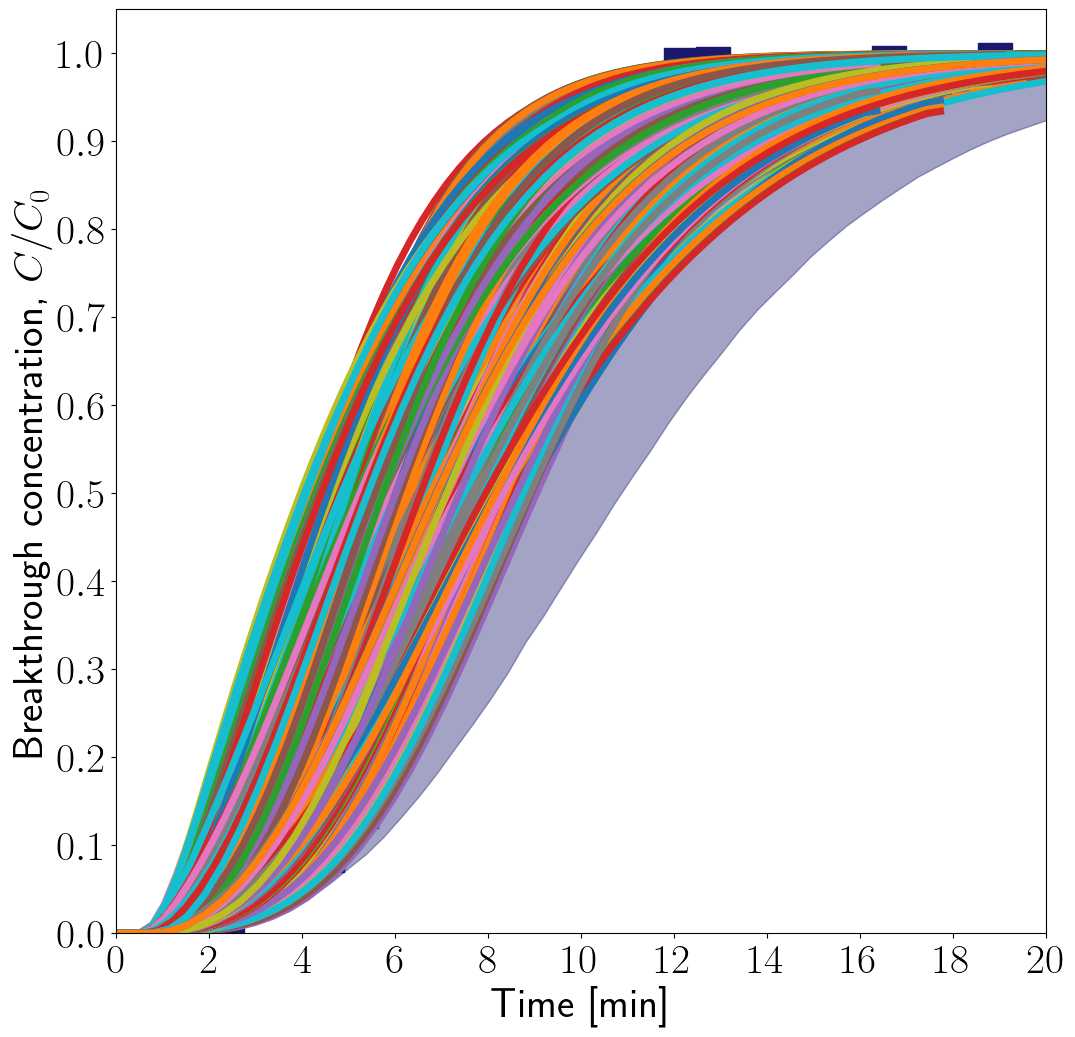

In [125]:
# Plot all simulations
# N = 2**3
dt = 0.10
Np = 5
tmax = 6.25

data = pd.read_csv("data.csv")

texp = data['Bed volumes']
Cexp = data['C/C0']

size = 12
fig2, ax2 = plt.subplots(figsize=(size,size))

plt.rcParams['text.usetex'] = True


# Plot model
pars = pd.read_csv(f"sampling_N-{N:d}_Np-{Np:d}.csv")
sims = pd.read_csv(f"simulations_N-{N:d}_dt-{dt:.2f}_Np-{Np:d}.csv")
time = pd.read_csv(f"times_N-{N:d}_dt-{dt:.2f}_Np-{Np:d}.csv")

T = np.zeros((pars.shape[0], int(np.ceil(tmax/dt) + 1)))

for i in range(sims.shape[0]):
    # D = pars.loc[i]['D']
    # L = pars.loc[i]['L']
    # Q = pars.loc[i]['Q']
    C0 = pars.loc[i]['C0']
    e = pars.loc[i]['e']
    # rho_p = pars.loc[i]['rho_p'] 
    rp = pars.loc[i]['rp']
    qmax = pars.loc[i]['qmax']
    Kl = pars.loc[i]['Kl']
    # Dp = pars.loc[i]['Dp']
    
    A = np.pi/4*D**2
    V = A*L
    u = Q/(A*e)
    tau = L/u

    t = np.linspace(0, tmax, int(np.ceil(tmax/dt) + 1)) * tau/60    # minutes   → BV  * Q/e/(V*e) 
    
    T[i, :] = t
    
    C = sims.loc[i]["0":]

    ax2.plot(t, C, linewidth=5)
    

# Plot data
Q = 1.5e-8
V = 8e-6
e = 0.37
texp = texp/(Q/e)*(V*e)/60   # minutes

ax2.scatter(texp, Cexp, s=600, color='midnightblue', marker='s', label='experimental data')

# Plot interval
prediction_interval = 95
C = sims.iloc[:,1:]
ax2.fill_between(t,
                 np.percentile(C, 50 - prediction_interval/2., axis=0),
                 np.percentile(C, 50 + prediction_interval/2., axis=0),
                 alpha=0.4, color='midnightblue',
                 label=f"{prediction_interval:d}\% prediction interval")

ax2.set_ylabel('Breakthrough concentration, $C/C_0$',fontsize=30)
ax2.set_yticks(np.linspace(0, 1, 11))
ax2.tick_params(labelsize=30)
ax2.set_ylim(0, 1.05)
# ax2.legend(fontsize=30)

# Time in bed volumes
# ax2.set_xlabel('Bed volumes',fontsize=30)
# ax2.set_xticks(np.linspace(0, 16, 9))
# ax2.set_xlim(0, 16)

# Time in minutes
ax2.set_xlim(0, 20)
ax2.set_xticks(np.linspace(0, 20, 11))
ax2.set_xlabel('Time [min]', fontsize=30)


In [14]:
C

,0,1,2,3,4,5,6,7,8,9,...,54,55,56,57,58,59,60,61,62,63
0,0.000001,0.000001,0.001021,0.016628,0.063030,0.134028,0.214540,0.293087,0.363738,0.424499,...,0.913368,0.916437,0.919399,0.922257,0.925016,0.927678,0.930247,0.932726,0.935118,0.936282
1,0.000001,0.000001,0.001026,0.017812,0.070073,0.152526,0.247808,0.341654,0.426179,0.498395,...,0.902450,0.904592,0.906688,0.908738,0.910744,0.912706,0.914625,0.916502,0.918338,0.919241
2,0.000001,0.000001,0.000846,0.014910,0.058639,0.127243,0.206203,0.283957,0.354321,0.415090,...,0.914175,0.917295,0.920303,0.923203,0.925999,0.928695,0.931295,0.933800,0.936216,0.937391
3,0.000001,0.000001,0.000995,0.015720,0.058478,0.122881,0.195288,0.265769,0.329407,0.384684,...,0.924808,0.928053,0.931160,0.934136,0.936985,0.939713,0.942325,0.944825,0.947218,0.948377
4,0.000001,0.000001,0.000983,0.015802,0.059301,0.125170,0.199293,0.271233,0.335765,0.391262,...,0.894457,0.898078,0.901577,0.904959,0.908227,0.911385,0.914437,0.917386,0.920235,0.921623
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5627,0.000001,0.000001,0.000011,0.001407,0.015200,0.058182,0.133420,0.229726,0.332369,0.430064,...,0.993159,0.993725,0.994244,0.994720,0.995157,0.995557,0.995925,0.996262,0.996572,0.996717
5628,0.000001,0.000002,0.001782,0.024952,0.088970,0.183620,0.289015,0.390576,0.480871,0.557428,...,0.934254,0.935638,0.936993,0.938320,0.939618,0.940889,0.942134,0.943352,0.944545,0.945132
5629,0.000001,0.000002,0.001858,0.026403,0.095146,0.197839,0.313049,0.424670,0.524292,0.608963,...,0.973658,0.974234,0.974798,0.975349,0.975887,0.976414,0.976930,0.977434,0.977927,0.978170
5630,0.000001,0.000002,0.001854,0.026330,0.094836,0.197131,0.311867,0.423017,0.522221,0.606550,...,0.974268,0.974884,0.975486,0.976073,0.976646,0.977205,0.977751,0.978283,0.978803,0.979058


In [126]:
C[C['0'] < 1e-6]

,0,1,2,3,4,5,6,7,8,9,...,54,55,56,57,58,59,60,61,62,63


### Sobol indices and regression coefficients

In [127]:
index = np.argmin(np.where(C>=0.1, np.arange(C.shape[0])[:, None], np.inf), axis=1)
print(index.shape)
index

tBT = T[np.arange(T.shape[0]), index]
tBT

(3072,)


array([3.17575741, 3.52861934, 3.08054857, ..., 2.68167995, 3.44787423,
       3.44787423])

First-order indices:
D : 0.268103068983492
L : 0.09061386635662493
Q : 0.046790099053316846
C_0 : 0.007570179082293117
e : 0.03274791796957462
rho_p : -0.00023890488747388454
rp : 0.23328697417723313
q_{max} : 0.014080768896413054
K_L : 0.0027203315590339783
D_p : 0.0005895501175308674

Second-order indices:
D - L : 0.0024940303650981682
D - Q : -0.009667549691655918
D - C_0 : -0.029537095086286397
D - e : -0.03755903227049425
D - rho_p : -0.029327294017950367
D - rp : 0.0024411707043346664
D - q_{max} : -0.007021568933544364
D - K_L : -0.02830482842317683
D - D_p : -0.02854871944501086
L - Q : 0.0389854837648072
L - C_0 : 0.03541850900792858
L - e : 0.0419990568258306
L - rho_p : 0.03209684035544742
L - rp : 0.027631697259784677
L - q_{max} : 0.03316430967593146
L - K_L : 0.034449188476112655
L - D_p : 0.03990220663164264
Q - C_0 : 0.030109420680098076
Q - e : 0.023663316023346398
Q - rho_p : 0.026289111272816683
Q - rp : 0.04806151690967689
Q - q_{max} : 0.025959045927622312
Q - K_L 

<Figure size 2000x600 with 0 Axes>

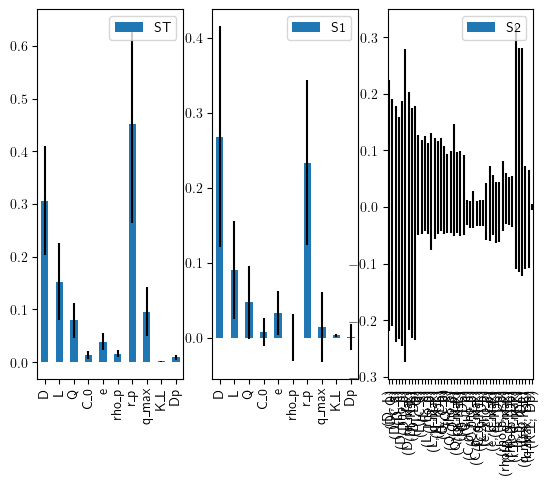

In [17]:
# Analyze Sobol indices
from SALib.sample import saltelli
from SALib.analyze import sobol
from SALib import ProblemSpec

# tmax = 6

Np = 10

sp = ProblemSpec({
    'num_vars': Np,
    'names': ['D', 'L', 'Q', 'C_0', 'e', 'rho_p', 'r_p', 'q_{max}', 'K_L', 'Dp'],
    'bounds': [[0.8 * 0.010,  1.2 * 0.010],
               [0.8 * 0.1,    1.2 * 0.1],
               [0.8 * 1.5e-8, 1.2 * 1.5e-8],
               [0.8 * 20,     1.2 * 20],
               [0.8 * 0.37,   1.2 * 0.37],   # 0.3-0.44, 20%
               [0.8 * 389,    1.2 * 389],
               [3e-4, 12e-4], # 3-12e-4 m, 7.5e-4 m as average: [-40%, +60%]
               [0.8 * 0.123,  1.2 * 0.291],  # 20% extra
               [0.8 * 1.18,   1.2 * 3.71],   # 20% extra
               [0.8 * 5.3e-10,  1.2 * 5.3e-10]],  # 5.3e-10, 20% extra
    'outputs': ['Y']
})


Si = sobol.analyze(sp, tBT, print_to_console=False)

labels = ['D', 'L', 'Q', 'C_0', 'e', 'rho_p', 'rp', 'q_{max}', 'K_L', 'D_p'] # ['$D$', '$L$', '$Q$', '$C_0$', '$\epsilon$', '$\rho_p$', '$r_p$', '$q_{max}$', '$K_L$', '$D_p$']

# Print first-order indices
print("First-order indices:")
for i in range(0, len(labels)):
    print(labels[i],":", Si['S1'][i])

# Print second-order indices

print("\nSecond-order indices:")
for i in range(0,len(labels)):
    for j in range(i+1,len(labels)):
        print(labels[i],"-",labels[j],":", Si['S2'][i,j])

# Print total-order indices
print("\nTotal-order indices:")
for i in range(0, len(labels)):
    print(labels[i],":", Si['ST'][i])
    
# Sum of total indices
print(f"\nSum of total-order indices:\n{np.sum(Si['ST'])}\n")

# Export indices to Pandas
total_Si, first_Si, second_Si = Si.to_df()

# Plot indices
fig = plt.figure(figsize=(20, 6), constrained_layout=True)

Si.plot()
plt.rcParams['text.usetex'] = True
plt.show()

First-order indices:
D : 0.7368092797654331
L : 0.5018639331287109
Q : -0.1805531428981359
C_0 : 0.0
\varepsilon : -0.2838921627489895
r_p : -1.908323043589069
q_{max} : -1.942324846410245
K_L : 0.0

Second-order indices:
D - L : -2.1810837274510466
D - Q : -1.1617178919260989
D - C_0 : -1.35971865025623
D - \varepsilon : -1.3183619131951778
D - r_p : 3.70072957682854
D - q_{max} : -0.8788442978174651
D - K_L : -1.35971865025623
L - Q : -1.7011840712462531
L - C_0 : -1.9471279284984346
L - \varepsilon : -2.2065850788324
L - r_p : 7.755504023906983
L - q_{max} : -3.2485535528697023
L - K_L : -1.9471279284984346
Q - C_0 : 0.34967649721107136
Q - \varepsilon : 0.3292770470820624
Q - r_p : -1.0768645783106279
Q - q_{max} : 0.15674582091641653
Q - K_L : 0.34967649721107136
C_0 - \varepsilon : -1.0822774417807601
C_0 - r_p : 1.2606406791682556
C_0 - q_{max} : -3.697004658448538
C_0 - K_L : -0.5984763224380413
\varepsilon - r_p : 2.919981308378796
\varepsilon - q_{max} : -2.393943678779368
\v

<Figure size 2000x600 with 0 Axes>

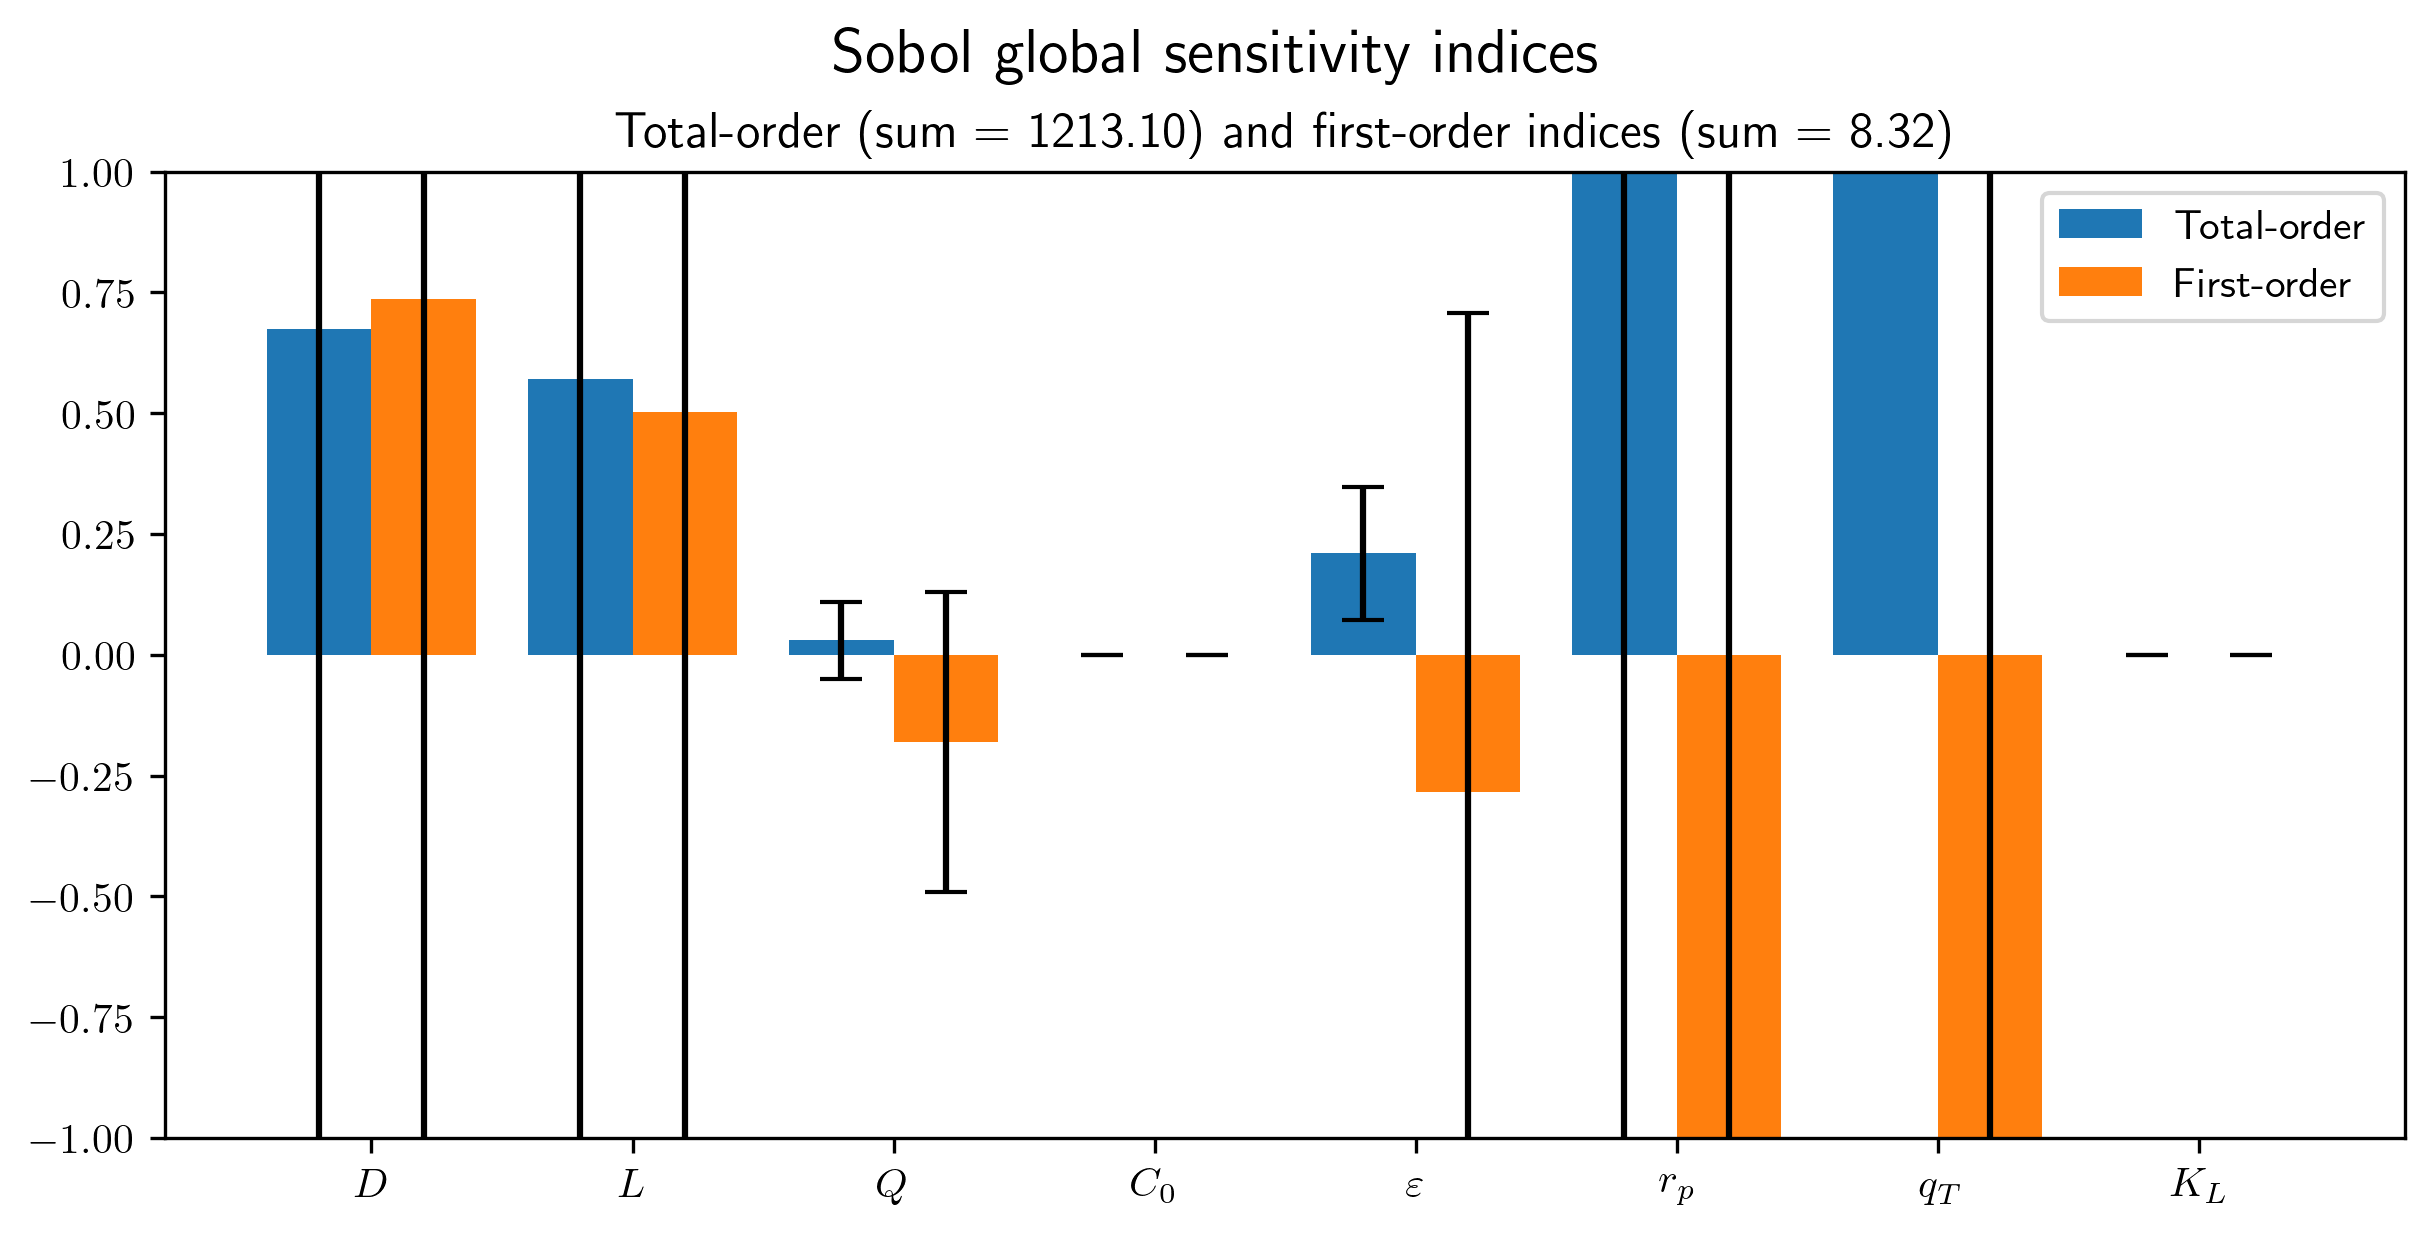

In [90]:
# Repeat analysis for 8 parameters
from SALib.sample import saltelli
from SALib.analyze import sobol
from SALib import ProblemSpec

# tmax = 6

Np = 8

sp = ProblemSpec({
    'num_vars': Np,
    'names': ['D', 'L', 'Q', 'C_0', 'e', 'r_p', 'q_{max}', 'K_L'],
    'bounds': [[0.8 * 0.010,  1.2 * 0.010],
               [0.8 * 0.1,    1.2 * 0.1],
               [0.8 * 1.5e-8, 1.2 * 1.5e-8],
               [0.8 * 20,     1.2 * 20],
               [0.8 * 0.37,   1.2 * 0.37],   # 0.3-0.44, 20%
               [3e-4, 12e-4], # 3-12e-4 m, 7.5e-4 m as average: [-40%, +60%]
               [0.8 * 0.123,  1.2 * 0.291],  # 20% extra
               [0.8 * 1.18,   1.2 * 3.71]],   # 20% extra
    'outputs': ['Y']
})


Si = sobol.analyze(sp, tBT, print_to_console=False)

labels = ['D', 'L', 'Q', 'C_0', '\\varepsilon', 'r_p', 'q_{max}', 'K_L'] # ['$D$', '$L$', '$Q$', '$C_0$', '$\epsilon$', '$\rho_p$', '$r_p$', '$q_{max}$', '$K_L$', '$D_p$']

# Print first-order indices
print("First-order indices:")
for i in range(0, len(labels)):
    print(labels[i],":", Si['S1'][i])

# Print second-order indices

print("\nSecond-order indices:")
for i in range(0,len(labels)):
    for j in range(i+1,len(labels)):
        print(labels[i],"-",labels[j],":", Si['S2'][i,j])

# Print total-order indices
print("\nTotal-order indices:")
for i in range(0, len(labels)):
    print(labels[i],":", Si['ST'][i])
    
# Sum of total indices
print(f"\nSum of total-order indices:\n{np.sum(Si['ST'])}\n")

# Export indices to Pandas
total_Si, first_Si, second_Si = Si.to_df()

# Plot indices
fig = plt.figure(figsize=(20, 6), constrained_layout=True)

# Si.plot()
# plt.rcParams['text.usetex'] = True
# plt.show()

# Plot total-order indices and first-order indices
labels = ['$D$', '$L$', '$Q$', '$C_0$', '$\\varepsilon$', '$r_p$', '$q_{T}$', '$K_L$']
font = 10

fig, axs = plt.subplots(nrows=1, ncols=1, figsize=(8,4), constrained_layout=True)

plt.rcParams['text.usetex'] = True

gs = fig.add_gridspec(1, 1)
fig.set_dpi(300)
fig.suptitle("Sobol global sensitivity indices", fontsize=font+5)

# for ax in axs:
#     ax.remove()
axs.remove()

indices = {
    # 'Total': Si['ST'],
    'First': Si['S1'],
}

x = np.arange(len(labels))  # the label locations
width = 0.4  # the width of the bars
multiplier = 1

# Total-order indices
ax1 = fig.add_subplot(gs[0])
ax1.bar(labels, Si['ST'], width=width, yerr=Si['ST_conf'], capsize=5)
ax1.set_title(f"Total-order (sum = {np.sum(Si['ST']**2):.2f}) and first-order indices (sum = {np.sum(Si['S1']**2):.2f})")
ax1.tick_params(axis='x', labelsize=font)
ax1.tick_params(axis='y', labelsize=font)
ax1.set_ylim(-1, 1)
ax1.set_xticks(x + 0.5*width, labels)


# fig, ax = plt.subplots(layout='constrained')

for parameter, index in indices.items():
    offset = width * multiplier
    rects = ax1.bar(x + offset, index, width, yerr=Si['S1_conf'], capsize=5, label=labels)
    # ax1.bar_label(rects, padding=3)
    multiplier += 1

ax1.legend(['Total-order', 'First-order'], loc='upper right')

# Store figure
plt.savefig("sensitivity-global-"+str(N)+"_Np-"+str(len(labels))+".pdf", format="pdf", bbox_inches="tight")
plt.show()


First-order indices:
C_0 : 0.11768574219189148
\varepsilon : 0.029915327136778136
r_p : 0.3469035979147761
q_{max} : 0.5051234766168599
K_L : 0.0008402862141857876

Second-order indices:
C_0 - \varepsilon : -0.004021003511323812
C_0 - r_p : -0.012057860002958276
C_0 - q_{max} : 0.030449344256547772
C_0 - K_L : -0.003998433406957628
\varepsilon - r_p : -0.002963265441829954
\varepsilon - q_{max} : -0.005492876666798541
\varepsilon - K_L : -0.016428477863639976
r_p - q_{max} : -0.0009727342025779295
r_p - K_L : 0.0039202738839694985
q_{max} - K_L : -0.009254393169996806

Total-order indices:
C_0 : 0.15967967484590767
\varepsilon : 0.039885741589997706
r_p : 0.3705237727841514
q_{max} : 0.5508650790491793
K_L : 0.004199829453618994

Sum of total-order indices:
1.125154097722855



<Figure size 2000x600 with 0 Axes>

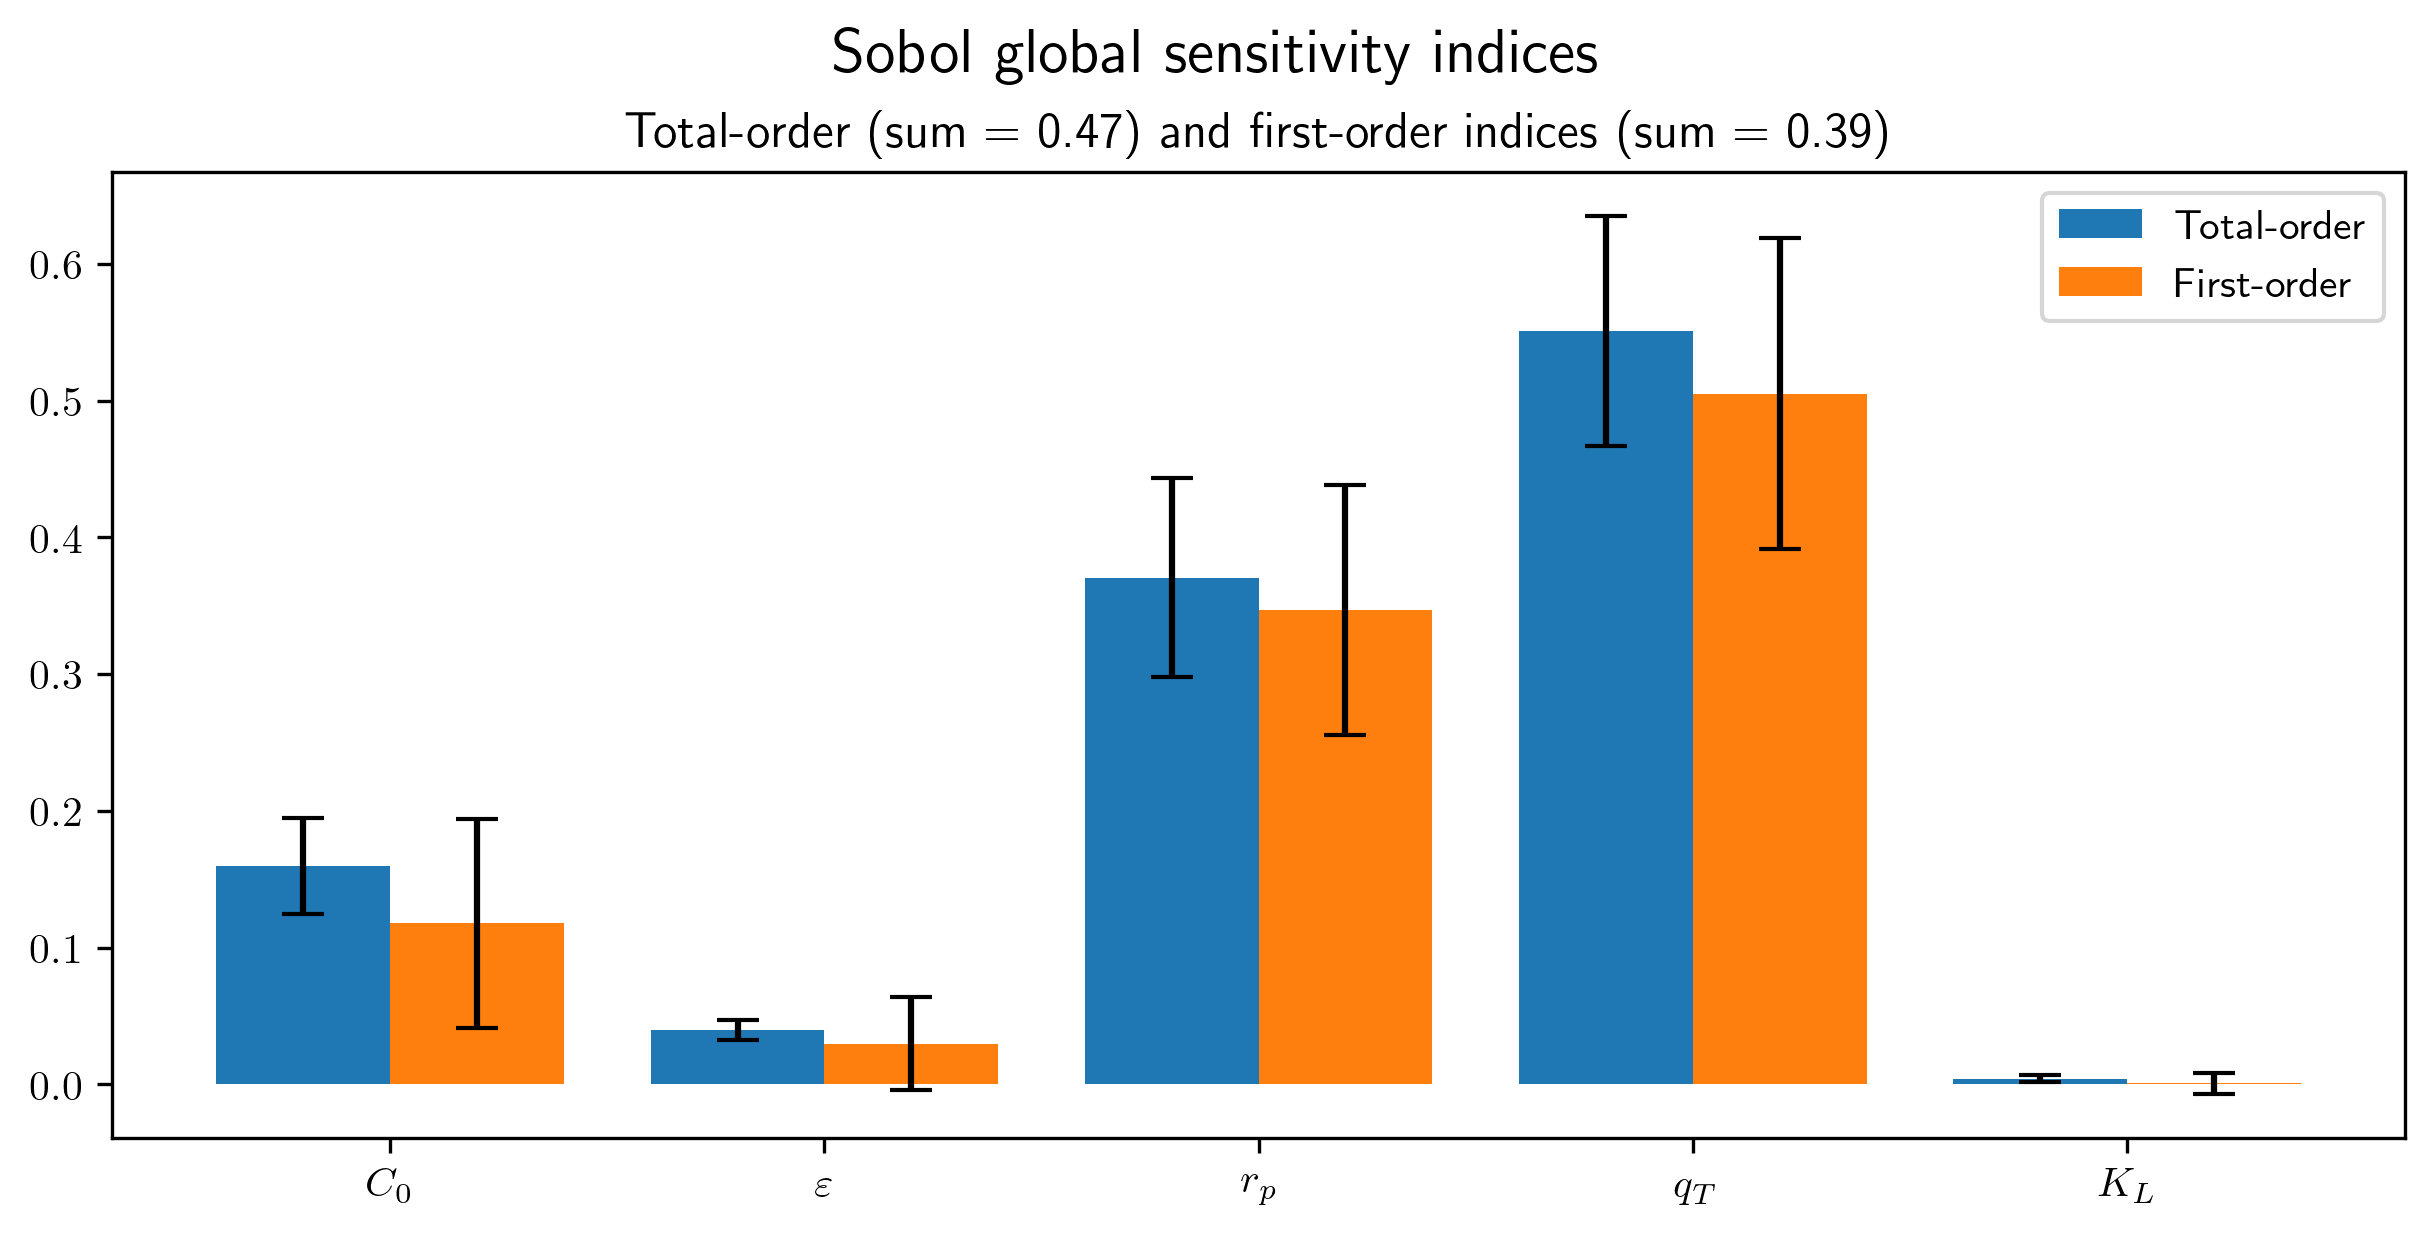

In [128]:
# Repeat analysis for 5 parameters
from SALib.sample import saltelli
from SALib.analyze import sobol
from SALib import ProblemSpec

# tmax = 6

# Np = 8

# sp = ProblemSpec({
#     'num_vars': Np,
#     'names': ['D', 'L', 'Q', 'C_0', 'e', 'r_p', 'q_{max}', 'K_L'],
#     'bounds': [[0.8 * 0.010,  1.2 * 0.010],
#                [0.8 * 0.1,    1.2 * 0.1],
#                [0.8 * 1.5e-8, 1.2 * 1.5e-8],
#                [0.8 * 20,     1.2 * 20],
#                [0.8 * 0.37,   1.2 * 0.37],   # 0.3-0.44, 20%
#                [3e-4, 12e-4], # 3-12e-4 m, 7.5e-4 m as average: [-40%, +60%]
#                [0.8 * 0.123,  1.2 * 0.291],  # 20% extra
#                [0.8 * 1.18,   1.2 * 3.71]],   # 20% extra
#     'outputs': ['Y']
# })


Si = sobol.analyze(sp, tBT, print_to_console=False)

labels = ['C_0', '\\varepsilon', 'r_p', 'q_{max}', 'K_L'] # ['$D$', '$L$', '$Q$', '$C_0$', '$\epsilon$', '$\rho_p$', '$r_p$', '$q_{max}$', '$K_L$', '$D_p$']

# Print first-order indices
print("First-order indices:")
for i in range(0, len(labels)):
    print(labels[i],":", Si['S1'][i])

# Print second-order indices

print("\nSecond-order indices:")
for i in range(0,len(labels)):
    for j in range(i+1,len(labels)):
        print(labels[i],"-",labels[j],":", Si['S2'][i,j])

# Print total-order indices
print("\nTotal-order indices:")
for i in range(0, len(labels)):
    print(labels[i],":", Si['ST'][i])
    
# Sum of total indices
print(f"\nSum of total-order indices:\n{np.sum(Si['ST'])}\n")

# Export indices to Pandas
total_Si, first_Si, second_Si = Si.to_df()

# Plot indices
fig = plt.figure(figsize=(20, 6), constrained_layout=True)

# Si.plot()
# plt.rcParams['text.usetex'] = True
# plt.show()

# Plot total-order indices and first-order indices
labels = ['$C_0$', '$\\varepsilon$', '$r_p$', '$q_{T}$', '$K_L$']
font = 10

fig, axs = plt.subplots(nrows=1, ncols=1, figsize=(8,4), constrained_layout=True)

plt.rcParams['text.usetex'] = True

gs = fig.add_gridspec(1, 1)
fig.set_dpi(300)
fig.suptitle("Sobol global sensitivity indices", fontsize=font+5)

# for ax in axs:
#     ax.remove()
axs.remove()

indices = {
    # 'Total': Si['ST'],
    'First': Si['S1'],
}

x = np.arange(len(labels))  # the label locations
width = 0.4  # the width of the bars
multiplier = 1

# Total-order indices
ax1 = fig.add_subplot(gs[0])
ax1.bar(labels, Si['ST'], width=width, yerr=Si['ST_conf'], capsize=5)
ax1.set_title(f"Total-order (sum = {np.sum(Si['ST']**2):.2f}) and first-order indices (sum = {np.sum(Si['S1']**2):.2f})")
ax1.tick_params(axis='x', labelsize=font)
ax1.tick_params(axis='y', labelsize=font)
# ax1.set_ylim(-1, 1)
ax1.set_xticks(x + 0.5*width, labels)


# fig, ax = plt.subplots(layout='constrained')

for parameter, index in indices.items():
    offset = width * multiplier
    rects = ax1.bar(x + offset, index, width, yerr=Si['S1_conf'], capsize=5, label=labels)
    # ax1.bar_label(rects, padding=3)
    multiplier += 1

ax1.legend(['Total-order', 'First-order'], loc='upper right')

# Store figure
plt.savefig("sensitivity-global-"+str(N)+"_Np-"+str(len(labels))+".pdf", format="pdf", bbox_inches="tight")
plt.show()


In [18]:
Si

{'S1': array([ 2.68103069e-01,  9.06138664e-02,  4.67900991e-02,  7.57017908e-03,
         3.27479180e-02, -2.38904887e-04,  2.33286974e-01,  1.40807689e-02,
         2.72033156e-03,  5.89550118e-04]),
 'S1_conf': array([0.14749203, 0.06550291, 0.04812935, 0.01842438, 0.02978784,
        0.03122097, 0.11029776, 0.04700032, 0.00264459, 0.01711276]),
 'ST': array([0.30602243, 0.15287103, 0.07910698, 0.01398413, 0.03901001,
        0.01578447, 0.45078305, 0.09532556, 0.00127037, 0.00894911]),
 'ST_conf': array([0.10353714, 0.07302951, 0.03377051, 0.00743852, 0.0160801 ,
        0.00671461, 0.18635983, 0.04639286, 0.00129384, 0.00507588]),
 'S2': array([[            nan,  2.49403037e-03, -9.66754969e-03,
         -2.95370951e-02, -3.75590323e-02, -2.93272940e-02,
          2.44117070e-03, -7.02156893e-03, -2.83048284e-02,
         -2.85487194e-02],
        [            nan,             nan,  3.89854838e-02,
          3.54185090e-02,  4.19990568e-02,  3.20968404e-02,
          2.76316973e-0

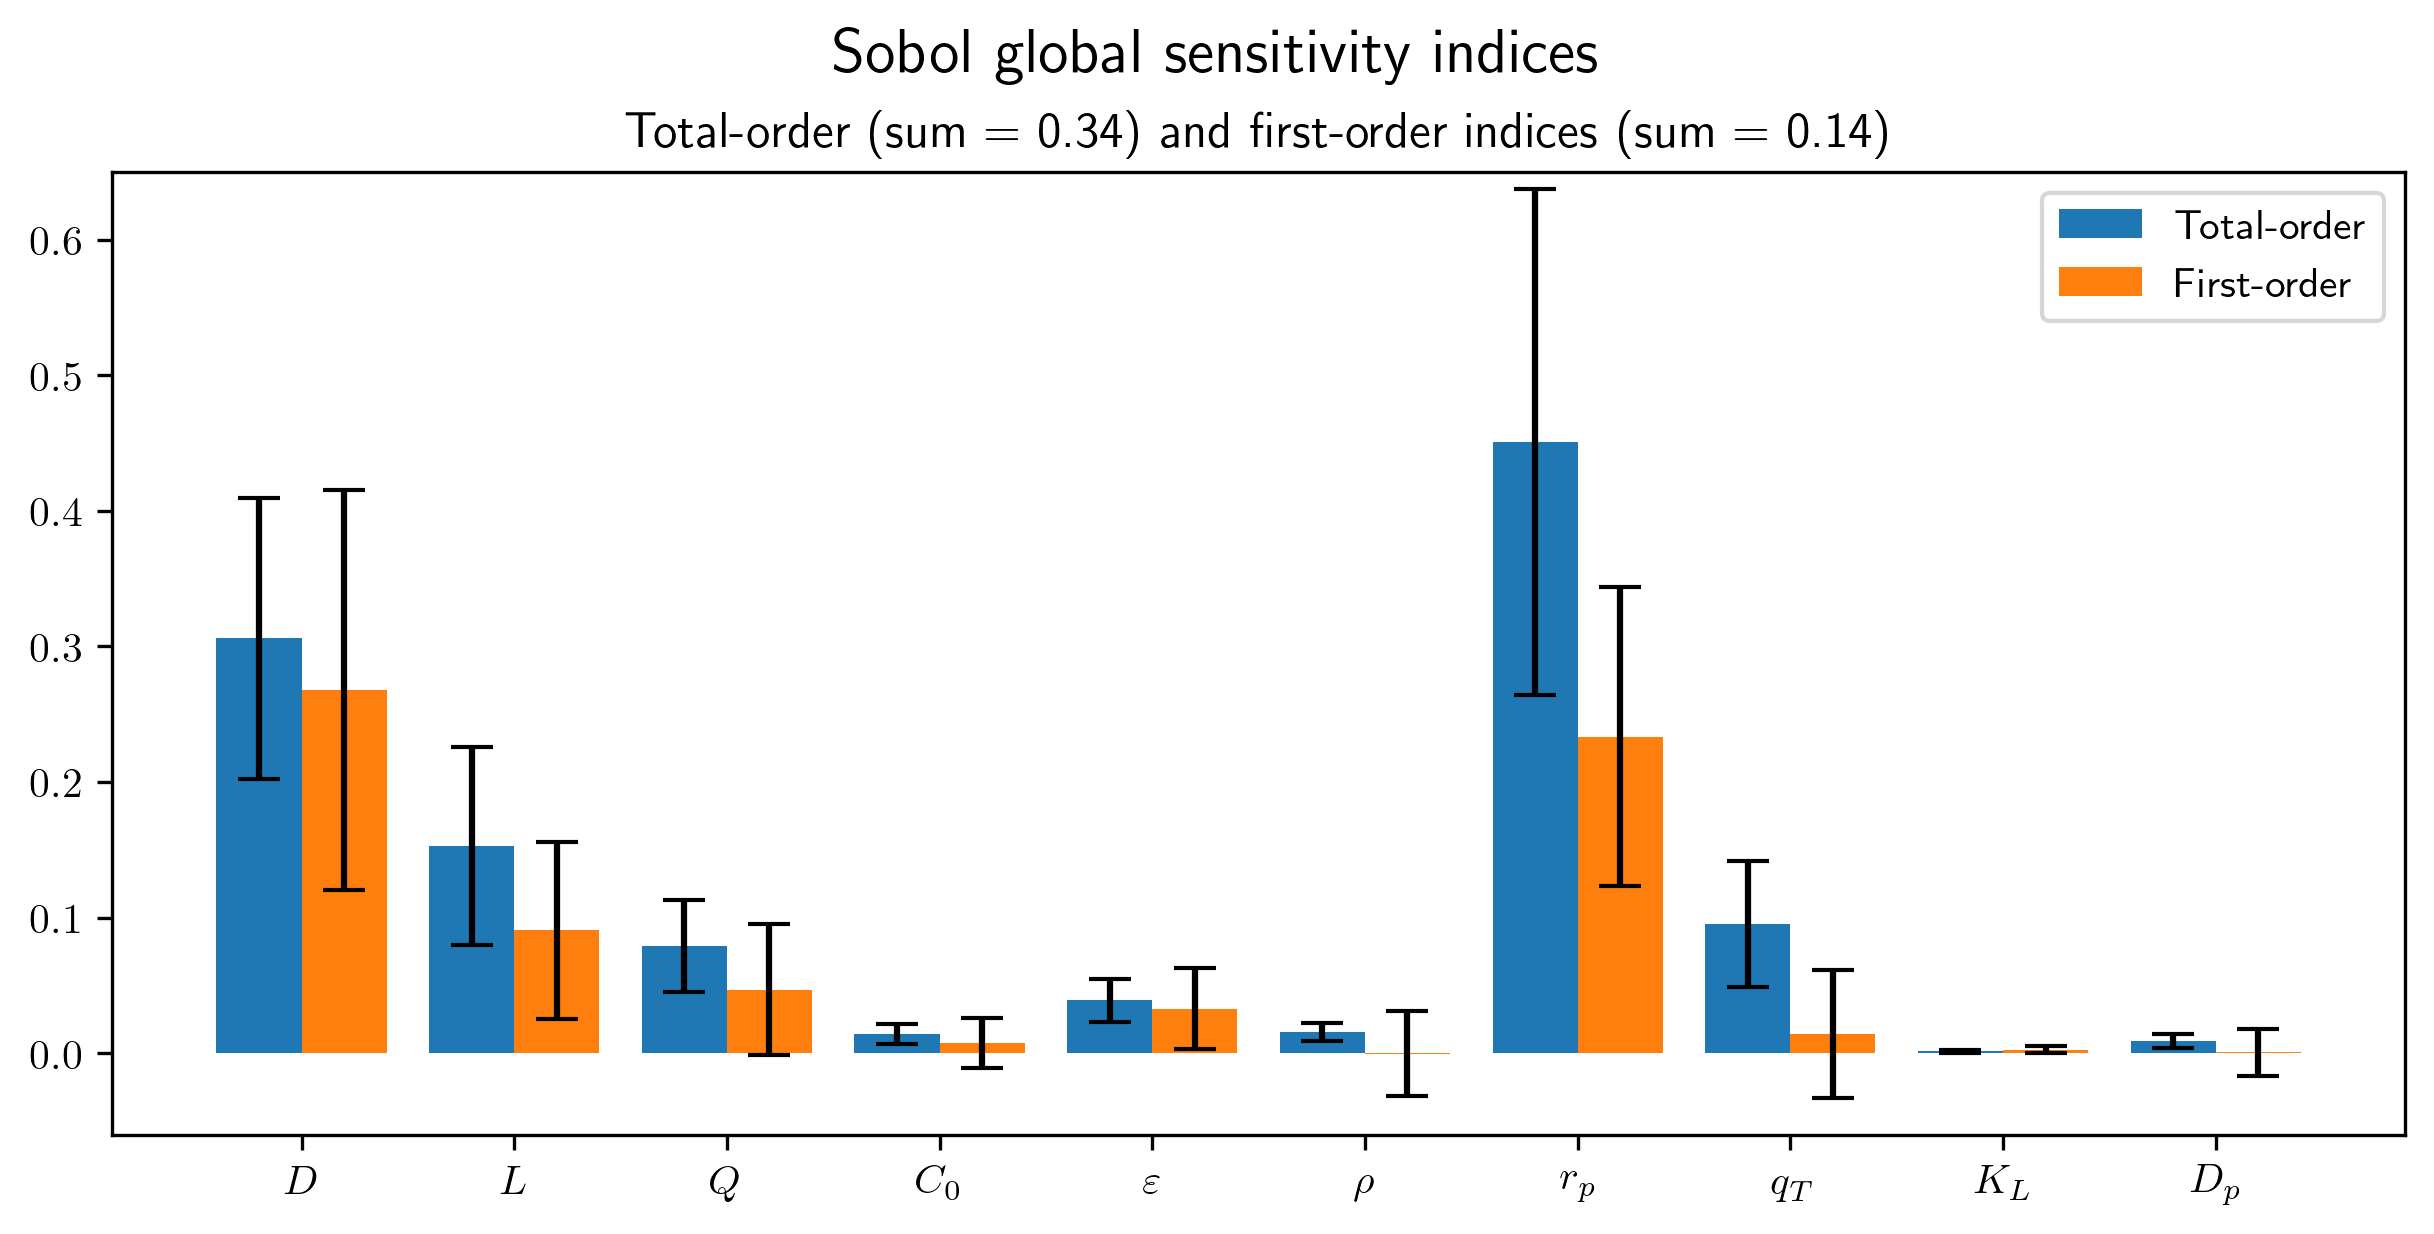

In [20]:
# Plot total-order indices and first-order indices
labels = ['$D$', '$L$', '$Q$', '$C_0$', '$\\varepsilon$', '$\\rho$', '$r_p$', '$q_{T}$', '$K_L$', '$D_p$']
font = 10

fig, axs = plt.subplots(nrows=1, ncols=1, figsize=(8,4), constrained_layout=True)

plt.rcParams['text.usetex'] = True

gs = fig.add_gridspec(1, 1)
fig.set_dpi(300)
fig.suptitle("Sobol global sensitivity indices", fontsize=font+5)

# for ax in axs:
#     ax.remove()
axs.remove()

indices = {
    # 'Total': Si['ST'],
    'First': Si['S1'],
}

x = np.arange(len(labels))  # the label locations
width = 0.4  # the width of the bars
multiplier = 1

# Total-order indices
ax1 = fig.add_subplot(gs[0])
ax1.bar(labels, Si['ST'], width=width, yerr=Si['ST_conf'], capsize=5)
ax1.set_title(f"Total-order (sum = {np.sum(Si['ST']**2):.2f}) and first-order indices (sum = {np.sum(Si['S1']**2):.2f})")
ax1.tick_params(axis='x', labelsize=font)
ax1.tick_params(axis='y', labelsize=font)
ax1.set_ylim(-0.06, 0.65)
ax1.set_xticks(x + 0.5*width, labels)


# fig, ax = plt.subplots(layout='constrained')

for parameter, index in indices.items():
    offset = width * multiplier
    rects = ax1.bar(x + offset, index, width, yerr=Si['S1_conf'], capsize=5, label=labels)
    # ax1.bar_label(rects, padding=3)
    multiplier += 1

ax1.legend(['Total-order', 'First-order'], loc='upper right')

# # # First-order indices
# ax2 = fig.add_subplot(gs[1])
# ax2.bar(labels, Si['S1'], yerr=Si['S1_conf'], capsize=5)
# ax2.set_title(f"First-order indices (sum = {np.sum(Si['S1']):.2f})")
# ax2.tick_params(axis='x', labelsize=font)
# ax2.tick_params(axis='y', labelsize=font)
# ax2.set_ylim(-0.06, 0.65)

# Store figure
plt.savefig("sensitivity-global-"+str(N)+"-"+str(len(labels))+"parameters.pdf", format="pdf", bbox_inches="tight")
plt.show()

In [27]:
Si['S2']

array([[            nan,  2.49403037e-03, -9.66754969e-03,
        -2.95370951e-02, -3.75590323e-02, -2.93272940e-02,
         2.44117070e-03, -7.02156893e-03, -2.83048284e-02,
        -2.85487194e-02],
       [            nan,             nan,  3.89854838e-02,
         3.54185090e-02,  4.19990568e-02,  3.20968404e-02,
         2.76316973e-02,  3.31643097e-02,  3.44491885e-02,
         3.99022066e-02],
       [            nan,             nan,             nan,
         3.01094207e-02,  2.36633160e-02,  2.62891113e-02,
         4.80615169e-02,  2.59590459e-02,  2.33515855e-02,
         2.18712857e-02],
       [            nan,             nan,             nan,
                    nan, -9.64737509e-03, -1.33635995e-02,
        -4.40197878e-03, -1.20372460e-02, -1.06261526e-02,
        -1.12839652e-02],
       [            nan,             nan,             nan,
                    nan,             nan, -7.96801136e-03,
         6.58185811e-03,  2.94553630e-03, -9.37726921e-03,
        -8.

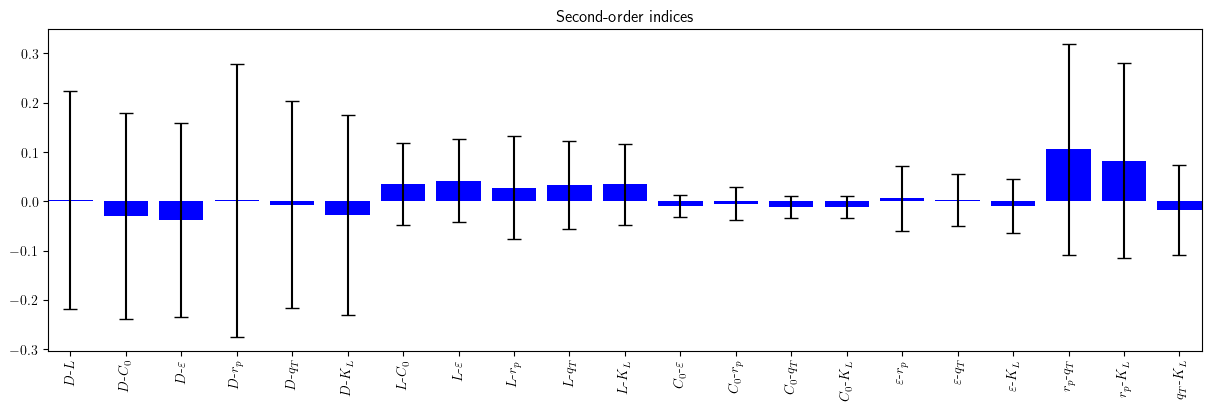

In [52]:
# Second order indices

labels = ['$D$', '$L$', '$Q$', '$C_0$', '$\\varepsilon$', '$\\rho$', '$r_p$', '$q_{T}$', '$K_L$', '$D_p$']

fig, ax = plt.subplots(figsize=(12,4), constrained_layout=True)

for i in range(0, len(labels)):
    for j in range(i+1, len(labels)):
        if (i != 2 and i != 5 and i != 9) and (j != 2 and j != 5 and j != 9):
            ax.bar(f"{labels[i]}-{labels[j]}", Si['S2'][i,j], yerr=Si['S2_conf'][i,j], capsize=5, color="blue")
ax.set_title('Second-order indices')
ax.tick_params(axis='x', labelsize=font, rotation=90)
ax.tick_params(axis='y', labelsize=font)
        
ax.autoscale(enable=True, axis='x', tight=True)

plt.rcParams['text.usetex'] = True

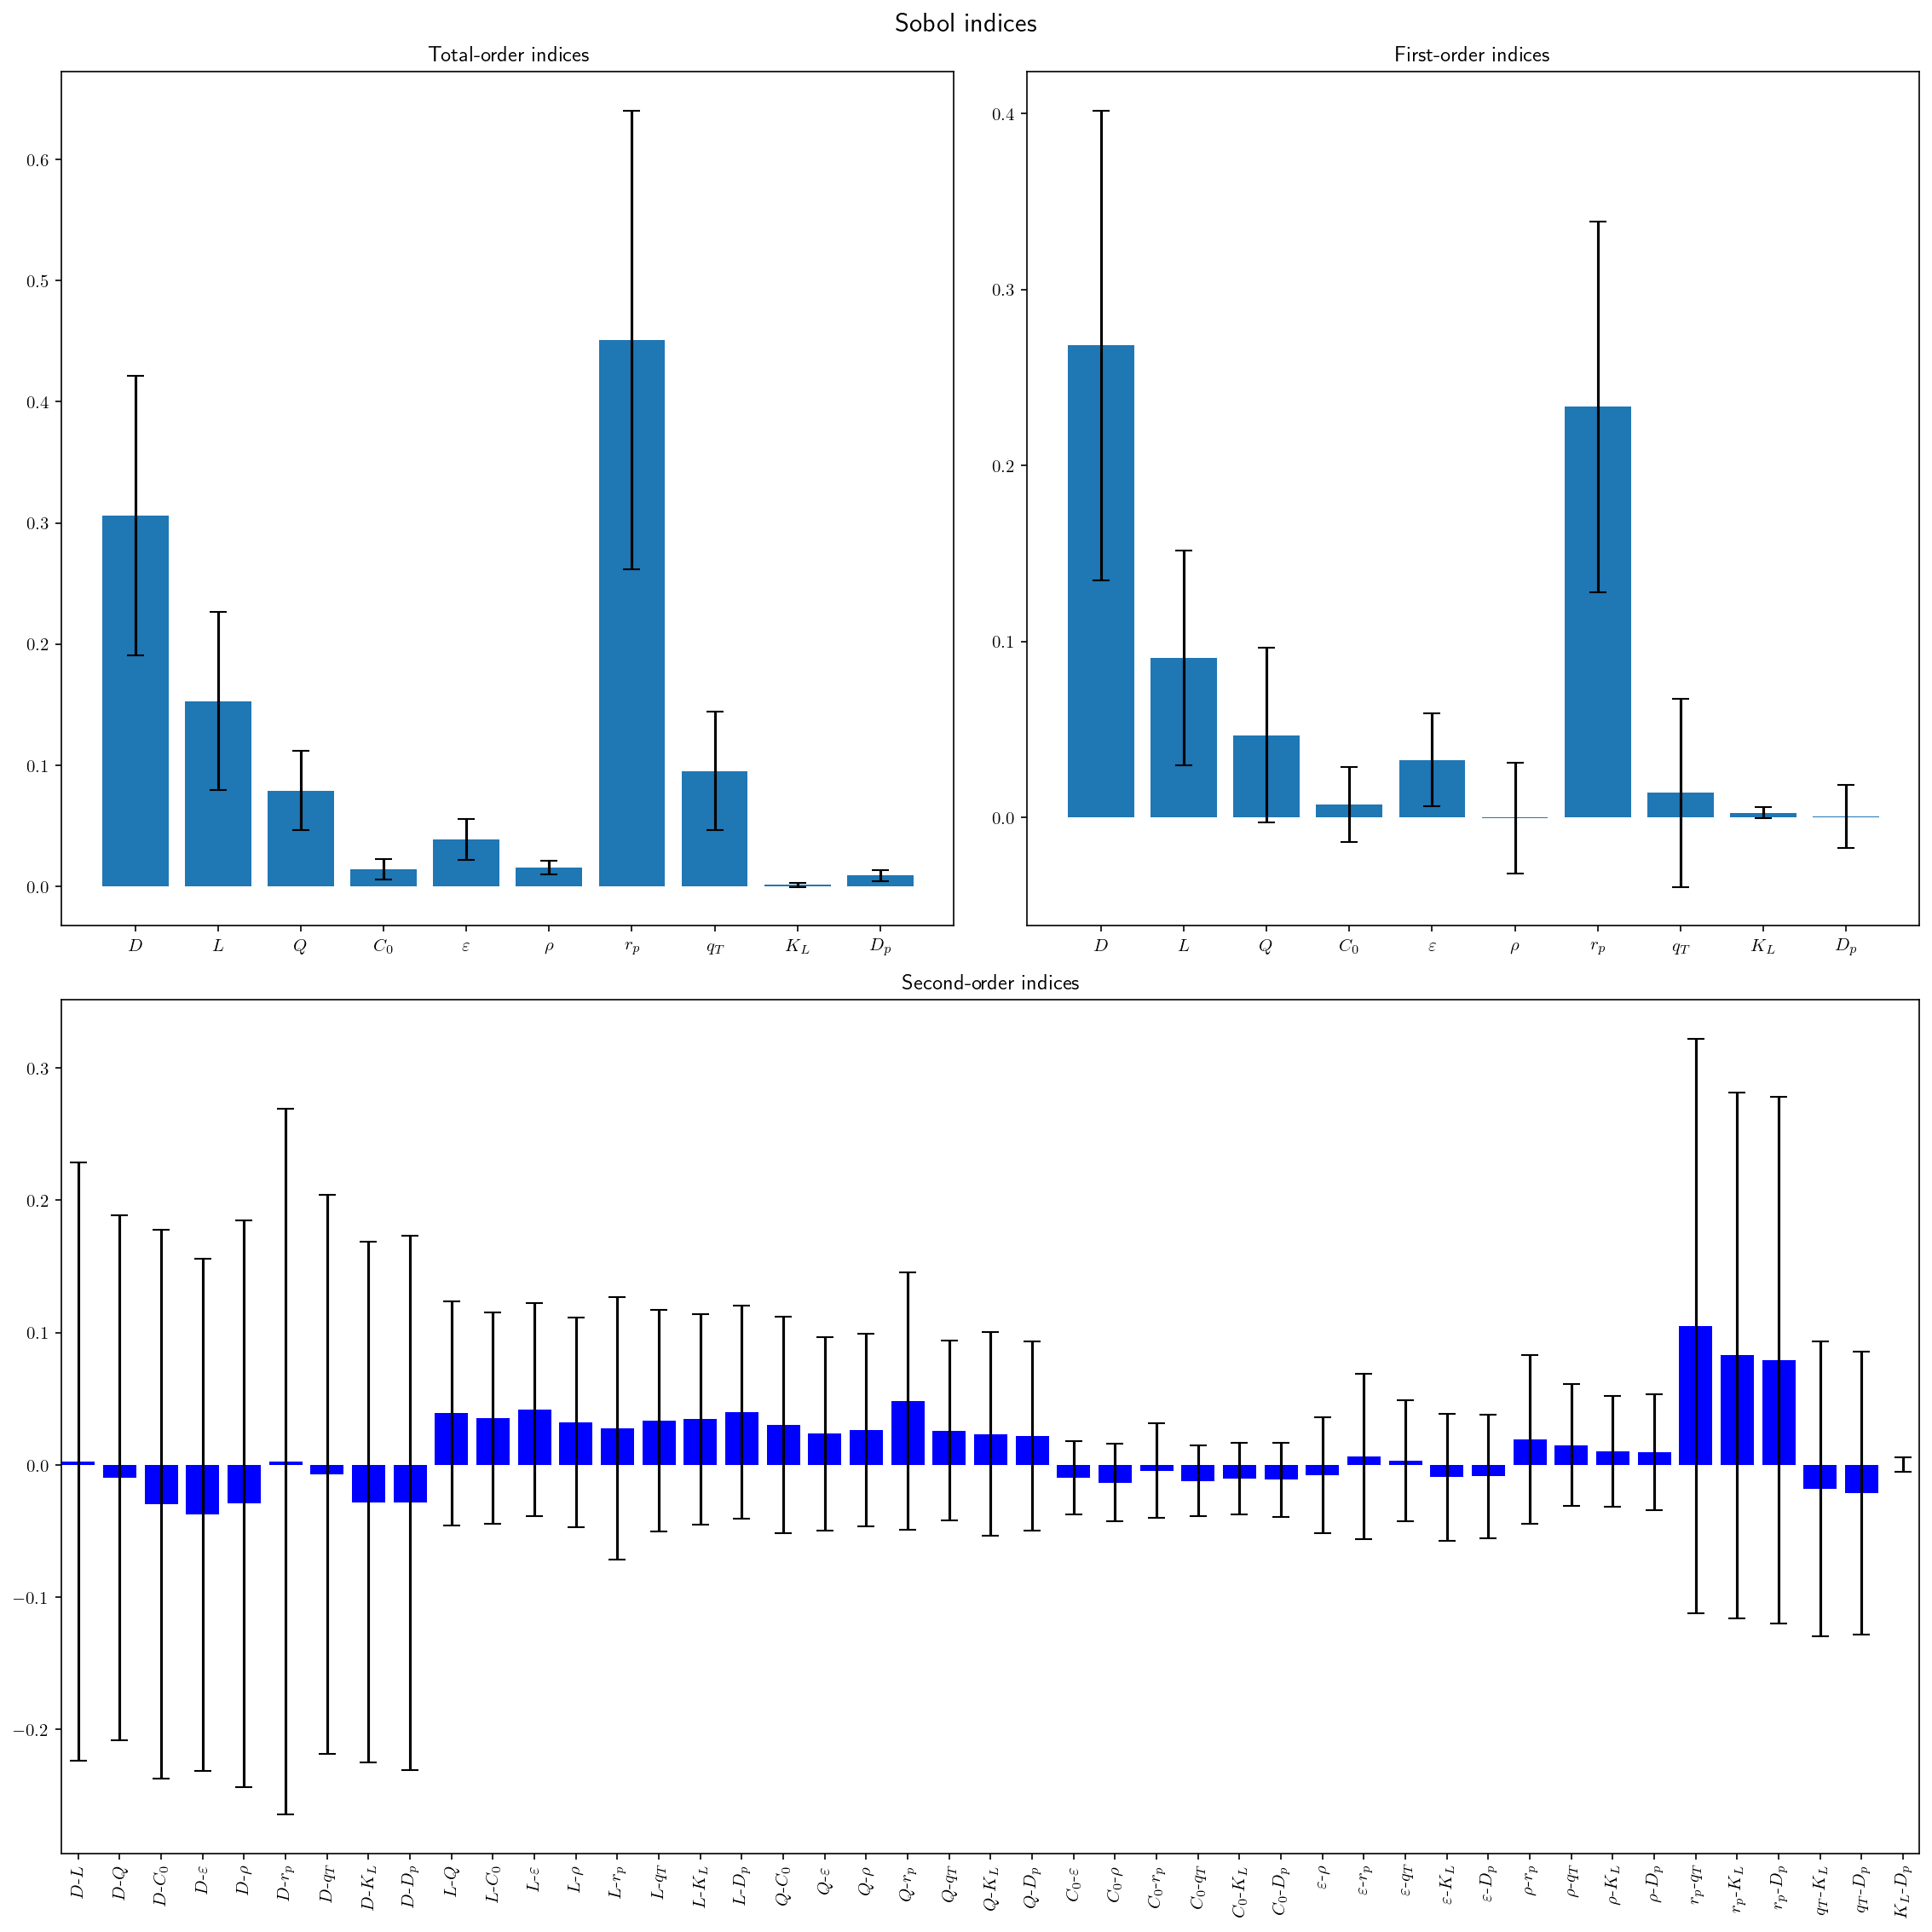

In [11]:
# Plot Sobol indices and confidence intervals
labels = ['$D$', '$L$', '$Q$', '$C_0$', '$\\varepsilon$', '$\\rho$', '$r_p$', '$q_{T}$', '$K_L$', '$D_p$']
font=10

fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(15,15), constrained_layout=True)
# fig.tight_layout()

gs = fig.add_gridspec(2, 2)
fig.set_dpi(150)
fig.suptitle("Sobol indices", fontsize=font+5)

for ax in axs[0,:]:
    ax.remove()
for ax in axs[1,:]:
    ax.remove()

# Total indices
ax1 = fig.add_subplot(gs[0, 0])
ax1.bar(labels, Si['ST'], yerr=Si['ST_conf'], capsize=5)
ax1.set_title('Total-order indices')
ax1.tick_params(axis='x', labelsize=font)
ax1.tick_params(axis='y', labelsize=font)

# # # First-order indices
ax2 = fig.add_subplot(gs[0, 1])
ax2.bar(labels, Si['S1'], yerr=Si['S1_conf'], capsize=5)
ax2.set_title('First-order indices')
ax2.tick_params(axis='x', labelsize=font)
ax2.tick_params(axis='y', labelsize=font)

# Second-order indices
labels = ['$D$', '$L$', '$Q$', '$C_0$', '$\\varepsilon$', '$\\rho$', '$r_p$', '$q_{T}$', '$K_L$', '$D_p$']

# gs = axs.get_gridspec()

ax3 = fig.add_subplot(gs[1, :])
for i in range(0, len(labels)):
    for j in range(i+1, len(labels)):
        ax3.bar(f"{labels[i]}-{labels[j]}", Si['S2'][i,j], yerr=Si['S2_conf'][i,j], capsize=5, color="blue")
ax3.set_title('Second-order indices')
ax3.tick_params(axis='x', labelsize=font, rotation=90)
ax3.tick_params(axis='y', labelsize=font)
        
ax3.autoscale(enable=True, axis='x', tight=True)

plt.rcParams['text.usetex'] = True

In [706]:
C.values
T.shape

(44, 64)

/Users/Daniel/opt/anaconda3/lib/python3.8/site-packages/SALib/analyze/sobol.py:204: UserWarning: Constant values encountered, indicating model evaluations (or subset of evaluations) produced identical values.
  warn(CONST_RESULT_MSG)
/Users/Daniel/opt/anaconda3/lib/python3.8/site-packages/SALib/analyze/sobol.py:217: UserWarning: Constant values encountered, indicating model evaluations (or subset of evaluations) produced identical values.
  warn(CONST_RESULT_MSG)
/Users/Daniel/opt/anaconda3/lib/python3.8/site-packages/SALib/analyze/sobol.py:227: UserWarning: Constant values encountered, indicating model evaluations (or subset of evaluations) produced identical values.
  warn(CONST_RESULT_MSG)
/Users/Daniel/opt/anaconda3/lib/python3.8/site-packages/numpy/core/_methods.py:264: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/Users/Daniel/opt/anaconda3/lib/python3.8/site-packages/numpy/core/_methods.py:256: RuntimeWarning: inva

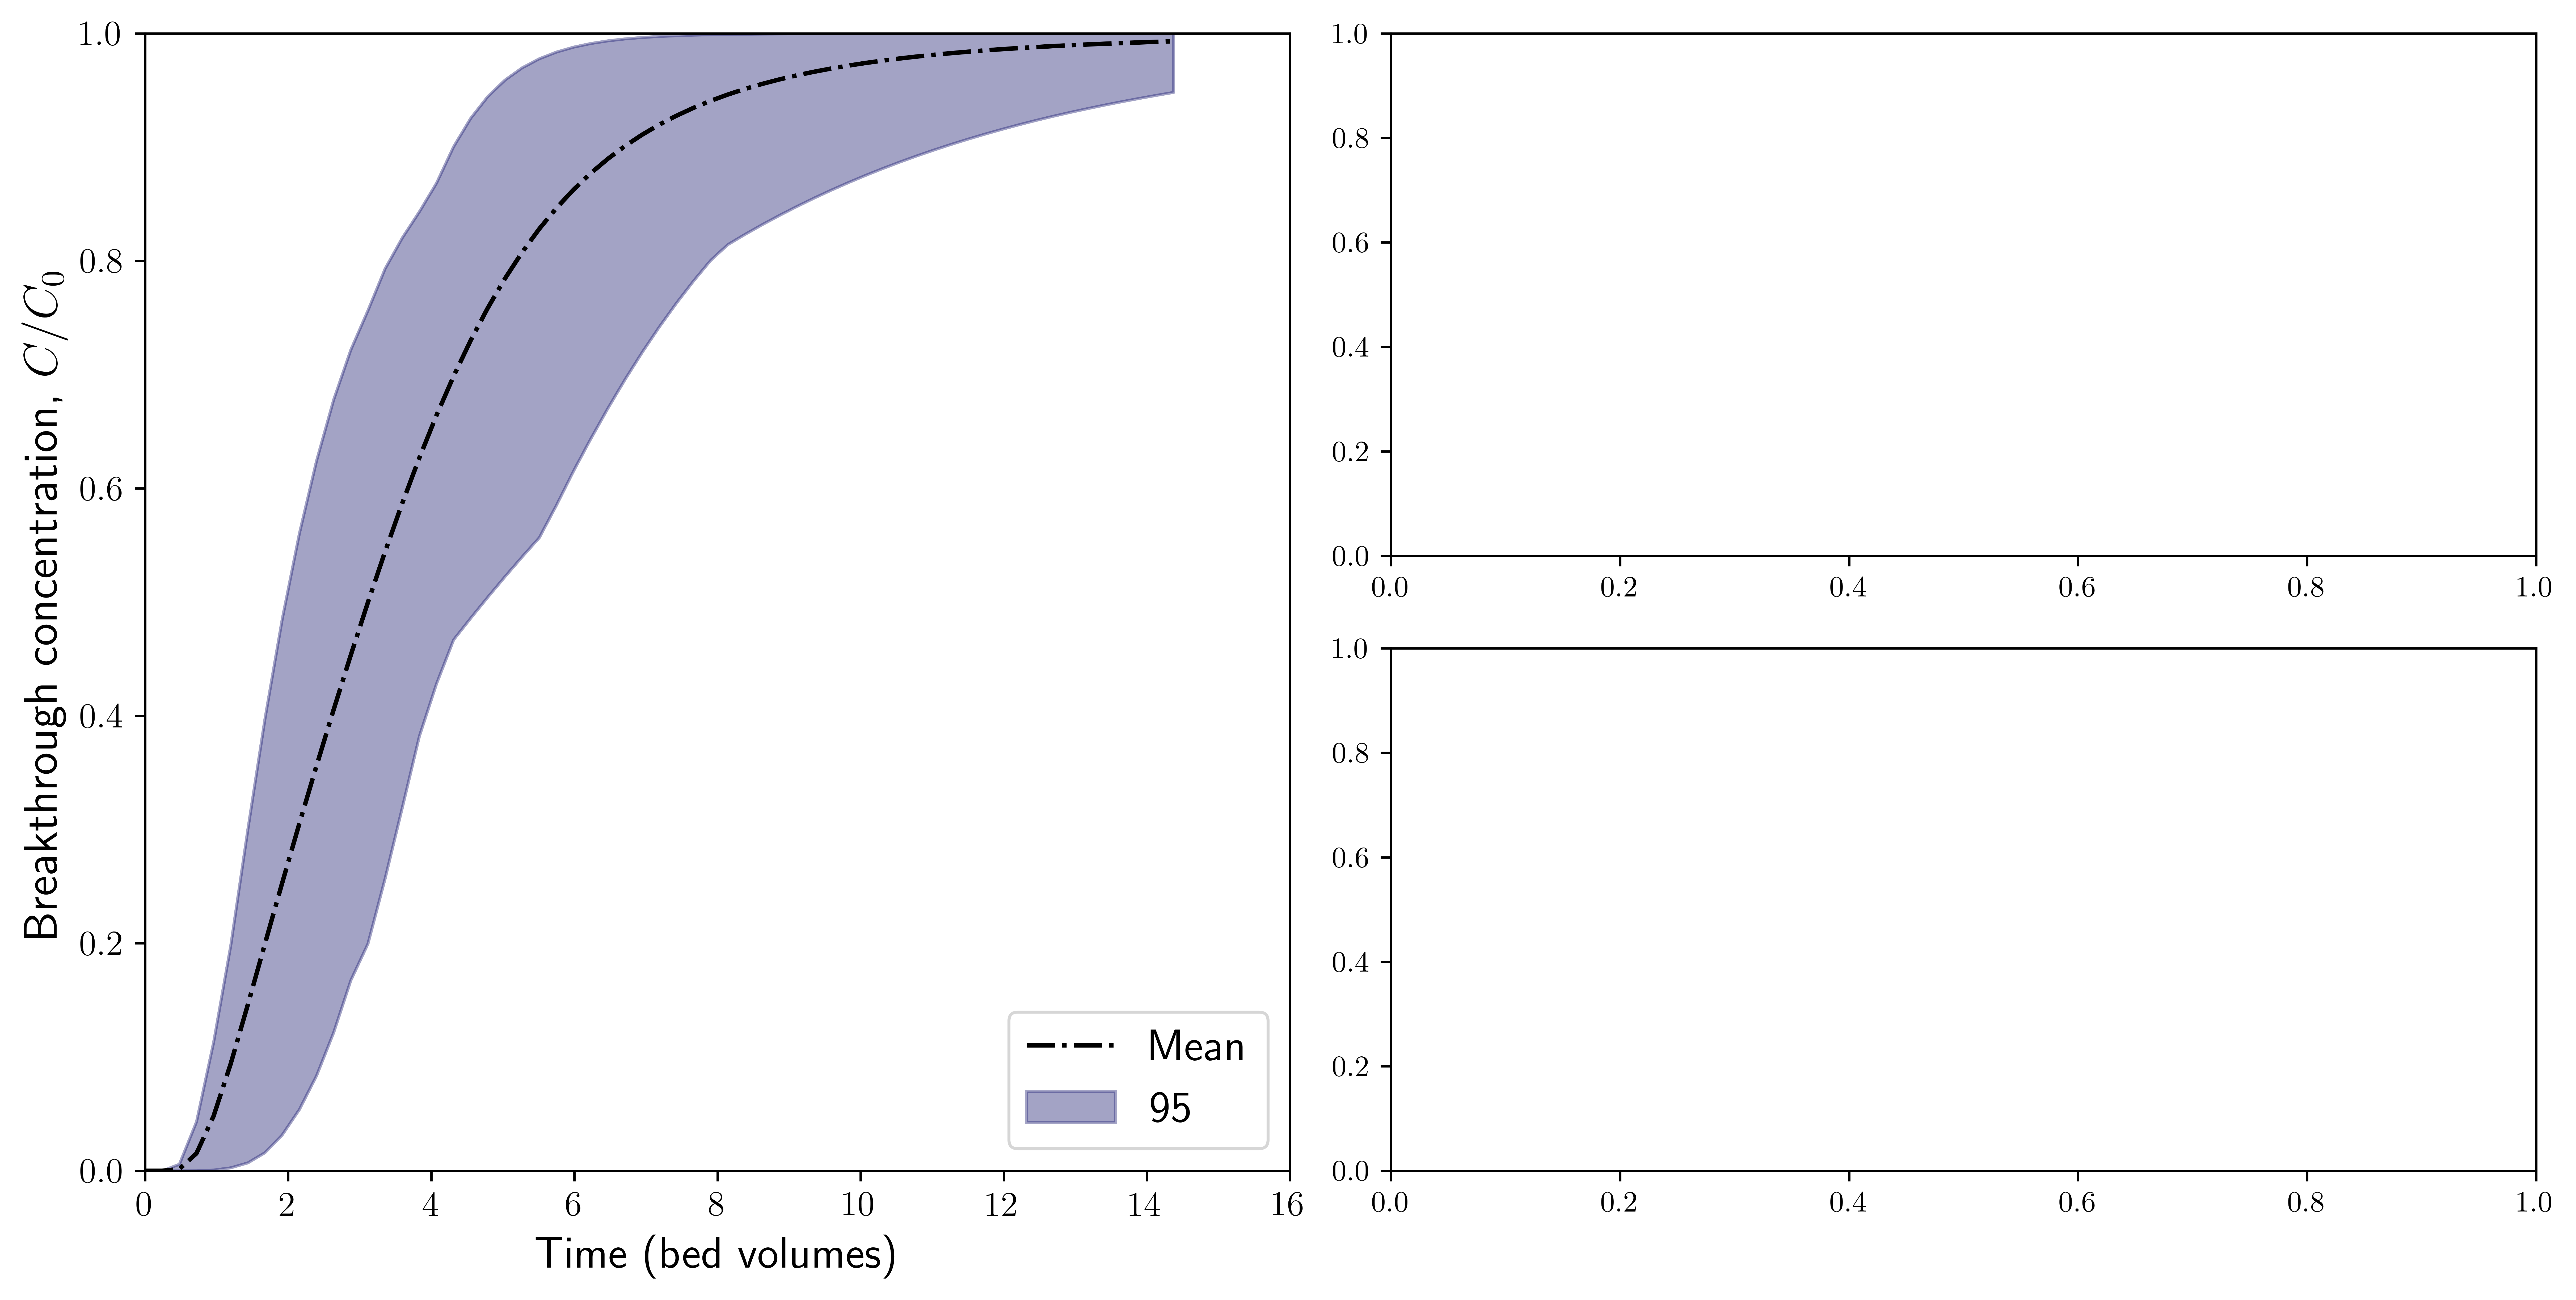

In [552]:
x = t
# Y = sims.iloc[:,1:]

Y = C.values
t = T[0]

sobol_indices = [sobol.analyze(sp, y) for y in Y.T]

S1s = np.array([s['S1'] for s in sobol_indices])

fig = plt.figure(figsize=(12, 6), constrained_layout=True)
gs = fig.add_gridspec(2, 2)
fig.set_dpi(800)

ax0 = fig.add_subplot(gs[:, 0])
ax1 = fig.add_subplot(gs[0, 1])
ax2 = fig.add_subplot(gs[1, 1])
# ax3 = fig.add_subplot(gs[2, 1])

# for i, ax in enumerate([ax1, ax2]):
#     ax.plot(t, S1s[:, i+6],
#             label=r'S1$ – \mathregular{{{}}}$'.format(sp["names"][i+6]),
#             color='darkblue')
#     ax.set_xlabel("Time (bed volumes)", size=15)
#     ax.set_ylabel(f"First-order Sobol index {sp['names'][i+6]:s}", size=15)
#     ax.tick_params(labelsize=12)
#     ax.set_xlim([0,16])

#     ax.yaxis.set_label_position("right")
#     ax.yaxis.tick_right()

#     ax.legend(loc='lower right', fontsize=15)

ax0.plot(t, np.mean(Y, axis=0), label="Mean", color='black', linestyle='-.')

# in percent
prediction_interval = 95

ax0.fill_between(t,
                 np.percentile(Y, 50 - prediction_interval/2., axis=0),
                 np.percentile(Y, 50 + prediction_interval/2., axis=0),
                 alpha=0.4, color='midnightblue',
                 label=f"{prediction_interval} % prediction interval")

ax0.set_xlabel("Time (bed volumes)", size=15)
ax0.set_ylabel(r'Breakthrough concentration, $C/C_0$', size=16)
ax0.set_xlim([0, 16])
ax0.set_ylim([0,1])
ax0.tick_params(labelsize=12)
# ax0.tick_params(labelsize=12)
ax0.legend(#title=r"Breakthrough model prediction",
           loc='lower right', fontsize=15)._legend_box.align = "left"

plt.show()


### First Sobol indices over time

In [705]:
# First indices over time
sp = ProblemSpec({
    'num_vars': Np,
    'names': ['D', 'L', 'Q', 'C_0', '\\varepsilon', '\\rho_p', 'r_p', 'q_{max}', 'K_L', 'D_p'],
    'bounds': [[0.8 * 0.010,  1.2 * 0.010],
               [0.8 * 0.1,    1.2 * 0.1],
               [0.8 * 1.5e-8, 1.2 * 1.5e-8],
               [0.8 * 20,     1.2 * 20],
               [0.8 * 0.37,   1.2 * 0.37],   # 0.3-0.444, 20% extra
               [0.8 * 389,    1.2 * 389],
               [0.4 * 7.5e-4, 1.6 * 7.5e-4], # 3-12e-4 m, 40% extra
               [0.8 * 0.123,  1.2 * 0.291],  # 20% extra
               [0.8 * 1.18,   1.2 * 3.71],   # 20% extra
               [0.8 * 1e-10,  1.2 * 1e-10]],
    'outputs': ['Y']
})

Y = C.values
# t = T[0]
# x = t

sobol_indices = [sobol.analyze(sp, y) for y in Y.T]

S1s = np.array([s['S1'] for s in sobol_indices])

In [709]:
fig = plt.figure(figsize=(12, 12), constrained_layout=True)
gs = fig.add_gridspec(5, 2)
fig.set_dpi(800)
fig.suptitle("First-order Sobol indices", fontsize=16)

# # ax0 = fig.add_subplot(gs[:, 0])
# ax1 = fig.add_subplot(gs[0, 1])
# ax2 = fig.add_subplot(gs[1, 1])

axes = []
for i in range(5):
    for j in range(2):
        ax = fig.add_subplot(gs[i, j])
        axes.append(ax)
        if i == 4:
            ax.set_xlabel("Time [min]", size=15)

Q = 1.5e-8
V = 8e-6
e = 0.37
tau = (V*e)/Q
t = np.linspace(0, tmax, int(np.ceil(tmax/dt) + 1)) * tau/60
            
for i, ax in enumerate(axes):
    ax.plot(t, S1s[:, i],
            label=f"${sp['names'][i]:s}$",
            color='darkblue')
        
    ax.set_ylabel(f"${sp['names'][i]:s}$", size=15, rotation=0, labelpad=15)
    ax.tick_params(labelsize=12)
    # ax.set_xlim([0,16])

    ax.yaxis.set_label_position("left")
    ax.yaxis.tick_left()

    # ax.legend(loc='lower right', fontsize=15)

In [639]:
fig, ax = plt.subplots(figsize=(12, 12), constrained_layout=True)
# gs = fig.add_gridspec(5, 2)
fig.set_dpi(800)
fig.suptitle("First-order Sobol indices", fontsize=16)

# # ax0 = fig.add_subplot(gs[:, 0])
# ax1 = fig.add_subplot(gs[0, 1])
# ax2 = fig.add_subplot(gs[1, 1])

# axes = []
# for i in range(5):
#     for j in range(2):
#         ax = fig.add_subplot(gs[i, j])
#         axes.append(ax)
#         if i == 4:
#             ax.set_xlabel("Time (bed volumes)", size=15)

for i in range(0, S1s.shape[1]):
    ax.plot(x, S1s[:, i], label=f"${sp['names'][i]:s}$", lw=5)
        
    # ax.set_ylabel(f"${sp['names'][i]:s}$", size=30, rotation=0, labelpad=15)
    ax.tick_params(labelsize=30)
    ax.set_xlim([0,16])

    ax.yaxis.set_label_position("left")
    ax.yaxis.tick_left()

    ax.legend(loc='lower right', fontsize=30)

### Regression coefficients

In [53]:
# Regression coefficients

# Compute breakthrough time as tBT where C >= 0.1
# time_case = t[index]

index = np.argmin(np.where(C>=0.1, np.arange(C.shape[0])[:, None], np.inf), axis=1)
# print(index.shape)

# Retrieve simulation and parameters values at the specified time
tBT = T[np.arange(T.shape[0]), index]
# print(tBT)

# Create array of variables b to be regressed (initialised to for examples ones for now)
b_init = np.ones(Np+1)

# Calculate Squared sum of errors between observed values and a linear regression of the parameters
#def SSE(b_init,thetas,ys):
#    return np.sum((ys - np.dot(thetas,b_init))**2)

# Perform a linear regression with a linear combination of the parameters and a bias 
# We use sickit-learn library to perform the linear regression
from sklearn.linear_model import LinearRegression

# y = theta_0 * x_0 + theta_1 * x_1 + ... + b_0
reg = LinearRegression().fit(pars.iloc[:,1:], tBT)

print('Coefficients (b_i): ({}), \nIntercept (b_0): {:.4f}, \nR2: {:.4f}\n'.format(reg.coef_,reg.intercept_,reg.score(pars.iloc[:,1:], tBT)))

# Calculate the relative error to test the model predictive power
# Random point
# index_rand = 53
# error_pred = [100*(ys[index_rand]-reg.predict(np.array([params[index_rand,:]])))/ys[index_rand]][0][0]
# print('Error(%):{:.4f}'.format(error_pred))

# Calculate SRCs for every parameter:

# Calculate the output variable standard deviation
y_sigma = np.std(tBT)
print(f"Standard deviation of breakthrough time [min]:\n{y_sigma}\n")

# They should be close to the standard deviation defined previously from np.random.random(mean,std)
theta_sigma = np.std(pars.iloc[:,1:], axis=0)
print(f'Standard deviations:\n{theta_sigma}\n')

# print(f'sigma_y: {y_sigma:.4f}, sigma_Kf: {Kf_sigma:.4f}, sigma_nf: {nf_sigma:.4f}, sigma_Dz: {Dz_sigma:.4f}, sigma_Dp: {Dp_sigma:.4f}')

SRC = reg.coef_*np.std(pars.iloc[:,1:], axis=0)/y_sigma
print(f'SRCs:\n{SRC}\n')

# Check how close we are if the model would be linear (r2=1 which explaines all the variance in the model)
print(f'Sum of SRCs:\n{np.sum(SRC**2)}')


Coefficients (b_i): ([ 4.33791245e+02  3.14766457e+01 -1.50142524e+08 -2.26674721e-02
  4.43528101e+00  6.29869950e-04 -1.95774743e+03  2.82778274e+00
  9.80449969e-03  5.24114432e+09]), 
Intercept (b_0): -4.4420, 
R2: 0.7470

Standard deviation of breakthrough time [min]:
1.0308793386581978

Standard deviations:
D        1.153854e-03
L        1.154699e-02
Q        1.732031e-09
C0       2.309401e+00
e        4.272392e-02
rho_p    4.491785e+01
rp       2.598076e-04
qmax     7.229442e-02
Kl       1.012671e+00
Dp       1.154688e-11
dtype: float64

SRCs:
D        0.485539
L        0.352573
Q       -0.252262
C0      -0.050780
e        0.183816
rho_p    0.027445
rp      -0.493402
qmax     0.198309
Kl       0.009631
Dp       0.058706
dtype: float64

Sum of SRCs:
0.7471232748480152


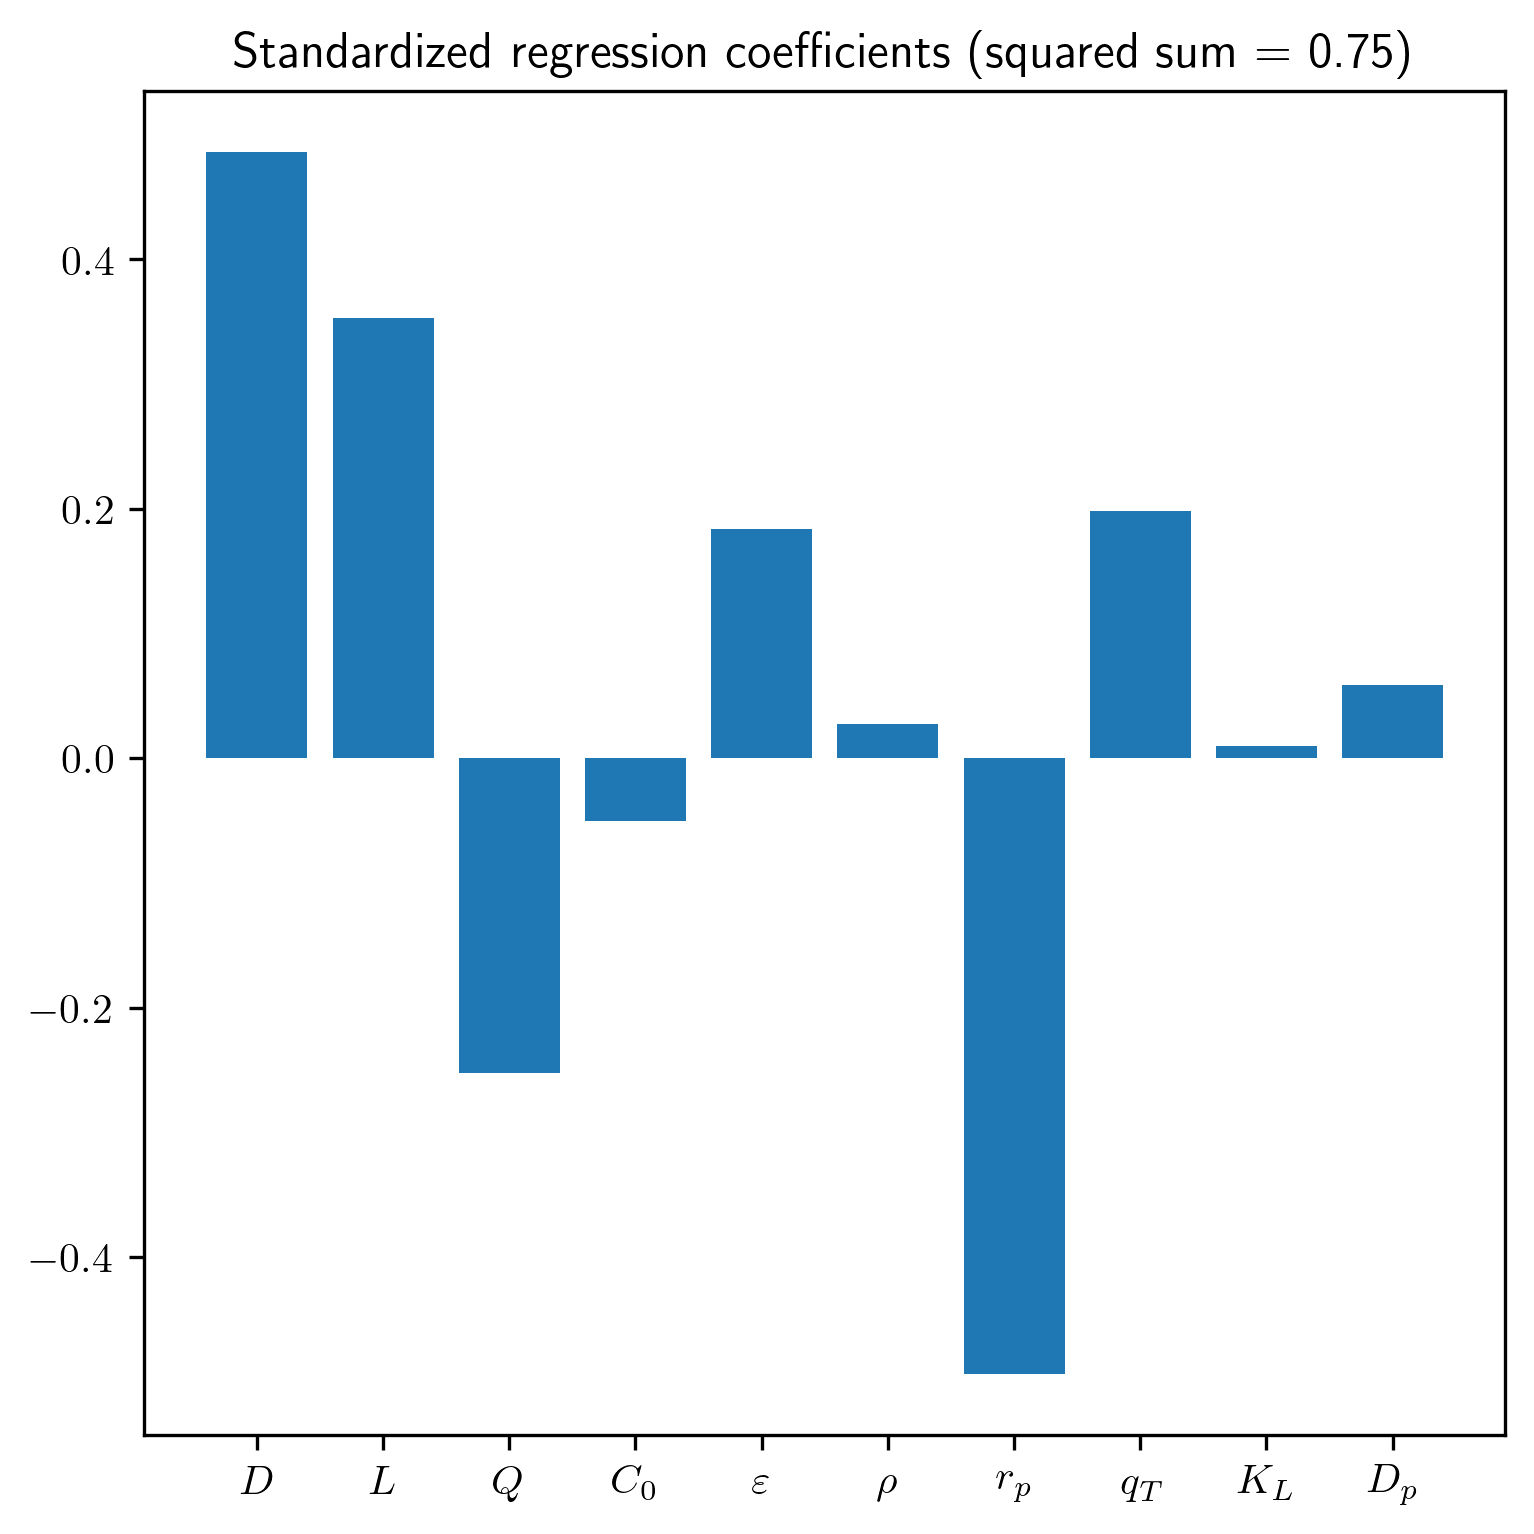

In [55]:
labels = ['$D$', '$L$', '$Q$', '$C_0$', '$\\varepsilon$', '$\\rho$', '$r_p$', '$q_{T}$', '$K_L$', '$D_p$']
font=10
plt.figure(figsize=(5,5), constrained_layout=True, dpi=300)
plt.bar(labels, SRC)
plt.title(f'Standardized regression coefficients (squared sum = {np.sum(SRC**2):.2f})')
plt.tick_params(axis='x', labelsize=font)
plt.tick_params(axis='y', labelsize=font)

In [726]:
pars.shape

(704, 11)

In [744]:
pars.iloc[:,1:].shape

(704, 10)

In [743]:
C.shape

(704, 64)

## Uncertainty analysis

Text(0.5, 0, 'Time [min]')

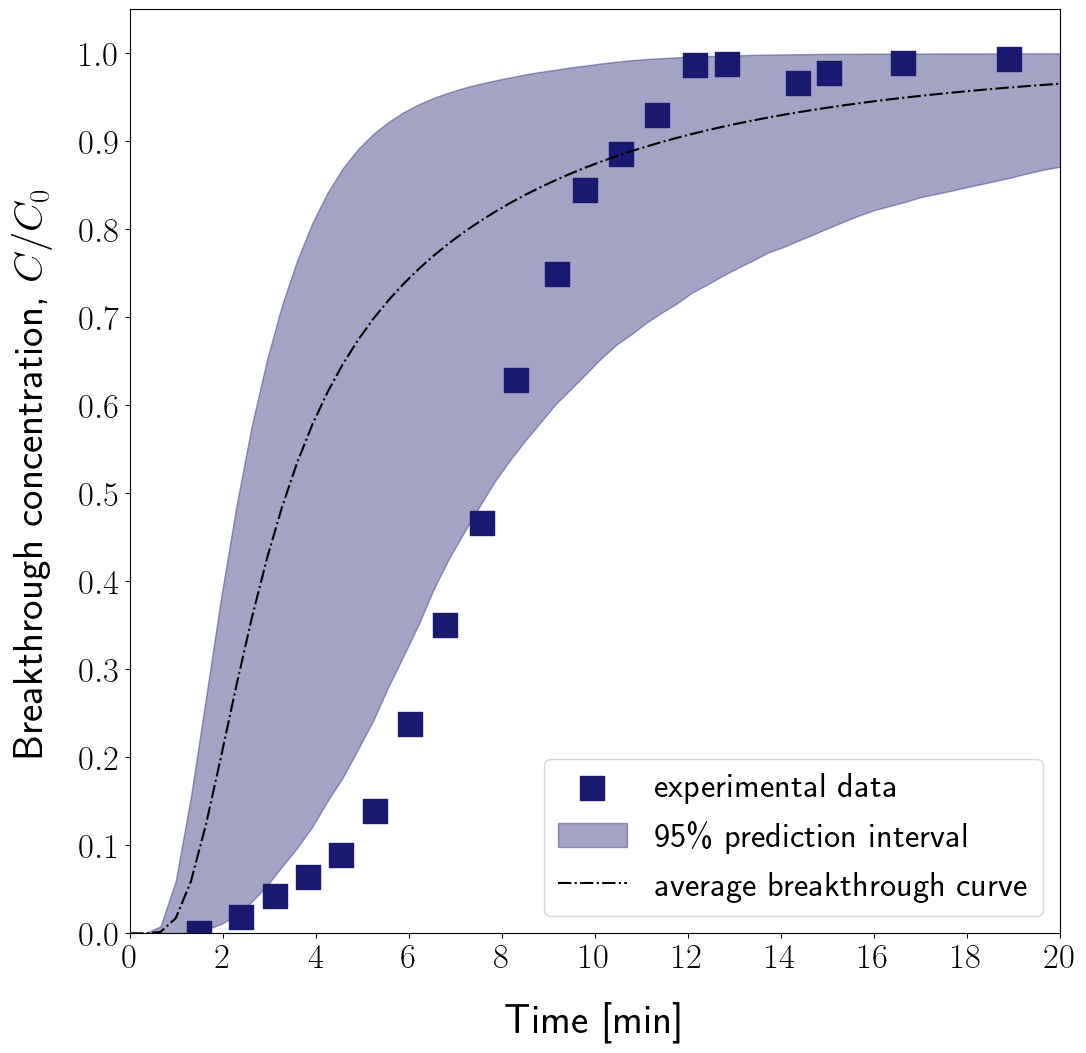

In [44]:
# Plot all simulations
data = pd.read_csv("data.csv")

texp = data['Bed volumes']
Cexp = data['C/C0']

size = 12
fig2, ax2 = plt.subplots(figsize=(size,size))

plt.rcParams['text.usetex'] = True


# Plot model
pars = pd.read_csv(f"sampling_N-{N:d}.csv")
sims = pd.read_csv(f"simulations_N-{N:d}_dt-{dt:.2f}_Np-{Np:d}.csv")
time = pd.read_csv(f"times_N-{N:d}_dt-{dt:.2f}.csv")

T = np.zeros((pars.shape[0], int(np.ceil(tmax/dt) + 1)))

for i in range(sims.shape[0]):
    D = pars.loc[i]['D']
    L = pars.loc[i]['L']
    Q = pars.loc[i]['Q']
    C0 = pars.loc[i]['C0']
    e = pars.loc[i]['e']
    rho_p = pars.loc[i]['rho_p'] 
    rp = pars.loc[i]['rp']
    qmax = pars.loc[i]['qmax']
    Kl = pars.loc[i]['Kl']
    Dp = pars.loc[i]['Dp']
    
    A = np.pi/4*D**2
    V = A*L
    u = Q/(A*e)
    tau = L/u

    t = np.linspace(0, tmax, int(np.ceil(tmax/dt) + 1)) * tau/60    # minutes   → BV  * Q/e/(V*e) 
    
    T[i, :] = t
    
    C = sims.loc[i]["0":]

    # ax2.plot(t, C, linewidth=5)
    

# Plot experimental data
Q = 1.5e-8
V = 8e-6
e = 0.37
texp = texp/(Q/e)*(V*e)/60   # minutes

ax2.scatter(texp, Cexp, s=300, color='midnightblue', marker='s', label='experimental data')

# Plot interval
prediction_interval = 95
C = sims.iloc[:,1:]
ax2.fill_between(t,
                 np.percentile(C, 50 - prediction_interval/2., axis=0),
                 np.percentile(C, 50 + prediction_interval/2., axis=0),
                 alpha=0.4, color='midnightblue',
                 label=f"{prediction_interval:d}\% prediction interval")

# Plot average
ax2.plot(t, np.mean(C, axis=0), label="average breakthrough curve", color='black', linestyle='-.')


ax2.set_ylabel('Breakthrough concentration, $C/C_0$',fontsize=30, labelpad=20)
ax2.set_yticks(np.linspace(0, 1, 11))
ax2.tick_params(labelsize=25)
ax2.set_ylim(0, 1.05)
ax2.legend(loc="lower right", fontsize=25)

# Time in bed volumes
# ax2.set_xlabel('Bed volumes',fontsize=30)
# ax2.set_xticks(np.linspace(0, 16, 9))
# ax2.set_xlim(0, 16)

# Time in minutes
ax2.set_xlim(0, 20)
ax2.set_xticks(np.linspace(0, 20, 11))
ax2.set_xlabel('Time [min]', fontsize=30, labelpad=20)


## Calibration

### Import data

In [9]:
# Import experimental data from Zhang et al. (2015) – first 6 experiments
data = pd.read_csv("expdata.csv")

texp1a = data['time 1a'].dropna().to_numpy()
Cexp1a = data['1a'].dropna().to_numpy()
texp2a = data['time 2a'].dropna().to_numpy()
Cexp2a = data['2a'].dropna().to_numpy()
texp3a = data['time 3a'].dropna().to_numpy()
Cexp3a = data['3a'].dropna().to_numpy()
texp1b = data['time 1b'].dropna().to_numpy()
Cexp1b = data['1b'].dropna().to_numpy()
texp2b = data['time 2b'].dropna().to_numpy()
Cexp2b = data['2b'].dropna().to_numpy()
texp3b = data['time 3b'].dropna().to_numpy()
Cexp3b = data['3b'].dropna().to_numpy()

texp_data = [texp1a, texp2a, texp3a, texp1b, texp2b, texp3b]
Cexp_data = [Cexp1a, Cexp2a, Cexp3a, Cexp1b, Cexp2b, Cexp3b]

# Validation data
data = pd.read_csv("valdata.csv")

tval = data['BV'].dropna().to_numpy()
Cval = data['C/C0'].dropna().to_numpy()


In [11]:
texp1a

array([ 1.2248394 ,  1.95717345,  2.56102784,  3.1391863 ,  3.73019272,
        4.33404711,  4.95074947,  5.56745182,  6.22269807,  6.8137045 ,
        7.54603854,  8.04710921,  8.67665953,  9.30620985,  9.97430407,
       10.5524625 , 11.7987152 , 12.3511777 , 13.6616702 , 15.5246253 ])

In [12]:
Cexp1a

array([8.7719000e-04, 1.8421050e-02, 4.2105260e-02, 6.4035090e-02,
       8.9473680e-02, 1.3859649e-01, 2.3771930e-01, 3.5087719e-01,
       4.6666667e-01, 6.2894737e-01, 7.4912281e-01, 8.4473684e-01,
       8.8508772e-01, 9.2982456e-01, 9.8684211e-01, 9.8771930e-01,
       9.6666667e-01, 9.7719298e-01, 9.8947368e-01, 9.9298246e-01])

### Load calibration data

Parameters to calibrate: KL, qmax

Experiments to calibrate: 1a

Experiments to validate: 1b

In [13]:
# Define calibration data
texp = texp1a
Cexp = Cexp1a
C0exp = 619/31

Q = 1.5e-8
V = 8e-6
e = 0.37

texp = texp/(Q/e)*(V*e)/60 # convert to minutes
print(texp)

[ 1.49049346  2.38166262  3.11648632  3.82004093  4.53923007  5.27405377
  6.02451202  6.77497026  7.57233214  8.2915213   9.18269045  9.79243779
 10.55853057 11.32462336 12.1376198  12.84117437 14.35772543 15.03001091
 16.62473467 18.89174403]


### Test objective function

NameError: name 'texp' is not defined

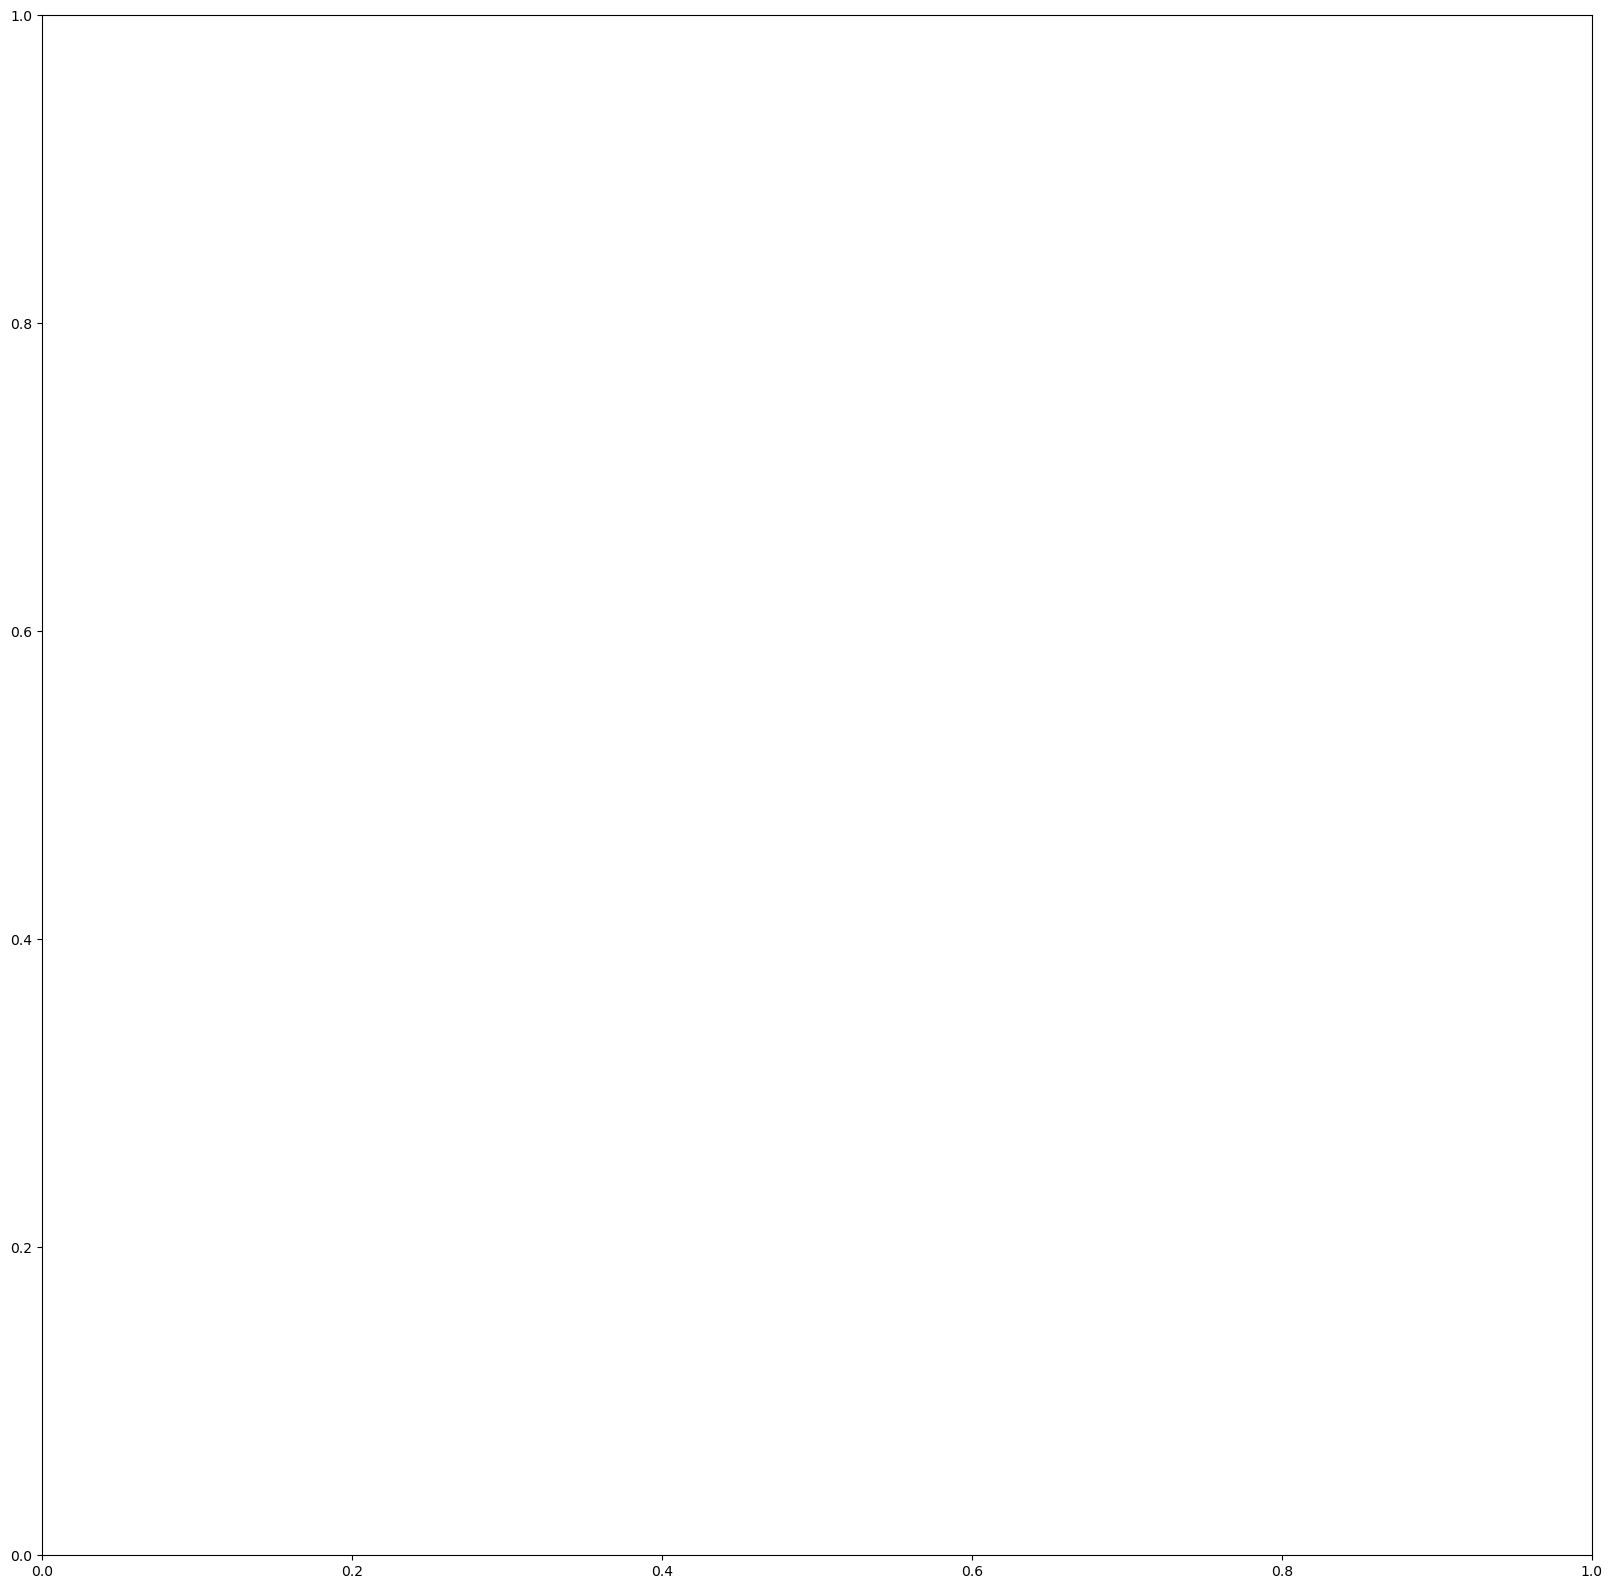

In [10]:
# Test objective function

parameters=dict(qmax=0.3, Kl=1.18)
size = 20
counter = 0

names = [name for name in parameters.keys()]
values = [value for value in parameters.values()]

def y_func(t, *values):
        
    global counter
    counter += 1
    
    # Update parameter value in dictionary
    parameters = dict([(name, value) for name, value in zip(names, values)])

    print(f'Run {counter}: {parameters}')
    
    # Run model with parameter value
    C, y, q, t, BV, z, RMSE = model(
                Nx    = 100,
                dt    = 0.1, 
                tmax  = 6, 

                isotherm = 'Langmuir',
                profiles = False, 
                breakthrough = False,
                
                **parameters
    )
    
    # Interpolate model for experimental points
    y_int = np.interp(texp, t/60, C)
    
    return y_int


# Plot experimental data
fig2, ax2 = plt.subplots(figsize=(size,size))
ax2.scatter(texp, Cexp, color='midnightblue', marker='s', s=30*size, label='exp')

# Plot model
Ctest = y_func(texp, *values)

ax2.plot(texp, Ctest, color='darkorange', linewidth=5, label='model')

ax2.set_xlabel('Time [min]', fontsize=30)
ax2.set_ylabel('Breakthrough concentration, C/C0', fontsize=30)
ax2.tick_params(labelsize=30)
# ax2.set_xticks(np.linspace(0, 16, 9))
ax2.set_ylim(0)
ax2.set_xlim(0, 20)
ax2.legend(fontsize=30)

In [13]:
parameters=dict(qmax=0.3, Kl=1.18)

[value for value in parameters.values()]
[name for name in parameters.keys()]
# parameters.keys()
[(name, value) for name, value in parameters.items()]

# parameters.update(a=1)
print(parameters.items())
[i for i in enumerate(names)]
[(name, value) for name, value in zip(names, values)]

dict_items([('qmax', 0.3), ('Kl', 1.18)])


[('qmax', 0.3), ('Kl', 1.18)]

### Objective function to compute residuals

In [14]:
# 1) Least squares

def y_func(values, ydata=Cexp):
    # Counter for number of runs
    global counter, RMSE
    counter += 1
    
    # Update parameter values in dictionary and print to screen
    parameters = dict([(name, value) for name, value in zip(names, values)])
    print(f'Run {counter}: {parameters}')
    
    # Run model with parameter value
    C, y, q, t, BV, z, RMSE = model(Nx=100, dt=0.1, tmax=6, C0 = C0exp,
                                    isotherm = 'Langmuir', profiles = False, breakthrough = False, 
                                    **parameters)      
    
    # Interpolate model for experimental points
    y_int = np.interp(texp, t/60, C)
    
    return ydata - y_int

# Test objective function
counter = 0
residual = y_func([0.1])

Run 1: {'qmax': 0.1}


f02bde running: t: 6: : 60it [00:03, 18.17it/s]                          


RMSE = 0.3943


In [200]:
# 2) Curve fitting

def y_func(t, *values):
    # Counter for number of runs
    global counter, RMSE
    counter += 1
    
    # Update parameter values in dictionary and print to screen
    parameters = dict([(name, value) for name, value in zip(names, values)])
    print(f'Run {counter}: {parameters}')
    
    # Run model with parameter value
    C, y, q, t, BV, z, RMSE = model(Nx=100, dt=0.1, tmax=6, C0 = C0exp,
                                    isotherm = 'Langmuir', profiles = False, breakthrough = False, 
                                    **parameters)
    
    # Interpolate model for experimental points
    y_int = np.interp(texp, t/60, C)
    
    return y_int

# Test objective function
counter = 0
parameters = dict(qmax=0.291)
parameters = dict([(name, value) for name, value in zip(names, values)])
original_values = [value for value in parameters.values()]
C_original = y_func(texp, *original_values)
RMSE_original = RMSE

Run 1: {'qmax': 0.291}


158afb running: t: 6: : 60it [00:02, 20.69it/s]                          


RMSE = 0.0707


### Estimate 1 parameter: qmax

In [162]:
from scipy.optimize import least_squares, curve_fit

# Define parameter values and bounds
parameters = dict(qmax=0.291)
parameters = dict(qmax=0.3)
bounds = ([0.15], [0.35])
bounds = (0., np.inf)

# Run parameter estimation
names = [name for name in parameters.keys()]
original_values = [value for value in parameters.values()]
counter = 0
# 1) Least squares
# result = least_squares(y_func, x0=original_values, method='trf', ftol=1e-08, xtol=1e-08, gtol=1e-08, x_scale=(0.3, 4e-4), 
#                        bounds=bounds,
#                        loss='linear', f_scale=1.0, diff_step=None, tr_solver=None, max_nfev=50, verbose=0, args=(), 
#                        kwargs={'ydata':Cexp})
# param_calib = result.x

# 2) Curve fitting
param_calib, covariance = curve_fit(y_func, xdata=texp, ydata=Cexp, p0=original_values, method='trf', bounds=bounds,
                                    ftol=1e-04, xtol=1e-04, gtol=1e-04, x_scale=[.3], 
                                    loss='linear', f_scale=1.0, max_nfev=50
                                    ) 

# Print results
calibrated_parameters = dict([(name, value) for name, value in zip(names, param_calib)])
print(calibrated_parameters)
print(covariance)

Run 1: {'qmax': 0.3}


598a43 running: t: 6: : 60it [00:03, 19.25it/s]                          


RMSE = 0.0496
Run 2: {'qmax': 0.3000000149011612}


d43b8b running: t: 6: : 60it [00:02, 21.54it/s]                          


RMSE = 0.0496
Run 3: {'qmax': 0.3142742104327885}


7c9308 running: t: 6: : 60it [00:02, 20.15it/s]                          


RMSE = 0.0272
Run 4: {'qmax': 0.3142742253339497}


b39b84 running: t: 6: : 60it [00:02, 21.22it/s]                          


RMSE = 0.0272
Run 5: {'qmax': 0.3151633469247716}


df3ae7 running: t: 6: : 60it [00:02, 21.12it/s]                          


RMSE = 0.0271
Run 6: {'qmax': 0.3151633618259328}


dfbf2c running: t: 6: : 60it [00:02, 20.08it/s]                          


RMSE = 0.0271
Run 7: {'qmax': 0.3152213184336988}


be2d17 running: t: 6: : 60it [00:03, 19.28it/s]                          


RMSE = 0.0271
Run 8: {'qmax': 0.31522133333486}


e99f6a running: t: 6: : 60it [00:02, 20.62it/s]                          


RMSE = 0.0271
{'qmax': 0.3152213184336988}
[[4.66922444e-06]]


In [163]:
print("Cov = \n", covariance) # covariance matrix
print("Cond = {:.1f}".format(np.linalg.cond(covariance))) # 1 = well conditioned, 1e6 = ill conditioned
print("Std = ", np.sqrt(np.diag(covariance))) # standard deviation of the parameters

# 95% confidence intervals
from scipy import stats
Np = 1
t_estimator = stats.t.ppf((1+0.95)/2, len(Cexp)-Np)
print("Student's t estimator =", "{:.3f}".format(t_estimator))

CI_qmax = t_estimator * np.sqrt(covariance[0,0])
# CI_rp = t_estimator * np.sqrt(covariance[1,1])

d_qmax = CI_qmax/param_calib[0]*100
# d_rp = CI_rp/param_calib[1]*100

print("CI_qmax = {:.3f} ± {:.4f} ({:.1f}%)".format(param_calib[0], CI_qmax, d_qmax))
# print("CI_rp = {:.2e} ± {:.2e} ({:.1f}%)".format(param_calib[1], CI_rp, d_rp))


Cov = 
 [[4.66922444e-06]]
Cond = 1.0
Std =  [0.00216084]
Student's t estimator = 2.093
CI_qmax = 0.315 ± 0.0045 (1.4%)


In [164]:
# SSR
C_calibrated = y_func(texp, *param_calib)
SSR = np.sum((C_calibrated-Cexp)**2)
print("SSR =", SSR)

# AIC
N = len(Cexp)
print("N =", N)
AIC = N * np.log(SSR/N) + 2*Np
print("AIC = {:.1f}".format(AIC))

Run 9: {'qmax': 0.3152213184336988}


9a5505 running: t: 6: : 60it [00:02, 20.47it/s]                          


RMSE = 0.0271
SSR = 0.014685174822923612
N = 20
AIC = -142.3


### Estimate 2 parameters: qmax and rp

In [191]:
from scipy.optimize import least_squares, curve_fit

# Define parameter values and bounds
parameters = dict(qmax=0.291, rp=3.75e-4)
# parameters = dict(qmax=0.3, rp=3.75e-4)
bounds = ([0.15, 3e-4], [0.35, 4.5e-4])
bounds = (0., np.inf)

# Run parameter estimation
names = [name for name in parameters.keys()]
original_values = [value for value in parameters.values()]
counter = 0
# 1) Least squares
# result = least_squares(y_func, x0=original_values, method='trf', ftol=1e-08, xtol=1e-08, gtol=1e-08, x_scale=(0.3, 4e-4), 
#                        bounds=bounds,
#                        loss='linear', f_scale=1.0, diff_step=None, tr_solver=None, max_nfev=50, verbose=0, args=(), 
#                        kwargs={'ydata':Cexp})
# param_calib = result.x

# 2) Curve fitting
param_calib, covariance = curve_fit(y_func, xdata=texp, ydata=Cexp, p0=original_values, method='lm',#, bounds=bounds,
                                    ftol=1e-04, xtol=1e-04, gtol=1e-04, #x_scale=[.3, 4e-4], 
                                    #loss='linear', f_scale=1.0, max_nfev=50
                                    ) 

# Print results
calibrated_parameters = dict([(name, value) for name, value in zip(names, param_calib)])
print(calibrated_parameters)
print(covariance)

Run 1: {'qmax': 0.291, 'rp': 0.000375}


3e821c running: t: 6: : 60it [00:02, 20.61it/s]                          


RMSE = 0.0707
Run 2: {'qmax': 0.291, 'rp': 0.000375}


54f799 running: t: 6: : 60it [00:02, 20.76it/s]                          


RMSE = 0.0707
Run 3: {'qmax': 0.291, 'rp': 0.000375}


c3e4d6 running: t: 6: : 60it [00:02, 20.61it/s]                          


RMSE = 0.0707
Run 4: {'qmax': 0.2910000043362379, 'rp': 0.000375}


975162 running: t: 6: : 60it [00:02, 20.41it/s]                          


RMSE = 0.0707
Run 5: {'qmax': 0.291, 'rp': 0.00037500000558793545}


5fec51 running: t: 6: : 60it [00:02, 21.54it/s]                          


RMSE = 0.0707
Run 6: {'qmax': 0.3199874612960467, 'rp': 0.0004777144104076345}


0cc341 running: t: 6: : 60it [00:02, 22.42it/s]                          


RMSE = 0.0233
Run 7: {'qmax': 0.31998746606423145, 'rp': 0.0004777144104076345}


3d0988 running: t: 6: : 60it [00:02, 20.77it/s]                          


RMSE = 0.0233
Run 8: {'qmax': 0.3199874612960467, 'rp': 0.0004777144175261339}


19d621 running: t: 6: : 60it [00:02, 21.42it/s]                          


RMSE = 0.0233
Run 9: {'qmax': 0.31847105558053374, 'rp': 0.00044009006304381737}


dbe094 running: t: 6: : 60it [00:02, 21.26it/s]                          


RMSE = 0.0207
Run 10: {'qmax': 0.31847106032612227, 'rp': 0.00044009006304381737}


c2cd89 running: t: 6: : 60it [00:02, 21.29it/s]                          


RMSE = 0.0207
Run 11: {'qmax': 0.31847105558053374, 'rp': 0.0004400900696016703}


5bed7e running: t: 6: : 60it [00:02, 22.38it/s]                          


RMSE = 0.0207
Run 12: {'qmax': 0.3186129576449122, 'rp': 0.00043817331324623254}


a4383d running: t: 6: : 60it [00:02, 21.43it/s]                          


RMSE = 0.0206
Run 13: {'qmax': 0.3186129623926153, 'rp': 0.00043817331324623254}


3c9420 running: t: 6: : 60it [00:02, 21.64it/s]                          


RMSE = 0.0206
Run 14: {'qmax': 0.3186129576449122, 'rp': 0.0004381733197755237}


04df8a running: t: 6: : 60it [00:02, 21.32it/s]                          


RMSE = 0.0206
Run 15: {'qmax': 0.3186088348718112, 'rp': 0.00043789142821716267}


d6bf15 running: t: 6: : 60it [00:02, 21.42it/s]                          


RMSE = 0.0206
{'qmax': 0.3186088348718112, 'rp': 0.00043789142821716267}
[[4.42853589e-06 1.88488153e-08]
 [1.88488153e-08 3.06055901e-10]]


#### Covariance matrix and confidence intervals

In [174]:
print("Cov = \n", covariance) # covariance matrix
print("Cond = {:.1f}".format(np.linalg.cond(covariance))) # 19608.551317770944 relatively small
print("Std = ", np.sqrt(np.diag(covariance))) # array([4.42534217e-06, 3.05849579e-10]) relatively small

# 95% confidence intervals
from scipy import stats
Np = 2
t_estimator = stats.t.ppf((1+0.95)/2, len(Cexp)-Np)
print("Student's t estimator =", "{:.3f}".format(t_estimator))

CI_qmax = t_estimator * np.sqrt(covariance[0,0])
CI_rp = t_estimator * np.sqrt(covariance[1,1])

d_qmax = CI_qmax/param_calib[0]*100
d_rp = CI_rp/param_calib[1]*100

print("CI_qmax = {:.3f} ± {:.4f} ({:.1f}%)".format(param_calib[0], CI_qmax, d_qmax))
print("CI_rp = {:.2e} ± {:.2e} ({:.1f}%)".format(param_calib[1], CI_rp, d_rp))


Cov = 
 [[4.42853589e-06 1.88488153e-08]
 [1.88488153e-08 3.06055901e-10]]
Cond = 19610.6
Std =  [2.10440868e-03 1.74944534e-05]
Student's t estimator = 2.101
CI_qmax = 0.319 ± 0.0044 (1.4%)
CI_rp = 4.38e-04 ± 3.68e-05 (8.4%)


In [175]:
# SSR
C_calibrated = y_func(texp, *param_calib)
SSR = np.sum((C_calibrated-Cexp)**2)
print("SSR =", SSR)

# AIC
N = len(Cexp)
print("N =", N)
AIC = N * np.log(SSR/N) + 2*Np
print("AIC = {:.1f}".format(AIC))

Run 16: {'qmax': 0.3186088348718112, 'rp': 0.00043789142821716267}


10a2c3 running: t: 6: : 60it [00:02, 21.41it/s]                          


RMSE = 0.0206
SSR = 0.008512868681854953
N = 20
AIC = -151.2


#### Plot results

In [203]:
res_original

array([7.90548140e-05, 1.72076139e-03, 9.01846947e-03, 2.98323101e-02,
       7.85802682e-02, 1.72494258e-01, 3.14103050e-01, 4.80379024e-01,
       6.45479003e-01, 7.63411306e-01, 8.63564164e-01, 9.08328051e-01,
       9.45115374e-01, 9.67582683e-01, 9.81433099e-01, 9.88639940e-01,
       9.96070096e-01, 9.97552226e-01, 9.99206766e-01, 9.99841115e-01])

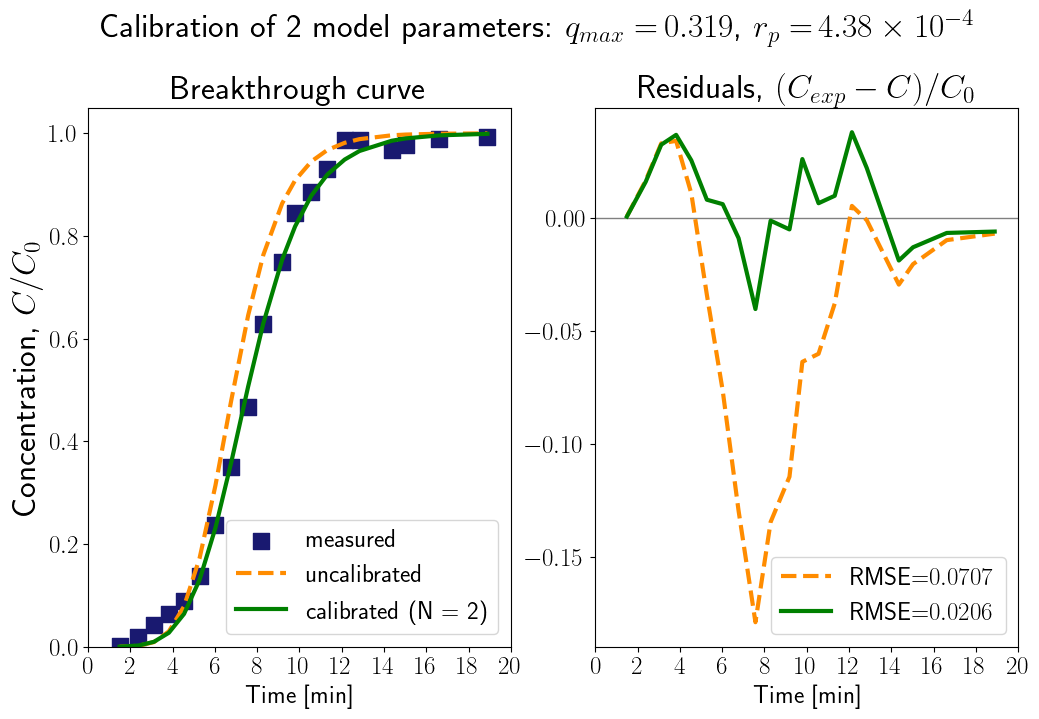

In [206]:
# Plot results
size = 12
fig, ax = plt.subplots(1, 2, figsize=(size,size-5))

# Scientific notation for exponential values
def as_si(x, ndp):
    s = '{x:0.{ndp:d}e}'.format(x=x, ndp=ndp)
    m, e = s.split('e')
    return r'{m:s}\times 10^{{{e:d}}}'.format(m=m, e=int(e))

# Run model with original and calibrated parameters
global RMSE
# C_original = y_func(texp, *original_values)
# RMSE_original = RMSE
# C_calibrated = y_func(texp, *param_calib)
# RMSE_calibrated = RMSE

# Create figure
plt.rcParams['text.usetex'] = True
plt.suptitle("Calibration of 2 model parameters: $q_{max}=\\,$"+"${:.3f}$".format(calibrated_parameters['qmax'])+
             ", $r_p=\\,$"+"${0:s}$".format(as_si(calibrated_parameters['rp'],2)), fontsize=2*size, y=1.02)

# Plot experimental data
ax[0].scatter(texp, Cexp, color='midnightblue', marker='s', s=10*size, label='measured')

# Plot original values
ax[0].plot(texp, C_original, linestyle='--', color='darkorange', linewidth=3, label=f'uncalibrated')

# Plot calibrated values
ax[0].plot(texp, C_calibrated, color='green', linewidth=3, label=f'calibrated (N = 2)')

ax[0].set_title('Breakthrough curve', fontsize=2*size)
ax[0].set_xlabel('Time [min]', fontsize=1.5*size)
ax[0].set_ylabel('Concentration, $C/C_0$', fontsize=2*size)
ax[0].tick_params(labelsize=1.5*size)
ax[0].set_xticks(np.linspace(0, 20, int(20/2+1)))
ax[0].set_ylim(0)
# ax2.set_xlim(0, int(max(max(BV), max(texp))))
ax[0].legend(fontsize=1.5*size, loc='lower right')

# Plot residuals
ax[1].set_title('Residuals, $(C_{exp}-C)/C_0$', fontsize=2*size)
ax[1].axhline(0, color='gray', linewidth=1, linestyle='-')
# ax[1].scatter(texp, Cexp-C_original, color='darkorange', marker='s', s=10*size)
# ax[1].scatter(texp, Cexp-C_calibrated, color='green', marker='s', s=10*size)
res_original = Cexp - C_original
res_calibrated = Cexp - C_calibrated
ax[1].plot(texp, res_original, '--', color='darkorange', linewidth=3, label=f'RMSE=${RMSE_original:.4f}$')
ax[1].plot(texp, res_calibrated, '-', color='green', linewidth=3, label=f'RMSE=${RMSE_calibrated:.4f}$')
# ax[1].set_ylabel(r'Residuals, $C_{exp}-C$', fontsize=2*size)
ax[1].set_xticks(np.linspace(0, 20, int(20/2+1)))
ax[1].set_xlabel('Time [min]', fontsize=1.5*size)
ax[1].tick_params(labelsize=1.5*size)
ax[1].legend(fontsize=1.5*size, loc='lower right')

# Store results
plt.savefig(f"calibration_Np-{len(param_calib)}.pdf", format="pdf", bbox_inches="tight")
plt.show()

In [205]:
RMSE_calibrated/RMSE_original-1

-0.7083659545173135

#### Confidence intervals

In [20]:
# Monte Carlo sampling of both parameters with +/-20% uncertainty
from SALib.sample import saltelli
from SALib.analyze import sobol
from SALib import ProblemSpec

# Define inputs
Np = 2 # no. of parameters

sp = ProblemSpec({
    'num_vars': Np,
    'names': ['q_{max}', 'r_p'],
    'bounds': [[0.8*param_calib[0], 1.2*param_calib[0]],  # qmax
              [0.8*param_calib[1], 1.2*param_calib[1]]], # rp
    'outputs': ['Y'],
    'dists': ['unif', 'unif']
})


# Generate samples
N = 2**0

sp.sample_sobol(N, calc_second_order=True)

params = sp.samples
params.shape

# Store in disk
sampling = pd.DataFrame(params)
sampling.rename(columns={0:'qmax', 1:'rp'}, inplace=True)
sampling.to_excel(f"sampling_N-{N:d}_Np-{Np:d}.xlsx")
sampling.to_csv(f"sampling_N-{N:d}_Np-{Np:d}.csv")

pars = pd.read_csv(f"sampling_N-{N:d}_Np-{Np:d}.csv")
print(pars)
print(np.mean(pars, axis=0))

# Run model for each parameter set
res = np.zeros(params.shape[0])
counter = 0
for i in range(params.shape[0]):
    y_func(params[i])
    res[i] = RMSE

print(res)

   Unnamed: 0      qmax        rp
0           0  0.375992  0.000486
1           1  0.321971  0.000486
2           2  0.375992  0.000482
3           3  0.375992  0.000482
4           4  0.321971  0.000486
5           5  0.321971  0.000482
Run 1: {'qmax': 0.3759916762045808, 'rp': 0.0004855890140175786}


6d9805 running: t: 6: : 60it [00:02, 21.69it/s]                          


RMSE = 0.1513
Run 2: {'qmax': 0.32197061640813723, 'rp': 0.0004855890140175786}


f1d1a9 running: t: 6: : 60it [00:03, 19.62it/s]                          


RMSE = 0.0242
Run 3: {'qmax': 0.3759916762045808, 'rp': 0.0004815573900838399}


8ee821 running: t: 6: : 60it [00:03, 18.84it/s]                          


RMSE = 0.1522
Run 4: {'qmax': 0.3759916762045808, 'rp': 0.0004815573900838399}


4f86b1 running: t: 6: : 60it [00:02, 20.73it/s]                          


RMSE = 0.1522
Run 5: {'qmax': 0.32197061640813723, 'rp': 0.0004855890140175786}


31ec9f running: t: 6: : 60it [00:02, 20.12it/s]                          


RMSE = 0.0242
Run 6: {'qmax': 0.32197061640813723, 'rp': 0.0004815573900838399}


43909b running: t: 6: : 60it [00:02, 20.16it/s]                          


RMSE = 0.0238
[0.151341   0.02422752 0.15222295 0.15222295 0.02422752 0.02376334]


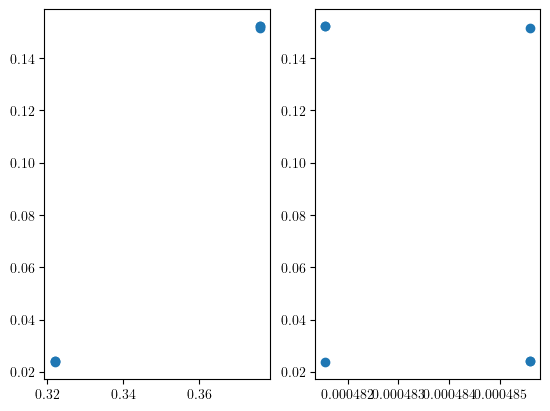

[[0.37599168 0.00048559]
 [0.32197062 0.00048559]
 [0.37599168 0.00048156]
 [0.37599168 0.00048156]
 [0.32197062 0.00048559]
 [0.32197062 0.00048156]]
[0.34898115 0.00048357]


In [21]:
fig, ax = plt.subplots(1,2)
ax[0].scatter(params[:,0], res)
ax[1].scatter(params[:,1], res)
plt.show()

print(params)
print(np.mean(params, axis=0))

In [22]:
print(np.mean(res))

# Calculate the 75th percentile
percentile = np.percentile(res, 97.5)
print(percentile)

0.08800087892942539
0.15222295069411737


### Estimate qmax and Kl

In [111]:
from scipy.optimize import curve_fit, least_squares

# Define parameter values and bounds

parameters = dict(qmax=0.291, Kl=1.18)
parameters = dict(qmax=0.3, Kl=1.2)

names = [name for name in parameters.keys()]
original_values = [value for value in parameters.values()]

bounds = ([0.1, 1], [0.35, 4])
# bounds = (0., np.inf)

# Run parameter estimation
counter = 0

# popt, _ = curve_fit(y_func, xdata=texp, ydata=Cexp, p0=p0, method='trf', bounds=bounds, max_nfev=50)  # Optimization uses TRF with bounds, see documentation. Trust Region Reflective algorithm,
# param_calib = popt

result = least_squares(y_func, x0=original_values, method='trf', ftol=1e-08, xtol=1e-08, gtol=1e-08, x_scale=(0.3, 2.0), 
                       bounds=bounds,
                       loss='linear', f_scale=1.0, diff_step=None, tr_solver=None, max_nfev=50, verbose=0, args=(), 
                       kwargs={'ydata':Cexp})
param_calib = result.x

# Print results
parameters = dict([(name, value) for name, value in zip(names, param_calib)])
print(parameters)

Run 1: {'qmax': 0.3, 'Kl': 1.2}


85dc96 running: t: 6: : 60it [00:03, 19.15it/s]                          


RMSE = 0.0494
Run 2: {'qmax': 0.3000000149011612, 'Kl': 1.2}


a2f895 running: t: 6: : 60it [00:02, 20.11it/s]                          


RMSE = 0.0494
Run 3: {'qmax': 0.3, 'Kl': 1.2000000178813934}


7a3b54 running: t: 6: : 60it [00:02, 20.75it/s]                          


RMSE = 0.0494
Run 4: {'qmax': 0.3090631136539901, 'Kl': 1.7075338354149348}


c10016 running: t: 6: : 60it [00:02, 21.66it/s]                          


RMSE = 0.0295
Run 5: {'qmax': 0.3090631285551513, 'Kl': 1.7075338354149348}


544159 running: t: 6: : 60it [00:02, 21.57it/s]                          


RMSE = 0.0295
Run 6: {'qmax': 0.3090631136539901, 'Kl': 1.7075338608591717}


9c9d07 running: t: 6: : 60it [00:02, 20.80it/s]                          


RMSE = 0.0295
Run 7: {'qmax': 0.31221359701521845, 'Kl': 1.8839460454904167}


22f4b3 running: t: 6: : 60it [00:02, 21.44it/s]                          


RMSE = 0.0272
Run 8: {'qmax': 0.31221361191637964, 'Kl': 1.8839460454904167}


b661b5 running: t: 6: : 60it [00:02, 20.22it/s]                          


RMSE = 0.0272
Run 9: {'qmax': 0.31221359701521845, 'Kl': 1.8839460735634004}


6601c1 running: t: 6: : 60it [00:03, 18.23it/s]                          


RMSE = 0.0272
Run 10: {'qmax': 0.31271159736613197, 'Kl': 1.911859751573634}


808567 running: t: 6: : 60it [00:02, 20.24it/s]                          


RMSE = 0.0271
Run 11: {'qmax': 0.31271161226729316, 'Kl': 1.911859751573634}


87a0e3 running: t: 6: : 60it [00:03, 19.85it/s]                          


RMSE = 0.0271
Run 12: {'qmax': 0.31271159736613197, 'Kl': 1.9118597800625643}


a3a21c running: t: 6: : 60it [00:03, 18.23it/s]                          


RMSE = 0.0271
Run 13: {'qmax': 0.31275062716974733, 'Kl': 1.9145103778159724}


044811 running: t: 6: : 60it [00:02, 20.55it/s]                          


RMSE = 0.0271
Run 14: {'qmax': 0.3127506420709085, 'Kl': 1.9145103778159724}


dc7e75 running: t: 6: : 60it [00:02, 21.47it/s]                          


RMSE = 0.0271
Run 15: {'qmax': 0.31275062716974733, 'Kl': 1.9145104063444003}


6034a1 running: t: 6: : 60it [00:02, 20.12it/s]                          


RMSE = 0.0271
Run 16: {'qmax': 0.31273287540562206, 'Kl': 1.924466029358786}


7c9619 running: t: 6: : 60it [00:02, 20.74it/s]                          


RMSE = 0.0271
Run 17: {'qmax': 0.31273289030678325, 'Kl': 1.924466029358786}


81b5d9 running: t: 6: : 60it [00:02, 21.83it/s]                          


RMSE = 0.0271
Run 18: {'qmax': 0.31273287540562206, 'Kl': 1.9244660580355646}


d5c856 running: t: 6: : 60it [00:02, 21.10it/s]                          


RMSE = 0.0271
Run 19: {'qmax': 0.31284460909164363, 'Kl': 1.870389238876403}


83ec80 running: t: 6: : 60it [00:02, 21.91it/s]                          


RMSE = 0.0271
Run 20: {'qmax': 0.3127610284502159, 'Kl': 1.9109470008876355}


1bce15 running: t: 6: : 60it [00:02, 21.91it/s]                          


RMSE = 0.0271
Run 21: {'qmax': 0.3127401332826483, 'Kl': 1.921086444701946}


ccfcd2 running: t: 6: : 60it [00:02, 21.81it/s]                          


RMSE = 0.0271
Run 22: {'qmax': 0.3127349094619137, 'Kl': 1.9236213189015303}


7db8b9 running: t: 6: : 60it [00:02, 21.15it/s]                          


RMSE = 0.0271
Run 23: {'qmax': 0.3127349243630749, 'Kl': 1.9236213189015303}


45811e running: t: 6: : 60it [00:02, 21.82it/s]                          


RMSE = 0.0271
Run 24: {'qmax': 0.3127349094619137, 'Kl': 1.9236213475657216}


da4d7e running: t: 6: : 60it [00:02, 21.88it/s]                          


RMSE = 0.0271
[0.31273491 1.92362132]


In [114]:
parameters = dict([(name, value) for name, value in zip(names, popt)])
parameters
# popt = dict([('qmax',0.2749446412235336), ('Kl',-0.240103866095644)])
# popt = [0.2749446412235336, -0.240103866095644]

{'qmax': 0.3231498186963705, 'Kl': 2.7546292435035395}

#### Plot results

In [113]:
texp

array([ 1.49049346,  2.38166262,  3.11648632,  3.82004093,  4.53923007,
        5.27405377,  6.02451202,  6.77497026,  7.57233214,  8.2915213 ,
        9.18269045,  9.79243779, 10.55853057, 11.32462336, 12.1376198 ,
       12.84117437, 14.35772543, 15.03001091, 16.62473467, 18.89174403])

Run 27: {'qmax': 0.3, 'Kl': 1.2}


dae5cf running: t: 6: : 60it [00:02, 20.78it/s]                          


RMSE = 0.0494
Run 28: {'qmax': 0.3127349094619137, 'Kl': 1.9236213189015303}


76c90e running: t: 6: : 60it [00:02, 21.71it/s]                          


RMSE = 0.0271


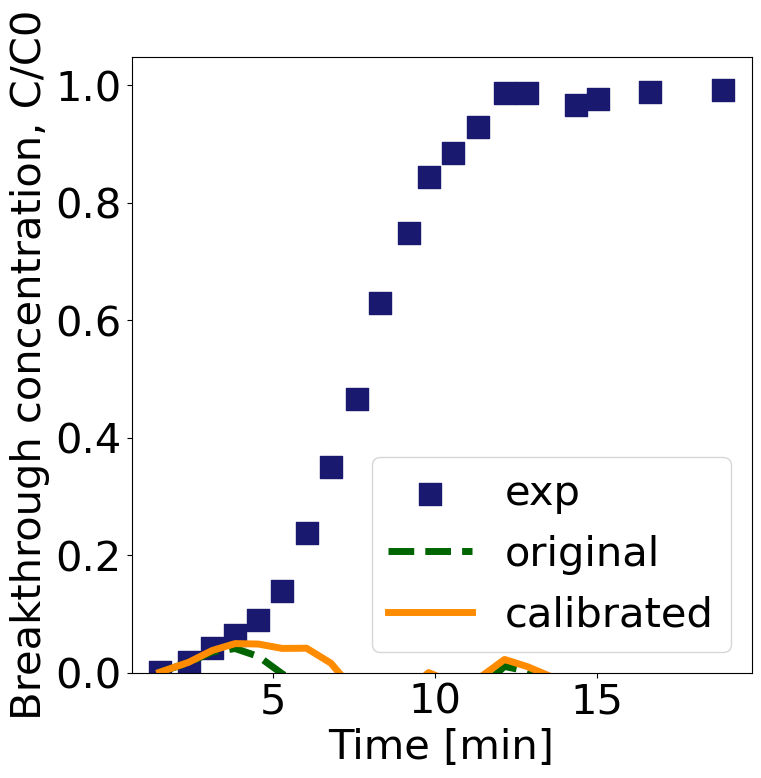

In [115]:


# Plot results
size = 8

fig2, ax2 = plt.subplots(figsize=(size,size))

# Plot experimental data
ax2.scatter(texp, Cexp, color='midnightblue', marker='s', s=30*size, label='exp')

# Plot original values
C_original = y_func(original_values)
ax2.plot(texp, C_original, linestyle='--', color='darkgreen', linewidth=5, label='original')

# Plot calibrated values
C_calibrated = y_func(param_calib)

ax2.plot(texp, C_calibrated, color='darkorange', linewidth=5, label='calibrated')

ax2.set_xlabel('Time [min]', fontsize=30)
ax2.set_ylabel('Breakthrough concentration, C/C0', fontsize=30)
ax2.tick_params(labelsize=30)
# ax2.set_xticks(np.linspace(0, 16, 9))
ax2.set_ylim(0)
# ax2.set_xlim(0, int(max(max(BV), max(texp))))
ax2.legend(fontsize=30)

### Estimate 3 parameters: qmax, Kl, rp

In [223]:
# Define parameter values and bounds

from scipy.optimize import curve_fit, least_squares

parameters=dict(qmax=0.291, rp=0.5*7.5e-4, e=0.37)
parameters=dict(qmax=0.3, rp=0.5*7.5e-4, e=0.37)

names = [name for name in parameters.keys()]
original_values = [value for value in parameters.values()]

bounds = ([0.1, 0.5*3e-4, 0.3],
          [0.35, 0.5*12e-4, 0.44])
# bounds = (0, np.inf)

# Run parameter estimation
names = [name for name in parameters.keys()]
original_values = [value for value in parameters.values()]
counter = 0
# 1) Least squares
# result = least_squares(y_func, x0=original_values, method='trf', ftol=1e-08, xtol=1e-08, gtol=1e-08, x_scale=(0.3, 4e-4), 
#                        bounds=bounds,
#                        loss='linear', f_scale=1.0, diff_step=None, tr_solver=None, max_nfev=50, verbose=0, args=(), 
#                        kwargs={'ydata':Cexp})
# param_calib = result.x

# 2) Curve fitting
param_calib, covariance = curve_fit(y_func, xdata=texp, ydata=Cexp, p0=original_values, method='trf', bounds=bounds,
                                    ftol=1e-04, xtol=1e-04, gtol=1e-04, x_scale=[.3, 4e-4, 0.37], 
                                    loss='linear', f_scale=1.0, max_nfev=50
                                    ) 

# Print results
calibrated_parameters = dict([(name, value) for name, value in zip(names, param_calib)])
print(calibrated_parameters)
print(covariance)

Run 1: {'qmax': 0.3, 'rp': 0.000375, 'e': 0.37}


548d36 running: t: 6: : 60it [00:02, 21.24it/s]                          


RMSE = 0.0496
Run 2: {'qmax': 0.3000000149011612, 'rp': 0.000375, 'e': 0.37}


af0853 running: t: 6: : 60it [00:02, 21.44it/s]                          


RMSE = 0.0496
Run 3: {'qmax': 0.3, 'rp': 0.00037501490116119386, 'e': 0.37}


9a4ebf running: t: 6: : 60it [00:03, 19.74it/s]                          


RMSE = 0.0496
Run 4: {'qmax': 0.3, 'rp': 0.000375, 'e': 0.3700000149011612}


60908e running: t: 6: : 60it [00:02, 21.48it/s]                          


RMSE = 0.0496
Run 5: {'qmax': 0.31323834744859597, 'rp': 0.0004303642458862488, 'e': 0.38657402428122317}


5e14ac running: t: 6: : 60it [00:03, 20.00it/s]                          


RMSE = 0.0243
Run 6: {'qmax': 0.31323836234975716, 'rp': 0.0004303642458862488, 'e': 0.38657402428122317}


c78eaf running: t: 6: : 60it [00:02, 20.34it/s]                          


RMSE = 0.0243
Run 7: {'qmax': 0.31323834744859597, 'rp': 0.00043037914704744263, 'e': 0.38657402428122317}


f65369 running: t: 6: : 60it [00:03, 19.95it/s]                          


RMSE = 0.0243
Run 8: {'qmax': 0.31323834744859597, 'rp': 0.0004303642458862488, 'e': 0.38657403918238437}


829e7a running: t: 6: : 60it [00:02, 20.20it/s]                          


RMSE = 0.0243
Run 9: {'qmax': 0.31783548595720346, 'rp': 0.00043574755355582103, 'e': 0.3814096103770962}


b20411 running: t: 6: : 60it [00:02, 20.45it/s]                          


RMSE = 0.0208
Run 10: {'qmax': 0.31783550085836465, 'rp': 0.00043574755355582103, 'e': 0.3814096103770962}


03bfd3 running: t: 6: : 60it [00:02, 20.31it/s]                          


RMSE = 0.0208
Run 11: {'qmax': 0.31783548595720346, 'rp': 0.0004357624547170149, 'e': 0.3814096103770962}


705c89 running: t: 6: : 60it [00:02, 20.21it/s]                          


RMSE = 0.0208
Run 12: {'qmax': 0.31783548595720346, 'rp': 0.00043574755355582103, 'e': 0.3814096252782574}


c6b91c running: t: 6: : 60it [00:02, 21.41it/s]                          


RMSE = 0.0208
Run 13: {'qmax': 0.31848432286127687, 'rp': 0.0004365667401381946, 'e': 0.37889987746259857}


873af4 running: t: 6: : 60it [00:02, 20.90it/s]                          


RMSE = 0.0207
Run 14: {'qmax': 0.31848433776243806, 'rp': 0.0004365667401381946, 'e': 0.37889987746259857}


126680 running: t: 6: : 60it [00:02, 21.51it/s]                          


RMSE = 0.0207
Run 15: {'qmax': 0.31848432286127687, 'rp': 0.00043658164129938844, 'e': 0.37889987746259857}


6dcb74 running: t: 6: : 60it [00:02, 21.44it/s]                          


RMSE = 0.0207
Run 16: {'qmax': 0.31848432286127687, 'rp': 0.0004365667401381946, 'e': 0.37889989236375976}


5a39cd running: t: 6: : 60it [00:02, 22.46it/s]                          


RMSE = 0.0207
Run 17: {'qmax': 0.31922275781161047, 'rp': 0.0004441094710221762, 'e': 0.35029105786240405}


99dc4d running: t: 6: : 60it [00:02, 21.87it/s]                          


RMSE = 0.0204
Run 18: {'qmax': 0.31922277271277166, 'rp': 0.0004441094710221762, 'e': 0.35029105786240405}


8703c8 running: t: 6: : 60it [00:02, 21.57it/s]                          


RMSE = 0.0204
Run 19: {'qmax': 0.31922275781161047, 'rp': 0.00044412437218337007, 'e': 0.35029105786240405}


eb6892 running: t: 6: : 60it [00:02, 20.34it/s]                          


RMSE = 0.0204
Run 20: {'qmax': 0.31922275781161047, 'rp': 0.0004441094710221762, 'e': 0.35029107276356525}


1ae544 running: t: 6: : 60it [00:02, 21.45it/s]                          


RMSE = 0.0204
Run 21: {'qmax': 0.3190399093197557, 'rp': 0.0004391790486503887, 'e': 0.3871926099737348}


b76e06 running: t: 6: : 60it [00:02, 21.69it/s]                          


RMSE = 0.0208
Run 22: {'qmax': 0.3190142418563893, 'rp': 0.00044140853769684816, 'e': 0.3594265555566183}


6408fe running: t: 6: : 60it [00:02, 20.80it/s]                          


RMSE = 0.0205
Run 23: {'qmax': 0.31902734116871306, 'rp': 0.0004422920886988711, 'e': 0.352387468707511}


cb6d23 running: t: 6: : 60it [00:02, 20.35it/s]                          


RMSE = 0.0204
Run 24: {'qmax': 0.31907906236252104, 'rp': 0.0004432762967836641, 'e': 0.35064862216958986}


204d8d running: t: 6: : 60it [00:03, 19.71it/s]                          


RMSE = 0.0204
Run 25: {'qmax': 0.31907907726368223, 'rp': 0.0004432762967836641, 'e': 0.35064862216958986}


7f1a76 running: t: 6: : 60it [00:02, 20.78it/s]                          


RMSE = 0.0204
Run 26: {'qmax': 0.31907906236252104, 'rp': 0.00044329119794485794, 'e': 0.35064862216958986}


aab903 running: t: 6: : 60it [00:02, 21.80it/s]                          


RMSE = 0.0204
Run 27: {'qmax': 0.31907906236252104, 'rp': 0.0004432762967836641, 'e': 0.35064863707075106}


4ca9c8 running: t: 6: : 60it [00:02, 22.74it/s]                          


RMSE = 0.0204
Run 28: {'qmax': 0.31901700604403244, 'rp': 0.0004420939860243635, 'e': 0.35160962809326973}


ebe5fb running: t: 6: : 60it [00:02, 21.74it/s]                          


RMSE = 0.0204
Run 29: {'qmax': 0.3190560392485293, 'rp': 0.00044277671157483397, 'e': 0.35075337638664333}


34d687 running: t: 6: : 60it [00:02, 21.65it/s]                          


RMSE = 0.0204
Run 30: {'qmax': 0.3190560541496905, 'rp': 0.00044277671157483397, 'e': 0.35075337638664333}


7f7770 running: t: 6: : 60it [00:02, 21.47it/s]                          


RMSE = 0.0204
Run 31: {'qmax': 0.3190560392485293, 'rp': 0.0004427916127360278, 'e': 0.35075337638664333}


746b56 running: t: 6: : 60it [00:02, 21.78it/s]                          


RMSE = 0.0204
Run 32: {'qmax': 0.3190560392485293, 'rp': 0.00044277671157483397, 'e': 0.35075339128780453}


f46856 running: t: 6: : 60it [00:02, 22.70it/s]                          


RMSE = 0.0204
Run 33: {'qmax': 0.3190526648695557, 'rp': 0.00044272867438389707, 'e': 0.35070257852830883}


642f8f running: t: 6: : 60it [00:02, 21.75it/s]                          


RMSE = 0.0204
Run 34: {'qmax': 0.3190526797707169, 'rp': 0.00044272867438389707, 'e': 0.35070257852830883}


680bc3 running: t: 6: : 60it [00:02, 21.55it/s]                          


RMSE = 0.0204
Run 35: {'qmax': 0.3190526648695557, 'rp': 0.0004427435755450909, 'e': 0.35070257852830883}


63d432 running: t: 6: : 60it [00:02, 21.71it/s]                          


RMSE = 0.0204
Run 36: {'qmax': 0.3190526648695557, 'rp': 0.00044272867438389707, 'e': 0.35070259342947}


1b3b88 running: t: 6: : 60it [00:02, 21.66it/s]                          


RMSE = 0.0204
Run 37: {'qmax': 0.31904713351291325, 'rp': 0.00044263865877871753, 'e': 0.35060012842320487}


d17cd6 running: t: 6: : 60it [00:02, 20.67it/s]                          


RMSE = 0.0204
Run 38: {'qmax': 0.31904714841407444, 'rp': 0.00044263865877871753, 'e': 0.35060012842320487}


cf530f running: t: 6: : 60it [00:02, 20.15it/s]                          


RMSE = 0.0204
Run 39: {'qmax': 0.31904713351291325, 'rp': 0.0004426535599399114, 'e': 0.35060012842320487}


9072ba running: t: 6: : 60it [00:02, 21.97it/s]                          


RMSE = 0.0204
Run 40: {'qmax': 0.31904713351291325, 'rp': 0.00044263865877871753, 'e': 0.35060014332436606}


b0b549 running: t: 6: : 60it [00:02, 21.15it/s]                          


RMSE = 0.0204
{'qmax': 0.31904713351291325, 'rp': 0.00044263865877871753, 'e': 0.35060012842320487}
[[ 4.29544365e-06  1.79016354e-08  7.68433371e-06]
 [ 1.79016354e-08  3.55277087e-10 -5.70877614e-07]
 [ 7.68433371e-06 -5.70877614e-07  7.44188627e-03]]


#### Confidence intervals

In [224]:
print("Cov = \n", covariance) # covariance matrix
print("Cond = {:.1f}".format(np.linalg.cond(covariance))) # 32114265.7 quite large ! ill-conditioned
print("Std = ", np.sqrt(np.diag(covariance))) # [2.11479611e-03 2.04437075e-05 8.78227814e-02]  large compared to parameters rp and epsilon

# 95% confidence intervals
from scipy import stats
Np = 3
t_estimator = stats.t.ppf((1+0.95)/2, len(Cexp)-Np)
print("Student's t estimator =", "{:.3f}".format(t_estimator))

CI_qmax = t_estimator * np.sqrt(covariance[0,0])
CI_rp = t_estimator * np.sqrt(covariance[1,1])
CI_e = t_estimator * np.sqrt(covariance[2,2])

d_qmax = CI_qmax/param_calib[0]*100
d_rp = CI_rp/param_calib[1]*100
d_e = CI_e/param_calib[2]*100

print("CI_qmax = {:.3f} ± {:.4f} ({:.1f}%)".format(param_calib[0], CI_qmax, d_qmax))
print("CI_rp = {:.2e} ± {:.2e} ({:.1f}%)".format(param_calib[1], CI_rp, d_rp))
print("CI_e = {:.2f} ± {:.2f} ({:.1f}%)".format(param_calib[2], CI_e, d_e))

# SSR
C_calibrated = y_func(texp, *param_calib)
SSR = np.sum((C_calibrated-Cexp)**2)
print("SSR =", SSR)

# RMSE
RMSE = np.sqrt(np.mean((C_calibrated-Cexp)**2))
print("RMSE =", RMSE)

# AIC
N = len(Cexp)
AIC = N * np.log(SSR/N) + 2*Np
print("AIC = {:.1f}".format(AIC))


Cov = 
 [[ 4.29544365e-06  1.79016354e-08  7.68433371e-06]
 [ 1.79016354e-08  3.55277087e-10 -5.70877614e-07]
 [ 7.68433371e-06 -5.70877614e-07  7.44188627e-03]]
Cond = 32114265.7
Std =  [2.07254521e-03 1.88487954e-05 8.62663681e-02]
Student's t estimator = 2.110
CI_qmax = 0.319 ± 0.0044 (1.4%)
CI_rp = 4.43e-04 ± 3.98e-05 (9.0%)
CI_e = 0.35 ± 0.18 (51.9%)
Run 41: {'qmax': 0.31904713351291325, 'rp': 0.00044263865877871753, 'e': 0.35060012842320487}


59cd9e running: t: 6: : 60it [00:02, 20.37it/s]                          


RMSE = 0.0204
SSR = 0.008337187209589253
RMSE = 0.020417133992788085
AIC = -149.7


In [216]:
np.sqrt(np.mean((C_calibrated-Cexp)**2))

0.020631127794978818

### Estimate 4 parameters: qmax, rp, epsilon, Kl

In [229]:
# Define parameter values and bounds

from scipy.optimize import curve_fit, least_squares

parameters=dict(qmax=0.291, rp=0.5*7.5e-4, e=0.37, Kl=1.18)
parameters=dict(qmax=0.300, rp=0.5*7.5e-4, e=0.37, Kl=2.2)

names = [name for name in parameters.keys()]
original_values = [value for value in parameters.values()]

bounds = ([0.1, 0.8*0.5*7.5e-4, 0.3, 1.],
          [0.35, 1.2*0.5*7.5e-4, 0.444, 4.])

# Run parameter estimation
names = [name for name in parameters.keys()]
original_values = [value for value in parameters.values()]
counter = 0
# 1) Least squares
# result = least_squares(y_func, x0=original_values, method='trf', ftol=1e-08, xtol=1e-08, gtol=1e-08, x_scale=(0.3, 4e-4), 
#                        bounds=bounds,
#                        loss='linear', f_scale=1.0, diff_step=None, tr_solver=None, max_nfev=50, verbose=0, args=(), 
#                        kwargs={'ydata':Cexp})
# param_calib = result.x

# 2) Curve fitting
param_calib, covariance = curve_fit(y_func, xdata=texp, ydata=Cexp, p0=original_values, method='trf', bounds=bounds,
                                    ftol=1e-04, xtol=1e-04, gtol=1e-04, x_scale=[.3, 4e-4, 0.37, 2.2], 
                                    loss='linear', f_scale=1.0, max_nfev=50) 

# Print results
calibrated_parameters = dict([(name, value) for name, value in zip(names, param_calib)])
print(calibrated_parameters)
print(covariance)
print("Calibration terminated.")

Run 1: {'qmax': 0.3, 'rp': 0.000375, 'e': 0.37, 'Kl': 2.2}


68b77e running: t: 6: : 60it [00:02, 20.87it/s]                          


RMSE = 0.0434
Run 2: {'qmax': 0.3000000149011612, 'rp': 0.000375, 'e': 0.37, 'Kl': 2.2}


7db109 running: t: 6: : 60it [00:05, 10.65it/s]                          


RMSE = 0.0434
Run 3: {'qmax': 0.3, 'rp': 0.00037501490116119386, 'e': 0.37, 'Kl': 2.2}


ccdb38 running: t: 6: : 60it [00:03, 19.63it/s]                          


RMSE = 0.0434
Run 4: {'qmax': 0.3, 'rp': 0.000375, 'e': 0.3700000149011612, 'Kl': 2.2}


1135af running: t: 6: : 60it [00:03, 17.98it/s]                          


RMSE = 0.0434
Run 5: {'qmax': 0.3, 'rp': 0.000375, 'e': 0.37, 'Kl': 2.2000000327825546}


8259a3 running: t: 6: : 60it [00:03, 16.94it/s]                          


RMSE = 0.0434
Run 6: {'qmax': 0.3109588406330508, 'rp': 0.0004257043117578672, 'e': 0.38432027625238446, 'Kl': 2.594519203986044}


e49d4a running: t: 6: : 60it [00:03, 17.11it/s]                          


RMSE = 0.0226
Run 7: {'qmax': 0.310958855534212, 'rp': 0.0004257043117578672, 'e': 0.38432027625238446, 'Kl': 2.594519203986044}


6dcbd4 running: t: 6: : 60it [00:02, 20.17it/s]                          


RMSE = 0.0226
Run 8: {'qmax': 0.3109588406330508, 'rp': 0.00042571921291906104, 'e': 0.38432027625238446, 'Kl': 2.594519203986044}


d6578d running: t: 6: : 60it [00:02, 21.38it/s]                          


RMSE = 0.0226
Run 9: {'qmax': 0.3109588406330508, 'rp': 0.0004257043117578672, 'e': 0.38432029115354566, 'Kl': 2.594519203986044}


a90495 running: t: 6: : 60it [00:02, 21.33it/s]                          


RMSE = 0.0226
Run 10: {'qmax': 0.3109588406330508, 'rp': 0.0004257043117578672, 'e': 0.38432027625238446, 'Kl': 2.594519242647393}


b71b67 running: t: 6: : 60it [00:03, 17.79it/s]                          


RMSE = 0.0226
Run 11: {'qmax': 0.3140589072087343, 'rp': 0.00043146346560303083, 'e': 0.4012585429809586, 'Kl': 2.7061295930874865}


941bf0 running: t: 6: : 60it [00:02, 21.46it/s]                          


RMSE = 0.0210
Run 12: {'qmax': 0.3140589221098955, 'rp': 0.00043146346560303083, 'e': 0.4012585429809586, 'Kl': 2.7061295930874865}


da0591 running: t: 6: : 60it [00:03, 19.08it/s]                          


RMSE = 0.0210
Run 13: {'qmax': 0.3140589072087343, 'rp': 0.0004314783667642247, 'e': 0.4012585429809586, 'Kl': 2.7061295930874865}


61aa14 running: t: 6: : 60it [00:02, 20.06it/s]                          


RMSE = 0.0210
Run 14: {'qmax': 0.3140589072087343, 'rp': 0.00043146346560303083, 'e': 0.4012585578821198, 'Kl': 2.7061295930874865}


23cf0a running: t: 6: : 60it [00:02, 20.08it/s]                          


RMSE = 0.0210
Run 15: {'qmax': 0.3140589072087343, 'rp': 0.00043146346560303083, 'e': 0.4012585429809586, 'Kl': 2.7061296334119596}


c1f369 running: t: 6: : 60it [00:02, 20.10it/s]                          


RMSE = 0.0210
Run 16: {'qmax': 0.31529639394524184, 'rp': 0.00043852347411038817, 'e': 0.3613600580579042, 'Kl': 2.7505203383978354}


3f389d running: t: 6: : 60it [00:02, 20.23it/s]                          


RMSE = 0.0206
Run 17: {'qmax': 0.31529640884640303, 'rp': 0.00043852347411038817, 'e': 0.3613600580579042, 'Kl': 2.7505203383978354}


bee88f running: t: 6: : 60it [00:02, 21.96it/s]                          


RMSE = 0.0206
Run 18: {'qmax': 0.31529639394524184, 'rp': 0.000438538375271582, 'e': 0.3613600580579042, 'Kl': 2.7505203383978354}


c12816 running: t: 6: : 60it [00:02, 20.74it/s]                          


RMSE = 0.0206
Run 19: {'qmax': 0.31529639394524184, 'rp': 0.00043852347411038817, 'e': 0.3613600729590654, 'Kl': 2.7505203383978354}


846855 running: t: 6: : 60it [00:02, 21.05it/s]                          


RMSE = 0.0206
Run 20: {'qmax': 0.31529639394524184, 'rp': 0.00043852347411038817, 'e': 0.3613600580579042, 'Kl': 2.7505203793837825}


4883db running: t: 6: : 60it [00:02, 21.48it/s]                          


RMSE = 0.0206
Run 21: {'qmax': 0.3151654328180119, 'rp': 0.00044267851736301333, 'e': 0.32336414776198774, 'Kl': 2.7495780934645735}


7e68da running: t: 6: : 60it [00:02, 20.02it/s]                          


RMSE = 0.0202
Run 22: {'qmax': 0.3151654477191731, 'rp': 0.00044267851736301333, 'e': 0.32336414776198774, 'Kl': 2.7495780934645735}


44aa4b running: t: 6: : 60it [00:02, 20.52it/s]                          


RMSE = 0.0202
Run 23: {'qmax': 0.3151654328180119, 'rp': 0.0004426934185242072, 'e': 0.32336414776198774, 'Kl': 2.7495780934645735}


0b1f14 running: t: 6: : 60it [00:02, 22.31it/s]                          


RMSE = 0.0202
Run 24: {'qmax': 0.3151654328180119, 'rp': 0.00044267851736301333, 'e': 0.32336416266314894, 'Kl': 2.7495780934645735}


25fa63 running: t: 6: : 60it [00:02, 21.12it/s]                          


RMSE = 0.0202
Run 25: {'qmax': 0.3151654328180119, 'rp': 0.00044267851736301333, 'e': 0.32336414776198774, 'Kl': 2.74957813443648}


e45e2b running: t: 6: : 60it [00:02, 20.88it/s]                          


RMSE = 0.0202
Run 26: {'qmax': 0.3159495123787355, 'rp': 0.00044823452785589093, 'e': 0.3001177934388935, 'Kl': 2.777707234905586}


a7641d running: t: 6: : 60it [00:02, 21.42it/s]                          


RMSE = 0.0200
Run 27: {'qmax': 0.31594952727989667, 'rp': 0.00044823452785589093, 'e': 0.3001177934388935, 'Kl': 2.777707234905586}


315542 running: t: 6: : 60it [00:02, 20.98it/s]                          


RMSE = 0.0200
Run 28: {'qmax': 0.3159495123787355, 'rp': 0.0004482494290170848, 'e': 0.3001177934388935, 'Kl': 2.777707234905586}


6aa584 running: t: 6: : 60it [00:02, 22.20it/s]                          


RMSE = 0.0200
Run 29: {'qmax': 0.3159495123787355, 'rp': 0.00044823452785589093, 'e': 0.3001178083400547, 'Kl': 2.777707234905586}


6f8997 running: t: 6: : 60it [00:02, 21.72it/s]                          


RMSE = 0.0200
Run 30: {'qmax': 0.3159495123787355, 'rp': 0.00044823452785589093, 'e': 0.3001177934388935, 'Kl': 2.7777072762966495}


d88bfb running: t: 6: : 60it [00:02, 21.69it/s]                          


RMSE = 0.0200
Run 31: {'qmax': 0.31590704398448144, 'rp': 0.0004491824344832734, 'e': 0.3000066365812716, 'Kl': 2.7769128432406727}


88525e running: t: 6: : 60it [00:02, 20.65it/s]                          


RMSE = 0.0200
Run 32: {'qmax': 0.31590705888564263, 'rp': 0.0004491824344832734, 'e': 0.3000066365812716, 'Kl': 2.7769128432406727}


a7ce90 running: t: 6: : 60it [00:02, 21.91it/s]                          


RMSE = 0.0200
Run 33: {'qmax': 0.31590704398448144, 'rp': 0.0004491973356444673, 'e': 0.3000066365812716, 'Kl': 2.7769128432406727}


a2a43b running: t: 6: : 60it [00:02, 20.58it/s]                          


RMSE = 0.0200
Run 34: {'qmax': 0.31590704398448144, 'rp': 0.0004491824344832734, 'e': 0.3000066514824328, 'Kl': 2.7769128432406727}


bfcd15 running: t: 6: : 60it [00:02, 22.47it/s]                          


RMSE = 0.0200
Run 35: {'qmax': 0.31590704398448144, 'rp': 0.0004491824344832734, 'e': 0.3000066365812716, 'Kl': 2.7769128846198985}


d07ca4 running: t: 6: : 60it [00:02, 21.32it/s]                          


RMSE = 0.0200
Run 36: {'qmax': 0.31594162499631206, 'rp': 0.00044974358537827657, 'e': 0.30000014415802706, 'Kl': 2.766707620956025}


991e76 running: t: 6: : 60it [00:02, 20.97it/s]                          


RMSE = 0.0199
Run 37: {'qmax': 0.31594163989747326, 'rp': 0.00044974358537827657, 'e': 0.30000014415802706, 'Kl': 2.766707620956025}


f77a76 running: t: 6: : 60it [00:02, 21.40it/s]                          


RMSE = 0.0199
Run 38: {'qmax': 0.31594162499631206, 'rp': 0.0004497584865394704, 'e': 0.30000014415802706, 'Kl': 2.766707620956025}


d794b6 running: t: 6: : 60it [00:02, 21.37it/s]                          


RMSE = 0.0199
Run 39: {'qmax': 0.31594162499631206, 'rp': 0.00044974358537827657, 'e': 0.30000015905918825, 'Kl': 2.766707620956025}


da67e8 running: t: 6: : 60it [00:02, 22.10it/s]                          


RMSE = 0.0199
Run 40: {'qmax': 0.31594162499631206, 'rp': 0.00044974358537827657, 'e': 0.30000014415802706, 'Kl': 2.7667076621831814}


ae8a2d running: t: 6: : 60it [00:02, 22.38it/s]                          


RMSE = 0.0199
Run 41: {'qmax': 0.31596773934034783, 'rp': 0.00044995599526990115, 'e': 0.30000000106832875, 'Kl': 2.748779792417809}


1fd2ab running: t: 6: : 60it [00:02, 21.39it/s]                          


RMSE = 0.0199
Run 42: {'qmax': 0.315967754241509, 'rp': 0.00044995599526990115, 'e': 0.30000000106832875, 'Kl': 2.748779792417809}


064807 running: t: 6: : 60it [00:02, 21.51it/s]                          


RMSE = 0.0199
Run 43: {'qmax': 0.31596773934034783, 'rp': 0.000449970896431095, 'e': 0.30000000106832875, 'Kl': 2.748779792417809}


04588c running: t: 6: : 60it [00:03, 19.65it/s]                          


RMSE = 0.0199
Run 44: {'qmax': 0.31596773934034783, 'rp': 0.00044995599526990115, 'e': 0.30000001596948994, 'Kl': 2.748779792417809}


62671b running: t: 6: : 60it [00:02, 21.32it/s]                          


RMSE = 0.0199
Run 45: {'qmax': 0.31596773934034783, 'rp': 0.00044995599526990115, 'e': 0.30000000106832875, 'Kl': 2.74877983337782}


a56d5e running: t: 6: : 60it [00:02, 22.60it/s]                          


RMSE = 0.0199
{'qmax': 0.31596773934034783, 'rp': 0.00044995599526990115, 'e': 0.30000000106832875, 'Kl': 2.748779792417809}
[[ 3.20833776e+04  4.33308432e-04  5.93468114e+00 -3.11974183e+07]
 [ 4.33308432e-04  3.08763488e-10 -4.80585376e-08 -4.21326542e-01]
 [ 5.93468114e+00 -4.80585376e-08  5.81715406e-03 -5.77082542e+03]
 [-3.11974183e+07 -4.21326542e-01 -5.77082542e+03  3.03359240e+10]]
Calibration terminated.


Run 36: {}


252068 running: t: 6: : 60it [00:03, 19.95it/s]                          


RMSE = 0.0707
Run 37: {}


KeyboardInterrupt: 

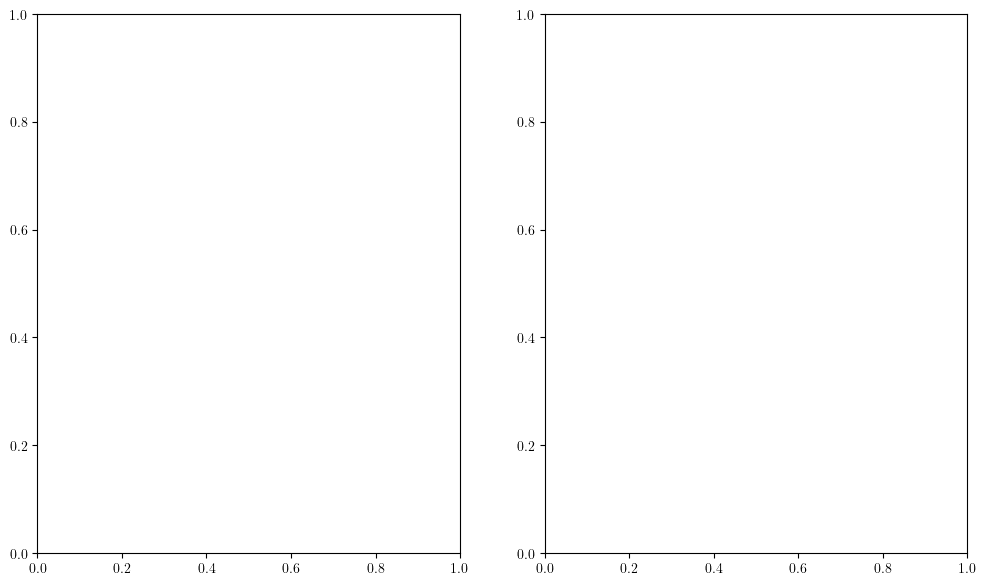

In [131]:
# Plot results
Np = 4

size = 12
fig, ax = plt.subplots(1, 2, figsize=(size,size-5))

# Scientific notation for exponential values
def as_si(x, ndp):
    s = '{x:0.{ndp:d}e}'.format(x=x, ndp=ndp)
    m, e = s.split('e')
    return r'{m:s}\times 10^{{{e:d}}}'.format(m=m, e=int(e))

# Run model with original and calibrated parameters
global RMSE
C_original = y_func(original_values)
RMSE_original = RMSE
C_calibrated = y_func(param_calib)
RMSE_calibrated = RMSE

# Create figure
plt.rcParams['text.usetex'] = True
plt.suptitle("Calibration of 2 model parameters: $q_{max}=\\,$"+"${:.3f}$".format(calibrated_parameters['qmax'])+
             ", $r_p=\\,$"+"${0:s}$".format(as_si(calibrated_parameters['rp'],2)), fontsize=2*size, y=1.02)

# Plot experimental data
ax[0].scatter(texp, Cexp, color='midnightblue', marker='s', s=10*size, label='measured')

# Plot original values
ax[0].plot(texp, C_original, linestyle='--', color='darkorange', linewidth=3, label=f'literature')

# Plot calibrated values
ax[0].plot(texp, C_calibrated, color='green', linewidth=3, label=f'calibrated')

ax[0].set_title('Breakthrough curve', fontsize=2*size)
ax[0].set_xlabel('Time [min]', fontsize=1.5*size)
ax[0].set_ylabel('Concentration, $C/C_0$', fontsize=2*size)
ax[0].tick_params(labelsize=1.5*size)
ax[0].set_xticks(np.linspace(0, 20, int(20/2+1)))
ax[0].set_ylim(0)
# ax2.set_xlim(0, int(max(max(BV), max(texp))))
ax[0].legend(fontsize=1.5*size, loc='lower right')

# Plot residuals
ax[1].set_title('Residuals, $(C_{exp}-C)/C_0$', fontsize=2*size)
ax[1].axhline(0, color='gray', linewidth=1, linestyle='-')
# ax[1].scatter(texp, Cexp-C_original, color='darkorange', marker='s', s=10*size)
# ax[1].scatter(texp, Cexp-C_calibrated, color='green', marker='s', s=10*size)
ax[1].plot(texp, Cexp-C_original, '--', color='darkorange', linewidth=3, label=f'RMSE=${RMSE_original:.4f}$')
ax[1].plot(texp, Cexp-C_calibrated, '-', color='green', linewidth=3, label=f'RMSE=${RMSE_calibrated:.4f}$')
# ax[1].set_ylabel(r'Residuals, $C_{exp}-C$', fontsize=2*size)
ax[1].set_xticks(np.linspace(0, 20, int(20/2+1)))
ax[1].set_xlabel('Time [min]', fontsize=1.5*size)
ax[1].tick_params(labelsize=1.5*size)
ax[1].legend(fontsize=1.5*size, loc='lower right')

# Store results
plt.savefig(f"calibration_Np-{len(param_calib)}.pdf", format="pdf", bbox_inches="tight")
plt.show()

In [230]:
print("Cov = \n", covariance) # covariance matrix
print("Cond = {:.1f}".format(np.linalg.cond(covariance))) # 33216604874189332480.0 ill-conditioned
print("Std = ", np.sqrt(np.diag(covariance))) # array([4.42534217e-06, 3.05849579e-10]) relatively small

# 95% confidence intervals
from scipy import stats
Np = 4
t_estimator = stats.t.ppf((1+0.95)/2, len(Cexp)-Np)
print("Student's t estimator =", "{:.3f}".format(t_estimator))

CI_qmax = t_estimator * np.sqrt(covariance[0,0])
CI_rp = t_estimator * np.sqrt(covariance[1,1])
CI_e = t_estimator * np.sqrt(covariance[2,2])
CI_Kl = t_estimator * np.sqrt(covariance[3,3])

d_qmax = CI_qmax/param_calib[0]*100
d_rp = CI_rp/param_calib[1]*100
d_e = CI_e/param_calib[2]*100
d_Kl = CI_Kl/param_calib[3]*100

print("CI_qmax = {:.3f} ± {:.4f} ({:.1f}%)".format(param_calib[0], CI_qmax, d_qmax))
print("CI_rp = {:.2e} ± {:.2e} ({:.1f}%)".format(param_calib[1], CI_rp, d_rp))
print("CI_e = {:.2f} ± {:.2f} ({:.1f}%)".format(param_calib[2], CI_e, d_e))
print("CI_Kl = {:.2f} ± {:.2f} ({:.1f}%)".format(param_calib[3], CI_Kl, d_Kl))

# SSR
C_calibrated = y_func(texp, *param_calib)
SSR = np.sum((C_calibrated-Cexp)**2)
print("SSR =", SSR)

# RMSE
RMSE = np.sqrt(np.mean((C_calibrated-Cexp)**2))
print("RMSE =", RMSE)

# AIC
N = len(Cexp)
AIC = N * np.log(SSR/N) + 2*Np
print("AIC = {:.1f}".format(AIC))


Cov = 
 [[ 3.20833776e+04  4.33308432e-04  5.93468114e+00 -3.11974183e+07]
 [ 4.33308432e-04  3.08763488e-10 -4.80585376e-08 -4.21326542e-01]
 [ 5.93468114e+00 -4.80585376e-08  5.81715406e-03 -5.77082542e+03]
 [-3.11974183e+07 -4.21326542e-01 -5.77082542e+03  3.03359240e+10]]
Cond = 133980654331960983552.0
Std =  [1.79118334e+02 1.75716672e-05 7.62702698e-02 1.74172110e+05]
Student's t estimator = 2.120
CI_qmax = 0.316 ± 379.7139 (120174.9%)
CI_rp = 4.50e-04 ± 3.73e-05 (8.3%)
CI_e = 0.30 ± 0.16 (53.9%)
CI_Kl = 2.75 ± 369228.38 (13432446.7%)
Run 46: {'qmax': 0.31596773934034783, 'rp': 0.00044995599526990115, 'e': 0.30000000106832875, 'Kl': 2.748779792417809}


9fb2b6 running: t: 6: : 60it [00:03, 19.54it/s]                          


RMSE = 0.0199
SSR = 0.007957434706461238
RMSE = 0.019946722420564784
AIC = -148.6


### Estimate 5 parameters: qmax, Kl, rp, e, Dp

In [97]:
# Define parameter values and bounds

from scipy.optimize import curve_fit, least_squares

parameters=dict(qmax=0.3, Kl=1.2, rp=0.5*7.5e-4, e=0.37, Dp=5.3e-10)

names = [name for name in parameters.keys()]
original_values = [value for value in parameters.values()]

bounds = ([0.1, 1., 0.5*3e-4, 0.3, 0.8*5.3e-10],
          [0.35, 4., 0.5*12e-4, 0.444, 1.2*5.3e-10])

# Define objective function

def y_func(values, ydata=Cexp):
        
    global counter
    counter += 1
    
    # Update parameter value in dictionary
    parameters = dict([(name, value) for name, value in zip(names, values)])

    print(f'Run {counter}: {parameters}')
    
    # Run model with parameter value
    C, y, q, t, BV, z, RMSE = model(
                Nx    = 100,
                dt    = 0.1, 
                tmax  = 6, 
        
                C0 = C0exp,

                isotherm = 'Langmuir',
                profiles = False, 
                breakthrough = False,
                
                **parameters
    )
    
    # Interpolate model for experimental points
    y_int = np.interp(texp, t/60, C)
    
    return ydata - y_int

# Run parameter estimation
counter = 0

p0 = original_values

# popt, _ = curve_fit(y_func, xdata=texp, ydata=Cexp, p0=p0, method='trf', bounds=bounds, max_nfev=50)  # Optimization uses TRF with bounds, see documentation. Trust Region Reflective algorithm,
# param_calib = popt

result = least_squares(y_func, x0=p0, method='trf', ftol=1e-08, xtol=1e-08, gtol=1e-08, x_scale=(0.3, 2.0, 4e-4, 0.3, 5e-10), bounds=bounds,
                       loss='linear', f_scale=1.0, diff_step=None, tr_solver=None, max_nfev=50, verbose=0, args=(),
                        kwargs={'ydata':Cexp})
param_calib = result.x

# Print results
print("Calibration terminated.\n",param_calib)

Run 1: {'qmax': 0.3, 'Kl': 1.2, 'rp': 0.000375, 'e': 0.37, 'Dp': 5.3e-10}


aa03ce running: t: 6: : 60it [00:03, 18.75it/s]                          


RMSE = 0.0494
Run 2: {'qmax': 0.3000000149011612, 'Kl': 1.2, 'rp': 0.000375, 'e': 0.37, 'Dp': 5.3e-10}


1ee9be running: t: 6: : 60it [00:03, 18.52it/s]                          


RMSE = 0.0494
Run 3: {'qmax': 0.3, 'Kl': 1.2000000178813934, 'rp': 0.000375, 'e': 0.37, 'Dp': 5.3e-10}


71a2b4 running: t: 6: : 60it [00:02, 21.23it/s]                          


RMSE = 0.0494
Run 4: {'qmax': 0.3, 'Kl': 1.2, 'rp': 0.00037501490116119386, 'e': 0.37, 'Dp': 5.3e-10}


49185b running: t: 6: : 60it [00:02, 21.12it/s]                          


RMSE = 0.0494
Run 5: {'qmax': 0.3, 'Kl': 1.2, 'rp': 0.000375, 'e': 0.3700000149011612, 'Dp': 5.3e-10}


038b90 running: t: 6: : 60it [00:02, 21.63it/s]                          


RMSE = 0.0494
Run 6: {'qmax': 0.3, 'Kl': 1.2, 'rp': 0.000375, 'e': 0.37, 'Dp': 4.2400000000000004e-10}


351e1c running: t: 6: : 60it [00:02, 21.66it/s]                          


RMSE = 0.0470
Run 7: {'qmax': 0.31084915455881984, 'Kl': 1.8075482452465153, 'rp': 0.0004285452225163141, 'e': 0.3839851941433946, 'Dp': 5.02785823377802e-10}


156d0e running: t: 6: : 60it [00:02, 20.93it/s]                          


RMSE = 0.0243
Run 8: {'qmax': 0.31084916945998103, 'Kl': 1.8075482452465153, 'rp': 0.0004285452225163141, 'e': 0.3839851941433946, 'Dp': 5.02785823377802e-10}


649148 running: t: 6: : 60it [00:02, 22.05it/s]                          


RMSE = 0.0243
Run 9: {'qmax': 0.31084915455881984, 'Kl': 1.807548272181083, 'rp': 0.0004285452225163141, 'e': 0.3839851941433946, 'Dp': 5.02785823377802e-10}


0d7a4d running: t: 6: : 60it [00:02, 21.97it/s]                          


RMSE = 0.0243
Run 10: {'qmax': 0.31084915455881984, 'Kl': 1.8075482452465153, 'rp': 0.00042856012367750794, 'e': 0.3839851941433946, 'Dp': 5.02785823377802e-10}


ec6dda running: t: 6: : 60it [00:02, 22.12it/s]                          


RMSE = 0.0243
Run 11: {'qmax': 0.31084915455881984, 'Kl': 1.8075482452465153, 'rp': 0.0004285452225163141, 'e': 0.3839852090445558, 'Dp': 5.02785823377802e-10}


63f2f8 running: t: 6: : 60it [00:02, 21.52it/s]                          


RMSE = 0.0243
Run 12: {'qmax': 0.31084915455881984, 'Kl': 1.8075482452465153, 'rp': 0.0004285452225163141, 'e': 0.3839851941433946, 'Dp': 6.36e-10}


4c8eef running: t: 6: : 60it [00:02, 21.96it/s]                          


RMSE = 0.0257
Run 13: {'qmax': 0.31393786700537535, 'Kl': 1.9805273371775542, 'rp': 0.00041343450946437196, 'e': 0.397108817720878, 'Dp': 4.2556032254025616e-10}


49e0df running: t: 6: : 60it [00:02, 21.91it/s]                          


RMSE = 0.0207
Run 14: {'qmax': 0.31393788190653654, 'Kl': 1.9805273371775542, 'rp': 0.00041343450946437196, 'e': 0.397108817720878, 'Dp': 4.2556032254025616e-10}


4ff5a4 running: t: 6: : 60it [00:07,  8.00it/s]                          


RMSE = 0.0207
Run 15: {'qmax': 0.31393786700537535, 'Kl': 1.9805273666897114, 'rp': 0.00041343450946437196, 'e': 0.397108817720878, 'Dp': 4.2556032254025616e-10}


2cfb12 running: t: 6: : 60it [00:02, 21.46it/s]                          


RMSE = 0.0207
Run 16: {'qmax': 0.31393786700537535, 'Kl': 1.9805273371775542, 'rp': 0.0004134494106255658, 'e': 0.397108817720878, 'Dp': 4.2556032254025616e-10}


4c030e running: t: 6: : 60it [00:02, 20.19it/s]                          


RMSE = 0.0207
Run 17: {'qmax': 0.31393786700537535, 'Kl': 1.9805273371775542, 'rp': 0.00041343450946437196, 'e': 0.3971088326220392, 'Dp': 4.2556032254025616e-10}


f9359e running: t: 6: : 60it [00:02, 21.91it/s]                          


RMSE = 0.0207
Run 18: {'qmax': 0.31393786700537535, 'Kl': 1.9805273371775542, 'rp': 0.00041343450946437196, 'e': 0.397108817720878, 'Dp': 6.36e-10}


356d9e running: t: 6: : 60it [00:02, 21.61it/s]                          


RMSE = 0.0236
Run 19: {'qmax': 0.31389567248403294, 'Kl': 1.9781898484553275, 'rp': 0.00041001036864863694, 'e': 0.39387289068300047, 'Dp': 4.3639497611563267e-10}


6e1e06 running: t: 6: : 60it [00:02, 21.31it/s]                          


RMSE = 0.0206
Run 20: {'qmax': 0.31389568738519413, 'Kl': 1.9781898484553275, 'rp': 0.00041001036864863694, 'e': 0.39387289068300047, 'Dp': 4.3639497611563267e-10}


130b50 running: t: 6: : 60it [00:02, 21.92it/s]                          


RMSE = 0.0206
Run 21: {'qmax': 0.31389567248403294, 'Kl': 1.9781898779326534, 'rp': 0.00041001036864863694, 'e': 0.39387289068300047, 'Dp': 4.3639497611563267e-10}


6db9c6 running: t: 6: : 60it [00:02, 21.79it/s]                          


RMSE = 0.0206
Run 22: {'qmax': 0.31389567248403294, 'Kl': 1.9781898484553275, 'rp': 0.0004100252698098308, 'e': 0.39387289068300047, 'Dp': 4.3639497611563267e-10}


d31d1f running: t: 6: : 60it [00:02, 21.64it/s]                          


RMSE = 0.0206
Run 23: {'qmax': 0.31389567248403294, 'Kl': 1.9781898484553275, 'rp': 0.00041001036864863694, 'e': 0.39387290558416166, 'Dp': 4.3639497611563267e-10}


56fd84 running: t: 6: : 60it [00:02, 21.54it/s]                          


RMSE = 0.0206
Run 24: {'qmax': 0.31389567248403294, 'Kl': 1.9781898484553275, 'rp': 0.00041001036864863694, 'e': 0.39387289068300047, 'Dp': 6.36e-10}


b8e47a running: t: 6: : 60it [00:02, 21.68it/s]                          


RMSE = 0.0240
Run 25: {'qmax': 0.3152294306437867, 'Kl': 2.052851597777887, 'rp': 0.00041785594275088367, 'e': 0.33451253221155886, 'Dp': 4.252008713781823e-10}


3424b1 running: t: 6: : 60it [00:02, 20.49it/s]                          


RMSE = 0.0200
Run 26: {'qmax': 0.3152294455449479, 'Kl': 2.052851597777887, 'rp': 0.00041785594275088367, 'e': 0.33451253221155886, 'Dp': 4.252008713781823e-10}


e4c0b1 running: t: 6: : 60it [00:02, 21.00it/s]                          


RMSE = 0.0200
Run 27: {'qmax': 0.3152294306437867, 'Kl': 2.0528516283677596, 'rp': 0.00041785594275088367, 'e': 0.33451253221155886, 'Dp': 4.252008713781823e-10}


ba161b running: t: 6: : 60it [00:02, 22.12it/s]                          


RMSE = 0.0200
Run 28: {'qmax': 0.3152294306437867, 'Kl': 2.052851597777887, 'rp': 0.0004178708439120775, 'e': 0.33451253221155886, 'Dp': 4.252008713781823e-10}


34c642 running: t: 6: : 60it [00:02, 20.85it/s]                          


RMSE = 0.0200
Run 29: {'qmax': 0.3152294306437867, 'Kl': 2.052851597777887, 'rp': 0.00041785594275088367, 'e': 0.33451254711272005, 'Dp': 4.252008713781823e-10}


4eec2d running: t: 6: : 60it [00:02, 21.23it/s]                          


RMSE = 0.0200
Run 30: {'qmax': 0.3152294306437867, 'Kl': 2.052851597777887, 'rp': 0.00041785594275088367, 'e': 0.33451253221155886, 'Dp': 6.36e-10}


8efd41 running: t: 6: : 60it [00:02, 21.29it/s]                          


RMSE = 0.0244
Run 31: {'qmax': 0.31540892814130916, 'Kl': 2.053617637451712, 'rp': 0.000417481053570854, 'e': 0.31372536895562925, 'Dp': 4.3014883369867526e-10}


85d6e4 running: t: 6: : 60it [00:02, 21.24it/s]                          


RMSE = 0.0198
Run 32: {'qmax': 0.31540894304247036, 'Kl': 2.053617637451712, 'rp': 0.000417481053570854, 'e': 0.31372536895562925, 'Dp': 4.3014883369867526e-10}


1ad30f running: t: 6: : 60it [00:02, 21.69it/s]                          


RMSE = 0.0198
Run 33: {'qmax': 0.31540892814130916, 'Kl': 2.053617668052999, 'rp': 0.000417481053570854, 'e': 0.31372536895562925, 'Dp': 4.3014883369867526e-10}


c694a1 running: t: 6: : 60it [00:02, 21.54it/s]                          


RMSE = 0.0198
Run 34: {'qmax': 0.31540892814130916, 'Kl': 2.053617637451712, 'rp': 0.00041749595473204785, 'e': 0.31372536895562925, 'Dp': 4.3014883369867526e-10}


0fe387 running: t: 6: : 60it [00:02, 21.93it/s]                          


RMSE = 0.0198
Run 35: {'qmax': 0.31540892814130916, 'Kl': 2.053617637451712, 'rp': 0.000417481053570854, 'e': 0.31372538385679044, 'Dp': 4.3014883369867526e-10}


a7e554 running: t: 6: : 60it [00:02, 21.54it/s]                          


RMSE = 0.0198
Run 36: {'qmax': 0.31540892814130916, 'Kl': 2.053617637451712, 'rp': 0.000417481053570854, 'e': 0.31372536895562925, 'Dp': 6.36e-10}


7bafc7 running: t: 6: : 60it [00:02, 21.57it/s]                          


RMSE = 0.0251
Run 37: {'qmax': 0.31573668532010557, 'Kl': 2.0551959112611926, 'rp': 0.0004219525903750449, 'e': 0.30086752395821015, 'Dp': 4.282877575914324e-10}


091658 running: t: 6: : 60it [00:02, 22.03it/s]                          


RMSE = 0.0197
Run 38: {'qmax': 0.31573670022126676, 'Kl': 2.0551959112611926, 'rp': 0.0004219525903750449, 'e': 0.30086752395821015, 'Dp': 4.282877575914324e-10}


6b25b1 running: t: 6: : 60it [00:02, 21.32it/s]                          


RMSE = 0.0197
Run 39: {'qmax': 0.31573668532010557, 'Kl': 2.055195941885998, 'rp': 0.0004219525903750449, 'e': 0.30086752395821015, 'Dp': 4.282877575914324e-10}


1f1c06 running: t: 6: : 60it [00:02, 21.52it/s]                          


RMSE = 0.0197
Run 40: {'qmax': 0.31573668532010557, 'Kl': 2.0551959112611926, 'rp': 0.0004219674915362387, 'e': 0.30086752395821015, 'Dp': 4.282877575914324e-10}


99b42c running: t: 6: : 60it [00:02, 21.10it/s]                          


RMSE = 0.0197
Run 41: {'qmax': 0.31573668532010557, 'Kl': 2.0551959112611926, 'rp': 0.0004219525903750449, 'e': 0.30086753885937134, 'Dp': 4.282877575914324e-10}


79ccf1 running: t: 6: : 60it [00:02, 21.52it/s]                          


RMSE = 0.0197
Run 42: {'qmax': 0.31573668532010557, 'Kl': 2.0551959112611926, 'rp': 0.0004219525903750449, 'e': 0.30086752395821015, 'Dp': 6.36e-10}


bc81ac running: t: 6: : 60it [00:02, 21.27it/s]                          


RMSE = 0.0247
Run 43: {'qmax': 0.31555038995476087, 'Kl': 2.0542809801955104, 'rp': 0.00042081195285689267, 'e': 0.30962605615137734, 'Dp': 4.2560358785454596e-10}


b9c593 running: t: 6: : 60it [00:02, 20.95it/s]                          


RMSE = 0.0197
Run 44: {'qmax': 0.3156448024312103, 'Kl': 2.055188362730674, 'rp': 0.0004219902645723344, 'e': 0.3045595730732638, 'Dp': 4.2818121501361684e-10}


a7abde running: t: 6: : 60it [00:02, 20.37it/s]                          


RMSE = 0.0197
Run 45: {'qmax': 0.3156782123756103, 'Kl': 2.0551922115453714, 'rp': 0.0004222309106861133, 'e': 0.30176766113769843, 'Dp': 4.282686071360962e-10}


45564b running: t: 6: : 60it [00:02, 21.00it/s]                          


RMSE = 0.0197
Run 46: {'qmax': 0.3156782272767715, 'Kl': 2.0551922115453714, 'rp': 0.0004222309106861133, 'e': 0.30176766113769843, 'Dp': 4.282686071360962e-10}


b9ea1f running: t: 6: : 60it [00:02, 20.44it/s]                          


RMSE = 0.0197
Run 47: {'qmax': 0.3156782123756103, 'Kl': 2.0551922421701216, 'rp': 0.0004222309106861133, 'e': 0.30176766113769843, 'Dp': 4.282686071360962e-10}


bae8c9 running: t: 6: : 60it [00:02, 22.14it/s]                          


RMSE = 0.0197
Run 48: {'qmax': 0.3156782123756103, 'Kl': 2.0551922115453714, 'rp': 0.0004222458118473072, 'e': 0.30176766113769843, 'Dp': 4.282686071360962e-10}


c58758 running: t: 6: : 60it [00:02, 21.53it/s]                          


RMSE = 0.0197
Run 49: {'qmax': 0.3156782123756103, 'Kl': 2.0551922115453714, 'rp': 0.0004222309106861133, 'e': 0.3017676760388596, 'Dp': 4.282686071360962e-10}


f85e98 running: t: 6: : 60it [00:02, 21.50it/s]                          


RMSE = 0.0197
Run 50: {'qmax': 0.3156782123756103, 'Kl': 2.0551922115453714, 'rp': 0.0004222309106861133, 'e': 0.30176766113769843, 'Dp': 6.36e-10}


ff0a65 running: t: 6: : 60it [00:02, 21.13it/s]                          


RMSE = 0.0247
Run 51: {'qmax': 0.31566957684282854, 'Kl': 2.0551915923522697, 'rp': 0.00042227997528122445, 'e': 0.3036206228527658, 'Dp': 4.282468079246714e-10}


c83904 running: t: 6: : 60it [00:02, 21.37it/s]                          


RMSE = 0.0197
Run 52: {'qmax': 0.3156770121609799, 'Kl': 2.055192117382003, 'rp': 0.00042229469442190207, 'e': 0.30222839143103886, 'Dp': 4.2826329495565746e-10}


174f72 running: t: 6: : 60it [00:02, 20.95it/s]                          


RMSE = 0.0197
Run 53: {'qmax': 0.31567702706214107, 'Kl': 2.055192117382003, 'rp': 0.00042229469442190207, 'e': 0.30222839143103886, 'Dp': 4.2826329495565746e-10}


ab8f77 running: t: 6: : 60it [00:02, 22.06it/s]                          


RMSE = 0.0197
Run 54: {'qmax': 0.3156770121609799, 'Kl': 2.055192148006752, 'rp': 0.00042229469442190207, 'e': 0.30222839143103886, 'Dp': 4.2826329495565746e-10}


ab6ce4 running: t: 6: : 60it [00:02, 21.02it/s]                          


RMSE = 0.0197
Run 55: {'qmax': 0.3156770121609799, 'Kl': 2.055192117382003, 'rp': 0.0004223095955830959, 'e': 0.30222839143103886, 'Dp': 4.2826329495565746e-10}


1bf948 running: t: 6: : 60it [00:03, 19.30it/s]                          


RMSE = 0.0197
Run 56: {'qmax': 0.3156770121609799, 'Kl': 2.055192117382003, 'rp': 0.00042229469442190207, 'e': 0.30222840633220005, 'Dp': 4.2826329495565746e-10}


036ec3 running: t: 6: : 60it [00:02, 21.09it/s]                          


RMSE = 0.0197
Run 57: {'qmax': 0.3156770121609799, 'Kl': 2.055192117382003, 'rp': 0.00042229469442190207, 'e': 0.30222839143103886, 'Dp': 6.36e-10}


a0fb55 running: t: 6: : 60it [00:02, 21.47it/s]                          


RMSE = 0.0246
Run 58: {'qmax': 0.31567502209774906, 'Kl': 2.0551920374430765, 'rp': 0.0004222980907075028, 'e': 0.3026913524198771, 'Dp': 4.2825983320860237e-10}


f4b024 running: t: 6: : 60it [00:02, 21.25it/s]                          


RMSE = 0.0197
Run 59: {'qmax': 0.31567575321747837, 'Kl': 2.0551920517928344, 'rp': 0.0004223013553268334, 'e': 0.3023440119272969, 'Dp': 4.2826240917741537e-10}


aa925f running: t: 6: : 60it [00:02, 21.23it/s]                          


RMSE = 0.0197
Run 60: {'qmax': 0.31567576811863957, 'Kl': 2.0551920517928344, 'rp': 0.0004223013553268334, 'e': 0.3023440119272969, 'Dp': 4.2826240917741537e-10}


298df9 running: t: 6: : 60it [00:02, 21.80it/s]                          


RMSE = 0.0197
Run 61: {'qmax': 0.31567575321747837, 'Kl': 2.0551920824175824, 'rp': 0.0004223013553268334, 'e': 0.3023440119272969, 'Dp': 4.2826240917741537e-10}


740423 running: t: 6: : 60it [00:02, 21.82it/s]                          


RMSE = 0.0197
Run 62: {'qmax': 0.31567575321747837, 'Kl': 2.0551920517928344, 'rp': 0.00042231625648802727, 'e': 0.3023440119272969, 'Dp': 4.2826240917741537e-10}


91d35b running: t: 6: : 60it [00:02, 20.98it/s]                          


RMSE = 0.0197
Run 63: {'qmax': 0.31567575321747837, 'Kl': 2.0551920517928344, 'rp': 0.0004223013553268334, 'e': 0.30234402682845807, 'Dp': 4.2826240917741537e-10}


777ec9 running: t: 6: : 60it [00:02, 21.66it/s]                          


RMSE = 0.0197
Run 64: {'qmax': 0.31567575321747837, 'Kl': 2.0551920517928344, 'rp': 0.0004223013553268334, 'e': 0.3023440119272969, 'Dp': 6.36e-10}


020cd6 running: t: 6: : 60it [00:02, 20.80it/s]                          


RMSE = 0.0246
Run 65: {'qmax': 0.31567547034129845, 'Kl': 2.0551920598546576, 'rp': 0.0004223057314292977, 'e': 0.3025753867356264, 'Dp': 4.282607360866146e-10}


d7c864 running: t: 6: : 60it [00:02, 21.12it/s]                          


RMSE = 0.0197
Run 66: {'qmax': 0.3156755706660527, 'Kl': 2.0551920470712126, 'rp': 0.0004223039527099627, 'e': 0.3024018259458767, 'Dp': 4.2826198515331946e-10}


d14151 running: t: 6: : 60it [00:02, 21.95it/s]                          


RMSE = 0.0197
Run 67: {'qmax': 0.3156756076576597, 'Kl': 2.05519204465334, 'rp': 0.0004223021204697581, 'e': 0.3023584615437312, 'Dp': 4.2826230272202024e-10}


10122b running: t: 6: : 60it [00:02, 21.23it/s]                          


RMSE = 0.0197
Run 68: {'qmax': 0.31567562255882087, 'Kl': 2.05519204465334, 'rp': 0.0004223021204697581, 'e': 0.3023584615437312, 'Dp': 4.2826230272202024e-10}


06096f running: t: 6: : 60it [00:02, 21.55it/s]                          


RMSE = 0.0197
Run 69: {'qmax': 0.3156756076576597, 'Kl': 2.055192075278088, 'rp': 0.0004223021204697581, 'e': 0.3023584615437312, 'Dp': 4.2826230272202024e-10}


d7e910 running: t: 6: : 60it [00:02, 20.34it/s]                          


RMSE = 0.0197
Run 70: {'qmax': 0.3156756076576597, 'Kl': 2.05519204465334, 'rp': 0.00042231702163095193, 'e': 0.3023584615437312, 'Dp': 4.2826230272202024e-10}


1214c6 running: t: 6: : 60it [00:02, 21.65it/s]                          


RMSE = 0.0197
Run 71: {'qmax': 0.3156756076576597, 'Kl': 2.05519204465334, 'rp': 0.0004223021204697581, 'e': 0.3023584764448924, 'Dp': 4.2826230272202024e-10}


bbfbd0 running: t: 6: : 60it [00:10,  5.80it/s]                          


RMSE = 0.0197
Run 72: {'qmax': 0.3156756076576597, 'Kl': 2.05519204465334, 'rp': 0.0004223021204697581, 'e': 0.3023584615437312, 'Dp': 6.36e-10}


30128b running: t: 6: : 60it [00:03, 16.21it/s]                          


RMSE = 0.0246
Run 73: {'qmax': 0.31567553108727847, 'Kl': 2.055192043078414, 'rp': 0.00042230348153655614, 'e': 0.30238736549300493, 'Dp': 4.2826209141136475e-10}


ae67c0 running: t: 6: : 60it [00:03, 17.86it/s]                          


RMSE = 0.0197
Run 74: {'qmax': 0.31567555707131567, 'Kl': 2.0551920423847783, 'rp': 0.00042230249029356594, 'e': 0.3023656865464113, 'Dp': 4.282622497796881e-10}


da1894 running: t: 6: : 60it [00:03, 19.45it/s]                          


RMSE = 0.0197
Run 75: {'qmax': 0.31567557197247686, 'Kl': 2.0551920423847783, 'rp': 0.00042230249029356594, 'e': 0.3023656865464113, 'Dp': 4.282622497796881e-10}


8995c3 running: t: 6: : 60it [00:03, 18.93it/s]                          


RMSE = 0.0197
Run 76: {'qmax': 0.31567555707131567, 'Kl': 2.0551920730095263, 'rp': 0.00042230249029356594, 'e': 0.3023656865464113, 'Dp': 4.282622497796881e-10}


ce1494 running: t: 6: : 60it [00:02, 20.39it/s]                          


RMSE = 0.0197
Run 77: {'qmax': 0.31567555707131567, 'Kl': 2.0551920423847783, 'rp': 0.0004223173914547598, 'e': 0.3023656865464113, 'Dp': 4.282622497796881e-10}


9f2c09 running: t: 6: : 60it [00:02, 20.88it/s]                          


RMSE = 0.0197
Run 78: {'qmax': 0.31567555707131567, 'Kl': 2.0551920423847783, 'rp': 0.00042230249029356594, 'e': 0.3023657014475725, 'Dp': 4.282622497796881e-10}


3de368 running: t: 6: : 60it [00:02, 20.95it/s]                          


RMSE = 0.0197
Run 79: {'qmax': 0.31567555707131567, 'Kl': 2.0551920423847783, 'rp': 0.00042230249029356594, 'e': 0.3023656865464113, 'Dp': 6.36e-10}


ff36d3 running: t: 6: : 60it [00:02, 21.16it/s]                          


RMSE = 0.0246
Run 80: {'qmax': 0.31567564399818737, 'Kl': 2.055192052192207, 'rp': 0.00042230632190166906, 'e': 0.30236490511440905, 'Dp': 4.282616573734644e-10}


1cc96b running: t: 6: : 60it [00:02, 21.26it/s]                          


RMSE = 0.0197
Run 81: {'qmax': 0.31567565889934857, 'Kl': 2.055192052192207, 'rp': 0.00042230632190166906, 'e': 0.30236490511440905, 'Dp': 4.282616573734644e-10}


2f0585 running: t: 6: : 60it [00:02, 20.08it/s]                          


RMSE = 0.0197
Run 82: {'qmax': 0.31567564399818737, 'Kl': 2.055192082816955, 'rp': 0.00042230632190166906, 'e': 0.30236490511440905, 'Dp': 4.282616573734644e-10}


785a37 running: t: 6: : 60it [00:02, 21.86it/s]                          


RMSE = 0.0197
Run 83: {'qmax': 0.31567564399818737, 'Kl': 2.055192052192207, 'rp': 0.0004223212230628629, 'e': 0.30236490511440905, 'Dp': 4.282616573734644e-10}


45dcb3 running: t: 6: : 60it [00:02, 21.74it/s]                          


RMSE = 0.0197
Run 84: {'qmax': 0.31567564399818737, 'Kl': 2.055192052192207, 'rp': 0.00042230632190166906, 'e': 0.30236492001557025, 'Dp': 4.282616573734644e-10}


b94375 running: t: 6: : 60it [00:02, 21.43it/s]                          


RMSE = 0.0197
Run 85: {'qmax': 0.31567564399818737, 'Kl': 2.055192052192207, 'rp': 0.00042230632190166906, 'e': 0.30236490511440905, 'Dp': 6.36e-10}


cf21c2 running: t: 6: : 60it [00:02, 20.82it/s]                          


RMSE = 0.0246
Run 86: {'qmax': 0.31567598971485367, 'Kl': 2.055192075531111, 'rp': 0.00042231316936033485, 'e': 0.3023633097034708, 'Dp': 4.2826045557321216e-10}


c46999 running: t: 6: : 60it [00:02, 20.95it/s]                          


RMSE = 0.0197
Run 87: {'qmax': 0.31567600461601486, 'Kl': 2.055192075531111, 'rp': 0.00042231316936033485, 'e': 0.3023633097034708, 'Dp': 4.2826045557321216e-10}


9274e4 running: t: 6: : 60it [00:02, 21.40it/s]                          


RMSE = 0.0197
Run 88: {'qmax': 0.31567598971485367, 'Kl': 2.0551921061558596, 'rp': 0.00042231316936033485, 'e': 0.3023633097034708, 'Dp': 4.2826045557321216e-10}


d6a416 running: t: 6: : 60it [00:02, 20.81it/s]                          


RMSE = 0.0197
Run 89: {'qmax': 0.31567598971485367, 'Kl': 2.055192075531111, 'rp': 0.0004223280705215287, 'e': 0.3023633097034708, 'Dp': 4.2826045557321216e-10}


86fe5f running: t: 6: : 60it [00:02, 21.36it/s]                          


RMSE = 0.0197
Run 90: {'qmax': 0.31567598971485367, 'Kl': 2.055192075531111, 'rp': 0.00042231316936033485, 'e': 0.302363324604632, 'Dp': 4.2826045557321216e-10}


0116fe running: t: 6: : 60it [00:02, 21.38it/s]                          


RMSE = 0.0197
Run 91: {'qmax': 0.31567598971485367, 'Kl': 2.055192075531111, 'rp': 0.00042231316936033485, 'e': 0.3023633097034708, 'Dp': 6.36e-10}


f558c7 running: t: 6: : 60it [00:02, 21.11it/s]                          


RMSE = 0.0246
Run 92: {'qmax': 0.31567656684179674, 'Kl': 2.055192103511659, 'rp': 0.00042232409257334685, 'e': 0.3023600258180797, 'Dp': 4.2825800725925047e-10}


458990 running: t: 6: : 60it [00:02, 21.18it/s]                          


RMSE = 0.0197
Run 93: {'qmax': 0.31567613210807705, 'Kl': 2.0551920824452496, 'rp': 0.0004223164054240486, 'e': 0.3023625051580855, 'Dp': 4.28259851815751e-10}


1d30c6 running: t: 6: : 60it [00:02, 21.75it/s]                          


RMSE = 0.0197
Run 94: {'qmax': 0.31567614700923824, 'Kl': 2.0551920824452496, 'rp': 0.0004223164054240486, 'e': 0.3023625051580855, 'Dp': 4.28259851815751e-10}


2babb3 running: t: 6: : 60it [00:02, 20.38it/s]                          


RMSE = 0.0197
Run 95: {'qmax': 0.31567613210807705, 'Kl': 2.055192113069998, 'rp': 0.0004223164054240486, 'e': 0.3023625051580855, 'Dp': 4.28259851815751e-10}


2e7cd2 running: t: 6: : 60it [00:02, 21.36it/s]                          


RMSE = 0.0197
Run 96: {'qmax': 0.31567613210807705, 'Kl': 2.0551920824452496, 'rp': 0.00042233130658524246, 'e': 0.3023625051580855, 'Dp': 4.28259851815751e-10}


fa2c09 running: t: 6: : 60it [00:02, 21.44it/s]                          


RMSE = 0.0197
Run 97: {'qmax': 0.31567613210807705, 'Kl': 2.0551920824452496, 'rp': 0.0004223164054240486, 'e': 0.3023625200592467, 'Dp': 4.28259851815751e-10}


c7b590 running: t: 6: : 60it [00:02, 20.74it/s]                          


RMSE = 0.0197
Run 98: {'qmax': 0.31567613210807705, 'Kl': 2.0551920824452496, 'rp': 0.0004223164054240486, 'e': 0.3023625051580855, 'Dp': 6.36e-10}


6b73ea running: t: 6: : 60it [00:02, 20.75it/s]                          


RMSE = 0.0246
Run 99: {'qmax': 0.31567613289917834, 'Kl': 2.0551920822431047, 'rp': 0.0004223166785194992, 'e': 0.3023697328334062, 'Dp': 4.2825979949166444e-10}


8838a3 running: t: 6: : 60it [00:02, 22.16it/s]                          


RMSE = 0.0197
Run 100: {'qmax': 0.3156761321922979, 'Kl': 2.055192082352243, 'rp': 0.00042231647540354504, 'e': 0.30236431203695185, 'Dp': 4.282598387278826e-10}


3c05df running: t: 6: : 60it [00:02, 21.99it/s]                          


RMSE = 0.0197
Run 101: {'qmax': 0.31567613212103074, 'Kl': 2.0551920824189676, 'rp': 0.0004223164230264897, 'e': 0.30236295687524267, 'Dp': 4.2825984854335245e-10}


23fdcd running: t: 6: : 60it [00:03, 17.42it/s]                          


RMSE = 0.0197
Run 102: {'qmax': 0.31567614702219193, 'Kl': 2.0551920824189676, 'rp': 0.0004223164230264897, 'e': 0.30236295687524267, 'Dp': 4.2825984854335245e-10}


dcaa97 running: t: 6: : 60it [00:02, 20.55it/s]                          


RMSE = 0.0197
Run 103: {'qmax': 0.31567613212103074, 'Kl': 2.055192113043716, 'rp': 0.0004223164230264897, 'e': 0.30236295687524267, 'Dp': 4.2825984854335245e-10}


9f77bd running: t: 6: : 60it [00:02, 20.20it/s]                          


RMSE = 0.0197
Run 104: {'qmax': 0.31567613212103074, 'Kl': 2.0551920824189676, 'rp': 0.00042233132418768355, 'e': 0.30236295687524267, 'Dp': 4.2825984854335245e-10}


8de001 running: t: 6: : 60it [00:02, 21.24it/s]                          


RMSE = 0.0197
Run 105: {'qmax': 0.31567613212103074, 'Kl': 2.0551920824189676, 'rp': 0.0004223164230264897, 'e': 0.30236297177640387, 'Dp': 4.2825984854335245e-10}


b94dd2 running: t: 6: : 60it [00:02, 22.88it/s]                          


RMSE = 0.0197
Run 106: {'qmax': 0.31567613212103074, 'Kl': 2.0551920824189676, 'rp': 0.0004223164230264897, 'e': 0.30236295687524267, 'Dp': 6.36e-10}


390f1c running: t: 6: : 60it [00:02, 21.63it/s]                          


RMSE = 0.0246
Run 107: {'qmax': 0.3156761328546651, 'Kl': 2.0551920823180208, 'rp': 0.0004223166248166846, 'e': 0.30236290656689435, 'Dp': 4.282598108162053e-10}


7178a1 running: t: 6: : 60it [00:02, 21.31it/s]                          


RMSE = 0.0197
Run 108: {'qmax': 0.3156761477558263, 'Kl': 2.0551920823180208, 'rp': 0.0004223166248166846, 'e': 0.30236290656689435, 'Dp': 4.282598108162053e-10}


688fcc running: t: 6: : 60it [00:02, 20.60it/s]                          


RMSE = 0.0197
Run 109: {'qmax': 0.3156761328546651, 'Kl': 2.0551921129427693, 'rp': 0.0004223166248166846, 'e': 0.30236290656689435, 'Dp': 4.282598108162053e-10}


ece14f running: t: 6: : 60it [00:02, 22.74it/s]                          


RMSE = 0.0197
Run 110: {'qmax': 0.3156761328546651, 'Kl': 2.0551920823180208, 'rp': 0.00042233152597787846, 'e': 0.30236290656689435, 'Dp': 4.282598108162053e-10}


c1193e running: t: 6: : 60it [00:02, 22.84it/s]                          


RMSE = 0.0197
Run 111: {'qmax': 0.3156761328546651, 'Kl': 2.0551920823180208, 'rp': 0.0004223166248166846, 'e': 0.30236292146805555, 'Dp': 4.282598108162053e-10}


de56c6 running: t: 6: : 60it [00:02, 22.81it/s]                          


RMSE = 0.0197
Run 112: {'qmax': 0.3156761328546651, 'Kl': 2.0551920823180208, 'rp': 0.0004223166248166846, 'e': 0.30236290656689435, 'Dp': 6.36e-10}


29caf8 running: t: 6: : 60it [00:02, 23.57it/s]                          


RMSE = 0.0246
Run 113: {'qmax': 0.31567613642665476, 'Kl': 2.0551920843994322, 'rp': 0.0004223170245757226, 'e': 0.302362805820113, 'Dp': 4.2825973529308e-10}


b0d6b0 running: t: 6: : 60it [00:02, 22.23it/s]                          


RMSE = 0.0197
Run 114: {'qmax': 0.31567615132781596, 'Kl': 2.0551920843994322, 'rp': 0.0004223170245757226, 'e': 0.302362805820113, 'Dp': 4.2825973529308e-10}


4bae22 running: t: 6: : 60it [00:02, 22.51it/s]                          


RMSE = 0.0197
Run 115: {'qmax': 0.31567613642665476, 'Kl': 2.0551921150241808, 'rp': 0.0004223170245757226, 'e': 0.302362805820113, 'Dp': 4.2825973529308e-10}


833206 running: t: 6: : 60it [00:02, 22.25it/s]                          


RMSE = 0.0197
Run 116: {'qmax': 0.31567613642665476, 'Kl': 2.0551920843994322, 'rp': 0.00042233192573691645, 'e': 0.302362805820113, 'Dp': 4.2825973529308e-10}


4e6ca9 running: t: 6: : 60it [00:02, 22.72it/s]                          


RMSE = 0.0197
Run 117: {'qmax': 0.31567613642665476, 'Kl': 2.0551920843994322, 'rp': 0.0004223170245757226, 'e': 0.3023628207212742, 'Dp': 4.2825973529308e-10}


7cc29f running: t: 6: : 60it [00:02, 22.09it/s]                          


RMSE = 0.0197
Run 118: {'qmax': 0.31567613642665476, 'Kl': 2.0551920843994322, 'rp': 0.0004223170245757226, 'e': 0.302362805820113, 'Dp': 6.36e-10}


0db69e running: t: 6: : 60it [00:02, 22.14it/s]                          


RMSE = 0.0246
Run 119: {'qmax': 0.31567615025353574, 'Kl': 2.0551920931050365, 'rp': 0.0004223178095120815, 'e': 0.30236260384563934, 'Dp': 4.2825958399980607e-10}


036a72 running: t: 6: : 60it [00:02, 22.26it/s]                          


RMSE = 0.0197
Run 120: {'qmax': 0.315676138598232, 'Kl': 2.055192085689341, 'rp': 0.0004223172236179956, 'e': 0.3023627554189117, 'Dp': 4.282596975193522e-10}


59cd69 running: t: 6: : 60it [00:02, 22.35it/s]                          


RMSE = 0.0197
Run 121: {'qmax': 0.3156761534993932, 'Kl': 2.055192085689341, 'rp': 0.0004223172236179956, 'e': 0.3023627554189117, 'Dp': 4.282596975193522e-10}


f0b718 running: t: 6: : 60it [00:02, 21.63it/s]                          


RMSE = 0.0197
Run 122: {'qmax': 0.315676138598232, 'Kl': 2.0551921163140894, 'rp': 0.0004223172236179956, 'e': 0.3023627554189117, 'Dp': 4.282596975193522e-10}


d9254e running: t: 6: : 60it [00:02, 22.33it/s]                          


RMSE = 0.0197
Run 123: {'qmax': 0.315676138598232, 'Kl': 2.055192085689341, 'rp': 0.00042233212477918946, 'e': 0.3023627554189117, 'Dp': 4.282596975193522e-10}


f9b8ef running: t: 6: : 60it [00:02, 22.51it/s]                          


RMSE = 0.0197
Run 124: {'qmax': 0.315676138598232, 'Kl': 2.055192085689341, 'rp': 0.0004223172236179956, 'e': 0.3023627703200729, 'Dp': 4.282596975193522e-10}


a05bff running: t: 6: : 60it [00:02, 21.81it/s]                          


RMSE = 0.0197
Run 125: {'qmax': 0.315676138598232, 'Kl': 2.055192085689341, 'rp': 0.0004223172236179956, 'e': 0.3023627554189117, 'Dp': 6.36e-10}


86256c running: t: 6: : 60it [00:02, 21.96it/s]                          


RMSE = 0.0246
Run 126: {'qmax': 0.3156761387809032, 'Kl': 2.055192085829495, 'rp': 0.0004223172408220265, 'e': 0.30236320714501885, 'Dp': 4.2825969424926397e-10}


429243 running: t: 6: : 60it [00:02, 22.36it/s]                          


RMSE = 0.0197
Run 127: {'qmax': 0.3156761386435619, 'Kl': 2.0551920857241464, 'rp': 0.0004223172279256433, 'e': 0.3023628683502839, 'Dp': 4.282596967018033e-10}


2542cd running: t: 6: : 60it [00:02, 22.52it/s]                          


RMSE = 0.0197
Run 128: {'qmax': 0.31567613860954313, 'Kl': 2.0551920856980272, 'rp': 0.00042231722469532275, 'e': 0.30236278365174507, 'Dp': 4.282596973149633e-10}


74b4d8 running: t: 6: : 60it [00:07,  8.30it/s]                          


RMSE = 0.0197
Run 129: {'qmax': 0.3156761535107043, 'Kl': 2.0551920856980272, 'rp': 0.00042231722469532275, 'e': 0.30236278365174507, 'Dp': 4.282596973149633e-10}


1ba0f8 running: t: 6: : 60it [00:02, 21.84it/s]                          


RMSE = 0.0197
Run 130: {'qmax': 0.31567613860954313, 'Kl': 2.0551921163227758, 'rp': 0.00042231722469532275, 'e': 0.30236278365174507, 'Dp': 4.282596973149633e-10}


5e8f4c running: t: 6: : 60it [00:02, 21.46it/s]                          


RMSE = 0.0197
Run 131: {'qmax': 0.31567613860954313, 'Kl': 2.0551920856980272, 'rp': 0.0004223321258565166, 'e': 0.30236278365174507, 'Dp': 4.282596973149633e-10}


60e2e8 running: t: 6: : 60it [00:02, 22.93it/s]                          


RMSE = 0.0197
Run 132: {'qmax': 0.31567613860954313, 'Kl': 2.0551920856980272, 'rp': 0.00042231722469532275, 'e': 0.30236279855290626, 'Dp': 4.282596973149633e-10}


ce7785 running: t: 6: : 60it [00:02, 22.41it/s]                          


RMSE = 0.0197
Run 133: {'qmax': 0.31567613860954313, 'Kl': 2.0551920856980272, 'rp': 0.00042231722469532275, 'e': 0.30236278365174507, 'Dp': 6.36e-10}


5ec76d running: t: 6: : 60it [00:02, 21.76it/s]                          


RMSE = 0.0246
Run 134: {'qmax': 0.31567613874221623, 'Kl': 2.0551920858719335, 'rp': 0.0004223172371347064, 'e': 0.3023627805016335, 'Dp': 4.282596949541695e-10}


a2527d running: t: 6: : 60it [00:02, 22.64it/s]                          


RMSE = 0.0197
Run 135: {'qmax': 0.3156761536433774, 'Kl': 2.0551920858719335, 'rp': 0.0004223172371347064, 'e': 0.3023627805016335, 'Dp': 4.282596949541695e-10}


1c5dee running: t: 6: : 60it [00:02, 23.50it/s]                          


RMSE = 0.0197
Run 136: {'qmax': 0.31567613874221623, 'Kl': 2.055192116496682, 'rp': 0.0004223172371347064, 'e': 0.3023627805016335, 'Dp': 4.282596949541695e-10}


2dce5a running: t: 6: : 60it [00:02, 22.54it/s]                          


RMSE = 0.0197
Run 137: {'qmax': 0.31567613874221623, 'Kl': 2.0551920858719335, 'rp': 0.00042233213829590027, 'e': 0.3023627805016335, 'Dp': 4.282596949541695e-10}


a5b52b running: t: 6: : 60it [00:02, 22.57it/s]                          


RMSE = 0.0197
Run 138: {'qmax': 0.31567613874221623, 'Kl': 2.0551920858719335, 'rp': 0.0004223172371347064, 'e': 0.3023627954027947, 'Dp': 4.282596949541695e-10}


6f3060 running: t: 6: : 60it [00:02, 22.62it/s]                          


RMSE = 0.0197
Run 139: {'qmax': 0.31567613874221623, 'Kl': 2.0551920858719335, 'rp': 0.0004223172371347064, 'e': 0.3023627805016335, 'Dp': 6.36e-10}


bc8554 running: t: 6: : 60it [00:02, 21.63it/s]                          


RMSE = 0.0246
Calibration terminated.
 [3.15676139e-01 2.05519209e+00 4.22317237e-04 3.02362781e-01
 4.28259695e-10]


Run 63: {'qmax': 0.291, 'Kl': 1.18, 'rp': 0.000375, 'e': 0.37, 'Dp': 5.3e-10}


602430 running: t: 6: : 60it [00:02, 22.56it/s]                          


RMSE = 0.0707
Run 64: {'qmax': 0.2999999954144017, 'Kl': 3.356912855138682, 'rp': 0.0002541637139403333, 'e': 0.4399958908523425, 'Dp': 1.0393903398416214e-10}


85be27 running: t: 6: : 60it [00:02, 22.05it/s]                          


RMSE = 0.0220


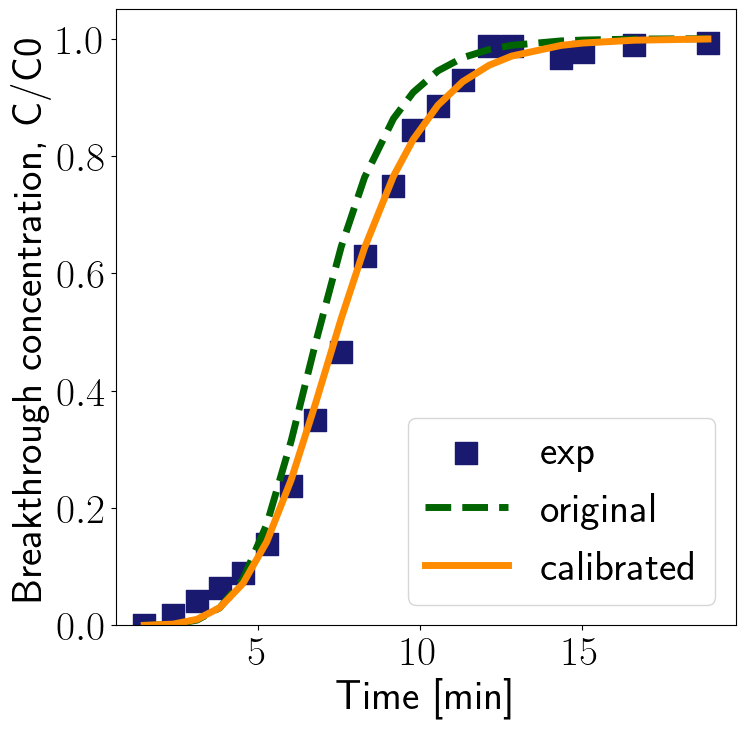

In [287]:
# Plot results
size = 8

fig2, ax2 = plt.subplots(figsize=(size,size))
plt.rcParams['text.usetex'] = True

# Plot experimental data
ax2.scatter(texp, Cexp, color='midnightblue', marker='s', s=30*size, label='exp')

# Plot original values
C_original = y_func(texp, *original_values)
ax2.plot(texp, C_original, linestyle='--', color='darkgreen', linewidth=5, label='original')

# Plot calibrated values
C_calibrated = y_func(texp, *popt)

ax2.plot(texp, C_calibrated, color='darkorange', linewidth=5, label='calibrated')

ax2.set_xlabel('Time [min]', fontsize=30)
ax2.set_ylabel('Breakthrough concentration, C/C0', fontsize=30)
ax2.tick_params(labelsize=30)
# ax2.set_xticks(np.linspace(0, 16, 9))
ax2.set_ylim(0)
# ax2.set_xlim(0, int(max(max(BV), max(texp))))
ax2.legend(fontsize=30)

### Least squares with weighted objective function

#### Test objective function

In [321]:
# Define calibration data
texp = texp1a
Cexp = Cexp1a
C0exp = 619/31

Q = 1.5e-8
V = 8e-6
e = 0.37

texp = texp/(Q/e)*(V*e)/60 # convert to minutes
# print(texp)

# Define parameter values and bounds

parameters=dict(qmax=0.291, Kl=1.18, rp=0.5*7.5e-4, e=0.37, Dp=5.3e-10)

names = [name for name in parameters.keys()]
original_values = [value for value in parameters.values()]

bounds = ([0.1, 1.18, 0.5*3e-4, 0.3, 1e-10],
          [0.3, 3.71, 0.5*12e-4, 0.44, 1e-9])


# Define objective function
def y_func(*values):
        
    global counter
    counter += 1
    
    # Update parameter value in dictionary
    parameters = dict([(name, value) for name, value in zip(names, values)])

    print(f'Run {counter}: {parameters}')
    
    # Run model with parameter value
    C, y, q, t, BV, z, RMSE = model(
                Nx    = 100,
                dt    = 0.1, 
                tmax  = 6, 
        
                C0 = C0exp,

                isotherm = 'Langmuir',
                profiles = False, 
                breakthrough = False,
                
                **parameters
    )
    
    # Interpolate model for experimental points
    C_int = np.interp(texp, t/60, C)
    
    # Generate weights
    
    # Calculate residuals
    
    y_res = Cexp - C_int
    
    return y_res

y_func(*original_values)

Run 2: {'qmax': 0.291, 'Kl': 1.18, 'rp': 0.000375, 'e': 0.37, 'Dp': 5.3e-10}


9f753d running: t: 6: : 60it [00:02, 22.56it/s]                          


RMSE = 0.0707


array([ 0.00079814,  0.01670029,  0.03308679,  0.03420278,  0.01089341,
       -0.03389777, -0.07638375, -0.12950183, -0.17881233, -0.13446394,
       -0.11444135, -0.06359121, -0.06002765, -0.03775812,  0.00540901,
       -0.00092064, -0.02940343, -0.02035925, -0.00973309, -0.00685866])

In [326]:
# Run parameter estimation
counter = 0

x0 = original_values

from scipy.optimize import least_squares
result = least_squares(y_func, x0=x0, bounds=bounds, args=x0)
param_calib = result.x

# Print results
print("Calibration terminated.\n",param_calib)

Run 1: {'qmax': array([2.91e-01, 1.18e+00, 3.75e-04, 3.70e-01, 5.30e-10]), 'Kl': 0.291, 'rp': 1.18, 'e': 0.000375, 'Dp': 0.37}


ValueError: cannot broadcast a non-scalar to a scalar array

### Uncertainty of calibrated parameters

In [288]:
parameters_original = parameters
parameters_calibrated = dict([(name, value) for name, value in zip(names, popt)])

# Monte Carlo sampling with calibrated parameters: +-20% uncertainty

from SALib.sample import saltelli
from SALib.analyze import sobol
from SALib import ProblemSpec

Np = 5             # no. of parameters

sp = ProblemSpec({
    'num_vars': Np,
    'names': ['e', 'r_p', 'q_{max}', 'K_L', 'Dp'],
    'bounds': [[0.8*parameters_calibrated['e'],    1.2*parameters_calibrated['e']],   
               [0.8*parameters_calibrated['rp'],   1.2*parameters_calibrated['rp']], 
               [0.8*parameters_calibrated['qmax'], 1.2*parameters_calibrated['qmax']],
               [0.8*parameters_calibrated['Kl'],   1.2*parameters_calibrated['Kl']],
               [0.8*parameters_calibrated['Dp'],   1.2*parameters_calibrated['Dp']]],
    'outputs': ['Y']
})


# Generate samples
N = 2**1

sp.sample_sobol(N, calc_second_order=True)

params = sp.samples
params.shape

# Store in disk
sampling = pd.DataFrame(params)
sampling.rename(columns={0:'e', 1:'rp', 2:'qmax', 3:'Kl', 4:'Dp'}, inplace=True)
sampling.to_csv(f"sampling_calibration_N-{N:d}.csv")

pars = pd.read_csv(f"sampling_calibration_N-{N:d}.csv")
print(pars)

# Run simulations

# Choose simulation parameters
Nx    = 100
dt    = 0.1
tmax  = 6      # 6.08

# Create simulation matrices to store data
Y = np.zeros([params.shape[0], int(np.ceil(tmax/dt) + 1)])
T = np.zeros((params.shape[0], int(np.ceil(tmax/dt) + 1)))

# Run model
for i, X in enumerate(params):
    e, rp, qmax, Kl, Dp = X
    
    print(f'Run {i+1:d} of {params.shape[0]}')
    print(f'e = {e:.2f}, rp = {rp:.2e}, qmax = {qmax:.3f}, Kl = {Kl:.2f}, Dp = {Dp:.2e}')
    
    C, y, q, t, BV, z, RMSE = model(e=e, rp=rp, qmax=qmax, Kl=Kl, Dp=Dp, 
                                    
                                    C0=C0exp, # Inlet concentration for validation experiment
                             
                                    tmax=tmax, 
                                    dt=dt,
                                    Nx=Nx,

                                    isotherm = 'Langmuir',
                                    profiles = False, 
                                    breakthrough = False)
    
    Y[i, :] = C  # breakthrough
    T[i, :] = t  # time
        
# Store data to disk
simulations = pd.DataFrame(Y)
simulations.to_csv(f"simulations_calibration_N-{N:d}_dt-{dt:.2f}_Np-{Np:d}_tmax-{tmax:d}.csv")

times = pd.DataFrame(T)
times.to_csv(f"times_calibration_N-{N:d}_dt-{dt:.2f}_tmax-{tmax:d}.csv")

    Unnamed: 0         e        rp      qmax        Kl            Dp
0            0  0.511283  0.000293  0.321920  3.311792  8.823253e-11
1            1  0.501186  0.000293  0.321920  3.311792  8.823253e-11
2            2  0.511283  0.000247  0.321920  3.311792  8.823253e-11
3            3  0.511283  0.000293  0.307159  3.311792  8.823253e-11
4            4  0.511283  0.000293  0.321920  3.415079  8.823253e-11
5            5  0.511283  0.000293  0.321920  3.311792  1.165304e-10
6            6  0.511283  0.000247  0.307159  3.415079  1.165304e-10
7            7  0.501186  0.000293  0.307159  3.415079  1.165304e-10
8            8  0.501186  0.000247  0.321920  3.415079  1.165304e-10
9            9  0.501186  0.000247  0.307159  3.311792  1.165304e-10
10          10  0.501186  0.000247  0.307159  3.415079  8.823253e-11
11          11  0.501186  0.000247  0.307159  3.415079  1.165304e-10
12          12  0.390168  0.000247  0.279333  3.669621  1.066219e-10
13          13  0.426969  0.000247

af651e running: t: 6: : 60it [00:02, 22.08it/s]                          


RMSE = 0.0500
Run 2 of 24
e = 0.50, rp = 2.93e-04, qmax = 0.322, Kl = 3.31, Dp = 8.82e-11


ef11af running: t: 6: : 60it [00:02, 22.44it/s]                          


RMSE = 0.0500
Run 3 of 24
e = 0.51, rp = 2.47e-04, qmax = 0.322, Kl = 3.31, Dp = 8.82e-11


e66b11 running: t: 6: : 60it [00:02, 22.45it/s]                          


RMSE = 0.0498
Run 4 of 24
e = 0.51, rp = 2.93e-04, qmax = 0.307, Kl = 3.31, Dp = 8.82e-11


abb33f running: t: 6: : 60it [00:02, 22.63it/s]                          


RMSE = 0.0371
Run 5 of 24
e = 0.51, rp = 2.93e-04, qmax = 0.322, Kl = 3.42, Dp = 8.82e-11


e97941 running: t: 6: : 60it [00:02, 22.83it/s]                          


RMSE = 0.0501
Run 6 of 24
e = 0.51, rp = 2.93e-04, qmax = 0.322, Kl = 3.31, Dp = 1.17e-10


214864 running: t: 6: : 60it [00:02, 22.35it/s]                          


RMSE = 0.0454
Run 7 of 24
e = 0.51, rp = 2.47e-04, qmax = 0.307, Kl = 3.42, Dp = 1.17e-10


b4b07d running: t: 6: : 60it [00:02, 22.14it/s]                          


RMSE = 0.0262
Run 8 of 24
e = 0.50, rp = 2.93e-04, qmax = 0.307, Kl = 3.42, Dp = 1.17e-10


e59391 running: t: 6: : 60it [00:02, 22.72it/s]                          


RMSE = 0.0264
Run 9 of 24
e = 0.50, rp = 2.47e-04, qmax = 0.322, Kl = 3.42, Dp = 1.17e-10


befc90 running: t: 6: : 60it [00:02, 22.38it/s]                          


RMSE = 0.0522
Run 10 of 24
e = 0.50, rp = 2.47e-04, qmax = 0.307, Kl = 3.31, Dp = 1.17e-10


8113fd running: t: 6: : 60it [00:02, 21.62it/s]                          


RMSE = 0.0258
Run 11 of 24
e = 0.50, rp = 2.47e-04, qmax = 0.307, Kl = 3.42, Dp = 8.82e-11


121851 running: t: 6: : 60it [00:02, 22.42it/s]                          


RMSE = 0.0249
Run 12 of 24
e = 0.50, rp = 2.47e-04, qmax = 0.307, Kl = 3.42, Dp = 1.17e-10


89641b running: t: 6: : 60it [00:02, 21.85it/s]                          


RMSE = 0.0259
Run 13 of 24
e = 0.39, rp = 2.47e-04, qmax = 0.279, Kl = 3.67, Dp = 1.07e-10


6ecdf8 running: t: 6: : 60it [00:02, 23.27it/s]                          


RMSE = 0.0685
Run 14 of 24
e = 0.43, rp = 2.47e-04, qmax = 0.279, Kl = 3.67, Dp = 1.07e-10


04134f running: t: 6: : 60it [00:02, 22.52it/s]                          


RMSE = 0.0619
Run 15 of 24
e = 0.39, rp = 2.65e-04, qmax = 0.279, Kl = 3.67, Dp = 1.07e-10


8232c9 running: t: 6: : 60it [00:02, 23.40it/s]                          


RMSE = 0.0704
Run 16 of 24
e = 0.39, rp = 2.47e-04, qmax = 0.281, Kl = 3.67, Dp = 1.07e-10


04af31 running: t: 6: : 60it [00:02, 22.54it/s]                          


RMSE = 0.0657
Run 17 of 24
e = 0.39, rp = 2.47e-04, qmax = 0.279, Kl = 2.93, Dp = 1.07e-10


351c84 running: t: 6: : 60it [00:02, 22.71it/s]                          


RMSE = 0.0696
Run 18 of 24
e = 0.39, rp = 2.47e-04, qmax = 0.279, Kl = 3.67, Dp = 9.72e-11


621ad9 running: t: 6: : 60it [00:02, 22.33it/s]                          


RMSE = 0.0684
Run 19 of 24
e = 0.39, rp = 2.65e-04, qmax = 0.281, Kl = 2.93, Dp = 9.72e-11


4b3751 running: t: 6: : 60it [00:02, 22.83it/s]                          


RMSE = 0.0695
Run 20 of 24
e = 0.43, rp = 2.47e-04, qmax = 0.281, Kl = 2.93, Dp = 9.72e-11


e08db3 running: t: 6: : 60it [00:02, 22.20it/s]                          


RMSE = 0.0603
Run 21 of 24
e = 0.43, rp = 2.65e-04, qmax = 0.279, Kl = 2.93, Dp = 9.72e-11


59e710 running: t: 6: : 60it [00:02, 23.01it/s]                          


RMSE = 0.0659
Run 22 of 24
e = 0.43, rp = 2.65e-04, qmax = 0.281, Kl = 3.67, Dp = 9.72e-11


1aba1d running: t: 6: : 60it [00:02, 23.09it/s]                          


RMSE = 0.0624
Run 23 of 24
e = 0.43, rp = 2.65e-04, qmax = 0.281, Kl = 2.93, Dp = 1.07e-10


055a95 running: t: 6: : 60it [00:02, 22.79it/s]                          


RMSE = 0.0625
Run 24 of 24
e = 0.43, rp = 2.65e-04, qmax = 0.281, Kl = 2.93, Dp = 9.72e-11


703c67 running: t: 6: : 60it [00:02, 22.35it/s]                          


RMSE = 0.0634


In [289]:
parameters_calibrated

{'qmax': 0.2999999954144017,
 'Kl': 3.356912855138682,
 'rp': 0.0002541637139403333,
 'e': 0.4399958908523425,
 'Dp': 1.0393903398416214e-10}

In [257]:
# Validation data

data = pd.read_csv("valdata.csv")

tval = data['BV'].dropna().to_numpy()
Cval = data['C/C0'].dropna().to_numpy()

In [513]:
# Plot uncertainty bands and experimental data

N = 2**3

# Define experimental data
Q = 1.5e-8
V = 8e-6
e = 0.37

texp1amin = texp1a/(Q/e)*(V*e)/60 # convert to minutes
texp2amin = texp2a/(Q/e)*(V*e)/60 # convert to minutes
texp3amin = texp3a/(Q/e)*(V*e)/60 # convert to minutes
texp1bmin = texp1b/(Q/e)*(V*e)/60 # convert to minutes
tvalmin = tval/(Q/e)*(V*e)/60

tmax = 6
pars = pd.read_csv(f"sampling_calibration_N-{N:d}.csv")
sims = pd.read_csv(f"simulations_calibration_N-{N:d}_dt-{dt:.2f}_Np-{Np:d}_tmax-{tmax:d}.csv")
time = pd.read_csv(f"times_calibration_N-{N:d}_dt-{dt:.2f}_tmax-{tmax:d}.csv")

C_int = np.zeros((pars.shape[0], tvalmin.shape[0]))

for i in range(sims.shape[0]):
    
    t = time.loc[i]["0":]
    C = sims.loc[i]["0":]
    
    C_int[i,:] = np.interp(tvalmin, t/60, C)

    # ax2.plot(texp, C_int[i,:], linewidth=1)
    


# Plot original values (uncalibrated model)
Cu, yu, qu, tu, BVu, zu, RMSEu = model(
                Nx    = 100,
                dt    = 0.1, 
                tmax  = 6, 
                
                C0 = C0exp,

                isotherm = 'Langmuir',
                profiles = False, 
                breakthrough = False,
                )

C_uncalibrated = np.interp(texp2amin, tu/60, C)


from sklearn.metrics import mean_squared_error

C, y, q, t, BV, z, RMSE = model(
                Nx    = 100,
                dt    = 0.1, 
                tmax  = 6, 
                
                C0 = C0exp,

                isotherm = 'Langmuir',
                profiles = False, 
                breakthrough = False,
                
                **parameters_calibrated
)

C_training = np.interp(texp2amin, t/60, C)

# Prediction validation dataset
texp = texp2amin
C0val = 619/31


C, y, q, t, BV, z, RMSE = model(
                Nx    = 100,
                dt    = 0.1, 
                tmax  = 6, 
                
                C0 = C0val,

                isotherm = 'Langmuir',
                profiles = False, 
                breakthrough = False,
                
                **parameters_calibrated
)

C_calibrated = np.interp(texp, t/60, C)

RMSE_uncalibrated = np.sqrt(mean_squared_error(Cexp2a, C_uncalibrated)) 
# RMSE_original2 = np.sqrt(mean_squared_error(Cexp1b, C_original2)) 

RMSE_calibrated = np.sqrt(mean_squared_error(Cexp2a, C_calibrated))
# RMSE_calibrated2 = np.sqrt(mean_squared_error(Cexp1b, C_calibrated2)) 

58b8f5 running: t: 6: : 60it [00:02, 22.01it/s]                          


RMSE = 0.0707


c82ba7 running: t: 6: : 60it [00:02, 21.88it/s]                          


RMSE = 0.0220


4d0d13 running: t: 6: : 60it [00:03, 19.70it/s]                          

RMSE = 0.0220


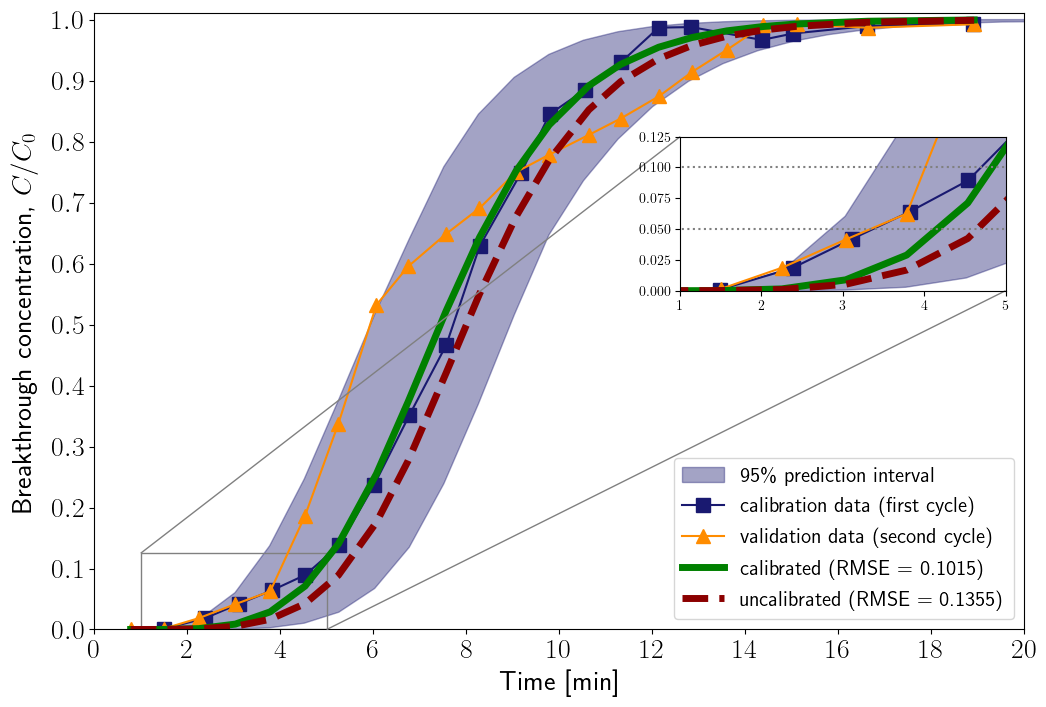

In [529]:
# Plot all simulations
size = 12
fig, ax1 = plt.subplots(figsize=(size, 8))

plt.rcParams['text.usetex'] = True


# Plot uncertainty bands
prediction_interval = 95

ax1.fill_between(tvalmin,
                 np.percentile(C_int, 50 - prediction_interval/2., axis=0),
                 np.percentile(C_int, 50 + prediction_interval/2., axis=0),
                 alpha=0.4, color='midnightblue',
                 label=f"{prediction_interval:d}\% prediction interval")


# Plot data
# ax2.scatter(tvalmin, Cval, s=100, color='red', marker='^', label=f'validation data, $C_0 = 713$ mg/L')
# ax1.scatter(texp1amin, Cexp1a, s=100, color='midnightblue', marker='s', label=f'calibration data (first cycle)')
# ax1.scatter(texp2amin, Cexp2a, s=100, color='darkorange', marker='^', label=f'validation data (second cycle)')
ax1.plot(texp1amin, Cexp1a, color='midnightblue', linestyle='-', marker='s', markersize=10, label=f'calibration data (first cycle)')
ax1.plot(texp2amin, Cexp2a, color='darkorange', linestyle='-', marker='^', markersize=10, label=f'validation data (second cycle)')

# Plot original values and calibrated
# ax2.plot(texp1amin, C_training, linestyle='--', color='midnightblue', linewidth=5, label=f'calibration (RMSE = {RMSE_training:.4f})')
ax1.plot(texp, C_calibrated, color='green', linewidth=5, label=f'calibrated (RMSE = {RMSE_calibrated:.4f})')
ax1.plot(texp2amin, C_uncalibrated, color='darkred', linewidth=5, linestyle='--', label=f'uncalibrated (RMSE = {RMSE_uncalibrated:.4f})')

# ax1.plot([0, 20],[0.05,0.05], color='gray', linestyle=':')


ax1.set_ylabel('Breakthrough concentration, $C/C_0$', fontsize=20, labelpad=10)
ax1.set_yticks(np.linspace(0, 1, 11))
ax1.tick_params(labelsize=20)
ax1.set_ylim(0, 1.01)
ax1.legend(loc='lower right', fontsize=15)

# Time in minutes
ax1.set_xlim(0, 20)
ax1.set_xticks(np.linspace(0, 20, 11))
ax1.set_xlabel('Time [min]', fontsize=20)


# Inset graph
from mpl_toolkits.axes_grid.inset_locator import (inset_axes, InsetPosition, mark_inset)
# Create a set of inset Axes: these should fill the bounding box allocated to them.
ax2 = plt.axes([0, 0, 1, 1])
# Manually set the position and relative size of the inset axes within ax1
ip = InsetPosition(ax1, [0.63,0.55,0.35,0.25])
ax2.set_axes_locator(ip)
# Mark the region corresponding to the inset axes on ax1 and draw lines in grey linking the two axes.
mark_inset(ax1, ax2, loc1=2, loc2=4, fc="none", ec='0.5')
# The data: only display for low temperature in the inset figure.
tmaxmin = 7

ax2.fill_between(tvalmin,
                 np.percentile(C_int, 50 - prediction_interval/2., axis=0),
                 np.percentile(C_int, 50 + prediction_interval/2., axis=0),
                 alpha=0.4, color='midnightblue',
                 label=f"{prediction_interval:d}\% prediction interval")

# ax2.scatter(texp1amin[texp1amin <= tmaxmin], Cexp1a[texp1amin <= tmaxmin], s=100, color='midnightblue', marker='s', label=f'calibration data (first cycle)')
# ax2.scatter(texp2amin[texp2amin <= tmaxmin], Cexp2a[texp2amin <= tmaxmin], s=100, color='darkorange', marker='^', label=f'validation data (second cycle)')

ax2.plot(texp1amin[texp1amin <= tmaxmin], Cexp1a[texp1amin <= tmaxmin], color='midnightblue', linestyle='-', marker='s', markersize=10, label=f'calibration data (first cycle)')
ax2.plot(texp2amin[texp2amin <= tmaxmin], Cexp2a[texp2amin <= tmaxmin], color='darkorange', linestyle='-', marker='^', markersize=10, label=f'validation data (second cycle)')

ax2.plot(texp2amin[texp2amin <= tmaxmin], C_calibrated[texp2amin <= tmaxmin], color='green', linewidth=5, label=f'validation (RMSE = {RMSE_calibrated:.4f})')
ax2.plot(texp2amin[texp2amin <= tmaxmin], C_uncalibrated[texp2amin <= tmaxmin], color='darkred', linestyle='--', linewidth=5, label=f'uncalibrated (RMSE = {RMSE_uncalibrated:.4f})')

ax2.plot([0, 20],[0.05,0.05], color='gray', linestyle=':')
ax2.plot([0, 20],[0.1,0.1], color='gray', linestyle=':')


ax2.set_xlim(1, 5)
ax2.set_ylim(0, 0.125)
ax2.set_yticks([0, 0.025, 0.05, 0.075, 0.1, 0.125])

plt.rcParams['text.usetex'] = True


Second cycle is in the confidence region, but simulated value is equal to training, so overfitted. Also, capacity is reduced due to incomplete regeneration, so breakthrough happens earlier.

In order to simulate experiment 1b, C0 = 13 but this delays breakthrough, and parameters are not calibrated to the right effluent (hydrolized urine), but to the first one. So prediction is not correct.

If there is no change in the model, or the regeneration is not taken into account, the training and validation will produce the same results, so experiments from validation 2a cannot be used.

**Is my calibration improving the prediction for the regenerated column? Try with a non-calibrated model and a new validation dataset.**

### Estimate uncertainty for second experiment

### Estimate

In [ ]:
# Define parameter estimation

from scipy.optimize import curve_fit

# Initial parameters

Kf_values = [1.924, 1.924, 1.924, 1.754, 1.754, 1.754]
nf_values = [0.255, 0.255, 0.255, 0.191, 0.191, 0.191]

bounds_Kf = [0.01, 0.01]
bounds_nf = [5, 0.6]

bounds = (bounds_Kf, bounds_nf)

# Run calibration

for i in range(3,6):
    
    counter = 0
    
    Kf = Kf_values[i]
    nf = nf_values[i]
    
    texp = texp_data[i]
    Cexp = Cexp_data[i]
    
    def y_func(t, Kf, nf):
        
        global counter
        counter += 1
        
        print(f'Run {counter}: Kf = {Kf:f}, nf = {nf:f}')
        
        C1, y1, t1, z1 = model(Kf, nf, plot_profiles=False, plot_breakthrough=False)
        
        return np.interp(texp, t1, C1)
    
    # Original values
    C0, y0, t0, z0 = model(Kf, nf, plot_profiles=False, plot_breakthrough=False)
    original1.append([C0, y0, t0, z0])

    # Estimation
    p0 = [Kf, nf]
    bounds = bounds
    
    popt, _ = curve_fit(y_func, xdata=texp, ydata=Cexp, p0=p0, bounds=bounds)
    param_calib = popt
    print(param_calib)
    
    # Simulate optimal parameters
    calibrated1.append([model(*popt, plot_profiles=False, plot_breakthrough=False)])
    calibrated1.append(popt)
    
# store data    

simulations1 = pd.DataFrame(calibrated[0][0][1],calibrated[0][0][2])
simulations1.to_csv("calibration_exp1.csv")

# ?? check optimisation with data from exp1a

simulations2 = pd.DataFrame(calibrated1[0][0][1],calibrated1[0][0][2])
simulations2.to_csv("calibration_exp2.csv")


### Plot results

In [ ]:
# %% Load calibration data

exp1 = pd.read_csv("calibration_exp1.csv")
exp2 = pd.read_csv("calibration_exp2.csv")

calibrated = np.zeros((2,2,3,224))
calibrated[1][0][2] = exp1["Unnamed: 0"]
calibrated[1][0][0] = exp1["1"]

calibrated1 = np.zeros((2,2,3,224))
calibrated1[0][0][2] = exp2["Unnamed: 0"]
calibrated1[0][0][0] = exp2["1"]
    
# %% Plot calibration of first two experiments

fig, ax = plt.subplots(1, 2, figsize=(12,6))

markers = ['s', '^', 'o', '^', '^', 'o']

colors = ['midnightblue', 'green', 'orange', 'green', 'green', 'orange']

labels = ['Exp. (a)', 'Exp. 2a', 'Exp 3a', 'Exp. (b)', 'Exp. 2b', 'Exp 3b']

for i in range(1):
    
    # Plot experimental data
    ax[i].plot(texp_data[i], Cexp_data[i], color=colors[i], marker=markers[i], label=labels[i], linestyle='-', linewidth=2, markersize=10)

    # Plot model
    t = calibrated[i][0][2]
    C = calibrated[i][0][0]

    ax[i].plot(t, C, color=colors[i], linestyle='-', lw=3, label='IX model')
    ax[i].set_xlabel('Time (bed volumes)',fontsize=15)
    ax[i].set_ylabel(r'Breakthrough concentration, $C/C_0$',fontsize=15)
    ax[i].tick_params(labelsize=12)
    ax[i].set_xticks(np.arange(0,17,2))
    ax[i].set_xlim(0, 16)
    ax[i].set_ylim(0, 1)
    ax[i].legend(fontsize=15, loc='lower right')
    
    i = 3

    # Plot experimental data
    ax[1].plot(texp_data[i], Cexp_data[i], color=colors[i], marker=markers[i], label=labels[i], linestyle='-', linewidth=2, markersize=10)

    i = 1
    
    # Plot model
    t = calibrated1[i-1][0][2]
    C = calibrated1[i-1][0][0]

    ax[i].plot(t, C, color=colors[i], linestyle='-', lw=3, label='IX model')
    ax[i].set_xlabel('Time (bed volumes)',fontsize=15)
    ax[i].tick_params(labelsize=12)
    ax[i].set_xticks(np.arange(0,17,2))
    ax[i].set_xlim(0, 16)
    ax[i].set_ylim(0, 1)
    ax[i].legend(fontsize=15, loc='lower right')



# %% Plot profiles with calibration

fig, ax = plt.subplots(figsize=(15,8))

markers = ['s', '^', 'o', 's', '^', 'o']

colors = ['midnightblue', 'green', 'orange']

labels = ['Exp. 1a', 'Exp. 2a', 'Exp 3a']

for i in range(3):
    
    # Plot experimental data
    ax.plot(texp_data[i], Cexp_data[i], color=colors[i], marker=markers[i], label=labels[i], linestyle='-', linewidth=2, markersize=10)

    # Plot model
    t = calibrated[i][0][2]
    C = calibrated[i][0][0]

    ax.plot(t, C, color=colors[i], linestyle='-', lw=5, label='fitted')
    ax.set_xlabel('Time (bed volumes)',fontsize=30)
    ax.tick_params(labelsize=20)
    ax.set_xticks(np.arange(0,17,2))
    ax.set_xlim(0, 16)
    ax.set_ylim(0, 1)



# %%



    
        # Plot experimental data
        ax[j].scatter(texp_data[3*i+j], Cexp_data[3*i+j], s=200, color='midnightblue', marker=markers[3*i+j], label='exp')
    
        # Plot model
        t = calibrated1[2*j][0][2]
        C = calibrated1[2*j][0][0]
        
        ax[j].plot(t, C, color='orange', linestyle='-', lw=5, label='fitted')
        ax[j].set_xlabel('Time (bed volumes)',fontsize=30)
        ax[j].tick_params(labelsize=20)
        ax[j].set_xticks(np.arange(0,17,2))
        ax[j].set_xlim(0, 16)
        ax[j].set_ylim(0, 1)
        
        
# %% Just one experiment

fig, ax = plt.subplots(2, 3, figsize=(20,20))

markers = ['s', '^', 'o', 's', '^', 'o']
colors = ['midnightblue', 'green', 'orange']

for i in range(2):
    
    for j in range(3):
    
        # Plot experimental data
        ax[i,j].scatter(texp_data[3*i+j], Cexp_data[3*i+j], s=200, color=colors[j], marker=markers[3*i+j], label='exp')
    
        # Plot model
        t = calibrated[3*i+j][0][2]
        C = calibrated[3*i+j][0][0]
        
        ax[i,j].plot(t,C, color='orange', linestyle='-', lw=5, label='fitted')
        ax[i,j].set_xlabel('Time (bed volumes)',fontsize=30)
        ax[i,j].tick_params(labelsize=20)
        ax[i,j].set_xticks(np.arange(0,17,2))
        ax[i,j].set_xlim(0, 16)
        ax[i,j].set_ylim(0, 1)
        

    

# %%

fig1, ax1 = plt.subplots(figsize=(20,20))

for i in range(0,len(y), 1):
    ax1.plot(z, y[i,:])

ax1.set_xlabel('Column length',fontsize=30)
ax1.set_ylabel('C/C0 [–]',fontsize=30)
ax1.tick_params(labelsize=30)
ax1.set_xlim(0, 1)
ax1.set_ylim(0)
# ax.set_xlim(0,max(BV))
# ax.legend(fontsize=40)

ax1.plot(t/max(t), C, 'k-.', lw=5)


# Plot breakthrough
fig2, ax2 = plt.subplots(figsize=(20,20))

ax2.plot(t1, C1, color='black', linestyle='--', lw=5, label='original')
ax2.plot(t, C, color='orange', linestyle='-', lw=5, label='fitted')

ax2.scatter(texp1a, Cexp1a, s=600, color='midnightblue', marker='s', label='exp')

ax2.set_xlabel('Bed volumes',fontsize=30)
ax2.set_ylabel('C/C0 [–]',fontsize=30)
ax2.tick_params(labelsize=30)
ax2.set_ylim(0)
ax2.set_xlim(0, int(max(texp1a)) + 1)
ax2.legend(fontsize=40)
